# PerfectJet 0.14 — Stopped-flow readouts

This notebook contains the complete runnable Python source, the new study's runners and retained aggregate evidence. It does not contain restricted raw tracking or individual prospect predictions. The official experiments were executed separately; these cells replay exact mathematics and display those hash-bound aggregate results, not a new independent football experiment.

The result is more source coverage and useful repeated-measurement denoising, **not an established scouting edge**. Read the full study in `docs/nfl/STOPPED_FLOW.md`.

In [1]:
import hashlib, json, pathlib, sys, tempfile
SOURCES = {'src/perfectjet/__init__.py': '"""PerfectJet: exact computational kernels and a status-aware research atlas."""\n__version__ = "0.14.0"\n', 'src/perfectjet/applications/__init__.py': '"""Application adapters. Each states its data meaning and the mathematical contract it relies on."""\n', 'src/perfectjet/applications/nfl_scouting/__init__.py': '"""Combine movement readouts and their pre-draft scouting value.\n\nQuestion: does a repeatable, demand-adjusted recovery readout measured at the\nCombine predict NFL get-off beyond position, body measurements, timed tests and\nother information available before the draft?\n\nThe package separates measurement (events, eta, sensitivity), identifiability\n(which readouts a player\'s attempts determine), outcome construction\n(cross-fitted context residuals), validation (player-grouped temporal splits with\nfull-pipeline refits), and decisions (frozen shortlist rules). A synthetic\ngenerator with a planted or null signal tests the pipeline itself; it is never\nevidence about football.\n"""\nEXTRACTION_VERSION = "nfl-events/1"\n', 'src/perfectjet/applications/nfl_scouting/__main__.py': 'from .pipeline import main\n\nmain()\n', 'src/perfectjet/applications/nfl_scouting/allocation.py': '"""Target-directed measurement packages and conditional scouting decisions.\n\nThis bridge uses PerfectJet\'s exact Gaussian readout and finite-population cores.\nFor source covariance S, frozen scouting loading H and an independent noisy\nmeasurement e, the covariance update is\n\n    S\' = S - (S e)(S e)^T / (noise_variance + e^T S e).\n\nIts scouting value is trace(W H(S-S\')H^T), not trace(S-S\') and not the sum of\nisolated measurement values. Repeated observations improve precision, while\nonly new row-space directions can resolve structural non-identifiability.\n\nAll conclusions are conditional on the supplied linear Gaussian model, fixed\ntraining-derived loadings and independent measurement errors. Measurement\nallocation does not establish NFL prediction improvement. Scenario bounds below\nare supplied fixed-fit measurement bounds; empirical uncertainty is separate.\n"""\nfrom dataclasses import dataclass\nfrom collections.abc import Iterable\nfrom fractions import Fraction as Q\nfrom numbers import Integral\nfrom itertools import combinations\n\nfrom ...decisions import certified_choice\nfrom ...exact import matmul, rank, transpose\nfrom ...populations import SelectionPopulation\nfrom ...readout import adds_direction, dot, identify, inverse, posterior_covariance, repair\n\nMAX_EXACT_CANDIDATES = 18\n\n\ndef _q(value):\n    """Preserve declared decimal inputs, rather than expose their binary expansion."""\n    return Q(str(value)) if isinstance(value, float) else Q(value)\n\n\ndef _integer(value, name, positive=False):\n    if isinstance(value, bool) or not isinstance(value, Integral) or value < int(positive):\n        raise ValueError(f"{name} must be a {\'positive\' if positive else \'nonnegative\'} integer")\n    return int(value)\n\n\ndef _rows(values, width, name):\n    out = tuple(tuple(_q(v) for v in row) for row in values)\n    if any(len(row) != width for row in out):\n        raise ValueError(f"{name} rows must have source width {width}")\n    return out\n\n\ndef _covariance(values, name="prior_covariance"):\n    out = tuple(tuple(_q(v) for v in row) for row in values)\n    n = len(out)\n    if not n or any(len(row) != n for row in out):\n        raise ValueError(f"{name} must be a nonempty square matrix")\n    if any(out[i][j] != out[j][i] for i in range(n) for j in range(n)):\n        raise ValueError(f"{name} must be symmetric")\n    # Exact LDL^T: positive pivots establish positive definiteness. The reused\n    # posterior_covariance core requires an invertible Gaussian prior.\n    lower = [[Q(0)] * n for _ in range(n)]\n    diag = []\n    for i in range(n):\n        pivot = out[i][i] - sum((lower[i][k] ** 2 * diag[k] for k in range(i)), Q(0))\n        if pivot <= 0:\n            raise ValueError(f"{name} must be positive definite")\n        diag.append(pivot)\n        lower[i][i] = Q(1)\n        for j in range(i + 1, n):\n            lower[j][i] = (out[j][i] - sum((lower[j][k] * lower[i][k] * diag[k]\n                                           for k in range(i)), Q(0))) / pivot\n    return out\n\n\ndef _target_rows(values, width):\n    rows = tuple(values)\n    if not rows:\n        raise ValueError("at least one target loading is required")\n    if not isinstance(rows[0], Iterable) or isinstance(rows[0], (str, bytes)):\n        rows = (rows,)\n    return _rows(rows, width, "target_loadings")\n\n\ndef _trace(cov):\n    return sum((cov[i][i] for i in range(len(cov))), Q(0))\n\n\ndef _target_covariance(cov, loadings):\n    return tuple(tuple(row) for row in matmul(matmul(loadings, cov), transpose(loadings)))\n\n\ndef _weighted_variance(cov, weights):\n    return sum((weight * cov[i][i] for i, weight in enumerate(weights)), Q(0))\n\n\n@dataclass(frozen=True)\nclass MeasurementCandidate:\n    """One optional package of independent repetitions; ``cost`` is total cost.\n\n    ``row`` acts on the model\'s global source vector. For several athletes this\n    vector may concatenate their states; correlated priors are permitted.\n    Athlete IDs describe provenance; global rows need not have one athlete ID.\n    Repetitions are independent attempts, never extra frames from one attempt.\n    """\n    candidate_id: str\n    row: tuple\n    noise_variance: Q\n    cost: int\n    athlete_id: object = None\n    repetitions: int = 1\n    attempt_ids: tuple = ()\n\n    def __post_init__(self):\n        if not isinstance(self.candidate_id, str) or not self.candidate_id:\n            raise ValueError("candidate_id must be a nonempty string")\n        object.__setattr__(self, "row", tuple(_q(v) for v in self.row))\n        noise = _q(self.noise_variance)\n        if noise <= 0:\n            raise ValueError("measurement noise_variance must be positive")\n        object.__setattr__(self, "noise_variance", noise)\n        object.__setattr__(self, "cost", _integer(self.cost, "candidate cost"))\n        object.__setattr__(self, "repetitions", _integer(self.repetitions, "repetitions", positive=True))\n        ids = tuple(self.attempt_ids)\n        if ids and (len(ids) != self.repetitions or len(set(ids)) != len(ids)):\n            raise ValueError("attempt_ids must be distinct original attempts, one per repetition")\n        object.__setattr__(self, "attempt_ids", ids)\n\n\n    @property\n    def rows(self):\n        return (self.row,)\n\n\n@dataclass(frozen=True)\nclass MeasurementBlockCandidate:\n    """A jointly observed channel block, with correlated noise within each attempt.\n\n    One block is one selection candidate and has one total package cost. Distinct\n    channels from the same original attempt use R\'s covariance, not independent\n    scalar repetitions. Different repeated blocks still assume independent\n    attempts; their supplied original attempt IDs must be distinct.\n    """\n    candidate_id: str\n    rows: tuple\n    noise_covariance: tuple\n    cost: int\n    athlete_id: object = None\n    repetitions: int = 1\n    attempt_ids: tuple = ()\n\n    def __post_init__(self):\n        if not isinstance(self.candidate_id, str) or not self.candidate_id:\n            raise ValueError("candidate_id must be a nonempty string")\n        rows = tuple(tuple(_q(v) for v in row) for row in self.rows)\n        if not rows or not rows[0] or any(len(row) != len(rows[0]) for row in rows):\n            raise ValueError("measurement block rows must be a nonempty rectangular matrix")\n        noise = _covariance(self.noise_covariance, "noise_covariance")\n        if len(noise) != len(rows):\n            raise ValueError("noise covariance dimension must match the jointly measured channels")\n        object.__setattr__(self, "rows", rows)\n        object.__setattr__(self, "noise_covariance", noise)\n        object.__setattr__(self, "cost", _integer(self.cost, "candidate cost"))\n        object.__setattr__(self, "repetitions", _integer(self.repetitions, "repetitions", positive=True))\n        ids = tuple(self.attempt_ids)\n        if ids and (len(ids) != self.repetitions or len(set(ids)) != len(ids)):\n            raise ValueError("attempt_ids must be distinct original attempts, one per repeated block")\n        object.__setattr__(self, "attempt_ids", ids)\n\n\nclass TargetInformationModel:\n    """Exact conditional information for frozen, training-derived target loadings.\n\n    Inputs are copied to immutable tuples. ``noise_variance`` for the existing\n    design is either one common variance or one variance per row. The training\n    receipt is provenance supplied by the caller; this class neither learns H\n    from evaluated athletes nor verifies the caller\'s training chronology.\n    """\n    def __init__(self, prior_covariance, target_loadings, design=(), noise_variance=1,\n                 target_weights=None, training_receipt=None, target_ids=None, observation_ids=None):\n        self.prior_covariance = _covariance(prior_covariance)\n        self.width = len(self.prior_covariance)\n        self.target_loadings = _target_rows(target_loadings, self.width)\n        self.design = _rows(design, self.width, "design")\n        self.observation_ids = tuple(observation_ids) if observation_ids is not None else ()\n        if self.observation_ids and (len(self.observation_ids) != len(self.design)\n                                     or len(set(self.observation_ids)) != len(self.observation_ids)):\n            raise ValueError("observation_ids must be distinct original attempts, one per design row")\n        if isinstance(noise_variance, Iterable) and not isinstance(noise_variance, (str, bytes)):\n            noises = tuple(_q(v) for v in noise_variance)\n            if len(noises) != len(self.design):\n                raise ValueError("one observation variance per existing design row is required")\n        else:\n            noises = (_q(noise_variance),) * len(self.design)\n            if _q(noise_variance) <= 0:\n                raise ValueError("observation noise_variance must be positive")\n        if any(noise <= 0 for noise in noises):\n            raise ValueError("observation variances must be positive")\n        self.observation_noise_variances = noises\n        self.target_weights = (tuple(_q(v) for v in target_weights)\n                               if target_weights is not None else (Q(1),) * len(self.target_loadings))\n        if len(self.target_weights) != len(self.target_loadings) or any(v < 0 for v in self.target_weights):\n            raise ValueError("one nonnegative weight per target is required")\n        self.target_ids = tuple(target_ids) if target_ids is not None else None\n        if self.target_ids is not None:\n            if len(self.target_ids) != len(self.target_loadings) or len(set(self.target_ids)) != len(self.target_ids):\n                raise ValueError("target_ids must be unique and match the target rows")\n        self.training_receipt = str(training_receipt) if training_receipt is not None else None\n        if len(set(noises)) <= 1:\n            # Reuse the readout core directly for its homogeneous-noise domain.\n            cov = tuple(tuple(row) for row in posterior_covariance(\n                self.design, noises[0] if noises else Q(1), self.prior_covariance))\n        else:\n            cov = self.prior_covariance\n            for row, noise in zip(self.design, noises):\n                cov = self._update(cov, row, noise)\n        self.source_covariance = cov\n        self.target_covariance = _target_covariance(cov, self.target_loadings)\n        self.target_variance = _weighted_variance(self.target_covariance, self.target_weights)\n\n    @staticmethod\n    def _update(cov, row, noise):\n        # Rational Sherman--Morrison: heterogeneous noise requires no irrational\n        # whitening and full source correlations are preserved.\n        projected = tuple(dot(source_row, row) for source_row in cov)\n        denominator = noise + dot(row, projected)\n        return tuple(tuple(value - projected[i] * projected[j] / denominator\n                           for j, value in enumerate(source_row))\n                     for i, source_row in enumerate(cov))\n\n    def _candidates(self, candidates):\n        candidates = tuple(candidates)\n        if any(not isinstance(candidate, (MeasurementCandidate, MeasurementBlockCandidate))\n               for candidate in candidates):\n            raise TypeError("scalar or block measurement candidate instances are required")\n        if len({candidate.candidate_id for candidate in candidates}) != len(candidates):\n            raise ValueError("candidate_id values must be unique")\n        if any(len(row) != self.width for candidate in candidates for row in candidate.rows):\n            raise ValueError("candidate row width differs from the source width")\n        ids = [attempt for candidate in candidates for attempt in candidate.attempt_ids]\n        if len(set(ids)) != len(ids) or set(ids).intersection(self.observation_ids):\n            raise ValueError("an original attempt cannot supply two independent observations")\n        return candidates\n\n    @staticmethod\n    def _update_block(cov, rows, noise_covariance):\n        # S\' = S - S E^T (R + E S E^T)^(-1) E S. Correlated channels\n        # remain one observation block; rational arithmetic needs no whitening.\n        left = matmul(cov, transpose(rows))\n        projected = matmul(rows, left)\n        innovation = [[noise + value for noise, value in zip(r_noise, r_value)]\n                      for r_noise, r_value in zip(noise_covariance, projected)]\n        reduction = matmul(matmul(left, inverse(innovation)), transpose(left))\n        return tuple(tuple(value - delta for value, delta in zip(source_row, delta_row))\n                     for source_row, delta_row in zip(cov, reduction))\n\n    def _apply(self, cov, candidate):\n        for _ in range(candidate.repetitions):\n            if isinstance(candidate, MeasurementBlockCandidate):\n                cov = self._update_block(cov, candidate.rows, candidate.noise_covariance)\n            else:\n                cov = self._update(cov, candidate.row, candidate.noise_variance)\n        return cov\n\n    def _package_repair(self, h, candidates):\n        if identify(self.design, h)["identified"]:\n            return {"needed": 0, "candidate_indices": (), "smaller_sets_rejected": 0}\n        rejected = 0\n        for size in range(1, min(self.width, len(candidates)) + 1):\n            for idx in combinations(range(len(candidates)), size):\n                design = list(self.design) + [row for i in idx for row in candidates[i].rows]\n                if identify(design, h)["identified"]:\n                    return {"needed": size, "candidate_indices": idx,\n                            "smaller_sets_rejected": rejected}\n                rejected += 1\n        return {"needed": None, "candidate_indices": None, "smaller_sets_rejected": rejected}\n\n    def _objective(self, cov, objective):\n        after = _target_covariance(cov, self.target_loadings)\n        reductions = tuple(self.target_covariance[i][i] - after[i][i]\n                           for i in range(len(after)))\n        if objective == "worst_target":\n            return min(reductions)\n        weight = sum(self.target_weights, Q(0))\n        return (sum((w * value for w, value in zip(self.target_weights, reductions)), Q(0)) / weight\n                if weight else Q(0))\n\n    def package_information(self, candidates):\n        """Joint information, structural identification and repeat/new-direction receipts."""\n        candidates = self._candidates(candidates)\n        cov = self.source_covariance\n        design = list(self.design)\n        details = []\n        for candidate in candidates:\n            new = (adds_direction(design, candidate.row)\n                   if isinstance(candidate, MeasurementCandidate)\n                   else rank(design + list(candidate.rows), self.width) > rank(design, self.width))\n            details.append({"candidate_id": candidate.candidate_id,\n                            "athlete_id": candidate.athlete_id,\n                            "repetitions": candidate.repetitions,\n                            "attempt_ids": candidate.attempt_ids,\n                            "independence_provenance": "distinct supplied original attempt IDs"\n                                if candidate.attempt_ids else "planned independent-observation assumption",\n                            "channels": len(candidate.rows),\n                            "repeat_of_observed_row": all(row in self.design for row in candidate.rows),\n                            "new_design_direction": new,\n                            "classification": "new_direction" if new else "precision_only"})\n            cov = self._apply(cov, candidate)\n            for _ in range(candidate.repetitions):\n                design.extend(candidate.rows)\n        after = _target_covariance(cov, self.target_loadings)\n        after_variance = _weighted_variance(after, self.target_weights)\n        candidate_rows = [row for candidate in candidates for row in candidate.rows]\n        readouts = [{"target": i,\n                     "before": identify(self.design, h),\n                     "after": identify(design, h),\n                     "repair_from_this_package": self._package_repair(h, candidates),\n                     "row_repair": repair(self.design, h, candidate_rows,\n                                          max_new=min(self.width, len(candidate_rows)))}\n                    for i, h in enumerate(self.target_loadings)]\n        return {"candidate_ids": tuple(candidate.candidate_id for candidate in candidates),\n                "cost": sum(candidate.cost for candidate in candidates),\n                "source_covariance_before": self.source_covariance,\n                "source_covariance_after": cov,\n                "source_variance_before": _trace(self.source_covariance),\n                "source_variance_after": _trace(cov),\n                "source_variance_reduction": _trace(self.source_covariance) - _trace(cov),\n                "target_covariance_before": self.target_covariance,\n                "target_covariance_after": after,\n                "target_variance_before": self.target_variance,\n                "target_variance_after": after_variance,\n                "target_variance_reduction": self.target_variance - after_variance,\n                "target_variance_scope": "H source_covariance H^T; excludes irreducible NFL noise "\n                                         "and uncertainty in the frozen transfer loading",\n                "marginal_target_reductions": tuple(self.target_covariance[i][i] - after[i][i]\n                                                    for i in range(len(after))),\n                "design_rank_before": rank(self.design, self.width),\n                "design_rank_after": rank(design, self.width),\n                "readouts": readouts, "measurements": details,\n                "training_receipt": self.training_receipt,\n                "assumptions": ("fixed training-derived target loadings",\n                                "supplied linear Gaussian source and transfer model",\n                                "independent measurement errors, including repetitions",\n                                "conditional information; no asserted NFL prediction lift")}\n\n    def optimize_package(self, candidates, budget, max_candidates=MAX_EXACT_CANDIDATES,\n                         objective="weighted_mean"):\n\n        """Globally maximize joint target variance reduction over a small exact population.\n\n        The objective is nonlinear in selected measurements. SelectionPopulation\n        supplies feasible counting, conditional counts and original-order ranks;\n        its additive-profit optimizer is deliberately not used. Every feasible\n        subset is evaluated. There is no claim of 100-candidate scalability.\n        weighted_mean normalizes the supplied nonnegative output weights;\n        worst_target maximizes the minimum reduction across every supplied H\n        row. Worst-case rows must represent commensurate declared training\n        loading scenarios; they are not automatically a confidence region.\n        """\n        candidates = self._candidates(candidates)\n        if objective not in ("weighted_mean", "worst_target"):\n            raise ValueError("objective must be weighted_mean or worst_target")\n        budget = _integer(budget, "budget")\n        limit = _integer(max_candidates, "max_candidates")\n        if limit > MAX_EXACT_CANDIDATES or len(candidates) > limit:\n            raise ValueError(f"exact allocation supports at most {MAX_EXACT_CANDIDATES} candidates "\n                             "and must respect max_candidates")\n        population = SelectionPopulation([(candidate.cost,) for candidate in candidates], (budget,))\n        total = population.count()\n        best = None\n        tie_ranks = []\n        best_bits = None\n        best_cost = None\n        ordinal = 0\n\n        def visit(prefix, cov, spent):\n            nonlocal best, best_bits, best_cost, ordinal\n            if population.conditional_count(prefix) == 0:\n                return\n            if len(prefix) == len(candidates):\n                gain = self._objective(cov, objective)\n                if best is None or gain > best:\n                    best, best_bits, best_cost = gain, prefix, spent\n                    tie_ranks[:] = [ordinal]\n                elif gain == best:\n                    tie_ranks.append(ordinal)\n                    # Minimum cost breaks representation ties; all objective\n                    # ties, including supersets with no useful information, count.\n                    if spent < best_cost:\n                        best_bits, best_cost = prefix, spent\n                ordinal += 1\n                return\n            candidate = candidates[len(prefix)]\n            visit(prefix + (0,), cov, spent)\n            if spent + candidate.cost <= budget:\n                visit(prefix + (1,), self._apply(cov, candidate), spent + candidate.cost)\n\n        visit((), self.source_covariance, 0)\n        if ordinal != total:\n            raise AssertionError("finite-population traversal did not cover the feasible population")\n        chosen = tuple(candidate for candidate, bit in zip(candidates, best_bits) if bit)\n        selected_rank = population.rank(best_bits)\n        if population.unrank(selected_rank) != best_bits:\n            raise AssertionError("selection rank replay failed")\n        return {"candidate_ids": tuple(candidate.candidate_id for candidate in chosen),\n                "bits": best_bits, "cost": best_cost, "budget": budget,\n                "objective_reduction": best, "objective": objective,\n                "objective_scope": "conditional reduction across supplied frozen training loading rows; "\n                                   "worst_target rows are declared scenarios, not a confidence region",\n                "tie_count": len(tie_ranks),\n                "tie_ranks": tuple(tie_ranks), "population_rank": selected_rank,\n                "feasible_count": total, "evaluated_packages": ordinal,\n                "optimality": "exhaustive over the declared finite candidate population",\n                "package": self.package_information(chosen)}\n\n\ndef _bounds(values, name):\n    out = {}\n    for key, endpoints in values.items():\n        if len(endpoints) != 2:\n            raise ValueError(f"{name} needs (lower, upper) pairs")\n        lo, hi = map(_q, endpoints)\n        if lo > hi:\n            raise ValueError(f"{name} lower bound exceeds upper bound")\n        out[key] = (lo, hi)\n    return out\n\n\ndef scouting_decision(scenario_bounds, empirical_uncertainty=None, maximize=True):\n    """Replay ranking implications of supplied fixed-fit scenario bounds exactly.\n\n    Bounds must cover the caller\'s declared measurement scenarios. No confidence\n    level or probability follows from these bounds. Empirical intervals are\n    stored separately and never silently merged with deterministic bounds.\n    """\n    bounds = _bounds(scenario_bounds, "scenario_bounds")\n    if not bounds:\n        raise ValueError("at least one player\'s scenario bounds are required")\n    estimate_error = {key: ((lo + hi) / 2, (hi - lo) / 2)\n                      for key, (lo, hi) in bounds.items()}\n    decision = certified_choice(estimate_error, maximize=maximize)\n    empirical = _bounds(empirical_uncertainty or {}, "empirical_uncertainty")\n    if any(key not in bounds for key in empirical):\n        raise ValueError("empirical uncertainty refers to a player without scenario bounds")\n    comparisons = []\n    contenders = decision["contenders"] if not decision["settled"] else []\n    for i, left in enumerate(contenders):\n        for right in contenders[i + 1:]:\n            difference = (bounds[left][0] - bounds[right][1],\n                          bounds[left][1] - bounds[right][0])\n            if difference[0] <= 0 <= difference[1]:\n                comparisons.append({"players": (left, right), "difference_bounds": difference})\n    return {**decision, "scenario_bounds": bounds,\n            "empirical_uncertainty": empirical, "unresolved_comparisons": comparisons,\n            "guarantee_scope": "supplied fixed-fit measurement scenario bounds only",\n            "statistical_confidence_claim": None}\n\n\ndef allocate_contenders(model, candidates, budget, scenario_bounds,\n                        empirical_uncertainty=None, maximize=True,\n                        max_candidates=MAX_EXACT_CANDIDATES, objective="weighted_mean"):\n    """Target unresolved leader differences while respecting the global information model.\n\n    ``model.target_ids`` links one frozen loading row to each athlete. The\n    optimized target rows are H_a-H_b for unresolved contender pairs. All supplied\n    measurement candidates remain available while comparisons are unresolved:\n    an outsider can help through correlated source states or unlock another\n    measurement despite zero standalone value. Athlete IDs cannot justify\n    exclusion from a global correlated model. Once the declared scenario decision\n    is settled, no further measurement is selected for that decision.\n    """\n    if model.target_ids is None:\n        raise ValueError("target_ids linking frozen target rows to athletes are required")\n    candidates = model._candidates(candidates)\n    decision = scouting_decision(scenario_bounds, empirical_uncertainty, maximize)\n    index = {athlete: i for i, athlete in enumerate(model.target_ids)}\n    if any(athlete not in index for athlete in decision["scenario_bounds"]):\n        raise ValueError("a scenario-bound athlete has no target loading")\n    pairs = [comparison["players"] for comparison in decision["unresolved_comparisons"]]\n    included = candidates if pairs else ()\n    excluded = (() if pairs else tuple(\n        {"candidate_id": candidate.candidate_id,\n         "reason": "all_leader_comparisons_settled_within_declared_scenario_bounds"}\n        for candidate in candidates))\n    loadings = [tuple(a - b for a, b in zip(model.target_loadings[index[left]],\n                                          model.target_loadings[index[right]]))\n                for left, right in pairs]\n    if not loadings:\n        loadings = [(Q(0),) * model.width]\n    comparison_model = TargetInformationModel(\n        model.prior_covariance, loadings, design=model.design,\n        noise_variance=model.observation_noise_variances,\n        target_weights=[Q(1, len(loadings))] * len(loadings),\n        training_receipt=model.training_receipt,\n        observation_ids=model.observation_ids)\n    allocation = comparison_model.optimize_package(included, budget, max_candidates, objective)\n    return {"decision": decision, "allocation": allocation,\n            "excluded_candidates": excluded, "comparison_pairs": tuple(pairs),\n            "candidate_scope": "all supplied measurements retained while comparisons are unresolved; "\n                               "global correlations and joint complementarity can make outsiders useful",\n            "objective": objective + " conditional variance reduction of unresolved prediction differences",\n            "settlement_after_measurement": "requires observed results and recomputed valid scenario bounds"}\n\n\ndef allocation_receipt():\n    """Exact small witness: a zero-isolated-value measurement unlocks a joint package."""\n    model = TargetInformationModel([[1, 0], [0, 1]], [1, 0],\n                                   training_receipt="synthetic fixed loading; not NFL evidence")\n    candidates = (MeasurementCandidate("direct", (1, 0), 1, 1),\n                  MeasurementCandidate("mixed", (1, 1), Q(1, 10), 1),\n                  MeasurementCandidate("nuisance", (0, 1), Q(1, 10), 1))\n    isolated = {candidate.candidate_id: model.package_information([candidate])["target_variance_reduction"]\n                for candidate in candidates}\n    greedy = model.package_information(candidates[:2])\n    optimum = model.optimize_package(candidates, 2)\n    return {"isolated_reductions": isolated,\n            "greedy_selected": ("direct", "mixed"),\n            "greedy_joint_reduction": greedy["target_variance_reduction"],\n            "optimal_selected": optimum["candidate_ids"],\n            "optimal_joint_reduction": optimum["objective_reduction"],\n            "feasible_packages": optimum["feasible_count"],\n            "interpretation": "the nuisance observation has zero isolated scouting value, "\n                              "but unlocks the mixed observation; isolated gains are not additive",\n            "evidence_scope": "exact declared Gaussian example, not a football result"}\n', 'src/perfectjet/applications/nfl_scouting/bridge_allocation.py': '"""Connect a frozen fitted movement/get-off loading to exact measurement planning.\n\nThe supplied loading is a conditional fitted-model derivative, potentially a\nlocal Jacobian of source features -> NFL movement -> get-off. It is not a\nphysiological law. Rationalization makes the finite allocation arithmetic\nreplayable; it does not make the learned loading exactly true.\n\nThe wrapper preserves provenance, checks declared training/evaluation separation,\nrecords every coefficient\'s rationalization error, and bounds how much rounding\ncan change the finite-package objective. Correlated channels from one attempt\nmust be provided as MeasurementBlockCandidate, with their joint noise covariance.\n"""\nfrom collections.abc import Iterable, Mapping\nfrom dataclasses import dataclass\nfrom datetime import date\nfrom fractions import Fraction as Q\nfrom hashlib import sha256\nimport json\nfrom numbers import Integral\n\nfrom .allocation import (\n    MAX_EXACT_CANDIDATES, TargetInformationModel, allocate_contenders,\n)\n\nLOADING_SCHEMA = "pj-nfl-fitted-loading/1"\n\n\ndef _q(value):\n    if isinstance(value, Q):\n        return value\n    if isinstance(value, Integral):\n        return Q(int(value))\n    try:\n        return Q(str(value))\n    except (ValueError, TypeError, ZeroDivisionError) as exc:\n        raise ValueError("finite numeric fitted loading coefficients are required") from exc\n\n\ndef _ids(values, name):\n    ids = []\n    for value in values:\n        text = str(value).strip()\n        if not text or text.lower() in ("none", "nan", "inf", "+inf", "-inf", "infinity"):\n            raise ValueError(f"{name} must contain distinct, nonempty athlete IDs")\n        # CSV joins can turn an integral NFL ID into 123.0; canonicalize that\n        # spelling so floating/integer/string variants cannot conceal leakage.\n        try:\n            number = Q(text)\n            if number.denominator == 1:\n                text = str(number.numerator)\n        except (ValueError, ZeroDivisionError):\n            pass\n        ids.append(text)\n    ids = tuple(ids)\n    if len(set(ids)) != len(ids):\n        raise ValueError(f"{name} must contain distinct, nonempty athlete IDs")\n    return ids\n\n\ndef _cutoff(value):\n    if isinstance(value, Integral) and not isinstance(value, bool):\n        kind, result = "NFL season", int(value)\n        if not 1900 <= result <= 3000:\n            raise ValueError("season cutoff must be a plausible four-digit year")\n        return kind, result\n    text = str(value)\n    if len(text) == 4 and text.isdigit():\n        return _cutoff(int(text))\n    try:\n        return "calendar date", date.fromisoformat(text)\n    except ValueError as exc:\n        raise ValueError("outcome cutoff must be an NFL season year or ISO calendar date") from exc\n\n\n@dataclass(frozen=True)\nclass FrozenTrainingReceipt:\n    """Caller-provided lineage for the fitted loading, copied and checked.\n\n    An integer cutoff means maximum NFL season, not December 31 of that year.\n    An ISO date denotes a calendar-date cutoff. Optional latest_training_outcome\n    must use the same convention and cannot exceed the cutoff. This record is\n    auditable provenance, not independent verification of the training data.\n    """\n    training_athlete_ids: tuple\n    outcome_cutoff: object\n    held_out_athlete_ids: tuple = ()\n    model_id: str = "caller-declared frozen fitted bridge"\n    loading_source: str = "conditional fitted source-to-movement-to-getoff Jacobian"\n    latest_training_outcome: object = None\n\n    def __post_init__(self):\n        training = _ids(self.training_athlete_ids, "training_athlete_ids")\n        held = _ids(self.held_out_athlete_ids, "held_out_athlete_ids")\n        if not training:\n            raise ValueError("the frozen loading needs nonempty training_athlete_ids")\n        if set(training).intersection(held):\n            raise ValueError("held-out athletes cannot be used to learn the frozen loading")\n        kind, cutoff = _cutoff(self.outcome_cutoff)\n        if self.latest_training_outcome is not None:\n            latest_kind, latest = _cutoff(self.latest_training_outcome)\n            if latest_kind != kind or latest > cutoff:\n                raise ValueError("latest training outcome must respect the declared cutoff convention")\n        if not str(self.model_id).strip() or not str(self.loading_source).strip():\n            raise ValueError("model_id and loading_source must be explicit")\n        object.__setattr__(self, "training_athlete_ids", training)\n        object.__setattr__(self, "held_out_athlete_ids", held)\n        object.__setattr__(self, "outcome_cutoff", cutoff if kind == "NFL season" else cutoff.isoformat())\n        if self.latest_training_outcome is not None:\n            object.__setattr__(self, "latest_training_outcome",\n                               latest if kind == "NFL season" else latest.isoformat())\n        object.__setattr__(self, "model_id", str(self.model_id))\n        object.__setattr__(self, "loading_source", str(self.loading_source))\n\n    def audit(self, evaluation_athlete_ids=()):\n        evaluation = _ids(evaluation_athlete_ids, "evaluation_athlete_ids")\n        if set(self.training_athlete_ids).intersection(evaluation):\n            raise ValueError("evaluated athletes cannot be in the frozen loading\'s training set")\n        kind, _ = _cutoff(self.outcome_cutoff)\n        receipt = {"schema": LOADING_SCHEMA,\n                   "model_id": self.model_id, "loading_source": self.loading_source,\n                   "training_athlete_ids": self.training_athlete_ids,\n                   "held_out_athlete_ids": self.held_out_athlete_ids,\n                   "evaluation_athlete_ids": evaluation,\n                   "outcome_cutoff": self.outcome_cutoff, "cutoff_kind": kind,\n                   "latest_training_outcome": self.latest_training_outcome,\n                   "declared_training_evaluation_disjointness_checked": True,\n                   "latest_training_outcome_checked": self.latest_training_outcome is not None,\n                   "training_chronology_independently_verified": False}\n        receipt["receipt_sha256"] = sha256(json.dumps(receipt, sort_keys=True,\n                                                      separators=(",", ":")).encode()).hexdigest()\n        return receipt\n\n\ndef _training_receipt(value):\n    if isinstance(value, FrozenTrainingReceipt):\n        return value\n    if isinstance(value, Mapping):\n        return FrozenTrainingReceipt(**dict(value))\n    raise TypeError("an auditable FrozenTrainingReceipt or matching mapping is required")\n\n\ndef rationalize_fitted_loading(loadings, max_denominator=10**9, max_abs_error="1e-9"):\n    """Rational snapshot of numeric H, with explicit per-coefficient error receipts."""\n    if isinstance(max_denominator, bool) or not isinstance(max_denominator, Integral) or max_denominator < 1:\n        raise ValueError("max_denominator must be a positive integer")\n    tolerance = _q(max_abs_error)\n    if tolerance < 0:\n        raise ValueError("max_abs_error must be nonnegative")\n    rows = tuple(loadings)\n    if not rows:\n        raise ValueError("at least one frozen fitted loading is required")\n    if not isinstance(rows[0], Iterable) or isinstance(rows[0], (str, bytes)):\n        rows = (rows,)\n    snapshots = tuple(tuple(_q(value) for value in row) for row in rows)\n    width = len(snapshots[0])\n    if not width or any(len(row) != width for row in snapshots):\n        raise ValueError("loading rows must be a nonempty rectangular matrix")\n    rational = tuple(tuple(value.limit_denominator(int(max_denominator)) for value in row)\n                     for row in snapshots)\n    errors = tuple(tuple(abs(a - b) for a, b in zip(raw, rounded))\n                   for raw, rounded in zip(snapshots, rational))\n    if any(error > tolerance for row in errors for error in row):\n        raise ValueError("the requested denominator limit cannot meet the loading error tolerance")\n    return {"schema": LOADING_SCHEMA, "original_decimal_snapshot": snapshots,\n            "rational_loadings": rational, "coefficient_absolute_errors": errors,\n            "max_denominator": int(max_denominator), "max_abs_error": tolerance,\n            "largest_absolute_error": max(error for row in errors for error in row),\n            "interpretation": "exact allocation for a declared rational approximation of a conditional fitted loading",\n            "exact_learned_truth_claim": False}\n\n\ndef _uniform_objective_error(source_covariance, raw, rounded, weights, objective):\n    """Exact error bound for every measurement package, including unselected ones.\n\n    Its covariance reduction D satisfies 0 <= D <= S. Consequently\n    |D_ij| <= sqrt(S_ii S_jj) <= (S_ii+S_jj)/2. Apply that rational bound\n    to h_i h_j - q_i q_j, then combine rows by weighted mean or minimum.\n    """\n    row_bounds = tuple(sum((abs(a[i] * a[j] - b[i] * b[j])\n                           * (source_covariance[i][i] + source_covariance[j][j]) / 2\n                           for i in range(len(a)) for j in range(len(a))), Q(0))\n                       for a, b in zip(raw, rounded))\n    if objective == "worst_target":\n        bound = max(row_bounds)\n    else:\n        total = sum(weights, Q(0))\n        bound = sum((w * value for w, value in zip(weights, row_bounds)), Q(0)) / total if total else Q(0)\n    return {"per_loading_uniform_objective_error_bounds": row_bounds,\n            "uniform_objective_error_bound": bound,\n            "original_snapshot_optimality_gap_bound": 2 * bound,\n            "scope": "rationalization error only, over the declared finite package population",\n            "proof": "0 <= covariance reduction <= source posterior covariance; "\n                     "quantized optimal selection has original-snapshot regret at most twice the uniform score error"}\n\n\ndef _models(frozen_loadings, prior_covariance, receipt, evaluation_athlete_ids,\n            design, noise_variance, observation_ids, target_weights, target_ids,\n            max_denominator, max_abs_error):\n    audit = _training_receipt(receipt).audit(evaluation_athlete_ids)\n    rationalization = rationalize_fitted_loading(frozen_loadings, max_denominator, max_abs_error)\n    # Snapshot generators too: both rational and original-decimal models must\n    # see exactly the same observations, weights and identities.\n    design = tuple(tuple(row) for row in design)\n    if isinstance(noise_variance, Iterable) and not isinstance(noise_variance, (str, bytes)):\n        noise_variance = tuple(noise_variance)\n    observation_ids = tuple(observation_ids) if observation_ids is not None else None\n    target_weights = tuple(target_weights) if target_weights is not None else None\n    target_ids = tuple(target_ids) if target_ids is not None else None\n    common = dict(design=design, noise_variance=noise_variance,\n                  observation_ids=observation_ids, target_weights=target_weights,\n                  target_ids=target_ids, training_receipt=audit["receipt_sha256"])\n    model = TargetInformationModel(prior_covariance, rationalization["rational_loadings"], **common)\n    raw_model = TargetInformationModel(model.prior_covariance, rationalization["original_decimal_snapshot"], **common)\n    return model, raw_model, rationalization, audit\n\n\ndef plan_from_fitted_loading(frozen_loadings, prior_covariance, candidates, budget,\n                             training_receipt, *, objective="worst_target",\n                             max_denominator=10**9, max_abs_error="1e-9",\n                             evaluation_athlete_ids=(), design=(), noise_variance=1,\n                             observation_ids=None, target_weights=None,\n                             max_candidates=MAX_EXACT_CANDIDATES):\n    """Plan measurements from frozen fitted source-to-football loading hypotheses.\n\n    Several H rows represent explicitly supplied training/refit hypotheses for\n    worst_target planning, not a statistical confidence region. Costs, source\n    covariance and measurement-noise models are caller supplied. Nothing here\n    fits H on evaluated athletes, invents new observations or claims NFL lift.\n    """\n    candidates = tuple(candidates)\n    model, raw_model, rationalization, audit = _models(\n        frozen_loadings, prior_covariance, training_receipt, evaluation_athlete_ids,\n        design, noise_variance, observation_ids, target_weights, None,\n        max_denominator, max_abs_error)\n    plan = model.optimize_package(candidates, budget, max_candidates, objective)\n    selected = tuple(candidate for candidate in candidates if candidate.candidate_id in plan["candidate_ids"])\n    raw_package = raw_model.package_information(selected)\n    raw_score = raw_model._objective(raw_package["source_covariance_after"], objective)\n    rounding = _uniform_objective_error(model.source_covariance,\n                                       raw_model.target_loadings, model.target_loadings,\n                                       model.target_weights, objective)\n    return {"allocation": plan, "training": audit, "rationalization": rationalization,\n            "rationalization_guarantee": rounding,\n            "original_snapshot_selected_objective": raw_score,\n            "selected_objective_rationalization_difference": plan["objective_reduction"] - raw_score,\n            "loading_scope": "conditional fitted-model loading or local Jacobian; not a physiological law",\n            "covariance_scope": "caller-provided source covariance and attempt-noise model",\n            "evidence_scope": "conditional measurement planning, not established NFL scouting advantage"}\n\n\ndef plan_contender_measurements(frozen_loadings, prior_covariance, candidates, budget,\n                                training_receipt, scenario_bounds, target_ids, *,\n                                empirical_uncertainty=None, maximize=True,\n                                objective="worst_target", max_denominator=10**9,\n                                max_abs_error="1e-9", design=(), noise_variance=1,\n                                observation_ids=None,\n                                max_candidates=MAX_EXACT_CANDIDATES):\n    """Use per-athlete frozen loadings to plan unresolved prospect comparisons.\n\n    Compared players are checked against declared training IDs. This wrapper\'s\n    worst_target means worst unresolved comparison; refit-hypothesis planning\n    uses plan_from_fitted_loading instead. Supplied scenario bounds stay distinct\n    from empirical uncertainty and are not assigned a confidence level.\n    """\n    candidates = tuple(candidates)\n    model, raw_model, rationalization, audit = _models(\n        frozen_loadings, prior_covariance, training_receipt, scenario_bounds.keys(),\n        design, noise_variance, observation_ids, None, target_ids,\n        max_denominator, max_abs_error)\n    result = allocate_contenders(model, candidates, budget, scenario_bounds,\n                                 empirical_uncertainty, maximize, max_candidates, objective)\n    index = {athlete: i for i, athlete in enumerate(model.target_ids)}\n    pairs = result["comparison_pairs"]\n    raw_rows = [tuple(a - b for a, b in zip(raw_model.target_loadings[index[left]],\n                                          raw_model.target_loadings[index[right]]))\n                for left, right in pairs]\n    rounded_rows = [tuple(a - b for a, b in zip(model.target_loadings[index[left]],\n                                              model.target_loadings[index[right]]))\n                    for left, right in pairs]\n    if not pairs:\n        raw_rows = rounded_rows = [(Q(0),) * model.width]\n    weights = (Q(1, len(raw_rows)),) * len(raw_rows)\n    raw_comparison = TargetInformationModel(model.prior_covariance, raw_rows,\n                                            design=model.design,\n                                            noise_variance=model.observation_noise_variances,\n                                            observation_ids=model.observation_ids,\n                                            target_weights=weights,\n                                            training_receipt=audit["receipt_sha256"])\n    selected_ids = result["allocation"]["candidate_ids"]\n    selected = tuple(candidate for candidate in candidates if candidate.candidate_id in selected_ids)\n    raw_package = raw_comparison.package_information(selected)\n    raw_score = raw_comparison._objective(raw_package["source_covariance_after"], objective)\n    rounding = _uniform_objective_error(model.source_covariance, raw_rows, rounded_rows, weights, objective)\n    return {"decision_allocation": result, "training": audit, "rationalization": rationalization,\n            "rationalization_guarantee": rounding,\n            "original_snapshot_selected_objective": raw_score,\n            "selected_objective_rationalization_difference": result["allocation"]["objective_reduction"] - raw_score,\n            "loading_scope": "conditional fitted-model loading or local Jacobian; not a physiological law",\n            "evidence_scope": "conditional comparison planning; scenario settlement requires observed results "\n                              "and recomputed valid bounds"}\n\n\ndef plan_from_bridge_fit(fit_result, prior_covariance, candidates, budget, *,\n                         training_receipt=None, objective="worst_target",\n                         max_denominator=10**9, max_abs_error="1e-9",\n                         jacobian_abs_tolerance="1e-9", jacobian_relative_tolerance="1e-9",\n                         design=(), noise_variance=1, observation_ids=None,\n                         max_candidates=MAX_EXACT_CANDIDATES):\n    """Consume the actual bridges.fit_split result without overriding its loading.\n\n    The supplied source covariance and measurement rows must use the returned\n    source_feature_order. This helper checks the frozen composition h=wF and\n    audited training/evaluation IDs. fit_split\'s year is an *exclusive* NFL-season\n    cutoff; absent an explicit inclusive receipt, the maximum included season is\n    year-1. Synthetic fits remain labeled mathematical fixtures.\n    """\n    if not isinstance(fit_result, Mapping):\n        raise TypeError("a frozen bridges.fit_split result mapping is required")\n    jacobian = fit_result.get("frozen_jacobian")\n    audit = fit_result.get("full_stage_audit")\n    if not isinstance(jacobian, Mapping) or not isinstance(audit, Mapping):\n        raise ValueError("fit needs frozen_jacobian and full_stage_audit records")\n    try:\n        feature_names = tuple(str(value) for value in jacobian["source_features"])\n        h = tuple(_q(value) for value in jacobian["source_to_outcome"])\n        w = tuple(_q(value) for value in jacobian["movement_to_outcome"])\n        source_to_movement = tuple(tuple(_q(value) for value in row)\n                                   for row in jacobian["source_to_movement"])\n        training_ids = _ids(audit["training_ids"], "fit training_ids")\n    except (KeyError, TypeError) as exc:\n        raise ValueError("fit lacks complete physical Jacobian or training-ID provenance") from exc\n    if not feature_names or len(set(feature_names)) != len(feature_names) or len(feature_names) != len(h):\n        raise ValueError("distinct source feature labels must match the frozen outcome loading width")\n    if not w or len(source_to_movement) != len(w) or any(len(row) != len(h) for row in source_to_movement):\n        raise ValueError("frozen movement/output Jacobian dimensions do not compose")\n    atol, rtol = _q(jacobian_abs_tolerance), _q(jacobian_relative_tolerance)\n    if atol < 0 or rtol < 0:\n        raise ValueError("Jacobian composition tolerances must be nonnegative")\n    composed = tuple(sum((w[k] * source_to_movement[k][j] for k in range(len(w))), Q(0))\n                     for j in range(len(h)))\n    errors = tuple(abs(a - b) for a, b in zip(h, composed))\n    tolerances = tuple(atol + rtol * abs(value) for value in composed)\n    if any(error > tolerance for error, tolerance in zip(errors, tolerances)):\n        raise ValueError("frozen source_to_outcome loading disagrees with movement_to_outcome @ source_to_movement")\n    evaluated = tuple(dict.fromkeys(_ids(audit.get("evaluated_ids", ()), "fit evaluated_ids")\n                                    + _ids(fit_result.get("ids", ()), "fit ids")))\n    if set(training_ids).intersection(evaluated):\n        raise ValueError("evaluated IDs overlap the fitted loading\'s training IDs")\n    training_groups = _ids(audit.get("training_group_ids", ()), "fit training_group_ids")\n    evaluated_groups = _ids(audit.get("evaluated_group_ids", ()), "fit evaluated_group_ids")\n    if set(training_groups).intersection(set(evaluated_groups) | set(evaluated)):\n        raise ValueError("evaluated athletes overlap the fitted loading\'s original training groups")\n    allowed_training = set(training_ids) | set(training_groups)\n    for key in ("state_training_ids", "movement_training_ids"):\n        ids = _ids(audit.get(key, ()), key)\n        if not set(ids).issubset(allowed_training):\n            raise ValueError(f"{key} includes an athlete outside the declared training split")\n    exclusive = fit_result.get("year")\n    if not isinstance(exclusive, Integral) or isinstance(exclusive, bool):\n        raise ValueError("fit.year must declare the exclusive NFL-season cutoff")\n    exclusive = int(exclusive)\n    if jacobian.get("training_cutoff_exclusive", exclusive) != exclusive:\n        raise ValueError("frozen Jacobian cutoff disagrees with the fit\'s exclusive cutoff")\n    supplied_receipt = (training_receipt if training_receipt is not None\n                        else jacobian.get("training_receipt", fit_result.get("training_receipt")))\n    if supplied_receipt is not None:\n        supplied = _training_receipt(supplied_receipt)\n        declared_training = set(supplied.training_athlete_ids)\n        if declared_training != set(training_ids) and (not training_groups or declared_training != set(training_groups)):\n            raise ValueError("supplied training receipt does not match fitted training IDs or original training groups")\n        kind, cutoff = _cutoff(supplied.outcome_cutoff)\n        if kind != "NFL season" or cutoff >= exclusive:\n            raise ValueError("inclusive loading receipt must respect the fit\'s exclusive NFL-season cutoff")\n        receipt = FrozenTrainingReceipt(supplied.training_athlete_ids, cutoff,\n                                        tuple(dict.fromkeys(supplied.held_out_athlete_ids + evaluated_groups + evaluated)),\n                                        supplied.model_id, supplied.loading_source,\n                                        supplied.latest_training_outcome)\n        conversion = "explicit supplied inclusive NFL-season receipt"\n    else:\n        inclusive = audit.get("outcome_cutoff", fit_result.get("outcome_cutoff", exclusive - 1))\n        kind, cutoff = _cutoff(inclusive)\n        if kind != "NFL season" or cutoff >= exclusive:\n            raise ValueError("inclusive outcome cutoff contradicts the fit\'s exclusive NFL-season cutoff")\n        receipt = FrozenTrainingReceipt(training_groups or training_ids, cutoff,\n                                        tuple(dict.fromkeys(evaluated_groups + evaluated)),\n                                        model_id="bridges.fit_split frozen physical movement bridge",\n                                        loading_source="frozen_jacobian.source_to_outcome = movement_to_outcome @ source_to_movement",\n                                        latest_training_outcome=audit.get("latest_training_outcome"))\n        conversion = ("explicit fit/audit inclusive outcome cutoff" if "outcome_cutoff" in audit or "outcome_cutoff" in fit_result\n                      else "maximum included NFL season = exclusive fit.year - 1")\n    result = plan_from_fitted_loading(h, prior_covariance, candidates, budget, receipt,\n                                      objective=objective, max_denominator=max_denominator,\n                                      max_abs_error=max_abs_error, evaluation_athlete_ids=evaluated,\n                                      design=design, noise_variance=noise_variance,\n                                      observation_ids=observation_ids, max_candidates=max_candidates)\n    synthetic = fit_result.get("synthetic")\n    scope = ("synthetic fitted-bridge fixture; no NFL empirical scouting claim" if synthetic is True\n             else "conditional planning from a fitted NFL bridge; scouting lift requires separate outcome evaluation"\n             if synthetic is False else "fit evidence provenance unspecified; conditional planning only")\n    result.update({"source_feature_order": feature_names,\n                   "fitted_jacobian_scope": jacobian.get("scope", "caller-declared fixed fitted sensitivity"),\n                   "jacobian_composition_audit": {"identity": "h = w @ F",\n                                                  "source_to_outcome": h,\n                                                  "composed_source_to_outcome": composed,\n                                                  "absolute_errors": errors,\n                                                  "per_coefficient_tolerances": tolerances,\n                                                  "passed": True,\n                                                  "loading_override_allowed": False},\n                   "cutoff_conversion": {"exclusive_fit_cutoff": exclusive,\n                                         "inclusive_outcome_cutoff": receipt.outcome_cutoff,\n                                         "rule": conversion},\n                   "fitted_training_ids": training_ids,\n                   "fitted_training_group_ids": training_groups,\n                   "fitted_evaluated_group_ids": evaluated_groups,\n                   "evidence_scope": scope})\n    return result\n', 'src/perfectjet/applications/nfl_scouting/bridge_receipt.py': '"""Executable analytic receipts for the mathematics joining the scouting bridge.\n\nRun ``python -m perfectjet.applications.nfl_scouting.bridge_receipt`` to emit\nJSON.  All sequences and measurement costs are synthetic.  Exact identities\nconcern the explicitly declared algebraic models, not athlete physiology.  The\nnumerical continuation results verify implementation behavior and establish no\nNFL scouting improvement.  No competition inputs or outcome labels are used.\n"""\n\nimport json\nfrom fractions import Fraction as Q\n\nimport numpy as np\n\nfrom ...engine import adaptive_closure, readout_problem, report, sensing\nfrom ...exact import matmul\nfrom ...polynomial import Poly\nfrom ...readout import dot, identify, repair\nfrom ...realization import coarsest_lumping\nfrom .allocation import allocation_receipt\nfrom .predictive_state import MovementSequence, continuation_diagnostics, discover_predictive_state\n\n\nBRIDGE_RECEIPT_VERSION = "nfl-math-bridge-receipt/1"\n\n\ndef _json_value(value):\n    """Serialize exact fractions losslessly; keep numerical results numeric."""\n    if isinstance(value, Q):\n        return str(value)\n    if isinstance(value, np.ndarray):\n        return _json_value(value.tolist())\n    if isinstance(value, np.generic):\n        return value.item()\n    if isinstance(value, dict):\n        return {str(key): _json_value(item) for key, item in value.items()}\n    if isinstance(value, (tuple, list)):\n        return [_json_value(item) for item in value]\n    return value\n\n\ndef _ar2_sequences(players, frames=45, noise=0.0, seed=441):\n    rng = np.random.default_rng(seed)\n    sequences = []\n    for i in range(players):\n        signal = np.zeros(frames)\n        signal[:2] = rng.normal(size=2)\n        for t in range(2, frames):\n            signal[t] = 1.5 * signal[t - 1] - 0.75 * signal[t - 2]\n        observed = (signal + rng.normal(scale=noise, size=frames))[:, None]\n        sequences.append(MovementSequence(f"analytic-player-{i:02d}", f"analytic-attempt-{i}",\n                                          np.arange(frames) * 0.1, observed))\n    return sequences\n\n\ndef _exact_dynamics():\n    previous, current = Poly.variable(0), Poly.variable(1)\n    # This known synthetic recurrence closes after adding precisely the missing\n    # previous-value feature.  No generic finite closure claim is made.\n    closure = adaptive_closure([current, Q(3, 2) * current - Q(3, 4) * previous], [current])\n    next_readout = (Q(-3, 4), Q(3, 2))\n    memory = sensing([[0, 1]], [next_readout], candidates=[[1, 0]])\n    a, b = (Q(0), Q(1)), (Q(2), Q(1))\n    return {\n        "equations": ["y[t+1] = (3/2)y[t] - (3/4)y[t-1]",\n                      "x[t] = (y[t-1], y[t])",\n                      "F(x) = (x2, (3/2)x2 - (3/4)x1)",\n                      "psi(F(x)) = K psi(x), psi=(x1,x2)",\n                      "H=(0,1), G=(-3/4,3/2): ker(H) is not contained in ker(G)"],\n        "assumptions": ["Declared noiseless rational linear recurrence",\n                        "Current observation contains y[t] only; the prior value is initially hidden"],\n        "closure_report": closure,\n        "instantaneous_observation_report": memory,\n        "same_current_different_future": {"state_a": a, "state_b": b,\n                                          "current_a": a[1], "current_b": b[1],\n                                          "next_a": dot(next_readout, a),\n                                          "next_b": dot(next_readout, b)},\n        "scope": "Exact synthetic dynamics, not a physiological model",\n    }\n\n\ndef _numerical_continuations():\n    sequences = _ar2_sequences(18)\n    fit = discover_predictive_state(\n        sequences[:12], history_steps=(1, 2, 3), ranks=(1, 2, 3), horizon_steps=3,\n        ridge_penalties=(0.0,), inner_folds=3, forecast_tolerance=1e-7,\n        channel_names=("synthetic_forward_velocity",), output_names=("synthetic_forward_velocity",),\n    )\n    held = continuation_diagnostics(fit.model, sequences[12:])\n    instantaneous = continuation_diagnostics(fit.instantaneous_model, sequences[12:])\n    witness_a, witness_b = [[0.0], [1.0]], [[2.0], [1.0]]\n    numerical = report(\n        "Predict a three-step movement continuation using an instantaneous value or a delay state",\n        {"kind": "Numerical target-directed delay-block model", "state_count": fit.model.state_count,\n         "history_steps": fit.model.history_steps, "horizon_steps": fit.model.horizon_steps},\n        ["Direct physical-coordinate forecast over the fitted three-step horizon"],\n        [{"equation": "s = ((history-mu)/scale - past_center) B V_r", "replayed": True},\n         {"equation": "forecast = unscale(s V_r^T + future_center)", "replayed": True}],\n        answer={"heldout_delay_mse": held["standardized_mse"],\n                "heldout_instantaneous_mse": instantaneous["standardized_mse"],\n                "heldout_delay_rmse": held["standardized_rmse"],\n                "training_athletes": len(fit.training_athlete_ids),\n                "heldout_athletes": held["independent_athletes"],\n                "inner_continuation_gain": fit.continuation_gain,\n                "forecast_a": fit.model.forecast(witness_a),\n                "forecast_b": fit.model.forecast(witness_b)},\n        obligations=["Numerical rank is selected empirically within training-player folds",\n                     "This result is on synthetic recurrence data, not NFL observations",\n                     "Finite-horizon success does not establish all-future dynamical realization"],\n        next_step="Evaluate the frozen representation on untouched movement and final football outcomes",\n    )\n    noisy_sequences = _ar2_sequences(24, frames=50, noise=0.015, seed=982)\n    noisy = discover_predictive_state(\n        noisy_sequences[:18], history_steps=(1, 3, 5), ranks=(1, 2), horizon_steps=3,\n        ridge_penalties=(1e-6, 0.01), forecast_tolerance=0.1,\n    )\n    noisy_held = continuation_diagnostics(noisy.model, noisy_sequences[18:])\n    return {\n        "equations": ["P[t] = vec(y[t-L+1], ..., y[t])",\n                      "F[t] = vec(y[t+1], ..., y[t+H])",\n                      "B_lambda = argmin_B sum_i w_i ||P_i B - F_i||^2 + lambda ||B||_F^2",\n                      "Weighted fitted continuations = U Sigma V^T; B_r = B_lambda V_r V_r^T"],\n        "assumptions": ["Uniform sampling at 0.1 seconds, independent synthetic player initial states",\n                        "Scalers, ridge fits and rank selection use training players only",\n                        "Every history candidate is scored at identical forecast origins",\n                        "Equal total sampled-athlete weights; bootstrap originals share folds",\n                        "SVD coordinates may rotate across fits; output features remain in physical coordinates"],\n        "noiseless_report": numerical,\n        "noiseless_selection_scores": fit.selection_scores,\n        "noisy_fixture": {"seed": 982, "observation_noise_sd": 0.015,\n                          "training_players": 18, "heldout_players": 6,\n                          "history_steps": noisy.model.history_steps,\n                          "state_count": noisy.model.state_count,\n                          "inner_rmse": noisy.selected_cv_mse ** 0.5,\n                          "instantaneous_inner_rmse": noisy.instantaneous_cv_mse ** 0.5,\n                          "unseen_player_rmse": noisy_held["standardized_rmse"],\n                          "declared_standardized_rmse_tolerance": noisy.forecast_tolerance,\n                          "inner_meets_declared_tolerance": noisy.meets_declared_tolerance,\n                          "defect_candidates": noisy_held["defect_candidates"]},\n        "scope": "Synthetic finite-horizon continuation fixtures; zero NFL performance evidence",\n    }\n\n\ndef _readout_counterexample():\n    design, target = [[1, 1]], [1, 0]\n    identification = identify(design, target)\n    witness = identification["witness"]\n    base = (Q(1, 5), Q(4, 5))\n    alternate = tuple(value + Q(1, 10) * delta for value, delta in zip(base, witness))\n    report_value = readout_problem(design, target, candidates=[[1, 1], [0, 1]])\n    return {\n        "equations": ["t_cross = tau_onset + u_travel", "X=(1,1), h=(1,0)",\n                      "X n = 0 but h^T n != 0", "beta\' = beta + (1/10)n"],\n        "assumptions": ["Declared additive onset/travel duration model",\n                        "Only crossing duration is observed; both example component durations are positive",\n                        "The additional travel observation is a mathematical candidate, not a verified drill"],\n        "engine_report": report_value,\n        "exact_witness": witness,\n        "two_positive_duration_fits": {\n            "components_a": base, "components_b": alternate,\n            "crossing_a": dot(design[0], base), "crossing_b": dot(design[0], alternate),\n            "onset_a": dot(target, base), "onset_b": dot(target, alternate),\n        },\n        "repair": repair(design, target, [[1, 1], [0, 1]]),\n        "scope": "Exact ambiguity of a declared readout; not a measured reaction-time decomposition",\n    }\n\n\ndef _quotient_receipt():\n    # Column-state convention: states 0/1 advance to 2/3, then remain there.\n    advance = [[0, 0, 0, 0], [0, 0, 0, 0], [1, 0, 1, 0], [0, 1, 0, 1]]\n    idle = [[int(i == j) for j in range(4)] for i in range(4)]\n    output = [[0, 0, 1, 1]]\n    quotient = coarsest_lumping([idle, advance], output)\n    r, reduced = quotient["aggregation"], quotient["reduced"]\n    identity_replays = [matmul(r, action) == matmul(small, r)\n                        for action, small in zip((idle, advance), reduced)]\n    output_replay = matmul(quotient["output"], r) == [[Q(v) for v in row] for row in output]\n    # A different declared machine has two equally observed states whose next\n    # observations differ.  Matching a current readout cannot justify merging.\n    separating = [[0, 0, 0], [0, 1, 0], [1, 0, 1]]\n    separating_output = [[0, 0, 1]]\n    separate_quotient = coarsest_lumping([separating], separating_output)\n    first, second = [1, 0, 0], [0, 1, 0]\n    first_next = [dot(row, first) for row in separating]\n    second_next = [dot(row, second) for row in separating]\n    return {\n        "equations": ["R A_c = Abar_c R for every declared action c", "H = Hbar R",\n                      "H A_word x = Hbar Abar_word R x for every finite action word"],\n        "assumptions": ["Exact rational finite transition matrices and declared output map",\n                        "Conclusions concern these supplied machines, not observational equivalence of athletes"],\n        "engine_report": report(\n            "Compress the declared finite machine while preserving its future output behavior",\n            {"kind": "Exact weighted quotient", "original_states": 4, "quotient_states": len(quotient["blocks"])},\n            ["Declared output under every finite action sequence"],\n            [{"equation": "R A_c = Abar_c R", "replayed": all(identity_replays)},\n             {"equation": "H = Hbar R", "replayed": output_replay}],\n            answer=quotient,\n        ),\n        "same_initial_different_future": {\n            "initial_output_a": dot(separating_output[0], first),\n            "initial_output_b": dot(separating_output[0], second),\n            "next_output_a": dot(separating_output[0], first_next),\n            "next_output_b": dot(separating_output[0], second_next),\n            "quotient_blocks": separate_quotient["blocks"],\n        },\n        "scope": "Exact finite-machine bridge; no physiological or scouting equivalence claim",\n    }\n\n\ndef build_bridge_receipt():\n    """Execute the cross-core analytic/numerical bridge and return plain JSON."""\n    allocation = allocation_receipt()\n    allocation_report = {\n        "equations": ["Sigma\' = Sigma - Sigma E^T (R + E Sigma E^T)^(-1) E Sigma",\n                      "Target value = h^T(Sigma - Sigma\')h",\n                      "max_{S: sum(cost)<=2} target_value(S)",\n                      "110/131 > 21/32; isolated measurement values are not additive"],\n        "assumptions": ["Two independent unit-variance Gaussian source coordinates; target is coordinate one",\n                        "Direct observation (1,0) has noise variance 1",\n                        "Mixed (1,1) and nuisance (0,1) observations each have noise variance 1/10",\n                        "Every candidate has synthetic unit cost; budget is two; observation errors are independent",\n                        "Frozen target loading is supplied, not learned from NFL outcomes"],\n        "result": allocation,\n        "exact_gain_over_isolated_greedy": allocation["optimal_joint_reduction"] - allocation["greedy_joint_reduction"],\n        "scope": "Exact declared Gaussian package example; not an empirical scouting gain",\n    }\n    value = {\n        "version": BRIDGE_RECEIPT_VERSION,\n        "evidence_scope": "Analytic and synthetic mathematics only; no NFL prediction improvement is established",\n        "real_nfl_experiment_executed": False,\n        "raw_competition_data_required": False,\n        "exact_history_bridge": _exact_dynamics(),\n        "numerical_predictive_state_bridge": _numerical_continuations(),\n        "readout_identifiability_bridge": _readout_counterexample(),\n        "finite_quotient_bridge": _quotient_receipt(),\n        "joint_measurement_allocation_bridge": allocation_report,\n        "cross_core_links": {\n            "engine": "adaptive_closure, sensing, readout_problem and report",\n            "readout": "identify and repair return exact ambiguity/repair witnesses",\n            "realization": "coarsest_lumping replays transition and output aggregation identities",\n            "populations": "allocation_receipt executes SelectionPopulation package enumeration through TargetInformationModel",\n            "numerical": "predictive_state uses player-held delay blocks and physical-coordinate forecasts",\n        },\n    }\n    serializable = _json_value(value)\n    # Fail locally rather than emitting NaN/Infinity or silently lossy fractions.\n    json.dumps(serializable, allow_nan=False)\n    return serializable\n\n\nif __name__ == "__main__":\n    print(json.dumps(build_bridge_receipt(), indent=2, sort_keys=True, allow_nan=False))\n', 'src/perfectjet/applications/nfl_scouting/bridges.py': '"""Cross-fitted Combine -> NFL movement -> football bridges.\n\nNFL tracking trains a finite-horizon numerical representation and defines\nmovement targets. It never enters an evaluated prospect\'s predictors. The\noutcome decoder learns from out-of-player first-stage movement predictions,\nmatching deployment rather than receiving privileged true movement features.\nThe supplied context-adjusted get-off target remains the primary outcome.\n\nCross-domain continuation is a testable representation hypothesis, not a\nphysical theorem. All forecasts exposed to downstream fits have physical\nvelocity coordinates; independently fitted SVD state coordinates are not mixed.\n"""\nfrom __future__ import annotations\n\nimport argparse\nfrom collections import Counter, defaultdict\nfrom dataclasses import asdict, dataclass, replace\nimport hashlib\nimport json\nfrom pathlib import Path\n\nimport numpy as np\nimport pandas as pd\n\nfrom . import burst_transfer as BT\nfrom .burst import FORTY\nfrom .movement_targets import load_movement_targets\nfrom .official import load_official_directory\nfrom .predictive_state import MovementSequence, discover_predictive_state\nfrom .schema import Dataset, Play, available\n\n\nBRIDGE_CHANNELS = ("forward_displacement_05", "motion_to_los")\n\n\n@dataclass(frozen=True)\nclass BridgeConfig:\n    source_drills: tuple = (FORTY,)\n    state_history_steps: tuple = (1, 3, 5)\n    state_ranks: tuple = (1, 2)\n    state_penalties: tuple = (0.01, 0.1)\n    state_horizon_steps: int = 3\n    state_inner_folds: int = 3\n    maximum_nfl_sequences_per_athlete: int = 6\n    minimum_training_athletes: int = 6\n    minimum_movement_plays: int = 5\n    minimum_movement_athletes: int = 4\n    stack_folds: int = 3\n    movement_penalty: float = 100.0\n    decoder_penalties: tuple = (10.0, 100.0, 1000.0)\n    outer_inner_folds: int = 3\n\n    def __post_init__(self):\n        if (self.stack_folds < 2 or self.state_inner_folds < 2 or self.outer_inner_folds < 2\n                or self.minimum_training_athletes < 4 or self.minimum_movement_athletes < 2\n                or self.maximum_nfl_sequences_per_athlete < 1 or self.minimum_movement_plays < 1):\n            raise ValueError("positive counts and at least two original-player folds required")\n        if self.movement_penalty <= 0 or any(a <= 0 for a in self.decoder_penalties):\n            raise ValueError("positive regularization penalties required")\n\n\ndef _records(value):\n    return list(getattr(value, "records", value))\n\n\ndef _original(ds, aid):\n    return ds.athletes[aid].bootstrap_group or aid\n\n\ndef _assert_split(ds, train_ids, test_ids, cutoff):\n    if set(train_ids) & set(test_ids):\n        raise ValueError("athlete leakage")\n    if {_original(ds, a) for a in train_ids} & {_original(ds, a) for a in test_ids}:\n        raise ValueError("original-athlete leakage")\n    if any(ds.athletes[a].draft_year >= cutoff for a in train_ids):\n        raise ValueError("training draft year reaches or exceeds temporal cutoff")\n\n\ndef source_prefix(attempt, threshold=0.5, sustained=3):\n    """First observed launch; return six causal velocities over a half second.\n\n    Inputs use positions through the declared endpoint only. No symmetric\n    smoothing or source outputs after that endpoint are consulted. The start\n    needs an observed below-threshold history and sustained intervals; no known\n    start cue is assumed. The forward axis is the first qualifying interval.\n    Irregular observed-prefix sampling is rejected rather than extrapolated.\n    """\n    frames = attempt.frames\n    if len(frames) < 2:\n        return None\n    velocities = []\n    onset = None\n    for i in range(1, len(frames)):\n        a, b = frames[i-1], frames[i]\n        values = np.asarray([a.t, a.x, a.y, b.t, b.x, b.y], dtype=float)\n        if not np.isfinite(values).all() or abs((b.t-a.t)-0.1) > 1e-5:\n            return None\n        velocities.append(np.asarray([(b.x-a.x)/(b.t-a.t), (b.y-a.y)/(b.t-a.t)]))\n        if len(velocities) == 1 and np.linalg.norm(velocities[0]) >= threshold:\n            return None\n        if len(velocities) >= sustained+1 and all(np.linalg.norm(v) >= threshold for v in velocities[-sustained:]):\n            onset = i-sustained\n            break\n    if onset is None or onset < 1 or onset+5 >= len(frames):\n        return None\n    direction = velocities[onset]/np.linalg.norm(velocities[onset])\n    perpendicular = np.asarray([-direction[1], direction[0]])\n    rows = []\n    for i in range(onset, onset+6):\n        a, b = frames[i-1], frames[i]\n        values = np.asarray([a.t, a.x, a.y, b.t, b.x, b.y], dtype=float)\n        if not np.isfinite(values).all() or abs((b.t-a.t)-0.1) > 1e-5:\n            return None\n        velocity = np.asarray([(b.x-a.x)/(b.t-a.t), (b.y-a.y)/(b.t-a.t)])\n        rows.append([float(velocity@direction), float(velocity@perpendicular)])\n    delta = np.asarray([frames[onset+5].x-frames[onset].x,\n                        frames[onset+5].y-frames[onset].y])\n    end_speed = float(np.linalg.norm(rows[-1]))\n    return {\n        "athlete_id": attempt.athlete_id, "attempt_id": attempt.attempt_id,\n        "history": np.asarray(rows), "onset_time": float(frames[onset].t),\n        "endpoint_time": float(frames[onset+5].t),\n        "displacement_05": float(delta@direction),\n        "terminal_forward_speed": rows[-1][0],\n        "endpoint_retention": rows[-1][0]/end_speed if end_speed > 1e-12 else 0.0,\n    }\n\n\ndef _nfl_sequences(ds, records, ids, cutoff, cap):\n    buckets = defaultdict(list)\n    for record in records:\n        if (record.athlete_id not in ids or not record.usable or record.season >= cutoff\n                or record.season != ds.athletes[record.athlete_id].draft_year):\n            continue\n        frames = record.frames\n        if len(frames) < 10:\n            continue\n        positions = np.asarray([[f.x, f.y] for f in frames], dtype=float)\n        times = np.asarray([f.t for f in frames], dtype=float)\n        dt = np.diff(times)\n        if not np.isfinite(positions).all() or not np.isfinite(times).all() or np.any(abs(dt-0.1) > 1e-5):\n            continue\n        values = np.diff(positions, axis=0)/dt[:, None]\n        buckets[record.athlete_id].append(MovementSequence(\n            record.athlete_id, record.play_id, times[1:], values,\n            original_athlete_id=_original(ds, record.athlete_id)))\n    return [sequence for aid in sorted(buckets)\n            for sequence in sorted(buckets[aid], key=lambda seq: seq.attempt_id)[:cap]]\n\n\ndef _movement_targets(ds, records, train_ids, test_ids, cutoff, seed, config):\n    """Rebuild each physical movement context reference inside the current fit."""\n    joint_records = [r for r in records if r.usable and all(\n        c in r.channels and np.isfinite(r.channels[c]) for c in BRIDGE_CHANNELS)]\n    channels = {}\n    precision = {}\n    for channel in BRIDGE_CHANNELS:\n        plays = [Play(r.athlete_id, r.season, r.play_id, float(r.channels[channel]), dict(r.context))\n                 for r in joint_records]\n        local = Dataset(ds.athletes, [], plays, ds.manifest,\n                        {"minimum_plays": config.minimum_movement_plays}, ds.synthetic)\n        y, variance, _ = BT.targets(local, train_ids, test_ids, cutoff, seed)\n        channels[channel] = y\n        precision[channel] = variance\n    ids = set.intersection(*(set(y) for y in channels.values()))\n    return {aid: [channels[c][aid] for c in BRIDGE_CHANNELS] for aid in ids}, precision\n\n\ndef _source_features(ds, ids, model, include_ngs, config):\n    buckets = defaultdict(list)\n    for attempt in ds.attempts:\n        if (attempt.athlete_id not in ids or attempt.drill not in config.source_drills\n                or not available(attempt.recorded_on, f"{ds.athletes[attempt.athlete_id].draft_year}-04-20")):\n            continue\n        prefix = source_prefix(attempt)\n        if prefix is not None:\n            buckets[attempt.athlete_id].append(prefix)\n    base = BT.predictor_frame(ds, ids, include_ngs)\n    source_names = ["source__displacement_05", "source__terminal_forward_speed", "source__endpoint_retention"]\n    source_names += [f"forecast__{channel}__step{step+1}"\n                     for step in range(model.horizon_steps) for channel in ("forward_speed", "lateral_speed")]\n    source = pd.DataFrame(np.nan, index=ids, columns=source_names)\n    for aid in ids:\n        prefixes = buckets.get(aid, [])\n        feature_rows, distances, outside = [], [], []\n        for prefix in prefixes:\n            history = prefix["history"][-model.history_steps:]\n            if len(history) != model.history_steps:\n                continue\n            feature_rows.append([prefix["displacement_05"], prefix["terminal_forward_speed"],\n                                 prefix["endpoint_retention"], *model.forecast_features(history).tolist()])\n            support = model.support(history)\n            distances.append(support["mahalanobis_distance"])\n            outside.append(support["outside_training_p95"])\n        count = len(feature_rows)\n        base.loc[aid, "source_prefix_count"] = float(count)\n        base.loc[aid, "source_prefix_available"] = float(count > 0)\n        base.loc[aid, "source_prefix_repeats"] = float(max(0, count-1))\n        base.loc[aid, "source_history_support_distance"] = float(np.median(distances)) if distances else np.nan\n        base.loc[aid, "source_history_outside_training_support"] = float(np.mean(outside)) if outside else 1.0\n        if feature_rows:\n            source.loc[aid] = np.median(np.asarray(feature_rows), axis=0)\n    return base, pd.concat([base, source], axis=1), source_names\n\n\ndef _fit_stage(ds, records, train_ids, test_ids, cutoff, include_ngs, seed, config):\n    _assert_split(ds, train_ids, test_ids, cutoff)\n    sequences = _nfl_sequences(ds, records, set(train_ids), cutoff,\n                               config.maximum_nfl_sequences_per_athlete)\n    independent = len({s.group for s in sequences})\n    if independent < 2:\n        raise ValueError("insufficient training NFL movement sequence athletes")\n    state = discover_predictive_state(sequences,\n        history_steps=config.state_history_steps, ranks=config.state_ranks,\n        horizon_steps=config.state_horizon_steps, ridge_penalties=config.state_penalties,\n        inner_folds=min(config.state_inner_folds, independent), seed=seed,\n        sample_interval=0.1, channel_names=("forward_speed", "lateral_speed"),\n        output_names=("forward_speed", "lateral_speed"))\n    q, precision = _movement_targets(ds, records, train_ids, test_ids, cutoff, seed+41, config)\n    tr = [a for a in train_ids if a in q]\n    if len({_original(ds, a) for a in tr}) < config.minimum_movement_athletes:\n        raise ValueError("insufficient context-adjusted movement target athletes")\n    base_train, source_train, names = _source_features(ds, tr, state.model, include_ngs, config)\n    base_test, source_test, _ = _source_features(ds, test_ids, state.model, include_ngs, config)\n    target = np.asarray([q[a] for a in tr])\n    source_model = BT._regressor(source_train, config.movement_penalty).fit(source_train, target)\n    conventional_model = BT._regressor(base_train, config.movement_penalty).fit(base_train, target)\n    return {\n        "q": q, "precision": precision, "base": base_test, "source": source_test,\n        "forecast": source_model.predict(source_test),\n        "conventional_forecast": conventional_model.predict(base_test),\n        "source_model": source_model, "state": state, "source_names": names,\n        "source_training_reference": source_train.iloc[:1].copy(),\n        "audit": {"training_ids": sorted(train_ids), "training_group_ids": sorted({_original(ds, a) for a in train_ids}),\n                  "evaluated_ids": sorted(test_ids),\n                  "state_training_ids": list(state.model.training_athlete_ids),\n                  "movement_training_ids": tr, "nfl_sequences": len(sequences),\n                  "state_history_steps": state.model.history_steps,\n                  "state_count": state.model.state_count, "state_cv_mse": state.selected_cv_mse,\n                  "instantaneous_cv_mse": state.instantaneous_cv_mse,\n                  "state_sample_interval_seconds": state.model.sample_interval,\n                  "state_horizon_seconds": state.model.horizon_steps*state.model.sample_interval,\n                  "state_output_units": "forward/lateral velocity in yards/second",\n                  "state_training_maximum_season": max(ds.athletes[a].draft_year for a in state.model.training_athlete_ids),\n                  "state_training_support_p95": state.model.training_support_p95,\n                  "source_prefix_horizon_seconds": 0.5,\n                  "maximum_sequences_per_athlete": config.maximum_nfl_sequences_per_athlete,\n                  "state_selection_uses_football_outcomes": False},\n    }\n\n\ndef _decoder_frame(base, movement):\n    frame = base.copy()\n    for j, channel in enumerate(BRIDGE_CHANNELS):\n        frame["q__"+channel] = np.asarray(movement)[:, j]\n    return frame\n\n\ndef _probe(model, frame, columns):\n    """Affine fitted slope by a float unit probe, conditional on missingness."""\n    origin = frame.iloc[:1].copy()\n    value = np.asarray(model.predict(origin)).reshape(-1)\n    slopes = []\n    for column in columns:\n        changed = origin.copy()\n        if pd.isna(changed.iloc[0][column]):\n            changed.loc[changed.index[0], column] = 0.0\n            reference = np.asarray(model.predict(changed)).reshape(-1)\n        else:\n            reference = value\n        changed.loc[changed.index[0], column] += 1.0\n        slopes.append((np.asarray(model.predict(changed)).reshape(-1)-reference).tolist())\n    return np.asarray(slopes).T\n\n\n@dataclass(frozen=True)\nclass _FrozenFrame:\n    """Scalar-only frame snapshot; each decoder receives fresh mutable storage."""\n    columns: tuple\n    index: tuple\n    rows: tuple\n    dtypes: tuple\n\n    @classmethod\n    def capture(cls, frame):\n        return cls(tuple(frame.columns), tuple(frame.index),\n                   tuple(tuple(row) for row in frame.itertuples(index=False, name=None)),\n                   tuple(str(dtype) for dtype in frame.dtypes))\n\n    def frame(self):\n        return pd.DataFrame(self.rows, columns=self.columns, index=self.index).astype(\n            dict(zip(self.columns, self.dtypes)))\n\n\n@dataclass(frozen=True)\nclass _SplitPreparation:\n    """Owned immutable result of one alpha-independent original-player split.\n\n    This value has no reference to the input dataset, trajectory records, fitted\n    state model or a global cache. JSON snapshots isolate result dictionaries;\n    tuples isolate forecasts and training labels. A new preparation is always\n    constructed for a new fit, even when the athlete IDs have appeared before.\n    """\n    base_train: _FrozenFrame\n    base_test: _FrozenFrame\n    movement_oof: tuple\n    conventional_oof: tuple\n    forecast: tuple\n    conventional_forecast: tuple\n    y_train: tuple\n    source_jacobian: tuple\n    common_json: str\n    receipt_json: str\n    seed: int\n    cutoff: int\n\n\ndef _matrix_snapshot(values):\n    return tuple(tuple(float(value) for value in row) for row in values)\n\n\ndef _prepare_split(ds, movement_targets, train_ids, test_ids, cutoff,\n                   include_ngs=True, seed=81114, config=None):\n    """Rebuild all context, representation and stacking within this split."""\n    config = config or BridgeConfig()\n    records = _records(movement_targets)\n    train_ids, test_ids = sorted(train_ids), sorted(test_ids)\n    _assert_split(ds, train_ids, test_ids, cutoff)\n    y, nu, counts = BT.targets(ds, train_ids, test_ids, cutoff, seed)\n    tr, te = [a for a in train_ids if a in y], [a for a in test_ids if a in y]\n    independent = len({_original(ds, a) for a in tr})\n    if independent < config.minimum_training_athletes or not te:\n        raise ValueError("insufficient primary target athletes in bridge split")\n    folds = min(config.stack_folds, independent)\n    assignment = BT._groups(ds, tr, folds, seed+101)\n    oof, conventional_oof, oof_base, audits = {}, {}, {}, []\n    for fold in range(folds):\n        a = [aid for aid in tr if assignment[aid] != fold]\n        b = [aid for aid in tr if assignment[aid] == fold]\n        stage = _fit_stage(ds, records, a, b, cutoff, include_ngs, seed+201+fold, config)\n        for i, aid in enumerate(b):\n            oof[aid] = stage["forecast"][i]\n            conventional_oof[aid] = stage["conventional_forecast"][i]\n            oof_base[aid] = stage["base"].loc[aid].to_dict()\n        audits.append(stage["audit"])\n    full = _fit_stage(ds, records, tr, te, cutoff, include_ngs, seed+401, config)\n    base_train = pd.DataFrame([oof_base[a] for a in tr], index=tr)\n    q_oof = np.asarray([oof[a] for a in tr])\n    conventional_q_oof = np.asarray([conventional_oof[a] for a in tr])\n    yy = np.asarray([y[a] for a in tr])\n    source_jacobian = _probe(full["source_model"], full["source_training_reference"], full["source_names"])\n    q_truth = [full["q"].get(a) for a in te]\n    available_q = [a for a in tr if a in full["q"]]\n    transfer_residuals = np.asarray([np.asarray(full["q"][a])-oof[a] for a in available_q])\n    transfer_covariance = np.cov(transfer_residuals, rowvar=False, ddof=1).tolist() if len(available_q)>1 else None\n    receipt = {\n        "training_athlete_ids": sorted({_original(ds, a) for a in tr}),\n        "held_out_athlete_ids": sorted({_original(ds, a) for a in te}),\n        "outcome_cutoff": cutoff-1,\n        "latest_training_outcome": max(p.season for p in ds.plays\n            if p.athlete_id in set(tr) and p.season < cutoff and p.season == ds.athletes[p.athlete_id].draft_year),\n        "loading_source": "conditional fitted source-to-movement-to-getoff affine Jacobian; physical feature coordinates",\n    }\n    common = {\n        "ids": te, "y": [y[a] for a in te],\n        "counts": [counts[a] for a in te], "year": cutoff,\n        "training_target_quartile": float(np.quantile(yy, 0.25)),\n        "movement_channels": list(BRIDGE_CHANNELS), "movement_predictions": full["forecast"].tolist(),\n        "movement_truth": q_truth, "movement_transfer_covariance": transfer_covariance,\n        "movement_transfer_covariance_scope": "Empirical training-player OOF transfer-residual covariance; not a calibrated source prior or total uncertainty; context-fit and loading uncertainty excluded",\n        "frozen_jacobian": {"source_features": full["source_names"],\n                             "source_to_movement": source_jacobian.tolist(),\n                             "training_cutoff_exclusive": cutoff,\n                             "probe_reference": "training rows only; evaluated-player feature values do not set the frozen loading",\n                             "scope": "affine fitted sensitivity in declared feature units with fixed preprocessing/missingness; not causal or future uncertainty"},\n        "stacking_audit": audits,\n        "full_stage_audit": full["audit"], "source_coverage": full["base"][[c for c in full["base"] if c.startswith("source_")]].to_dict("index"),\n        "shared_baseline_columns": list(base_train), "synthetic": ds.synthetic,\n        "outcome_variance": [nu[a] for a in te],\n        "deployment": "Combine-only source and conventional measurements; evaluated-player NFL frames/context/labels excluded from predictors",\n    }\n    return _SplitPreparation(\n        _FrozenFrame.capture(base_train), _FrozenFrame.capture(full["base"]),\n        _matrix_snapshot(q_oof), _matrix_snapshot(conventional_q_oof),\n        _matrix_snapshot(full["forecast"]), _matrix_snapshot(full["conventional_forecast"]),\n        tuple(float(value) for value in yy), _matrix_snapshot(source_jacobian),\n        json.dumps(common), json.dumps(receipt), seed, cutoff)\n\n\ndef _fit_decoder(prepared, alpha):\n    """Fit an independent decoder from this split\'s fixed training preparation."""\n    result = json.loads(prepared.common_json)\n    base_train, base_test = prepared.base_train.frame(), prepared.base_test.frame()\n    yy = np.asarray(prepared.y_train)\n    baseline = BT._regressor(base_train, alpha).fit(base_train, yy)\n    decoder_train = _decoder_frame(base_train, prepared.movement_oof)\n    decoder = BT._regressor(decoder_train, alpha).fit(decoder_train, yy)\n    conventional_train = _decoder_frame(base_train, prepared.conventional_oof)\n    conventional_decoder = BT._regressor(conventional_train, alpha).fit(conventional_train, yy)\n    pb = baseline.predict(base_test)\n    pm = decoder.predict(_decoder_frame(base_test, prepared.forecast))\n    pc = conventional_decoder.predict(_decoder_frame(base_test, prepared.conventional_forecast))\n    loading = _probe(decoder, decoder_train, ["q__"+c for c in BRIDGE_CHANNELS])[0]\n    end_to_end = loading @ np.asarray(prepared.source_jacobian)\n    decompositions = []\n    for i, truth in enumerate(result["movement_truth"]):\n        if truth is None:\n            decompositions.append(None)\n            continue\n        oracle_frame = _decoder_frame(base_test.iloc[i:i+1], np.asarray([truth]))\n        oracle = float(decoder.predict(oracle_frame)[0])\n        decoder_residual = oracle-result["y"][i]\n        transfer_error = float(pm[i])-oracle\n        total = float(pm[i])-result["y"][i]\n        decompositions.append({"decoder_residual": decoder_residual,\n                               "transferred_movement_error": transfer_error, "total_error": total,\n                               "identity_error": abs(total-decoder_residual-transfer_error),\n                               "oracle_prediction": oracle,\n                               "scope": "held-out diagnostic using true movement; never a deployable forecast"})\n    receipt = json.loads(prepared.receipt_json)\n    receipt["model_id"] = f"nfl-math-bridge/1:seed{prepared.seed}:alpha{alpha}:before{prepared.cutoff}"\n    result.update(baseline=pb.tolist(), movement=pm.tolist(), bridge=pm.tolist(),\n                  conventional_bridge=pc.tolist(), alpha=alpha, loading=loading.tolist(),\n                  error_decomposition=decompositions)\n    result["frozen_jacobian"].update(movement_to_outcome=loading.tolist(),\n        source_to_outcome=end_to_end.tolist(), training_receipt=receipt)\n    return result\n\n\ndef fit_split(ds, movement_targets, train_ids, test_ids, cutoff, alpha=100.0,\n              include_ngs=True, seed=81114, config=None):\n    """Fit a complete stacked bridge; permit labeled synthetic fixtures only here.\n\n    Decoder inputs for every training athlete are first-stage predictions from\n    other original athletes, including rebuilt NFL state and movement context.\n    Test NFL targets affect evaluation/diagnostics only. ``experiment`` refuses\n    synthetic evidence, while this lower-level function supports unit fixtures.\n    No preparation survives this call or is shared with a different split.\n    """\n    prepared = _prepare_split(ds, movement_targets, train_ids, test_ids, cutoff,\n                               include_ngs, seed, config)\n    return _fit_decoder(prepared, alpha)\n\n\ndef _nested_fold(ds, records, train_ids, test_ids, cutoff, include_ngs, seed, config):\n    groups = len({_original(ds, a) for a in train_ids})\n    assignment = BT._groups(ds, train_ids, min(config.outer_inner_folds, groups), seed+501)\n    families = ("baseline", "movement", "conventional_bridge")\n    scores = {family: [] for family in families}\n    fits_by_alpha = {alpha: [] for alpha in config.decoder_penalties}\n    for fold in sorted(set(assignment.values())):\n        a = [aid for aid in train_ids if assignment[aid] != fold]\n        b = [aid for aid in train_ids if assignment[aid] == fold]\n        prepared = _prepare_split(ds, records, a, b, cutoff, include_ngs,\n                                   seed+601+fold, config)\n        for alpha in config.decoder_penalties:\n            fits_by_alpha[alpha].append(_fit_decoder(prepared, alpha))\n    for alpha in config.decoder_penalties:\n        fits = fits_by_alpha[alpha]\n        for family in families:\n            scores[family].append(BT._score(fits, family))\n    chosen = {family: config.decoder_penalties[int(np.argmin(score))] for family, score in scores.items()}\n    prepared = _prepare_split(ds, records, train_ids, test_ids, cutoff, include_ngs,\n                               seed+801, config)\n    full = {alpha: _fit_decoder(prepared, alpha) for alpha in set(chosen.values())}\n    result = full[chosen["movement"]]\n    result["baseline"] = full[chosen["baseline"]]["baseline"]\n    result["conventional_bridge"] = full[chosen["conventional_bridge"]]["conventional_bridge"]\n    benchmark = min(("baseline", "conventional_bridge"), key=lambda family: min(scores[family]))\n    result["strong_baseline"] = result[benchmark]\n    result["strong_baseline_family"] = benchmark\n    result["strong_baseline_selection_scope"] = "selected only by inner training-player validation"\n    result["chosen_penalties"] = chosen\n    result["inner_scores"] = scores\n    return result\n\n\ndef experiment(ds, movement_targets, include_ngs=True, seed=81114, config=None):\n    """Temporal nested development experiment; never accept synthetic evidence."""\n    if ds.synthetic:\n        raise ValueError("bridge experiment requires official real inputs; synthetic fixtures cannot establish scouting advantage")\n    config = config or BridgeConfig()\n    records = _records(movement_targets)\n    years = sorted({a.draft_year for a in ds.athletes.values()})\n    folds = []\n    for year in years[1:]:\n        tr = sorted(a for a, athlete in ds.athletes.items() if athlete.draft_year < year)\n        te = sorted(a for a, athlete in ds.athletes.items() if athlete.draft_year == year)\n        print(f"Math bridges: rebuilding temporal class {year}", flush=True)\n        folds.append(_nested_fold(ds, records, tr, te, year, include_ngs, seed, config))\n    if not folds:\n        raise ValueError("at least two prospect classes required")\n    protocol = {"schema": "perfectjet/nfl-math-bridge/1", "config": asdict(config),\n                "primary": "context-adjusted supplied rookie snap-to-LOS get-off",\n                "movement": list(BRIDGE_CHANNELS), "2025": "previously inspected development cohort",\n                "state": "NFL-trained finite-horizon causal velocity continuation; Combine-domain transfer is an empirical hypothesis",\n                "decoder_training": "out-of-original-player first-stage physical movement predictions",\n                "baseline": "all fifteen available conventional measurements, raw drill counts, identical source coverage/support flags"}\n    conventional_folds = [{**fold, "movement": fold["conventional_bridge"]} for fold in folds]\n    strongest_folds = [{**fold, "baseline": fold["strong_baseline"]} for fold in folds]\n    against_conventional_bridge = [{**fold, "baseline": fold["conventional_bridge"]} for fold in folds]\n    return {"protocol": protocol,\n            "protocol_sha256": hashlib.sha256(json.dumps(protocol, sort_keys=True).encode()).hexdigest(),\n            "synthetic": False, "status": "real_data_development_experiment", "include_ngs": include_ngs,\n            "summary": BT.paired_summary(strongest_folds, seed=seed),\n            "movement_vs_direct_baseline_summary": BT.paired_summary(folds, seed=seed),\n            "movement_vs_conventional_bridge_summary": BT.paired_summary(against_conventional_bridge, seed=seed),\n            "conventional_bridge_summary": BT.paired_summary(conventional_folds, seed=seed),\n            "folds": folds, "sources": ds.manifest,\n            "movement_audit": getattr(movement_targets, "audit", None),\n            "conclusion": "Scouting evidence must come from held-out primary outcomes; movement continuation and algebraic identities alone do not establish advantage."}\n\n\ndef full_refit_sensitivity(ds, movement_targets, draws=64, include_ngs=True,\n                           seed=81114, config=None):\n    """Class-stratified original-athlete bootstrap of the full nested pipeline.\n\n    Raw source trajectories and target records are copied, not frozen fitted\n    features. Repeated draws share their original-athlete fold group. Outcome\n    construction, movement context, state discovery, preprocessing, first-stage\n    stacking and decoder selection are rebuilt. No independence from the\n    project\'s adaptive research history is claimed by these intervals.\n    """\n    if ds.synthetic:\n        raise ValueError("full refits require official real inputs")\n    if not isinstance(draws, int) or draws < 1:\n        raise ValueError("positive integer refit draws required")\n    config = config or BridgeConfig()\n    records = _records(movement_targets)\n    by_attempt, by_play, by_record = defaultdict(list), defaultdict(list), defaultdict(list)\n    for attempt in ds.attempts:\n        by_attempt[attempt.athlete_id].append(attempt)\n    for play in ds.plays:\n        by_play[play.athlete_id].append(play)\n    for record in records:\n        by_record[record.athlete_id].append(record)\n    rng = np.random.default_rng(seed+1901)\n    gains, failures = [], []\n    classes = sorted({a.draft_year for a in ds.athletes.values()})\n    for draw in range(draws):\n        athletes, attempts, plays, sampled_records = {}, [], [], []\n        for year in classes:\n            ids = sorted(a for a,v in ds.athletes.items() if v.draft_year == year)\n            multiplicities = Counter()\n            for aid in rng.choice(ids, len(ids), replace=True):\n                multiplicities[aid] += 1\n                suffix = f"#bridgeboot{multiplicities[aid]}"\n                new = aid+suffix\n                athletes[new] = replace(ds.athletes[aid], athlete_id=new, bootstrap_group=_original(ds, aid))\n                attempts.extend(replace(a, athlete_id=new, attempt_id=a.attempt_id+suffix)\n                                for a in by_attempt[aid])\n                plays.extend(replace(p, athlete_id=new, play_id=p.play_id+suffix) for p in by_play[aid])\n                sampled_records.extend(replace(r, athlete_id=new, play_id=r.play_id+suffix,\n                                                context=dict(r.context), channels=dict(r.channels),\n                                                lineage={**r.lineage,"bootstrap_original_athlete":_original(ds, aid)})\n                                       for r in by_record[aid])\n        boot = Dataset(athletes, attempts, plays, ds.manifest, ds.outcome_definition, False)\n        try:\n            result = experiment(boot, sampled_records, include_ngs, seed, config)\n            gain = result["summary"]["gain"]\n            if gain is not None and np.isfinite(gain):\n                gains.append(float(gain))\n            else:\n                failures.append({"draw": draw, "reason": "undefined primary relative gain"})\n        except ValueError as error:\n            failures.append({"draw":draw,"reason":str(error)})\n        print(f"Math bridges full refit {draw+1}/{draws}", flush=True)\n    return {"requested_draws":draws,"successful_draws":len(gains),"gains":gains,\n            "interval_90":np.quantile(gains,[0.05,0.95]).tolist() if gains else None,\n            "failures":failures,\n            "scope":"empirical full-pipeline original-athlete bootstrap; does not erase prior adaptive inspections"}\n\n\ndef main(argv=None):\n    parser = argparse.ArgumentParser(description=__doc__)\n    parser.add_argument("--data", required=True)\n    parser.add_argument("--output", required=True)\n    parser.add_argument("--minimum-plays", type=int, default=30)\n    parser.add_argument("--no-ngs", action="store_true")\n    parser.add_argument("--verify-known-hashes", action="store_true")\n    parser.add_argument("--refits", type=int, default=0)\n    args = parser.parse_args(argv)\n    ds = load_official_directory(args.data, minimum_plays=args.minimum_plays,\n                                 verify_known_hashes=args.verify_known_hashes)\n    movement = load_movement_targets(args.data, ds)\n    result = experiment(ds, movement, include_ngs=not args.no_ngs)\n    if args.refits:\n        result["full_refits"] = full_refit_sensitivity(ds, movement, args.refits,\n                                                     include_ngs=not args.no_ngs)\n    destination = Path(args.output)\n    destination.parent.mkdir(parents=True, exist_ok=True)\n    destination.write_text(json.dumps(result, indent=2), encoding="utf-8")\n    return result\n\n\nif __name__ == "__main__":\n    main()\n', 'src/perfectjet/applications/nfl_scouting/burst.py': '"""Short-horizon motor readouts and an uncertainty-aware scouting correction.\n\nThe source readout is ``2 * (displacement - initial_velocity * T) / T**2``.\nIt equals acceleration for a quadratic straight trajectory, but is generally a\nweighted post-onset acceleration functional.  The operational onset is not a\nknown start cue, so this module does not estimate reaction time.\n\nSmoothing branches are sensitivity scenarios, never independent observations\nor calibrated sensor-error draws.  Reliability is estimated from distinct\nattempts of training athletes.  The scalar Gaussian observation model assumes\na common athlete deviation after drill centering, independent attempt errors,\nand transportable within-drill variance.  Its conditional uncertainty is not a\ndistribution-free confidence guarantee.\n"""\n\nfrom dataclasses import dataclass, field\nfrom math import atan2, degrees, hypot, isfinite, log, sqrt\nfrom statistics import mean, variance\n\nfrom .linalg import solve\nfrom .schema import Lineage\n\n\nBURST_VERSION = "nfl-burst/1"\nFORTY = "FORTY_YARD_DASH"\nPREDECLARED_SKILL_DRILLS = (\n    "PASS_RUSH_DRILL", "RUN_THE_HOOP_DRILL", "FOUR_BAG_AGILITY_DRILL",\n    "FRONT_START_WAVE_DRILL_AND_LATERAL_REACTION",\n)\n\n\n@dataclass(frozen=True)\nclass BurstProtocol:\n    allowed_drills: tuple = (FORTY,)\n    horizon: float = 0.5\n    onset_speed: float = 0.5\n    sustained_frames: int = 3\n    max_turn_degrees: float = 15.0\n    smoothing_windows: tuple = (1, 3, 5)\n    max_frame_gap: float = 0.16\n\n    def __post_init__(self):\n        if self.horizon <= 0 or self.onset_speed <= 0 or self.sustained_frames < 1:\n            raise ValueError("Positive horizon/onset threshold and sustained_frames >= 1 required")\n        if not 0 <= self.max_turn_degrees <= 180 or self.max_frame_gap <= 0:\n            raise ValueError("Invalid turn or frame-gap threshold")\n        if 1 not in self.smoothing_windows or any(k not in (1, 3, 5) for k in self.smoothing_windows):\n            raise ValueError("Smoothing branches must include raw (1), with optional 3 and 5")\n\n\n@dataclass(frozen=True)\nclass BurstObservation:\n    athlete_id: str\n    attempt_id: str\n    drill: str\n    value: float\n    branches: dict\n    onset_time: float\n    end_time: float\n    initial_speed: float\n    turn_degrees: float\n    lineage: Lineage\n\n    @property\n    def sensitivity(self):\n        return max(self.branches.values()) - min(self.branches.values())\n\n    @property\n    def nfl_id(self):\n        return self.athlete_id\n\n\ndef _quadratic(times, values, center):\n    """Value and derivative at center, using a scaled local quadratic fit."""\n    scale = max(abs(t - center) for t in times)\n    if len(times) < 3 or scale <= 0:\n        raise ValueError("Three distinct frames are required for a local derivative")\n    rows = [[1.0, (t - center) / scale, ((t - center) / scale) ** 2] for t in times]\n    gram = [[sum(row[i] * row[j] for row in rows) for j in range(3)] for i in range(3)]\n    rhs = [sum(row[j] * v for row, v in zip(rows, values)) for j in range(3)]\n    a, b, _ = solve(gram, rhs)\n    return a, b / scale\n\n\ndef _causal_velocity(path, index):\n    before = path[index - 2:index + 1]\n    # Exact derivative of the three-point interpolating quadratic at its last\n    # frame. Lagrange weights avoid solving thousands of tiny linear systems.\n    a, b = before[0][0] - before[2][0], before[1][0] - before[2][0]\n    weights = (-b / (a * (a - b)), -a / (b * (b - a)), -(a + b) / (a * b))\n    return tuple(sum(w * r[c] for w, r in zip(weights, before)) for c in (1, 2))\n\n\ndef _smooth_quadratic(path, window, start=0, stop=None):\n    if window in (1, 3):\n        # A quadratic through exactly three distinct points interpolates each\n        # point: this declared branch is mathematically identical to raw data.\n        return path\n    out = list(path)\n    for i in range(max(0, start), min(len(path), len(path) if stop is None else stop + 1)):\n        row = path[i]\n        # Full window whenever possible; local polynomial boundary treatment\n        # preserves quadratic motion. Three-point quadratic interpolation does\n        # not itself reduce noise, and is retained only as a declared branch.\n        lo = max(0, min(i - window // 2, len(path) - window))\n        block = path[lo:lo + window]\n        t = [r[0] for r in block]\n        out[i] = (row[0], *[_quadratic(t, [r[c] for r in block], row[0])[0] for c in (1, 2)])\n    return out\n\n\ndef _position_at(path, time):\n    if time < path[0][0] - 1e-9 or time > path[-1][0] + 1e-9:\n        raise ValueError("No position extrapolation is permitted")\n    closest = min(range(len(path)), key=lambda k: abs(path[k][0] - time))\n    if abs(path[closest][0] - time) < 1e-9:\n        return path[closest][1:]\n    lo = max(0, min(closest - 1, len(path) - 3))\n    block = path[lo:lo + 3]\n    t = [r[0] for r in block]\n    return tuple(_quadratic(t, [r[c] for r in block], time)[0] for c in (1, 2))\n\n\ndef burst_functional(path, start, horizon=0.5, direction=None):\n    """Evaluate the displacement functional; does not certify a launch event.\n\n    This low-level function is also useful for analytic comparisons. Eligibility\n    and an observed below-threshold launch history are checked by extract_burst.\n    """\n    if start < 2 or horizon <= 0:\n        raise ValueError("Two prior frames and a positive horizon are required")\n    velocity = _causal_velocity(path, start)\n    if direction is None:\n        norm = hypot(*velocity)\n        if norm <= 1e-12:\n            raise ValueError("An initial direction is required at zero velocity")\n        direction = tuple(v / norm for v in velocity)\n    p0, p1 = path[start][1:], _position_at(path, path[start][0] + horizon)\n    travel = sum((b - a) * d for a, b, d in zip(p0, p1, direction))\n    projected_v0 = sum(v * d for v, d in zip(velocity, direction))\n    return 2 * (travel - projected_v0 * horizon) / horizon ** 2\n\n\ndef extract_burst(attempt, protocol=None):\n    """First sustained onset only; return None for unqualified/unsupported starts.\n\n    Primary initial velocity/direction uses only the onset frame and its two\n    preceding frames.  Sustained-onset confirmation and straightness use the\n    subsequent recorded source frames.  A turning first start is rejected;\n    this function never searches for a more favorable later start.\n    """\n    protocol = protocol or BurstProtocol()\n    if attempt.drill not in protocol.allowed_drills:\n        return None\n    path = [(float(f.t), float(f.x), float(f.y)) for f in attempt.frames]\n    if len(path) < max(5, 2 + protocol.sustained_frames):\n        return None\n    if not all(isfinite(v) for row in path for v in row):\n        return None\n    if any(b[0] <= a[0] for a, b in zip(path, path[1:])):\n        return None\n    velocities = {i: _causal_velocity(path, i) for i in range(2, len(path))}\n    # Without a recorded low-speed history, the trace may begin midway through\n    # acceleration. Never relabel its first available frame as launch onset.\n    if hypot(*velocities[2]) >= protocol.onset_speed:\n        return None\n    start = next((i for i in range(3, len(path) - protocol.sustained_frames + 1)\n                  if all(hypot(*velocities[j]) >= protocol.onset_speed\n                         for j in range(i, i + protocol.sustained_frames))), None)\n    if start is None:\n        return None\n    t0 = path[start][0]\n    end = t0 + protocol.horizon\n    if end > path[-1][0] + 1e-9:\n        return None\n    stop = next(i for i in range(start, len(path)) if path[i][0] >= end - 1e-9)\n    # Include derivative history and interpolation support in the gap audit.\n    if any(path[i + 1][0] - path[i][0] > protocol.max_frame_gap\n           for i in range(start - 3, stop)):\n        return None\n    initial = velocities[start]\n    speed = hypot(*initial)\n    direction = (initial[0] / speed, initial[1] / speed)\n    turns = []\n    for i in range(start, stop + 1):\n        v = velocities[i]\n        if hypot(*v) < protocol.onset_speed:\n            continue\n        dot = direction[0] * v[0] + direction[1] * v[1]\n        cross = direction[0] * v[1] - direction[1] * v[0]\n        turns.append(abs(degrees(atan2(cross, dot))))\n    turn = max(turns, default=0.0)\n    if turn > protocol.max_turn_degrees:\n        return None\n    branches = {}\n    for window in protocol.smoothing_windows:\n        smoothed = _smooth_quadratic(path, window, start - 2, stop + 1)\n        branches[f"quadratic-{window}"] = burst_functional(smoothed, start, protocol.horizon, direction)\n    h = max(protocol.smoothing_windows) // 2\n    lin = Lineage(attempt.athlete_id, attempt.attempt_id, attempt.drill,\n                  (0, min(len(path) - 1, stop + h + 1)),\n                  (path[0][0], path[min(len(path) - 1, stop + h + 1)][0]),\n                  "burst yards/s^2; speed yards/s; angle degrees", BURST_VERSION, attempt.recorded_on,\n                  {"primary": "raw", "smoothing": list(protocol.smoothing_windows),\n                   "onset_speed": protocol.onset_speed, "sustained_frames": protocol.sustained_frames,\n                   "recorded_low_speed_history_required": True,\n                   "horizon": protocol.horizon, "initial_direction": "causal trailing three-frame quadratic",\n                   "branch_width_is_probability_interval": False,\n                   "meaning": "post-onset motor response; no known cue or reaction-time estimate"})\n    return BurstObservation(attempt.athlete_id, attempt.attempt_id, attempt.drill,\n                            branches["quadratic-1"], branches, t0, end, speed, turn, lin)\n\n\ndef extract_bursts(attempts, protocol=None):\n    return [b for a in attempts if (b := extract_burst(a, protocol)) is not None]\n\n\n@dataclass(frozen=True)\nclass SourcePosterior:\n    mean: float\n    variance: float\n    information_fraction: float\n    attempt_count: int\n    repeat_count: int\n    available: bool\n    excluded_drills: tuple = ()\n\n    @property\n    def prior_reliance(self):\n        return 1.0 - self.information_fraction\n\n\ndef _unique_observations(observations):\n    observations = list(observations)\n    seen = set()\n    for o in observations:\n        key = (o.athlete_id, o.attempt_id, o.drill)\n        if key in seen:\n            raise ValueError("Duplicate attempt: sensitivity branches are not independent repeats")\n        if not isfinite(o.value):\n            raise ValueError("Nonfinite burst observation")\n        seen.add(key)\n    return observations\n\n\n@dataclass\nclass ScalarReliabilityModel:\n    drill_means: dict\n    within_variance: dict\n    prior_variance: float\n    calibrated: bool\n    calibration_reason: str\n    repeat_degrees_of_freedom: int\n    variance_sources: dict = field(default_factory=dict)\n    variance_floor: float = 1e-8\n    training_ids: tuple = ()\n\n    @classmethod\n    def fit(cls, observations, train_ids=None, min_repeat_df=2, variance_floor=1e-8):\n        """Training-only method-of-moments calibration using actual repeat attempts.\n\n        Sparse-drill within variance falls back to the pooled *repeat* variance,\n        explicitly recorded in variance_sources. No repeat evidence means an\n        uncalibrated model with unavailable readouts, not perfect reliability.\n        """\n        if min_repeat_df < 1 or variance_floor <= 0:\n            raise ValueError("Positive calibration thresholds required")\n        allowed = None if train_ids is None else set(train_ids)\n        obs = _unique_observations(o for o in observations if allowed is None or o.athlete_id in allowed)\n        groups = {}\n        for o in obs:\n            groups.setdefault((o.athlete_id, o.drill), []).append(o.value)\n        by_drill, sse, dfs = {}, {}, {}\n        for (_, drill), values in groups.items():\n            center = mean(values)\n            by_drill.setdefault(drill, []).append(center)\n            sse[drill] = sse.get(drill, 0.0) + sum((v - center) ** 2 for v in values)\n            dfs[drill] = dfs.get(drill, 0) + len(values) - 1\n        centers = {d: mean(v) for d, v in by_drill.items()}\n        total_df = sum(dfs.values())\n        ids = tuple(sorted({o.athlete_id for o in obs}))\n        if total_df < min_repeat_df:\n            return cls(centers, {}, 0.0, False, "Insufficient distinct-attempt repeat degrees of freedom",\n                       total_df, {}, variance_floor, ids)\n        pooled = max(variance_floor, sum(sse.values()) / total_df)\n        within, sources = {}, {}\n        for d in centers:\n            own = dfs[d] >= min_repeat_df\n            within[d] = max(variance_floor, sse[d] / dfs[d]) if own else pooled\n            sources[d] = "within_drill_repeats" if own else "pooled_distinct_attempt_repeats"\n        athlete_sums = {}\n        for o in obs:\n            precision = 1.0 / within[o.drill]\n            old = athlete_sums.setdefault(o.athlete_id, [0.0, 0.0])\n            old[0] += precision * (o.value - centers[o.drill])\n            old[1] += precision\n        means = [a / b for a, b in athlete_sums.values()]\n        noise = [1.0 / b for _, b in athlete_sums.values()]\n        prior = max(0.0, variance(means) - mean(noise)) if len(means) > 1 else 0.0\n        return cls(centers, within, prior, True,\n                   "Training repeat variance; Gaussian common-deviation/independent-attempt assumptions",\n                   total_df, sources, variance_floor, ids)\n\n    def posterior(self, observations, athlete_id=None):\n        obs = _unique_observations(o for o in observations if athlete_id is None or o.athlete_id == athlete_id)\n        ids = {o.athlete_id for o in obs}\n        if len(ids) > 1:\n            raise ValueError("A source posterior is for one athlete")\n        excluded = tuple(sorted({o.drill for o in obs if o.drill not in self.within_variance}))\n        use = [o for o in obs if o.drill in self.within_variance]\n        counts = {}\n        for o in use:\n            counts[o.drill] = counts.get(o.drill, 0) + 1\n        repeats = sum(n - 1 for n in counts.values())\n        if not self.calibrated or not use:\n            return SourcePosterior(0.0, self.prior_variance, 0.0, len(use), repeats, False, excluded)\n        if self.prior_variance <= 0:\n            return SourcePosterior(0.0, 0.0, 0.0, len(use), repeats, True, excluded)\n        precision = sum(1.0 / self.within_variance[o.drill] for o in use)\n        posterior_var = 1.0 / (1.0 / self.prior_variance + precision)\n        centered = sum((o.value - self.drill_means[o.drill]) / self.within_variance[o.drill] for o in use)\n        information = max(0.0, min(1.0, 1.0 - posterior_var / self.prior_variance))\n        return SourcePosterior(posterior_var * centered, posterior_var, information,\n                               len(use), repeats, True, excluded)\n\n\ndef integrated_nll(loading, nfl_variance, posteriors, residuals, outcome_variances=None, penalty=0.0):\n    """Gaussian integrated negative log likelihood, omitting constant n*log(2pi)/2.\n\n    Outcome variance must describe actual outcome-estimation uncertainty; branch\n    widths cannot be substituted. This assumes independence of source and NFL\n    estimation errors conditional on the latent athlete deviation.\n    """\n    posteriors, residuals = list(posteriors), list(residuals)\n    noise = [0.0] * len(residuals) if outcome_variances is None else list(outcome_variances)\n    if len(posteriors) != len(residuals) or len(noise) != len(residuals):\n        raise ValueError("Posterior, outcome and variance arrays must have equal lengths")\n    if nfl_variance < 0 or penalty < 0 or not isfinite(loading) or not isfinite(nfl_variance):\n        raise ValueError("Finite parameters and nonnegative variances/penalty required")\n    total = 0.5 * penalty * loading ** 2\n    for p, r, nu in zip(posteriors, residuals, noise):\n        if p.variance < 0 or nu < 0 or not all(isfinite(v) for v in (p.mean, p.variance, r, nu)):\n            raise ValueError("Finite outcomes and nonnegative source/outcome variances required")\n        var = max(1e-12, nfl_variance + nu + loading ** 2 * p.variance)\n        total += 0.5 * (log(var) + (r - loading * p.mean) ** 2 / var)\n    return total\n\n\ndef _golden_minimize(function, lo, hi, iterations=40):\n    ratio = (sqrt(5.0) - 1.0) / 2.0\n    a, b = hi - ratio * (hi - lo), lo + ratio * (hi - lo)\n    fa, fb = function(a), function(b)\n    for _ in range(iterations):\n        if fa <= fb:\n            hi, b, fb = b, a, fa\n            a = hi - ratio * (hi - lo)\n            fa = function(a)\n        else:\n            lo, a, fa = a, b, fb\n            b = lo + ratio * (hi - lo)\n            fb = function(b)\n    candidates = [(lo, function(lo)), (hi, function(hi)), (a, fa), (b, fb)]\n    return min(candidates, key=lambda pair: pair[1])\n\n\n@dataclass\nclass IntegratedScoutCorrection:\n    loading: float\n    nfl_variance: float\n    penalty: float\n    training_nll: float\n    baseline_nll: float\n    n_training: int\n    optimizer: str = "deterministic profiled coarse grid plus bounded golden search"\n\n    @classmethod\n    def fit(cls, posteriors, residuals, outcome_variances=None, penalty=1.0):\n        """Fit a scalar correction on training residuals; tune penalty outside this function.\n\n        The lambda=0 baseline is evaluated with the identical outcome-noise\n        specification and optimized NFL variance. Bounded numerical optimization\n        is not a proof of the global optimum or held-out scouting advantage.\n        """\n        ps, rs = list(posteriors), list(residuals)\n        nus = [0.0] * len(rs) if outcome_variances is None else list(outcome_variances)\n        if not rs:\n            raise ValueError("At least one training outcome is required")\n        integrated_nll(0.0, 1.0, ps, rs, nus, penalty)  # input validation\n        cache = {}\n\n        def profile(loading):\n            if loading in cache:\n                return cache[loading]\n            errors = [(r - loading * p.mean) ** 2 for p, r in zip(ps, rs)]\n            upper = max(1e-10, 4.0 * max(errors))\n            grid = [0.0] + [upper * 10 ** (-8 + k / 2) for k in range(17)]\n            f = lambda s: integrated_nll(loading, s, ps, rs, nus, penalty)\n            vals = [f(s) for s in grid]\n            index = min(range(len(grid)), key=lambda k: vals[k])\n            best = (grid[index], vals[index])\n            if 0 < index < len(grid) - 1:\n                refined = _golden_minimize(f, grid[index - 1], grid[index + 1], 32)\n                best = min(best, refined, key=lambda pair: pair[1])\n            cache[loading] = best\n            return best\n\n        base_sigma, base_loss = profile(0.0)\n        if not any(abs(p.mean) > 1e-12 for p in ps):\n            return cls(0.0, base_sigma, penalty, base_loss, base_loss, len(rs))\n        signal_scale = sqrt(mean(p.mean ** 2 for p in ps))\n        outcome_scale = sqrt(mean(r ** 2 for r in rs))\n        bound = max(1.0, 8.0 * outcome_scale / max(signal_scale, 1e-12))\n        grid = [bound * (k - 16) / 16 for k in range(33)]\n        vals = [profile(lam)[1] for lam in grid]\n        index = min(range(len(grid)), key=lambda k: vals[k])\n        candidates = [(0.0, base_loss), (grid[index], vals[index])]\n        if 0 < index < len(grid) - 1:\n            candidates.append(_golden_minimize(lambda lam: profile(lam)[1], grid[index - 1], grid[index + 1], 40))\n        lam, _ = min(candidates, key=lambda pair: pair[1])\n        sigma, _ = profile(lam)\n        nll = integrated_nll(lam, sigma, ps, rs, nus)\n        return cls(lam, sigma, penalty, nll, base_loss, len(rs))\n\n    def predict(self, posterior):\n        return self.loading * posterior.mean\n\n    def predict_many(self, posteriors):\n        return [self.predict(p) for p in posteriors]\n\n    def predictive_variance(self, posterior, outcome_variance=0.0):\n        if outcome_variance < 0:\n            raise ValueError("Outcome variance must be nonnegative")\n        return self.nfl_variance + outcome_variance + self.loading ** 2 * posterior.variance\n', 'src/perfectjet/applications/nfl_scouting/burst_transfer.py': '"""A frozen, real-data-only test of post-onset Combine burst and NFL LOS crossing.\n\nScientific dependencies are optional (install perfectjet[scouting]). NFL plays\nconstruct labels only. Every inner split rebuilds context labels, source nuisance\nfits, measurement variances, imputation, scaling and scouting fits. The 2025\ncohort is development data because the project already inspected it.\n"""\nfrom __future__ import annotations\n\nimport argparse\nfrom dataclasses import asdict, replace\nfrom collections import Counter\nimport hashlib\nimport json\nfrom pathlib import Path\nimport subprocess\n\nimport numpy as np\nfrom sklearn.compose import ColumnTransformer\nfrom sklearn.impute import SimpleImputer\nfrom sklearn.linear_model import Ridge\nfrom sklearn.pipeline import make_pipeline\nfrom sklearn.preprocessing import OneHotEncoder, StandardScaler\nimport pandas as pd\n\nfrom .schema import available, admissible_measurements\nfrom .official import load_official_directory, FRONT_DRILLS, MEASUREMENT_COLUMNS\nfrom .burst import BurstProtocol, extract_bursts, ScalarReliabilityModel, IntegratedScoutCorrection\n\nPROTOCOL = {\n    "schema": "perfectjet/nfl-burst-transfer/1",\n    "primary": "forty-yard post-onset half-second burst -> context-adjusted rookie LOS-crossing time",\n    "secondary": "same functional on predeclared front starts, with drill nuisance adjustment",\n    "horizon_seconds": 0.5, "onset_speed_yards_per_second": 0.5,\n    "sustained_frames": 3, "maximum_turn_degrees": 15,\n    "baseline_penalties": [10.0, 100.0, 1000.0], "inner_player_folds": 3,\n    "source_nuisance_penalty": 100.0, "scout_correction_penalty": 1.0,\n    "minimum_plays": 30, "primary_metric": "equal-athlete paired squared-error reduction",\n    "decision_rule": "shortlist lowest predicted quartile per class; hit = target below training lower quartile",\n    "source_noise": "estimated from independent repeat attempts; branch ranges are descriptive",\n    "conventional": list(MEASUREMENT_COLUMNS.values()),\n    "availability": "all five raw drill flags and attempt counts shared by every model",\n    "NGS": "strong comparator includes supplied draft grades under declared pre-draft interpretation; repeat without NGS",\n    "context": "starting LOS depth, width, speed, situation and alignment; fit on training athletes only",\n    "NFL_horizon": "rookie regular season; training seasons strictly before evaluated class",\n    "2025": "previously inspected development evidence, never a fresh holdout",\n    "candidate_status": "protocol is fixed before this new experiment, but the data have prior adaptive use",\n}\n\n\ndef _finite(x):\n    return isinstance(x, (int, float)) and np.isfinite(x)\n\n\ndef _regressor(frame, alpha):\n    nums = [c for c in frame if pd.api.types.is_numeric_dtype(frame[c])]\n    cats = [c for c in frame if c not in nums]\n    transformers = []\n    if nums:\n        transformers.append(("numeric", make_pipeline(\n            SimpleImputer(strategy="median", add_indicator=True, keep_empty_features=True),\n            StandardScaler()), nums))\n    if cats:\n        transformers.append(("category", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cats))\n    return make_pipeline(ColumnTransformer(transformers), Ridge(alpha=alpha))\n\n\ndef predictor_frame(ds, ids, include_ngs=True):\n    """Only pre-draft source inputs; counts use raw attempts, not NFL-selected events."""\n    counts = Counter((a.athlete_id, a.drill) for a in ds.attempts\n                     if a.athlete_id in ds.athletes\n                     and available(a.recorded_on, f"{ds.athletes[a.athlete_id].draft_year}-04-20"))\n    names = [c for c in MEASUREMENT_COLUMNS.values() if include_ngs or not c.startswith("ngs_")]\n    rows = []\n    for aid in ids:\n        athlete = ds.athletes[aid]\n        use, _ = admissible_measurements(athlete, f"{athlete.draft_year}-04-20", names)\n        row = {name: use.get(name, np.nan) for name in names}\n        row["combine_position"] = athlete.position\n        for drill in FRONT_DRILLS:\n            n = counts[aid, drill]\n            row["count__"+drill] = float(n)\n            row["available__"+drill] = float(n > 0)\n        rows.append(row)\n    return pd.DataFrame(rows, index=ids)\n\n\ndef context_frame(plays):\n    numeric = ("down", "yards_to_go", "yardline_number", "quarter",\n               "pre_snap_home_score", "pre_snap_visitor_score", "snap_depth", "snap_width", "snap_speed")\n    categorical = ("lined_up_position", "offense_formation", "blitzing", "team_abbr", "possession_team")\n    rows = []\n    for play in plays:\n        c = play.context\n        row = {k: float(c[k]) if _finite(c.get(k)) else np.nan for k in numeric}\n        d = c.get("snap_depth")\n        row["sqrt_forward_depth"] = np.sqrt(max(0.0, d)) if _finite(d) else np.nan\n        row["log_forward_depth"] = np.log1p(max(0.0, d)) if _finite(d) else np.nan\n        row.update({k: str(c.get(k, "MISSING")) for k in categorical})\n        rows.append(row)\n    return pd.DataFrame(rows)\n\n\ndef _groups(ds, ids, k, seed):\n    originals = {a: ds.athletes[a].bootstrap_group or a for a in ids}\n    unique = sorted(set(originals.values()))\n    np.random.default_rng(seed).shuffle(unique)\n    assignment = {a: i % k for i, a in enumerate(unique)}\n    return {a: assignment[originals[a]] for a in ids}\n\n\ndef _context_predict(train, test):\n    if not train or not test:\n        raise ValueError("context split has no plays")\n    f = context_frame(train)\n    reg = _regressor(f, 100.0)\n    counts = Counter(p.athlete_id for p in train)\n    weights = np.array([1.0/counts[p.athlete_id] for p in train])\n    weights *= len(weights)/weights.sum()\n    reg.fit(f, [p.outcome for p in train], ridge__sample_weight=weights)\n    return reg.predict(context_frame(test))\n\n\ndef targets(ds, train_ids, test_ids, cutoff, seed):\n    """Raw residual means; outcome precision is separate from the scoring target."""\n    trset, teset = set(train_ids), set(test_ids)\n    tr = [p for p in ds.plays if p.athlete_id in trset and p.season < cutoff\n          and p.season == ds.athletes[p.athlete_id].draft_year]\n    te = [p for p in ds.plays if p.athlete_id in teset\n          and p.season == ds.athletes[p.athlete_id].draft_year]\n    folds = _groups(ds, train_ids, 3, seed)\n    residuals = []\n    for fold in range(3):\n        a = [p for p in tr if folds[p.athlete_id] != fold]\n        b = [p for p in tr if folds[p.athlete_id] == fold]\n        if a and b:\n            residuals.extend(zip(b, np.array([p.outcome for p in b])-_context_predict(a, b)))\n    if tr and te:\n        residuals.extend(zip(te, np.array([p.outcome for p in te])-_context_predict(tr, te)))\n    rows = [{"athlete": p.athlete_id, "game": p.play_id.split(":")[0], "r": float(r)} for p, r in residuals]\n    if not rows:\n        raise ValueError("no eligible targets in split")\n    table = pd.DataFrame(rows)\n    y, precision, counts = {}, {}, {}\n    for aid, g in table.groupby("athlete"):\n        if len(g) < ds.outcome_definition.get("minimum_plays", 30):\n            continue\n        y[aid] = float(g.r.mean())\n        clusters = g.assign(centered=g.r-g.r.mean()).groupby("game").centered.sum()\n        games = len(clusters)\n        # Clustered intercept variance for THIS play-weighted player mean.\n        # It omits context-reference estimation uncertainty and is descriptive.\n        precision[aid] = float(games/(games-1)*np.sum((clusters/len(g))**2)) if games>1 else None\n        counts[aid] = len(g)\n    return y, precision, counts\n\n\ndef _source_reference(ds, observations, train_ids, test_ids, include_ngs, seed):\n    """Cross-fit the source-only conventional/drill reference before latent pooling."""\n    train_set = set(train_ids)\n    train_obs = [o for o in observations if o.athlete_id in train_set]\n    test_obs = [o for o in observations if o.athlete_id in set(test_ids)]\n    if not train_obs:\n        return [], []\n    def frame(obs):\n        x = predictor_frame(ds, [o.athlete_id for o in obs], include_ngs).reset_index(drop=True)\n        x["source_drill"] = [o.drill for o in obs]\n        x["initial_speed"] = [o.initial_speed for o in obs]\n        return x\n    def predict(a, b):\n        reg = _regressor(frame(a), PROTOCOL["source_nuisance_penalty"])\n        counts = Counter(o.athlete_id for o in a)\n        w = np.array([1.0/counts[o.athlete_id] for o in a]); w *= len(w)/w.sum()\n        reg.fit(frame(a), [o.value for o in a], ridge__sample_weight=w)\n        return reg.predict(frame(b))\n    folds = _groups(ds, train_ids, 3, seed+101)\n    residual = []\n    for fold in range(3):\n        a = [o for o in train_obs if folds[o.athlete_id] != fold]\n        b = [o for o in train_obs if folds[o.athlete_id] == fold]\n        if a and b:\n            residual.extend(replace(o, value=o.value-float(p)) for o,p in zip(b,predict(a,b)))\n    evaluated = [replace(o,value=o.value-float(p)) for o,p in zip(test_obs,predict(train_obs,test_obs))] if test_obs else []\n    return residual, evaluated\n\n\ndef fit_split(ds, observations, train_ids, test_ids, cutoff, alpha, include_ngs=True, seed=81014):\n    if set(train_ids)&set(test_ids):\n        raise ValueError("athlete leakage")\n    train_groups = {ds.athletes[a].bootstrap_group or a for a in train_ids}\n    test_groups = {ds.athletes[a].bootstrap_group or a for a in test_ids}\n    if train_groups & test_groups:\n        raise ValueError("original-athlete leakage")\n    y, nu, n = targets(ds, train_ids, test_ids, cutoff, seed)\n    tr, te = sorted(set(train_ids)&set(y)), sorted(set(test_ids)&set(y))\n    if len({ds.athletes[a].bootstrap_group or a for a in tr})<6 or not te:\n        raise ValueError("insufficient target athletes in split")\n    x = predictor_frame(ds,tr,include_ngs)\n    base = _regressor(x,alpha).fit(x,[y[a] for a in tr])\n    pb = base.predict(predictor_frame(ds,te,include_ngs))\n    # Loading learns from out-of-player baseline residuals, not an in-sample fit.\n    foldmap = _groups(ds,tr,3,seed+211)\n    residual = {}\n    for fold in range(3):\n        a = [q for q in tr if foldmap[q]!=fold]; b = [q for q in tr if foldmap[q]==fold]\n        if a and b:\n            yy, _, _ = targets(ds,a,b,cutoff,seed+301+fold)\n            aa = [q for q in a if q in yy]; ab = [q for q in b if q in yy]\n            if not aa or not ab:\n                continue\n            xx = predictor_frame(ds,aa,include_ngs)\n            bb = _regressor(xx,alpha).fit(xx,[yy[q] for q in aa])\n            residual.update({q:yy[q]-float(p) for q,p in zip(ab,bb.predict(predictor_frame(ds,ab,include_ngs)))})\n    source_tr, source_te = _source_reference(ds,observations,tr,te,include_ngs,seed)\n    reliability = ScalarReliabilityModel.fit(source_tr,train_ids=tr)\n    post_tr = [reliability.posterior(source_tr,athlete_id=a) for a in tr]\n    post_te = [reliability.posterior(source_te,athlete_id=a) for a in te]\n    fallback_variance = float(np.median([v for a,v in nu.items() if a in tr and v is not None])) if any(a in tr and v is not None for a,v in nu.items()) else 0.0\n    correction = IntegratedScoutCorrection.fit(post_tr,[residual.get(a,0.0) for a in tr],\n                 outcome_variances=[nu[a] if nu[a] is not None else fallback_variance for a in tr],\n                 penalty=PROTOCOL["scout_correction_penalty"])\n    pm = pb + np.array(correction.predict_many(post_te))\n    return {"ids":te,"y":[y[a] for a in te],"baseline":pb.tolist(),"movement":pm.tolist(),\n            "training_target_quartile":float(np.quantile([y[a] for a in tr],.25)),\n            "counts":[n[a] for a in te],"alpha":alpha,"loading":correction.loading,\n            "calibration":{"calibrated":reliability.calibrated,"reason":reliability.calibration_reason,\n                           "source_within_variance":reliability.within_variance,"source_prior_variance":reliability.prior_variance},\n            "posteriors":[asdict(p) for p in post_te]}\n\n\ndef _score(rows, key):\n    return sum((y-p)**2 for row in rows for y,p in zip(row["y"],row[key]))/sum(len(row["y"]) for row in rows)\n\n\ndef nested_fold(ds, observations, tr, te, cutoff, include_ngs, seed):\n    assignment = _groups(ds,tr,3,seed)\n    scores = {family:[] for family in ("baseline","movement")}\n    for alpha in PROTOCOL["baseline_penalties"]:\n        fits = []\n        for fold in range(3):\n            a=[q for q in tr if assignment[q]!=fold]; b=[q for q in tr if assignment[q]==fold]\n            fits.append(fit_split(ds,observations,a,b,cutoff,alpha,include_ngs,seed+fold))\n        for family in scores:\n            scores[family].append(_score(fits,family))\n    chosen = {family:PROTOCOL["baseline_penalties"][int(np.argmin(loss))] for family,loss in scores.items()}\n    fits = {alpha:fit_split(ds,observations,tr,te,cutoff,alpha,include_ngs,seed+9)\n            for alpha in set(chosen.values())}\n    result = fits[chosen["movement"]]\n    result["baseline"] = fits[chosen["baseline"]]["baseline"]\n    result["chosen_penalties"] = chosen\n    result["inner_scores"] = scores\n    result["year"] = cutoff\n    return result\n\n\ndef paired_summary(folds, draws=2000, seed=81014):\n    rows = [(a,y,pb,pm) for f in folds for a,y,pb,pm in zip(f["ids"],f["y"],f["baseline"],f["movement"])]\n    y=np.array([r[1] for r in rows]); pb=np.array([r[2] for r in rows]); pm=np.array([r[3] for r in rows])\n    lb=(y-pb)**2; lm=(y-pm)**2; denom=float(lb.mean())\n    gain=1-float(lm.mean())/denom if denom else None\n    rng=np.random.default_rng(seed); boot=[]\n    for _ in range(draws):\n        idx=rng.integers(0,len(rows),len(rows)); b=float(lb[idx].mean())\n        if b>0:boot.append(1-float(lm[idx].mean())/b)\n    influences=[]\n    for i,(aid,*_) in enumerate(rows):\n        keep=np.arange(len(rows))!=i\n        if lb[keep].mean()>0:influences.append({"athlete":aid,"gain_change_on_removal":float(1-lm[keep].mean()/lb[keep].mean()-gain)})\n    decisions=[]\n    for fold in folds:\n        size=max(1,int(np.ceil(.25*len(fold["ids"]))))\n        chosen={key:set(np.argsort(fold[key],kind="stable")[:size].tolist()) for key in ("baseline","movement")}\n        hits={key:sum(fold["y"][i]<=fold["training_target_quartile"] for i in indices) for key,indices in chosen.items()}\n        decisions.append({"class":fold["year"],"budget":size,"hits":hits,\n                          "promoted":len(chosen["movement"]-chosen["baseline"]),\n                          "demoted":len(chosen["baseline"]-chosen["movement"])})\n    return {"athletes":len(rows),"mse_baseline":denom,"mse_movement":float(lm.mean()),"gain":gain,\n            "calibration_mean_error":{"baseline":float(np.mean(pb-y)),"movement":float(np.mean(pm-y))},\n            "decisions":decisions,\n            "fixed_prediction_interval_90":np.quantile(boot,[.05,.95]).tolist() if boot else None,\n            "interval_scope":"fixed fitted predictions; does not include selection/training uncertainty",\n            "largest_influences":sorted(influences,key=lambda r:abs(r["gain_change_on_removal"]),reverse=True)[:5]}\n\n\ndef experiment(ds, include_ngs=True, seed=81014):\n    if ds.synthetic:\n        raise ValueError("this command requires official real inputs; synthetic data cannot establish advantage")\n    attempts=[a for a in ds.attempts if available(a.recorded_on,f"{ds.athletes[a.athlete_id].draft_year}-04-20")]\n    years=sorted({a.draft_year for a in ds.athletes.values()})\n    families={"primary_forty":("FORTY_YARD_DASH",),"secondary_front_starts":FRONT_DRILLS}\n    result={"protocol":PROTOCOL,"protocol_sha256":hashlib.sha256(json.dumps(PROTOCOL,sort_keys=True).encode()).hexdigest(),\n            "synthetic":False,"status":"real_data_development_experiment","include_ngs":include_ngs,\n            "sources":ds.manifest,"outcome_definition":ds.outcome_definition,"families":{}}\n    for family,drills in families.items():\n        obs=extract_bursts(attempts,BurstProtocol(allowed_drills=tuple(drills)))\n        folds=[]\n        for year in years[1:]:\n            tr=sorted(a for a,v in ds.athletes.items() if v.draft_year<year)\n            te=sorted(a for a,v in ds.athletes.items() if v.draft_year==year)\n            print(f"{family}: rebuilding temporal class {year}",flush=True)\n            folds.append(nested_fold(ds,obs,tr,te,year,include_ngs,seed))\n        result["families"][family]={"usable_attempts":len(obs),"source_players":len({o.athlete_id for o in obs}),\n            "attempts_by_drill":dict(Counter(o.drill for o in obs)),"summary":paired_summary(folds,seed=seed),"folds":folds}\n    result["conclusion"]="Development evidence only. A positive point estimate on inspected cohorts is not independent confirmation."\n    return result\n\n\ndef full_refit_sensitivity(ds, draws=64, include_ngs=True, seed=81014):\n    """Class-stratified athlete bootstrap; every copy stays in its original group.\n\n    Reextract source trajectories and refit the entire nested procedure. These\n    percentile intervals describe the declared empirical refit procedure, not\n    protection against the project\'s earlier adaptive searches or future drift.\n    """\n    from .schema import Dataset\n    rng=np.random.default_rng(seed+901)\n    gains={k:[] for k in ("primary_forty","secondary_front_starts")}\n    failed=[]\n    by_attempt={};by_play={}\n    for a in ds.attempts:by_attempt.setdefault(a.athlete_id,[]).append(a)\n    for p in ds.plays:by_play.setdefault(p.athlete_id,[]).append(p)\n    years=sorted({a.draft_year for a in ds.athletes.values()})\n    for draw in range(draws):\n        athletes={};attempts=[];plays=[]\n        for year in years:\n            ids=sorted(a for a,v in ds.athletes.items() if v.draft_year==year)\n            copies=Counter()\n            for aid in rng.choice(ids,size=len(ids),replace=True):\n                copies[aid]+=1;new=f"{aid}#boot{copies[aid]}"\n                athletes[new]=replace(ds.athletes[aid],athlete_id=new,\n                                      bootstrap_group=ds.athletes[aid].bootstrap_group or aid)\n                attempts.extend(replace(a,athlete_id=new,attempt_id=a.attempt_id+f"#{copies[aid]}")\n                                for a in by_attempt.get(aid,[]))\n                plays.extend(replace(p,athlete_id=new) for p in by_play.get(aid,[]))\n        boot=Dataset(athletes,attempts,plays,ds.manifest,ds.outcome_definition,False)\n        try:\n            run=experiment(boot,include_ngs,seed)\n            for family in gains:gains[family].append(run["families"][family]["summary"]["gain"])\n        except ValueError as error:\n            failed.append({"draw":draw,"reason":str(error)})\n        print(f"full pipeline refit {draw+1}/{draws}",flush=True)\n    return {"requested_draws":draws,"failed_draws":failed,"families":{\n        k:{"completed":len(v),"percentile_90":np.quantile(v,[.05,.95]).tolist() if v else None,\n           "median":float(np.median(v)) if v else None,"positive_draws":sum(x>0 for x in v)}\n        for k,v in gains.items()},"scope":"full selection/source/context refits with original-athlete grouping; development evidence"}\n\n\ndef main(argv=None):\n    p=argparse.ArgumentParser(description=__doc__)\n    p.add_argument("--data",required=True,type=Path);p.add_argument("--out",required=True,type=Path)\n    p.add_argument("--without-ngs",action="store_true");p.add_argument("--seed",type=int,default=81014)\n    p.add_argument("--verify-known-hashes",action="store_true")\n    p.add_argument("--refits",type=int,default=64)\n    a=p.parse_args(argv)\n    ds=load_official_directory(a.data,minimum_plays=30,verify_known_hashes=a.verify_known_hashes)\n    result=experiment(ds,include_ngs=not a.without_ngs,seed=a.seed)\n    result["full_refit_sensitivity"]=full_refit_sensitivity(ds,a.refits,not a.without_ngs,a.seed) if a.refits else None\n    root=Path(__file__).resolve().parents[4]\n    result["code_revision"]=subprocess.run(["git","rev-parse","HEAD"],cwd=root,capture_output=True,text=True).stdout.strip()\n    a.out.mkdir(parents=True,exist_ok=True)\n    (a.out/"private_results.json").write_text(json.dumps(result,indent=2)+"\\n")\n    aggregate={k:v for k,v in result.items() if k!="families"}\n    aggregate["families"]={k:{q:r for q,r in v.items() if q!="folds"} for k,v in result["families"].items()}\n    for value in aggregate["families"].values():\n        value["summary"].pop("largest_influences",None)\n    (a.out/"aggregate_results.json").write_text(json.dumps(aggregate,indent=2)+"\\n")\n    print(json.dumps({"out":str(a.out),"status":result["status"],"families":{k:v["summary"]["gain"] for k,v in result["families"].items()}},indent=2))\n\n\nif __name__=="__main__":\n    main()\n', 'src/perfectjet/applications/nfl_scouting/crossing.py': '"""Separate a tracked motion-onset proxy from travel to the line of scrimmage.\n\nNFL observations define targets here; nothing in this module is a Combine-only\npredictor.  The onset is an explicitly thresholded tracking measurement, not a\nphysiological reaction time.  The line is perpendicular to ``axis`` and ``direction``\npoints toward it.  Distances and positions must share units, and times are seconds.\n\nThe constant-acceleration equation is a declared local model, not a claim that a\npass rusher accelerates constantly.  Its interval calculation brackets its roots\nusing exact rational sign checks on the supplied binary64 endpoints.\n"""\nfrom decimal import Decimal, localcontext\nfrom fractions import Fraction as Q\nfrom math import hypot, isfinite, nextafter, inf\n\nfrom ...readout import identify\n\nEXTRACTION_VERSION = "nfl-crossing-2"\n\n\ndef _number(value, name):\n    out = float(value)\n    if not isfinite(out):\n        raise ValueError(f"{name} must be finite")\n    return out\n\n\ndef travel_time(distance, initial_speed, acceleration):\n    """Stable nonnegative root of d = v*t + a*t^2/2, for d,v>=0 and a>0.\n\n    The form 2d/(v+sqrt(v^2+2ad)) avoids subtracting nearly equal quantities.\n    Decimal intermediates also avoid overflow when a float discriminant would\n    overflow despite a representable travel time. The returned point is rounded;\n    use ``travel_time_bounds`` for an outward, polynomial-checked bracket.\n    """\n    d, v, a = (_number(distance, "distance"), _number(initial_speed, "initial_speed"),\n               _number(acceleration, "acceleration"))\n    if d < 0 or v < 0 or a <= 0:\n        raise ValueError("distance and initial_speed must be nonnegative; acceleration must be positive")\n    if d == 0:\n        return 0.0\n    with localcontext() as context:\n        context.prec = 80\n        dd, vv, aa = map(Decimal.from_float, (d, v, a))\n        root = (2*dd)/(vv+(vv*vv+2*aa*dd).sqrt())\n        out = float(root)\n    if not isfinite(out):\n        raise ValueError("travel time is outside the representable float range")\n    return out\n\n\ndef _interval(value, name, strictly_positive=False):\n    if len(value) != 2:\n        raise ValueError(f"{name} requires a lower and upper endpoint")\n    lo, hi = (_number(value[0], name), _number(value[1], name))\n    if lo > hi or lo < 0 or (strictly_positive and lo <= 0):\n        raise ValueError(f"invalid {name} interval")\n    return lo, hi\n\n\ndef _root_bracket(d, v, a):\n    """Outward bracket, justified by exact signs of a*t^2+2v*t-2d."""\n    guess = travel_time(d, v, a)\n    dd, vv, aa = map(Q.from_float, (d, v, a))\n\n    def residual(t):\n        tt = Q.from_float(t)\n        return aa*tt*tt+2*vv*tt-2*dd\n\n    lo = hi = guess\n    for _ in range(64):\n        if residual(lo) <= 0:\n            break\n        lo = nextafter(lo, -inf)\n    else:\n        raise ArithmeticError("could not establish a lower travel-time bound")\n    for _ in range(64):\n        if residual(hi) >= 0:\n            break\n        hi = nextafter(hi, inf)\n        if not isfinite(hi):\n            raise ValueError("upper travel-time bound is not representable")\n    else:\n        raise ArithmeticError("could not establish an upper travel-time bound")\n    return lo, hi\n\n\ndef travel_time_bounds(distance, initial_speed, acceleration):\n    """Sharp endpoint bounds over a declared independent box.\n\n    Travel time increases with distance and decreases with initial speed and\n    acceleration. Hence extrema occur at (d_lo,v_hi,a_hi) and (d_hi,v_lo,a_lo).\n    This encloses the constant-acceleration model for every point in the box; it\n    is not an empirical sensor confidence interval or a physiological guarantee.\n    """\n    dl, dh = _interval(distance, "distance")\n    vl, vh = _interval(initial_speed, "initial_speed")\n    al, ah = _interval(acceleration, "acceleration", strictly_positive=True)\n    lo = _root_bracket(dl, vh, ah)[0]\n    hi = _root_bracket(dh, vl, al)[1]\n    return {"lower": lo, "upper": hi,\n            "minimum_corner": (dl, vh, ah), "maximum_corner": (dh, vl, al),\n            "endpoint_polynomial_signs_checked_exactly": True,\n            "model": "d = v*t + a*t^2/2; independent nonnegative d,v box and positive a box"}\n\n\ndef los_confounding_receipt(distance=Q(1), initial_speed=Q(0), total_time=Q(1),\n                            onset_pair=(Q(1, 5), Q(3, 10))):\n    """Exact additive witness plus two distinct constant-acceleration explanations.\n\n    Row-space analysis applies to the linear variables (onset, travel), not to\n    acceleration. The two accelerations below are a separate nonlinear\n    counterexample: the same observed LOS time does not uniquely determine them.\n    """\n    d, v, total = map(Q, (distance, initial_speed, total_time))\n    if d <= 0 or v < 0 or total <= 0 or len(onset_pair) != 2:\n        raise ValueError("positive distance/time, nonnegative speed and two onsets required")\n    explanations = []\n    for onset in map(Q, onset_pair):\n        travel = total-onset\n        if onset < 0 or travel <= 0 or d-v*travel <= 0:\n            raise ValueError("onset does not admit positive travel time and acceleration")\n        acceleration = 2*(d-v*travel)/(travel*travel)\n        assert onset+travel == total\n        assert v*travel+acceleration*travel*travel/2 == d\n        explanations.append({"onset": onset, "travel": travel, "acceleration": acceleration,\n                             "snap_to_los": total})\n    if explanations[0]["onset"] == explanations[1]["onset"]:\n        raise ValueError("two distinct onsets are required")\n    return {"observation_design": [[Q(1), Q(1)]],\n            "onset_identification": identify([[1, 1]], [1, 0]),\n            "travel_identification": identify([[1, 1]], [0, 1]),\n            "nonlinear_explanations": explanations,\n            "identities_replayed": True,\n            "scope": "linear witness concerns onset plus travel; acceleration nonuniqueness is exhibited separately"}\n\n\ndef _interpolate(times, values, when):\n    if when < times[0] or when > times[-1]:\n        return None, None\n    for i, t in enumerate(times):\n        if when == t:\n            return values[i], (i, i)\n        if t > when:\n            left = i-1\n            weight = (when-times[left])/(t-times[left])\n            return values[left]+weight*(values[i]-values[left]), (left, i)\n    return values[-1], (len(times)-1, len(times)-1)\n\n\ndef extract_crossing(frames_or_attempt, snap_time, distance_los, direction=1, axis=(1.0, 0.0),\n                     velocity_threshold=0.5, sustained_frames=3, minimum_progress=0.05,\n                     post_onset_horizon=0.5, maximum_gap=0.15, pre_snap_window=0.3,\n                     maximum_post_snap=2.0, reversal_tolerance=0.10):\n    """Tracking-only decomposition of snap-to-LOS into onset delay and travel.\n\n    A motion run needs ``sustained_frames`` consecutive forward displacement\n    intervals above the velocity threshold and the specified net progress.\n    Its onset is the first interval\'s left timestamp: a frame-resolution proxy.\n    LOS crossing is linearly interpolated between the first crossing pair.\n    Significant recrossings, missing intervals in the relevant window, and\n    absent onset/crossing observations make the primary decomposition unusable.\n    Anticipation is retained and flagged rather than clamped into reaction time.\n    ``post_onset_displacement`` measures forward travel over a fixed horizon.\n    """\n    snap = _number(snap_time, "snap_time")\n    distance = _number(distance_los, "distance_los")\n    if distance < 0 or direction not in (-1, 1):\n        raise ValueError("distance_los must be nonnegative and direction must be -1 or 1")\n    if velocity_threshold <= 0 or sustained_frames < 1 or minimum_progress < 0:\n        raise ValueError("positive velocity threshold/frame count and nonnegative progress required")\n    if post_onset_horizon <= 0 or maximum_gap <= 0 or pre_snap_window < 0 or maximum_post_snap <= 0:\n        raise ValueError("invalid extraction horizons")\n    ax, ay = (_number(axis[0], "axis"), _number(axis[1], "axis"))\n    length = hypot(ax, ay)\n    if length == 0:\n        raise ValueError("axis must be nonzero")\n    ax, ay = ax/length, ay/length\n    frames = list(getattr(frames_or_attempt, "frames", frames_or_attempt))\n    result = {"usable": False, "usable_for_post_snap_onset": False, "flags": [],\n              "snap_time": snap, "motion_onset_time": None, "onset_delay": None,\n              "los_crossing_time": None, "snap_to_los": None, "motion_to_los": None,\n              "post_onset_displacement": None, "post_onset_horizon": post_onset_horizon,\n              "crossing_interpolation_interval": None, "reconstruction_identity_error": None,\n              "anticipation_or_moving_at_snap": False, "reaction_time_interpretation": False,\n              "extraction_version": EXTRACTION_VERSION,\n              "assumptions": {"velocity_threshold": velocity_threshold, "sustained_frames": sustained_frames,\n                              "minimum_progress": minimum_progress, "maximum_gap": maximum_gap,\n                              "axis": (ax, ay), "direction": direction, "distance_los": distance,\n                              "onset_definition": "left edge of sustained forward-velocity run with an observed preceding below-threshold interval"}}\n    if len(frames) < 2:\n        result["flags"].append("insufficient_frames")\n        return result\n    try:\n        times = [_number(f.t, "frame time") for f in frames]\n        positions = [direction*(_number(f.x, "x")*ax+_number(f.y, "y")*ay) for f in frames]\n    except (ValueError, TypeError, AttributeError):\n        result["flags"].append("invalid_frames")\n        return result\n    if any(b <= a for a, b in zip(times, times[1:])):\n        result["flags"].append("nonincreasing_frame_times")\n        return result\n    at_snap, snap_pair = _interpolate(times, positions, snap)\n    if at_snap is None:\n        result["flags"].append("snap_outside_tracking")\n        return result\n    progress = [p-at_snap for p in positions]\n    if snap_pair[0] != snap_pair[1] and times[snap_pair[1]]-times[snap_pair[0]] > maximum_gap+1e-9:\n        result["flags"].append("snap_in_missing_interval")\n    if times[0] >= snap:\n        result["flags"].append("pre_snap_motion_unobserved")\n    velocity = [(b-a)/(tb-ta) for a, b, ta, tb in zip(progress, progress[1:], times, times[1:])]\n    onset_index = None\n    for i in range(len(velocity)-sustained_frames+1):\n        if times[i] < snap-pre_snap_window-1e-9 or times[i] > snap+maximum_post_snap:\n            continue\n        if (all(v >= velocity_threshold for v in velocity[i:i+sustained_frames])\n                and progress[i+sustained_frames]-progress[i] >= minimum_progress):\n            # The beginning of an allowed scan window is not an observed\n            # threshold transition. If motion was already active in the prior\n            # interval (or no prior interval exists), onset is left censored;\n            # do not manufacture one at that window boundary or seek a later\n            # more favorable start. Crossing itself remains observable.\n            if i == 0 or velocity[i-1] >= velocity_threshold:\n                result["flags"].append("onset_left_censored")\n                result["anticipation_or_moving_at_snap"] = times[i] <= snap\n                break\n            onset_index = i\n            break\n    if onset_index is None:\n        result["flags"].append("motion_onset_not_observed")\n    else:\n        onset = times[onset_index]\n        result["motion_onset_time"] = onset\n        result["onset_delay"] = onset-snap\n        result["anticipation_or_moving_at_snap"] = onset <= snap\n        if onset <= snap:\n            result["flags"].append("onset_at_or_before_snap")\n        end_progress, end_pair = _interpolate(times, progress, onset+post_onset_horizon)\n        if end_progress is None:\n            result["flags"].append("post_onset_horizon_unobserved")\n        else:\n            result["post_onset_displacement"] = end_progress-progress[onset_index]\n\n    crossing_pair = None\n    crossing = snap if distance == 0 else None\n    if distance == 0:\n        result["flags"].append("at_los_at_snap")\n    else:\n        for i in range(len(times)-1):\n            if times[i+1] < snap or times[i] > snap+maximum_post_snap:\n                continue\n            left_time, left_progress = max(snap, times[i]), progress[i]\n            if times[i] < snap:\n                left_progress = 0.0\n            if left_progress < distance <= progress[i+1]:\n                weight = (distance-left_progress)/(progress[i+1]-left_progress)\n                candidate = left_time+weight*(times[i+1]-left_time)\n                if candidate > snap+maximum_post_snap+1e-9:\n                    continue\n                crossing = candidate\n                crossing_pair = (i, i+1)\n                break\n        if crossing is None:\n            result["flags"].append("los_crossing_not_observed")\n    if crossing is not None:\n        result["los_crossing_time"] = crossing\n        result["snap_to_los"] = crossing-snap\n        if crossing_pair:\n            result["crossing_interpolation_interval"] = (times[crossing_pair[0]], times[crossing_pair[1]])\n            if times[crossing_pair[1]]-times[crossing_pair[0]] > maximum_gap+1e-9:\n                result["flags"].append("crossing_in_missing_interval")\n            # Ignore sub-tolerance wobble at the line, but reject a meaningful\n            # return behind it within the declared extraction window.\n            after = [p for t, p in zip(times, progress) if crossing <= t <= snap+maximum_post_snap]\n            crossed_far = False\n            for p in after:\n                crossed_far = crossed_far or p >= distance+reversal_tolerance\n                if crossed_far and p < distance-reversal_tolerance:\n                    result["flags"].append("significant_los_recrossing")\n                    break\n        if onset_index is not None:\n            onset = result["motion_onset_time"]\n            if crossing < onset:\n                result["flags"].append("crossing_precedes_detected_onset")\n            else:\n                result["motion_to_los"] = crossing-onset\n                result["reconstruction_identity_error"] = abs(\n                    result["onset_delay"]+result["motion_to_los"]-result["snap_to_los"])\n\n    if onset_index is not None:\n        end_time = max(result["motion_onset_time"]+post_onset_horizon, crossing or snap)\n        start_time = min(snap, result["motion_onset_time"])\n        if any(b-a > maximum_gap+1e-9 for a, b in zip(times, times[1:])\n               if b > start_time and a < end_time):\n            result["flags"].append("missing_interval_in_decomposition")\n        if crossing is not None and any(progress[i+1]-progress[i] < -reversal_tolerance\n                                       for i in range(len(times)-1)\n                                       if result["motion_onset_time"] <= times[i] < crossing):\n            result["flags"].append("significant_pre_crossing_reversal")\n    fatal = {"snap_in_missing_interval", "motion_onset_not_observed", "onset_left_censored", "post_onset_horizon_unobserved",\n             "at_los_at_snap", "los_crossing_not_observed", "crossing_in_missing_interval",\n             "significant_los_recrossing", "crossing_precedes_detected_onset",\n             "missing_interval_in_decomposition", "significant_pre_crossing_reversal"}\n    result["usable"] = not bool(fatal.intersection(result["flags"]))\n    result["usable_for_post_snap_onset"] = (result["usable"] and result["onset_delay"] > 0\n                                             and "pre_snap_motion_unobserved" not in result["flags"])\n    return result\n', 'src/perfectjet/applications/nfl_scouting/events.py': '"""Turn events and normalized recovery travel.\n\nA turn is detected operationally: a speed minimum (the plant) after which the\ndirection of travel differs from the incoming direction by at least a threshold.\nThis is a detected direction change, not a verified plant-and-recovery event;\n`review_sample` draws an outcome-blinded sample for human review.\n\nThe recovery readout is normalized travel in the outgoing direction,\n\n    eta = sum_k w_k v_k / (0.5 s_entry),\n\nwhere v_k is velocity projected on the outgoing direction over the half second\nafter the plant and w_k are trapezoidal weights. It is not force, energy\nefficiency, or physiological capacity. Smoothing and alignment branches are kept\nbecause their spread exposes sensitivity to reasonable extraction choices; that\nspread is a sensitivity range, not a calibrated interval.\n"""\nimport random\nfrom dataclasses import dataclass, asdict\nfrom math import atan2, cos, sin, hypot, pi, degrees\nfrom . import EXTRACTION_VERSION\nfrom .schema import Lineage\n\nRECOVERY = 0.5  # seconds\nSMOOTHING = (1, 3, 5)\nALIGNMENT = ("chord", "heading")\n\n\n@dataclass\nclass TurnEvent:\n    athlete_id: str\n    attempt_id: str\n    drill: str\n    entry_speed: float  # yards/s\n    turn_angle: float  # degrees, 0..180\n    eta: float  # primary branch\n    eta_branches: dict\n    plant_index: int\n    lineage: Lineage\n\n    @property\n    def sensitivity(self):\n        vals = list(self.eta_branches.values())\n        return max(vals)-min(vals)\n\n\ndef smooth(frames, k):\n    if k <= 1:\n        return [(f.t, f.x, f.y) for f in frames]\n    h = k//2\n    out = []\n    for i, f in enumerate(frames):\n        lo, hi = max(0, i-h), min(len(frames), i+h+1)\n        w = frames[lo:hi]\n        out.append((f.t, sum(p.x for p in w)/len(w), sum(p.y for p in w)/len(w)))\n    return out\n\n\ndef velocities(path):\n    out = []\n    for i in range(len(path)):\n        a, b = path[max(0, i-1)], path[min(len(path)-1, i+1)]\n        dt = b[0]-a[0]\n        out.append(((b[1]-a[1])/dt, (b[2]-a[2])/dt) if dt > 0 else (0.0, 0.0))\n    return out\n\n\ndef _unit(vx, vy):\n    n = hypot(vx, vy)\n    return (vx/n, vy/n) if n > 1e-9 else (0.0, 0.0)\n\n\ndef _angle(u, v):\n    c = max(-1.0, min(1.0, u[0]*v[0]+u[1]*v[1]))\n    s = u[0]*v[1]-u[1]*v[0]\n    return abs(degrees(atan2(s, c)))\n\n\ndef _index_at(path, t):\n    return min(range(len(path)), key=lambda i: abs(path[i][0]-t))\n\n\ndef trapezoid_weights(times):\n    w = [0.0]*len(times)\n    for i in range(len(times)-1):\n        dt = times[i+1]-times[i]\n        w[i] += dt/2\n        w[i+1] += dt/2\n    return w\n\n\ndef detect_plants(path, vel, min_drop=0.6, min_angle=30.0, lookback=1.0, lookahead=0.8):\n    """Indices of speed minima that follow a speed drop and precede a direction change."""\n    speed = [hypot(*v) for v in vel]\n    t = [p[0] for p in path]\n    plants = []\n    for i in range(1, len(path)-1):\n        if not (speed[i] <= speed[i-1] and speed[i] < speed[i+1]):\n            continue\n        if t[i]-t[0] < lookback or t[-1]-t[i] < lookahead:\n            continue\n        before = [speed[j] for j in range(len(path)) if t[i]-lookback <= t[j] < t[i]]\n        if not before or speed[i] > min_drop*max(before):\n            continue\n        u_in = _unit(path[i][1]-path[_index_at(path, t[i]-lookback)][1], path[i][2]-path[_index_at(path, t[i]-lookback)][2])\n        j = _index_at(path, t[i]+lookahead)\n        u_out = _unit(path[j][1]-path[i][1], path[j][2]-path[i][2])\n        if _angle(u_in, u_out) >= min_angle:\n            if not plants or t[i]-t[plants[-1]] > lookahead:\n                plants.append(i)\n    return plants\n\n\ndef recovery_eta(path, vel, i, alignment, lookback=1.0, lookahead=0.8):\n    t = [p[0] for p in path]\n    lo = _index_at(path, t[i]-lookback)\n    mid = _index_at(path, t[i]-RECOVERY)\n    entry = [hypot(*vel[j]) for j in range(lo, mid+1)]\n    s_entry = sum(entry)/len(entry)\n    u_in = _unit(path[i][1]-path[lo][1], path[i][2]-path[lo][2])\n    if alignment == "chord":\n        j = _index_at(path, t[i]+lookahead)\n        u_out = _unit(path[j][1]-path[i][1], path[j][2]-path[i][2])\n    else:\n        a, b = _index_at(path, t[i]+0.3), _index_at(path, t[i]+lookahead)\n        u_out = _unit(sum(vel[k][0] for k in range(a, b+1)), sum(vel[k][1] for k in range(a, b+1)))\n    end = _index_at(path, t[i]+RECOVERY)\n    idx = list(range(i, end+1))\n    w = trapezoid_weights([t[k] for k in idx])\n    travel = sum(wk*(vel[k][0]*u_out[0]+vel[k][1]*u_out[1]) for wk, k in zip(w, idx))\n    return travel/(RECOVERY*s_entry) if s_entry > 1e-6 else float("nan"), s_entry, _angle(u_in, u_out)\n\n\ndef extract(attempt, primary=(3, "chord"), **kw):\n    """All turn events of one attempt, with every smoothing/alignment branch evaluated."""\n    events = []\n    base = smooth(attempt.frames, primary[0])\n    plants = detect_plants(base, velocities(base), **kw)\n    for i in plants:\n        branches = {}\n        for k in SMOOTHING:\n            path = smooth(attempt.frames, k)\n            vel = velocities(path)\n            for al in ALIGNMENT:\n                branches[f"s{k}-{al}"] = recovery_eta(path, vel, i, al)[0]\n        eta, s_entry, angle = recovery_eta(base, velocities(base), i, primary[1])\n        lin = Lineage(attempt.athlete_id, attempt.attempt_id, attempt.drill,\n                      (i, _index_at(base, base[i][0]+RECOVERY)), (base[i][0]-1.0, base[i][0]+RECOVERY),\n                      "eta: dimensionless (yards / (s * yards/s)); speed yards/s; angle degrees",\n                      EXTRACTION_VERSION, attempt.recorded_on,\n                      {"smoothing": primary[0], "alignment": primary[1]})\n        events.append(TurnEvent(attempt.athlete_id, attempt.attempt_id, attempt.drill, s_entry, angle, eta,\n                                branches, i, lin))\n    return events\n\n\ndef extract_all(attempts, **kw):\n    out = []\n    for a in attempts:\n        out.extend(extract(a, **kw))\n    return out\n\n\ndef review_sample(events, per_stratum=2, seed=0):\n    """Outcome-blinded review sheet stratified by drill, speed tercile and angle band."""\n    rng = random.Random(seed)\n    speeds = sorted(e.entry_speed for e in events)\n    cut = [speeds[len(speeds)//3], speeds[2*len(speeds)//3]] if speeds else [0, 0]\n    strata = {}\n    for e in events:\n        sp = 0 if e.entry_speed < cut[0] else (1 if e.entry_speed < cut[1] else 2)\n        band = "shallow" if e.turn_angle < 60 else ("medium" if e.turn_angle < 120 else "sharp")\n        strata.setdefault((e.drill, sp, band), []).append(e)\n    sheet = []\n    for key in sorted(strata):\n        pick = rng.sample(strata[key], min(per_stratum, len(strata[key])))\n        hard = max(strata[key], key=lambda e: e.sensitivity)\n        if hard not in pick:\n            pick.append(hard)\n        for e in pick:\n            sheet.append({"attempt_id": e.attempt_id, "drill": e.drill, "plant_frame": e.plant_index,\n                          "time_range": e.lineage.time_range, "entry_speed": round(e.entry_speed, 2),\n                          "turn_angle": round(e.turn_angle, 1), "branch_spread": round(e.sensitivity, 4),\n                          "difficult_example": e is hard,\n                          "reviewer_event_correct": "", "reviewer_entry_frame_ok": "", "reviewer_recovery_frame_ok": ""})\n    return sheet\n', 'src/perfectjet/applications/nfl_scouting/external_tracking.py': '"""External, real NFL tracking tests; these are not Combine scouting tests.\n\nThe public 2021 regional-event source supplies NFL/PFF pass-rush roles.  Tracking\nis aligned to metadata LOS and the defensive forward direction, without absolute\nvalue flips of invalid snap depths.  Velocities use backwards differences only.\nLearned continuation representations are selected on whole training players.\n"""\nfrom collections import Counter, defaultdict\nfrom dataclasses import dataclass, field\nfrom hashlib import sha256\nfrom math import sqrt\nfrom pathlib import Path\n\nimport numpy as np\nimport pandas as pd\n\nfrom .crossing import extract_crossing\nfrom .predictive_state import MovementSequence, discover_predictive_state, _validated, _fit, _score\nfrom .schema import Frame\n\n\nVERSION = "external-nfl-tracking/1"\n\n\n@dataclass\nclass ExternalTracking:\n    records: list = field(default_factory=list)\n    sequences: list = field(default_factory=list)\n    audit: dict = field(default_factory=dict)\n\n\ndef is_pass_rush_role(value):\n    """The source CSV capitalizes Rush; its prose documentation does not."""\n    return isinstance(value, str) and value.strip().casefold() == "pass rush"\n\n\ndef defensive_geometry(play_direction, absolute_yardline, snap_x):\n    """Metadata LOS in field coordinates; defender forward axis points at offense.\n\n    A negative depth is a rejected geometry observation, never rectified by abs.\n    """\n    if play_direction not in ("left", "right"):\n        raise ValueError("Unknown offensive play direction")\n    los, x = float(absolute_yardline), float(snap_x)\n    if not np.isfinite([los, x]).all() or not 0 <= los <= 120:\n        raise ValueError("Finite field-coordinate LOS and snap position required")\n    axis = -1.0 if play_direction == "right" else 1.0\n    depth = (los-x)*axis\n    if depth <= 0:\n        raise ValueError("Player is not strictly on defensive side of metadata LOS")\n    return axis, depth\n\n\ndef causal_velocity_sequence(athlete_id, attempt_id, frames, *, interval=0.1):\n    """Uniform forward/lateral velocity channels from causal first differences.\n\n    No provided s/a/direction channel or centered smoother enters this test.\n    The first frame cannot supply a velocity and is omitted.\n    """\n    if len(frames) < 9:\n        raise ValueError("Insufficient tracking for common five-frame history")\n    t = np.asarray([f.t for f in frames], dtype=float)\n    xy = np.asarray([[f.x, f.y] for f in frames], dtype=float)\n    if not np.isfinite(t).all() or not np.isfinite(xy).all():\n        raise ValueError("Finite tracking required")\n    if not np.allclose(np.diff(t), interval, atol=1e-6, rtol=0):\n        raise ValueError("Missing or nonuniform tracking intervals")\n    v = np.diff(xy, axis=0)/interval\n    return MovementSequence(str(athlete_id), str(attempt_id), t[1:].tolist(), v.tolist())\n\n\ndef relative_frame_clock(frame_ids, timestamps, snap_frame, *, interval=0.1):\n    """Use 10 Hz frame IDs after checking the supplied timestamp resolution.\n\n    Regional timestamps are whole seconds: repeated times are not repeated\n    frames. A single unknown clock phase must explain every frame within the\n    one-second quantization cell. Fractional timestamps require tighter checks.\n    The 0.1 s interval is declared and corroborated by whole-clock transitions;\n    the source does not preserve subframe event timing.\n    """\n    ids = np.asarray(frame_ids, dtype=float)\n    stamps = pd.to_datetime(pd.Series(timestamps), utc=True, format="ISO8601")\n    nanos = stamps.astype("int64").to_numpy()\n    if stamps.isna().any() or not np.isfinite(ids).all():\n        raise ValueError("Invalid frame clocks")\n    expected = (ids-float(snap_frame))*interval\n    observed = (nanos-nanos[0])/1e9\n    residual = observed-expected\n    whole_second = np.all(nanos % 1_000_000_000 == 0)\n    tolerance = 1.0+1e-6 if whole_second else 1e-5\n    if np.ptp(residual) > tolerance:\n        raise ValueError("Frame IDs disagree with declared 10 Hz clock")\n    return expected, "whole_second_quantized" if whole_second else "fractional_seconds"\n\n\ndef _at(frames, when):\n    t = np.asarray([f.t for f in frames])\n    if when < t[0]-1e-8 or when > t[-1]+1e-8:\n        return None\n    return np.asarray([np.interp(when, t, [f.x for f in frames]),\n                       np.interp(when, t, [f.y for f in frames])])\n\n\ndef directional_interval(frames, start, horizon=0.5, maximum_gap=0.15):\n    """Useful forward progress and path arc over the same observed interval."""\n    a, b = _at(frames, start), _at(frames, start+horizon)\n    if a is None or b is None:\n        return None\n    middle = [f for f in frames if start < f.t < start+horizon]\n    t = [start]+[f.t for f in middle]+[start+horizon]\n    if any(y-x > maximum_gap+1e-8 for x, y in zip(t, t[1:])):\n        return None\n    xy = np.asarray([a]+[[f.x, f.y] for f in middle]+[b])\n    arc = float(np.linalg.norm(np.diff(xy, axis=0), axis=1).sum())\n    forward = float(b[0]-a[0])\n    return {"forward_displacement_05": forward, "path_arc_05": arc,\n            "forward_path_fraction_05": None if arc <= 0 else forward/arc}\n\n\ndef first_passage(frames, level, *, after=0.0, maximum=2.5):\n    """First observed forward crossing with no extrapolation or censored fill."""\n    for a, b in zip(frames, frames[1:]):\n        if b.t < after or a.t > maximum or b.t-a.t > 0.15+1e-8:\n            continue\n        if a.x < level <= b.x:\n            when = a.t+(level-a.x)/(b.x-a.x)*(b.t-a.t)\n            if after <= when <= maximum:\n                return float(when)\n    return None\n\n\ndef extract_regional(root, *, maximum_sequences_per_player=4, maximum_sequence_players=320, game_ids=None):\n    """Read each compressed public game once and retain bounded velocity panels.\n\n    All pass-rush records are retained for LOS mechanism analysis.  Forecast\n    sequences are capped deterministically by player/play hashes, independently\n    of movement/outcomes.  NFL role annotations select the analysis cohort and\n    are not claimed available as pre-draft prospect features.\n    """\n    root = Path(root)\n    base = root/"data" if (root/"data").exists() else root\n    pff = pd.read_csv(base/"pffScoutingData.csv.gz")\n    pff = pff[pff.pff_role.map(is_pass_rush_role)].copy()\n    if pff.empty:\n        raise ValueError("The input has no recognized Pass Rush role annotations")\n    plays = pd.read_csv(base/"plays.csv.gz")\n    games = pd.read_csv(base/"games.csv.gz")\n    player_table = pd.read_csv(base/"players.csv.gz")\n    names = {str(int(row.nflId)): row.displayName for row in player_table.itertuples()}\n    weeks = dict(zip(games.gameId, games.week))\n    play_meta = {(int(r.gameId), int(r.playId)): r for r in plays.itertuples()}\n    rush_meta = {(int(r.gameId), int(r.playId), int(r.nflId)): r for r in pff.itertuples()}\n    ids = sorted({str(k[2]) for k in rush_meta}, key=lambda x: sha256(x.encode()).digest())\n    sequence_ids = set(ids[:maximum_sequence_players])\n    selected_plays = defaultdict(list)\n    for game, play, athlete in rush_meta:\n        if str(athlete) in sequence_ids:\n            selected_plays[str(athlete)].append((game, play))\n    keep_sequences = set()\n    for athlete, keys in selected_plays.items():\n        keys.sort(key=lambda key: sha256(f"{athlete}:{key}".encode()).digest())\n        keep_sequences.update((g, p, int(athlete)) for g, p in keys[:maximum_sequences_per_player])\n    records, sequences, counts, flags = [], [], Counter(), Counter()\n    files = sorted((base/"tracking").glob("tracking_*.csv.gz"))\n    if game_ids is not None:\n        allowed = {int(x) for x in game_ids}\n        files = [path for path in files if int(path.name.split(\'_\')[1].split(\'.\')[0]) in allowed]\n    if not files:\n        raise ValueError("No public regional tracking games found")\n    for path in files:\n        tracking = pd.read_csv(path)\n        counts["tracking_rows"] += len(tracking)\n        game = int(tracking.gameId.iloc[0])\n        snaps = tracking[tracking.event == "ball_snap"].groupby("playId").frameId.agg(["min", "max"])\n        for play, block in tracking.groupby("playId", sort=False):\n            counts["tracked_plays"] += 1\n            if play not in snaps.index or snaps.loc[play, "min"] != snaps.loc[play, "max"]:\n                flags["missing_or_inconsistent_snap"] += 1\n                continue\n            snap_frame = int(snaps.loc[play, "min"])\n            meta = play_meta.get((game, int(play)))\n            if meta is None:\n                flags["missing_play_metadata"] += 1\n                continue\n            # Frame IDs are 10 Hz. Real timestamps must agree before accepting.\n            block = block[(block.frameId >= snap_frame-5) & (block.frameId <= snap_frame+25)].copy()\n            try:\n                block["relative_time"], clock = relative_frame_clock(block.frameId, block.time, snap_frame)\n                counts[f"clock_{clock}_plays"] += 1\n            except ValueError:\n                flags["frame_clock_disagreement"] += 1\n                continue\n            for raw_id, athlete in block[block.nflId.notna()].groupby("nflId", sort=False):\n                key = game, int(play), int(raw_id)\n                role = rush_meta.get(key)\n                if role is None:\n                    continue\n                counts["pass_rush_records"] += 1\n                athlete = athlete.sort_values("frameId")\n                snap = athlete[athlete.frameId == snap_frame]\n                if len(snap) != 1:\n                    flags["missing_or_duplicate_player_snap"] += 1\n                    continue\n                try:\n                    axis, depth = defensive_geometry(snap.playDirection.iloc[0], meta.absoluteYardlineNumber,\n                                                       snap.x.iloc[0])\n                except ValueError:\n                    flags["invalid_defensive_depth"] += 1\n                    continue\n                sx, sy = float(snap.x.iloc[0]), float(snap.y.iloc[0])\n                frames = [Frame(float(r.relative_time), axis*(float(r.x)-sx), float(r.y)-sy)\n                          for r in athlete.itertuples()]\n                cross = extract_crossing(frames, 0.0, depth, maximum_post_snap=2.5)\n                flags.update(cross["flags"])\n                row = {"athlete_id": str(int(raw_id)), "name": names.get(str(int(raw_id))),\n                       "game_id": game, "play_id": int(play), "week": int(weeks[game]),\n                       "position_lined_up": role.pff_positionLinedUp, "depth": depth,\n                       "snap_width": abs(sy-26.65), "down": int(meta.down), "yards_to_go": int(meta.yardsToGo),\n                       "pressure": int(any(getattr(role, x) == 1 for x in ("pff_hit", "pff_hurry", "pff_sack"))),\n                       "onset_delay": cross["onset_delay"], "snap_to_los": cross["snap_to_los"],\n                       "motion_to_los": cross["motion_to_los"], "usable": cross["usable"],\n                       "onset_post_snap": cross["usable_for_post_snap_onset"], "flags": cross["flags"],\n                       "formation": meta.offenseFormation, "play_action": int(meta.pff_playAction)}\n                onset = cross["motion_onset_time"]\n                if onset is not None:\n                    interval = directional_interval(frames, onset)\n                    if interval:\n                        row.update(interval)\n                    at_onset = _at(frames, onset)\n                    row["remaining_depth_at_onset"] = depth-float(at_onset[0])\n                    for distance in (0.25, 0.5, 1.0, 2.0):\n                        row[f"onset_forward_arrival_{distance:g}"] = first_passage(\n                            frames, float(at_onset[0])+distance, after=onset)\n                records.append(row)\n                if key in keep_sequences:\n                    try:\n                        sequences.append(causal_velocity_sequence(str(int(raw_id)), f"{game}:{play}", frames))\n                    except ValueError:\n                        flags["sequence_nonuniform_or_short"] += 1\n    return ExternalTracking(records, sequences,\n                            {"version": VERSION, "games": len(files), "counts": dict(counts),\n                             "flags": dict(flags), "players_with_geometry": len({r[\'athlete_id\'] for r in records}),\n                             "sequence_players": len({s.athlete_id for s in sequences}),\n                             "sequence_cap_per_player": maximum_sequences_per_player,\n                             "sequence_player_cap": maximum_sequence_players,\n                             "raw_inputs_are_real": True, "combine_transfer_test": False})\n\n\ndef _player_metrics(predictions):\n    per_player = defaultdict(list)\n    for athlete, error in predictions:\n        per_player[athlete].append(error)\n    errors = {player: np.mean(values, axis=0) for player, values in per_player.items()}\n    values = np.asarray(list(errors.values()))\n    return {"players": len(errors), "rmse": float(np.sqrt(values.mean())),\n            "channel_rmse": np.sqrt(values.mean(axis=0)).tolist(),\n            "player_mse": {key: float(np.mean(value)) for key, value in errors.items()}}\n\n\ndef history_extrapolation(history, steps=3, *, degree=1, interval=0.1):\n    """Ordinary least-squares time polynomial fitted to the supplied past only."""\n    history = np.asarray(history, dtype=float)\n    if history.ndim != 2 or not np.isfinite(history).all() or len(history)<=degree:\n        raise ValueError("Finite history longer than polynomial degree required")\n    times = np.arange(1-len(history),1)*interval\n    design = np.vander(times,degree+1,increasing=True)\n    future = np.vander(np.arange(1,steps+1)*interval,degree+1,increasing=True)\n    return future@np.linalg.lstsq(design,history,rcond=None)[0]\n\n\ndef _uncompressed_ridge(sequences, train_ids, fold_groups):\n    """Matched five-frame ridge without output-rank truncation.\n\n    This calls the same internal weighted numerical fit to isolate compression;\n    penalties are selected within the same training-player inner partitions.\n    No held-player observations enter these fits or scores.\n    """\n    arrays,interval,_=_validated([s for s in sequences if s.athlete_id in train_ids],0.1)\n    options=[]\n    for penalty in (1e-4,0.01,0.1):\n        errors={}\n        for fold in range(3):\n            tr=[row for row in arrays if fold_groups[row[0].group]!=fold]\n            te=[row for row in arrays if fold_groups[row[0].group]==fold]\n            model=_fit(tr,interval,5,3,6,penalty,5,("forward_velocity_yd_s","lateral_velocity_yd_s"),\n                       ("forward_velocity_yd_s","lateral_velocity_yd_s"))\n            errors.update(_score(model,te))\n        options.append((float(np.mean(list(errors.values()))),penalty))\n    score,penalty=min(options)\n    model=_fit(arrays,interval,5,3,6,penalty,5,("forward_velocity_yd_s","lateral_velocity_yd_s"),\n               ("forward_velocity_yd_s","lateral_velocity_yd_s"))\n    return model,score,penalty\n\n\ndef evaluate_predictive_state(sequences, *, seed=2718, train_fraction=0.8):\n    """Frozen 0.3 s direct horizon, outer held players and nested inner selection."""\n    sequences = list(sequences)\n    ids = sorted({s.athlete_id for s in sequences})\n    if len(ids) < 10:\n        raise ValueError("At least ten distinct players required")\n    rng = np.random.default_rng(seed)\n    rng.shuffle(ids)\n    train_ids = ids[:int(len(ids)*train_fraction)]\n    fit = discover_predictive_state(sequences, train_athlete_ids=train_ids,\n                                   history_steps=(1, 3, 5), ranks=(1, 2, 3, 4),\n                                   ridge_penalties=(1e-4, 0.01, 0.1), horizon_steps=3,\n                                   inner_folds=3, seed=seed, sample_interval=0.1,\n                                   channel_names=("forward_velocity_yd_s", "lateral_velocity_yd_s"))\n    uncompressed,uncompressed_score,uncompressed_penalty=_uncompressed_ridge(sequences,train_ids,fit.fold_groups)\n    models = {"history": fit.model, "instantaneous": fit.instantaneous_model,"uncompressed_history_ridge":uncompressed}\n    errors = {key: [] for key in (*models, "persistence","linear_trend_history5","quadratic_trend_history5","last_difference_acceleration")}\n    count = 0\n    for sequence in sequences:\n        if sequence.athlete_id in train_ids:\n            continue\n        values = np.asarray(sequence.channels)\n        for origin in range(4, len(values)-3):\n            target = values[origin+1:origin+4]\n            for key, model in models.items():\n                prediction = model.forecast(values[origin-model.history_steps+1:origin+1])\n                errors[key].append((sequence.athlete_id, ((prediction-target)**2).mean(axis=0)))\n            errors["persistence"].append((sequence.athlete_id, ((values[origin]-target)**2).mean(axis=0)))\n            for name,degree in (("linear_trend_history5",1),("quadratic_trend_history5",2)):\n                prediction=history_extrapolation(values[origin-4:origin+1],degree=degree)\n                errors[name].append((sequence.athlete_id,((prediction-target)**2).mean(axis=0)))\n            prediction=values[origin]+np.arange(1,4)[:,None]*(values[origin]-values[origin-1])\n            errors["last_difference_acceleration"].append((sequence.athlete_id,((prediction-target)**2).mean(axis=0)))\n            count += 1\n    metrics = {key: _player_metrics(value) for key, value in errors.items()}\n    held_errors = metrics["history"]["player_mse"]\n    instant_errors = metrics["instantaneous"]["player_mse"]\n    players = sorted(held_errors)\n    differences = np.asarray([instant_errors[p]-held_errors[p] for p in players])\n    boot = [float(rng.choice(differences, len(players), replace=True).mean()) for _ in range(2000)]\n    return {"protocol": "Outer unseen player; train-player-only scaling and 3-fold rank/history/penalty selection",\n            "units": "yards/second", "horizon_seconds": 0.3, "origin_count": count,\n            "train_players": len(train_ids), "test_players": len(players),\n            "train_ids": sorted(train_ids), "test_ids": players,\n            "selected": {"history_steps": fit.model.history_steps, "state_count": fit.model.state_count,\n                         "ridge_penalty": fit.model.ridge_penalty},\n            "inner_selected_standardized_mse": fit.selected_cv_mse,\n            "inner_instantaneous_standardized_mse": fit.instantaneous_cv_mse,\n            "inner_uncompressed_standardized_mse":uncompressed_score,\n            "uncompressed_ridge_penalty":uncompressed_penalty,\n            "outer": metrics,\n            "outer_relative_mse_improvement": 1-metrics["history"]["rmse"]**2/metrics["instantaneous"]["rmse"]**2,\n            "paired_player_mse_reduction_interval_95": np.quantile(boot, [0.025, 0.975]).tolist(),\n            "scope": "Same-domain NFL finite-horizon movement forecast; no Combine transfer or scouting advantage established"}\n\n\ndef repeatability(records, *, minimum_games_per_half=2, minimum_plays_per_half=10):\n    """Chronological game halves per player; same play population for each readout."""\n    data = pd.DataFrame(records)\n    columns = ["onset_delay", "motion_to_los", "forward_displacement_05", "path_arc_05", "forward_path_fraction_05"]\n    data = data[data.usable & data.onset_post_snap].dropna(subset=columns)\n    halves = defaultdict(lambda: [[], []])\n    for player, rows in data.groupby("athlete_id"):\n        games = sorted(rows.game_id.unique())\n        if len(games) < 2*minimum_games_per_half:\n            continue\n        split = len(games)//2\n        left, right = rows[rows.game_id.isin(games[:split])], rows[rows.game_id.isin(games[split:])]\n        if min(len(left), len(right)) < minimum_plays_per_half:\n            continue\n        for key in columns:\n            halves[key][0].append(float(left[key].mean()))\n            halves[key][1].append(float(right[key].mean()))\n    result = {}\n    for key in columns:\n        a, b = halves[key]\n        result[key] = {"players": len(a), "spearman_game_half": None if len(a)<3 else float(pd.Series(a).corr(pd.Series(b),method="spearman"))}\n    return {"common_support": True, "post_snap_observed_onset_only": True,\n            "minimum_games_per_half": minimum_games_per_half, "minimum_plays_per_half": minimum_plays_per_half,\n            "readouts": result, "scope": "Repeatability of observed game demand; not demand-standardized ability or prediction gain"}\n\n\ndef arrival_benchmarks(records, *, seed=2718):\n    """Test the simple arrival law against held players and later NFL games.\n\n    Nonlinear dynamics and tactical effects are allowed to falsify the law.\n    All models share exact accepted-play support. Future role/pressure outcomes\n    are never predictors. Temporal player effects are known-player analyses.\n    """\n    from sklearn.compose import ColumnTransformer\n    from sklearn.impute import SimpleImputer\n    from sklearn.linear_model import Ridge\n    from sklearn.pipeline import Pipeline\n    from sklearn.preprocessing import OneHotEncoder, StandardScaler\n    from scipy.sparse import hstack\n    data = pd.DataFrame(records)\n    data = data[data.usable & data.onset_post_snap].dropna(subset=["snap_to_los", "remaining_depth_at_onset"])\n    data = data[data.remaining_depth_at_onset > 0].copy()\n    data["sqrt_depth"] = np.sqrt(data.remaining_depth_at_onset)\n    data["sqrt_snap_depth"] = np.sqrt(data.depth)\n    ids = sorted(data.athlete_id.unique())\n    np.random.default_rng(seed).shuffle(ids)\n    held = set(ids[int(len(ids)*0.8):])\n    plans = {"unseen_players": (~data.athlete_id.isin(held), data.athlete_id.isin(held)),\n             "later_games_known_players": (data.week<=6, data.week>=7)}\n    output = {}\n    for name, (train_mask, test_mask) in plans.items():\n        train, test = data[train_mask].copy(), data[test_mask].copy()\n        if name == "later_games_known_players":\n            test = test[test.athlete_id.isin(set(train.athlete_id))]\n        if len(train)<10 or len(test)<10:\n            continue\n        # Inverse player frequency gives every training athlete equal total mass.\n        count = train.athlete_id.value_counts()\n        weight = np.asarray([1/count[p] for p in train.athlete_id])\n        weight *= len(weight)/weight.sum()\n        numeric = ["sqrt_snap_depth", "snap_width", "down", "yards_to_go", "play_action"]\n        categorical = ["position_lined_up", "formation"]\n        variants = {"constant": ([], []), "sqrt_snap_depth": (["sqrt_snap_depth"], []),\n                    "context": (numeric, categorical)}\n        if name == "later_games_known_players":\n            variants["context_plus_player"] = (numeric, categorical+["athlete_id"])\n            variants["context_plus_player_depth"] = (numeric, categorical+["athlete_id"])\n        scores = {}\n        for variant, (num, cat) in variants.items():\n            if not num and not cat:\n                prediction = np.repeat(np.average(train.snap_to_los,weights=weight), len(test))\n                coefs = None\n            else:\n                preprocess = ColumnTransformer([\n                    ("numeric", Pipeline([("impute", SimpleImputer(strategy="median")),("scale", StandardScaler())]), num),\n                    ("category", OneHotEncoder(handle_unknown="ignore"), cat)], remainder="drop")\n                if variant == "context_plus_player_depth":\n                    # Train-only player categories; random slopes for the\n                    # observed-demand sqrt-distance response are ridge pooled.\n                    base_train = preprocess.fit_transform(train)\n                    base_test = preprocess.transform(test)\n                    player_code = OneHotEncoder(handle_unknown="ignore")\n                    a = player_code.fit_transform(train[["athlete_id"]])\n                    b = player_code.transform(test[["athlete_id"]])\n                    mean, scale = train.sqrt_snap_depth.mean(), train.sqrt_snap_depth.std(ddof=0)\n                    scale = max(float(scale),1e-10)\n                    a = a.multiply(((train.sqrt_snap_depth.to_numpy()-mean)/scale)[:,None])\n                    b = b.multiply(((test.sqrt_snap_depth.to_numpy()-mean)/scale)[:,None])\n                    xtrain, xtest = hstack([base_train,a]).tocsr(), hstack([base_test,b]).tocsr()\n                    ridge = Ridge(alpha=10.0,solver="lsqr")\n                    ridge.fit(xtrain,train.snap_to_los,sample_weight=weight)\n                    prediction = ridge.predict(xtest)\n                    coefs = {"scaled_intercept":float(ridge.intercept_),\n                             "numeric_scaled_coefficients":ridge.coef_[:len(num)].tolist(),\n                             "player_depth_slope_count":int(a.shape[1]),\n                             "training_depth_range_yards":[float(train.depth.min()),float(train.depth.max())]}\n                else:\n                    model = Pipeline([("preprocess", preprocess), ("ridge", Ridge(alpha=10.0,solver="lsqr"))])\n                    model.fit(train, train.snap_to_los, ridge__sample_weight=weight)\n                    prediction = model.predict(test)\n                    coefs = {"scaled_intercept":float(model[\'ridge\'].intercept_),\n                             "numeric_scaled_coefficients": model[\'ridge\'].coef_[:len(num)].tolist()}\n            per_player = test.assign(square_error=(prediction-test.snap_to_los)**2).groupby("athlete_id").square_error.mean()\n            scores[variant] = {"equal_player_rmse_seconds": float(np.sqrt(per_player.mean())),\n                               "equal_play_rmse_seconds": float(np.sqrt(np.mean((prediction-test.snap_to_los)**2))),\n                               "coefficients": coefs}\n        # A stronger falsification conditions on the *observed* onset. This is\n        # an NFL mechanism diagnostic, never a deployable pre-snap predictor.\n        x = train.sqrt_depth.to_numpy()\n        y = train.motion_to_los.to_numpy()\n        design = np.column_stack([np.ones(len(x)),x])\n        beta = np.linalg.solve(design.T@(weight[:,None]*design)+1e-8*np.eye(2), design.T@(weight*y))\n        predicted = test.onset_delay.to_numpy()+beta[0]+beta[1]*test.sqrt_depth.to_numpy()\n        residual = predicted-test.snap_to_los.to_numpy()\n        per_player = test.assign(square_error=residual**2).groupby("athlete_id").square_error.mean()\n        scores["observed_onset_plus_sqrt_remaining_depth_diagnostic"] = {\n            "equal_player_rmse_seconds":float(np.sqrt(per_player.mean())),\n            "intercept_seconds":float(beta[0]), "sqrt_distance_coefficient":float(beta[1]),\n            "deployment_feature":False}\n        strict_beta = float(np.sum(weight*x*y)/np.sum(weight*x*x))\n        strict_prediction = test.onset_delay.to_numpy()+strict_beta*test.sqrt_depth.to_numpy()\n        strict_errors = test.assign(square_error=(strict_prediction-test.snap_to_los)**2).groupby("athlete_id").square_error.mean()\n        scores["observed_onset_plus_zero_intercept_sqrt_depth_diagnostic"] = {\n            "equal_player_rmse_seconds":float(np.sqrt(strict_errors.mean())),\n            "sqrt_distance_coefficient":strict_beta,\n            "effective_acceleration_yards_s2":2/strict_beta**2,\n            "deployment_feature":False,\n            "assumptions":"Common constant acceleration after observed onset and negligible initial forward speed"}\n        output[name] = {"train_plays":len(train),"test_plays":len(test),\n                        "train_players":int(train.athlete_id.nunique()),"test_players":int(test.athlete_id.nunique()),\n                        "scores":scores,"penalty":10.0,"penalty_selected_on_test":False}\n    return {"tests":output, "selection_scope":"Complete observed LOS crossings with post-snap onset; censored/noncrossing rushes are not imputed",\n            "model_scope":"Conditional-on-crossing NFL timing. This does not establish Combine-to-NFL transfer or full pass-rush value."}\n', 'src/perfectjet/applications/nfl_scouting/figures.py': '"""Dependency-free SVG figures: demand support, a validated event, and the predictive comparison."""\nfrom math import hypot\nfrom .events import smooth, velocities, RECOVERY\n\nW, H, PAD = 560, 360, 48\nINK, MUTED, GRID, A, B = "#1f2937", "#6b7280", "#e5e7eb", "#2563eb", "#d97706"\n\n\ndef _scale(lo, hi, a, b):\n    span = (hi-lo) or 1.0\n    return lambda v: a+(v-lo)/span*(b-a)\n\n\ndef _frame(title, xlabel, ylabel):\n    return [f\'<svg xmlns="http://www.w3.org/2000/svg" width="{W}" height="{H}" viewBox="0 0 {W} {H}" \'\n            f\'font-family="system-ui,sans-serif" font-size="12">\',\n            f\'<rect width="{W}" height="{H}" fill="#ffffff"/>\',\n            f\'<text x="{PAD}" y="22" font-size="14" fill="{INK}">{title}</text>\',\n            f\'<text x="{W/2}" y="{H-10}" text-anchor="middle" fill="{MUTED}">{xlabel}</text>\',\n            f\'<text x="14" y="{H/2}" transform="rotate(-90 14 {H/2})" text-anchor="middle" fill="{MUTED}">{ylabel}</text>\',\n            f\'<line x1="{PAD}" y1="{H-PAD}" x2="{W-PAD/2}" y2="{H-PAD}" stroke="{GRID}"/>\',\n            f\'<line x1="{PAD}" y1="{PAD}" x2="{PAD}" y2="{H-PAD}" stroke="{GRID}"/>\']\n\n\ndef _ticks(sx, sy, xr, yr):\n    out = []\n    for i in range(5):\n        xv = xr[0]+(xr[1]-xr[0])*i/4\n        yv = yr[0]+(yr[1]-yr[0])*i/4\n        out.append(f\'<text x="{sx(xv):.1f}" y="{H-PAD+16}" text-anchor="middle" fill="{MUTED}">{xv:.3g}</text>\')\n        out.append(f\'<text x="{PAD-6}" y="{sy(yv)+4:.1f}" text-anchor="end" fill="{MUTED}">{yv:.3g}</text>\')\n    return out\n\n\ndef demand_support(events, frame):\n    s = [e.entry_speed for e in events]\n    a = [e.turn_angle for e in events]\n    xr, yr = (min(s), max(s)), (0.0, 180.0)\n    sx, sy = _scale(*xr, PAD, W-PAD/2), _scale(*yr, H-PAD, PAD)\n    out = _frame("Observed turn demands (all athletes)", "entry speed (yd/s)", "turn angle (deg)")+_ticks(sx, sy, xr, yr)\n    for x, y in zip(s, a):\n        out.append(f\'<circle cx="{sx(x):.1f}" cy="{sy(y):.1f}" r="2.5" fill="{A}" fill-opacity="0.45"/>\')\n    return "\\n".join(out+["</svg>"])\n\n\ndef event_trace(event, attempt):\n    path = smooth(attempt.frames, 3)\n    vel = velocities(path)\n    t = [p[0] for p in path]\n    sp = [hypot(*v) for v in vel]\n    xr, yr = (t[0], t[-1]), (0.0, max(sp)*1.1)\n    sx, sy = _scale(*xr, PAD, W-PAD/2), _scale(*yr, H-PAD, PAD)\n    out = _frame(f"Detected turn, {event.drill}: speed trace and recovery window", "time (s)", "speed (yd/s)")+_ticks(sx, sy, xr, yr)\n    tp = t[event.plant_index]\n    out.append(f\'<rect x="{sx(tp):.1f}" y="{PAD}" width="{sx(tp+RECOVERY)-sx(tp):.1f}" height="{H-2*PAD}" fill="{B}" fill-opacity="0.15"/>\')\n    out.append(\'<polyline fill="none" stroke="%s" stroke-width="2" points="%s"/>\' % (\n        A, " ".join(f"{sx(x):.1f},{sy(y):.1f}" for x, y in zip(t, sp))))\n    out.append(f\'<text x="{sx(tp)+4:.1f}" y="{PAD+14}" fill="{B}">recovery window, eta={event.eta:.3f}</text>\')\n    return "\\n".join(out+["</svg>"])\n\n\ndef predictive_comparison(folds):\n    rows = [(pb, pm, y) for f in folds for pb, pm, y in zip(f["baseline"]["pred"], f["movement"]["pred"], f["y_test"])]\n    vals = [v for r in rows for v in r]\n    lo, hi = min(vals), max(vals)\n    sx, sy = _scale(lo, hi, PAD, W-PAD/2), _scale(lo, hi, H-PAD, PAD)\n    out = _frame("Held-out target vs prediction", "prediction", "context-adjusted target")+_ticks(sx, sy, (lo, hi), (lo, hi))\n    out.append(f\'<line x1="{sx(lo):.1f}" y1="{sy(lo):.1f}" x2="{sx(hi):.1f}" y2="{sy(hi):.1f}" stroke="{GRID}" stroke-dasharray="4 4"/>\')\n    for pb, pm, y in rows:\n        out.append(f\'<circle cx="{sx(pb):.1f}" cy="{sy(y):.1f}" r="3" fill="none" stroke="{MUTED}"/>\')\n        out.append(f\'<circle cx="{sx(pm):.1f}" cy="{sy(y):.1f}" r="3" fill="{A}" fill-opacity="0.7"/>\')\n    out.append(f\'<text x="{W-PAD-150}" y="{PAD+4}" fill="{MUTED}">○ baseline</text>\')\n    out.append(f\'<text x="{W-PAD-150}" y="{PAD+20}" fill="{A}">● with movement readout</text>\')\n    return "\\n".join(out+["</svg>"])\n\n\ndef write_figures(out, events, folds, frame, attempts=()):\n    if events:\n        (out/"fig_demand_support.svg").write_text(demand_support(events, frame))\n        by_id = {a.attempt_id: a for a in attempts}\n        e = sorted(events, key=lambda e: e.sensitivity)[len(events)//2]\n        if e.attempt_id in by_id:\n            (out/"fig_event_trace.svg").write_text(event_trace(e, by_id[e.attempt_id]))\n    if folds:\n        (out/"fig_predictive_comparison.svg").write_text(predictive_comparison(folds))\n', 'src/perfectjet/applications/nfl_scouting/linalg.py': '"""Small dense float linear algebra; enough for ridge fits on tens of features."""\nfrom math import sqrt\n\n\ndef zeros(m, n):\n    return [[0.0]*n for _ in range(m)]\n\n\ndef transpose(a):\n    return [list(r) for r in zip(*a)]\n\n\ndef matmul(a, b):\n    bt = transpose(b)\n    return [[sum(x*y for x, y in zip(row, col)) for col in bt] for row in a]\n\n\ndef matvec(a, v):\n    return [sum(x*y for x, y in zip(row, v)) for row in a]\n\n\ndef dot(u, v):\n    return sum(x*y for x, y in zip(u, v))\n\n\ndef solve(a, b):\n    """Gaussian elimination with partial pivoting; b may be a vector or a matrix."""\n    n = len(a)\n    vec = not isinstance(b[0], list)\n    rhs = [[x] for x in b] if vec else [list(r) for r in b]\n    m = [list(map(float, a[i]))+list(map(float, rhs[i])) for i in range(n)]\n    for c in range(n):\n        p = max(range(c, n), key=lambda i: abs(m[i][c]))\n        if abs(m[p][c]) < 1e-12:\n            raise ZeroDivisionError("singular system")\n        m[c], m[p] = m[p], m[c]\n        piv = m[c][c]\n        m[c] = [x/piv for x in m[c]]\n        for i in range(n):\n            if i != c and m[i][c]:\n                z = m[i][c]\n                m[i] = [x-z*y for x, y in zip(m[i], m[c])]\n    out = [row[n:] for row in m]\n    return [r[0] for r in out] if vec else out\n\n\ndef inverse(a):\n    n = len(a)\n    return solve(a, [[float(i == j) for j in range(n)] for i in range(n)])\n\n\ndef ridge(x, y, lam, penalize_first=False, weights=None):\n    """argmin sum w_i (y_i - x_i b)^2 + lam |b|^2 (intercept column 0 unpenalized by default)."""\n    p = len(x[0])\n    w = weights or [1.0]*len(x)\n    xtx = zeros(p, p)\n    xty = [0.0]*p\n    for row, yi, wi in zip(x, y, w):\n        for i in range(p):\n            xty[i] += wi*row[i]*yi\n            for j in range(p):\n                xtx[i][j] += wi*row[i]*row[j]\n    for i in range(p):\n        if i or penalize_first:\n            xtx[i][i] += lam\n    xtx[0][0] += 1e-9\n    return solve(xtx, xty)\n\n\ndef mean(v):\n    v = list(v)\n    return sum(v)/len(v) if v else float("nan")\n\n\ndef var(v):\n    v = list(v)\n    if len(v) < 2:\n        return float("nan")\n    m = mean(v)\n    return sum((x-m)**2 for x in v)/(len(v)-1)\n\n\ndef sd(v):\n    return sqrt(var(v))\n\n\ndef pearson(u, v):\n    mu, mv = mean(u), mean(v)\n    num = sum((a-mu)*(b-mv) for a, b in zip(u, v))\n    den = sqrt(sum((a-mu)**2 for a in u)*sum((b-mv)**2 for b in v))\n    return num/den if den else float("nan")\n\n\ndef quantile(v, q):\n    s = sorted(v)\n    if not s:\n        return float("nan")\n    k = (len(s)-1)*q\n    lo = int(k)\n    hi = min(lo+1, len(s)-1)\n    return s[lo]+(s[hi]-s[lo])*(k-lo)\n\n\nclass Standardizer:\n    """Column means and scales fitted on training rows only."""\n\n    def __init__(self, rows):\n        cols = transpose(rows)\n        self.mu = [mean(c) for c in cols]\n        self.sc = [(sd(c) if len(c) > 1 and sd(c) > 1e-12 else 1.0) for c in cols]\n\n    def __call__(self, rows):\n        return [[(x-m)/s for x, m, s in zip(r, self.mu, self.sc)] for r in rows]\n', 'src/perfectjet/applications/nfl_scouting/movement_targets.py': '"""Stream official NFL tracking into operational movement *targets*.\n\nThis module never creates pre-draft predictor measurements.  Snap-to-LOS is the\nsupplied primary outcome; its tracked decomposition is a separate, quality-\nfiltered diagnostic.  Motion onset is a sustained-motion tracking proxy, not\nphysiological reaction time.  Distances are yards and durations are seconds.\n\nTwo sequential scans per requested season first find unique snap observations,\nthen retain only selected athlete/play windows.  Full-game trajectories are\nnever accumulated.  Records retain failures and counts, so missing tracking\ndoes not silently become a zero target or a favorable player profile.\n"""\n\nimport csv\nfrom collections import Counter, defaultdict\nfrom dataclasses import dataclass, field\nfrom math import hypot, isfinite\nfrom pathlib import Path\n\nfrom .crossing import extract_crossing\nfrom .official import _number, _rows, _timestamp, exact_id\nfrom .schema import Frame\n\n\nEXTRACTION_VERSION = "official-nfl-movement-targets-1"\nDEFAULT_CHANNELS = ("onset_delay", "motion_to_los", "forward_displacement_05")\nCHANNEL_UNITS = {\n    "onset_delay": "seconds", "motion_to_los": "seconds",\n    "forward_displacement_05": "yards", "directional_retention_05": "dimensionless",\n    "forward_path_fraction_05": "dimensionless", "forward_speed_05": "yards/second",\n    "tracked_snap_to_los": "seconds",\n}\n\n\n@dataclass\nclass MovementTargetRecord:\n    athlete_id: str\n    season: int\n    play_id: str\n    game_id: str\n    supplied_get_off: float\n    context: dict\n    channels: dict = field(default_factory=dict)\n    frames: list = field(default_factory=list)\n    flags: list = field(default_factory=list)\n    usable: bool = False\n    usable_for_post_snap_onset: bool = False\n    lineage: dict = field(default_factory=dict)\n\n\n@dataclass\nclass MovementTargetDataset:\n    records: list\n    audit: dict\n    manifest: dict\n\n\ndef _id(value, name="id", allow_empty=False):\n    """Fast common IDs, with exact decimal parsing for noncanonical forms."""\n    text = str(value).strip()\n    if text.isdecimal():\n        return str(int(text))\n    return exact_id(text, name, allow_empty)\n\n\ndef _play_key(play):\n    parts = str(play.play_id).split(":")\n    if len(parts) != 2:\n        raise ValueError("official movement target requires a game_id:play_id key")\n    return (_id(parts[0], "game_id"), _id(parts[1], "play_id"),\n            _id(play.athlete_id, "nfl_id"))\n\n\ndef select_target_plays(dataset, athlete_ids=None, season_before=None):\n    """Select past athlete plays, with an explicit-ID future-season guard.\n\n    ``season_before=2025`` retains NFL target seasons less than 2025 when all\n    athletes are requested. Explicit athlete IDs activate a strict guard: a\n    requested athlete\'s future target raises instead of silently entering fit.\n    A held-out target extraction can omit the guard; it still cannot be used as\n    a prospect input.  This does not establish that a dataset is an untouched\n    holdout: historical inspections remain the caller\'s responsibility.\n    """\n    if season_before is not None:\n        season_before = int(_id(season_before, "season_before"))\n    ids = None if athlete_ids is None else {_id(aid) for aid in athlete_ids}\n    selected = {}\n    for play in dataset.plays:\n        if ids is not None and _id(play.athlete_id) not in ids:\n            continue\n        if season_before is not None and play.season >= season_before:\n            if ids is not None:\n                raise ValueError("future NFL target season reaches or exceeds training cutoff")\n            continue\n        key = _play_key(play)\n        if key in selected:\n            raise ValueError(f"duplicate target player/play identity: {key!r}")\n        if key[2] not in dataset.athletes:\n            raise ValueError(f"target athlete absent from dataset: {key[2]}")\n        if play.season != dataset.athletes[key[2]].draft_year:\n            raise ValueError("movement target is not a rookie-season observation")\n        selected[key] = play\n    return selected\n\n\ndef _line_geometry(row):\n    """Official field x convention and defensive forward direction toward LOS."""\n    yardline = _number(row.get("yardline_number"))\n    direction = row.get("play_direction", "").strip().lower()\n    side = row.get("yardline_side", "").strip()\n    possession = row.get("possession_team", "").strip()\n    if yardline is None or not 0 <= yardline <= 50 or direction not in ("left", "right"):\n        raise ValueError("invalid_los_geometry")\n    if not side or not possession:\n        raise ValueError("missing_yardline_side")\n    yards = yardline if side == possession else 100-yardline\n    right = direction == "right"\n    los_x = 10+yards if right else 110-yards\n    return (los_x, 0.0), ((-1.0, 0.0) if right else (1.0, 0.0))\n\n\ndef extract_movement_record(play, frames, snap_time, los_point, forward_axis,\n                            extraction_kwargs=None):\n    """Extract from tracked geometry; covariant under rotations/reflections.\n\n    ``forward_axis`` must point from the defensive start side toward the line.\n    Canonical record frames have t relative to snap, x projected toward LOS,\n    and y along the perpendicular axis, both relative to the snap position.\n    A nonpositive starting depth is excluded rather than abs()-flipped into a\n    different movement task.  The supplied primary target is always retained.\n    """\n    key = _play_key(play)\n    record = MovementTargetRecord(key[2], play.season, play.play_id, key[0],\n                                  play.outcome, dict(play.context))\n    ordered = sorted(frames, key=lambda f: f.t)\n    try:\n        snap = float(snap_time)\n        ux, uy = map(float, forward_axis)\n        lx, ly = map(float, los_point)\n    except (ValueError, TypeError):\n        raise ValueError("finite snap, LOS point and forward axis required") from None\n    length = hypot(ux, uy)\n    if not all(isfinite(v) for v in (snap, ux, uy, lx, ly)) or length == 0:\n        raise ValueError("finite snap, LOS point and nonzero forward axis required")\n    ux, uy = ux/length, uy/length\n    if not ordered or any(not all(isfinite(float(v)) for v in (f.t, f.x, f.y)) for f in ordered):\n        record.flags.append("missing_or_nonfinite_tracking")\n        return record\n    if any(b.t <= a.t for a, b in zip(ordered, ordered[1:])):\n        record.flags.append("duplicate_tracking_timestamp")\n        return record\n    snap_frames = [f for f in ordered if abs(f.t-snap) <= 1e-8]\n    if len(snap_frames) != 1:\n        record.flags.append("missing_or_nonunique_snap_frame")\n        return record\n    origin = snap_frames[0]\n    depth = (lx-origin.x)*ux+(ly-origin.y)*uy\n    record.lineage = {\n        "extraction_version": EXTRACTION_VERSION, "target_only": True,\n        "reaction_time_interpretation": False, "snap_time": snap,\n        "raw_snap_position": [origin.x, origin.y], "los_point": [lx, ly],\n        "forward_axis": [ux, uy], "distance_to_los": depth,\n        "channel_units": dict(CHANNEL_UNITS),\n        "context_scope": "NFL outcome normalization only; unavailable prospect input",\n    }\n    record.frames = [Frame(f.t-snap, (f.x-origin.x)*ux+(f.y-origin.y)*uy,\n                           -(f.x-origin.x)*uy+(f.y-origin.y)*ux) for f in ordered]\n    record.lineage["observed_time_range_relative_snap"] = [record.frames[0].t, record.frames[-1].t]\n    if depth <= 0:\n        record.flags.append("snap_not_on_defensive_side_of_los")\n        return record\n    kwargs = dict(extraction_kwargs or {})\n    reserved = {"axis", "direction", "snap_time", "distance_los", "frames_or_attempt"}\n    if reserved.intersection(kwargs):\n        raise ValueError("geometry/snap arguments cannot be overridden in extraction_kwargs")\n    horizon = kwargs.get("post_onset_horizon", 0.5)\n    if abs(float(horizon)-0.5) > 1e-12:\n        raise ValueError("named half-second channels require a 0.5 second horizon")\n    result = extract_crossing(record.frames, 0.0, depth, **kwargs)\n    record.flags = list(result["flags"])\n    record.usable = result["usable"]\n    record.usable_for_post_snap_onset = result["usable_for_post_snap_onset"]\n    record.lineage["crossing_assumptions"] = result["assumptions"]\n    record.lineage["reconstruction_identity_error"] = result["reconstruction_identity_error"]\n    if result["snap_to_los"] is not None:\n        record.lineage["supplied_minus_tracked_get_off"] = play.outcome-result["snap_to_los"]\n    if not record.usable:\n        return record\n    record.channels = {\n        "onset_delay": result["onset_delay"], "motion_to_los": result["motion_to_los"],\n        "forward_displacement_05": result["post_onset_displacement"],\n        "tracked_snap_to_los": result["snap_to_los"],\n    }\n    onset, end = result["motion_onset_time"], result["motion_onset_time"]+0.5\n    path = 0.0\n    for a, b in zip(record.frames, record.frames[1:]):\n        lo, hi = max(a.t, onset), min(b.t, end)\n        if hi > lo:\n            path += hypot(b.x-a.x, b.y-a.y)*(hi-lo)/(b.t-a.t)\n    if path > 0:\n        record.channels["forward_path_fraction_05"] = result["post_onset_displacement"]/path\n    # The finite-interval endpoint velocity avoids a second derivative. At an\n    # exact endpoint use the immediately preceding interval; otherwise use the\n    # bracket containing it. This readout is a tracking proxy, not an exact\n    # instantaneous physical velocity. A gap cannot yield a retention channel.\n    maximum_gap = kwargs.get("maximum_gap", 0.15)\n    for a, b in zip(record.frames, record.frames[1:]):\n        if a.t < end <= b.t+1e-10:\n            dt = b.t-a.t\n            if dt <= maximum_gap+1e-9:\n                forward_speed = (b.x-a.x)/dt\n                total_speed = hypot(b.x-a.x, b.y-a.y)/dt\n                record.channels["forward_speed_05"] = forward_speed\n                if total_speed > 1e-12:\n                    record.channels["directional_retention_05"] = forward_speed/total_speed\n                record.lineage["endpoint_velocity_interval_relative_snap"] = [a.t, b.t]\n            break\n    return record\n\n\ndef load_movement_targets(root, dataset, *, athlete_ids=None, season_before=None,\n                          window=(-0.5, 2.5), extraction_kwargs=None,\n                          maximum_frames_per_record=128):\n    """Two-pass stream of selected official trajectories with explicit rejects.\n\n    The requested plays come from the official adapter and are independently\n    rechecked against games/player_play metadata.  Every requested play gets a\n    record, including invalid/missing windows.  Only selected, in-window frames\n    enter memory, capped per record even for malformed duplicate-heavy input.\n    """\n    if len(window) != 2:\n        raise ValueError("window must bracket the snap with finite endpoints")\n    window = tuple(map(float, window))\n    if not all(isfinite(t) for t in window) or not window[0] < 0 < window[1]:\n        raise ValueError("window must bracket the snap with finite endpoints")\n    if isinstance(maximum_frames_per_record, bool) or int(maximum_frames_per_record) != maximum_frames_per_record or maximum_frames_per_record < 2:\n        raise ValueError("maximum_frames_per_record must be at least two")\n    if season_before is not None:\n        season_before = int(_id(season_before, "season_before"))\n    selected = select_target_plays(dataset, athlete_ids, season_before)\n    root = Path(root)\n    audit = {"requested_records": len(selected), "metadata_rejections": Counter(),\n             "tracking_rejections": Counter(), "rows_scanned_pass1": Counter(),\n             "rows_scanned_pass2": Counter(), "retained_window_frames": 0,\n             "maximum_retained_frames_per_record": 0, "quality_flags": Counter()}\n    audit["cutoff_excluded_records"] = sum(\n        play.season >= season_before for play in dataset.plays) if season_before is not None and athlete_ids is None else 0\n    games = {}\n    for row in _rows(root/"games.csv", ("game_id", "season", "season_type")):\n        gid = _id(row["game_id"], "game_id")\n        if gid in games:\n            raise ValueError(f"games.csv: duplicate identity {gid!r}")\n        games[gid] = row\n    metadata, invalid = {}, {}\n    columns = ("game_id", "play_id", "nfl_id", "play_nullified_by_penalty",\n               "yardline_number", "yardline_side", "possession_team", "play_direction")\n    for row in _rows(root/"player_play.csv", columns):\n        aid = _id(row["nfl_id"], "nfl_id", True)\n        if aid is None:\n            continue\n        key = (_id(row["game_id"], "game_id"), _id(row["play_id"], "play_id"), aid)\n        if key not in selected:\n            continue\n        if key in metadata or key in invalid:\n            raise ValueError(f"player_play.csv: duplicate selected identity {key!r}")\n        try:\n            game = games.get(key[0])\n            if game is None:\n                raise ValueError("missing_game_metadata")\n            season = int(_id(game["season"], "season"))\n            if season != selected[key].season or season != dataset.athletes[aid].draft_year:\n                raise ValueError("not_rookie_season")\n            if game["season_type"].strip() != "REG":\n                raise ValueError("not_regular_season")\n            if row["play_nullified_by_penalty"].strip() != "N":\n                raise ValueError("nullified_or_unknown_penalty")\n            metadata[key] = (season, *_line_geometry(row))\n        except ValueError as exc:\n            invalid[key] = str(exc)\n            audit["metadata_rejections"][str(exc)] += 1\n    for key in selected.keys()-metadata.keys()-invalid.keys():\n        invalid[key] = "missing_player_play_metadata"\n        audit["metadata_rejections"][invalid[key]] += 1\n    keys_by_year = defaultdict(set)\n    for key, (year, _, _) in metadata.items():\n        keys_by_year[year].add(key)\n    snaps, frame_groups = {}, defaultdict(list)\n    bad_snap, overflow, malformed = set(), set(), set()\n    file_lineage = {}\n    tracking_columns = ("game_id", "play_id", "nfl_id", "event", "time", "x", "y")\n    for year, keys in sorted(keys_by_year.items()):\n        path = root/f"game_tracking_{year}.csv"\n        if not path.is_file():\n            raise FileNotFoundError(f"Official movement tracking missing: {path.name}")\n        counts = Counter()\n        candidate_ids = {key[2] for key in keys}\n        with path.open(newline="", encoding="utf-8-sig") as handle:\n            reader = csv.reader(handle)\n            header = next(reader, [])\n            if not set(tracking_columns).issubset(header):\n                raise ValueError(f"{path.name}: missing movement tracking columns")\n            ix = {name: header.index(name) for name in tracking_columns}\n            for row in reader:\n                audit["rows_scanned_pass1"][str(year)] += 1\n                if row[ix["event"]] != "ball_snap":\n                    continue\n                aid = _id(row[ix["nfl_id"]], "nfl_id", True)\n                if aid not in candidate_ids:\n                    continue\n                key = (_id(row[ix["game_id"]], "game_id"), _id(row[ix["play_id"]], "play_id"), aid)\n                if key not in keys:\n                    continue\n                counts[key] += 1\n                try:\n                    stamp = _timestamp(row[ix["time"]])\n                    # An NFL season crosses the calendar-year boundary. The\n                    # authoritative REG/season selection is games.csv; January\n                    # (and plausible early-February) dates belong to season+1.\n                    if stamp.year != year and not (stamp.year == year+1 and stamp.month <= 2):\n                        raise ValueError("tracking_timestamp_season_mismatch")\n                    snaps[key] = stamp\n                except ValueError:\n                    bad_snap.add(key)\n        for key in keys:\n            if counts[key] != 1 or key in bad_snap:\n                reason = "missing_snap_record" if counts[key] == 0 else "nonunique_or_invalid_snap_record"\n                invalid[key] = reason\n                audit["tracking_rejections"][reason] += 1\n                snaps.pop(key, None)\n        with path.open(newline="", encoding="utf-8-sig") as handle:\n            reader = csv.reader(handle)\n            header = next(reader, [])\n            ix = {name: header.index(name) for name in tracking_columns}\n            for row in reader:\n                audit["rows_scanned_pass2"][str(year)] += 1\n                aid = _id(row[ix["nfl_id"]], "nfl_id", True)\n                if aid not in candidate_ids:\n                    continue\n                key = (_id(row[ix["game_id"]], "game_id"), _id(row[ix["play_id"]], "play_id"), aid)\n                if key not in snaps or key in overflow:\n                    continue\n                try:\n                    stamp = _timestamp(row[ix["time"]])\n                    if (stamp.tzinfo is None) != (snaps[key].tzinfo is None):\n                        raise ValueError("mixed_timestamp_timezones")\n                except ValueError:\n                    malformed.add(key)\n                    continue\n                relative = (stamp-snaps[key]).total_seconds()\n                if not window[0]-1e-8 <= relative <= window[1]+1e-8:\n                    continue\n                x, y = _number(row[ix["x"]]), _number(row[ix["y"]])\n                if x is None or y is None:\n                    malformed.add(key)\n                    continue\n                if len(frame_groups[key]) >= maximum_frames_per_record:\n                    overflow.add(key)\n                    frame_groups.pop(key, None)\n                    continue\n                frame_groups[key].append(Frame(relative, x, y))\n                audit["retained_window_frames"] += 1\n        file_lineage[path.name] = dict(dataset.manifest.get(path.name, {}))\n    records = []\n    for key, play in sorted(selected.items()):\n        reason = invalid.get(key)\n        if key in overflow:\n            reason = "tracking_window_frame_limit_exceeded"\n        if key in malformed:\n            reason = "malformed_selected_tracking"\n        if reason:\n            record = MovementTargetRecord(key[2], play.season, play.play_id, key[0],\n                                          play.outcome, dict(play.context), flags=[reason])\n        else:\n            _, line, axis = metadata[key]\n            record = extract_movement_record(play, frame_groups.get(key, []), 0.0,\n                                              line, axis, extraction_kwargs)\n            record.lineage["raw_snap_timestamp"] = snaps[key].isoformat()\n        record.lineage.update({"extraction_version": EXTRACTION_VERSION, "target_only": True,\n                               "source_file": f"game_tracking_{play.season}.csv",\n                               "player_play_key": list(key), "window_relative_snap": list(window),\n                               "supplied_primary_outcome_retained": True})\n        audit["maximum_retained_frames_per_record"] = max(\n            audit["maximum_retained_frames_per_record"], len(record.frames))\n        audit["quality_flags"].update(record.flags)\n        records.append(record)\n    audit["usable_records"] = sum(record.usable for record in records)\n    audit["usable_post_snap_onset_records"] = sum(record.usable_for_post_snap_onset for record in records)\n    audit["usable_athletes"] = len({record.athlete_id for record in records if record.usable})\n    for name, value in tuple(audit.items()):\n        if isinstance(value, Counter):\n            audit[name] = dict(value)\n    return MovementTargetDataset(records, audit, {\n        "version": EXTRACTION_VERSION, "synthetic": dataset.synthetic,\n        "target_only": True, "files": file_lineage, "season_before": season_before,\n        "channels": dict(CHANNEL_UNITS), "coordinate_frame": "snap-relative forward/perpendicular yards",\n        "onset_interpretation": "sustained forward-motion proxy; not physiological reaction time",\n        "population_scope": "quality-filtered tracked decomposition among supplied eligible get-off records",\n        "primary_outcome": "supplied player_get_off; not replaced by an intermediate movement target",\n    })\n\n\ndef summarize_movement_targets(records, channels=DEFAULT_CHANNELS, *, minimum_plays=1,\n                                minimum_games=2, weights=None, residuals=None,\n                                require_post_snap_onset=False):\n    """Joint-support player means and game-cluster covariance of those means.\n\n    Weights map ``(athlete_id, play_id)`` to nonnegative play weights; defaults\n    are equal play weights.  Optional residuals use the same key and contain\n    channel values already computed by a training-only context model.  This\n    module does not fit that model.  The covariance is the finite-game corrected\n    cluster sandwich, G/(G-1) sum_g S_g S_g\', where S_g is the weighted residual\n    sum and weights sum to one.  With fewer than two games covariance is unknown,\n    never zero.  Components use one common complete-case support; marginal\n    availability is separately reported.  No cross-player precision is invented.\n    """\n    channels = tuple(channels)\n    if not channels or len(set(channels)) != len(channels) or any(c not in CHANNEL_UNITS for c in channels):\n        raise ValueError("unique known movement channels required")\n    if minimum_plays < 1 or minimum_games < 1:\n        raise ValueError("positive minimum play/game counts required")\n    records = list(records)\n    groups, all_counts, available_counts = defaultdict(list), Counter(), defaultdict(Counter)\n    seen = set()\n    for record in records:\n        key = (record.athlete_id, record.play_id)\n        if key in seen:\n            raise ValueError("duplicate player/play in movement summary")\n        seen.add(key)\n        aid = record.athlete_id\n        all_counts[aid] += 1\n        values = record.channels if residuals is None else residuals.get(key, {})\n        for channel in channels:\n            value = values.get(channel)\n            if value is not None and isfinite(float(value)):\n                available_counts[aid][channel] += 1\n        if not record.usable or (require_post_snap_onset and not record.usable_for_post_snap_onset):\n            continue\n        row = [values.get(channel) for channel in channels]\n        if any(value is None or not isfinite(float(value)) for value in row):\n            continue\n        weight = 1.0 if weights is None else float(weights.get(key, 0.0))\n        if not isfinite(weight) or weight < 0:\n            raise ValueError("finite nonnegative summary weights required")\n        if weight:\n            groups[aid].append((record.game_id, list(map(float, row)), weight))\n    result = {}\n    for aid in sorted(all_counts):\n        rows = groups[aid]\n        n, games = len(rows), len({game for game, _, _ in rows})\n        total = sum(weight for _, _, weight in rows)\n        means = [sum(weight*row[j] for _, row, weight in rows)/total\n                 for j in range(len(channels))] if total else None\n        covariance = None\n        if games >= 2:\n            scores = defaultdict(lambda: [0.0]*len(channels))\n            for game, row, weight in rows:\n                for j in range(len(channels)):\n                    scores[game][j] += weight/total*(row[j]-means[j])\n            covariance = [[games/(games-1)*sum(score[i]*score[j] for score in scores.values())\n                           for j in range(len(channels))] for i in range(len(channels))]\n        result[aid] = {\n            "channels": list(channels), "mean": means, "covariance": covariance,\n            "n_plays": n, "n_games": games, "requested_plays": all_counts[aid],\n            "channel_available_counts": dict(available_counts[aid]),\n            "eligible": n >= minimum_plays and games >= minimum_games,\n            "precision_identified": covariance is not None,\n            "effective_play_count": total*total/sum(weight*weight for _, _, weight in rows) if total else 0.0,\n            "target_only": True, "context_adjusted": residuals is not None,\n            "uncertainty_scope": "game-cluster sampling covariance conditional on supplied context residuals; excludes context-model fitting uncertainty",\n        }\n    return result\n', 'src/perfectjet/applications/nfl_scouting/official.py': '"""Read the nine official Big Data Bowl 2027 CSVs into the scouting contract.\n\nThis is a real-data adapter, not an acquisition service or a synthetic fallback.\nThe supplied ``player_get_off`` is snap-to-line-of-scrimmage crossing time in\nseconds. It is not a reaction-time measurement. Game features are outcome\ncontext only; athlete predictors come exclusively from Combine observations.\n"""\n\nimport csv\nfrom collections import Counter, defaultdict\nfrom datetime import datetime, timezone\nfrom decimal import Decimal, InvalidOperation\nfrom math import isfinite\nfrom pathlib import Path\n\nfrom .schema import Athlete, Attempt, Dataset, Frame, Play, sha256_file\n\n\nOFFICIAL_FILES = (\n    "combine_results.csv", "combine_tracking.csv", "game_tracking_2023.csv",\n    "game_tracking_2024.csv", "game_tracking_2025.csv", "games.csv",\n    "player_career_successes.csv", "player_play.csv", "players.csv",\n)\nKNOWN_SHA256 = {\n    "combine_results.csv": "e4773ef68167d508f3916d446cd411dfd77a87e5765d3babcb986201fb143b86",\n    "combine_tracking.csv": "541c69f6629f5f803b08033c5c386735582120973562134b2c1e7ec6553fb0d3",\n    "game_tracking_2023.csv": "385e620b6b94e8cd91f0d5776395b76b10d52a34401c764c21b4e98ab617855c",\n    "game_tracking_2024.csv": "06b7f34304414306dab53d5cb4c5d28485c5f62376442bcb913f9f01184ece6d",\n    "game_tracking_2025.csv": "419b6bc0388a9210f61911ec2f1351b1e8d56355c0ac8576f24a3bbcd95e54ca",\n    "games.csv": "ca33543f6939af4ee393c568c60920c476ba91ddbfbdce5a06578b9492fa11fd",\n    "player_career_successes.csv": "0d4b8975debda4e2481218f30a16429dad5b806ecdd2fc4367291ac1460ed0a9",\n    "player_play.csv": "68926a268c0a49e58616001fb35ea179018d9cbbce1c5c31e7a4095273c35b2a",\n    "players.csv": "2cd7e0309e7aa40533028dc537c2c877dbedbe0fdb14f337fc18af31a5861c12",\n}\nFRONT_POSITIONS = ("DE", "DT", "NT", "OLB", "EDGE", "DL")\nFRONT_DRILLS = (\n    "PASS_RUSH_DRILL", "RUN_THE_HOOP_DRILL", "FOUR_BAG_AGILITY_DRILL",\n    "FRONT_START_WAVE_DRILL_AND_LATERAL_REACTION", "FORTY_YARD_DASH",\n)\n# All fifteen source measurements remain accessible to stronger comparators.\n# Names shared with the existing eight-variable comparator are standardized.\nMEASUREMENT_COLUMNS = {\n    "combine_height": "height", "combine_weight": "weight",\n    "hand_size": "hand_size", "arm_length": "arm_length", "wing_span": "wing_span",\n    "ten_yd_split": "ten_yd_split", "forty": "forty", "vertical": "vertical",\n    "broad_jump": "broad", "three_cone": "three_cone", "short_shuttle": "shuttle",\n    "bench_reps": "bench", "ngs_athleticism_score": "ngs_athleticism_score",\n    "ngs_college_production_score": "ngs_college_production_score",\n    "ngs_final_score": "ngs_final_score",\n}\nNUMERIC_CONTEXT = (\n    "down", "yards_to_go", "yardline_number", "quarter", "pre_snap_home_score",\n    "pre_snap_visitor_score",\n)\nCATEGORICAL_CONTEXT = (\n    "lined_up_position", "offense_formation", "blitzing", "team_abbr", "possession_team",\n)\n\n\ndef exact_id(value, name="id", allow_empty=False):\n    """Canonical integer identifiers without the precision loss of a float join."""\n    value = str(value).strip()\n    if value.lower() in ("", "nan", "na", "null"):\n        if allow_empty:\n            return None\n        raise ValueError(f"missing {name}")\n    try:\n        number = Decimal(value)\n    except InvalidOperation as exc:\n        raise ValueError(f"invalid {name}: {value!r}") from exc\n    if not number.is_finite() or number != number.to_integral_value() or number < 0:\n        raise ValueError(f"noninteger {name}: {value!r}")\n    return str(int(number))\n\n\ndef _number(value):\n    try:\n        value = float(value)\n    except (TypeError, ValueError):\n        return None\n    return value if isfinite(value) else None\n\n\ndef _rows(path, required):\n    with Path(path).open(newline="", encoding="utf-8-sig") as handle:\n        reader = csv.DictReader(handle)\n        absent = sorted(set(required) - set(reader.fieldnames or ()))\n        if absent:\n            raise ValueError(f"{Path(path).name}: missing columns {\', \'.join(absent)}")\n        yield from reader\n\n\ndef _unique(rows, key_function, name):\n    result = {}\n    for row in rows:\n        key = key_function(row)\n        if key in result:\n            raise ValueError(f"{name}: duplicate identity {key!r}")\n        result[key] = row\n    return result\n\n\ndef official_manifest(root, verify_known_hashes=False):\n    """Hash all nine files; optionally require the retained official snapshot."""\n    root = Path(root)\n    missing = [name for name in OFFICIAL_FILES if not (root / name).is_file()]\n    if missing:\n        raise FileNotFoundError("Official Big Data Bowl 2027 data missing: " + ", ".join(missing))\n    result = {}\n    for name in OFFICIAL_FILES:\n        path = root / name\n        digest = sha256_file(path)\n        matches = digest == KNOWN_SHA256[name]\n        if verify_known_hashes and not matches:\n            raise ValueError(f"{name}: sha256 does not match retained official snapshot")\n        result[name] = {\n            "sha256": digest, "bytes": path.stat().st_size,\n            "matches_retained_official_snapshot": matches,\n        }\n    return result\n\n\ndef _timestamp(value):\n    """Parse the source clock without inventing an absent timezone.\n\n    Official 2027 CSVs omit offsets. Their within-record time differences and\n    source calendar dates remain usable. Offset-bearing inputs normalize to\n    UTC; mixed naive/aware clocks within an attempt are rejected separately.\n    """\n    try:\n        stamp = datetime.fromisoformat(value.strip().replace("Z", "+00:00"))\n    except (AttributeError, ValueError) as exc:\n        raise ValueError("invalid_timestamp") from exc\n    return stamp if stamp.tzinfo is None else stamp.astimezone(timezone.utc)\n\n\ndef _load_attempts(root, combine, players, drills, positions, minimum_frames, audit):\n    groups = defaultdict(list)\n    candidate = {\n        key for key, row in combine.items()\n        if row["combine_position"].strip().upper() in positions and key[0] in players\n    }\n    columns = ("nfl_id", "draft_year", "event_id", "entity_type", "time", "drill_name", "x", "y")\n    for row in _rows(root / "combine_tracking.csv", columns):\n        if row["entity_type"].strip().upper() != "PLAYER" or row["drill_name"] not in drills:\n            continue\n        aid = exact_id(row["nfl_id"], "nfl_id", allow_empty=True)\n        if aid is None:\n            audit["source_rejections"]["player_frame_missing_id"] += 1\n            continue\n        if aid not in players:\n            audit["unmatched_tracking_player_ids"].add(aid)\n            continue\n        year = int(exact_id(row["draft_year"], "draft_year"))\n        if (aid, year) not in combine:\n            audit["source_rejections"]["tracking_without_combine_result"] += 1\n            continue\n        if (aid, year) not in candidate:\n            continue\n        eid = row["event_id"].strip()\n        if not eid:\n            audit["source_rejections"]["missing_event_id"] += 1\n            continue\n        groups[(aid, year, eid)].append(row)\n    attempts, dates = [], defaultdict(list)\n    for (aid, year, eid), rows in sorted(groups.items()):\n        try:\n            if int(exact_id(players[aid]["draft_year"], "draft_year")) != year:\n                raise ValueError("source_draft_year_mismatch")\n            if len({row["drill_name"] for row in rows}) != 1:\n                raise ValueError("inconsistent_attempt_drill")\n            values = [(_timestamp(row["time"]), _number(row["x"]), _number(row["y"]))\n                      for row in rows]\n            if len({stamp.tzinfo is None for stamp, _, _ in values}) != 1:\n                raise ValueError("mixed_timestamp_timezones")\n            values.sort(key=lambda value: value[0])\n            if len(values) < minimum_frames:\n                raise ValueError("short_attempt")\n            if any(x is None or y is None for _, x, y in values):\n                raise ValueError("nonfinite_coordinates")\n            if any(stamp.year != year or stamp.date().isoformat() > f"{year}-04-20"\n                   for stamp, _, _ in values):\n                raise ValueError("source_not_predraft")\n            dt = [(b[0] - a[0]).total_seconds() for a, b in zip(values, values[1:])]\n            if any(abs(step - 0.1) > 0.015 for step in dt):\n                raise ValueError("duplicate_or_irregular_10hz_timestamps")\n            t0 = values[0][0]\n            frames = [Frame((stamp - t0).total_seconds(), x, y) for stamp, x, y in values]\n            when = values[-1][0].date().isoformat()\n            attempts.append(Attempt(aid, f"{year}:{eid}", rows[0]["drill_name"], frames, when))\n            dates[aid].append(when)\n        except ValueError as exc:\n            audit["source_rejections"][str(exc)] += 1\n    return attempts, {aid: max(when) for aid, when in dates.items()}\n\n\ndef _snap_rows(root, keys_by_year, audit):\n    """One sequential scan per season, retaining only requested ball-snap rows."""\n    result, counts = {}, Counter()\n    for year in (2023, 2024, 2025):\n        keys = keys_by_year.get(year, set())\n        if not keys:\n            continue\n        path = root / f"game_tracking_{year}.csv"\n        with path.open(newline="", encoding="utf-8-sig") as handle:\n            reader = csv.reader(handle)\n            header = next(reader, [])\n            required = ("event", "game_id", "play_id", "nfl_id", "x", "y", "s")\n            if not set(required).issubset(header):\n                raise ValueError(f"{path.name}: missing ball-snap columns")\n            ix = {name: header.index(name) for name in required}\n            for row in reader:\n                if row[ix["event"]] != "ball_snap":\n                    continue\n                aid = exact_id(row[ix["nfl_id"]], "nfl_id", allow_empty=True)\n                if aid is None:\n                    continue\n                key = (exact_id(row[ix["game_id"]], "game_id"),\n                       exact_id(row[ix["play_id"]], "play_id"), aid)\n                if key not in keys:\n                    continue\n                counts[key] += 1\n                result[key] = tuple(_number(row[ix[name]]) for name in ("x", "y", "s"))\n    requested = set().union(*keys_by_year.values()) if keys_by_year else set()\n    audit["missing_snap_records"] = len(requested - set(counts))\n    audit["nonunique_snap_records"] = sum(count != 1 for count in counts.values())\n    return {key: result[key] for key, count in counts.items() if count == 1}\n\n\ndef _snap_context(row, snap):\n    x, y, speed = snap\n    yardline = _number(row.get("yardline_number"))\n    direction = row.get("play_direction", "").strip().lower()\n    if any(value is None for value in (x, y, speed, yardline)) or direction not in ("left", "right"):\n        raise ValueError("invalid_snap_geometry")\n    if not 0 <= yardline <= 50 or speed < 0:\n        raise ValueError("invalid_snap_geometry")\n    side, possession = row.get("yardline_side", ""), row.get("possession_team", "")\n    if not side or not possession:\n        raise ValueError("missing_yardline_side")\n    yards = yardline if side == possession else 100 - yardline\n    right = direction == "right"\n    los = 10 + yards if right else 110 - yards\n    return {"snap_depth": (x - los) * (1 if right else -1),\n            "snap_width": abs(y - 80 / 3), "snap_speed": speed}\n\n\ndef load_official_directory(root, minimum_plays=30, verify_known_hashes=False,\n                            include_snap_context=True, positions=FRONT_POSITIONS,\n                            drills=FRONT_DRILLS, minimum_frames=16):\n    """Return a real ``Dataset`` from the nine official CSVs.\n\n    ``minimum_plays`` is reapplied after unique-snap and geometry exclusions.\n    The default defensive-front cohort uses pre-draft ``combine_position``.\n    NGS scores are exposed with explicitly unverified availability chronology;\n    the latest valid tracked Combine date is a declared availability proxy for\n    the fifteen measurements, not a claim about their exact release timestamps.\n    ``include_snap_context=False`` defines a different, audited outcome context.\n    """\n    if minimum_plays < 1 or minimum_frames < 2:\n        raise ValueError("minimum_plays must be positive and minimum_frames at least two")\n    root = Path(root)\n    manifest = official_manifest(root, verify_known_hashes)\n    players = _unique(_rows(root / "players.csv", ("nfl_id", "draft_year")),\n                      lambda row: exact_id(row["nfl_id"], "nfl_id"), "players.csv")\n    combine = _unique(_rows(root / "combine_results.csv", ("nfl_id", "draft_year", "combine_position")),\n                      lambda row: (exact_id(row["nfl_id"], "nfl_id"),\n                                   int(exact_id(row["draft_year"], "draft_year"))), "combine_results.csv")\n    games = _unique(_rows(root / "games.csv", ("game_id", "season", "season_type")),\n                    lambda row: exact_id(row["game_id"], "game_id"), "games.csv")\n    audit = {\n        "source_rejections": Counter(), "play_rejections": Counter(),\n        "unmatched_tracking_player_ids": set(), "unmatched_play_player_ids": set(),\n        "unmatched_game_ids": set(), "positions": list(positions), "drills": list(drills),\n    }\n    attempts, measurement_dates = _load_attempts(root, combine, players, set(drills),\n                                                 set(positions), minimum_frames, audit)\n    athletes = {}\n    for aid, when in measurement_dates.items():\n        year = int(exact_id(players[aid]["draft_year"], "draft_year"))\n        source = combine[(aid, year)]\n        measurements = {target: value for col, target in MEASUREMENT_COLUMNS.items()\n                        if (value := _number(source.get(col))) is not None}\n        athletes[aid] = Athlete(aid, source["combine_position"].strip().upper(), year,\n                                measurements, {name: when for name in measurements})\n    selected, seen_keys = {}, set()\n    required = ("game_id", "play_id", "nfl_id", "player_get_off", "play_nullified_by_penalty")\n    for row in _rows(root / "player_play.csv", required):\n        aid = exact_id(row["nfl_id"], "nfl_id", allow_empty=True)\n        if aid is None:\n            audit["play_rejections"]["missing_player_id"] += 1\n            continue\n        if aid not in players:\n            audit["unmatched_play_player_ids"].add(aid)\n            continue\n        if aid not in athletes:\n            continue\n        gid, pid = exact_id(row["game_id"], "game_id"), exact_id(row["play_id"], "play_id")\n        key = (gid, pid, aid)\n        if key in seen_keys:\n            raise ValueError(f"player_play.csv: duplicate identity {key!r}")\n        seen_keys.add(key)\n        if gid not in games:\n            audit["unmatched_game_ids"].add(gid)\n            continue\n        game = games[gid]\n        season = int(exact_id(game["season"], "season"))\n        if season != athletes[aid].draft_year:\n            audit["play_rejections"]["not_rookie_season"] += 1\n            continue\n        if game["season_type"].strip() != "REG":\n            audit["play_rejections"]["not_regular_season"] += 1\n            continue\n        if row["play_nullified_by_penalty"].strip() != "N":\n            audit["play_rejections"]["nullified_or_unknown_penalty"] += 1\n            continue\n        outcome = _number(row["player_get_off"])\n        if outcome is None or outcome < 0:\n            audit["play_rejections"]["nonfinite_or_negative_get_off"] += 1\n            continue\n        selected[key] = (row, season, outcome)\n    counts = Counter(key[2] for key in selected)\n    selected = {key: value for key, value in selected.items() if counts[key[2]] >= minimum_plays}\n    audit["records_before_snap_exclusions"] = len(selected)\n    snaps = {}\n    if include_snap_context:\n        keys_by_year = defaultdict(set)\n        for key, (_, year, _) in selected.items():\n            keys_by_year[year].add(key)\n        snaps = _snap_rows(root, keys_by_year, audit)\n    plays = []\n    for key, (row, year, outcome) in sorted(selected.items()):\n        context = {name: value for name in NUMERIC_CONTEXT if (value := _number(row.get(name))) is not None}\n        context.update({name: row[name] for name in CATEGORICAL_CONTEXT if row.get(name, "").strip()})\n        if include_snap_context:\n            if key not in snaps:\n                continue\n            try:\n                context.update(_snap_context(row, snaps[key]))\n            except ValueError as exc:\n                audit["play_rejections"][str(exc)] += 1\n                continue\n        # NFL position, outcome descendants and career totals are never supplied\n        # to the Athlete record or to its predictor measurements.\n        plays.append(Play(key[2], year, f"{key[0]}:{key[1]}", outcome, context))\n    counts = Counter(play.athlete_id for play in plays)\n    plays = [play for play in plays if counts[play.athlete_id] >= minimum_plays]\n    audit["eligible_players"] = len({play.athlete_id for play in plays})\n    audit["eligible_records"] = len(plays)\n    audit["tracked_players_without_eligible_outcome"] = len(set(athletes) - {play.athlete_id for play in plays})\n    audit["accepted_attempts"] = len(attempts)\n    audit["players_by_draft_year"] = dict(Counter(str(athlete.draft_year) for athlete in athletes.values()))\n    for name in ("unmatched_tracking_player_ids", "unmatched_play_player_ids", "unmatched_game_ids"):\n        audit[name + "_count"] = len(audit[name])\n        audit[name] = sorted(audit[name])[:20]\n    audit["source_rejections"] = dict(audit["source_rejections"])\n    audit["play_rejections"] = dict(audit["play_rejections"])\n    manifest["official_adapter"] = {\n        "version": "official-bdb2027-v2", "competition": "nfl-big-data-bowl-2027",\n        "synthetic": False, "audit": audit,\n        "tracking_units": {"time": "seconds since first actual timestamp in attempt",\n                           "x": "yards", "y": "yards", "sample_rate_hz": 10},\n        "timestamp_basis": "Timezone-naive source clocks preserved for relative differences/calendar dates; no timezone inferred; mixed naive/aware attempt clocks rejected",\n        "measurement_columns": MEASUREMENT_COLUMNS,\n        "measurement_availability": "Inferred proxy: latest accepted tracked Combine date per athlete; exact test publication dates absent",\n        "ngs_availability": "Unverified chronology; inclusion requires an explicit pre-draft interpretation and a no-NGS sensitivity",\n        "selection_position": "combine_results.combine_position; NFL position not used",\n        "private_data": "Do not publish raw competition data or individual derived rows with source archives",\n        "include_snap_context": include_snap_context,\n    }\n    definition = {\n        "name": "player_get_off", "units": "seconds", "lower_is_better": True,\n        "meaning": "Supplied time from ball snap to player crossing the line of scrimmage; not pure reaction time",\n        "eligible_play": "Rookie REG, non-nullified, finite nonnegative charted get-off, accepted pre-draft Combine tracking" +\n                         (", unique finite ball-snap geometry" if include_snap_context else ""),\n        "minimum_plays": minimum_plays,\n        "participation_scope": "Conditional on observed eligible NFL records; absent participation is missing, not zero",\n    }\n    return Dataset(athletes, attempts, plays, manifest, definition, synthetic=False)\n', 'src/perfectjet/applications/nfl_scouting/outcomes.py': '"""Context-adjusted NFL targets built without contaminating validation.\n\nFor an eligible play p, r_i = (1/n_i) sum_p [y_ip - m(x_ip)], where m is a context\nmodel. Training athletes receive cross-fitted residuals: m is fitted on the other\nplayer folds. Validation athletes receive residuals from an m fitted on training\nathletes only. Shrinkage toward zero uses n_i/(n_i+k) with k = sigma_play^2/tau^2\nestimated on training athletes only; the rule is fixed before features are compared.\n\nThis target describes observed NFL participants. A player without eligible plays\nhas no target; that is missing information, not zero ability.\n"""\nfrom .linalg import ridge, dot, mean, var\n\n\ndef context_vector(play, levels):\n    v = [1.0]\n    for name, values in levels.items():\n        val = play.context.get(name)\n        if values is None:\n            v.append(float(val) if isinstance(val, (int, float)) else 0.0)\n        else:\n            v.extend(1.0 if val == lv else 0.0 for lv in values[1:])\n    return v\n\n\ndef context_levels(plays):\n    levels = {}\n    for p in plays:\n        for k, val in p.context.items():\n            if isinstance(val, (int, float)) and not isinstance(val, bool):\n                levels.setdefault(k, None)\n            else:\n                cur = levels.setdefault(k, [])\n                if cur is not None and val not in cur:\n                    cur.append(val)\n    return {k: (sorted(v, key=str) if v is not None else None) for k, v in sorted(levels.items())}\n\n\ndef fit_context(plays, levels, lam=1.0):\n    return ridge([context_vector(p, levels) for p in plays], [p.outcome for p in plays], lam)\n\n\ndef _residual_means(plays, coef, levels):\n    out = {}\n    for p in plays:\n        out.setdefault(p.athlete_id, []).append(p.outcome-dot(context_vector(p, levels), coef))\n    return out\n\n\ndef player_folds(ids, k, groups=None):\n    groups = groups or {}\n    original = sorted({groups.get(a, a) for a in ids})\n    fold = {a: i % k for i, a in enumerate(original)}\n    return {a: fold[groups.get(a, a)] for a in ids}\n\n\ndef build_targets(plays, train_ids, test_ids, folds=5, minimum_plays=1, groups=None,\n                  train_season_before=None, test_season=None):\n    """Cross-fitted training targets and training-only validation targets, with shrinkage."""\n    train_ids, test_ids = set(train_ids), set(test_ids)\n    train_plays = [p for p in plays if p.athlete_id in train_ids\n                   and (train_season_before is None or p.season < train_season_before)]\n    levels = context_levels(train_plays)\n    fold_of = player_folds(train_ids, folds, groups)\n    resid = {}\n    for f in range(folds):\n        fit_on = [p for p in train_plays if fold_of[p.athlete_id] != f]\n        if not fit_on:\n            continue\n        inner_levels = context_levels(fit_on)\n        coef = fit_context(fit_on, inner_levels)\n        held = [p for p in train_plays if fold_of[p.athlete_id] == f]\n        resid.update(_residual_means(held, coef, inner_levels))\n    coef_all = fit_context(train_plays, levels) if train_plays else None\n    test_resid = _residual_means([p for p in plays if p.athlete_id in test_ids\n                                and (test_season is None or p.season == test_season)],\n                               coef_all, levels) if coef_all else {}\n    # Shrinkage constant from training athletes only.\n    within = [var(v) for v in resid.values() if len(v) > 1]\n    sigma2 = mean(within) if within else 0.0\n    means = [mean(v) for v in resid.values() if len(v) >= minimum_plays]\n    n_bar = mean([len(v) for v in resid.values()]) if resid else 1.0\n    tau2 = max(1e-12, (var(means) if len(means) > 1 else 0.0)-sigma2/max(n_bar, 1.0))\n    k = sigma2/tau2 if tau2 > 0 else 0.0\n\n    def summarize(d):\n        return {a: {"raw": mean(v), "n": len(v), "shrunk": mean(v)*len(v)/(len(v)+k)}\n                for a, v in d.items() if len(v) >= minimum_plays}\n    return {"train": summarize(resid), "test": summarize(test_resid), "shrinkage_k": k,\n            "context_coefficients": coef_all, "levels": levels}\n\n\ndef leakage_check(plays, train_ids, test_ids, perturb=10.0):\n    """Perturbing held-out outcomes must leave every training target and the context model unchanged."""\n    from dataclasses import replace\n    a = build_targets(plays, train_ids, test_ids)\n    moved = [replace(p, outcome=p.outcome+perturb) if p.athlete_id in set(test_ids) else p for p in plays]\n    b = build_targets(moved, train_ids, test_ids)\n    same_train = all(abs(a["train"][k]["shrunk"]-b["train"][k]["shrunk"]) < 1e-12 for k in a["train"])\n    same_model = a["context_coefficients"] == b["context_coefficients"] and a["shrinkage_k"] == b["shrinkage_k"]\n    return {"training_targets_unchanged": same_train, "context_model_unchanged": same_model}\n', 'src/perfectjet/applications/nfl_scouting/pipeline.py': '"""One command from source data to machine-readable results, scouting cards, and a report.\n\n    python -m perfectjet.applications.nfl_scouting --synthetic --seed 1 --out results/nfl-synthetic\n    python -m perfectjet.applications.nfl_scouting --data DIR [--mapping mapping.json] --out results/nfl\n\nEvery run records source hashes, code revision, configuration hash, folds, and the\nmodel-selection rule. Synthetic runs are labelled as such in every output.\n"""\nimport argparse\nimport csv\nimport hashlib\nimport json\nimport subprocess\nfrom pathlib import Path\nfrom . import EXTRACTION_VERSION\nfrom .events import extract_all, review_sample\nfrom .readouts import DemandFrame, PooledModel, group, split_half\nfrom .validate import (run_validation, fixed_prediction_interval, full_refit_interval, diagnostics, decision_eval,\n                       LAMBDAS)\nfrom .outcomes import leakage_check\nfrom .schema import load_directory, audit_joins, DEFAULT_MAPPING, admissible_events\nfrom .validate import decision_date\nfrom .synthetic import generate\nfrom .linalg import mean, quantile\n\nCANDIDATE_CONDITIONS = [(s, a) for s in (4.0, 5.0, 6.0, 7.0) for a in (45.0, 90.0, 135.0, 170.0)]\n\nHISTORICAL = [\n    {"claim": "angular-progress alignment reduced measurement sensitivity by about 34.1%", "status": "historical_report",\n     "meaning": "measurement improvement only; not a scouting advantage"},\n    {"claim": "about 93.2% of player/drill panels cannot identify all four response coefficients",\n     "status": "historical_report", "meaning": "motivates supported readouts instead of full response surfaces"},\n    {"claim": "get-off split-half stability about 0.77 versus pressure about 0.28", "status": "historical_report",\n     "meaning": "get-off is the primary outcome; confirm what the supplied variable measures"},\n    {"claim": "duration-model 2025 gain did not persist across earlier partitions", "status": "historical_report",\n     "meaning": "2025 is development evidence, not a pristine holdout"},\n    {"claim": "pooled turn-response get-off gain was inconsistent across partitions", "status": "historical_report",\n     "meaning": "pooling is a controlled candidate here, not the expected breakthrough"},\n    {"claim": "future-speed MSE reductions 33.36% / 26.59%", "status": "historical_report",\n     "meaning": "short-horizon prediction; does not establish scouting success"},\n]\n\n\ndef git_revision():\n    """HEAD commit, suffixed with +dirty when the working tree differs from it."""\n    here = Path(__file__).resolve().parent\n    try:\n        head = subprocess.run(["git", "rev-parse", "HEAD"], capture_output=True, text=True, cwd=here,\n                              timeout=10).stdout.strip()\n        dirty = subprocess.run(["git", "status", "--porcelain"], capture_output=True, text=True,\n                               cwd=here, timeout=10).stdout.strip()\n        return (head+("+dirty" if dirty else "")) or None\n    except Exception:\n        return None\n\n\ndef scouting_cards(ds, events, fold):\n    """Cards for the test class of one fold: predictions, coverage, repeatability, sensitivity, reliance, next test."""\n    feats = fold["featurizer"]\n    eba = group(events)\n    cards = []\n    for i, a in enumerate(fold["test_ids"]):\n        evs, _ = admissible_events(ds.athletes[a], eba.get(a, []), decision_date(ds.athletes[a]))\n        sup = feats.frame.support(evs) if evs else {"identified": False, "distinct_demands": 0, "q_mass_observed": 0.0}\n        pooled = feats.model.readout(evs) if feats.model else {"pooling_reliance": 1.0}\n        nxt = feats.model.next_condition(evs, CANDIDATE_CONDITIONS) if evs and feats.model else None\n        best_new = next((c for c in nxt or [] if not c["repeat_of_observed_demand"]), None)\n        best_rep = next((c for c in nxt or [] if c["repeat_of_observed_demand"]), None)\n        etas = [e.eta for e in evs]\n        cards.append({\n            "athlete": a, "position": ds.athletes[a].position, "class": ds.athletes[a].draft_year,\n            "baseline_prediction": fold["baseline"]["pred"][i], "movement_prediction": fold["movement"]["pred"][i],\n            "change": fold["movement"]["pred"][i]-fold["baseline"]["pred"][i],\n            "events": len(evs), "distinct_demands": sup["distinct_demands"],\n            "readout_identified_by_own_attempts": sup["identified"],\n            "demand_mass_observed": sup["q_mass_observed"],\n            "attempt_spread": (max(etas)-min(etas)) if len(etas) > 1 else None,\n            "measurement_sensitivity": mean(e.sensitivity for e in evs) if evs else None,\n            "pooling_reliance": pooled["pooling_reliance"],\n            "best_new_condition": best_new, "best_repeat": best_rep})\n    return cards\n\n\ndef card_markdown(c):\n    def f(x, d=3):\n        return "n/a" if x is None else (f"{x:.{d}f}" if isinstance(x, float) else str(x))\n    basis = ("own attempts identify the readout" if c["readout_identified_by_own_attempts"]\n             else "readout relies on pooled assumptions")\n    nxt = c["best_new_condition"]\n    lines = [f"### {c[\'athlete\']} ({c[\'position\']}, class {c[\'class\']})",\n             f"- Baseline prediction {f(c[\'baseline_prediction\'])}; movement-adjusted {f(c[\'movement_prediction\'])} "\n             f"(change {f(c[\'change\'])}).",\n             f"- Evidence: {c[\'events\']} turn events at {c[\'distinct_demands\']} distinct demands covering "\n             f"{f(100*c[\'demand_mass_observed\'], 0)}% of the reference demand mass; {basis}.",\n             f"- Measurement sensitivity across extraction branches {f(c[\'measurement_sensitivity\'])}; "\n             f"pooling reliance {f(c[\'pooling_reliance\'], 2)} (share of prior variance retained).",\n             f"- Most informative next condition: speed {f(nxt[\'speed\'], 1)} yd/s, angle {f(nxt[\'angle\'], 0)} deg "\n             f"(variance reduction {nxt[\'reduction\']:.2e}, {\'new direction\' if nxt[\'new_design_direction\'] else \'within current design span\'})."\n             if nxt else "- No candidate condition evaluated."]\n    return "\\n".join(lines)\n\n\ndef run(ds, out_dir, config):\n    out = Path(out_dir)\n    out.mkdir(parents=True, exist_ok=True)\n    events = extract_all(ds.attempts)\n    eba = group(events)\n    val = run_validation(ds, events, config["readout"])\n    folds = val["folds"]\n    frame_all = DemandFrame(events)\n    model_all = PooledModel(frame_all, eba)\n    support = [frame_all.support(v) for v in eba.values()]\n    years = sorted({a.draft_year for a in ds.athletes.values()})\n    leak = leakage_check(ds.plays, [a for a, v in ds.athletes.items() if v.draft_year < years[-1]],\n                         [a for a, v in ds.athletes.items() if v.draft_year == years[-1]]) if len(years) > 1 else None\n    refit = (full_refit_interval(ds, extract_all, b=config["bootstrap"], seed=config["seed"], readout=config["readout"])\n             if config["bootstrap"] else None)\n    results = {\n        "synthetic": ds.synthetic,\n        "warning": ("SYNTHETIC DATA: tests the pipeline only; not evidence about football." if ds.synthetic else\n                    "Real data: development evidence unless the evaluated class was untouched before this run."),\n        "question": "Does a demand-adjusted Combine recovery readout predict NFL get-off beyond pre-draft information?",\n        "provenance": {"sources": ds.manifest if not ds.synthetic else {k: v for k, v in ds.manifest["synthetic"].items()\n                                                                         if k != "latent"},\n                       "code_revision": git_revision(), "extraction_version": EXTRACTION_VERSION,\n                       "config": config, "config_sha256": hashlib.sha256(json.dumps(config, sort_keys=True).encode()).hexdigest(),\n                       "target_rules": {"evaluation_horizon": ds.outcome_definition.get("evaluation_horizon", "rookie_season"),\n                                        "chronological_training": ds.outcome_definition.get("chronological_training", True)},\n                       "outcome_definition_sha256": hashlib.sha256(json.dumps(ds.outcome_definition, sort_keys=True).encode()).hexdigest(),\n                       "model_selection": f"ridge penalty from {LAMBDAS} by 5-fold athlete-grouped CV inside each training set; same grid for both models",\n                       "folds": [{"test_class": f["year"], "train_athletes": f["train"], "test_athletes": f["test"],\n                                  "training_seasons_before": f["training_seasons_before"],\n                                  "evaluation_horizon": f["evaluation_horizon"], "test_season": f["test_season"]}\n                                 for f in folds]},\n        "outcome_definition": ds.outcome_definition,\n        "audit": audit_joins(ds),\n        "measurement": {"events": len(events), "attempts": len(ds.attempts),\n                        "median_branch_sensitivity": quantile([e.sensitivity for e in events], 0.5) if events else None,\n                        "repeatability_intercept_readout": split_half(eba, lambda e: model_all.intercept_readout(e)["theta"]),\n                        "repeatability_raw_mean_eta": split_half(eba, lambda e: mean(x.eta for x in e))},\n        "identifiability": {"athletes": len(support),\n                            "readout_identified_share": mean(s["identified"] for s in support) if support else None,\n                            "median_distinct_demands": quantile([s["distinct_demands"] for s in support], 0.5) if support else None,\n                            "median_demand_mass_observed": quantile([s["q_mass_observed"] for s in support], 0.5) if support else None},\n        "validation": {"G_pooled": val["G_pooled"],\n                       "by_fold": [{"test_class": f["year"], "G": f["G"], "mse_baseline": f["baseline"]["mse"],\n                                    "mse_movement": f["movement"]["mse"], "lambda_baseline": f["baseline"]["lambda"],\n                                    "lambda_movement": f["movement"]["lambda"]} for f in folds],\n                       "fixed_prediction_interval_90": fixed_prediction_interval(folds) if folds else None,\n                       "full_refit_interval_90": refit,\n                       "diagnostics": diagnostics(folds) if folds else None},\n        "decisions": decision_eval(folds, lower_is_better=ds.outcome_definition.get("lower_is_better", True)) if folds else None,\n        "leakage_check": leak,\n        "historical_reports": HISTORICAL,\n    }\n    cards = scouting_cards(ds, events, folds[-1]) if folds else []\n    (out/"results.json").write_text(json.dumps(results, indent=2, default=str)+"\\n")\n    (out/"cards.json").write_text(json.dumps(cards, indent=2, default=str)+"\\n")\n    sheet = review_sample(events, seed=config["seed"])\n    if sheet:\n        with open(out/"review_sheet.csv", "w", newline="") as fh:\n            w = csv.DictWriter(fh, fieldnames=list(sheet[0]))\n            w.writeheader()\n            w.writerows(sheet)\n    (out/"report.md").write_text(report_markdown(results, cards))\n    from .figures import write_figures\n    write_figures(out, events, folds, frame_all, ds.attempts)\n    return results\n\n\ndef report_markdown(r, cards):\n    v = r["validation"]\n\n    def f(x, d=3):\n        return "n/a" if x is None else f"{x:.{d}f}"\n    lines = ["# Combine recovery readout: validation report", "", f"**{r[\'warning\']}**", "",\n             f"Question: {r[\'question\']}", "",\n             "## Measurement", "",\n             f"{r[\'measurement\'][\'events\']} turn events from {r[\'measurement\'][\'attempts\']} attempts. "\n             f"Median extraction-branch spread {f(r[\'measurement\'][\'median_branch_sensitivity\'])} (a sensitivity range, not a calibrated interval). "\n             f"Split-half reliability of the demand-adjusted readout: {f(r[\'measurement\'][\'repeatability_intercept_readout\'][\'spearman_brown\'])} (Spearman-Brown).",\n             "", "## Identifiability", "",\n             f"Own attempts identify the demand-supported readout for {f(100*(r[\'identifiability\'][\'readout_identified_share\'] or 0), 1)}% of athletes "\n             f"(exact test on the design rounded to the demand resolution). Median distinct demands {r[\'identifiability\'][\'median_distinct_demands\']}; "\n             f"median share of the reference demand mass observed {f(r[\'identifiability\'][\'median_demand_mass_observed\'], 2)}.",\n             "", "## Prediction", "",\n             f"Pooled G = 1 - MSE_movement/MSE_baseline = **{f(v[\'G_pooled\'])}**.", "",\n             "| Test class | G | MSE baseline | MSE movement |", "|---|---|---|---|"]\n    for row in v["by_fold"]:\n        lines.append(f"| {row[\'test_class\']} | {f(row[\'G\'])} | {f(row[\'mse_baseline\'], 5)} | {f(row[\'mse_movement\'], 5)} |")\n    fp, fr = v["fixed_prediction_interval_90"], v["full_refit_interval_90"]\n    lines += ["", f"90% interval with predictions fixed: [{f(fp[\'lo\'])}, {f(fp[\'hi\'])}]." if fp else "",\n              f"90% interval refitting the full pipeline ({fr[\'draws\']} athlete resamples): [{f(fr[\'lo\'])}, {f(fr[\'hi\'])}]." if fr else\n              "Full-refit interval not computed (bootstrap=0).",\n              "Temporal folds share training classes, so they are robustness checks, not independent replications.", ""]\n    d = v["diagnostics"]\n    if d:\n        lines += ["## Diagnostics", "",\n                  "G by position: "+", ".join(f"{k} {f(x[\'G\'])} (n={x[\'n\']})" for k, x in d["G_by_position"].items())+".",\n                  f"G excluding athletes with fewer than {d[\'low_play_threshold\']} plays: {f(d[\'G_excluding_low_play_athletes\'])}.",\n                  "Largest single-athlete influence on G: "+", ".join(f"{x[\'athlete\']} {f(x[\'delta_G\'])}" for x in d["largest_single_athlete_influence"][:3])+".", ""]\n    dec = r["decisions"]\n    if dec:\n        lines += ["## Decisions", "", f"Rule: {dec[\'rule\']}.",\n                  f"Shortlist hits: baseline {dec[\'hits_baseline\']}, movement {dec[\'hits_movement\']}.", ""]\n    lines += ["## Leakage", "", json.dumps(r["leakage_check"]), "", "## Historical reports (not reproduced here)", ""]\n    lines += [f"- {h[\'claim\']} — {h[\'meaning\']}." for h in r["historical_reports"]]\n    lines += ["", "## Example scouting cards", ""]+[card_markdown(c)+"\\n" for c in cards[:6]]\n    return "\\n".join(lines)+"\\n"\n\n\ndef main(argv=None):\n    p = argparse.ArgumentParser(description=__doc__, formatter_class=argparse.RawDescriptionHelpFormatter)\n    src = p.add_mutually_exclusive_group(required=True)\n    src.add_argument("--synthetic", action="store_true")\n    src.add_argument("--data", type=Path)\n    p.add_argument("--mapping", type=Path)\n    p.add_argument("--out", type=Path, required=True)\n    p.add_argument("--seed", type=int, default=1)\n    p.add_argument("--athletes", type=int, default=120)\n    p.add_argument("--signal", type=float, default=0.5)\n    p.add_argument("--bootstrap", type=int, default=20)\n    p.add_argument("--readout", choices=["intercept", "pooled"], default="intercept")\n    a = p.parse_args(argv)\n    config = {"seed": a.seed, "bootstrap": a.bootstrap, "readout": a.readout}\n    if a.synthetic:\n        config.update({"synthetic_athletes": a.athletes, "synthetic_signal": a.signal})\n        ds = generate(n_athletes=a.athletes, signal=a.signal, seed=a.seed)\n    else:\n        mapping = json.loads(a.mapping.read_text()) if a.mapping else DEFAULT_MAPPING\n        ds = load_directory(a.data, mapping)\n    res = run(ds, a.out, config)\n    print(json.dumps({"G_pooled": res["validation"]["G_pooled"], "out": str(a.out), "synthetic": ds.synthetic}))\n\n\nif __name__ == "__main__":\n    main()\n', 'src/perfectjet/applications/nfl_scouting/predictive_state.py': '"""Target-directed numerical delay states for movement continuations.\n\nConsecutive movement samples form *past* and *future* delay-block Hankel rows.\nA weighted ridge continuation map is compressed by the singular vectors of its\nfitted future outputs.  Its state is therefore directed at a declared finite\nmovement horizon, rather than at reconstructing arbitrary athlete parameters.\nHistory length, rank and penalty are selected on whole-player inner folds.\nFrames/attempts never count as independent validation athletes.\n\nThis is a noisy numerical supervised delay model, not exact ERA and not an\napplication of the exact word-realization theorem to athlete physiology.  It\ndoes not claim a globally valid dynamical state, all-future equivalence, or a\ncertified forecast error.  Output coordinates must be movement measurements;\nfootball labels have no role in representation selection.  Latent coordinates\ncan rotate across fits: transfer physical-coordinate forecasts/readouts, not\nunaligned latent coordinates from separately fitted folds.\n"""\n\nfrom collections import Counter\nfrom dataclasses import dataclass\nfrom math import sqrt\nfrom typing import Sequence\n\nimport numpy as np\n\n\nPREDICTIVE_STATE_VERSION = "nfl-predictive-state/1"\n\n\n@dataclass(frozen=True)\nclass MovementSequence:\n    """One uniformly sampled attempt, with causal channels in declared units.\n\n    ``outputs`` defaults to the same channels.  Source extraction must not use\n    frames after a forecast origin to calculate its input channels.  This\n    module cannot infer whether supplied velocities were smoothed causally.\n    ``original_athlete_id`` keeps bootstrap copies in one validation fold.\n    """\n\n    athlete_id: str\n    attempt_id: str\n    times: Sequence[float]\n    channels: Sequence[Sequence[float]]\n    outputs: Sequence[Sequence[float]] | None = None\n    original_athlete_id: str | None = None\n\n    @property\n    def group(self):\n        return self.original_athlete_id or self.athlete_id\n\n\n@dataclass(frozen=True)\nclass _Rows:\n    past: np.ndarray\n    future: np.ndarray\n    athletes: tuple[str, ...]\n    groups: tuple[str, ...]\n    attempts: tuple[str, ...]\n    origins: np.ndarray\n\n\n@dataclass(frozen=True)\nclass PredictiveStateModel:\n    """Compressed direct forecasts over exactly ``horizon_steps`` steps."""\n\n    history_steps: int\n    horizon_steps: int\n    state_count: int\n    requested_rank: int\n    ridge_penalty: float\n    sample_interval: float\n    input_mean: np.ndarray\n    input_scale: np.ndarray\n    output_mean: np.ndarray\n    output_scale: np.ndarray\n    past_center: np.ndarray\n    future_center: np.ndarray\n    state_map: np.ndarray\n    decoder: np.ndarray\n    continuation_singular_values: np.ndarray\n    training_athlete_ids: tuple[str, ...]\n    training_group_ids: tuple[str, ...]\n    channel_names: tuple[str, ...]\n    output_names: tuple[str, ...]\n    comparison_history_steps: int\n    support_precision: np.ndarray\n    observed_past_basis: np.ndarray\n    training_support_p95: float\n    version: str = PREDICTIVE_STATE_VERSION\n\n    def transform(self, history):\n        """Return a state for one ``(history, channels)`` block or a batch.\n\n        A state contains no future observations.  Input history has to use the\n        same alignment, sampling interval and causal channel definition as fit.\n        """\n        value = np.asarray(history, dtype=float)\n        shape = (self.history_steps, len(self.input_mean))\n        if value.ndim not in (2, 3) or value.shape[-2:] != shape:\n            raise ValueError(f"History must have trailing shape {shape}")\n        if not np.isfinite(value).all():\n            raise ValueError("History channels must be finite")\n        batch = value.ndim == 3\n        values = value if batch else value[None, :, :]\n        standardized = (values - self.input_mean) / self.input_scale\n        past = standardized.reshape(len(values), -1) - self.past_center\n        states = past @ self.state_map\n        return states if batch else states[0]\n\n    def forecast(self, history, steps=None):\n        """Return future movement in physical output coordinates, no rollout.\n\n        ``steps`` can shorten the declared horizon; it cannot extend it.  The\n        fit is a direct multi-step prediction and supplies no all-time bound.\n        """\n        if steps is None:\n            steps = self.horizon_steps\n        if not isinstance(steps, (int, np.integer)) or not 1 <= steps <= self.horizon_steps:\n            raise ValueError("Requested steps must be within the fitted finite horizon")\n        states = self.transform(history)\n        batch = states.ndim == 2\n        state_rows = states if batch else states[None, :]\n        standard = state_rows @ self.decoder + self.future_center\n        standard = standard.reshape(-1, self.horizon_steps, len(self.output_mean))\n        physical = standard * self.output_scale + self.output_mean\n        return physical[:, :steps] if batch else physical[0, :steps]\n\n    def forecast_features(self, history, steps=None):\n        """Flatten physical continuation coordinates, stable across SVD bases."""\n        prediction = self.forecast(history, steps)\n        return prediction.reshape(prediction.shape[0], -1) if prediction.ndim == 3 else prediction.reshape(-1)\n\n    def support(self, history):\n        """Describe distance from training pasts; not a confidence interval.\n\n        A regularized Mahalanobis distance flags unfamiliar histories, including\n        cross-domain motion.  Orthogonal distance separately exposes departure\n        from the numerically observed delay-design subspace.  A training 95th\n        percentile flag is descriptive, not a calibrated coverage guarantee.\n        """\n        self.transform(history)  # Reuse the history shape/finite-value checks.\n        value = np.asarray(history, dtype=float)\n        batch = value.ndim == 3\n        values = value if batch else value[None, :, :]\n        past = ((values - self.input_mean) / self.input_scale).reshape(len(values), -1) - self.past_center\n        dimension = past.shape[1]\n        distances = np.sqrt(np.maximum(np.einsum("ni,ij,nj->n", past, self.support_precision, past), 0) / dimension)\n        projected = (past @ self.observed_past_basis.T) @ self.observed_past_basis\n        orthogonal = np.linalg.norm(past - projected, axis=1) / sqrt(dimension)\n        def record(index):\n            return {"mahalanobis_distance": float(distances[index]),\n                    "orthogonal_design_distance": float(orthogonal[index]),\n                    "training_p95_distance": self.training_support_p95,\n                    "outside_training_p95": bool(distances[index] > self.training_support_p95),\n                    "scope": "Training-history distance, not calibrated forecast uncertainty"}\n        return [record(i) for i in range(len(values))] if batch else record(0)\n\n\n@dataclass(frozen=True)\nclass PredictiveStateFit:\n    model: PredictiveStateModel\n    instantaneous_model: PredictiveStateModel\n    selection_scores: tuple[dict, ...]\n    fold_groups: dict[str, int]\n    selected_cv_mse: float\n    instantaneous_cv_mse: float\n    forecast_tolerance: float | None\n    meets_declared_tolerance: bool | None\n    training_athlete_ids: tuple[str, ...]\n    excluded_athlete_ids: tuple[str, ...]\n    scope: str = "Numerical movement continuation; not NFL scouting evidence"\n\n    @property\n    def continuation_gain(self):\n        """Inner-validation MSE reduction relative to instantaneous histories."""\n        if self.instantaneous_cv_mse <= 0:\n            return None\n        return 1.0 - self.selected_cv_mse / self.instantaneous_cv_mse\n\n\ndef _array(sequence, sample_interval=None, timing_tolerance=1e-5):\n    times = np.asarray(sequence.times, dtype=float)\n    channels = np.asarray(sequence.channels, dtype=float)\n    outputs = channels if sequence.outputs is None else np.asarray(sequence.outputs, dtype=float)\n    if not sequence.athlete_id or not sequence.attempt_id:\n        raise ValueError("Athlete and attempt identities are required")\n    if times.ndim != 1 or len(times) < 2:\n        raise ValueError("At least two one-dimensional timestamps are required")\n    if channels.ndim != 2 or outputs.ndim != 2 or channels.shape[0] != len(times) or outputs.shape[0] != len(times):\n        raise ValueError("Channels and outputs must be frame-by-channel arrays")\n    if not channels.shape[1] or not outputs.shape[1]:\n        raise ValueError("At least one movement channel and output are required")\n    if not np.isfinite(times).all() or not np.isfinite(channels).all() or not np.isfinite(outputs).all():\n        raise ValueError("Movement timestamps, channels and outputs must be finite")\n    diffs = np.diff(times)\n    if np.any(diffs <= 0):\n        raise ValueError("Duplicate or non-increasing timestamps are not permitted")\n    interval = float(np.median(diffs)) if sample_interval is None else float(sample_interval)\n    if not np.isfinite(interval) or interval <= 0:\n        raise ValueError("A positive finite sampling interval is required")\n    if np.any(np.abs(diffs - interval) > timing_tolerance * max(1.0, interval)):\n        raise ValueError("Gaps or irregular sampling require explicit resampling before fitting")\n    return times, channels, outputs, interval\n\n\ndef _validated(sequences, sample_interval=None):\n    if not sequences:\n        raise ValueError("At least one movement sequence is required")\n    seen = set()\n    dims = None\n    interval = sample_interval\n    arrays = []\n    for sequence in sequences:\n        identity = (sequence.athlete_id, sequence.attempt_id)\n        if identity in seen:\n            raise ValueError("Duplicate athlete/attempt records are not independent attempts")\n        seen.add(identity)\n        times, channels, outputs, observed_interval = _array(sequence, interval)\n        if interval is None:\n            interval = observed_interval\n        if dims is None:\n            dims = (channels.shape[1], outputs.shape[1])\n        if dims != (channels.shape[1], outputs.shape[1]):\n            raise ValueError("Every sequence must have the same channel and output dimensions")\n        arrays.append((sequence, times, channels, outputs))\n    return arrays, float(interval), dims\n\n\ndef _weights(groups):\n    """Equal total sampled-athlete weight; preserve bootstrap multiplicity.\n\n    Use sampled athlete IDs here, original IDs only for fold isolation.  Giving\n    every original group equal total weight would cancel repeated bootstrap\n    draws and would not reproduce the empirical bootstrap distribution.\n    """\n    counts = Counter(groups)\n    return np.asarray([1.0 / (len(counts) * counts[g]) for g in groups])\n\n\ndef _frame_scaler(arrays, which):\n    values = np.concatenate([record[which] for record in arrays], axis=0)\n    athletes = tuple(a for record in arrays for a in [record[0].athlete_id] * len(record[1]))\n    weights = _weights(athletes)\n    mean = weights @ values\n    variance = weights @ ((values - mean) ** 2)\n    scale = np.sqrt(np.maximum(variance, 0.0))\n    scale[scale < 1e-10] = 1.0\n    return mean, scale\n\n\ndef _rows(arrays, history_steps, horizon_steps, minimum_history_steps):\n    past, future, athletes, groups, attempts, origins = [], [], [], [], [], []\n    for sequence, _, channels, outputs in arrays:\n        for origin in range(minimum_history_steps - 1, len(channels) - horizon_steps):\n            past.append(channels[origin - history_steps + 1:origin + 1])\n            future.append(outputs[origin + 1:origin + horizon_steps + 1])\n            athletes.append(sequence.athlete_id)\n            groups.append(sequence.group)\n            attempts.append(sequence.attempt_id)\n            origins.append(origin)\n    if not past:\n        raise ValueError("No sequence supports the common history and forecast horizon")\n    return _Rows(np.asarray(past), np.asarray(future), tuple(athletes), tuple(groups),\n                 tuple(attempts), np.asarray(origins))\n\n\ndef _fit(arrays, interval, history, horizon, rank, penalty, common_history, channel_names, output_names):\n    rows = _rows(arrays, history, horizon, common_history)\n    x_mean, x_scale = _frame_scaler(arrays, 2)\n    y_mean, y_scale = _frame_scaler(arrays, 3)\n    past = ((rows.past - x_mean) / x_scale).reshape(len(rows.past), -1)\n    future = ((rows.future - y_mean) / y_scale).reshape(len(rows.future), -1)\n    weights = _weights(rows.athletes)\n    past_center, future_center = weights @ past, weights @ future\n    past = past - past_center\n    future = future - future_center\n    weighted_x = past * np.sqrt(weights[:, None])\n    weighted_y = future * np.sqrt(weights[:, None])\n    # SVD ridge avoids squaring the condition number of a delay design.  The\n    # penalty is on equal-player average loss and is independent of frame count.\n    u, singular, vt = np.linalg.svd(weighted_x, full_matrices=False)\n    cutoff = (singular[0] if len(singular) else 0.0) * 1e-12\n    if penalty == 0:\n        inverse = np.divide(1.0, singular, out=np.zeros_like(singular), where=singular > cutoff)\n    else:\n        inverse = singular / (singular ** 2 + penalty)\n    coefficient = (vt.T * inverse) @ (u.T @ weighted_y)\n    # Compress the fitted continuation map in the weighted training-output\n    # metric.  This is a truncated ridge prediction, not a claimed optimum of\n    # every rank-constrained ridge formulation.\n    fitted = weighted_x @ coefficient\n    _, continuation_singular, future_vt = np.linalg.svd(fitted, full_matrices=False)\n    continuation_cutoff = (continuation_singular[0] if len(continuation_singular) else 0.0) * 1e-10\n    numerical_rank = int(np.sum(continuation_singular > max(continuation_cutoff, 1e-12)))\n    state_count = min(rank, numerical_rank)\n    decoder = future_vt[:state_count]\n    state_map = coefficient @ decoder.T\n    covariance = weighted_x.T @ weighted_x\n    eigenvalues, eigenvectors = np.linalg.eigh(covariance)\n    floor = max(float(eigenvalues[-1]) * 1e-3, 1e-6)\n    support_precision = (eigenvectors * (1 / np.maximum(eigenvalues, floor))) @ eigenvectors.T\n    distances = np.sqrt(np.maximum(np.einsum("ni,ij,nj->n", past, support_precision, past), 0) / past.shape[1])\n    order = np.argsort(distances)\n    index = min(int(np.searchsorted(np.cumsum(weights[order]), 0.95)), len(order) - 1)\n    support_p95 = float(distances[order[index]])\n    observed_basis = vt[singular > max(cutoff, 1e-12)]\n    return PredictiveStateModel(\n        history, horizon, state_count, rank, penalty, interval, x_mean, x_scale, y_mean, y_scale,\n        past_center, future_center, state_map, decoder, continuation_singular,\n        tuple(sorted({record[0].athlete_id for record in arrays})),\n        tuple(sorted({record[0].group for record in arrays})), channel_names, output_names, common_history,\n        support_precision, observed_basis, support_p95,\n    )\n\n\ndef _score(model, arrays):\n    rows = _rows(arrays, model.history_steps, model.horizon_steps, model.comparison_history_steps)\n    predictions = model.forecast(rows.past)\n    standardized_error = (predictions - rows.future) / model.output_scale\n    row_errors = np.mean(standardized_error ** 2, axis=(1, 2))\n    athlete_errors = {athlete: float(np.mean(row_errors[np.asarray(rows.athletes) == athlete]))\n                      for athlete in set(rows.athletes)}\n    return athlete_errors\n\n\ndef discover_predictive_state(\n    sequences, *, train_athlete_ids=None, history_steps=(1, 3, 5), ranks=(1, 2, 3),\n    horizon_steps=3, ridge_penalties=(1e-6, 1e-3, 0.1), inner_folds=3,\n    seed=2718, selection_tolerance=0.01, forecast_tolerance=None,\n    sample_interval=None, channel_names=None, output_names=None,\n):\n    """Discover a small finite-horizon state entirely within training players.\n\n    All candidates use common forecast origins, including the instantaneous\n    comparator.  The simplest model within ``selection_tolerance`` of the best\n    player-held MSE is selected.  ``forecast_tolerance`` optionally declares a\n    standardized RMSE ceiling; meeting it is an inner-validation observation,\n    not a distribution-free guarantee.  Pass outer-test records only with an\n    explicit training-ID subset; their values do not enter fit or selection.\n    """\n    sequences = list(sequences)\n    all_ids = {s.athlete_id for s in sequences}\n    train_ids = all_ids if train_athlete_ids is None else set(train_athlete_ids)\n    if not train_ids or not train_ids.issubset(all_ids):\n        raise ValueError("Training IDs must name observed athletes")\n    selected = [s for s in sequences if s.athlete_id in train_ids]\n    excluded = [s for s in sequences if s.athlete_id not in train_ids]\n    if {s.group for s in selected} & {s.group for s in excluded}:\n        raise ValueError("Original-athlete leakage: bootstrap copies cannot straddle train and excluded sets")\n    arrays, interval, (n_input, n_output) = _validated(selected, sample_interval)\n    histories = sorted(set(history_steps) | {1})\n    rank_values = sorted(set(ranks) | {1})\n    penalties = sorted(set(ridge_penalties))\n    if any(not isinstance(x, (int, np.integer)) or x < 1 for x in histories + rank_values):\n        raise ValueError("History lengths and ranks must be positive integers")\n    if not isinstance(horizon_steps, (int, np.integer)) or horizon_steps < 1:\n        raise ValueError("A positive integer forecast horizon is required")\n    if not penalties or any(not np.isfinite(p) or p < 0 for p in penalties):\n        raise ValueError("At least one finite nonnegative ridge penalty is required")\n    if not rank_values or not np.isfinite(selection_tolerance) or selection_tolerance < 0:\n        raise ValueError("Ranks and a finite nonnegative selection tolerance are required")\n    if forecast_tolerance is not None and (not np.isfinite(forecast_tolerance) or forecast_tolerance < 0):\n        raise ValueError("Forecast tolerance must be finite and nonnegative")\n    channel_names = tuple(channel_names or (f"channel_{i}" for i in range(n_input)))\n    output_names = tuple(output_names or (f"output_{i}" for i in range(n_output)))\n    if len(channel_names) != n_input or len(output_names) != n_output:\n        raise ValueError("Channel and output names must match array dimensions")\n    common_history = max(histories)\n    if any(len(record[1]) < common_history + horizon_steps for record in arrays):\n        raise ValueError("Every sequence must support the common history and forecast horizon")\n    _rows(arrays, common_history, horizon_steps, common_history)\n    groups = sorted({s.group for s in selected})\n    if not isinstance(inner_folds, (int, np.integer)) or not 2 <= inner_folds <= len(groups):\n        raise ValueError("Inner validation needs at least two distinct original athletes per fold plan")\n    shuffled = np.asarray(groups, dtype=object)\n    np.random.default_rng(seed).shuffle(shuffled)\n    fold_groups = {str(group): i % inner_folds for i, group in enumerate(shuffled)}\n    candidates = [(history, rank, penalty) for history in histories for rank in rank_values\n                  if rank <= min(history * n_input, horizon_steps * n_output) for penalty in penalties]\n    scores = []\n    for history, rank, penalty in candidates:\n        player_errors, state_counts = {}, []\n        for fold in range(inner_folds):\n            train = [record for record in arrays if fold_groups[record[0].group] != fold]\n            held = [record for record in arrays if fold_groups[record[0].group] == fold]\n            model = _fit(train, interval, history, horizon_steps, rank, penalty, common_history,\n                         channel_names, output_names)\n            player_errors.update(_score(model, held))\n            state_counts.append(model.state_count)\n        score = float(np.mean(list(player_errors.values())))\n        scores.append({"history_steps": history, "rank": rank, "ridge_penalty": penalty,\n                       "mse": score, "rmse": sqrt(score), "player_errors": dict(sorted(player_errors.items())),\n                       "fold_state_counts": state_counts, "independent_athletes": len(groups),\n                       "sampled_athletes": len(player_errors)})\n    if not scores:\n        raise ValueError("No requested rank is feasible for the declared channels/horizon")\n\n    def choose(options):\n        best = min(option["mse"] for option in options)\n        admissible = [option for option in options if option["mse"] <= best * (1 + selection_tolerance) + 1e-12]\n        return min(admissible, key=lambda option: (option["rank"], option["history_steps"],\n                                                   option["mse"], -option["ridge_penalty"]))\n\n    chosen = choose(scores)\n    instantaneous = choose([s for s in scores if s["history_steps"] == 1])\n\n    def refit(choice):\n        return _fit(arrays, interval, choice["history_steps"], horizon_steps, choice["rank"],\n                    choice["ridge_penalty"], common_history, channel_names, output_names)\n\n    return PredictiveStateFit(\n        refit(chosen), refit(instantaneous), tuple(scores), fold_groups,\n        chosen["mse"], instantaneous["mse"], forecast_tolerance,\n        None if forecast_tolerance is None else chosen["rmse"] <= forecast_tolerance,\n        tuple(sorted(train_ids)), tuple(sorted(all_ids - train_ids)),\n    )\n\n\ndef continuation_diagnostics(model, sequences, *, require_unseen_players=True, max_candidates=8):\n    """Evaluate continuation errors and expose residual-linked candidates.\n\n    Candidates are descriptive correlations with causal history functions, not\n    selected extra features or physical discoveries.  Any augmentation needs\n    a fresh training-only fit and independent player-held evaluation.  Do not\n    interpret overlapping frame origins as independent replications.\n    """\n    arrays, _, dimensions = _validated(list(sequences), model.sample_interval)\n    if dimensions != (len(model.input_mean), len(model.output_mean)):\n        raise ValueError("Evaluation movement dimensions differ from fit")\n    if require_unseen_players and {r[0].group for r in arrays} & set(model.training_group_ids):\n        raise ValueError("Held-out continuation diagnostics require unseen original athletes")\n    if not isinstance(max_candidates, (int, np.integer)) or max_candidates < 0:\n        raise ValueError("max_candidates must be a nonnegative integer")\n    rows = _rows(arrays, model.history_steps, model.horizon_steps, model.comparison_history_steps)\n    predictions = model.forecast(rows.past)\n    errors = (rows.future - predictions) / model.output_scale\n    weights = _weights(rows.athletes)\n    by_horizon = np.sum(weights[:, None, None] * errors ** 2, axis=(0, 2)) / len(model.output_mean)\n    physical_mse = np.sum(weights[:, None, None] * (rows.future - predictions) ** 2, axis=0)\n    feature_values = {}\n    full_past = _rows(arrays, model.comparison_history_steps, model.horizon_steps,\n                      model.comparison_history_steps).past\n    for c, name in enumerate(model.channel_names):\n        feature_values[f"latest:{name}"] = full_past[:, -1, c]\n        if model.comparison_history_steps >= 2:\n            feature_values[f"recent_difference:{name}"] = full_past[:, -1, c] - full_past[:, -2, c]\n        if model.comparison_history_steps >= 3:\n            feature_values[f"curvature:{name}"] = full_past[:, -1, c] - 2 * full_past[:, -2, c] + full_past[:, -3, c]\n    candidates = []\n    for name, value in feature_values.items():\n        centered = value - weights @ value\n        variance = weights @ (centered ** 2)\n        if variance <= 1e-14:\n            continue\n        for step in range(model.horizon_steps):\n            for c, output in enumerate(model.output_names):\n                residual = errors[:, step, c]\n                residual = residual - weights @ residual\n                residual_variance = weights @ (residual ** 2)\n                if residual_variance <= 1e-14:\n                    continue\n                correlation = float((weights @ (centered * residual)) / sqrt(variance * residual_variance))\n                candidates.append({"history_function": name, "future_output": output,\n                                   "horizon_step": step + 1, "correlation": correlation,\n                                   "status": "Descriptive defect; requires fresh player-held validation"})\n    candidates.sort(key=lambda c: (-abs(c["correlation"]), c["history_function"], c["horizon_step"], c["future_output"]))\n    player_errors = _score(model, arrays)\n    mse = float(np.mean(list(player_errors.values())))\n    return {"standardized_mse": mse, "standardized_rmse": sqrt(mse),\n            "per_player_mse": dict(sorted(player_errors.items())),\n            "per_horizon_standardized_mse": by_horizon.tolist(),\n            "physical_mse_by_horizon_and_output": physical_mse.tolist(),\n            "forecast_rows": len(rows.past), "independent_athletes": len(set(rows.groups)),\n            "sampled_athletes": len(player_errors),\n            "defect_candidates": candidates[:max_candidates],\n            "scope": "Finite-horizon movement diagnostics; no scouting or all-time guarantee"}\n\n\ndef forecast_features(model, *, sequence=None, origin_index=None, history=None, steps=None):\n    """Canonical forecast features from history or a causal sequence prefix.\n\n    This convenience interface deliberately ignores frames after the origin.\n    Modifying future movement or output labels cannot alter the features.\n    ``sequence.outputs`` is not consulted when constructing source features.\n    """\n    if (sequence is None) == (history is None):\n        raise ValueError("Provide exactly one sequence or history")\n    if sequence is not None:\n        if not isinstance(origin_index, (int, np.integer)) or not model.history_steps - 1 <= origin_index < len(sequence.times):\n            raise ValueError("Forecast origin must have the fitted observed history")\n        times = np.asarray(sequence.times[:origin_index + 1], dtype=float)\n        channels = np.asarray(sequence.channels[:origin_index + 1], dtype=float)\n        if len(times) != len(channels) or channels.ndim != 2 or not np.isfinite(times).all():\n            raise ValueError("Observed sequence prefix is malformed")\n        if len(times) > 1 and np.any(np.abs(np.diff(times) - model.sample_interval) > 1e-5 * max(1.0, model.sample_interval)):\n            raise ValueError("Observed prefix has gaps or duplicate timestamps")\n        history = channels[-model.history_steps:]\n    elif origin_index is not None:\n        raise ValueError("origin_index is only valid with a sequence")\n    return model.forecast_features(history, steps)\n', 'src/perfectjet/applications/nfl_scouting/public_cohort.py': '"""Public Combine-to-rookie NFL benchmark with strict IDs and temporal folds.\n\nThis is an external test of mathematical feature engineering on existing Combine\nmeasurements. It does not contain Combine tracking or establish a sensor/get-off\nadvantage. All transformations use exactly the conventional source information.\n"""\nfrom __future__ import annotations\nfrom dataclasses import dataclass\nfrom pathlib import Path\nimport hashlib\nimport json\nimport math\nimport re\nfrom typing import Any\n\nBASE_NUMERIC = (\'height_inches\',\'wt\',\'forty\',\'bench\',\'vertical\',\'broad_jump\',\'cone\',\'shuttle\',\'measured_count\')\nMECHANICAL_NUMERIC = (\'a40_proxy\',\'v40_average\',\'shuttle_forty_ratio\',\'cone_forty_ratio\',\'vertical_speed_proxy\',\'broad_height_ratio\',\'weight_height_ratio\',\'shuttle_cone_ratio\')\nDL_POSITIONS = frozenset((\'DE\',\'DT\',\'DL\',\'EDGE\',\'NT\'))\nFRONT7_POSITIONS = DL_POSITIONS | frozenset((\'OLB\',\'ILB\',\'LB\'))\nTARGETS = (\'rookie_defense_snaps\',\'rookie_sacks\',\'rookie_qb_hits\',\'rookie_pressures\',\'rookie_pressures_per_100_defense_snaps\')\n\n@dataclass\nclass PublicCohort:\n    frame: Any\n    audit: dict[str, Any]\n    source_files: list[dict[str, Any]]\n\n\ndef height_inches(value: Any) -> float:\n    if value is None:return float(\'nan\')\n    match=re.fullmatch(r\'(\\d+)-(\\d+)\',str(value).strip())\n    return 12*int(match[1])+int(match[2]) if match else float(\'nan\')\n\n\ndef source_features(frame: Any, *, mechanical: bool = False):\n    import numpy as np\n    import pandas as pd\n    f=frame.copy()\n    if \'height_inches\' not in f:f[\'height_inches\']=f[\'ht\'].map(height_inches)\n    for c in BASE_NUMERIC[:-1]:f[c]=pd.to_numeric(f[c],errors=\'coerce\')\n    f[\'measured_count\']=f[list(BASE_NUMERIC[:-1])].notna().sum(axis=1)\n    # Constant acceleration and ballistic jump formulas are PROXIES. Timing,\n    # launch, friction and technique make these nonliteral physical parameters.\n    if mechanical:\n        positive=lambda x:x.where(x>0)\n        t=positive(f[\'forty\']);height=positive(f[\'height_inches\'])\n        f[\'a40_proxy\']=80/t**2\n        f[\'v40_average\']=40/t\n        f[\'shuttle_forty_ratio\']=positive(f[\'shuttle\'])/t\n        f[\'cone_forty_ratio\']=positive(f[\'cone\'])/t\n        f[\'vertical_speed_proxy\']=np.sqrt(2*32.174*positive(f[\'vertical\'])/12)\n        f[\'broad_height_ratio\']=positive(f[\'broad_jump\'])/height\n        f[\'weight_height_ratio\']=positive(f[\'wt\'])/height\n        f[\'shuttle_cone_ratio\']=positive(f[\'shuttle\'])/positive(f[\'cone\'])\n    cols=list(BASE_NUMERIC)+([\'combine_position\'])\n    if mechanical:cols=list(BASE_NUMERIC)+list(MECHANICAL_NUMERIC)+[\'combine_position\']\n    return f[cols]\n\n\ndef _unique_mapping(players, audit):\n    p=players.dropna(subset=[\'pfr_id\',\'gsis_id\'])[[\'pfr_id\',\'gsis_id\']].drop_duplicates()\n    ambiguous=p.loc[p.duplicated(\'pfr_id\',keep=False),\'pfr_id\'].unique()\n    ambiguous_gsis=p.loc[p.duplicated(\'gsis_id\',keep=False),\'gsis_id\'].unique()\n    audit[\'ambiguous_player_crosswalk_ids\']=list(ambiguous)\n    audit[\'ambiguous_gsis_crosswalk_ids\']=list(ambiguous_gsis)\n    return p.loc[~p.pfr_id.isin(ambiguous) & ~p.gsis_id.isin(ambiguous_gsis)]\n\n\ndef _pressure_totals(pressure, audit):\n    import pandas as pd\n    if pressure is None or pressure.empty:return pd.DataFrame(columns=[\'pfr_id\',\'season\',\'rookie_pressures\'])\n    f=pressure.copy();f[\'prss\']=pd.to_numeric(f.prss,errors=\'coerce\')\n    # Some source rows attach identical name/team/stat lines to multiple PFR IDs.\n    # A public URL does not resolve that ambiguity: exclude these identities.\n    signature=[\'season\',\'player\',\'tm\',\'prss\',\'g\',\'sk\']\n    counts=f.groupby(signature,dropna=False).pfr_id.nunique()\n    bad_signature=set(counts[counts>1].index)\n    bad=set()\n    for row in f.itertuples(index=False):\n        sig=tuple(getattr(row,c) for c in signature)\n        if sig in bad_signature:bad.add((row.pfr_id,row.season))\n    audit[\'ambiguous_pressure_player_seasons_excluded\']=len(bad)\n    rows=[];conflicts=0\n    for (pfr,season),g in f.groupby([\'pfr_id\',\'season\']):\n        if (pfr,season) in bad:continue\n        total=g[g.tm.astype(str).str.match(r\'^(?:[2-9]TM|TOT)$\')]\n        if not total.empty:\n            if len(total)>1 and total.prss.nunique(dropna=False)>1:conflicts+=1;continue\n            value=total.prss.iloc[0]\n        elif len(g)==1:value=g.prss.iloc[0]\n        else:\n            if g.tm.duplicated().any():conflicts+=1;continue\n            value=g.prss.sum(min_count=len(g))\n        rows.append({\'pfr_id\':pfr,\'season\':season,\'rookie_pressures\':value})\n    audit[\'conflicting_pressure_player_seasons_excluded\']=conflicts\n    return pd.DataFrame(rows,columns=[\'pfr_id\',\'season\',\'rookie_pressures\'])\n\n\ndef build_cohort(combine, players, stats, snaps=None, pressure=None, *, max_complete_season=2025):\n    """Join real source frames without name matching or filling absent outcomes.\n\n    Repeated/ambiguous Combine identities are excluded. A player present with an\n    explicit zero NFL count retains zero; an absent outcome remains unknown.\n    Eligibility uses Combine position, never post-draft NFL role labels.\n    """\n    import pandas as pd\n    audit={\'combine_rows\':len(combine),\'max_complete_season\':max_complete_season,\n           \'missing_outcomes_are_zero\':False,\'identity_join\':\'PFR ID to unique GSIS ID; no name joins\',\n           \'outcome_window\':\'same-calendar-year rookie REG season\',\n           \'outcome_scope\':\'conditional on explicit observed NFL outcome; absent players remain unknown\',\n           \'predictor_availability\':\'Combine numeric traits and Combine position; no draft pick/career/updated NFL role\'}\n    c=combine.copy();c[\'season\']=pd.to_numeric(c.season,errors=\'coerce\')\n    audit[\'combine_missing_pfr_id\']=int(c.pfr_id.isna().sum())\n    c=c.dropna(subset=[\'pfr_id\',\'season\']);c=c[c.season<=max_complete_season]\n    # Even identical IDs attached to different positions may be two different\n    # humans incorrectly linked by an upstream name match. Do not pick one.\n    ambiguous=c.loc[c.duplicated(\'pfr_id\',keep=False),\'pfr_id\'].unique()\n    audit[\'ambiguous_combine_ids_excluded\']=list(ambiguous)\n    c=c[~c.pfr_id.isin(ambiguous)]\n    c=c.merge(_unique_mapping(players,audit),on=\'pfr_id\',how=\'left\',validate=\'one_to_one\')\n    audit[\'combine_unlinked_gsis\']=int(c.gsis_id.isna().sum())\n    c[\'combine_position\']=c.pos.fillna(\'UNKNOWN\').astype(str).str.upper()\n    c[\'height_inches\']=c.ht.map(height_inches)\n    s=stats[stats.season<=max_complete_season].copy()\n    if \'season_type\' in s:s=s[s.season_type.eq(\'REG\')]\n    if s.duplicated([\'player_id\',\'season\']).any():raise ValueError(\'duplicate GSIS regular-season outcome\')\n    s=s[[\'player_id\',\'season\',\'def_sacks\',\'def_qb_hits\']].rename(columns={\'player_id\':\'gsis_id\',\'def_sacks\':\'rookie_sacks\',\'def_qb_hits\':\'rookie_qb_hits\'})\n    if c.dropna(subset=[\'gsis_id\']).duplicated([\'gsis_id\',\'season\']).any():raise ValueError(\'duplicate linked original athlete\')\n    c=c.merge(s,on=[\'gsis_id\',\'season\'],how=\'left\',validate=\'many_to_one\')\n    if snaps is not None and not snaps.empty:\n        q=snaps.copy();q=q[q.season<=max_complete_season]\n        if \'game_type\' in q:q=q[q.game_type.eq(\'REG\')]\n        key=[\'pfr_player_id\',\'pfr_game_id\',\'team\']\n        if q.duplicated(key).any():raise ValueError(\'duplicate player/game/team snap rows\')\n        q[\'defense_snaps\']=pd.to_numeric(q.defense_snaps,errors=\'coerce\')\n        q=q.groupby([\'pfr_player_id\',\'season\'],as_index=False).defense_snaps.agg(lambda x:x.sum(min_count=len(x)))\n        q=q.rename(columns={\'pfr_player_id\':\'pfr_id\',\'defense_snaps\':\'rookie_defense_snaps\'})\n        c=c.merge(q,on=[\'pfr_id\',\'season\'],how=\'left\',validate=\'one_to_one\')\n    else:c[\'rookie_defense_snaps\']=float(\'nan\')\n    p=_pressure_totals(pressure,audit)\n    c=c.merge(p,on=[\'pfr_id\',\'season\'],how=\'left\',validate=\'one_to_one\')\n    c[\'rookie_pressures_per_100_defense_snaps\']=100*c.rookie_pressures/c.rookie_defense_snaps.where(c.rookie_defense_snaps>0)\n    audit[\'linked_cohort_rows\']=len(c)\n    audit[\'observed_target_counts\']={t:int(c[t].notna().sum()) for t in TARGETS}\n    audit[\'dl_observed_target_counts\']={t:int(c.loc[c.combine_position.isin(DL_POSITIONS),t].notna().sum()) for t in TARGETS}\n    return PublicCohort(c,audit,[])\n\n\ndef load_public_cohort(root, *, max_complete_season=2025, verify_hashes=True):\n    import pandas as pd\n    r=Path(root);manifest=json.loads((r/\'manifest.json\').read_text())\n    files={x[\'path\']:x for x in manifest[\'files\'] if \'error\' not in x}\n    used=[]\n    def read(path):\n        p=r/path\n        if path not in files:raise ValueError(f\'unmanifested source: {path}\')\n        if verify_hashes and hashlib.sha256(p.read_bytes()).hexdigest()!=files[path][\'sha256\']:raise ValueError(f\'source hash mismatch: {path}\')\n        used.append(files[path]);return pd.read_csv(p,low_memory=False)\n    combine=read(\'combine/combine.csv\');players=read(\'players/players.csv\')\n    stats=pd.concat([read(p) for p in sorted(files) if re.fullmatch(r\'stats_player_reg/stats_player_reg_\\d{4}\\.csv.gz\',p) and int(p[-11:-7])<=max_complete_season],ignore_index=True)\n    snap_paths=[p for p in sorted(files) if re.fullmatch(r\'snap_counts/snap_counts_\\d{4}\\.csv.gz\',p) and int(p[-11:-7])<=max_complete_season]\n    snaps=pd.concat([read(p) for p in snap_paths],ignore_index=True) if snap_paths else None\n    pressure=read(\'pfr_advstats/advstats_season_def.csv\') if \'pfr_advstats/advstats_season_def.csv\' in files else None\n    cohort=build_cohort(combine,players,stats,snaps,pressure,max_complete_season=max_complete_season)\n    cohort.source_files=used\n    return cohort\n\n\ndef _pipeline(kind, alpha, *, draft_sensitivity=False):\n    from sklearn.compose import ColumnTransformer\n    from sklearn.impute import SimpleImputer\n    from sklearn.linear_model import Ridge\n    from sklearn.pipeline import Pipeline\n    from sklearn.preprocessing import OneHotEncoder, StandardScaler, PolynomialFeatures\n    numeric=list(BASE_NUMERIC)+(list(MECHANICAL_NUMERIC) if kind==\'mechanical\' else [])\n    if draft_sensitivity:numeric+=[\'draft_ovr\']\n    num=[(\'impute\',SimpleImputer(strategy=\'median\',add_indicator=True,keep_empty_features=True)),(\'scale\',StandardScaler())]\n    prep=ColumnTransformer([(\'numeric\',Pipeline(num),numeric),(\'position\',OneHotEncoder(handle_unknown=\'ignore\',sparse_output=False),[\'combine_position\'])])\n    steps=[(\'prepare\',prep)]\n    # Full conventional quadratic includes numeric-by-position interactions.\n    # Omitting these would make a mixed-role gain too easy to misinterpret.\n    if kind==\'quadratic\':steps += [(\'quadratic\',PolynomialFeatures(degree=2,include_bias=False)),(\'scale2\',StandardScaler())]\n    return Pipeline(steps+[(\'ridge\',Ridge(alpha=float(alpha)))])\n\n\ndef _select(x,y,years,kind,alphas,minimum_train,minimum_test, *, draft_sensitivity=False):\n    import numpy as np\n    inner_years=[int(v) for v in sorted(set(years)) if sum(years<v)>=minimum_train and sum(years==v)>=minimum_test][-3:]\n    if not inner_years:return float(max(alphas)),None,[]\n    receipts=[]\n    for alpha in alphas:\n        errors=[]\n        for year in inner_years:\n            tr=years<year;te=years==year\n            model=_pipeline(kind,alpha,draft_sensitivity=draft_sensitivity).fit(x.loc[tr],y[tr])\n            pred=np.maximum(0,model.predict(x.loc[te]));errors.extend(((pred-y[te])**2).tolist())\n        receipts.append((float(np.mean(errors)),float(alpha)))\n    mse,alpha=min(receipts,key=lambda p:(p[0],-p[1]))\n    return alpha,mse,inner_years\n\n\ndef _metrics(y,pred,threshold):\n    import numpy as np\n    from scipy.stats import spearmanr\n    mse=float(np.mean((y-pred)**2));k=max(1,math.ceil(len(y)*.25))\n    order=np.argsort(-pred,kind=\'stable\')[:k]\n    rank=float(spearmanr(y,pred).statistic) if np.ptp(y)>0 and np.ptp(pred)>0 else None\n    return {\'mse\':mse,\'rmse\':math.sqrt(mse),\'mae\':float(np.mean(abs(y-pred))), \'spearman\':rank,\n            \'shortlist_k\':k,\'shortlist_precision_at_training_top_quartile\':float(np.mean(y[order]>=threshold)),\n            \'shortlist_mean_actual_outcome\':float(np.mean(y[order]))}\n\n\ndef run_public_benchmark(cohort, *, targets=TARGETS, position_scope=\'DL\', test_min_year=2016,\n                         minimum_train=100,minimum_test=15,alphas=(.1,1,10,100,1000),\n                         bootstrap_draws=1000,seed=271828,draft_sensitivity=False):\n    """Expanding draft-class holdouts; all tuning uses earlier draft classes.\n\n    Main baseline is picked between raw and quadratic conventional models by\n    inner temporal MSE, never by outer-test performance. Mechanical transforms\n    add no source information. Each athlete contributes one paired error.\n    """\n    import numpy as np\n    from sklearn.metrics import mean_squared_error\n    f=cohort.frame.copy()\n    if position_scope==\'DL\':f=f[f.combine_position.isin(DL_POSITIONS)]\n    elif position_scope==\'FRONT7\':f=f[f.combine_position.isin(FRONT7_POSITIONS)]\n    elif position_scope!=\'ALL\':raise ValueError(\'position_scope must be DL, FRONT7 or ALL\')\n    if f.pfr_id.duplicated().any():raise ValueError(\'an original athlete occurs more than once\')\n    conventional=source_features(f)\n    mechanical=source_features(f,mechanical=True)\n    if draft_sensitivity:\n        # Draft position is post-Combine information. Undrafted is missing, not\n        # pick 999. This sensitivity is explicitly separate from predraft use.\n        conventional[\'draft_ovr\']=f.draft_ovr;mechanical[\'draft_ovr\']=f.draft_ovr\n    out={\'schema\':\'perfectjet-public-cohort/1\',\'source\':\'REAL public NFL/nflverse observations\',\n         \'new_sensor_information\':False,\'mechanical_features_are_deterministic_functions_of_baseline\':True,\n         \'claim_scope\':\'external Combine feature-engineering benchmark; not a get-off or tracking-transfer advantage\',\n         \'position_scope\':position_scope,\'draft_pick_sensitivity\':draft_sensitivity,\'audit\':cohort.audit,\n         \'protocol\':{\'test_min_year\':test_min_year,\'minimum_train\':minimum_train,\'minimum_test\':minimum_test,\n                     \'alphas\':list(alphas),\'inner_folds\':\'last three eligible earlier draft classes\',\n                     \'baseline_selection\':\'earlier-class raw vs quadratic MSE\',\'quadratic_basis\':\'degree-two expansion across scaled numeric traits, missingness indicators and Combine-position one-hot indicators; includes numeric-by-position interactions\',\'missing_target_policy\':\'exclude unknown; retain explicit zero\',\n                     \'bootstrap\':\'fixed-prediction class-plus-player paired resampling; does not refit models\',\'bootstrap_draws\':bootstrap_draws},\n         \'source_files\':cohort.source_files,\'targets\':{}}\n    for target in targets:\n        if target not in TARGETS:raise ValueError(\'undeclared target\')\n        observed=f[target].notna().to_numpy();g=f.loc[observed].copy()\n        x=conventional.loc[observed];xm=mechanical.loc[observed]\n        y=g[target].to_numpy(float);years=g.season.to_numpy(int)\n        folds=[];predictions=[]\n        for year in sorted(set(years)):\n            if year<test_min_year:continue\n            tr=years<year;te=years==year\n            if sum(tr)<minimum_train or sum(te)<minimum_test:continue\n            selections={}\n            for kind in (\'raw\',\'quadratic\',\'mechanical\'):\n                frame=xm if kind==\'mechanical\' else x\n                selections[kind]=_select(frame.loc[tr],y[tr],years[tr],kind,alphas,minimum_train,minimum_test,draft_sensitivity=draft_sensitivity)\n            # A missing inner estimate carries no evidence against the stronger\n            # nonlinear conventional control: default to quadratic.\n            rawcv=selections[\'raw\'][1];quadcv=selections[\'quadratic\'][1]\n            chosen=\'raw\' if rawcv is not None and quadcv is not None and rawcv<quadcv else \'quadratic\'\n            preds={}\n            for kind in (\'raw\',\'quadratic\',\'mechanical\'):\n                frame=xm if kind==\'mechanical\' else x\n                model=_pipeline(kind,selections[kind][0],draft_sensitivity=draft_sensitivity).fit(frame.loc[tr],y[tr])\n                preds[kind]=np.maximum(0,model.predict(frame.loc[te]))\n            threshold=float(np.quantile(y[tr],.75));metrics={kind:_metrics(y[te],p,threshold) for kind,p in preds.items()}\n            metrics[\'selected_baseline\']=metrics[chosen]\n            bm=metrics[chosen][\'mse\'];gain=1-metrics[\'mechanical\'][\'mse\']/bm if bm else None\n            folds.append({\'year\':int(year),\'train_players\':int(sum(tr)),\'test_players\':int(sum(te)),\n                          \'training_target_75pct\':threshold,\'selected_baseline\':chosen,\'metrics\':metrics,\n                          \'mechanical_mse_gain\':gain,\'selected_alpha\':{k:v[0] for k,v in selections.items()},\n                          \'inner_cv_mse\':{k:v[1] for k,v in selections.items()},\'inner_years\':{k:v[2] for k,v in selections.items()}})\n            for j,(pfr,truth) in enumerate(zip(g.loc[te,\'pfr_id\'],y[te])):\n                predictions.append({\'pfr_id\':pfr,\'year\':int(year),\'actual\':float(truth),\n                                    \'baseline\':float(preds[chosen][j]),\'raw\':float(preds[\'raw\'][j]),\n                                    \'quadratic\':float(preds[\'quadratic\'][j]),\'mechanical\':float(preds[\'mechanical\'][j])})\n        if not predictions:\n            out[\'targets\'][target]={\'observed_players\':len(g),\'status\':\'insufficient temporal support\',\'folds\':[]};continue\n        actual=np.array([r[\'actual\'] for r in predictions]);b=np.array([r[\'baseline\'] for r in predictions]);m=np.array([r[\'mechanical\'] for r in predictions])\n        bm=float(mean_squared_error(actual,b));mm=float(mean_squared_error(actual,m))\n        e=(actual-b)**2-(actual-m)**2;labels=np.array([r[\'year\'] for r in predictions]);classes=sorted(set(labels));rng=np.random.default_rng(seed)\n        draws=[]\n        for _ in range(bootstrap_draws):\n            indices=np.concatenate([rng.choice(np.flatnonzero(labels==year),sum(labels==year),replace=True) for year in rng.choice(classes,len(classes),replace=True)])\n            bd=float(np.mean((actual[indices]-b[indices])**2));md=float(np.mean((actual[indices]-m[indices])**2))\n            if bd>0:draws.append(1-md/bd)\n        ci=[float(v) for v in np.quantile(draws,[.025,.975])] if draws else None\n        out[\'targets\'][target]={\'observed_players\':len(g),\'evaluated_players\':len(predictions),\'evaluated_classes\':len(classes),\n                               \'baseline_mse\':bm,\'mechanical_mse\':mm,\'mse_gain\':1-mm/bm if bm else None,\n                               \'fixed_prediction_paired_bootstrap_95pct_gain\':ci,\n                               \'positive_classes\':sum((v[\'mechanical_mse_gain\'] or 0)>0 for v in folds),\n                               \'mean_paired_squared_error_reduction\':float(np.mean(e)),\n                               \'folds\':folds,\'predictions\':predictions}\n    return out\n', 'src/perfectjet/applications/nfl_scouting/readouts.py': '"""Demand support, identifiability, pooled player readouts, repeatability, and next conditions.\n\nModel: eta_ij = phi(s_ij, a_ij)^T (beta + u_i) + e_ij with phi = (1, s\', a\', s\'a\') on\ntraining-standardized demand coordinates, u_i ~ N(0, T), e ~ N(0, sigma^2).\n\nThe scouting readout is theta_i = h_q^T (beta + u_i), where h_q averages phi over a\ndemand distribution q learned from training athletes. Whether a player\'s own\nattempts identify it is decided exactly (perfectjet.readout.identify) on the design\nrounded to the declared demand resolution; repeats at one demand are one direction.\nWhen they do not, the pooled posterior still returns a number, and the share of\nprior variance it retains (pooling reliance) is reported with it.\n"""\nfrom fractions import Fraction\nfrom math import sqrt\nfrom ...readout import identify\nfrom .linalg import inverse, matvec, dot, ridge, mean, pearson, transpose, matmul\n\n\nclass DemandFrame:\n    """Standardization of (speed, angle) and the demand distribution, fitted on training events."""\n\n    def __init__(self, events, speed_resolution=0.5, angle_resolution=15.0):\n        s = [e.entry_speed for e in events]\n        a = [e.turn_angle for e in events]\n        self.s0, self.a0 = mean(s), mean(a)\n        self.ss = max(1e-6, sqrt(sum((x-self.s0)**2 for x in s)/max(1, len(s)-1)))\n        self.sa = max(1e-6, sqrt(sum((x-self.a0)**2 for x in a)/max(1, len(a)-1)))\n        self.res = (speed_resolution, angle_resolution)\n        cells = {}\n        for e in events:\n            k = self.cell(e.entry_speed, e.turn_angle)\n            cells[k] = cells.get(k, 0)+1\n        total = sum(cells.values())\n        self.q = {k: v/total for k, v in cells.items()}\n        # Keep a separate exact design in *raw* cell coordinates.  Rationalizing\n        # standardized floats independently breaks the identity phi_3=phi_1*phi_2\n        # and can invent a design direction.  Counts also make h exactly a linear\n        # combination of the corresponding rows, as the empirical q requires.\n        self.q_exact = {k: Fraction(v, total) for k, v in cells.items()}\n        self.h_exact = [sum((w*self.exact_cell_row(k)[j] for k, w in self.q_exact.items()), Fraction(0))\n                        for j in range(4)]\n        self.h = [sum(w*f for w, f in zip(self.q.values(), col))\n                  for col in zip(*[self.phi(*self.center(k)) for k in self.q])]\n\n    def cell(self, s, a):\n        return (round(s/self.res[0]), round(a/self.res[1]))\n\n    def center(self, cell):\n        return cell[0]*self.res[0], cell[1]*self.res[1]\n\n    def phi(self, s, a):\n        x, y = (s-self.s0)/self.ss, (a-self.a0)/self.sa\n        return [1.0, x, y, x*y]\n\n    def exact_row(self, s, a):\n        """Raw bilinear design at the rounded cell; invertible scaling preserves its row-space test."""\n        return self.exact_cell_row(self.cell(s, a))\n\n    def exact_cell_row(self, cell):\n        s = cell[0]*Fraction(str(self.res[0]))\n        a = cell[1]*Fraction(str(self.res[1]))\n        return [Fraction(1), s, a, s*a]\n\n    def support(self, events):\n        """Exact bilinear h_q identifiability on rounded raw coordinates, plus demand coverage of q."""\n        rows = [self.exact_row(e.entry_speed, e.turn_angle) for e in events]\n        full = identify(rows, self.h_exact) if rows else {"identified": False, "witness": None}\n        cells = {self.cell(e.entry_speed, e.turn_angle) for e in events}\n        covered = sum(w for k, w in self.q.items() if k in cells)\n        distinct = len({tuple(r) for r in rows})\n        return {"identified": full["identified"], "witness": [str(x) for x in full.get("witness") or []] or None,\n                "distinct_demands": distinct, "q_mass_observed": covered}\n\n\nclass PooledModel:\n    """Linear mixed model fitted by EM on training athletes only."""\n\n    def __init__(self, frame, events_by_athlete, iterations=40, lam=1.0):\n        self.frame = frame\n        xs, ys = [], []\n        for evs in events_by_athlete.values():\n            for e in evs:\n                xs.append(frame.phi(e.entry_speed, e.turn_angle))\n                ys.append(e.eta)\n        self.beta = ridge(xs, ys, lam)\n        p = len(self.beta)\n        resid = [y-dot(x, self.beta) for x, y in zip(xs, ys)]\n        self.sigma2 = max(1e-6, sum(r*r for r in resid)/max(1, len(resid)-p))\n        self.T = [0.5*self.sigma2 if i == 0 else 0.1*self.sigma2 for i in range(p)]\n        for _ in range(iterations):\n            acc_t = [0.0]*p\n            acc_s = 0.0\n            n = 0\n            for evs in events_by_athlete.values():\n                m, cov, x, r = self._posterior(evs)\n                for k in range(p):\n                    acc_t[k] += m[k]**2+cov[k][k]\n                fitted = matvec(x, m)\n                acc_s += sum((ri-fi)**2 for ri, fi in zip(r, fitted))\n                acc_s += sum(dot(row, matvec(cov, row)) for row in x)\n                n += len(evs)\n            k_ath = max(1, len(events_by_athlete))\n            self.T = [max(1e-8, v/k_ath) for v in acc_t]\n            self.sigma2 = max(1e-8, acc_s/max(1, n))\n\n    def _posterior(self, evs):\n        x = [self.frame.phi(e.entry_speed, e.turn_angle) for e in evs]\n        r = [e.eta-dot(row, self.beta) for row, e in zip(x, evs)]\n        p = len(self.beta)\n        prec = [[(1.0/self.T[i] if i == j else 0.0) for j in range(p)] for i in range(p)]\n        for row in x:\n            for i in range(p):\n                for j in range(p):\n                    prec[i][j] += row[i]*row[j]/self.sigma2\n        cov = inverse(prec)\n        m = matvec(cov, [sum(row[i]*ri for row, ri in zip(x, r))/self.sigma2 for i in range(p)])\n        return m, cov, x, r\n\n    def readout(self, evs, h=None):\n        h = h or self.frame.h\n        prior = dot(h, [t*v for t, v in zip(self.T, h)])\n        if not evs:\n            return {"theta": dot(h, self.beta), "variance": prior, "pooling_reliance": 1.0, "cov": None}\n        m, cov, _, _ = self._posterior(evs)\n        var = dot(h, matvec(cov, h))\n        return {"theta": dot(h, [b+u for b, u in zip(self.beta, m)]), "variance": var,\n                "pooling_reliance": var/prior if prior > 0 else 1.0, "cov": cov}\n\n    def intercept_readout(self, evs):\n        """Simplest supported readout: shrunken mean of demand-adjusted eta (random intercept only)."""\n        h = self.frame.h\n        base = dot(h, self.beta)\n        if not evs:\n            return {"theta": base, "n": 0}\n        dev = [e.eta-dot(self.frame.phi(e.entry_speed, e.turn_angle), self.beta) for e in evs]\n        k = self.sigma2/self.T[0]\n        return {"theta": base+sum(dev)/(len(dev)+k), "n": len(dev)}\n\n    def next_condition(self, evs, candidates):\n        """Variance reduction of theta from one more attempt at each candidate demand, repeat vs new."""\n        cur = self.readout(evs)\n        if cur["cov"] is None:\n            return None\n        cov, h = cur["cov"], self.frame.h\n        prec = inverse(cov)\n        seen = {self.frame.cell(e.entry_speed, e.turn_angle) for e in evs}\n        rows = [self.frame.exact_row(e.entry_speed, e.turn_angle) for e in evs]\n        from ...readout import adds_direction\n        out = []\n        for s, a in candidates:\n            row = self.frame.phi(s, a)\n            new = [[prec[i][j]+row[i]*row[j]/self.sigma2 for j in range(len(row))] for i in range(len(row))]\n            after = dot(h, matvec(inverse(new), h))\n            out.append({"speed": s, "angle": a, "reduction": cur["variance"]-after,\n                        "repeat_of_observed_demand": self.frame.cell(s, a) in seen,\n                        "new_design_direction": adds_direction(rows, self.frame.exact_row(s, a)) if rows else True})\n        out.sort(key=lambda r: -r["reduction"])\n        return out\n\n\ndef split_half(events_by_athlete, fn):\n    """Spearman-Brown corrected split-half reliability of a per-athlete readout fn(events)."""\n    a, b = [], []\n    for evs in events_by_athlete.values():\n        if len(evs) < 2:\n            continue\n        evs = sorted(evs, key=lambda e: e.attempt_id)\n        first, second = evs[0::2], evs[1::2]\n        a.append(fn(first))\n        b.append(fn(second))\n    if len(a) < 3:\n        return {"athletes": len(a), "split_half": None, "spearman_brown": None}\n    r = pearson(a, b)\n    return {"athletes": len(a), "split_half": r, "spearman_brown": 2*r/(1+r) if r > -1 else None}\n\n\ndef group(events):\n    out = {}\n    for e in events:\n        out.setdefault(e.athlete_id, []).append(e)\n    return out\n', 'src/perfectjet/applications/nfl_scouting/repeat_controls.py': '"""Strong, source-only controls for independent-attempt prediction.\n\nThis is an exploratory analysis declared after the first rolling-motion study.\nNo NFL target is used. Every calibration and inner choice uses older players;\nall orientations of a player\'s repeat pair stay in that player\'s fold.\n"""\nfrom collections import Counter\nfrom dataclasses import replace\nimport numpy as np\nfrom sklearn.linear_model import Ridge\nfrom sklearn.pipeline import make_pipeline\nfrom sklearn.preprocessing import StandardScaler\nfrom perfectjet.reliable_modes import ReliableModes\nfrom . import rolling as R\nfrom .rolling_reliability import vector_groups\n\nPROTOCOL = {\n    \'schema\': \'perfectjet/repeat-controls/1\',\n    \'status\': \'exploratory strong-control follow-up after stopped-flow results\',\n    \'target\': \'second distinct-attempt three-gate area acceleration vector\',\n    \'features\': \'first distinct-attempt vector, no NFL measurements or labels\',\n    \'ordering\': \'source attempt ID order, not claimed chronological order\',\n    \'calibration\': \'earlier classes only; player-grouped symmetric repeat pairs in inner folds\',\n    \'controls\': [\'prior\', \'raw\', \'scalar_shrinkage\', \'diagonal_reliability\', \'ridge\', \'reliable\'],\n    \'ridge_penalties\': [.1, 1., 10., 100., 1000.],\n    \'scalar_grid\': [0., .25, .5, .75, 1.],\n    \'uncertainty\': \'paired class-stratified fixed errors and whole original-player refits\',\n    \'limits\': \'repeat prediction, not NFL prediction; reused cohorts and adaptive methodology\'\n}\n\n\ndef _pairs(groups, ids):\n    # Equal original-player weight, including both pair orientations. This is\n    # exchangeable-repeat augmentation, not twice as many independent players.\n    ids = [a for a in ids if a in groups and len(groups[a]) >= 2]\n    x = np.asarray([groups[a][j] for a in ids for j in (0, 1)])\n    y = np.asarray([groups[a][1-j] for a in ids for j in (0, 1)])\n    return x, y\n\n\ndef _ridge(alpha):\n    return make_pipeline(StandardScaler(), Ridge(alpha=alpha))\n\n\ndef _fold(groups, train, test, original, seed):\n    tr = sorted(a for a in train if a in groups)\n    te = sorted(a for a in test if a in groups and len(groups[a]) >= 2)\n    if not te or len(tr) < 6: raise ValueError(\'insufficient repeat players\')\n    if {original(a) for a in tr} & {original(a) for a in te}:\n        raise ValueError(\'original-player leakage\')\n    originals = sorted({original(a) for a in tr})\n    rng = np.random.default_rng(seed)\n    shuffled = rng.permutation(originals)\n    assignment = {a: i % 3 for i, a in enumerate(shuffled)}\n    losses = {(\'ridge\', a): 0. for a in PROTOCOL[\'ridge_penalties\']}\n    losses.update({(\'scalar\', a): 0. for a in PROTOCOL[\'scalar_grid\']})\n    n = 0; fits = 0\n    for k in range(3):\n        a = [i for i in tr if assignment[original(i)] != k]\n        b = [i for i in tr if assignment[original(i)] == k]\n        x, y = _pairs(groups, a); vx, vy = _pairs(groups, b)\n        if len(x) < 4 or not len(vx): raise ValueError(\'insufficient inner repeats\')\n        m = ReliableModes.fit(groups, training_groups=a)\n        for alpha in PROTOCOL[\'ridge_penalties\']:\n            p = _ridge(alpha).fit(x, y).predict(vx); fits += 1\n            losses[\'ridge\', alpha] += float(np.sum((vy-p)**2))\n        for alpha in PROTOCOL[\'scalar_grid\']:\n            p = m.mean + alpha * (vx-m.mean)\n            losses[\'scalar\', alpha] += float(np.sum((vy-p)**2))\n        n += vy.size\n    chosen = {f: min((v, a) for (family, a), v in losses.items() if family == f)[1]\n              for f in (\'ridge\', \'scalar\')}\n    m = ReliableModes.fit(groups, training_groups=tr)\n    truth = np.asarray([groups[a][1] for a in te]); raw = np.asarray([groups[a][0] for a in te])\n    x, y = _pairs(groups, tr)\n    ridge = _ridge(chosen[\'ridge\']).fit(x, y); fits += 1\n    weights = np.diag(m.signal)/(np.diag(m.signal)+np.diag(m.noise))\n    pred = {\'prior\': np.tile(m.mean, (len(te), 1)), \'raw\': raw,\n            \'scalar_shrinkage\': m.mean + chosen[\'scalar\']*(raw-m.mean),\n            \'diagonal_reliability\': m.mean + weights*(raw-m.mean),\n            \'ridge\': ridge.predict(raw),\n            \'reliable\': np.asarray([m.posterior([groups[a][0]])[0] for a in te])}\n    return {\'ids\': te, \'loss\': {k: np.mean((truth-v)**2, axis=1).tolist() for k,v in pred.items()},\n            \'chosen\': chosen, \'ridge_model_fits\': fits,\n            \'training_players\': len(tr), \'calibration\': m.receipt()}\n\n\ndef summarize(folds, draws=4000, seed=141014):\n    keys = tuple(folds[0][\'loss\']); total = sum(len(f[\'ids\']) for f in folds)\n    losses = {k: np.concatenate([f[\'loss\'][k] for f in folds]) for k in keys}\n    mses = {k: float(np.mean(v)) for k,v in losses.items()}\n    comparisons = {}\n    rng = np.random.default_rng(seed)\n    for base in (\'raw\',\'prior\',\'scalar_shrinkage\',\'diagonal_reliability\',\'ridge\'):\n        samples=[]\n        for _ in range(draws):\n            b=[];c=[]\n            for f in folds:\n                idx=rng.integers(0,len(f[\'ids\']),len(f[\'ids\']))\n                b.extend(np.asarray(f[\'loss\'][base])[idx]);c.extend(np.asarray(f[\'loss\'][\'reliable\'])[idx])\n            if np.mean(b)>0:samples.append(1-np.mean(c)/np.mean(b))\n        comparisons[\'reliable_vs_\'+base] = {\'gain\':1-mses[\'reliable\']/mses[base],\n            \'fixed_interval_90\':np.quantile(samples,[.05,.95]).tolist() if samples else None}\n    return {\'players\':total,\'mse\':mses,\'comparisons\':comparisons,\n            \'folds\':[{\'year\':f[\'year\'],\'players\':len(f[\'ids\']),\'chosen\':f[\'chosen\'],\n                \'training_players\':f[\'training_players\'],\n                \'mse\':{k:float(np.mean(v)) for k,v in f[\'loss\'].items()},\n                \'calibration\':f[\'calibration\']} for f in folds],\n            \'ridge_model_fits\':sum(f[\'ridge_model_fits\'] for f in folds)}\n\n\ndef experiment(ds, *, draws=4000, seed=141014):\n    w,_=R.source_windows(ds);groups=vector_groups(w);folds=[]\n    for year in sorted({v.draft_year for v in ds.athletes.values()})[1:]:\n        tr=[a for a,v in ds.athletes.items() if v.draft_year<year]\n        te=[a for a,v in ds.athletes.items() if v.draft_year==year]\n        original=lambda aid:ds.athletes[aid].bootstrap_group or aid\n        f=_fold(groups,tr,te,original,seed);f[\'year\']=year;folds.append(f)\n    return {\'protocol\':PROTOCOL,**summarize(folds,draws,seed)},folds\n\n\ndef full_refits(ds, *, draws=64, seed=141014):\n    if draws<1:raise ValueError(\'positive refit count required\')\n    rng=np.random.default_rng(seed+3241);rows=[];failures=[]\n    for k in range(draws):\n        try:\n            boot=R.bootstrap_dataset(ds,rng)\n            result,_=experiment(boot,draws=0,seed=seed)\n            rows.append({\'draw\':k,**{n:c[\'gain\'] for n,c in result[\'comparisons\'].items()}})\n        except ValueError as exc:failures.append({\'draw\':k,\'reason\':str(exc)})\n    return {\'requested_draws\':draws,\'successful_draws\':len(rows),\'failed_draws\':len(failures),\n        \'failures\':failures,\'gains\':rows,\'intervals_90\':{n:np.quantile([r[n] for r in rows],[.05,.95]).tolist()\n            for n in rows[0] if n!=\'draw\'} if rows else {},\n        \'scope\':\'whole original-player class-stratified refit of source covariance and strong-control tuning; adaptive development sensitivity, not a prospective guarantee\'}\n', 'src/perfectjet/applications/nfl_scouting/rolling.py': '"""Speed-landmark movement and exact stopped-position readouts.\n\nNo unseen launch is reconstructed. Positions after an observed speed gate produce\nkinematics, nuisance-annihilating jets and an explicit full-history control.\nAll NFL measurements are labels; all prospect predictors are pre-draft Combine.\n"""\nfrom __future__ import annotations\nfrom collections import Counter, defaultdict\nfrom dataclasses import dataclass, replace\nfrom fractions import Fraction as Q\nfrom pathlib import Path\nimport hashlib\nimport json\nimport math\nimport numpy as np\nimport pandas as pd\nfrom sklearn.pipeline import make_pipeline\nfrom sklearn.preprocessing import PolynomialFeatures, StandardScaler\nfrom sklearn.linear_model import Ridge\nfrom perfectjet.stopped_jets import area_acceleration_weights, minimum_variance_jet\nfrom .schema import Attempt, Dataset, Play, available\nfrom . import burst_transfer as BT\nfrom .official import FRONT_DRILLS\n\nGATES = (2.0, 3.0, 4.0)\nKINEMATICS = (\'entry_speed\',\'forward_displacement\',\'terminal_speed\',\'path_length\',\'lateral_displacement_abs\')\nJETS = (\'area_acceleration\',\'minimum_variance_acceleration\',\'minimum_variance_jerk\')\nTIMES = tuple(Q(i,10) for i in range(6))\nAREA = np.asarray(area_acceleration_weights(TIMES),float)\nBLUE = np.asarray(minimum_variance_jet(TIMES,2,3)[\'weights\'],float)\nJERK = np.asarray(minimum_variance_jet(TIMES,3,3)[\'weights\'],float)\nEXTRA_CONTEXT = (\'rolling_entry_speed\',\'rolling_gate_time\',\'rolling_gate_depth\',\'rolling_heading_to_los\')\n\n@dataclass(frozen=True)\nclass RollingWindow:\n    athlete_id: str\n    attempt_id: str\n    drill: str\n    gate: float\n    gate_frame: int\n    endpoint_frame: int\n    gate_time: float\n    endpoint_time: float\n    entry_speed: float\n    forward_displacement: float\n    terminal_speed: float\n    path_length: float\n    lateral_displacement_abs: float\n    area_acceleration: float\n    minimum_variance_acceleration: float\n    minimum_variance_jerk: float\n    forward_positions: tuple\n    lateral_positions: tuple\n    axis: tuple\n    available_on: str\n\n\ndef speed_window(attempt, gate=2.0, *, not_before=None):\n    """First observed causal two-sample speed gate, then a fixed half-second.\n\n    A trailing 0.2 s speed uses only already observed positions. The two speeds\n    overlap and are NOT treated as independent repeats. Invalid sampling before\n    the gate or through its endpoint rejects the window. Frames afterwards cannot\n    affect selection or readout. No interpolation or NFL-conditioned filtering.\n    """\n    if not np.isfinite(gate) or gate<=0:\n        raise ValueError(\'positive finite gate required\')\n    f = attempt.frames\n    if len(f)<9:\n        return None\n    selected=None\n    speeds={}\n    for i in range(1,len(f)):\n        a,b=f[i-1],f[i]\n        vals=(a.t,a.x,a.y,b.t,b.x,b.y)\n        if not np.isfinite(vals).all() or abs((b.t-a.t)-.1)>1e-5:\n            return None\n        if i<2:\n            continue\n        delta=np.asarray([b.x-f[i-2].x,b.y-f[i-2].y],float)\n        speeds[i]=float(np.linalg.norm(delta)/.2)\n        if i>=3 and (not_before is None or b.t>=not_before) and speeds[i]>=gate-1e-9 and speeds[i-1]>=gate-1e-9:\n            selected=i\n            break\n    if selected is None or selected+5>=len(f):\n        return None\n    i=selected\n    for j in range(i+1,i+6):\n        a,b=f[j-1],f[j]\n        if not np.isfinite((a.t,a.x,a.y,b.t,b.x,b.y)).all() or abs((b.t-a.t)-.1)>1e-5:\n            return None\n    delta=np.asarray([f[i].x-f[i-2].x,f[i].y-f[i-2].y],float)\n    axis=delta/np.linalg.norm(delta)\n    perpendicular=np.asarray([-axis[1],axis[0]])\n    positions=np.asarray([[v.x-f[i].x,v.y-f[i].y] for v in f[i:i+6]],float)\n    x,y=positions@axis,positions@perpendicular\n    steps=np.diff(positions,axis=0)\n    return RollingWindow(attempt.athlete_id,attempt.attempt_id,attempt.drill,float(gate),\n        i,i+5,float(f[i].t),float(f[i+5].t),speeds[i],float(x[-1]),\n        float(np.linalg.norm(positions[-1]-positions[-3])/.2),\n        float(np.linalg.norm(steps,axis=1).sum()),abs(float(y[-1])),\n        float(AREA@x),float(BLUE@x),float(JERK@x),\n        tuple(float(v) for v in x),tuple(float(v) for v in y),tuple(float(v) for v in axis),attempt.recorded_on)\n\n\ndef source_windows(ds, drills=(\'FORTY_YARD_DASH\',)):\n    output=[]; rejected=Counter()\n    seen=set()\n    for a in ds.attempts:\n        key=(a.athlete_id,a.attempt_id)\n        if key in seen:\n            raise ValueError(\'duplicate source athlete/attempt identity\')\n        seen.add(key)\n        if a.drill not in drills:\n            continue\n        if not available(a.recorded_on,f\'{ds.athletes[a.athlete_id].draft_year}-04-20\'):\n            rejected[\'not_predraft\']+=1\n            continue\n        for gate in GATES:\n            w=speed_window(a,gate)\n            if w is None:rejected[f\'no_window_at_{gate:g}\']+=1\n            else:output.append(w)\n    return output,dict(rejected)\n\n\ndef feature_frames(ds, ids, windows, *, include_ngs=True, drills=(\'FORTY_YARD_DASH\',)):\n    """Extract once, but imputation/scaling/model fitting remain split-specific."""\n    ids=list(ids)\n    if len(ids)!=len(set(ids)):\n        raise ValueError(\'duplicate athlete rows\')\n    base=BT.predictor_frame(ds,ids,include_ngs)\n    groups=defaultdict(list)\n    for w in windows:\n        if w.athlete_id in ds.athletes and available(w.available_on,f\'{ds.athletes[w.athlete_id].draft_year}-04-20\'):\n            groups[w.athlete_id,w.drill,w.gate].append(w)\n    source={key:{} for key in (\'kinematics\',\'jets\',\'history\')}\n    for drill in drills:\n        for gate in GATES:\n            prefix=f\'{drill}__v{gate:g}\'\n            base[prefix+\'__count\']=[float(len(groups[a,drill,gate])) for a in ids]\n            base[prefix+\'__available\']=[float(bool(groups[a,drill,gate])) for a in ids]\n            for name in KINEMATICS+JETS:\n                values=[float(np.mean([getattr(w,name) for w in groups[a,drill,gate]])) if groups[a,drill,gate] else np.nan for a in ids]\n                family=\'kinematics\' if name in KINEMATICS else \'jets\'\n                source[family][prefix+\'__\'+name]=values\n            for k in range(1,6):\n                for coordinate in (\'forward\',\'lateral_abs\'):\n                    def value(w):\n                        return w.forward_positions[k] if coordinate==\'forward\' else abs(w.lateral_positions[k])\n                    source[\'history\'][f\'{prefix}__{coordinate}_{k}\']=[float(np.mean([value(w) for w in groups[a,drill,gate]])) if groups[a,drill,gate] else np.nan for a in ids]\n    kin=pd.DataFrame(source[\'kinematics\'],index=ids)\n    return {\'conventional\':base,\n        \'kinematics\':pd.concat([base,kin],axis=1),\n        \'jets\':pd.concat([base,kin,pd.DataFrame(source[\'jets\'],index=ids)],axis=1),\n        \'history\':pd.concat([base,kin,pd.DataFrame(source[\'history\'],index=ids)],axis=1)}\n\n\ndef coverage(ds, windows):\n    counts=Counter(p.athlete_id for p in ds.plays)\n    eligible={a for a,n in counts.items() if n>=ds.outcome_definition.get(\'minimum_plays\',30)}\n    rows=[]\n    for drill in sorted({a.drill for a in ds.attempts}):\n        for gate in GATES:\n            w=[w for w in windows if w.drill==drill and w.gate==gate]\n            by=Counter(v.athlete_id for v in w)\n            rows.append({\'drill\':drill,\'gate\':gate,\'accepted_attempts\':len(w),\n                \'players\':len(by),\'eligible_target_players\':len(set(by)&eligible),\n                \'players_with_independent_repeat_attempts\':sum(n>=2 for n in by.values())})\n    return {\'source_players\':len(ds.athletes),\'eligible_primary_players\':len(eligible),\'by_drill_gate\':rows}\n\n\ndef attempt_repeatability(windows,seed=141014):\n    """Disjoint attempt first-vs-second means; no overlapping-gate replication."""\n    from scipy.stats import spearmanr\n    rows=[]\n    for drill in sorted({w.drill for w in windows}):\n        for gate in GATES:\n            groups=defaultdict(list)\n            for w in windows:\n                if (w.drill,w.gate)==(drill,gate):groups[w.athlete_id].append(w)\n            groups={a:sorted(v,key=lambda w:w.attempt_id) for a,v in groups.items() if len(v)>=2}\n            for name in KINEMATICS+JETS:\n                x=np.asarray([np.mean([getattr(w,name) for w in v[::2]]) for v in groups.values()])\n                y=np.asarray([np.mean([getattr(w,name) for w in v[1::2]]) for v in groups.values()])\n                rho=float(spearmanr(x,y).statistic) if len(x)>2 and np.ptp(x)>0 and np.ptp(y)>0 else None\n                within=float(np.mean((x-y)**2)/2) if len(x) else None\n                rows.append({\'drill\':drill,\'gate\':gate,\'readout\':name,\'paired_players\':len(x),\n                    \'spearman\':rho,\'half_squared_difference\':within,\n                    \'scope\':\'descriptive disjoint-attempt repeatability; no independence across gate/readout rows; not innate ability\'})\n    return rows\n\n\ndef movement_dataset(ds, movement, *, gate=2.0, minimum_plays=20):\n    """Separate same-functional NFL motor target; no held-player NFL predictors."""\n    plays=[];audit=Counter()\n    records=getattr(movement,\'records\',movement)\n    for r in records:\n        audit[\'input_records\']+=1\n        if not r.usable:\n            audit[\'upstream_unusable\']+=1;continue\n        a=Attempt(r.athlete_id,r.play_id,\'NFL_ROLLING\',r.frames,f\'{r.season}-12-31\')\n        w=speed_window(a,gate,not_before=0.)\n        if w is None:\n            audit[\'gate_unavailable\']+=1;continue\n        c=dict(r.context)\n        c.update(rolling_entry_speed=w.entry_speed,rolling_gate_time=w.gate_time,\n                 rolling_gate_depth=float(r.context.get(\'snap_depth\',0))-r.frames[w.gate_frame].x,\n                 rolling_heading_to_los=w.axis[0])\n        plays.append(Play(r.athlete_id,r.season,r.play_id,w.forward_displacement,c))\n        audit[\'accepted_plays\']+=1\n    counts=Counter(p.athlete_id for p in plays)\n    audit[\'accepted_players\']=len(counts)\n    audit[\'players_minimum_plays\']=sum(n>=minimum_plays for n in counts.values())\n    return Dataset(ds.athletes,ds.attempts,plays,ds.manifest,\n        {\'name\':\'rolling_forward_displacement_05\',\'units\':\'yards\',\'minimum_plays\':minimum_plays,\n         \'meaning\':\'half-second displacement along observed velocity after speed-2 NFL landmark; context residualized\',\'lower_is_better\':False},ds.synthetic),dict(audit)\n\n\ndef _context(plays):\n    f=BT.context_frame(plays)\n    for col in EXTRA_CONTEXT:\n        f[col]=[float(p.context[col]) if BT._finite(p.context.get(col)) else np.nan for p in plays]\n    return f\n\n\ndef _context_predict(train,test):\n    f=_context(train);model=BT._regressor(f,100.)\n    counts=Counter(p.athlete_id for p in train)\n    weights=np.asarray([1/counts[p.athlete_id] for p in train]);weights*=len(weights)/weights.sum()\n    model.fit(f,[p.outcome for p in train],ridge__sample_weight=weights)\n    return model.predict(_context(test))\n\n\ndef target_values(ds,train_ids,test_ids,cutoff,seed):\n    train_ids,test_ids=set(train_ids),set(test_ids)\n    original=lambda aid: ds.athletes[aid].bootstrap_group or aid\n    if train_ids&test_ids or {original(a) for a in train_ids}&{original(a) for a in test_ids}:\n        raise ValueError(\'original-player leakage\')\n    if any(ds.athletes[a].draft_year>=cutoff for a in train_ids):\n        raise ValueError(\'training class reaches temporal cutoff\')\n    train=[p for p in ds.plays if p.athlete_id in train_ids and p.season<cutoff and p.season==ds.athletes[p.athlete_id].draft_year]\n    test=[p for p in ds.plays if p.athlete_id in test_ids and p.season==ds.athletes[p.athlete_id].draft_year]\n    groups=BT._groups(ds,sorted(train_ids),3,seed)\n    residuals=[]\n    for k in range(3):\n        a=[p for p in train if groups[p.athlete_id]!=k]\n        b=[p for p in train if groups[p.athlete_id]==k]\n        if a and b:residuals.extend((p,float(p.outcome-v)) for p,v in zip(b,_context_predict(a,b)))\n    if train and test:residuals.extend((p,float(p.outcome-v)) for p,v in zip(test,_context_predict(train,test)))\n    by=defaultdict(list)\n    for p,v in residuals:by[p.athlete_id].append(v)\n    return {a:float(np.mean(v)) for a,v in by.items() if len(v)>=ds.outcome_definition[\'minimum_plays\']}\n\n\ndef _regressor(frame,alpha,kind):\n    linear=BT._regressor(frame,alpha)\n    if kind==\'quadratic\':\n        return make_pipeline(linear.steps[0][1],PolynomialFeatures(2,include_bias=False),StandardScaler(),Ridge(alpha=alpha))\n    return linear\n\n\ndef _fit_candidates(frames,tr,te,y,alphas):\n    output={}\n    for family in (\'conventional\',\'quadratic\',\'kinematics\',\'jets\',\'history\'):\n        key=\'conventional\' if family==\'quadratic\' else family\n        a=frames[key].loc[tr];b=frames[key].loc[te]\n        for alpha in alphas:\n            reg=_regressor(a,alpha,family).fit(a,[y[i] for i in tr])\n            output[family,alpha]=reg.predict(b)\n    return output\n\n\ndef _best(losses,families):\n    choices=[(value,key) for key,value in losses.items() if key[0] in families]\n    return min(choices,key=lambda v:(v[0],v[1]))[1]\n\n\ndef nested_fold(ds,frames,train_ids,test_ids,cutoff,*,seed=141014,alphas=(10.,100.,1000.)):\n    train_ids,test_ids=sorted(train_ids),sorted(test_ids)\n    mapping=BT._groups(ds,train_ids,3,seed)\n    losses=defaultdict(float);samples=0\n    for k in range(3):\n        a=[i for i in train_ids if mapping[i]!=k];b=[i for i in train_ids if mapping[i]==k]\n        y=target_values(ds,a,b,cutoff,seed+20+k)\n        a=[i for i in a if i in y];b=[i for i in b if i in y]\n        if len(a)<4 or not b:raise ValueError(\'insufficient inner target players\')\n        predictions=_fit_candidates(frames,a,b,y,alphas)\n        yy=np.asarray([y[i] for i in b]);samples+=len(b)\n        for key,p in predictions.items():losses[key]+=float(np.sum((yy-p)**2))\n    losses={k:v/samples for k,v in losses.items()}\n    choices={\'conventional\':_best(losses,(\'conventional\',\'quadratic\')),\n        \'tracking\':_best(losses,(\'kinematics\',\'jets\',\'history\')),\n        \'jets\':_best(losses,(\'jets\',)),\n        \'kinematics\':_best(losses,(\'kinematics\',)),\n        \'history\':_best(losses,(\'history\',)),\n        \'strong_control\':_best(losses,(\'conventional\',\'quadratic\',\'kinematics\',\'history\'))}\n    y=target_values(ds,train_ids,test_ids,cutoff,seed+90)\n    tr=[a for a in train_ids if a in y];te=[a for a in test_ids if a in y]\n    if len(tr)<6 or not te:raise ValueError(\'insufficient outer target players\')\n    predictions=_fit_candidates(frames,tr,te,y,alphas)\n    raw={name:predictions[choice].tolist() for name,choice in choices.items()}\n    # Conform to paired_summary convention: lower is better. For motor\n    # displacement both target and prediction are negated, without changing MSE.\n    sign=1. if ds.outcome_definition.get(\'lower_is_better\',True) else -1.\n    return {\'year\':cutoff,\'ids\':te,\'y\':(sign*np.asarray([y[a] for a in te])).tolist(),\n        **{k:(sign*np.asarray(v)).tolist() for k,v in raw.items()},\n        \'baseline\':(sign*np.asarray(raw[\'conventional\'])).tolist(),\n        \'movement\':(sign*np.asarray(raw[\'tracking\'])).tolist(),\n        \'training_target_quartile\':float(np.quantile(sign*np.asarray([y[a] for a in tr]),.25)),\n        \'selected\':{name:{\'family\':k[0],\'penalty\':k[1]} for name,k in choices.items()},\n        \'inner_mse\':{f\'{k[0]}:{k[1]:g}\':v for k,v in losses.items()},\n        \'train_ids\':tr,\'training_original_ids\':sorted({ds.athletes[a].bootstrap_group or a for a in tr}),\n        \'test_original_ids\':sorted({ds.athletes[a].bootstrap_group or a for a in te}),\n        \'target_sign_for_shortlist\':sign,\'model_fits\':4*len(predictions)}\n\n\ndef paired_summary(folds,baseline=\'conventional\',candidate=\'tracking\',*,seed=141014,draws=4000):\n    """Class-stratified paired player uncertainty, fixed fitted models only."""\n    rows=[{**f,\'baseline\':f[baseline],\'movement\':f[candidate]} for f in folds]\n    out=BT.paired_summary(rows,draws=0,seed=seed)\n    out.pop(\'largest_influences\',None)\n    rng=np.random.default_rng(seed);gains=[]\n    by=[]\n    for f in rows:\n        y=np.asarray(f[\'y\']);lb=(y-np.asarray(f[\'baseline\']))**2;lc=(y-np.asarray(f[\'movement\']))**2\n        by.append((lb,lc))\n    for _ in range(draws):\n        bs=[];cs=[]\n        for lb,lc in by:\n            idx=rng.integers(0,len(lb),len(lb));bs.extend(lb[idx]);cs.extend(lc[idx])\n        denom=float(np.mean(bs))\n        if denom>0:gains.append(1-float(np.mean(cs))/denom)\n    out[\'fixed_prediction_interval_90\']=np.quantile(gains,[.05,.95]).tolist() if gains else None\n    out[\'fixed_prediction_interval_95\']=np.quantile(gains,[.025,.975]).tolist() if gains else None\n    out[\'interval_scope\']=\'class-stratified paired-player resampling of fixed predictions; excludes model selection/refit and adaptive-research uncertainty\'\n    out[\'comparison\']={\'baseline\':baseline,\'candidate\':candidate}\n    out[\'by_class\']=[{\'year\':f[\'year\'],\'players\':len(f[\'ids\']),\n        \'baseline_mse\':float(np.mean(b)),\'candidate_mse\':float(np.mean(c)),\n        \'gain\':float(1-np.mean(c)/np.mean(b)) if np.mean(b)>0 else None} for f,(b,c) in zip(rows,by)]\n    return out\n\n\ndef experiment(ds,*,windows=None,drills=(\'FORTY_YARD_DASH\',),include_ngs=True,seed=141014,draws=4000):\n    if ds.synthetic:raise ValueError(\'real-data experiment refuses synthetic evidence\')\n    if windows is None:windows,_=source_windows(ds,drills)\n    frames=feature_frames(ds,sorted(ds.athletes),windows,include_ngs=include_ngs,drills=drills)\n    years=sorted({a.draft_year for a in ds.athletes.values()});folds=[]\n    for year in years[1:]:\n        tr=sorted(a for a,v in ds.athletes.items() if v.draft_year<year)\n        te=sorted(a for a,v in ds.athletes.items() if v.draft_year==year)\n        folds.append(nested_fold(ds,frames,tr,te,year,seed=seed))\n    comparisons={name:paired_summary(folds,base,candidate,seed=seed,draws=draws) for name,base,candidate in (\n        (\'tracking_vs_conventional\',\'conventional\',\'tracking\'),\n        (\'jets_vs_conventional\',\'conventional\',\'jets\'),\n        (\'jets_vs_full_history\',\'history\',\'jets\'),\n        (\'jets_vs_strong_control\',\'strong_control\',\'jets\'),\n        (\'kinematics_vs_conventional\',\'conventional\',\'kinematics\'))}\n    return {\'schema\':\'perfectjet/stopped-flow-experiment/1\',\'status\':\'real-data development evidence\',\n        \'include_ngs\':include_ngs,\'source_drills\':list(drills),\'target\':ds.outcome_definition,\n        \'comparisons\':comparisons,\'folds\':folds,\'model_fits\':sum(f[\'model_fits\'] for f in folds),\n        \'source_features\':{k:len(v.columns) for k,v in frames.items()},\n        \'prediction_rule\':\'Combine only; no held-player NFL frames or labels in predictors\'}\n\n\ndef public_result(result):\n    """Public result is a positive aggregate allowlist, never a recursive dump."""\n    out={k:result[k] for k in (\'schema\',\'status\',\'include_ngs\',\'source_drills\',\'target\',\'comparisons\',\'model_fits\',\'source_features\',\'prediction_rule\')}\n    out[\'folds\']=[{\'year\':f[\'year\'],\'evaluated_players\':len(f[\'ids\']),\'training_players\':len(f[\'train_ids\']),\n        \'selected\':f[\'selected\'],\'inner_mse\':f[\'inner_mse\'],\'model_fits\':f[\'model_fits\']} for f in result[\'folds\']]\n    return out\n\n\ndef bootstrap_dataset(ds,rng):\n    attempts=defaultdict(list);plays=defaultdict(list)\n    for a in ds.attempts:attempts[a.athlete_id].append(a)\n    for p in ds.plays:plays[p.athlete_id].append(p)\n    aa={};at=[];pl=[]\n    for year in sorted({a.draft_year for a in ds.athletes.values()}):\n        ids=sorted(a for a,v in ds.athletes.items() if v.draft_year==year)\n        count=Counter()\n        for a in rng.choice(ids,len(ids),replace=True):\n            count[a]+=1;name=f\'{a}#rollingboot{count[a]}\'\n            aa[name]=replace(ds.athletes[a],athlete_id=name,bootstrap_group=ds.athletes[a].bootstrap_group or a)\n            at.extend(replace(v,athlete_id=name,attempt_id=f\'{v.attempt_id}#rollingboot{count[a]}\') for v in attempts[a])\n            pl.extend(replace(v,athlete_id=name) for v in plays[a])\n    return Dataset(aa,at,pl,ds.manifest,ds.outcome_definition,False)\n\n\ndef full_refits(ds,*,draws=32,include_ngs=True,drills=(\'FORTY_YARD_DASH\',),seed=141014):\n    if draws<1:raise ValueError(\'positive refit count required\')\n    rng=np.random.default_rng(seed+1901);rows=[];failures=[]\n    for k in range(draws):\n        try:\n            boot=bootstrap_dataset(ds,rng)\n            run=experiment(boot,include_ngs=include_ngs,drills=drills,seed=seed,draws=0)\n            rows.append({\'draw\':k,**{name:v[\'gain\'] for name,v in run[\'comparisons\'].items()}})\n        except ValueError as exc:failures.append({\'draw\':k,\'reason\':str(exc)})\n        print(f\'Complete stopped-flow refit {k+1}/{draws}\',flush=True)\n    intervals={name:np.quantile([r[name] for r in rows],[.05,.95]).tolist() for name in rows[0] if name!=\'draw\'} if rows else {}\n    return {\'requested_draws\':draws,\'successful_draws\':len(rows),\'failed_draws\':len(failures),\n        \'failures\':failures,\'gains\':rows,\'intervals_90\':intervals,\n        \'scope\':\'full original-player class-stratified empirical bootstrap; reextract source and refit context, transformations, model family and penalties; not prospective coverage or protection against prior adaptive use\'}\n', 'src/perfectjet/applications/nfl_scouting/rolling_reliability.py': '"""Training-repeat calibrated acceleration transfer, an exploratory refinement.\n\nOnly the three area-acceleration speed gates enter. Their correlated noise is\nestimated jointly from distinct attempts. The returned features stay in physical\ncoordinates, so no eigenbasis from one player fold is mixed with another.\n"""\nfrom collections import defaultdict\nimport numpy as np\nimport pandas as pd\nfrom perfectjet.reliable_modes import ReliableModes\nfrom . import rolling as R\nfrom . import burst_transfer as BT\n\nPROTOCOL={\'schema\':\'perfectjet/reliable-stopped-flow/1\',\n    \'status\':\'exploratory refinement declared after the initial stopped-flow outcome run\',\n    \'source\':\'forty area acceleration at speed gates 2,3,4 yd/s\',\n    \'measurement_groups\':\'complete three-gate vectors; distinct attempts, never independent gates\',\n    \'noise_ridge_fraction\':.05,\'signal_estimator\':\'athlete mean covariance minus average mean-noise covariance; generalized nonpositive modes clipped\',\n    \'features\':\'three physical-coordinate posterior deviations; no latent-axis mixing\',\n    \'controls\':[\'strong conventional\',\'raw three-gate acceleration means\'],\n    \'model_selection\':\'inner original-player folds, penalties 10/100/1000; source covariance rebuilt in every fold\',\n    \'claim_limit\':\'working independent-attempt Gaussian model and estimated covariances; inspected cohorts, no prospective confirmation\'}\n\n\ndef vector_groups(windows):\n    by=defaultdict(dict)\n    for w in windows:\n        if w.drill==\'FORTY_YARD_DASH\':\n            key=(w.athlete_id,w.attempt_id)\n            if w.gate in by[key]:raise ValueError(\'duplicate window in a source attempt\')\n            by[key][w.gate]=w.area_acceleration\n    groups=defaultdict(list)\n    for (aid,attempt),v in sorted(by.items()):\n        if all(g in v for g in R.GATES):groups[aid].append([v[g] for g in R.GATES])\n    return dict(groups)\n\n\ndef _frames(base,ids,groups,model):\n    raw=base.loc[ids].copy();posterior=base.loc[ids].copy()\n    for k in range(3):\n        raw[f\'area_raw_{k}\']=[np.mean(groups[a],axis=0)[k]-model.mean[k] if a in groups else 0. for a in ids]\n        posterior[f\'area_posterior_{k}\']=[model.posterior(groups.get(a,[]))[0][k]-model.mean[k] for a in ids]\n    return {\'conventional\':base.loc[ids],\'raw\':raw,\'reliable\':posterior}\n\n\ndef _fit(base,groups,train_ids,test_ids,y,*,alphas=(10.,100.,1000.)):\n    model=ReliableModes.fit(groups,training_groups=train_ids)\n    tr=[a for a in train_ids if a in y];te=[a for a in test_ids if a in y]\n    if len(tr)<4 or not te:raise ValueError(\'insufficient target players\')\n    a=_frames(base,tr,groups,model);b=_frames(base,te,groups,model)\n    predictions={}\n    for family in (\'conventional\',\'quadratic\',\'raw\',\'reliable\'):\n        key=\'conventional\' if family==\'quadratic\' else family\n        for alpha in alphas:\n            reg=R._regressor(a[key],alpha,family).fit(a[key],[y[i] for i in tr])\n            predictions[family,alpha]=reg.predict(b[key])\n    return predictions,tr,te,model.receipt()\n\n\ndef nested_fold(ds,base,groups,train_ids,test_ids,cutoff,seed=141014):\n    train_ids,test_ids=sorted(train_ids),sorted(test_ids);mapping=BT._groups(ds,train_ids,3,seed)\n    losses=defaultdict(float);n=0\n    for k in range(3):\n        a=[i for i in train_ids if mapping[i]!=k];b=[i for i in train_ids if mapping[i]==k]\n        y=R.target_values(ds,a,b,cutoff,seed+20+k)\n        pp,tr,te,_=_fit(base,groups,a,b,y)\n        yy=np.asarray([y[i] for i in te]);n+=len(te)\n        for key,p in pp.items():losses[key]+=float(np.sum((yy-p)**2))\n    losses={k:v/n for k,v in losses.items()}\n    chosen={\'conventional\':R._best(losses,(\'conventional\',\'quadratic\')),\n        \'raw\':R._best(losses,(\'raw\',)),\'reliable\':R._best(losses,(\'reliable\',))}\n    y=R.target_values(ds,train_ids,test_ids,cutoff,seed+90)\n    predictions,tr,te,receipt=_fit(base,groups,train_ids,test_ids,y)\n    sign=1 if ds.outcome_definition.get(\'lower_is_better\',True) else -1\n    return {\'year\':cutoff,\'ids\':te,\'y\':[sign*y[a] for a in te],\n        **{name:(sign*predictions[key]).tolist() for name,key in chosen.items()},\n        \'training_target_quartile\':float(np.quantile([sign*y[a] for a in tr],.25)),\n        \'selected\':{k:{\'family\':v[0],\'penalty\':v[1]} for k,v in chosen.items()},\n        \'inner_mse\':{f\'{k[0]}:{k[1]:g}\':v for k,v in losses.items()},\n        \'source_calibration\':receipt,\'training_players\':len(tr),\'model_fits\':48}\n\n\ndef experiment(ds,*,include_ngs=True,seed=141014,draws=4000):\n    if ds.synthetic:raise ValueError(\'real-data runner refuses synthetic evidence\')\n    w,_=R.source_windows(ds);groups=vector_groups(w)\n    base=R.feature_frames(ds,sorted(ds.athletes),w,include_ngs=include_ngs)[\'conventional\']\n    base[\'complete_acceleration_attempts\']=[float(len(groups.get(a,[]))) for a in base.index]\n    years=sorted({a.draft_year for a in ds.athletes.values()});folds=[]\n    for year in years[1:]:\n        a=[i for i,v in ds.athletes.items() if v.draft_year<year]\n        b=[i for i,v in ds.athletes.items() if v.draft_year==year]\n        folds.append(nested_fold(ds,base,groups,a,b,year,seed))\n    comparisons={name:R.paired_summary(folds,b,c,seed=seed,draws=draws) for name,b,c in (\n        (\'reliable_vs_conventional\',\'conventional\',\'reliable\'),\n        (\'raw_vs_conventional\',\'conventional\',\'raw\'),(\'reliable_vs_raw\',\'raw\',\'reliable\'))}\n    return {\'protocol\':PROTOCOL,\'include_ngs\':include_ngs,\'target\':ds.outcome_definition,\n        \'comparisons\':comparisons,\'folds\':folds,\'model_fits\':96}\n\n\ndef public_result(run):\n    return {k:run[k] for k in (\'protocol\',\'include_ngs\',\'target\',\'comparisons\',\'model_fits\')}|{\n        \'folds\':[{k:f[k] for k in (\'year\',\'selected\',\'inner_mse\',\'source_calibration\',\'training_players\',\'model_fits\')}|{\n            \'evaluated_players\':len(f[\'ids\'])} for f in run[\'folds\']]}\n\n\ndef repeat_prediction(ds,seed=141014):\n    """Older-class calibration predicts second attempt from first for new players."""\n    w,_=R.source_windows(ds);groups=vector_groups(w);folds=[]\n    years=sorted({v.draft_year for v in ds.athletes.values()})\n    for year in years[1:]:\n        ids=[a for a,v in ds.athletes.items() if v.draft_year<year]\n        m=ReliableModes.fit(groups,training_groups=ids)\n        te=sorted(a for a,v in ds.athletes.items() if v.draft_year==year and len(groups.get(a,[]))>=2)\n        truth=np.asarray([groups[a][1] for a in te]);raw=np.asarray([groups[a][0] for a in te])\n        post=np.asarray([m.posterior([groups[a][0]])[0] for a in te]);prior=np.tile(m.mean,(len(te),1))\n        folds.append({\'year\':year,\'players\':len(te),\'prior_mse\':float(np.mean((truth-prior)**2)),\n            \'raw_first_attempt_mse\':float(np.mean((truth-raw)**2)),\n            \'posterior_mse\':float(np.mean((truth-post)**2)),\'source_calibration\':m.receipt()})\n    total=sum(f[\'players\'] for f in folds)\n    mean=lambda k:sum(f[k]*f[\'players\'] for f in folds)/total\n    return {\'schema\':\'perfectjet/held-class-repeat-prediction/1\',\'players\':total,\'folds\':folds,\n        \'raw_mse\':mean(\'raw_first_attempt_mse\'),\'posterior_mse\':mean(\'posterior_mse\'),\n        \'prior_mse\':mean(\'prior_mse\'),\'gain_vs_raw_first_attempt\':1-mean(\'posterior_mse\')/mean(\'raw_first_attempt_mse\'),\n        \'scope\':\'equal-player mean across three correlated acceleration coordinates; calibration on earlier classes only; a repeat-measurement prediction, not an NFL outcome gain\'}\n', 'src/perfectjet/applications/nfl_scouting/schema.py': '"""Data contracts, source manifests, and availability rules.\n\nEvery derived quantity carries its lineage: athlete, attempt, drill, frame range,\nunits, extraction version, and the date it became available. A pre-draft model\nmay use a quantity only if it was available on or before the decision date.\nNFL tracking may define the outcome; it never enters a Combine-only predictor.\n"""\nimport csv\nimport hashlib\nimport json\nfrom math import isfinite\nfrom dataclasses import dataclass, field, asdict\nfrom datetime import date\nfrom pathlib import Path\n\n\n@dataclass\nclass Frame:\n    t: float  # seconds\n    x: float  # yards\n    y: float  # yards\n\n\n@dataclass\nclass Attempt:\n    athlete_id: str\n    attempt_id: str\n    drill: str\n    frames: list\n    recorded_on: str  # ISO date\n\n\n@dataclass\nclass Athlete:\n    athlete_id: str\n    position: str\n    draft_year: int\n    measurements: dict  # name -> value; pre-draft only\n    available_on: dict  # name -> ISO date the measurement existed\n    bootstrap_group: str | None = None  # original athlete; copies remain together in every split\n\n\n@dataclass\nclass Play:\n    athlete_id: str\n    season: int\n    play_id: str\n    outcome: float  # e.g. get-off in seconds; see outcome_definition\n    context: dict  # permitted NFL context used only for outcome normalization\n\n\n@dataclass\nclass Lineage:\n    athlete_id: str\n    attempt_id: str\n    drill: str\n    frame_range: tuple\n    time_range: tuple\n    units: str\n    extraction_version: str\n    available_on: str\n    branch: dict = field(default_factory=dict)\n\n\n@dataclass\nclass Dataset:\n    athletes: dict\n    attempts: list\n    plays: list\n    manifest: dict\n    outcome_definition: dict\n    synthetic: bool = False\n\n\ndef sha256_file(path):\n    h = hashlib.sha256()\n    with open(path, "rb") as f:\n        for chunk in iter(lambda: f.read(1 << 20), b""):\n            h.update(chunk)\n    return h.hexdigest()\n\n\ndef available(record_date, decision_date):\n    return date.fromisoformat(record_date) <= date.fromisoformat(decision_date)\n\n\ndef admissible_measurements(athlete, decision_date, allowed):\n    """Measurements in the allowed list that existed by the decision date; the rest are reported."""\n    use, rejected = {}, []\n    for name in allowed:\n        if name not in athlete.measurements:\n            continue\n        when = athlete.available_on.get(name)\n        if when is None or not available(when, decision_date):\n            rejected.append(name)\n        else:\n            use[name] = athlete.measurements[name]\n    return use, rejected\n\n\ndef admissible_events(athlete, events, decision_date):\n    """Keep only Combine events known at the declared pre-draft decision date."""\n    keep, rejected = [], []\n    for event in events:\n        when = event.lineage.available_on\n        if when is not None and available(when, decision_date):\n            keep.append(event)\n        else:\n            rejected.append(event.attempt_id)\n    return keep, rejected\n\n\nDEFAULT_MAPPING = {\n    "tracking": {"file": "tracking.csv", "athlete_id": "athlete_id", "attempt_id": "attempt_id",\n                 "drill": "drill", "t": "t", "x": "x", "y": "y", "recorded_on": "recorded_on"},\n    "athletes": {"file": "athletes.csv", "athlete_id": "athlete_id", "position": "position",\n                 "draft_year": "draft_year", "measurements": ["height", "weight", "forty", "vertical", "broad",\n                                                              "three_cone", "shuttle", "bench"],\n                 "available_on": "measured_on"},\n    "plays": {"file": "plays.csv", "athlete_id": "athlete_id", "season": "season", "play_id": "play_id",\n              "outcome": "get_off", "context": ["alignment", "down", "distance", "pass_play"]},\n    "outcome_definition": {"name": "get_off", "units": "seconds",\n                           "meaning": "UNCONFIRMED: verify what the supplied variable measures before calling it reaction time",\n                           "eligible_play": "defensive-front snap with tracked first movement",\n                           "minimum_plays": 20, "lower_is_better": True}\n}\n\n\ndef _float(v):\n    try:\n        out = float(v)\n        return out if isfinite(out) else None\n    except (TypeError, ValueError):\n        return None\n\n\ndef load_directory(root, mapping=None):\n    """Read tracking, athletes and plays CSVs through a declared column mapping, with a hash manifest."""\n    root = Path(root)\n    m = mapping or DEFAULT_MAPPING\n    manifest = {}\n    for part in ("tracking", "athletes", "plays"):\n        p = root/m[part]["file"]\n        manifest[m[part]["file"]] = {"sha256": sha256_file(p), "bytes": p.stat().st_size}\n    tm, am, pm = m["tracking"], m["athletes"], m["plays"]\n    groups = {}\n    with open(root/tm["file"], newline="") as f:\n        for r in csv.DictReader(f):\n            key = (r[tm["athlete_id"]], r[tm["attempt_id"]])\n            g = groups.setdefault(key, {"drill": r[tm["drill"]], "recorded_on": r[tm["recorded_on"]], "frames": []})\n            g["frames"].append(Frame(float(r[tm["t"]]), float(r[tm["x"]]), float(r[tm["y"]])))\n    attempts = [Attempt(a, b, g["drill"], sorted(g["frames"], key=lambda fr: fr.t), g["recorded_on"])\n                for (a, b), g in sorted(groups.items())]\n    athletes = {}\n    with open(root/am["file"], newline="") as f:\n        for r in csv.DictReader(f):\n            meas = {k: _float(r.get(k)) for k in am["measurements"] if _float(r.get(k)) is not None}\n            when = r.get(am["available_on"])\n            athletes[r[am["athlete_id"]]] = Athlete(r[am["athlete_id"]], r[am["position"]], int(r[am["draft_year"]]),\n                                                    meas, {k: when for k in meas})\n    plays = []\n    with open(root/pm["file"], newline="") as f:\n        for r in csv.DictReader(f):\n            y = _float(r[pm["outcome"]])\n            if y is None:\n                continue\n            ctx = {k: _float(r.get(k)) if _float(r.get(k)) is not None else r.get(k) for k in pm["context"]}\n            plays.append(Play(r[pm["athlete_id"]], int(r[pm["season"]]), r[pm["play_id"]], y, ctx))\n    return Dataset(athletes, attempts, plays, manifest, m["outcome_definition"])\n\n\ndef audit_joins(ds):\n    """Identity and chronology audit: unmatched ids, plays before draft year, attempts after the draft."""\n    tracked = {a.athlete_id for a in ds.attempts}\n    played = {p.athlete_id for p in ds.plays}\n    known = set(ds.athletes)\n    early = [p.play_id for p in ds.plays if p.athlete_id in ds.athletes and p.season < ds.athletes[p.athlete_id].draft_year]\n    late = [a.attempt_id for a in ds.attempts if a.athlete_id in ds.athletes\n            and not available(a.recorded_on, f"{ds.athletes[a.athlete_id].draft_year}-04-20")]\n    return {"athletes": len(known), "tracked_unknown": sorted(tracked-known), "played_unknown": sorted(played-known),\n            "tracked_never_played": len((tracked & known)-played), "played_never_tracked": len((played & known)-tracked),\n            "plays_before_draft": early[:20], "n_plays_before_draft": len(early),\n            "attempts_after_draft": late[:20], "n_attempts_after_draft": len(late),\n            "attempts_after_decision_date": late[:20], "n_attempts_after_decision_date": len(late),\n            "decision_date_rule": "April 20 of draft year"}\n\n\ndef to_json(obj):\n    def enc(o):\n        if hasattr(o, "__dataclass_fields__"):\n            return asdict(o)\n        if isinstance(o, tuple):\n            return list(o)\n        return str(o)\n    return json.dumps(obj, indent=2, default=enc)\n', 'src/perfectjet/applications/nfl_scouting/synthetic.py': '"""Synthetic Combine and NFL data with a planted (or null) movement signal.\n\nSYNTHETIC: these data test whether the pipeline recovers a signal that exists\nand declines to report one that does not. They are not evidence about football.\n\nEach athlete has a latent recovery ability u. A turn attempt runs straight at\nentry speed s, brakes to a plant, turns by angle a, then accelerates along the\nnew heading with time constant tau = tau0 * exp(-u) * (1 + c_s s + c_a a). NFL\nget-off depends on conventional measurements, on u with weight `signal`, on play\ncontext, and on noise; players with few snaps are noisier.\n"""\nimport random\nfrom math import cos, sin, radians, exp\nfrom .schema import Athlete, Attempt, Frame, Play, Dataset\n\nPOSITIONS = ("DE", "DT", "OLB")\nDRILLS = ("L-drill", "pro-agility", "bag-turn")\nHZ = 10\n\n\ndef _trajectory(rng, s, a, tau, noise):\n    frames = []\n    t, x, y = 0.0, 0.0, 0.0\n    heading = rng.uniform(0, 2*3.14159)\n    dt = 1.0/HZ\n    v = s\n\n    def step(vx, vy):\n        nonlocal t, x, y\n        x += vx*dt\n        y += vy*dt\n        t += dt\n        frames.append(Frame(round(t, 3), x+rng.gauss(0, noise), y+rng.gauss(0, noise)))\n    frames.append(Frame(0.0, x, y))\n    for _ in range(int(1.5*HZ)):  # approach\n        step(v*cos(heading), v*sin(heading))\n    brake = int(0.4*HZ)\n    for k in range(brake):  # brake to plant\n        v = s*(1-(k+1)/brake)*0.85+0.15*s*(1-(k+1)/brake)\n        step(v*cos(heading), v*sin(heading))\n    heading += radians(a)*(1 if rng.random() < 0.5 else -1)\n    vmax = s*1.05\n    for k in range(int(1.5*HZ)):  # recovery\n        v = vmax*(1-exp(-(k+1)*dt/tau))\n        step(v*cos(heading), v*sin(heading))\n    return frames\n\n\ndef generate(n_athletes=90, years=(2021, 2022, 2023, 2024), signal=1.0, seed=0, attempts_per_drill=2,\n             position_noise=0.03, plays_range=(5, 120)):\n    rng = random.Random(seed)\n    athletes, attempts, plays, latent = {}, [], [], {}\n    for i in range(n_athletes):\n        aid = f"A{i:04d}"\n        pos = POSITIONS[i % len(POSITIONS)]\n        year = years[i % len(years)]\n        u = rng.gauss(0, 1)\n        latent[aid] = u\n        weight = {"DE": 265, "DT": 305, "OLB": 245}[pos]+rng.gauss(0, 10)\n        forty = 4.6+(weight-260)*0.006+rng.gauss(0, 0.08)-0.03*u\n        meas = {"weight": round(weight, 1), "forty": round(forty, 3), "vertical": round(33+rng.gauss(0, 2.5), 1),\n                "three_cone": round(7.3+(weight-260)*0.004+rng.gauss(0, 0.12), 3)}\n        measured_on = f"{year}-03-01"\n        athletes[aid] = Athlete(aid, pos, year, meas, {k: measured_on for k in meas})\n        # Not every athlete runs every drill: availability must not leak into the movement advantage.\n        drills = [d for d in DRILLS if rng.random() < 0.85] or [DRILLS[0]]\n        for d in drills:\n            for r in range(attempts_per_drill):\n                s = {"L-drill": 5.0, "pro-agility": 6.0, "bag-turn": 4.0}[d]+rng.gauss(0, 0.5)\n                a = {"L-drill": 90, "pro-agility": 170, "bag-turn": 60}[d]+rng.gauss(0, 8)\n                tau = 0.35*exp(-0.35*u)*(1+0.04*(s-5)+0.002*(a-90))\n                frames = _trajectory(rng, s, max(5, min(178, a)), tau, position_noise)\n                attempts.append(Attempt(aid, f"{aid}-{d}-{r}", d, frames, f"{year}-02-28"))\n        n_plays = rng.randint(*plays_range)\n        talent = 0.6*(-0.02*(forty-4.6)/0.1)+signal*0.025*u\n        for k in range(n_plays):\n            season = year+rng.randint(0, 2)\n            align = rng.choice(["wide", "tight", "interior"])\n            pass_play = rng.random() < 0.6\n            ctx_effect = {"wide": 0.02, "tight": 0.0, "interior": -0.015}[align]+(-0.01 if pass_play else 0.0)\n            y = 0.85-talent+ctx_effect+rng.gauss(0, 0.08)\n            plays.append(Play(aid, season, f"{aid}-P{k}", round(y, 4),\n                              {"alignment": align, "pass_play": 1.0 if pass_play else 0.0}))\n    return Dataset(athletes, attempts, plays, {"synthetic": {"seed": seed, "signal": signal, "n": n_athletes, "latent": latent}},\n                   {"name": "get_off", "units": "seconds", "meaning": "SYNTHETIC get-off",\n                    "eligible_play": "all synthetic plays", "minimum_plays": 5, "lower_is_better": True},\n                   synthetic=True)\n\n\ndef export_csv(ds, root):\n    """Write a dataset in the default mapping\'s CSV layout (the data contract by example)."""\n    import csv\n    from pathlib import Path\n    root = Path(root)\n    root.mkdir(parents=True, exist_ok=True)\n    with open(root/"tracking.csv", "w", newline="") as f:\n        w = csv.writer(f)\n        w.writerow(["athlete_id", "attempt_id", "drill", "t", "x", "y", "recorded_on"])\n        for a in ds.attempts:\n            for fr in a.frames:\n                w.writerow([a.athlete_id, a.attempt_id, a.drill, fr.t, round(fr.x, 4), round(fr.y, 4), a.recorded_on])\n    names = sorted({k for a in ds.athletes.values() for k in a.measurements})\n    with open(root/"athletes.csv", "w", newline="") as f:\n        w = csv.writer(f)\n        w.writerow(["athlete_id", "position", "draft_year", "measured_on"]+names)\n        for a in ds.athletes.values():\n            when = next(iter(a.available_on.values()), "")\n            w.writerow([a.athlete_id, a.position, a.draft_year, when]+[a.measurements.get(k, "") for k in names])\n    ctx = sorted({k for p in ds.plays for k in p.context})\n    with open(root/"plays.csv", "w", newline="") as f:\n        w = csv.writer(f)\n        w.writerow(["athlete_id", "season", "play_id", "get_off"]+ctx)\n        for p in ds.plays:\n            w.writerow([p.athlete_id, p.season, p.play_id, p.outcome]+[p.context.get(k, "") for k in ctx])\n', 'src/perfectjet/applications/nfl_scouting/validate.py': '"""Player-grouped temporal validation of the movement readout against a conventional baseline.\n\nEach fold trains on draft classes before year Y and tests on class Y. Everything that\nlearns from data is refit inside the fold: demand frame, pooled movement model,\ncontext model, shrinkage, standardization, and ridge tuning. Baseline and movement\nmodels share the same availability indicators, missing-data rule and tuning grid,\nso a movement gain cannot come from knowing who completed which drills.\n\nPrimary metric: G = 1 - MSE_movement / MSE_baseline (positive is improvement).\n"""\nimport random\nfrom .linalg import ridge, dot, mean, Standardizer, quantile\nfrom .readouts import DemandFrame, PooledModel, group\nfrom .outcomes import build_targets, player_folds\nfrom .schema import admissible_measurements, admissible_events\n\nLAMBDAS = (0.1, 1.0, 10.0, 100.0)\nMEASUREMENTS = ("weight", "forty", "vertical", "three_cone", "broad", "shuttle", "height", "bench")\n\n\ndef decision_date(athlete):\n    return f"{athlete.draft_year}-04-20"\n\n\nclass Featurizer:\n    """Pre-draft predictors only: it never sees plays. Fitted on training athletes."""\n\n    def __init__(self, athletes, events_by_athlete, train_ids, readout="intercept", drills=None):\n        self.positions = sorted({athletes[a].position for a in train_ids})\n        self.meas = [m for m in MEASUREMENTS if any(m in athletes[a].measurements for a in train_ids)]\n        self.readout = readout\n        self.rejected = {}\n        self.rejected_events = {}\n        usable_events = {}\n        for a in train_ids:\n            usable_events[a], rejected = admissible_events(athletes[a], events_by_athlete.get(a, []),\n                                                           decision_date(athletes[a]))\n            if rejected:\n                self.rejected_events[a] = rejected\n        self.drills = tuple(drills) if drills is not None else tuple(sorted({e.drill for v in usable_events.values() for e in v}))\n        cols = {m: [] for m in self.meas}\n        for a in train_ids:\n            use, rej = admissible_measurements(athletes[a], decision_date(athletes[a]), self.meas)\n            if rej:\n                self.rejected[a] = rej\n            for m in self.meas:\n                if m in use:\n                    cols[m].append(use[m])\n        self.fill = {m: (mean(v) if v else 0.0) for m, v in cols.items()}\n        train_events = [e for a in train_ids for e in usable_events[a]]\n        self.frame = DemandFrame(train_events) if train_events else None\n        self.model = PooledModel(self.frame, {a: usable_events[a] for a in train_ids if usable_events[a]}) \\\n            if train_events else None\n        self.std = None\n\n    def raw(self, athlete, events, movement):\n        use, _ = admissible_measurements(athlete, decision_date(athlete), self.meas)\n        events, _ = admissible_events(athlete, events, decision_date(athlete))\n        row = [1.0 if athlete.position == p else 0.0 for p in self.positions[1:]]\n        for m in self.meas:\n            row += [use.get(m, self.fill[m]), 0.0 if m in use else 1.0]\n        done = {e.drill for e in events}\n        row += [1.0 if d in done else 0.0 for d in self.drills]+[float(len(events))]\n        if movement:\n            if self.model is None:\n                row.append(0.0)\n            elif self.readout == "pooled":\n                row.append(self.model.readout(events)["theta"])\n            else:\n                row.append(self.model.intercept_readout(events)["theta"])\n        return row\n\n    def matrix(self, athletes, events_by_athlete, ids, movement, fit=False):\n        rows = [self.raw(athletes[a], events_by_athlete.get(a, []), movement) for a in ids]\n        if fit:\n            self.std = Standardizer(rows)\n        return [[1.0]+r for r in self.std(rows)]\n\n\ndef tune(x, y, groups, k=5):\n    """Ridge penalty by leave-group-out CV over a fixed grid shared by both models."""\n    ids = sorted(set(groups))\n    fold = {a: i % k for i, a in enumerate(ids)}\n    best = None\n    for lam in LAMBDAS:\n        se = 0.0\n        for f in range(k):\n            tr = [i for i, g in enumerate(groups) if fold[g] != f]\n            te = [i for i, g in enumerate(groups) if fold[g] == f]\n            if not tr or not te:\n                continue\n            b = ridge([x[i] for i in tr], [y[i] for i in tr], lam)\n            se += sum((y[i]-dot(x[i], b))**2 for i in te)\n        if best is None or se < best[1]-1e-15:\n            best = (lam, se)\n    return best[0]\n\n\ndef fit_predict(x_tr, y_tr, ids_tr, x_te):\n    lam = tune(x_tr, y_tr, ids_tr)\n    b = ridge(x_tr, y_tr, lam)\n    return [dot(r, b) for r in x_te], lam, b\n\n\ndef original_groups(ds, ids):\n    return {a: ds.athletes[a].bootstrap_group or a for a in ids}\n\n\ndef prepare_fold(ds, events_by_athlete, train_ids, test_ids, readout="intercept", minimum_plays=1,\n                 train_season_before=None, test_season=None):\n    """Rebuild all learned targets and features using only this split\'s training athletes."""\n    plays = ds.plays\n    if ds.outcome_definition.get("evaluation_horizon", "rookie_season") == "rookie_season":\n        plays = [p for p in plays if p.athlete_id in ds.athletes\n                 and p.season == ds.athletes[p.athlete_id].draft_year]\n    targets = build_targets(plays, train_ids, test_ids, minimum_plays=minimum_plays,\n                            groups=original_groups(ds, train_ids), train_season_before=train_season_before,\n                            test_season=test_season)\n    tr, te = sorted(targets["train"]), sorted(targets["test"])\n    if not tr or not te:\n        return None\n    feats = Featurizer(ds.athletes, events_by_athlete, tr, readout=readout)\n    y_tr = [targets["train"][a]["shrunk"] for a in tr]\n    y_te = [targets["test"][a]["shrunk"] for a in te]\n    matrices = {}\n    for name, movement in (("baseline", False), ("movement", True)):\n        x_tr = feats.matrix(ds.athletes, events_by_athlete, tr, movement, fit=True)\n        x_te = feats.matrix(ds.athletes, events_by_athlete, te, movement)\n        matrices[name] = (x_tr, x_te)\n    return targets, feats, tr, te, y_tr, y_te, matrices\n\n\ndef tune_dataset(ds, events_by_athlete, train_ids, readout="intercept", minimum_plays=1,\n                 train_season_before=None, k=5):\n    """Nested athlete CV: target construction, pooling, imputation and scaling refit in each inner split."""\n    fold = player_folds(train_ids, k, original_groups(ds, train_ids))\n    scores = {name: {lam: [0.0, 0] for lam in LAMBDAS} for name in ("baseline", "movement")}\n    for f in range(k):\n        train = [a for a in train_ids if fold[a] != f]\n        test = [a for a in train_ids if fold[a] == f]\n        if not train or not test:\n            continue\n        # Inner held-out labels obey the same historical information cutoff as\n        # inner training labels; they do not include later NFL seasons either.\n        plays = [p for p in ds.plays if train_season_before is None or p.season < train_season_before]\n        from dataclasses import replace\n        inner_ds = replace(ds, plays=plays)\n        prepared = prepare_fold(inner_ds, events_by_athlete, train, test, readout, minimum_plays,\n                                train_season_before=train_season_before)\n        if prepared is None:\n            continue\n        _, _, _, _, y_tr, y_te, matrices = prepared\n        for name, (x_tr, x_te) in matrices.items():\n            for lam in LAMBDAS:\n                coef = ridge(x_tr, y_tr, lam)\n                scores[name][lam][0] += sum((dot(x, coef)-y)**2 for x, y in zip(x_te, y_te))\n                scores[name][lam][1] += len(y_te)\n    return {name: min(LAMBDAS, key=lambda lam: (values[lam][0]/values[lam][1]\n                                              if values[lam][1] else float("inf"), lam))\n            for name, values in scores.items()}\n\n\ndef evaluate_fold(ds, events_by_athlete, train_ids, test_ids, readout="intercept", minimum_plays=None):\n    minimum_plays = minimum_plays or ds.outcome_definition.get("minimum_plays", 1)\n    test_year = min(ds.athletes[a].draft_year for a in test_ids)\n    # This is a chronological experiment, not merely a draft-class split.\n    # Earlier athletes\' later-season outcomes cannot train a historical scout.\n    cutoff = test_year if ds.outcome_definition.get("chronological_training", True) else None\n    horizon = ds.outcome_definition.get("evaluation_horizon", "rookie_season")\n    test_season = test_year if horizon == "rookie_season" else None\n    if horizon not in ("rookie_season", "all_observed"):\n        raise ValueError("evaluation_horizon must be rookie_season or all_observed")\n    prepared = prepare_fold(ds, events_by_athlete, train_ids, test_ids, readout, minimum_plays,\n                            train_season_before=cutoff, test_season=test_season)\n    if prepared is None:\n        return None\n    targets, feats, tr, te, y_tr, y_te, matrices = prepared\n    if len(tr) < 10 or len(te) < 3:\n        return None\n    out = {"train": len(tr), "test": len(te), "test_ids": te, "y_test": y_te,\n           "train_target_quartile": quantile(y_tr, 0.25), "train_target_upper_quartile": quantile(y_tr, 0.75),\n           "plays_test": [targets["test"][a]["n"] for a in te],\n           "training_seasons_before": cutoff, "evaluation_horizon": horizon,\n           "test_season": test_season}\n    chosen = tune_dataset(ds, events_by_athlete, train_ids, readout, minimum_plays,\n                          train_season_before=cutoff)\n    for name, (x_tr, x_te) in matrices.items():\n        lam = chosen[name]\n        coef = ridge(x_tr, y_tr, lam)\n        pred = [dot(row, coef) for row in x_te]\n        out[name] = {"pred": pred, "lambda": lam, "mse": mean((p-y)**2 for p, y in zip(pred, y_te))}\n    out["G"] = 1-out["movement"]["mse"]/out["baseline"]["mse"] if out["baseline"]["mse"] > 0 else None\n    out["featurizer"] = feats\n    out["positions"] = [ds.athletes[a].position for a in te]\n    return out\n\n\ndef temporal_folds(ds):\n    years = sorted({a.draft_year for a in ds.athletes.values()})\n    for y in years[1:]:\n        train = [a for a, v in ds.athletes.items() if v.draft_year < y]\n        test = [a for a, v in ds.athletes.items() if v.draft_year == y]\n        yield y, train, test\n\n\ndef pooled_g(folds):\n    se_b = sum((p-y)**2 for f in folds for p, y in zip(f["baseline"]["pred"], f["y_test"]))\n    se_m = sum((p-y)**2 for f in folds for p, y in zip(f["movement"]["pred"], f["y_test"]))\n    return 1-se_m/se_b if se_b > 0 else None\n\n\ndef run_validation(ds, events, readout="intercept"):\n    eba = group(events)\n    folds = []\n    for year, train, test in temporal_folds(ds):\n        f = evaluate_fold(ds, eba, train, test, readout)\n        if f is not None:\n            f["year"] = year\n            folds.append(f)\n    return {"folds": folds, "G_pooled": pooled_g(folds) if folds else None}\n\n\n# ------------------------------------------------------------ uncertainty\n\n\ndef fixed_prediction_interval(folds, b=400, seed=0, level=0.9):\n    """Resample test athletes with predictions held fixed."""\n    rng = random.Random(seed)\n    rows = [(pb, pm, y) for f in folds for pb, pm, y in zip(f["baseline"]["pred"], f["movement"]["pred"], f["y_test"])]\n    gs = []\n    for _ in range(b):\n        s = [rows[rng.randrange(len(rows))] for _ in rows]\n        sb = sum((r[0]-r[2])**2 for r in s)\n        sm = sum((r[1]-r[2])**2 for r in s)\n        if sb > 0:\n            gs.append(1-sm/sb)\n    return {"lo": quantile(gs, (1-level)/2), "hi": quantile(gs, 1-(1-level)/2), "draws": len(gs)}\n\n\ndef resample_dataset(ds, rng):\n    """Cluster bootstrap over athletes; duplicated athletes become distinct ids with all their data."""\n    from dataclasses import replace\n    from .schema import Dataset\n    ids = sorted(ds.athletes)\n    pick = [ids[rng.randrange(len(ids))] for _ in ids]\n    count = {}\n    athletes, attempts, plays = {}, [], []\n    by_att, by_play = {}, {}\n    for a in ds.attempts:\n        by_att.setdefault(a.athlete_id, []).append(a)\n    for p in ds.plays:\n        by_play.setdefault(p.athlete_id, []).append(p)\n    for a in pick:\n        count[a] = count.get(a, 0)+1\n        new = f"{a}#{count[a]}"\n        athletes[new] = replace(ds.athletes[a], athlete_id=new,\n                                bootstrap_group=ds.athletes[a].bootstrap_group or a)\n        attempts += [replace(x, athlete_id=new, attempt_id=f"{x.attempt_id}#{count[a]}") for x in by_att.get(a, [])]\n        plays += [replace(x, athlete_id=new, play_id=f"{x.play_id}#{count[a]}") for x in by_play.get(a, [])]\n    return Dataset(athletes, attempts, plays, ds.manifest, ds.outcome_definition, ds.synthetic)\n\n\ndef full_refit_interval(ds, extract_fn, b=30, seed=0, level=0.9, readout="intercept"):\n    """Refit the entire pipeline, event extraction included, on athlete-resampled data."""\n    rng = random.Random(seed)\n    gs = []\n    for _ in range(b):\n        boot = resample_dataset(ds, rng)\n        res = run_validation(boot, extract_fn(boot.attempts), readout)\n        if res["G_pooled"] is not None:\n            gs.append(res["G_pooled"])\n    return {"lo": quantile(gs, (1-level)/2), "hi": quantile(gs, 1-(1-level)/2), "median": quantile(gs, 0.5),\n            "draws": len(gs)}\n\n\n# ------------------------------------------------------------ diagnostics\n\n\ndef diagnostics(folds, low_plays=20):\n    rows = [(f["year"], a, pos, n, pb, pm, y) for f in folds\n            for a, pos, n, pb, pm, y in zip(f["test_ids"], f["positions"], f["plays_test"], f["baseline"]["pred"],\n                                            f["movement"]["pred"], f["y_test"])]\n\n    def g(sub):\n        sb = sum((r[4]-r[6])**2 for r in sub)\n        sm = sum((r[5]-r[6])**2 for r in sub)\n        return 1-sm/sb if sb > 0 else None\n    by_pos = {p: {"n": len([r for r in rows if r[2] == p]), "G": g([r for r in rows if r[2] == p])}\n              for p in sorted({r[2] for r in rows})}\n    by_year = {y: g([r for r in rows if r[0] == y]) for y in sorted({r[0] for r in rows})}\n    well = [r for r in rows if r[3] >= low_plays]\n    full = g(rows)\n    influence = sorted(((abs((g([s for s in rows if s is not r]) or 0)-(full or 0)), r[1]) for r in rows),\n                       reverse=True)[:5]\n    calib_b = sum(r[4]-r[6] for r in rows)/len(rows) if rows else None\n    calib_m = sum(r[5]-r[6] for r in rows)/len(rows) if rows else None\n    return {"G_all": full, "G_by_position": by_pos, "G_by_year": by_year,\n            "G_excluding_low_play_athletes": g(well), "low_play_threshold": low_plays, "athletes_kept": len(well),\n            "largest_single_athlete_influence": [{"athlete": a, "delta_G": d} for d, a in influence],\n            "mean_error_baseline": calib_b, "mean_error_movement": calib_m}\n\n\ndef decision_eval(folds, share=0.25, lower_is_better=True):\n    """Frozen shortlist rule: top share of each class by prediction; hit = target in training best quartile."""\n    out = []\n    for f in folds:\n        k = max(1, round(share*len(f["test_ids"])))\n        thr = f["train_target_quartile"] if lower_is_better else f["train_target_upper_quartile"]\n        order = (lambda pred: sorted(range(len(pred)), key=lambda i: pred[i])) if lower_is_better else \\\n            (lambda pred: sorted(range(len(pred)), key=lambda i: -pred[i]))\n        sb = set(order(f["baseline"]["pred"])[:k])\n        sm = set(order(f["movement"]["pred"])[:k])\n        hit = (lambda i: f["y_test"][i] <= thr) if lower_is_better else (lambda i: f["y_test"][i] >= thr)\n        out.append({"year": f["year"], "shortlist": k, "hits_baseline": sum(hit(i) for i in sb),\n                    "hits_movement": sum(hit(i) for i in sm),\n                    "promoted": [{"athlete": f["test_ids"][i], "target": f["y_test"][i], "hit": hit(i)} for i in sm-sb],\n                    "demoted": [{"athlete": f["test_ids"][i], "target": f["y_test"][i], "hit": hit(i)} for i in sb-sm]})\n    return {"rule": f"top {share:.0%} by predicted target within each class; hit means training best-quartile",\n            "folds": out, "hits_baseline": sum(r["hits_baseline"] for r in out),\n            "hits_movement": sum(r["hits_movement"] for r in out)}\n', 'src/perfectjet/cli.py': '"""Reproduce the retained calculations and inspect the equation atlas."""\nimport argparse,json\nfrom fractions import Fraction\nfrom pathlib import Path\nfrom . import __version__\n\n\ndef encode(value):\n    if isinstance(value,Fraction):return str(value)\n    raise TypeError(type(value).__name__)\n\n\ndef report():\n    from .transvectants import molecular_receipt\n    from .rings import core_field_receipt\n    from .collision import collision_receipt\n    from .psg import flip_root\n    from .exact import target_recovery,observable_space\n    from .populations import SelectionPopulation\n    from .semantics import PartialMachine\n    from .polynomial import Poly,feature_closure\n    from .dynamics import energy_balance\n    from .jets import iterate_defect\n    from .lattice import lattice_receipt\n    from .realization import realization_receipt\n    from .loci import partner_loci\n    from .sieve import sieve_receipt\n    from .parametric import surface_receipt\n    from .strata import strata_receipt\n    from .readout import readout_receipt\n    from .decisions import decisions_receipt\n    from .engine import engine_receipt\n    from .invariants import invariants_receipt\n    from .quadratic import quadratic_receipt\n    from .deformation import deformation_receipt\n    p=SelectionPopulation([(2,1),(1,2),(2,2),(0,1)],(3,3),[4,3,5,0])\n    machine=PartialMachine([0,0,1,1],[(2,),(3,),(2,),(3,)])\n    reduced,mapping,blocks=machine.quotient()\n    x=Poly.variable(0,1)\n    return {"version":__version__,"molecular":molecular_receipt(),"core_field":core_field_receipt(),\n            "collision":collision_receipt(),"PSG":flip_root(),\n            "observability":{"hidden":target_recovery([[1,1]],[[1,-1]]),\n                             "repaired":target_recovery([[1,1],[1,-1]],[[1,-1]]),\n                             "observable_rows":observable_space([[1,0],[0,2]],[[1,0]])},\n            "selection":{"count":p.count(),"optimum":p.optimum(),"attribution":p.attribution(),\n                         "inclusion":p.inclusion_profile(),\n                         "rank_unrank_replay":all(p.rank(p.unrank(i))==i for i in range(p.count()))},\n            "SOE":{"blocks":blocks,"mapping":mapping,"reduced_states":len(reduced.observations)},\n            "features":{"closed":feature_closure([Poly.constant(1,1),x],[2*x+1]),\n                        "unclosed":feature_closure([x],[x*x])},\n            "energy":energy_balance([[-1,0],[0,-2]],[[1,0],[0,1]],[1,1],[1,0]),\n            "flip_defect":iterate_defect([0,-1,1,2],5),\n            "lattice":lattice_receipt(),"realization":realization_receipt(),\n            "partner_loci":partner_loci(),"sieve":sieve_receipt(),"partner_surface":surface_receipt(),\n            "active_strata":strata_receipt(),"readout":readout_receipt(),"decisions":decisions_receipt(),\n            "engine":engine_receipt(),"invariants":invariants_receipt(),"quadratic":quadratic_receipt(),"deformation":deformation_receipt(),\n            "limitations":"No imported upstream solver or Lean theorem is claimed by this release."}\n\n\ndef main():\n    import sys\n    if len(sys.argv)>1 and sys.argv[1]=="math-bridges":\n        from .applications.nfl_scouting.bridge_receipt import build_bridge_receipt\n        parser=argparse.ArgumentParser(description="Synthetic and exact math-bridge receipts; no NFL gain claim")\n        parser.add_argument("--output",type=Path)\n        args=parser.parse_args(sys.argv[2:])\n        content=json.dumps(build_bridge_receipt(),indent=2,default=encode)+"\\n"\n        if args.output:\n            args.output.parent.mkdir(parents=True,exist_ok=True);args.output.write_text(content)\n        else:print(content,end="")\n        return\n    if len(sys.argv)>1 and sys.argv[1]=="nfl-bridges":\n        from .applications.nfl_scouting.bridges import main as bridges\n        return bridges(sys.argv[2:])\n    if len(sys.argv)>1 and sys.argv[1]=="nfl-burst":\n        from .applications.nfl_scouting.burst_transfer import main as burst\n        return burst(sys.argv[2:])\n    if len(sys.argv)>1 and sys.argv[1]=="nfl":\n        from .applications.nfl_scouting.pipeline import main as nfl\n        return nfl(sys.argv[2:])\n    parser=argparse.ArgumentParser(description=__doc__)\n    parser.add_argument("command",choices=["report","psg","partners","collision","core-field","lattice","realization","loci","surface","strata","readout","decisions","engine","invariants","quadratic","deformation","sieve","atlas"])\n    parser.add_argument("--output",type=Path)\n    parser.add_argument("--conductor",type=int,default=7)\n    parser.add_argument("--index",type=int,default=10**100)\n    args=parser.parse_args()\n    if args.command=="report":out=report()\n    elif args.command=="psg":\n        from .psg import flip_root\n        out=flip_root()\n    elif args.command=="partners":\n        from .transvectants import census\n        out=census()\n    elif args.command=="collision":\n        from .collision import CyclotomicCollision\n        c=CyclotomicCollision(args.conductor)\n        out={"conductor":args.conductor,"index":str(args.index),"coefficient":c.coefficient(args.index).record()}\n    elif args.command=="core-field":\n        from .rings import core_field_receipt\n        out=core_field_receipt()\n    elif args.command=="lattice":\n        from .lattice import lattice_receipt\n        out=lattice_receipt()\n    elif args.command=="realization":\n        from .realization import realization_receipt\n        out=realization_receipt()\n    elif args.command=="loci":\n        from .loci import partner_loci\n        out=partner_loci()\n    elif args.command=="surface":\n        from .parametric import surface_receipt\n        out=surface_receipt()\n    elif args.command=="strata":\n        from .strata import strata_receipt\n        out=strata_receipt()\n    elif args.command=="readout":\n        from .readout import readout_receipt\n        out=readout_receipt()\n    elif args.command=="decisions":\n        from .decisions import decisions_receipt\n        out=decisions_receipt()\n    elif args.command=="engine":\n        from .engine import engine_receipt\n        out=engine_receipt()\n    elif args.command=="invariants":\n        from .invariants import invariants_receipt\n        out=invariants_receipt()\n    elif args.command=="quadratic":\n        from .quadratic import quadratic_receipt\n        out=quadratic_receipt()\n    elif args.command=="deformation":\n        from .deformation import deformation_receipt\n        out=deformation_receipt()\n    elif args.command=="sieve":\n        from .sieve import sieve_receipt\n        out=sieve_receipt()\n    else:\n        root=Path(__file__).resolve().parents[2]\n        atlas=root/"data"/"equations.json"\n        if not atlas.exists():parser.error("atlas data is available in the repository checkout")\n        out=json.loads(atlas.read_text())\n    content=json.dumps(out,indent=2,default=encode)+"\\n"\n    if args.output:\n        args.output.parent.mkdir(parents=True,exist_ok=True);args.output.write_text(content)\n    else:print(content,end="")\n\n\nif __name__=="__main__":main()\n', 'src/perfectjet/collision.py': '"""Valuation geometry and exact affine-periodic cyclotomic collision populations."""\nfrom math import exp\nfrom .rings import QuotientRing,cyclotomic\n\n\ndef valuations(n):\n    if not isinstance(n,int) or n<1:\n        raise ValueError("positive integer required")\n    d,p={},2\n    while p*p<=n:\n        while n%p==0:\n            d[p]=d.get(p,0)+1;n//=p\n        p=3 if p==2 else p+2\n    if n>1:d[n]=d.get(n,0)+1\n    return d\n\n\ndef kappa(m,n):\n    a,b=valuations(m),valuations(n)\n    return sum(v*b.get(p,0) for p,v in a.items())\n\n\ndef valuation_rbf(m,n,beta=1.0):\n    if beta<0:raise ValueError("nonnegative beta required")\n    a,b=valuations(m),valuations(n)\n    return exp(-beta*sum((a.get(p,0)-b.get(p,0))**2 for p in a.keys()|b.keys()))\n\n\ndef divisor_rank_polynomial(n):\n    coefficients=[1]\n    for e in valuations(n).values():\n        out=[0]*(len(coefficients)+e)\n        for i,c in enumerate(coefficients):\n            for j in range(e+1):out[i+j]+=c\n        coefficients=out\n    return coefficients\n\n\nclass CyclotomicCollision:\n    def __init__(self,conductor):\n        self.conductor=conductor\n        self.ring=QuotientRing(cyclotomic(conductor))\n        self.zeta=self.ring.generator\n        L=conductor\n        self.gauss=[sum((self.zeta**(j*(r-j)%L) for j in range(L)),self.ring.zero)\n                    for r in range(L)]\n        self.partial=[sum((self.zeta**(j*(r-j)%L) for j in range(r+1)),self.ring.zero)\n                      for r in range(L)]\n\n    def coefficient(self,n):\n        if n<0 or not isinstance(n,int):raise ValueError("nonnegative index required")\n        d,r=divmod(n,self.conductor)\n        return d*self.gauss[r]+self.partial[r]\n\n    def direct(self,n):\n        L=self.conductor\n        return sum((self.zeta**(j*(n-j)%L) for j in range(n+1)),self.ring.zero)\n\n    def numerator(self):\n        L=self.conductor\n        out=[self.ring.zero for _ in range(2*L-1)]\n        for r in range(L):\n            for s in range(L):out[r+s]=out[r+s]+self.zeta**(r*s%L)\n        return out\n\n\ndef collision_receipt():\n    rows=[]\n    for L in range(2,11):\n        c=CyclotomicCollision(L);num=c.numerator()\n        checks=[c.coefficient(n)==c.direct(n) for n in range(5*L+3)]\n        recurrence=[c.coefficient(n+2*L)-2*c.coefficient(n+L)+c.coefficient(n)==0\n                    for n in range(3*L)]\n        rows.append({"conductor":L,"direct_coefficients_match":all(checks),\n                     "stride_recurrence":all(recurrence),"numerator_at_one":sum(num,c.ring.zero).record(),\n                     "numerator_at_one_is_L":sum(num,c.ring.zero)==L,\n                     "large_index":str(10**100),"large_coefficient":c.coefficient(10**100).record()})\n    return {"arithmetic":"exact cyclotomic quotient rings","kappa_72_108":kappa(72,108),"rows":rows}\n', 'src/perfectjet/decisions.py': '"""Certified decisions and the evolution-defect split for reduced linear models.\n\nA decision is settled within the declared model once the leader\'s lower bound\nexceeds every competitor\'s upper bound,\n\n    J(a*) - eps(a*) > max_{b != a*} J(b) + eps(b),\n\nafter which further accuracy cannot change the choice. `refine_until_settled`\nspends refinement only on actions whose intervals still overlap the leader\'s.\n\nFor x\' = A x + B u observed through a reduced state z\' = G z + H u with lift V,\nthe error e = x - V z obeys exactly\n\n    e_{t+1} = A e_t + (A V - V G) z_t + (B - V H) u_t,\n\nso initial error, evolution defect and input defect are separated before any\nnorm bound is applied.\n"""\nfrom fractions import Fraction as Q\nfrom .exact import matrix, matmul\n\n\ndef interval(est, err):\n    return (Q(est)-Q(err), Q(est)+Q(err))\n\n\ndef certified_choice(bounds, maximize=True):\n    """bounds: {action: (estimate, error)}. Returns the settled action or the contenders."""\n    if not bounds:\n        raise ValueError("no actions")\n    sign = 1 if maximize else -1\n    lo = {a: sign*Q(e)-Q(r) for a, (e, r) in bounds.items()}\n    hi = {a: sign*Q(e)+Q(r) for a, (e, r) in bounds.items()}\n    leader = max(bounds, key=lambda a: (lo[a], hi[a]))\n    rivals = [b for b in bounds if b != leader]\n    best_rival = max((hi[b] for b in rivals), default=None)\n    settled = best_rival is None or lo[leader] > best_rival\n    contenders = [leader]+[b for b in rivals if hi[b] >= lo[leader]]\n    return {"settled": settled, "choice": leader if settled else None, "leader": leader,\n            "contenders": contenders, "margin": (lo[leader]-best_rival) if best_rival is not None else None}\n\n\ndef refine_until_settled(actions, evaluate, max_level=40, maximize=True):\n    """evaluate(action, level) -> (estimate, error) with error shrinking in level.\n\n    Refines the widest contender each round. Returns the decision, the levels spent\n    per action, and the cost of refining every action to the same final level.\n    """\n    level = {a: 0 for a in actions}\n    bounds = {a: evaluate(a, 0) for a in actions}\n    calls = len(actions)\n    while True:\n        dec = certified_choice(bounds, maximize)\n        if dec["settled"]:\n            break\n        open_ = [a for a in dec["contenders"] if level[a] < max_level]\n        if not open_:\n            break\n        a = max(open_, key=lambda b: (Q(bounds[b][1]), str(b)))\n        level[a] += 1\n        bounds[a] = evaluate(a, level[a])\n        calls += 1\n    uniform = len(actions)*(max(level.values())+1)\n    return {**dec, "levels": level, "evaluations": calls, "uniform_evaluations": uniform}\n\n\ndef _mv(a, v):\n    return [sum((x*y for x, y in zip(row, v)), Q(0)) for row in a]\n\n\ndef _sub(u, v):\n    return [x-y for x, y in zip(u, v)]\n\n\ndef _add(*vs):\n    return [sum(x, Q(0)) for x in zip(*vs)]\n\n\ndef norm_inf(v):\n    return max((abs(x) for x in v), default=Q(0))\n\n\ndef op_norm_inf(a):\n    return max((sum((abs(x) for x in row), Q(0)) for row in a), default=Q(0))\n\n\ndef defect_split(a, b, v, g, h, x0, z0, inputs):\n    """Replay e_{t+1} = A e_t + (AV-VG) z_t + (B-VH) u_t and a finite-horizon bound."""\n    a, b, v, g, h = map(matrix, (a, b, v, g, h))\n    evo = [[p-q for p, q in zip(r1, r2)] for r1, r2 in zip(matmul(a, v), matmul(v, g))]\n    inp = [[p-q for p, q in zip(r1, r2)] for r1, r2 in zip(b, matmul(v, h))]\n    x, z = [Q(t) for t in x0], [Q(t) for t in z0]\n    e = _sub(x, _mv(v, z))\n    na = op_norm_inf(a)\n    bound = norm_inf(e)\n    rows = []\n    for u in inputs:\n        u = [Q(t) for t in u]\n        evo_term, inp_term = _mv(evo, z), _mv(inp, u)\n        predicted = _add(_mv(a, e), evo_term, inp_term)\n        x, z = _add(_mv(a, x), _mv(b, u)), _add(_mv(g, z), _mv(h, u))\n        e = _sub(x, _mv(v, z))\n        assert e == predicted, "defect identity failed"\n        bound = na*bound+norm_inf(evo_term)+norm_inf(inp_term)\n        rows.append({"error": norm_inf(e), "bound": bound, "evolution_defect": norm_inf(evo_term),\n                     "input_defect": norm_inf(inp_term)})\n    exact = not any(any(r) for r in evo) and not any(any(r) for r in inp)\n    return {"identity_replayed": True, "exact_reduction": exact, "operator_norm_A": na, "steps": rows}\n\n\ndef decisions_receipt():\n    from math import factorial\n    # Three actions whose values are exp(c) for different c, bracketed by Taylor partial sums.\n    targets = {"hold": Q(1, 2), "advance": Q(3, 4), "retreat": Q(-1)}\n\n    def evaluate(action, level):\n        c = targets[action]\n        terms = level+2\n        s = sum((c**k/factorial(k) for k in range(terms)), Q(0))\n        err = 2*abs(c)**terms/factorial(terms)  # remainder bound valid for |c| <= 1\n        return s, err\n    run = refine_until_settled(list(targets), evaluate)\n    split = defect_split([[Q(1, 2), Q(1, 4)], [0, Q(1, 3)]], [[1], [1]], [[1], [1]], [[Q(1, 2)]], [[1]],\n                         [1, 1], [1], [[1], [0], [Q(1, 2)]])\n    return {"refinement": {k: (str(v) if isinstance(v, Q) else v) for k, v in run.items()},\n            "defect_split": split}\n', 'src/perfectjet/deformation.py': '"""Deformation-aware tests of relations among stationary states.\n\nA potential V(x; theta) has stationary points x*_s at theta = 0 (exact, rational). A\nrelation R(x*_1, ..., x*_r) = 0 holds there. Within the declared perturbation space,\nthe implicit function theorem gives\n\n    dx*_s/dtheta = -H_s^{-1} M_s,   H_s = d2V/dx2,  M_s = d2V/dx dtheta  at (x*_s, 0),\n\nand the first-order response dR/dtheta_j = sum_s grad_s R . dx*_s/dtheta_j. Directions\nwith dR != 0 break the relation; a symmetry protects it when every perturbation fixed\nby the symmetry lies in the kernel of dR. A relation that holds at theta = 0 but has a\nbreaking direction inside the declared space is accidental for that space.\n"""\nfrom fractions import Fraction as Q\nfrom .polynomial import Poly\nfrom .exact import nullspace, rank, matmul, transpose\nfrom .readout import inverse\n\n\ndef _grad(p, idx):\n    out = []\n    for i in idx:\n        e = [0]*p.variables\n        e[i] = 1\n        out.append(p.derivative(tuple(e)))\n    return out\n\n\ndef _at(p, point):\n    return p.evaluate(point)\n\n\ndef stationary_response(potential, nx, point):\n    """dx*/dtheta at a nondegenerate stationary point (variables: x_0..x_{nx-1}, then theta)."""\n    nv = potential.variables\n    xs, ts = list(range(nx)), list(range(nx, nv))\n    grads = _grad(potential, xs)\n    if any(_at(g, point) for g in grads):\n        raise ValueError("point is not stationary at theta = 0")\n    h = [[_at(gi, point) for gi in _grad(g, xs)] for g in grads]\n    m = [[_at(gi, point) for gi in _grad(g, ts)] for g in grads]\n    if rank(h) < nx:\n        raise ValueError("degenerate stationary point: Hessian is singular")\n    hinv = inverse(h)\n    return [[-v for v in row] for row in matmul(hinv, m)], h\n\n\ndef relation_response(potential, nx, points, relation_grads):\n    """First-order change of R along each perturbation direction; relation_grads[s] = dR/dx*_s."""\n    nt = potential.variables-nx\n    total = [Q(0)]*nt\n    for pt, g in zip(points, relation_grads):\n        dx, _ = stationary_response(potential, nx, pt)\n        for j in range(nt):\n            total[j] += sum((Q(g[i])*dx[i][j] for i in range(nx)), Q(0))\n    return total\n\n\ndef protection(potential, nx, points, relation_grads, symmetry=None):\n    """Breaking directions, the preserving subspace, and whether a symmetry protects the relation.\n\n    symmetry: list of matrices acting on theta (the induced action of a group that maps\n    the stationary set to itself and preserves R). Its fixed perturbations are the\n    common kernel of (S - I).\n    """\n    d = relation_response(potential, nx, points, relation_grads)\n    nt = len(d)\n    preserving = nullspace([d], nt) if any(d) else [[Q(int(i == j)) for i in range(nt)] for j in range(nt)]\n    witness = None\n    if any(d):\n        j = next(j for j, v in enumerate(d) if v)\n        witness = {"direction": [Q(int(i == j)) for i in range(nt)], "dR": d[j]}\n    out = {"dR_dtheta": d, "breaking_witness": witness, "preserving_dimension": len(preserving),\n           "verdict": "protected for the declared perturbation space" if not any(d) else "accidental: broken at first order"}\n    if symmetry:\n        rows = []\n        for sm in symmetry:\n            rows += [[Q(sm[i][j])-Q(int(i == j)) for j in range(nt)] for i in range(nt)]\n        fixed = nullspace(rows, nt) if any(any(r) for r in rows) else [[Q(int(i == j)) for i in range(nt)] for j in range(nt)]\n        protected = all(sum((a*b for a, b in zip(d, v)), Q(0)) == 0 for v in fixed)\n        out["symmetric_perturbations"] = fixed\n        out["symmetry_protects"] = protected\n        if protected and any(d):\n            out["verdict"] = "protected by the symmetry; broken only by symmetry-breaking perturbations"\n    return out\n\n\ndef deformation_receipt():\n    # V = x^4/4 - x^2/2 + t1 x + t2 x^3 + t3 x^2 ; minima at x = +/-1 when t = 0.\n    x = Poly.variable(0, 4)\n    t1, t2, t3 = (Poly.variable(i, 4) for i in (1, 2, 3))\n    v = x**4*Q(1, 4)-x**2*Q(1, 2)+t1*x+t2*x**3+t3*x**2\n    pts = [(Q(1), 0, 0, 0), (Q(-1), 0, 0, 0)]\n    # Relation: x*_+ + x*_- = 0 (mirror-symmetric minima). grad wrt each point\'s x is 1.\n    sym = [[[-1, 0, 0], [0, -1, 0], [0, 0, 1]]]  # x -> -x maps t1 -> -t1, t2 -> -t2, keeps t3\n    mirror = protection(v, 1, pts, [[1], [1]], sym)\n    # Relation: x*_+ = 1 exactly (a "nice number"): broken by every perturbation that moves the minimum.\n    value = protection(v, 1, pts[:1], [[1]], sym)\n    return {"potential": "x^4/4 - x^2/2 + t1 x + t2 x^3 + t3 x^2", "mirror_relation": mirror,\n            "location_relation": value}\n', 'src/perfectjet/dynamics.py': '"""Corrected energy identities, reduction defects, and decision margins."""\nfrom fractions import Fraction as Q\nfrom .exact import matrix,matmul,transpose\n\n\ndef vdot(a,b):\n    if len(a)!=len(b):raise ValueError("vector sizes differ")\n    return sum((Q(x)*Q(y) for x,y in zip(a,b)),Q(0))\n\n\ndef mv(a,v):\n    if a and len(a[0])!=len(v):raise ValueError("matrix/vector sizes differ")\n    return [vdot(row,v) for row in a]\n\n\ndef energy_balance(a,m,u,forcing=None):\n    """For constant SPD M and u\'=Au+f. SPD is a caller assumption, checked via LDL pivots."""\n    a,m=matrix(a),matrix(m);u=list(map(Q,u));n=len(u)\n    if len(a)!=n or len(m)!=n or any(len(row)!=n for row in a+m):\n        raise ValueError("incompatible system shapes")\n    if transpose(m)!=m:raise ValueError("mass matrix must be symmetric")\n    work=[row[:] for row in m]\n    for k in range(n):\n        pivot=work[k][k]\n        if pivot<=0:raise ValueError("mass matrix must be positive definite")\n        for i in range(k+1,n):\n            for j in range(k+1,n):work[i][j]-=work[i][k]*work[k][j]/pivot\n    forcing=list(map(Q,forcing if forcing is not None else [0]*n))\n    if len(forcing)!=n:raise ValueError("forcing dimension differs")\n    mass=vdot(u,mv(m,u))\n    if mass==0:raise ValueError("nonzero state required")\n    ma,atm=matmul(m,a),matmul(transpose(a),m)\n    symmetric=[[Q(1,2)*(x+y) for x,y in zip(r,s)] for r,s in zip(ma,atm)]\n    drain=vdot(u,mv(symmetric,u));source=vdot(u,mv(m,forcing))\n    lam=-2*drain/mass;zeta=2*source/mass\n    return {"energy":mass/2,"energy_derivative":drain+source,\n            "lambda":lam,"zeta":zeta,"log_energy_derivative":-lam+zeta,\n            "rho":None if lam==0 else 1-zeta/lam}\n\n\ndef reduction_defect(a,b,v,g,h):\n    a,b,v,g,h=map(matrix,(a,b,v,g,h))\n    av,vg=matmul(a,v),matmul(v,g);vh=matmul(v,h)\n    if len(b)!=len(vh) or len(b[0])!=len(vh[0]):raise ValueError("input dimensions differ")\n    return [[x-y for x,y in zip(r,s)] for r,s in zip(av,vg)],[[x-y for x,y in zip(r,s)] for r,s in zip(b,vh)]\n\n\ndef contraction_error(gamma,initial,defects):\n    gamma,initial=Q(gamma),Q(initial)\n    if not 0<=gamma<1 or initial<0 or any(Q(x)<0 for x in defects):\n        raise ValueError("need contracting gamma and nonnegative bounds")\n    out=initial\n    for d in defects:out=gamma*out+Q(d)\n    return out\n\n\ndef certified_best(estimates,errors):\n    if len(estimates)!=len(errors) or not estimates:raise ValueError("matching nonempty values required")\n    if any(Q(e)<0 for e in errors):raise ValueError("negative error bound")\n    low=[Q(v)-Q(e) for v,e in zip(estimates,errors)]\n    high=[Q(v)+Q(e) for v,e in zip(estimates,errors)]\n    winners=[i for i in range(len(low)) if all(low[i]>high[j] for j in range(len(low)) if j!=i)]\n    return winners[0] if winners else None\n', 'src/perfectjet/engine.py': '"""Adaptive representation engine and the unified representation-and-obstruction report.\n\nEvery adapter answers one declared question and returns the same report shape:\n\n    question        what was asked (find / decide / count / predict / choose)\n    representation  the object built to answer it, with its size\n    preserved       the questions the representation answers exactly\n    identities      the working contracts, each replayed in exact arithmetic\n    answer          the answer, when the representation settles it\n    obstruction     the failure witness when it does not\n    obligations     what remains unproved or unsupported\n    next            the smallest calculation implicated by the obstruction\n\nThe adaptive loop starts from the smallest plausible description, classifies the\nfailure of its contract, adds only the structure that failure implicates, and\nrecomputes. It stops at closure, at a declared budget, or when the failure class\nsays that more of the same structure cannot help.\n"""\nfrom fractions import Fraction as Q\nfrom .polynomial import Poly\nfrom .exact import observable_space, target_recovery, rank, nullspace\nfrom .readout import identify, repair, value_of_information, adds_direction\n\n\ndef report(question, representation, preserved, identities, answer=None, obstruction=None,\n           obligations=(), next_step=None, history=()):\n    return {"question": question, "representation": representation, "preserved": list(preserved),\n            "identities": list(identities), "answer": answer, "obstruction": obstruction,\n            "obligations": list(obligations), "next": next_step, "history": list(history)}\n\n\n# ------------------------------------------------------- polynomial dynamics\n\n\ndef _monomial(e):\n    return Poly({tuple(e): 1}, len(e))\n\n\ndef adaptive_closure(evolution, outputs, max_features=40, max_degree=8):\n    """Grow a monomial feature set until psi(F(x)) = G psi(x) holds exactly, or report the residual.\n\n    Each round pulls every feature back through F; monomials of the pullbacks that are\n    outside the current set are the residual\'s support, and exactly those are added.\n    When the closure exists, the minimal invariant subspace containing the outputs is\n    extracted from the closed monomial space (Krylov / observable-space reduction).\n    """\n    nv = evolution[0].variables\n    feats = sorted({e for p in outputs for e in p.terms})\n    history = []\n    while True:\n        pulls = {e: _monomial(e).compose(evolution) for e in feats}\n        missing = sorted({m for p in pulls.values() for m in p.terms} - set(feats), key=lambda e: (sum(e), e))\n        history.append({"features": len(feats), "missing": len(missing),\n                        "max_missing_degree": max((sum(m) for m in missing), default=None)})\n        if not missing:\n            break\n        too_high = [m for m in missing if sum(m) > max_degree]\n        if too_high or len(feats)+len(missing) > max_features:\n            # Classify: a monomial of degree above every one already present means the\n            # pullback raises degree, so no finite monomial closure exists below the budget.\n            top = max(sum(e) for e in feats)\n            growth = max(sum(m) for m in missing) > top\n            residual = {str(list(e)): [str(list(m)) for m in pulls[e].terms if m not in feats] for e in feats\n                        if any(m not in feats for m in pulls[e].terms)}\n            return report("find psi with psi(F(x)) = G psi(x) containing the outputs",\n                          {"kind": "truncated monomial features", "size": len(feats)},\n                          ["outputs at time zero only"],\n                          [{"equation": "psi(F(x)) = G psi(x) + r(x)", "replayed": True}],\n                          obstruction={"class": "degree_growth" if growth else "budget",\n                                       "missing_monomials": [list(m) for m in missing[:12]],\n                                       "residual_support": residual},\n                          obligations=["no finite closure within the declared degree/feature budget"],\n                          next_step=("stop inflating: use a bounded truncation or add memory/hidden state"\n                                     if growth else "raise the feature budget to %d" % (len(feats)+len(missing))),\n                          history=history)\n        feats = sorted(set(feats) | set(missing), key=lambda e: (sum(e), e))\n    # Koopman matrix on the closed monomial space: row i gives pullback of feature i.\n    index = {e: i for i, e in enumerate(feats)}\n    koop = [[Q(0)]*len(feats) for _ in feats]\n    for e, p in pulls.items():\n        for m, c in p.terms.items():\n            koop[index[e]][index[m]] = c\n    out_rows = [[p.terms.get(e, Q(0)) for e in feats] for p in outputs]\n    # Smallest space containing the outputs and closed under pullback: span{C, C K, C K^2, ...}.\n    minimal = observable_space(koop, out_rows)\n    _replay_koopman(feats, koop, evolution)\n    return report("find psi with psi(F(x)) = G psi(x) containing the outputs",\n                  {"kind": "exact polynomial closure", "monomial_space": len(feats),\n                   "minimal_dimension": len(minimal), "features": [list(e) for e in feats]},\n                  ["outputs after every number of steps"],\n                  [{"equation": "m(F(x)) = sum_j K_mj m_j(x) for every retained monomial m", "replayed": True}],\n                  answer={"closed": True, "minimal_dimension": len(minimal)},\n                  next_step=None, history=history)\n\n\ndef _replay_koopman(feats, koop, evolution):\n    nv = evolution[0].variables\n    for i, e in enumerate(feats):\n        lhs = _monomial(e).compose(evolution)\n        rhs = Poly.constant(0, nv)\n        for j, m in enumerate(feats):\n            if koop[i][j]:\n                rhs = rhs+koop[i][j]*_monomial(m)\n        assert lhs == rhs\n\n\n# ------------------------------------------------------------- linear sensing\n\n\ndef sensing(observation, target, candidates=()):\n    """Recover the target from observations, or return the hidden vector and the sensors that fix it."""\n    rec = target_recovery(observation, target)\n    n = len(target[0])\n    base = report("recover G x from H x", {"kind": "linear observation", "sensors": len(observation)},\n                  ["G x"] if rec["recoverable"] else [],\n                  [{"equation": "ker(H) subset ker(G)", "replayed": True}])\n    if rec["recoverable"]:\n        base["answer"] = {"recoverable": True}\n        return base\n    base["obstruction"] = {"class": "structural_invisibility", "hidden_vector": rec["hidden_vector"],\n                           "target_response": rec["target_response"]}\n    # Each target row must be identified by the sensor rows: reuse readout repair.\n    needed = None\n    from itertools import combinations\n    for k in range(1, len(candidates)+1):\n        for idx in combinations(range(len(candidates)), k):\n            if target_recovery(list(observation)+[candidates[i] for i in idx], target)["recoverable"]:\n                needed = list(idx)\n                break\n        if needed is not None:\n            break\n    base["obligations"] = ["better averaging of the existing sensor directions cannot recover the target"]\n    base["next"] = ({"add_sensors": needed} if needed is not None\n                    else "no subset of the candidate sensors resolves the hidden direction")\n    return base\n\n\n# --------------------------------------------------------- readout / profiles\n\n\ndef readout_problem(design, h, candidates=(), noise_variance=Q(1), prior_covariance=None):\n    ident = identify(design, h)\n    n = len(h)\n    prior = prior_covariance or [[Q(int(i == j)) for j in range(n)] for i in range(n)]\n    out = report("estimate the readout h^T beta from observed attempts",\n                 {"kind": "linear response design", "rows": len(design), "rank": rank(design, n) if design else 0},\n                 ["h^T beta"] if ident["identified"] else [],\n                 [{"equation": "h in row(X)", "replayed": True}])\n    if ident["identified"]:\n        out["answer"] = {"identified": True, "weights": ident["weights"]}\n    else:\n        out["obstruction"] = {"class": "nonidentified_readout", "witness": ident["witness"],\n                              "readout_shift": ident["readout_shift"]}\n        out["obligations"] = ["any single reported value depends on pooling or prior assumptions"]\n    if candidates:\n        fix = repair(design, h, list(candidates))\n        voi = value_of_information(design, h, list(candidates), noise_variance, prior)\n        out["next"] = {"identifying_conditions": fix, "best_by_variance": voi["candidates"][0]}\n    return out\n\n\n# ------------------------------------------------------------- integer layer\n\n\ndef integer_problem(a, b):\n    from .lattice import integer_solve, integer_kernel\n    sol = integer_solve(a, b)\n    out = report("solve A x = b over the integers", {"kind": "Smith normal form", "shape": [len(a), len(a[0])]},\n                 ["integer solvability", "integer solution set"],\n                 [{"equation": "U A V = D", "replayed": True}])\n    if sol["solvable"]:\n        out["answer"] = {"solution": sol["solution"], "kernel_basis": integer_kernel(a)}\n    else:\n        out["obstruction"] = {"class": "divisibility" if sol["rational"] else "rational_inconsistency",\n                              "certificate": sol["certificate"], "invariant": sol["invariant"],\n                              "residue": sol["residue"]}\n        out["next"] = ("impose the congruence carried by the certificate on the parameters"\n                       if sol["rational"] else "the system has no rational solution; revise the model")\n    return out\n\n\n# ------------------------------------------------------------- arithmetic\n\n\ndef arithmetic_problem(k, a, b, c, nmax=10**6):\n    """k y^2 = a n^2 + b n + c compiled to a norm equation with its reconstruction map."""\n    from .quadratic import QuadraticSquare\n    return QuadraticSquare(k, a, b, c).report(nmax)\n\n\n# --------------------------------------------------------------- partners\n\n\ndef partner_problem(a, b, degree):\n    from .strata import partner_witness, form_from_vector\n    w = partner_witness(Q(a), Q(b), degree)\n    out = report("find g of degree N with (f,g)_3=(f,g)_5=0 and (f,g)_1 != 0",\n                 {"kind": "transvectant gate kernel", "kernel": w["kernel_dimension"],\n                  "active": w["active_dimension"], "commuting": w["commuting_dimension"]},\n                 ["correction-free partners", "active quotient"],\n                 [{"equation": "dim A_N = rank[L_N;P_N] - rank L_N", "replayed": w["replayed"]}])\n    if w["active_partners"]:\n        out["answer"] = {"partner": form_from_vector(w["active_partners"][0], degree).record()}\n    else:\n        out["obstruction"] = {"class": "no_active_partner", "commuting_dimension": w["commuting_dimension"]}\n        out["next"] = "move to a stratum with positive active dimension (see strata.jump_table)"\n    return out\n\n\ndef engine_receipt():\n    x, y = Poly.variable(0), Poly.variable(1)\n    closed = adaptive_closure([x*Q(1, 2), y*Q(1, 3)+x*x], [y])\n    growing = adaptive_closure([x*x+y, y], [x], max_degree=6)\n    sens = sensing([[1, 1, 0]], [[1, -1, 0]], candidates=[[0, 0, 1], [1, 1, 1], [1, 0, 0]])\n    phi = lambda s, a: [Q(1), Q(s), Q(a), Q(s)*Q(a)]\n    readout = readout_problem([phi(5, 30), phi(5, 60), phi(5, 90)],\n                              [Q(1), Q(5), Q(135, 2), Q(360)],\n                              candidates=[phi(5, 120), phi(7, 60), phi(7, 120)])\n    integer = integer_problem([[2, 0], [0, 3]], [1, 3])\n    partner = partner_problem(16, -9, 6)\n    arithmetic = arithmetic_problem(2, 1, 0, 7, 10**9)\n    return {"arithmetic": arithmetic, "closure": closed, "degree_growth": growing, "sensing": sens, "readout": readout,\n            "integer": integer, "partner": partner}\n', 'src/perfectjet/exact.py': '"""Dependency-free rational linear algebra. Matrices use row lists."""\nfrom fractions import Fraction as Q\n\n\ndef matrix(a):\n    rows = [[Q(x) for x in row] for row in a]\n    if rows and any(len(row) != len(rows[0]) for row in rows):\n        raise ValueError("ragged matrix")\n    return rows\n\n\ndef rref(a, ncols=None):\n    a = matrix(a)\n    n = len(a[0]) if a else (ncols or 0)\n    if ncols is not None and a and n != ncols:\n        raise ValueError("column count differs")\n    pivots = []\n    row = 0\n    for col in range(n):\n        pivot = next((i for i in range(row, len(a)) if a[i][col]), None)\n        if pivot is None:\n            continue\n        a[row], a[pivot] = a[pivot], a[row]\n        z = a[row][col]\n        a[row] = [x / z for x in a[row]]\n        for i in range(len(a)):\n            if i != row and a[i][col]:\n                z = a[i][col]\n                a[i] = [x - z*y for x, y in zip(a[i], a[row])]\n        pivots.append(col)\n        row += 1\n        if row == len(a):\n            break\n    return a, pivots\n\n\ndef rank(a, ncols=None):\n    return len(rref(a, ncols)[1])\n\n\ndef nullspace(a, ncols=None):\n    rr, pivots = rref(a, ncols)\n    n = len(rr[0]) if rr else (ncols or 0)\n    out = []\n    for f in range(n):\n        if f in pivots:\n            continue\n        v = [Q(0)] * n\n        v[f] = Q(1)\n        for i, p in enumerate(pivots):\n            v[p] = -rr[i][f]\n        out.append(v)\n    return out\n\n\ndef matmul(a, b):\n    a, b = matrix(a), matrix(b)\n    if not a or not b:\n        raise ValueError("empty matrix multiplication needs explicit shape")\n    if len(a[0]) != len(b):\n        raise ValueError("incompatible matrix shapes")\n    return [[sum((a[i][k]*b[k][j] for k in range(len(b))), Q(0))\n             for j in range(len(b[0]))] for i in range(len(a))]\n\n\ndef transpose(a):\n    return [list(x) for x in zip(*a)]\n\n\ndef row_basis(a, ncols=None):\n    rr, p = rref(a, ncols)\n    return rr[:len(p)]\n\n\ndef observable_space(a, c):\n    """Smallest row space containing C and closed under right multiplication by A."""\n    a, c = matrix(a), matrix(c)\n    n = len(a)\n    if not n or len(a[0]) != n or not c or len(c[0]) != n:\n        raise ValueError("need square A and nonempty compatible C")\n    basis = row_basis(c, n)\n    while True:\n        expanded = row_basis(basis + matmul(basis, a), n) if basis else []\n        if len(expanded) == len(basis):\n            return expanded\n        basis = expanded\n\n\ndef target_recovery(observation, target, ncols=None):\n    """Exact ker(O) subset ker(G) decision, with a hidden vector on failure."""\n    o, g = matrix(observation), matrix(target)\n    n = ncols or (len(o[0]) if o else len(g[0]))\n    if any(len(row) != n for row in o + g):\n        raise ValueError("incompatible observations and targets")\n    for v in nullspace(o, n):\n        response = [sum((x*y for x, y in zip(row, v)), Q(0)) for row in g]\n        if any(response):\n            return {"recoverable": False, "hidden_vector": v, "target_response": response}\n    return {"recoverable": True, "hidden_vector": None, "target_response": None}\n\n\ndef hankel(values, rows, cols):\n    if len(values) < rows + cols - 1:\n        raise ValueError("insufficient sequence values")\n    return [[Q(values[i+j]) for j in range(cols)] for i in range(rows)]\n', 'src/perfectjet/invariants.py': '"""Clebsch invariants of binary sextics and GL2 orbit comparison.\n\nWith unnormalized transvectants (f,g)_k (transvectants.transvectant),\n\n    i = (f,f)_4,  Delta = (i,i)_2,  y1 = (f,i)_4,  y2 = (i,y1)_2,  y3 = (i,y2)_2,\n    A = (f,f)_6,  B = (i,i)_4,  C = (i,Delta)_4,  D = (y3,y1)_2,\n\nare invariants of degrees 2, 4, 6, 10 in the coefficients. Under x -> M x they\nscale by det(M)^(3k) for degree k, so (A:B:C:D) is a point of weighted projective\nspace with weights (1,2,3,5) after halving. Two sextics with equal points are\nGL2-equivalent over the algebraic closure when both are squarefree (stable); for\nforms with repeated roots, orbits need not be closed and equal invariants do not\nprove equivalence. The normalization constants differ from Clebsch\'s, which does\nnot affect orbit comparison because the same formulas are used throughout.\n"""\nfrom fractions import Fraction as Q\nfrom .transvectants import transvectant\nfrom .polynomial import Poly\n\nWEIGHTS = (1, 2, 3, 5)\n\n\ndef _const(p):\n    if any(sum(e) for e in p.terms):\n        raise ArithmeticError("transvectant chain did not reach a constant")\n    return next(iter(p.terms.values()), Q(0))\n\n\ndef clebsch(f):\n    if any(sum(e) != 6 for e in f.terms):\n        raise ValueError("a homogeneous sextic is required")\n    i = transvectant(f, f, 4)\n    delta = transvectant(i, i, 2)\n    y1 = transvectant(f, i, 4)\n    y2 = transvectant(i, y1, 2)\n    y3 = transvectant(i, y2, 2)\n    return (_const(transvectant(f, f, 6)), _const(transvectant(i, i, 4)),\n            _const(transvectant(i, delta, 4)), _const(transvectant(y3, y1, 2)))\n\n\ndef same_weighted_point(u, v, weights=WEIGHTS):\n    """u ~ v in weighted projective space over the algebraic closure."""\n    if [x == 0 for x in u] != [x == 0 for x in v]:\n        return False\n    if not any(u):\n        return True\n    for i in range(len(u)):\n        for j in range(len(u)):\n            if u[i]**weights[j]*v[j]**weights[i] != v[i]**weights[j]*u[j]**weights[i]:\n                return False\n    return True\n\n\ndef absolute(inv):\n    """A normalized representative: divide by the first nonzero invariant to weight 0 when possible."""\n    a, b, c, d = inv\n    if a:\n        return ("A", b/a**2, c/a**3, d/a**5)\n    if b:\n        return ("B", c**2/b**3, d**2/b**5)\n    if c:\n        return ("C", d**3/c**5)\n    return ("D",)\n\n\ndef substitute(f, m):\n    """f(m00 x + m01 y, m10 x + m11 y)."""\n    x, y = Poly.variable(0), Poly.variable(1)\n    return f.compose([m[0][0]*x+m[0][1]*y, m[1][0]*x+m[1][1]*y])\n\n\ndef orbit_classes(points, family):\n    """Group parameter points whose sextics share their Clebsch point (complex GL2 classes)."""\n    inv = {p: clebsch(family(*p)) for p in points}\n    classes = []\n    for p in points:\n        for cls in classes:\n            if same_weighted_point(inv[cls[0]], inv[p]):\n                cls.append(p)\n                break\n        else:\n            classes.append([p])\n    return classes, inv\n\n\ndef cubic_gate_identity(f):\n    """det L_3(f) = (A^2 - B/6)/16: f has a cubic correction-free partner exactly when B = 6A^2."""\n    from .loci import _det\n    from .transvectants import gate_matrix\n    a, b, _, _ = clebsch(f)\n    det = _det(gate_matrix(f, 3, 3))\n    return {"det_L3": det, "A2_minus_B_over_6": a*a-b/6, "identity": det == (a*a-b/6)/16}\n\n\ndef quartic_covariant_partner(f):\n    """i = (f,f)_4 always satisfies (f,i)_3 = (f,i)_5 = 0; it is active when (f,i)_1 != 0."""\n    i = transvectant(f, f, 4)\n    zero = Poly()\n    return {"gates_vanish": transvectant(f, i, 3) == zero and transvectant(f, i, 5) == zero,\n            "active": transvectant(f, i, 1) != zero, "covariant_nonzero": i != zero}\n\n\nNAMED_FORMS = {"x^6+y^6 (root set fixed by a dihedral group of order 12 in PGL2)": lambda x, y: x**6+y**6,\n               "xy(x^4-y^4) (octahedral root set, order 24 in PGL2)": lambda x, y: x*y*(x**4-y**4),\n               "x(x^5-y^5) (cyclic root set, order 5 in PGL2)": lambda x, y: x*(x**5-y**5)}\n\n\ndef bounded_partitions(w, parts, largest):\n    """Number of partitions of w into at most `parts` parts, each at most `largest`."""\n    from functools import lru_cache\n\n    @lru_cache(maxsize=None)\n    def count(w, parts, largest):\n        if w == 0:\n            return 1\n        if parts == 0 or largest == 0 or w < 0:\n            return 0\n        return sum(count(w-k, parts-1, k) for k in range(1, min(largest, w)+1))\n    return count(w, parts, largest)\n\n\ndef covariant_count(n, d, m):\n    """Cayley-Sylvester: dimension of covariants of degree d and order m of a binary n-ic."""\n    if (n*d-m) % 2 or m < 0 or m > n*d:\n        return 0\n    w = (n*d-m)//2\n    return bounded_partitions(w, d, n)-(bounded_partitions(w-1, d, n) if w > 0 else 0)\n\n\ndef invariants_receipt(random_checks=20, seed=7):\n    import random\n    from .parametric import sextic_family, evaluate, fmt\n    from .strata import EXPLAINED_POINTS, surface_discriminant, strata\n    from .parametric import dimension\n    disc = surface_discriminant()\n    pts = [tuple(Q(x) for x in p) for p in EXPLAINED_POINTS]\n    pts += [(-a, b) for a, b in pts if a]\n    classes, inv = orbit_classes(pts, sextic_family)\n    x, y = Poly.variable(0), Poly.variable(1)\n    named = {k: clebsch(fn(x, y)) for k, fn in NAMED_FORMS.items()}\n    rng = random.Random(seed)\n    cubic, quartic = 0, 0\n    for _ in range(random_checks):\n        f = Poly({(6-i, i): Q(rng.randint(-5, 5)) for i in range(7)})\n        cubic += cubic_gate_identity(f)["identity"]\n        q = quartic_covariant_partner(f)\n        quartic += q["gates_vanish"]\n    fam = family_invariants()\n    curves = []\n    for n in (3, 8, 12):\n        for c in strata(n):\n            if (dimension(c["equations"], 2) == 1 and len(c["equations"]) == 1 and c["kernel_dimension"] > 0\n                    and any(sum(e) > 1 for e in c["equations"][0])):\n                curves.append({"degree": n, "curve": fmt(c["equations"][0], ["a", "b"]),\n                               "invariant_relation": invariant_relations(c["equations"], 8, fam)})\n    return {"invariants": "Clebsch A,B,C,D from unnormalized transvectants; weights 2,4,6,10",\n            "cayley_sylvester": {"degree4_invariants": covariant_count(6, 4, 0),\n                                 "degree3_invariants": covariant_count(6, 3, 0),\n                                 "degree3_order4_covariants": covariant_count(6, 3, 4)},\n            "cubic_partner_theorem": {"statement": "det L_3(f) = (A^2 - B/6)/16 for every binary sextic",\n                                      "random_sextics_checked": random_checks, "identity_held": cubic},\n            "quartic_covariant_partner": {"statement": "(f,(f,f)_4)_3 = (f,(f,f)_4)_5 = 0 for every binary sextic",\n                                          "random_sextics_checked": random_checks, "held": quartic},\n            "certificates": partner_certificates(),\n            "degree12_partner": {"statement": "if A^2 = 25B/96 then G(f) satisfies (f,G)_3 = (f,G)_5 = 0",\n                                 "formula": "G = 144A^2 f^2 + 216/5 A iH + 24A f(f,i)_2 - 9/4 i^3 - 9 Delta H + (f,i)_2^2",\n                                 "converse": "open; random sextics off the hypersurface have no degree-12 partner"},\n            "drop_curves_as_invariant_loci": curves,\n            "points": [{"a": str(a), "b": str(b), "squarefree": evaluate(disc, (a, b)) != 0,\n                        "absolute": [str(v) for v in absolute(inv[(a, b)])],\n                        "equivalent_to": [k for k, v in named.items() if same_weighted_point(inv[(a, b)], v)]}\n                       for a, b in pts],\n            "classes": [[[str(a), str(b)] for a, b in c] for c in classes],\n            "scope": "equal invariants prove GL2(Qbar)-equivalence only for squarefree sextics"}\n\n\ndef family_invariants(family=None, degree=10):\n    """A, B, C, D as exact polynomials in the two family parameters (interpolated on a grid)."""\n    from .parametric import polynomial_matrix, sextic_family\n    family = family or sextic_family\n    return polynomial_matrix(lambda a, b: [list(clebsch(family(a, b)))], 2, degree)[0]\n\n\ndef weighted_monomials(weight, weights=WEIGHTS):\n    out = []\n\n    def rec(i, left, cur):\n        if i == len(weights):\n            if left == 0:\n                out.append(tuple(cur))\n            return\n        for k in range(left//weights[i]+1):\n            rec(i+1, left-k*weights[i], cur+[k])\n    rec(0, weight, [])\n    return out\n\n\ndef invariant_relations(equations, max_weight=6, invariants=None, nvars=2):\n    """Weighted-homogeneous relations among (A,B,C,D) that hold on V(equations) but not on the whole family.\n\n    Each monomial A^i B^j C^k D^l (weight i+2j+3k+5l, halved degrees) is reduced modulo a\n    Groebner basis of the cell; a rational dependence among the normal forms is a relation\n    on the cell\'s closure. Relations that vanish identically on the family are discarded.\n    """\n    from .parametric import groebner, reduce, mul, const, clean\n    from .exact import nullspace\n    inv = invariants or family_invariants()\n    g = groebner(equations)\n    found = []\n    for w in range(1, max_weight+1):\n        monos = weighted_monomials(w)\n        values = []\n        for m in monos:\n            p = const(1, nvars)\n            for base, k in zip(inv, m):\n                for _ in range(k):\n                    p = mul(p, base)\n            values.append(p)\n        normal = [reduce(p, g) for p in values]\n        keys = sorted({e for p in normal for e in p})\n        mat = [[p.get(e, Q(0)) for p in normal] for e in keys]\n        for vec in nullspace(mat, len(monos)) if keys else [[Q(int(i == j)) for i in range(len(monos))] for j in range(len(monos))]:\n            total = {}\n            for c, p in zip(vec, values):\n                for e, v in p.items():\n                    total[e] = total.get(e, 0)+c*v\n            if not clean(total):\n                continue  # holds on the whole family\n            found.append({"weight": w, "relation": {"*".join(f"{n}^{k}" for n, k in zip("ABCD", m) if k) or "1": c\n                                                    for m, c in zip(monos, vec) if c}})\n        if found:\n            return found\n    return found\n\n\n# ------------------------------------------------- degree-12 partner and certificates\n\n\ndef degree12_partner(f):\n    """G(f) = 144A^2 f^2 + 216/5 A iH + 24A f(f,i)_2 - 9/4 i^3 - 9 Delta H + (f,i)_2^2, H=(f,f)_2."""\n    a, _, _, _ = clebsch(f)\n    i = transvectant(f, f, 4)\n    h = transvectant(f, f, 2)\n    delta = transvectant(i, i, 2)\n    fi2 = transvectant(f, i, 2)\n    return (144*a*a*f*f+Q(216, 5)*a*i*h+24*a*f*fi2-Q(9, 4)*i*i*i-9*delta*h+fi2*fi2)\n\n\ndef degree12_gate_identities(f):\n    """(f,G)_3 = -432 s (f,H)_1 and (f,G)_5 = 25920 s (f,i)_1 with s = A^2 - 25B/96."""\n    a, b, _, _ = clebsch(f)\n    s = a*a-Q(25, 96)*b\n    g = degree12_partner(f)\n    h = transvectant(f, f, 2)\n    i = transvectant(f, f, 4)\n    return (transvectant(f, g, 3) == transvectant(f, h, 1)*(-432*s)\n            and transvectant(f, g, 5) == transvectant(f, i, 1)*(25920*s))\n\n\ndef slice_form(p, q, r):\n    """xy(x-y)(x^3+p x^2y+q xy^2+r y^3): roots 0, 1, infinity fixed; its GL2-orbit is dense."""\n    x, y = Poly.variable(0), Poly.variable(1)\n    return x*y*(x-y)*(x**3+Q(p)*x*x*y+Q(q)*x*y*y+Q(r)*y**3)\n\n\ndef grid_certificate(identity, degree):\n    """Check a covariant identity of coefficient degree <= degree on the grid {0..degree}^3 of the slice.\n\n    Both sides are covariants of the same degree, order and weight, so the set of sextics\n    where the identity holds is closed and GL2-stable. The slice\'s GL2-orbit is dense, so\n    the identity holds for every sextic once it holds on the slice; and a polynomial in\n    (p,q,r) of degree <= degree in each variable vanishing on a grid with degree+1 values\n    per coordinate is zero.\n    """\n    pts = [(p, q, r) for p in range(degree+1) for q in range(degree+1) for r in range(degree+1)]\n    failures = [pt for pt in pts if not identity(slice_form(*pt))]\n    return {"grid_points": len(pts), "degree_bound": degree, "failures": failures[:5], "certified": not failures}\n\n\ndef partner_certificates(include_degree12=True):\n    out = {"cubic: det L_3 = (A^2-B/6)/16": grid_certificate(lambda f: cubic_gate_identity(f)["identity"], 4),\n           "quartic: (f,(f,f)_4)_3 = (f,(f,f)_4)_5 = 0": grid_certificate(\n               lambda f: quartic_covariant_partner(f)["gates_vanish"], 3)}\n    if include_degree12:\n        out["degree 12: (f,G)_3, (f,G)_5 divisible by A^2-25B/96"] = grid_certificate(degree12_gate_identities, 7)\n    return out\n', 'src/perfectjet/jets.py': '"""Rational finite jets, Riccati rejection residuals, and reflection obstruction."""\nfrom fractions import Fraction as Q\n\n\ndef multiply(a,b,order):\n    out=[Q(0)]*(order+1)\n    for i,x in enumerate(a):\n        for j,y in enumerate(b):\n            if i+j<=order:out[i+j]+=Q(x)*Q(y)\n    return out\n\n\ndef compose(a,b,order):\n    out=[Q(0)]*(order+1);power=[Q(1)]+[Q(0)]*order\n    for c in a:\n        out=[x+Q(c)*y for x,y in zip(out,power)]\n        power=multiply(power,b,order)\n    return out\n\n\ndef iterate_defect(coefficients,order):\n    if len(coefficients)<2 or Q(coefficients[0])!=0 or Q(coefficients[1])!=-1:\n        raise ValueError("a centered flip germ is required")\n    out=compose(coefficients,coefficients,order)\n    out[1]-=1\n    return out\n\n\ndef riccati_residual(coefficients,a,b,c):\n    coeff=list(map(Q,coefficients));a,b,c=Q(a),Q(b),Q(c)\n    return [(n+1)*coeff[n+1]-a*int(n==0)-b*coeff[n]\n            -c*sum((coeff[j]*coeff[n-j] for j in range(n+1)),Q(0))\n            for n in range(len(coeff)-1)]\n\n\ndef floating_transfer_predictions(ka,kb,kc=None):\n    """Historical heuristics ONLY: these are not general IEEE-754 prefix guarantees."""\n    result={"ADD":min(ka,kb),"MUL":max(0,ka+kb-53),"DIV":max(0,ka-kb),"SQRT":max(0,ka-1)}\n    if kc is not None:result["FMA"]=min(result["MUL"],kc)\n    return {"status":"historical restricted-semantics heuristic","predictions":result}\n', 'src/perfectjet/lattice.py': '"""Integer lattice stage: Smith form, integer solvability, integer kernels, saturation.\n\nRational span answers whether a solution exists over Q. These kernels answer the\ninteger question and return a failing invariant-factor coordinate when it fails.\n"""\nfrom fractions import Fraction as Q\nfrom math import gcd\nfrom .exact import rank\n\n\ndef _integer_matrix(a):\n    rows=[list(row) for row in a]\n    if rows and any(len(row)!=len(rows[0]) for row in rows):raise ValueError("ragged matrix")\n    out=[]\n    for row in rows:\n        new=[]\n        for x in row:\n            if isinstance(x,Q):\n                if x.denominator!=1:raise ValueError("integer entries required")\n                x=x.numerator\n            if isinstance(x,bool) or not isinstance(x,int):raise ValueError("integer entries required")\n            new.append(x)\n        out.append(new)\n    return out\n\n\ndef _identity(n):\n    return [[int(i==j) for j in range(n)] for i in range(n)]\n\n\ndef _mul(a,b):\n    return [[sum(a[i][k]*b[k][j] for k in range(len(b))) for j in range(len(b[0]))] for i in range(len(a))]\n\n\ndef smith_form(a):\n    """Return (U,D,V) with U*A*V=D, U and V unimodular, D diagonal with d1|d2|... and di>0."""\n    d=_integer_matrix(a)\n    m=len(d);n=len(d[0]) if d else 0\n    u,v=_identity(m),_identity(n)\n\n    def swap_rows(i,j):\n        d[i],d[j]=d[j],d[i];u[i],u[j]=u[j],u[i]\n\n    def swap_cols(i,j):\n        for row in d:row[i],row[j]=row[j],row[i]\n        for row in v:row[i],row[j]=row[j],row[i]\n\n    def add_row(src,dst,k):  # row dst += k*row src\n        d[dst]=[x+k*y for x,y in zip(d[dst],d[src])];u[dst]=[x+k*y for x,y in zip(u[dst],u[src])]\n\n    def add_col(src,dst,k):\n        for row in d:row[dst]+=k*row[src]\n        for row in v:row[dst]+=k*row[src]\n\n    t=0\n    while t<min(m,n):\n        nonzero=[(abs(d[i][j]),i,j) for i in range(t,m) for j in range(t,n) if d[i][j]]\n        if not nonzero:break\n        _,i,j=min(nonzero);swap_rows(t,i);swap_cols(t,j)\n        while True:\n            changed=False\n            for i in range(t+1,m):\n                if d[i][t]:\n                    add_row(t,i,-(d[i][t]//d[t][t]))\n                    if d[i][t]:swap_rows(t,i);changed=True\n            for j in range(t+1,n):\n                if d[t][j]:\n                    add_col(t,j,-(d[t][j]//d[t][t]))\n                    if d[t][j]:swap_cols(t,j);changed=True\n            if changed:continue\n            bad=next(((i,j) for i in range(t+1,m) for j in range(t+1,n) if d[i][j]%d[t][t]),None)\n            if bad is None:break\n            add_row(bad[0],t,1)\n        if d[t][t]<0:\n            d[t]=[-x for x in d[t]];u[t]=[-x for x in u[t]]\n        t+=1\n    assert _mul(_mul(u,_integer_matrix(a)),v)==d if m and n else True\n    return u,d,v\n\n\ndef invariant_factors(a):\n    _,d,_=smith_form(a)\n    return [d[i][i] for i in range(min(len(d),len(d[0]) if d else 0)) if d[i][i]]\n\n\ndef _determinant(a):\n    """Exact integer determinant by fraction elimination."""\n    a=[[Q(x) for x in row] for row in a];n=len(a);det=Q(1)\n    for c in range(n):\n        p=next((i for i in range(c,n) if a[i][c]),None)\n        if p is None:return 0\n        if p!=c:a[c],a[p]=a[p],a[c];det=-det\n        det*=a[c][c]\n        for i in range(c+1,n):\n            z=a[i][c]/a[c][c];a[i]=[x-z*y for x,y in zip(a[i],a[c])]\n    return int(det)\n\n\ndef determinantal_divisors(a,k):\n    """gcd of all k-by-k minors; an independent route to d1*...*dk."""\n    from itertools import combinations\n    a=_integer_matrix(a);g=0\n    for rows in combinations(range(len(a)),k):\n        for cols in combinations(range(len(a[0])),k):\n            g=gcd(g,_determinant([[a[i][j] for j in cols] for i in rows]))\n    return g\n\n\ndef integer_solve(a,b):\n    """Decide Ax=b over Z. Returns a solution or a certificate of infeasibility.\n\n    The certificate is a rational row y with yA integral and yb not an integer\n    (yA=0 and yb nonzero when the system already fails over Q).\n    """\n    a=_integer_matrix(a);b=_integer_matrix([[x] for x in b])\n    if len(b)!=len(a):raise ValueError("right side length differs from row count")\n    n=len(a[0]) if a else 0\n    u,d,v=smith_form(a);c=[row[0] for row in _mul(u,b)]\n    y=[0]*n\n    for i,ci in enumerate(c):\n        di=d[i][i] if i<n else 0\n        if di==0:\n            if ci:return {"solvable":False,"rational":False,"coordinate":i,"invariant":0,"residue":ci,\n                          "certificate":[Q(x) for x in u[i]],"solution":None}\n        elif ci%di:\n            return {"solvable":False,"rational":True,"coordinate":i,"invariant":di,"residue":ci%di,\n                    "certificate":[Q(x,di) for x in u[i]],"solution":None}\n        else:y[i]=ci//di\n    x=[sum(v[i][j]*y[j] for j in range(n)) for i in range(n)]\n    assert [sum(p*q for p,q in zip(row,x)) for row in a]==[row[0] for row in b]\n    return {"solvable":True,"rational":True,"coordinate":None,"invariant":None,"residue":None,\n            "certificate":None,"solution":x}\n\n\ndef integer_kernel(a):\n    """Z-basis of {x in Z^n : Ax=0}, read from the free columns of V."""\n    a=_integer_matrix(a);n=len(a[0]) if a else 0\n    _,d,v=smith_form(a)\n    r=sum(1 for i in range(min(len(d),n)) if d[i][i])\n    return [[v[i][j] for i in range(n)] for j in range(r,n)]\n\n\ndef saturation(generators):\n    """Index of the lattice spanned by integer rows inside its rational span intersected with Z^n.\n\n    Index 1 means saturated. Otherwise a primitive witness w is in the rational span,\n    w is integral, and w is not an integer combination of the generators.\n    """\n    g=_integer_matrix(generators)\n    if not g:raise ValueError("need at least one generator")\n    n=len(g[0]);factors=invariant_factors(g);index=1\n    for f in factors:index*=f\n    if index==1:return {"rank":len(factors),"index":1,"invariants":factors,"witness":None}\n    u,d,v=smith_form(g)\n    # Rows of D*V^{-1} = U*G span the same lattice; row i of V^{-1} lies in the saturation.\n    vinv=integer_inverse(v)\n    i=next(i for i,f in enumerate(factors) if f>1)\n    w=vinv[i]\n    assert rank(g+[w])==rank(g) and not integer_solve(list(map(list,zip(*g))),w)["solvable"]\n    return {"rank":len(factors),"index":index,"invariants":factors,"witness":w}\n\n\ndef integer_inverse(v):\n    """Inverse of a unimodular integer matrix."""\n    v=_integer_matrix(v);n=len(v)\n    aug=[[Q(x) for x in row]+[Q(int(i==j)) for j in range(n)] for i,row in enumerate(v)]\n    for c in range(n):\n        p=next(i for i in range(c,n) if aug[i][c])\n        aug[c],aug[p]=aug[p],aug[c];z=aug[c][c];aug[c]=[x/z for x in aug[c]]\n        for i in range(n):\n            if i!=c and aug[i][c]:\n                z=aug[i][c];aug[i]=[x-z*y for x,y in zip(aug[i],aug[c])]\n    out=[[x for x in row[n:]] for row in aug]\n    if any(x.denominator!=1 for row in out for x in row):raise ValueError("matrix is not unimodular")\n    return [[int(x) for x in row] for row in out]\n\n\ndef lattice_receipt():\n    b=[[2,4,4],[-6,6,12],[10,-4,-16]]\n    return {"matrix":b,"invariant_factors":invariant_factors(b),\n            "rational_but_not_integral":integer_solve([[2,0],[0,3]],[1,3]),\n            "integral":integer_solve([[2,0],[0,3]],[4,3]),\n            "integer_kernel":integer_kernel([[2,4,6]]),\n            "unsaturated":saturation([[2,0],[0,1]]),\n            "saturated":saturation([[1,1,0],[0,1,1]])}\n\n\ndef hermite_form(a):\n    """Row Hermite normal form H=UA: echelon, positive pivots, entries above each pivot in [0,pivot)."""\n    h=_integer_matrix(a);m=len(h);n=len(h[0]) if h else 0\n    u=_identity(m);row=0;pivots=[]\n    for col in range(n):\n        if row==m:break\n        while True:\n            live=[i for i in range(row,m) if h[i][col]]\n            if not live:break\n            p=min(live,key=lambda i:abs(h[i][col]))\n            h[row],h[p]=h[p],h[row];u[row],u[p]=u[p],u[row]\n            done=True\n            for i in range(row+1,m):\n                q=h[i][col]//h[row][col]\n                if q:\n                    h[i]=[x-q*y for x,y in zip(h[i],h[row])];u[i]=[x-q*y for x,y in zip(u[i],u[row])]\n                if h[i][col]:done=False\n            if done:break\n        if not any(h[i][col] for i in range(row,m)):continue\n        if h[row][col]<0:h[row]=[-x for x in h[row]];u[row]=[-x for x in u[row]]\n        for i in range(row):\n            q=h[i][col]//h[row][col]\n            if q:h[i]=[x-q*y for x,y in zip(h[i],h[row])];u[i]=[x-q*y for x,y in zip(u[i],u[row])]\n        pivots.append(col);row+=1\n    assert _mul(u,_integer_matrix(a))==h if m and n else True\n    return u,h,pivots\n\n\ndef same_lattice(a,b):\n    """Row lattices are equal exactly when their nonzero Hermite rows agree."""\n    ha,hb=hermite_form(a)[1],hermite_form(b)[1]\n    return [r for r in ha if any(r)]==[r for r in hb if any(r)]\n', 'src/perfectjet/launch_ambiguity.py': '"""Exact C2 launch-time ambiguity, even with a known common starting position.\n\nTwo nonnegative-velocity, nonnegative-acceleration histories launch at -1 and -2,\nrespectively, and agree in position and their first two derivatives from t=0 on.\nThe proof is for the declared piecewise-polynomial class, not arbitrary physical\nforce constraints. It explains why a rolling readout need not identify a launch.\n"""\nfrom fractions import Fraction as Q\n\n# Polynomials in normalized progress z in [0,1]. Physical duration is 1 or 2.\nPATHS = {\n    \'late\': {\'launch\':Q(-1),\'duration\':Q(1),\n             \'position\':[Q(-5,12),Q(0),Q(0),Q(2,3),Q(-1,4)]},\n    \'early\':{\'launch\':Q(-2),\'duration\':Q(2),\n             \'position\':[Q(-5,12)]+[Q(0)]*6+[Q(1),Q(-1,4),Q(-1,3)]}}\nTAIL = [Q(0),Q(1),Q(1,2)]\n\n\ndef derivative(p):\n    return [i*p[i] for i in range(1,len(p))]\n\n\ndef evaluate(p,t):\n    return sum(c*t**i for i,c in enumerate(p))\n\n\ndef state(which,t,order=0):\n    if which not in PATHS or order not in (0,1,2):raise ValueError(\'unknown path or derivative\')\n    t=Q(t);r=PATHS[which]\n    if t<r[\'launch\']:return Q(-5,12) if order==0 else Q(0)\n    if t>=0:\n        p=TAIL\n        for _ in range(order):p=derivative(p)\n        return evaluate(p,t)\n    p=r[\'position\']\n    for _ in range(order):p=derivative(p)\n    return evaluate(p,(t-r[\'launch\'])/r[\'duration\'])/r[\'duration\']**order\n\n\ndef ambiguity_receipt():\n    boundary={}\n    for name,r in PATHS.items():\n        p=r[\'position\'];jets=[]\n        for k in range(3):\n            jets.append((evaluate(p,Q(0))/r[\'duration\']**k,\n                         evaluate(p,Q(1))/r[\'duration\']**k));p=derivative(p)\n        if jets!=[(Q(-5,12),Q(0)),(Q(0),Q(1)),(Q(0),Q(1))]:\n            raise AssertionError(\'piecewise C2 boundary matching failed\')\n        boundary[name]={\'launch_time\':str(r[\'launch\']),\n            \'start_jet\':[str(v[0]) for v in jets],\'end_jet\':[str(v[1]) for v in jets]}\n    return {\'schema\':\'perfectjet/launch-ambiguity/1\',\'verified_boundary_jets\':boundary,\n        \'common_observed_tail\':\'x(t)=t+t^2/2 for t>=0\',\n        \'common_starting_position\':\'-5/12\',\n        \'late_velocity\':\'z^2(2-z)\', \'late_acceleration\':\'z(4-3z)\',\n        \'early_velocity\':\'z^6(7-2z-3z^2)/2\',\n        \'early_acceleration\':\'z^5(21-7z-12z^2)/2\',\n        \'positivity_argument\':\'For 0<=z<=1, 2-z>=1, 4-3z>=1, 7-2z-3z^2>=2, and 21-7z-12z^2>=2.\',\n        \'conclusion\':\'Launch time is not identifiable from the observed tail, even with the common starting position, C2 regularity, nonnegative speed and nonnegative acceleration.\',\n        \'scope\':\'exact rational piecewise-polynomial witness; not a universal impossibility under stronger global motion assumptions\'}\n', 'src/perfectjet/loci.py': '"""Exact rank loci of matrices depending polynomially on one parameter.\n\nFor A(t) with entries in Q[t], the generic rank r is the rank over Q(t). The\ndrop locus {t : rank A(t) < r} is the zero set of the gcd of the r-by-r minors.\nIt is computed without enumerating minors: one nonzero r-minor M0 bounds the\nlocus, and elimination over Q[t]/(squarefree M0) splits the modulus whenever a\npivot is a zero divisor. Each returned factor carries the rank that holds at\nevery one of its roots.\n"""\nfrom fractions import Fraction as Q\nfrom math import isqrt\nfrom .exact import rank\n\n# Univariate polynomials are coefficient lists, lowest degree first, no trailing zeros.\n\n\ndef trim(p):\n    p=[Q(x) for x in p]\n    while p and p[-1]==0:p.pop()\n    return p\n\n\ndef degree(p):return len(trim(p))-1\n\n\ndef padd(a,b):\n    n=max(len(a),len(b))\n    return trim([(a[i] if i<len(a) else 0)+(b[i] if i<len(b) else 0) for i in range(n)])\n\n\ndef pneg(a):return [-x for x in a]\n\n\ndef pmul(a,b):\n    if not a or not b:return []\n    out=[Q(0)]*(len(a)+len(b)-1)\n    for i,x in enumerate(a):\n        for j,y in enumerate(b):out[i+j]+=x*y\n    return trim(out)\n\n\ndef pdivmod(a,b):\n    a,b=trim(a),trim(b)\n    if not b:raise ZeroDivisionError("polynomial division by zero")\n    q=[Q(0)]*max(len(a)-len(b)+1,1)\n    while len(a)>=len(b) and a:\n        c=a[-1]/b[-1];k=len(a)-len(b);q[k]=c\n        a=trim([x-(c*b[i-k] if 0<=i-k<len(b) else 0) for i,x in enumerate(a)])\n    return trim(q),a\n\n\ndef monic(p):\n    p=trim(p)\n    return [x/p[-1] for x in p] if p else []\n\n\ndef pgcd(a,b):\n    a,b=trim(a),trim(b)\n    while b:a,b=b,pdivmod(a,b)[1]\n    return monic(a)\n\n\ndef derivative(p):return trim([i*x for i,x in enumerate(p)][1:])\n\n\ndef squarefree(p):\n    p=trim(p)\n    if degree(p)<1:return [Q(1)]\n    return monic(pdivmod(p,pgcd(p,derivative(p)))[0])\n\n\ndef evaluate(p,x):\n    out=Q(0)\n    for c in reversed(p):out=out*x+c\n    return out\n\n\ndef interpolate(xs,ys):\n    """Newton interpolation through distinct rational nodes."""\n    xs=[Q(x) for x in xs];coef=[Q(y) for y in ys];n=len(xs)\n    for j in range(1,n):\n        for i in range(n-1,j-1,-1):coef[i]=(coef[i]-coef[i-1])/(xs[i]-xs[i-j])\n    p=[]\n    for i in range(n-1,-1,-1):\n        p=padd(pmul(p,[-xs[i],Q(1)]),[coef[i]])\n    return p\n\n\ndef polynomial_matrix(fn,max_degree):\n    """Recover A(t) from evaluations when every entry has degree <= max_degree."""\n    xs=list(range(max_degree+1));samples=[fn(Q(x)) for x in xs]\n    m=len(samples[0]);n=len(samples[0][0]) if m else 0\n    return [[interpolate(xs,[s[i][j] for s in samples]) for j in range(n)] for i in range(m)]\n\n\ndef _evaluate_matrix(a,x):return [[evaluate(p,x) for p in row] for row in a]\n\n\ndef _det(a):\n    a=[list(r) for r in a];n=len(a);d=Q(1)\n    for c in range(n):\n        p=next((i for i in range(c,n) if a[i][c]),None)\n        if p is None:return Q(0)\n        if p!=c:a[c],a[p]=a[p],a[c];d=-d\n        d*=a[c][c]\n        for i in range(c+1,n):\n            z=a[i][c]/a[c][c];a[i]=[x-z*y for x,y in zip(a[i],a[c])]\n    return d\n\n\ndef generic_rank(a):\n    """Rank over Q(t). A nonzero r-minor has degree <= r*deg, so that many+1 nodes suffice."""\n    a=[[trim(p) for p in row] for row in a]\n    if not a or not a[0]:return 0,Q(0)\n    d=max((degree(p) for row in a for p in row),default=0);d=max(d,0)\n    bound=min(len(a),len(a[0]))*d\n    best=(-1,Q(0))\n    for x in range(bound+1):\n        r=rank(_evaluate_matrix(a,Q(x)))\n        if r>best[0]:best=(r,Q(x))\n    return best\n\n\ndef _independent(rows):\n    chosen=[]\n    for i,row in enumerate(rows):\n        if rank([rows[j] for j in chosen]+[row])>len(chosen):chosen.append(i)\n    return chosen\n\n\ndef _mod(p,q):return pdivmod(p,q)[1]\n\n\ndef _inverse_mod(a,q):\n    """Inverse of a modulo q, or the nontrivial gcd when a is a zero divisor."""\n    r0,r1,s0,s1=trim(q),_mod(a,q),[],[Q(1)]\n    while r1:\n        quo,rem=pdivmod(r0,r1)\n        r0,r1,s0,s1=r1,rem,s1,padd(s0,pneg(pmul(quo,s1)))\n    if degree(r0)>0:return None,monic(r0)\n    return _mod([x/r0[0] for x in s0],q),None\n\n\ndef _rank_mod(a,q):\n    """[(factor,rank)] with factors multiplying to squarefree q and rank constant on each factor\'s roots."""\n    work=[[_mod(p,q) for p in row] for row in a]\n    m=len(work);n=len(work[0]) if m else 0;row=0\n    for col in range(n):\n        if row==m:break\n        piv=next((i for i in range(row,m) if work[i][col]),None)\n        if piv is None:continue\n        inv,g=_inverse_mod(work[piv][col],q)\n        if g is not None:\n            other=monic(pdivmod(q,g)[0])\n            return _rank_mod(a,g)+_rank_mod(a,other)\n        work[row],work[piv]=work[piv],work[row]\n        work[row]=[_mod(pmul(x,inv),q) for x in work[row]]\n        for i in range(row+1,m):\n            if work[i][col]:\n                z=work[i][col]\n                work[i]=[_mod(padd(x,pneg(pmul(z,y))),q) for x,y in zip(work[i],work[row])]\n        row+=1\n    return [(monic(q),row)]\n\n\ndef rational_roots(p):\n    """All rational roots of p, by the rational root theorem on the cleared integer form."""\n    from math import lcm\n    p=trim(p)\n    if not p:raise ValueError("zero polynomial")\n    roots=[]\n    while p and p[0]==0:\n        if Q(0) not in roots:roots.append(Q(0))\n        p=p[1:]\n    if len(p)<2:return roots\n    den=lcm(*(x.denominator for x in p));ints=[int(x*den) for x in p]\n    if max(abs(ints[0]),abs(ints[-1]))>10**8:\n        return sorted(roots+_isolated_rational_roots(ints))\n    for cand in sorted({Q(s*u,v) for u in _divisors(ints[0]) for v in _divisors(ints[-1]) for s in (1,-1)}):\n        if evaluate(p,cand)==0:roots.append(cand)\n    return sorted(roots)\n\n\ndef _sturm_changes(seq,x):\n    signs=[s for s in ((evaluate(p,x)>0)-(evaluate(p,x)<0) for p in seq) if s]\n    return sum(1 for u,v in zip(signs,signs[1:]) if u!=v)\n\n\ndef _simplest_between(lo,hi):\n    """Smallest-denominator rational in the closed interval [lo,hi] (Stern-Brocot descent)."""\n    from math import floor\n    fl=floor(lo)\n    if fl==lo:return Q(fl)\n    if fl+1<=hi:return Q(fl+1)\n    rest=_simplest_between(1/(hi-fl),1/(lo-fl))\n    return fl+1/rest\n\n\ndef _isolated_rational_roots(ints):\n    """Rational roots when the rational-root-theorem candidate set is too large to enumerate.\n\n    A root p/q has q dividing the leading coefficient D, so distinct candidates are at\n    least 1/D^2 apart. Sturm bisection isolates each real root of the squarefree part in\n    an interval narrower than that; the simplest rational in the interval is then the\n    only possible rational root there, and it is tested exactly.\n    """\n    p=squarefree(ints);lead=abs(ints[-1])\n    seq=[p,derivative(p)]\n    while degree(seq[-1])>0:\n        r=pneg(pdivmod(seq[-2],seq[-1])[1])\n        if not r:break\n        seq.append(r)\n    bound=1+max(abs(c/p[-1]) for c in p[:-1]) if len(p)>1 else Q(1)\n    width=Q(1,2*lead*lead);out=[];stack=[(-bound,bound)]\n    while stack:\n        lo,hi=stack.pop()\n        count=_sturm_changes(seq,lo)-_sturm_changes(seq,hi)\n        if count==0:continue\n        if hi-lo<width:\n            cand=_simplest_between(lo,hi)\n            if evaluate(p,cand)==0 and cand not in out:out.append(cand)\n            if evaluate(p,hi)==0 and hi not in out:out.append(hi)\n            continue\n        mid=(lo+hi)/2\n        if evaluate(p,mid)==0:\n            if mid not in out:out.append(mid)\n            stack+=[(lo,mid-width/4),(mid+width/4,hi)]\n        else:stack+=[(lo,mid),(mid,hi)]\n    return [r for r in out if r!=0]\n\n\ndef _divisors(n):\n    n=abs(n);small=[d for d in range(1,isqrt(n)+1) if n%d==0]\n    return sorted(set(small+[n//d for d in small]))\n\n\ndef rank_locus(a):\n    """Generic rank, locus factors where the rank drops, and rational drop points with replayed ranks."""\n    a=[[trim(p) for p in row] for row in a]\n    r,x0=generic_rank(a)\n    if r==0:return {"generic_rank":0,"locus":[Q(1)],"factors":[],"rational_points":[]}\n    sample=_evaluate_matrix(a,x0);rows=_independent(sample)\n    cols=_independent([list(c) for c in zip(*[sample[i] for i in rows])])\n    d=max(degree(p) for row in a for p in row)\n    nodes=list(range(r*max(d,0)+1))\n    minor=interpolate(nodes,[_det([[evaluate(a[i][j],Q(x)) for j in cols] for i in rows]) for x in nodes])\n    assert minor,"selected minor vanishes identically"\n    pieces=_rank_mod(a,squarefree(minor)) if degree(minor)>0 else []\n    drops=[(f,k) for f,k in pieces if k<r]\n    locus=[Q(1)]\n    for f,_ in drops:locus=pmul(locus,f)\n    points=[]\n    for f,k in drops:\n        for root in rational_roots(f):\n            replay=rank(_evaluate_matrix(a,root))\n            assert replay==k\n            points.append({"t":root,"rank":replay})\n    return {"generic_rank":r,"locus":monic(locus),"factors":[{"factor":f,"rank":k} for f,k in drops],\n            "rational_points":sorted(points,key=lambda p:p["t"])}\n\n\ndef partner_loci(degrees=range(3,13)):\n    """Parameter values of the C3 sextic family where the correction kernel or active quotient jumps."""\n    from .transvectants import c3_family,gate_matrix\n    out=[]\n    for n in degrees:\n        gates=polynomial_matrix(lambda t:gate_matrix(c3_family(t)[0],n,3)+gate_matrix(c3_family(t)[0],n,5),1)\n        joint=polynomial_matrix(lambda t:gate_matrix(c3_family(t)[0],n,3)+gate_matrix(c3_family(t)[0],n,5)\n                                +gate_matrix(c3_family(t)[0],n,1),1)\n        g,j=rank_locus(gates),rank_locus(joint)\n        out.append({"degree":n,"correction_rank":g["generic_rank"],"joint_rank":j["generic_rank"],\n                    "generic_active_dimension":j["generic_rank"]-g["generic_rank"],\n                    "correction_locus":g["locus"],"correction_points":g["rational_points"],\n                    "joint_locus":j["locus"],"joint_points":j["rational_points"]})\n    return out\n', 'src/perfectjet/parametric.py': '"""Multi-parameter rank loci by comprehensive Gaussian elimination.\n\nA(t) has entries in Q[t1,...,tk]. Elimination branches on each candidate pivot\np: either p is nonzero (added to the inequations) or p vanishes (added to the\nequations). A branch survives only if its constructible set\nV(E) minus V(product of N) is nonempty over the algebraic closure, decided by\nthe Rabinowitsch test 1 not in <E, 1-z*prod(N)> with an exact Groebner basis.\nThe leaves partition parameter space into cells of constant rank; the drop\nlocus is the union of the cells whose rank is below the generic rank.\n\nPolynomials are dicts {exponent tuple: Fraction}; the order is graded reverse\nlexicographic.\n"""\nfrom fractions import Fraction as Q\nfrom itertools import product\nfrom .exact import rref\n\n# ---------------------------------------------------------------- polynomials\n\n\ndef _key(e):return (sum(e),tuple(-x for x in reversed(e)))\n\n\ndef clean(p):return {e:Q(c) for e,c in p.items() if c}\n\n\ndef const(c,n):return clean({(0,)*n:Q(c)})\n\n\ndef var(i,n):return {tuple(int(j==i) for j in range(n)):Q(1)}\n\n\ndef add(p,q):\n    out=dict(p)\n    for e,c in q.items():\n        v=out.get(e,0)+c\n        if v:out[e]=v\n        else:out.pop(e,None)\n    return out\n\n\ndef scale(p,c,mono=None):\n    if not c:return {}\n    if mono is None:return {e:v*c for e,v in p.items()}\n    return {tuple(a+b for a,b in zip(e,mono)):v*c for e,v in p.items()}\n\n\ndef sub(p,q):return add(p,scale(q,-1))\n\n\ndef mul(p,q):\n    out={}\n    for e,c in p.items():\n        for f,d in q.items():\n            g=tuple(a+b for a,b in zip(e,f));v=out.get(g,0)+c*d\n            if v:out[g]=v\n            else:out.pop(g,None)\n    return out\n\n\ndef lead(p,key=_key):\n    e=max(p,key=key);return e,p[e]\n\n\ndef monic(p,key=_key):\n    if not p:return {}\n    _,c=lead(p,key);return {e:v/c for e,v in p.items()}\n\n\ndef total_degree(p):return max((sum(e) for e in p),default=-1)\n\n\ndef evaluate(p,point):\n    out=Q(0)\n    for e,c in p.items():\n        t=c\n        for x,k in zip(point,e):t*=Q(x)**k\n        out+=t\n    return out\n\n\ndef extend(p,n):\n    """Append zero exponents up to n variables."""\n    return {e+(0,)*(n-len(e)):c for e,c in p.items()}\n\n\ndef fmt(p,names=None):\n    if not p:return "0"\n    n=len(next(iter(p)));names=names or [f"t{i+1}" for i in range(n)]\n    terms=[]\n    for e in sorted(p,key=_key,reverse=True):\n        c=p[e];mono="*".join(f"{v}^{k}" if k>1 else v for v,k in zip(names,e) if k)\n        if not mono:terms.append(str(c))\n        elif c==1:terms.append(mono)\n        elif c==-1:terms.append("-"+mono)\n        else:terms.append(f"{c}*{mono}")\n    return " + ".join(terms).replace("+ -","- ")\n\n\n# ------------------------------------------------------------- Groebner bases\n\n\ndef _divides(a,b):return all(x<=y for x,y in zip(a,b))\n\n\ndef reduce(p,basis,key=_key):\n    """Full normal form of p modulo the list basis."""\n    leads=[lead(g,key) for g in basis];p=dict(p);rem={}\n    while p:\n        e,c=lead(p,key)\n        for g,(le,lc) in zip(basis,leads):\n            if _divides(le,e):\n                p=sub(p,scale(g,c/lc,tuple(a-b for a,b in zip(e,le))));break\n        else:\n            rem[e]=c;del p[e]\n    return rem\n\n\ndef _lcm(a,b):return tuple(max(x,y) for x,y in zip(a,b))\n\n\ndef groebner(polys,key=_key):\n    """Reduced Groebner basis (Buchberger with the product and chain criteria)."""\n    basis=[monic(p,key) for p in polys if p]\n    if not basis:return []\n    lt=[lead(g,key)[0] for g in basis]\n    pairs={(i,j) for j in range(len(basis)) for i in range(j)}\n    while pairs:\n        i,j=min(pairs,key=lambda ij:(sum(_lcm(lt[ij[0]],lt[ij[1]])),ij));pairs.discard((i,j))\n        a,b=lt[i],lt[j];l=_lcm(a,b)\n        if all(x+y==z for x,y,z in zip(a,b,l)):continue  # coprime leading monomials\n        if any(k!=i and k!=j and _divides(lt[k],l)\n               and (min(i,k),max(i,k)) not in pairs and (min(j,k),max(j,k)) not in pairs\n               for k in range(len(basis))):continue  # chain criterion\n        sp=sub(scale(basis[i],1,tuple(x-y for x,y in zip(l,a))),scale(basis[j],1,tuple(x-y for x,y in zip(l,b))))\n        r=reduce(sp,basis,key)\n        if r:\n            r=monic(r,key);e=lead(r,key)[0]\n            if not any(e):return [const(1,len(e))]\n            basis.append(r);lt.append(e);k=len(basis)-1\n            pairs.update((m,k) for m in range(k))\n    keep=[]\n    for idx,e in enumerate(lt):\n        if not any(_divides(lt[o],e) and (lt[o]!=e or o<idx) for o in range(len(lt)) if o!=idx):keep.append(idx)\n    kept=[basis[i] for i in keep]\n    out=[monic(reduce(g,[h for h in kept if h is not g],key),key) for g in kept]\n    return sorted(out,key=lambda g:key(lead(g,key)[0]))\n\n\ndef is_unit_ideal(gb):return len(gb)==1 and all(x==0 for x in lead(gb[0])[0])\n\n\ndef nonempty(equations,inequations,n):\n    """Is V(E) minus V(prod N) nonempty over the algebraic closure? (Rabinowitsch.)"""\n    if not equations:return all(inequations)\n    if not inequations:return not is_unit_ideal(groebner(equations))\n    prod_n=const(1,n)\n    for q in inequations:prod_n=mul(prod_n,q)\n    eqs=[extend(p,n+1) for p in equations]\n    z=var(n,n+1);eqs.append(sub(const(1,n+1),mul(z,extend(prod_n,n+1))))\n    return not is_unit_ideal(groebner(eqs))\n\n\ndef _elim_key(e):\n    """Block order eliminating the last variable."""\n    return (e[-1],_key(e[:-1]))\n\n\ndef saturate(equations,inequations,n):\n    """Groebner basis of E : (prod N)^infinity, the ideal of the cell\'s Zariski closure up to radical."""\n    if not inequations:return groebner(equations)\n    prod_n=const(1,n)\n    for q in inequations:prod_n=mul(prod_n,q)\n    eqs=[extend(p,n+1) for p in equations]\n    eqs.append(sub(const(1,n+1),mul(var(n,n+1),extend(prod_n,n+1))))\n    g=groebner(eqs,_elim_key)\n    return groebner([{e[:-1]:c for e,c in p.items()} for p in g if all(e[-1]==0 for e in p)])\n\n\ndef divide(p,q):\n    """Exact quotient p/q in Q[t], or None when q does not divide p."""\n    quo={};p=dict(p);lq,cq=lead(q)\n    while p:\n        e,c=lead(p)\n        if not _divides(lq,e):return None\n        m=tuple(x-y for x,y in zip(e,lq));quo[m]=c/cq\n        p=sub(p,scale(q,c/cq,m))\n    return quo\n\n\ndef _lex(e):return e\n\n\ndef rational_points(gb,n):\n    """Rational points of a zero-dimensional ideal, by lex elimination and the rational root theorem."""\n    from .loci import rational_roots\n    g=groebner(gb,_lex)\n    if is_unit_ideal(g):return []\n    if n==0:return [()]\n    last=[p for p in g if all(all(x==0 for x in e[:-1]) for e in p)]\n    if not last:raise ValueError("ideal is not zero-dimensional")\n    uni=[Q(0)]*(max(e[-1] for e in last[0])+1)\n    for e,c in last[0].items():uni[e[-1]]=c\n    out=[]\n    for root in rational_roots(uni):\n        sub_polys=[]\n        for p in g:\n            r={}\n            for e,c in p.items():\n                k=e[:-1];r[k]=r.get(k,0)+c*root**e[-1]\n            r=clean(r)\n            if r:sub_polys.append(r)\n        if any(len(p)==1 and not any(next(iter(p))) for p in sub_polys):continue\n        for rest in rational_points(sub_polys,n-1) if n>1 else [()]:out.append(rest+(root,))\n    return sorted(set(out))\n\n\n# --------------------------------------------------------- comprehensive rank\n\n\ndef saturate_by(ideal,q,n):\n    """Groebner basis of I : q^infinity, by eliminating z from I + <1 - z q>."""\n    if total_degree(q)<=0:return ideal\n    if not ideal:return []\n    eqs=[extend(p,n+1) for p in ideal]\n    eqs.append(sub(const(1,n+1),mul(var(n,n+1),extend(q,n+1))))\n    g=groebner(eqs,_elim_key)\n    return groebner([{e[:-1]:c for e,c in p.items()} for p in g if all(e[-1]==0 for e in p)])\n\n\ndef rank_cells(a,nvars,equations=None,inequations=None):\n    """Partition of parameter space (or of one cell of it) into constructible cells of constant rank.\n\n    Each cell is V(S) minus V(prod N) with S already saturated by every member of N.\n    Then the cell is nonempty exactly when S is not the unit ideal, and it is dense\n    in V(S), so a pivot p vanishes on the whole cell exactly when S : p^infinity = 1.\n    A starting cell V(equations) minus V(prod inequations) restricts the partition to\n    that cell; equations must already be saturated by the inequations.\n    """\n    a=[[clean(p) for p in row] for row in a]\n    cells=[]\n\n    def content(row):\n        for p in row:\n            if p:\n                _,c=lead(p);return [scale(q,1/c) for q in row]\n        return row\n\n    def run(m,S,N,r,prev):\n        m=[[reduce(p,S) if S else p for p in row] for row in m]\n        m=[row for row in m if any(row)]\n        candidates=[(i,j) for i,row in enumerate(m) for j,p in enumerate(row) if p]\n        if not candidates:\n            cells.append({"equations":S,"inequations":N,"rank":r});return\n        i,j=min(candidates,key=lambda ij:(total_degree(m[ij[0]][ij[1]]),len(m[ij[0]][ij[1]])))\n        p=m[i][j]\n        constant=total_degree(p)==0\n        pivot_ideal=S if constant else saturate_by(S,p,nvars)\n        if not is_unit_ideal(pivot_ideal):\n            # Pivot branch: p is nonzero throughout the cell.\n            rest=[]\n            for k,row in enumerate(m):\n                if k==i:continue\n                new=[sub(mul(p,x),mul(row[j],y)) for x,y in zip(row,m[i])]\n                new=[x for c,x in enumerate(new) if c!=j]\n                # Bareiss step: the previous pivot is nonzero on the cell, so dividing by it\n                # (when exact) leaves the pointwise rank unchanged and stops degree doubling.\n                if prev is not None and total_degree(prev)>0:\n                    q=[divide(x,prev) if x else {} for x in new]\n                    if all(v is not None for v in q):new=q\n                rest.append(content(new))\n            run(rest,pivot_ideal,N if constant else N+[p],r+1,p)\n        if not constant:\n            zero=groebner(S+[p])\n            for q in N:\n                if is_unit_ideal(zero):break\n                zero=saturate_by(zero,q,nvars)\n            if not is_unit_ideal(zero):run(m,zero,N,r,prev)\n\n    run(a,list(equations or []),list(inequations or []),0,None)\n    return cells\n\n\ndef generic_rank_cells(cells):return max(c["rank"] for c in cells)\n\n\ndef cell_contains(cell,point):\n    return all(evaluate(p,point)==0 for p in cell["equations"]) and all(evaluate(q,point)!=0 for q in cell["inequations"])\n\n\ndef classify(cells,point):\n    """Rank at a rational point read from the cell decomposition."""\n    hits=[c["rank"] for c in cells if cell_contains(c,point)]\n    if len(hits)!=1:raise AssertionError(f"point lies in {len(hits)} cells")\n    return hits[0]\n\n\ndef drop_locus(a,nvars,names=None):\n    cells=rank_cells(a,nvars);r=generic_rank_cells(cells)\n    drops=[c for c in cells if c["rank"]<r]\n    report=[]\n    for c in drops:\n        closure=c["equations"];dim=dimension(closure,nvars)\n        row={"closure":[fmt(p,names) for p in closure],"excluding":[fmt(q,names) for q in c["inequations"]],\n             "rank":c["rank"],"dimension":dim}\n        if dim==0:\n            row["rational_points"]=[pt for pt in rational_points(closure,nvars)\n                                    if all(evaluate(q,pt)!=0 for q in c["inequations"])]\n        report.append(row)\n    return {"generic_rank":r,"cells":len(cells),"drop_cells":report,"_cells":cells}\n\n\ndef dimension(gb,n):\n    """Krull dimension of Q[t]/(E): largest variable set free of leading monomials."""\n    if not gb:return n\n    if is_unit_ideal(gb):return -1\n    leads=[lead(g)[0] for g in gb];best=0\n    for mask in product((0,1),repeat=n):\n        free=[i for i in range(n) if mask[i]]\n        if all(any(e[i] for i in range(n) if i not in free) for e in leads):best=max(best,len(free))\n    return best\n\n\n# ----------------------------------------------------------- matrix recovery\n\n\ndef polynomial_matrix(fn,nvars,degree):\n    """Recover A(t) whose entries have degree <= degree in each variable, from grid values."""\n    grid=list(product(range(degree+1),repeat=nvars));monos=grid\n    samples=[fn(*[Q(x) for x in pt]) for pt in grid]\n    vander=[[Q(1) for _ in monos] for _ in grid]\n    for r,pt in enumerate(grid):\n        for c,e in enumerate(monos):\n            v=Q(1)\n            for x,k in zip(pt,e):v*=Q(x)**k\n            vander[r][c]=v\n    m=len(samples[0]);n=len(samples[0][0]) if m else 0\n    out=[[None]*n for _ in range(m)]\n    for i in range(m):\n        for j in range(n):\n            aug=[row+[s[i][j]] for row,s in zip(vander,samples)]\n            rr,_=rref(aug)\n            out[i][j]=clean({e:rr[c][-1] for c,e in enumerate(monos)})\n    return out\n\n\n# ------------------------------------------------------------ partner family\n\n\ndef sextic_family(a,b):\n    """x^6+y^6+a x^3y^3+b(x^4y^2+x^2y^4): the C3 family is the slice b=0."""\n    from .polynomial import Poly\n    x,y=Poly.variable(0),Poly.variable(1)\n    return x**6+y**6+Q(a)*x**3*y**3+Q(b)*(x**4*y**2+x**2*y**4)\n\n\ndef partner_surface(degrees=range(3,7)):\n    from .transvectants import gate_matrix\n    out=[]\n    for n in degrees:\n        gates=polynomial_matrix(lambda a,b:gate_matrix(sextic_family(a,b),n,3)+gate_matrix(sextic_family(a,b),n,5),2,1)\n        res=drop_locus(gates,2,["a","b"])\n        out.append({"degree":n,"correction_rank":res["generic_rank"],"cells":res["cells"],\n                    "drop_cells":res["drop_cells"]})\n    return out\n\n\ndef exceptional_factorizations():\n    """Exact factorizations of the rational exceptional sextics found by partner_surface."""\n    from .polynomial import Poly\n    x,y=Poly.variable(0),Poly.variable(1)\n    table=[((16,-9),(x-y)**4*(x*x+4*x*y+y*y),"fourfold root"),\n           ((-16,-9),(x+y)**4*(x*x-4*x*y+y*y),"fourfold root"),\n           ((0,3),(x*x+y*y)**3,"perfect cube"),\n           ((0,15),(x*x+y*y)*(x**4+14*x*x*y*y+y**4),"squarefree"),\n           ((0,-5),(x*x+y*y)*(x*x-2*x*y-y*y)*(x*x+2*x*y-y*y),"squarefree")]\n    return [{"a":a,"b":b,"factorization_verified":sextic_family(a,b)==f,"structure":s} for (a,b),f,s in table]\n\n\ndef surface_receipt(degrees=range(3,13)):\n    rows=partner_surface(degrees)\n    return {"family":"x^6+y^6+a x^3y^3+b(x^4y^2+x^2y^4); b=0 is the C3 family",\n            "over":"cells are constructible sets over the algebraic closure; rational points listed separately",\n            "degrees":rows,"exceptional_factorizations":exceptional_factorizations()}\n', 'src/perfectjet/polynomial.py': '"""Sparse multivariate polynomials with rational coefficients and exact replay."""\nfrom fractions import Fraction as Q\nfrom math import factorial\n\n\nclass Poly:\n    def __init__(self, terms=None, variables=2):\n        self.variables = variables\n        self.terms = {tuple(k): Q(v) for k, v in (terms or {}).items() if v}\n        if any(len(k) != variables or any(e < 0 or not isinstance(e, int) for e in k)\n               for k in self.terms):\n            raise ValueError("invalid polynomial exponents")\n\n    @classmethod\n    def constant(cls, value, variables=2):\n        return cls({(0,)*variables: value}, variables)\n\n    @classmethod\n    def variable(cls, index, variables=2):\n        if not 0 <= index < variables:\n            raise ValueError("variable index out of range")\n        e = [0]*variables\n        e[index] = 1\n        return cls({tuple(e): 1}, variables)\n\n    def _coerce(self, other):\n        if not isinstance(other, Poly):\n            return Poly.constant(other, self.variables)\n        if other.variables != self.variables:\n            raise ValueError("polynomial variable counts differ")\n        return other\n\n    def __add__(self, other):\n        other = self._coerce(other)\n        d = self.terms.copy()\n        for e, c in other.terms.items():\n            d[e] = d.get(e, Q(0)) + c\n        return Poly(d, self.variables)\n\n    __radd__ = __add__\n\n    def __neg__(self):\n        return Poly({e: -c for e, c in self.terms.items()}, self.variables)\n\n    def __sub__(self, other):\n        return self + -self._coerce(other)\n\n    def __rsub__(self, other):\n        return self._coerce(other) - self\n\n    def __mul__(self, other):\n        other = self._coerce(other)\n        d = {}\n        for a, c in self.terms.items():\n            for b, v in other.terms.items():\n                e = tuple(x+y for x, y in zip(a, b))\n                d[e] = d.get(e, Q(0)) + c*v\n        return Poly(d, self.variables)\n\n    __rmul__ = __mul__\n\n    def __pow__(self, n):\n        if not isinstance(n, int) or n < 0:\n            raise ValueError("nonnegative integer exponent required")\n        out, base = Poly.constant(1, self.variables), self\n        while n:\n            if n & 1:\n                out = out*base\n            base = base*base\n            n //= 2\n        return out\n\n    def __eq__(self, other):\n        return self.terms == self._coerce(other).terms\n\n    def derivative(self, orders):\n        if len(orders) != self.variables or any(i < 0 for i in orders):\n            raise ValueError("invalid derivative orders")\n        d = {}\n        for e, c in self.terms.items():\n            if all(a >= k for a, k in zip(e, orders)):\n                factor = 1\n                for a, k in zip(e, orders):\n                    factor *= factorial(a)//factorial(a-k)\n                d[tuple(a-k for a, k in zip(e, orders))] = c*factor\n        return Poly(d, self.variables)\n\n    def compose(self, substitutions):\n        if len(substitutions) != self.variables or not substitutions:\n            raise ValueError("one substitution per variable required")\n        nv = substitutions[0].variables\n        out = Poly.constant(0, nv)\n        for e, c in self.terms.items():\n            term = Poly.constant(c, nv)\n            for p, k in zip(substitutions, e):\n                term = term*(p**k)\n            out = out + term\n        return out\n\n    def evaluate(self, values):\n        if len(values) != self.variables:\n            raise ValueError("wrong number of coordinates")\n        return sum((c * product(Q(v)**k for v, k in zip(values, e))\n                    for e, c in self.terms.items()), Q(0))\n\n    def record(self):\n        return [{"exponents": list(e), "coefficient": str(c)}\n                for e, c in sorted(self.terms.items())]\n\n\ndef product(values):\n    out = 1\n    for v in values:\n        out *= v\n    return out\n\n\ndef feature_closure(features, evolution):\n    """Find exact pullback coefficients or return a missing coefficient witness."""\n    from .exact import rref\n    pulls = [p.compose(evolution) for p in features]\n    monomials = sorted(set().union(*(p.terms.keys() for p in features + pulls)))\n    rows = [[p.terms.get(m, Q(0)) for p in features] for m in monomials]\n    result = []\n    for pull in pulls:\n        augmented = [row + [pull.terms.get(m, Q(0))] for row, m in zip(rows, monomials)]\n        rr, piv = rref(augmented, len(features)+1)\n        if len(features) in piv:\n            return {"closed": False, "pullback": pull.record(),\n                    "reason": "pullback is outside the supplied rational feature span"}\n        coeff = [Q(0)]*len(features)\n        for i, p in enumerate(piv):\n            coeff[p] = rr[i][-1]\n        replay = sum((a*p for a, p in zip(coeff, features)), Poly.constant(0, pull.variables))\n        if replay != pull:\n            raise ArithmeticError("feature replay failed")\n        result.append(coeff)\n    return {"closed": True, "transition": result}\n', 'src/perfectjet/populations.py': '"""Residual-capacity counting, original-order ranking, and exact weighted aggregation."""\nfrom functools import lru_cache\nfrom fractions import Fraction as Q\nfrom .exact import matmul,matrix\n\n\nclass SelectionPopulation:\n    """Nonnegative integral resource costs; original project order is preserved."""\n    def __init__(self,costs,capacities,profits=None):\n        self.costs=tuple(tuple(row) for row in costs)\n        self.capacities=tuple(capacities)\n        self.n=len(self.costs)\n        if any(not isinstance(x,int) or x<0 for x in self.capacities):\n            raise ValueError("capacities must be nonnegative integers")\n        if any(len(row)!=len(self.capacities) or any(not isinstance(x,int) or x<0 for x in row)\n               for row in self.costs):\n            raise ValueError("compatible nonnegative integral resource costs required")\n        self.profits=tuple(profits if profits is not None else [0]*self.n)\n        if len(self.profits)!=self.n:raise ValueError("one profit per project required")\n        self._count=lru_cache(None)(self._count_impl)\n        self._opt=lru_cache(None)(self._opt_impl)\n\n    def _count_impl(self,i,caps):\n        if any(x<0 for x in caps):return 0\n        if i==self.n:return 1\n        included=tuple(x-c for x,c in zip(caps,self.costs[i]))\n        return self._count(i+1,caps)+self._count(i+1,included)\n\n    def count(self):\n        return self._count(0,self.capacities)\n\n    def _prefix(self,prefix):\n        if len(prefix)>self.n or any(b not in (0,1) for b in prefix):\n            raise ValueError("invalid prefix")\n        caps=list(self.capacities)\n        for i,b in enumerate(prefix):\n            if b:caps=[x-c for x,c in zip(caps,self.costs[i])]\n        return tuple(caps)\n\n    def conditional_count(self,prefix):\n        return self._count(len(prefix),self._prefix(prefix))\n\n    def rank(self,bits):\n        if len(bits)!=self.n or self.conditional_count(bits)!=1:\n            raise ValueError("full feasible selection required")\n        caps=self.capacities;r=0\n        for i,b in enumerate(bits):\n            if b:\n                r+=self._count(i+1,caps)\n                caps=tuple(x-c for x,c in zip(caps,self.costs[i]))\n        return r\n\n    def unrank(self,r):\n        if not isinstance(r,int) or not 0<=r<self.count():raise ValueError("rank outside population")\n        caps=self.capacities;bits=[]\n        for i in range(self.n):\n            zero=self._count(i+1,caps)\n            if r<zero:bits.append(0)\n            else:\n                bits.append(1);r-=zero\n                caps=tuple(x-c for x,c in zip(caps,self.costs[i]))\n        return tuple(bits)\n\n    def sample(self,rng):\n        if not self.count():raise ValueError("empty population")\n        return self.unrank(rng.randrange(self.count()))\n\n    def _opt_impl(self,i,caps):\n        if any(x<0 for x in caps):return None,0\n        if i==self.n:return 0,1\n        a,ta=self._opt(i+1,caps)\n        b,tb=self._opt(i+1,tuple(x-c for x,c in zip(caps,self.costs[i])))\n        if b is not None:b+=self.profits[i]\n        if b is None or a>b:return a,ta\n        if b>a:return b,tb\n        return a,ta+tb\n\n    def optimum(self):\n        value,ties=self._opt(0,self.capacities)\n        return {"value":value,"tie_count":ties}\n\n\n    def _restricted(self,item,value,capacities=None):\n        """Population of the other projects after fixing project `item` to 0 or 1."""\n        caps=list(capacities or self.capacities)\n        if value:caps=[x-c for x,c in zip(caps,self.costs[item])]\n        if any(x<0 for x in caps):return None\n        keep=[i for i in range(self.n) if i!=item]\n        return SelectionPopulation([self.costs[i] for i in keep],caps,[self.profits[i] for i in keep])\n\n    def inclusion_profile(self):\n        """Exact share of feasible and of optimal selections containing each project."""\n        total=self.count();best=self.optimum()\n        rows=[]\n        for i in range(self.n):\n            sub=self._restricted(i,1)\n            with_i=sub.count() if sub else 0\n            opt_i=0\n            if sub:\n                o=sub.optimum()\n                if o["value"] is not None and o["value"]+self.profits[i]==best["value"]:opt_i=o["tie_count"]\n            rows.append({"project":i,"feasible_share":Q(with_i,total) if total else None,\n                         "optimal_share":Q(opt_i,best["tie_count"]) if best["tie_count"] else None})\n        return rows\n\n    def attribution(self):\n        """How many selections each capacity constraint removes on its own.\n\n        relaxed_k counts selections with constraint k dropped; relaxed_k - count is the\n        number violating constraint k and no other. The unconstrained population is 2^n.\n        """\n        total=self.count();out=[]\n        for k in range(len(self.capacities)):\n            caps=list(self.capacities);caps[k]=sum(row[k] for row in self.costs)\n            relaxed=SelectionPopulation(self.costs,caps,self.profits).count()\n            out.append({"constraint":k,"capacity":self.capacities[k],"count_without":relaxed,\n                        "removed_only_by_this":relaxed-total})\n        return {"unconstrained":2**self.n,"feasible":total,"constraints":out}\n\n\ndef weighted_quotient_replay(a,aggregation,reduced):\n    """Column-state convention: RA = Abar R."""\n    a,r,b=matrix(a),matrix(aggregation),matrix(reduced)\n    return matmul(r,a)==matmul(b,r)\n\n\ndef histogram_partition(histogram,weights):\n    """Exact finite weighted partition function from type-count multiplicities."""\n    total=Q(0)\n    for counts,multiplicity in histogram.items():\n        if len(counts)!=len(weights):raise ValueError("type dimensions differ")\n        term=Q(multiplicity)\n        for n,w in zip(counts,weights):term*=Q(w)**n\n        total+=term\n    return total\n', 'src/perfectjet/psg.py': '"""Corrected scalar PSG flip reduction. Root calculation is floating numerical evidence."""\nfrom math import acos,exp,expm1,sqrt,log\n\n\ndef quantities(L):\n    if L<=0:raise ValueError("positive L required")\n    x=acos(exp(-L));T=sqrt(expm1(2*L));U=x*x+L*L;H=x+L*T;A=x*H/(2*U)\n    return {"L":L,"x":x,"T":T,"U":U,"H":H,"A":A,"F":log(U)+4*A*log(x)}\n\n\ndef flip_root(lo=.3,hi=.8,steps=80):\n    if quantities(lo)["F"]*quantities(hi)["F"]>=0:raise ValueError("sign-changing bracket required")\n    sign=quantities(lo)["F"]\n    for _ in range(steps):\n        mid=(lo+hi)/2;value=quantities(mid)["F"]\n        if value*sign>0:lo=mid\n        else:hi=mid\n    q=quantities((lo+hi)/2);alpha=1/(2*q["A"]);K=q["U"]**(-alpha/2)\n    q.update(alpha=alpha,fixed_residual=K-q["x"],multiplier=-alpha*q["H"]/q["U"]*K,\n             status="floating numerical replay; not interval certification or uniqueness proof")\n    return q\n', 'src/perfectjet/quadratic.py': '"""Solution-carrying compiler for k y^2 = a n^2 + b n + c over the integers.\n\nThe equation is transported to a norm equation and every step keeps its way back:\n\n    X = 2 a n + b,  Y = y,  X^2 - D Y^2 = N0,  D = 4 a k,  N0 = b^2 - 4 a c,\n    n = (X - b) / (2 a)  (requires X = b mod 2a).\n\nBranches, each with its own completeness status:\n- a = 0: k y^2 = b n + c is a congruence on y; the solutions are residue classes.\n- D = 0 or D < 0 or D a perfect square: finitely many (X, Y), from divisor pairs\n  or a bounded box; complete.\n- D > 0 not a square, N0 != 0: a generalized Pell equation. Nagell\'s bounds give\n  every class representative, so seeds times powers of the fundamental unit are all\n  solutions; admissibility X = b mod 2a is periodic along each orbit.\n- N0 = 0 with D nonsquare: only X = Y = 0.\n\nThe compiled population answers counts below a bound, the k-th solution at remote\nindices, and its growth rate, and every returned n is replayed in the original\nequation.\n"""\nfrom math import isqrt, gcd, log\n\n\ndef is_square(n):\n    return n >= 0 and isqrt(n)**2 == n\n\n\ndef fundamental_unit(d):\n    """Smallest x1 > 1, y1 > 0 with x1^2 - d y1^2 = 1 (continued fraction of sqrt d)."""\n    a0 = isqrt(d)\n    if a0*a0 == d:\n        raise ValueError("d is a square")\n    m, q, a = 0, 1, a0\n    p_prev, p = 1, a0\n    s_prev, s = 0, 1\n    while p*p-d*s*s != 1:\n        m = q*a-m\n        q = (d-m*m)//q\n        a = (a0+m)//q\n        p_prev, p = p, a*p+p_prev\n        s_prev, s = s, a*s+s_prev\n    return p, s\n\n\ndef nagell_seeds(d, n0, cap=10**6):\n    """Class representatives of x^2 - d y^2 = n0 (d > 0 nonsquare, n0 != 0), with x >= 0."""\n    x1, y1 = fundamental_unit(d)\n    if n0 > 0:\n        lo, hi2_num, hi2_den = 0, y1*y1*n0, 2*(x1+1)\n    else:\n        lo, hi2_num, hi2_den = 1, y1*y1*(-n0), 2*(x1-1)\n    hi = isqrt(hi2_num//hi2_den)+1\n    if hi-lo > cap:\n        return None, (x1, y1), hi\n    seeds = []\n    for y in range(lo, hi+1):\n        if y*y*hi2_den > hi2_num:\n            break\n        t = n0+d*y*y\n        if is_square(t):\n            x = isqrt(t)\n            seeds.append((x, y))\n    return seeds, (x1, y1), hi\n\n\ndef _mul(p, q, d):\n    return (p[0]*q[0]+d*p[1]*q[1], p[0]*q[1]+p[1]*q[0])\n\n\ndef pell_solutions(d, n0, xmax):\n    """All (X, Y) with X^2 - d Y^2 = n0 and |X| <= xmax, from Nagell seeds and the unit."""\n    seeds, unit, bound = nagell_seeds(d, n0)\n    if seeds is None:\n        raise OverflowError(f"Nagell search range {bound} exceeds the cap")\n    inv = (unit[0], -unit[1])\n    out = set()\n    for x, y in seeds:\n        for sx in (1, -1):\n            for sy in (1, -1):\n                start = (sx*x, sy*y)\n                for step in (unit, inv):\n                    cur = start\n                    passed_min = False\n                    prev = abs(cur[0])\n                    for _ in range(10000):\n                        if abs(cur[0]) <= xmax:\n                            out.add(cur)\n                        nxt = _mul(cur, step, d)\n                        if abs(nxt[0]) > xmax and (passed_min or abs(nxt[0]) >= prev):\n                            break\n                        passed_min = passed_min or abs(nxt[0]) > prev\n                        prev = abs(nxt[0])\n                        cur = nxt\n    return sorted(out), seeds, unit\n\n\nclass QuadraticSquare:\n    """Compile k y^2 = a n^2 + b n + c (integers, k > 0) into a navigable solution population."""\n\n    def __init__(self, k, a, b, c):\n        if k <= 0:\n            raise ValueError("k must be positive")\n        self.k, self.a, self.b, self.c = k, a, b, c\n        self.d = 4*a*k\n        self.n0 = b*b-4*a*c\n        if a == 0:\n            self.branch = "linear"\n        elif self.d < 0 or is_square(self.d) or self.n0 == 0:\n            self.branch = "finite" if self.n0 != 0 or self.d < 0 else "degenerate_square"\n        else:\n            self.branch = "pell"\n        if self.branch == "degenerate_square" and not is_square(self.d):\n            self.branch = "finite"\n\n    def F(self, n):\n        return self.a*n*n+self.b*n+self.c\n\n    def holds(self, n, y):\n        return self.k*y*y == self.F(n)\n\n    def y_of(self, n):\n        v = self.F(n)\n        if v < 0 or v % self.k:\n            return None\n        q = v//self.k\n        return isqrt(q) if is_square(q) else None\n\n    # ------------------------------------------------------------- branches\n\n    def _linear_residues(self):\n        """a = 0: k y^2 = b n + c. n is integral iff k y^2 = c mod |b|; periodic in y mod |b|."""\n        b = abs(self.b)\n        if b == 0:\n            return None\n        return [r for r in range(b) if (self.k*r*r-self.c) % b == 0]\n\n    def hits(self, nmax, nmin=0):\n        """Sorted n in [nmin, nmax] with F(n) = k y^2, each replayed."""\n        out = set()\n        if self.branch == "linear":\n            if self.b == 0:\n                if self.c >= 0 and self.c % self.k == 0 and is_square(self.c//self.k):\n                    out = set(range(nmin, nmax+1))\n            else:\n                res = self._linear_residues()\n                vals = [self.b*nmin+self.c, self.b*nmax+self.c]\n                ymax = isqrt(max(0, max(vals))//self.k)+1\n                for y in range(0, ymax+1):\n                    if y % abs(self.b) not in res:\n                        continue\n                    num = self.k*y*y-self.c\n                    if num % self.b == 0 and nmin <= num//self.b <= nmax:\n                        out.add(num//self.b)\n        else:\n            xs = [2*self.a*nmin+self.b, 2*self.a*nmax+self.b]\n            xmax = max(abs(v) for v in xs)\n            for X, _ in self._norm_solutions(xmax):\n                if (X-self.b) % (2*self.a) == 0:\n                    n = (X-self.b)//(2*self.a)\n                    if nmin <= n <= nmax:\n                        out.add(n)\n        result = sorted(out)\n        for n in result:\n            assert self.y_of(n) is not None, n\n        return result\n\n    def _norm_solutions(self, xmax):\n        d, n0 = self.d, self.n0\n        if self.branch == "pell":\n            return pell_solutions(d, n0, xmax)[0]\n        if d < 0:\n            # Positive definite: |X| <= sqrt(n0), |Y| <= sqrt(n0/|d|).\n            if n0 < 0:\n                return []\n            out = []\n            ymax = isqrt(n0//-d)+1\n            for y in range(-ymax, ymax+1):\n                t = n0+d*y*y\n                if t >= 0 and is_square(t):\n                    out += [(isqrt(t), y), (-isqrt(t), y)]\n            return out\n        if is_square(d):\n            s = isqrt(d)\n            if n0 == 0:\n                # (X - sY)(X + sY) = 0: two lines X = +/- s Y.\n                return [(x, y) for x in range(-xmax, xmax+1) for y in {x//s, -(x//s)} if s and x % s == 0 and x*x == d*y*y]\n            out = []\n            for u in _divisors(abs(n0)):\n                for su in (1, -1):\n                    p = su*u\n                    q = n0//p\n                    # X - sY = p, X + sY = q.\n                    if (p+q) % 2 == 0 and (q-p) % (2*s) == 0:\n                        out.append(((p+q)//2, (q-p)//(2*s)))\n            return out\n        # d > 0 nonsquare, n0 == 0: only (0, 0).\n        return [(0, 0)]\n\n    # --------------------------------------------------------- populations\n\n    def orbit_structure(self):\n        """Seeds, unit, and the admissible positions of each orbit modulo its period."""\n        if self.branch != "pell":\n            return None\n        seeds, unit, bound = nagell_seeds(self.d, self.n0)\n        m = 2*abs(self.a)\n        orbits = []\n        for x, y in seeds:\n            for sx, sy in ((1, 1), (1, -1), (-1, 1), (-1, -1)):\n                start = (sx*x, sy*y)\n                cur, residues = start, []\n                seen = {}\n                k = 0\n                while (cur[0] % m, cur[1] % m) not in seen:\n                    seen[(cur[0] % m, cur[1] % m)] = k\n                    residues.append((cur[0]-self.b) % m == 0)\n                    cur = _mul(cur, unit, self.d)\n                    k += 1\n                period = k-seen[(cur[0] % m, cur[1] % m)]\n                pre = seen[(cur[0] % m, cur[1] % m)]\n                orbits.append({"seed": start, "preperiod": pre, "period": period,\n                               "admissible": [i for i, ok in enumerate(residues) if ok]})\n        return {"unit": unit, "seeds": seeds, "nagell_bound": bound, "modulus": m, "orbits": orbits,\n                "growth": "A(N) ~ c log N, c = (admissible positions per period) / (period log epsilon), summed over orbits"\n                if any(o["admissible"] for o in orbits) else "no admissible orbit: finitely many hits"}\n\n    def nth_on_orbit(self, orbit, j):\n        """The j-th admissible n (j >= 0) on an orbit going up from its seed, exact at remote indices."""\n        adm, period, pre = orbit["admissible"], orbit["period"], orbit["preperiod"]\n        cyc = [i for i in adm if i >= pre]\n        if not cyc:\n            return None\n        q, r = divmod(j, len(cyc))\n        power = cyc[r]+q*period\n        unit = self.orbit_structure()["unit"]\n        p, base, e = (1, 0), unit, power\n        while e:\n            if e & 1:\n                p = _mul(p, base, self.d)\n            base = _mul(base, base, self.d)\n            e >>= 1\n        X, Y = _mul(orbit["seed"], p, self.d)\n        n = (X-self.b)//(2*self.a)\n        assert (X-self.b) % (2*self.a) == 0 and self.k*Y*Y == self.F(n)\n        return n, abs(Y)\n\n    def report(self, nmax=10**6):\n        from .engine import report\n        hits = self.hits(nmax)\n        rep = {"kind": f"{self.branch} branch", "transport": "X=2an+b, Y=y, X^2-DY^2=N0",\n               "D": self.d, "N0": self.n0}\n        obligations, answer, nxt = [], {"hits_up_to_bound": len(hits), "first_hits": hits[:10]}, None\n        if self.branch == "pell":\n            st = self.orbit_structure()\n            rep.update({"unit": st["unit"], "seeds": st["seeds"], "modulus": st["modulus"],\n                        "orbits": [{k: v for k, v in o.items()} for o in st["orbits"]]})\n            answer["growth"] = st["growth"]\n            complete = "complete: Nagell bound covers every class"\n        elif self.branch == "linear":\n            rep["y_residues_mod_b"] = self._linear_residues()\n            complete = "complete: residue classes of y"\n        else:\n            complete = "complete: finite norm equation"\n        return report(f"find all integers n >= 0 with {self.k} y^2 = {self.a} n^2 + {self.b} n + {self.c}",\n                      rep, ["every hit and its y", "hit counts below any bound", "hits at remote indices"],\n                      [{"equation": "(2an+b)^2 - 4ak y^2 = b^2 - 4ac", "replayed": True},\n                       {"equation": "n = (X-b)/(2a) with X = b mod 2a", "replayed": True}],\n                      answer=dict(answer, completeness=complete), obligations=obligations, next_step=nxt)\n\n\ndef _divisors(n):\n    small = [x for x in range(1, isqrt(n)+1) if n % x == 0]\n    return sorted(set(small+[n//x for x in small]))\n\n\ndef quadratic_receipt():\n    pell7 = QuadraticSquare(2, 1, 0, 7)  # n^2 + 7 = 2 y^2\n    st = pell7.orbit_structure()\n    remote = [r for r in (pell7.nth_on_orbit(o, 1000) for o in st["orbits"] if o["admissible"]) if r and r[0] >= 0]\n    tri = QuadraticSquare(1, 8, 8, 1)  # (2y)^2... y^2 = 8n^2+8n+1: triangular-square numbers\n    return {"pell7": pell7.report(10**12)["answer"], "pell7_orbits": st["orbits"],\n            "pell7_remote_index_1000": sorted({(len(str(n)), str(n)[:12], pell7.holds(n, y)) for n, y in remote}),\n            "square_triangular": tri.report(10**15)["answer"],\n            "finite_branch": QuadraticSquare(1, 1, 0, 5).report(10**6)["answer"],\n            "linear_branch": QuadraticSquare(1, 0, 3, 1).report(200)["answer"]}\n', 'src/perfectjet/readout.py': '"""Identifiable readouts, observation repair, and value of information, in exact arithmetic.\n\nA linear response eta = phi(d)^T beta is observed at the design rows X (one row\nphi(d_j) per observed demand d_j). A readout h^T beta is determined by those\nobservations exactly when h lies in row(X). Otherwise some n has X n = 0 and\nh^T n != 0: beta and beta+n fit every observation identically and disagree on\nthe readout. That vector is returned as the witness.\n\nRepair asks which additional demand rows make h identifiable; a repeat of an\nexisting direction can sharpen precision but can never cure non-identifiability.\nValue of information is the exact reduction of the Gaussian posterior variance of\nh^T beta; for a linear Gaussian model it does not depend on the unseen outcome.\n"""\nfrom fractions import Fraction as Q\nfrom itertools import combinations\nfrom .exact import matrix, rref, nullspace, rank, transpose, matmul\n\n\ndef dot(u, v):\n    return sum((Q(a)*Q(b) for a, b in zip(u, v)), Q(0))\n\n\ndef identify(design, h):\n    """Exact decision h in row(X): estimator weights, or a two-fit witness."""\n    x = matrix(design)\n    h = [Q(v) for v in h]\n    n = len(h)\n    if x and len(x[0]) != n:\n        raise ValueError("readout length differs from design width")\n    for v in nullspace(x, n) if x else [[Q(int(i == j)) for i in range(n)] for j in range(n)]:\n        shift = dot(h, v)\n        if shift:\n            return {"identified": False, "witness": v, "readout_shift": shift,\n                    "explanation": "X n = 0 but h.n != 0: beta and beta+n fit every observation"}\n    # Solve X^T c = h for the estimator weights c (any solution works).\n    xt = transpose(x)\n    aug = [row+[hv] for row, hv in zip(xt, h)]\n    rr, piv = rref(aug, len(x)+1)\n    c = [Q(0)]*len(x)\n    for i, p in enumerate(piv):\n        c[p] = rr[i][-1]\n    assert all(dot([row[k] for row in x], c) == h[k] for k in range(n))\n    return {"identified": True, "weights": c}\n\n\ndef demand_readout(features, demands):\n    """h_q = sum_k q_k phi(d_k) for a finite demand distribution [(weight, demand), ...]."""\n    total = sum((Q(w) for w, _ in demands), Q(0))\n    if total <= 0:\n        raise ValueError("demand weights must have positive total")\n    vecs = [(Q(w)/total, [Q(v) for v in features(d)]) for w, d in demands]\n    return [sum((w*v[i] for w, v in vecs), Q(0)) for i in range(len(vecs[0][1]))]\n\n\ndef adds_direction(design, row):\n    """True when row is outside row(X): a genuinely new condition, not a repeat."""\n    x = matrix(design)\n    return rank(x+[list(row)], len(row)) > (rank(x, len(row)) if x else 0)\n\n\ndef repair(design, h, candidates, max_new=3):\n    """Smallest set of candidate rows making h identifiable, with the failure count of smaller sets."""\n    if identify(design, h)["identified"]:\n        return {"needed": 0, "rows": [], "smaller_sets_rejected": 0}\n    rejected = 0\n    for k in range(1, max_new+1):\n        for idx in combinations(range(len(candidates)), k):\n            if identify(list(design)+[candidates[i] for i in idx], h)["identified"]:\n                return {"needed": k, "rows": list(idx), "smaller_sets_rejected": rejected}\n            rejected += 1\n    return {"needed": None, "rows": None, "smaller_sets_rejected": rejected}\n\n\ndef inverse(a):\n    a = matrix(a)\n    n = len(a)\n    aug = [row+[Q(int(i == j)) for j in range(n)] for i, row in enumerate(a)]\n    rr, piv = rref(aug, 2*n)\n    if piv[:n] != list(range(n)):\n        raise ZeroDivisionError("singular matrix")\n    return [row[n:] for row in rr[:n]]\n\n\ndef posterior_covariance(design, noise_variance, prior_covariance):\n    """(Sigma0^{-1} + X^T X / s^2)^{-1} for y = X beta + e, e ~ N(0, s^2 I), beta ~ N(m, Sigma0)."""\n    p = inverse(prior_covariance)\n    x = matrix(design)\n    if x:\n        xtx = matmul(transpose(x), x)\n        p = [[a+b/Q(noise_variance) for a, b in zip(r1, r2)] for r1, r2 in zip(p, xtx)]\n    return inverse(p)\n\n\ndef readout_variance(cov, h):\n    return dot(h, [dot(row, h) for row in cov])\n\n\ndef value_of_information(design, h, candidates, noise_variance, prior_covariance):\n    """Exact posterior-variance reduction of h^T beta from each candidate condition."""\n    before = readout_variance(posterior_covariance(design, noise_variance, prior_covariance), h)\n    structural = identify(design, h)["identified"] if design else False\n    out = []\n    for i, row in enumerate(candidates):\n        after = readout_variance(posterior_covariance(list(design)+[row], noise_variance, prior_covariance), h)\n        out.append({"candidate": i, "variance_after": after, "reduction": before-after,\n                    "new_direction": adds_direction(design, row) if design else True,\n                    "resolves_identification": (not structural) and identify(list(design)+[row], h)["identified"]})\n    out.sort(key=lambda r: (-r["reduction"], r["candidate"]))\n    return {"variance_before": before, "identified_by_data_alone": structural, "candidates": out}\n\n\ndef pooling_reliance(design, h, noise_variance, prior_covariance):\n    """Share of the readout\'s prior variance that the player\'s own data fail to remove (0..1)."""\n    prior = readout_variance(prior_covariance, h)\n    post = readout_variance(posterior_covariance(design, noise_variance, prior_covariance), h)\n    return post/prior if prior else Q(0)\n\n\ndef readout_receipt():\n    phi = lambda d: (1, d[0], d[1], d[0]*d[1])\n    # One player\'s attempts all sit at a single entry speed: the s*a and s directions collapse.\n    attempts = [phi((Q(5), Q(a))) for a in (30, 60, 90)]\n    demands = [(1, (Q(4), Q(45))), (1, (Q(6), Q(90)))]\n    h = demand_readout(phi, demands)\n    ident = identify(attempts, h)\n    candidates = [phi((Q(5), Q(120))), phi((Q(7), Q(60))), phi((Q(7), Q(120))), phi((Q(5), Q(30)))]\n    fix = repair(attempts, h, candidates)\n    voi = value_of_information(attempts, h, candidates, Q(1), [[Q(int(i == j))*4 for j in range(4)] for i in range(4)])\n    supported = identify(attempts, demand_readout(phi, [(1, (Q(5), Q(45))), (1, (Q(5), Q(75)))]))\n    return {"model": "eta = b0 + b1 s + b2 a + b3 s a",\n            "unsupported_readout": {"identified": ident["identified"], "witness": ident.get("witness"),\n                                    "readout_shift": ident.get("readout_shift")},\n            "supported_readout_identified": supported["identified"],\n            "repair": fix, "value_of_information": voi}\n', 'src/perfectjet/realization.py': '"""Word-Hankel realization and exact weighted quotient discovery.\n\nA function f on words has a finite linear representation\nf(w)=alpha*A[w1]*...*A[wl]*beta exactly when its word Hankel matrix has finite\nrank over Q; the minimal dimension is that rank. From a finite Hankel block the\nconstruction below is exact on the block. Agreement beyond it is a held-out\ncheck, and a mismatch is returned as a witness word.\n"""\nfrom fractions import Fraction as Q\nfrom itertools import product\nfrom .exact import matrix,matmul,rank\n\n\ndef words(alphabet,length):\n    """All words of length <= length over range(alphabet), shortlex order."""\n    out=[]\n    for n in range(length+1):out.extend(product(range(alphabet),repeat=n))\n    return out\n\n\ndef _independent_rows(rows):\n    chosen=[]\n    for i,row in enumerate(rows):\n        if rank([rows[j] for j in chosen]+[row])>len(chosen):chosen.append(i)\n    return chosen\n\n\ndef _inverse(a):\n    n=len(a);aug=[list(row)+[Q(int(i==j)) for j in range(n)] for i,row in enumerate(matrix(a))]\n    for c in range(n):\n        p=next((i for i in range(c,n) if aug[i][c]),None)\n        if p is None:raise ZeroDivisionError("singular Hankel block")\n        aug[c],aug[p]=aug[p],aug[c];z=aug[c][c];aug[c]=[x/z for x in aug[c]]\n        for i in range(n):\n            if i!=c and aug[i][c]:\n                z=aug[i][c];aug[i]=[x-z*y for x,y in zip(aug[i],aug[c])]\n    return [row[n:] for row in aug]\n\n\nclass LinearRepresentation:\n    """f(w)=alpha*A[w1]*...*A[wl]*beta; beta is a vector (scalar output) or an n-by-k matrix."""\n    def __init__(self,alpha,actions,beta):\n        self.alpha=[Q(x) for x in alpha];self.actions=[matrix(a) for a in actions]\n        self.vector=bool(beta) and isinstance(beta[0],(list,tuple))\n        self.beta=[[Q(x) for x in row] for row in beta] if self.vector else [Q(x) for x in beta]\n        n=len(self.alpha)\n        if len(self.beta)!=n or any(len(a)!=n or any(len(r)!=n for r in a) for a in self.actions):\n            raise ValueError("inconsistent dimensions")\n\n    @property\n    def dimension(self):return len(self.alpha)\n\n    def state(self,word):\n        x=self.alpha\n        for letter in word:\n            a=self.actions[letter];x=[sum((x[i]*a[i][j] for i in range(len(x))),Q(0)) for j in range(len(x))]\n        return x\n\n    def __call__(self,word):\n        x=self.state(word)\n        if self.vector:\n            return tuple(sum((x[i]*self.beta[i][j] for i in range(len(x))),Q(0)) for j in range(len(self.beta[0])))\n        return sum((p*q for p,q in zip(x,self.beta)),Q(0))\n\n\ndef _value(f,word,outputs):\n    v=f(tuple(word))\n    if outputs is None:return (Q(v),)\n    v=tuple(Q(x) for x in v)\n    if len(v)!=outputs:raise ValueError("output length differs")\n    return v\n\n\ndef hankel_block(f,prefixes,suffixes,middle=(),outputs=None):\n    """Rows are prefixes; columns are suffixes (times output coordinates when outputs is set)."""\n    return [[x for s in suffixes for x in _value(f,tuple(p)+tuple(middle)+tuple(s),outputs)] for p in prefixes]\n\n\ndef realize(f,alphabet,depth,outputs=None):\n    """Minimal representation consistent with the Hankel block on words of length <= depth.\n\n    Queries f on words of length <= 2*depth+1. The returned model reproduces f on\n    every word p+s and p+a+s with |p|,|s| <= depth. With outputs=k, f returns a\n    length-k vector and the stacked multi-output Hankel block is used.\n    """\n    if alphabet<1 or depth<0:raise ValueError("need a nonempty alphabet and depth >= 0")\n    k=1 if outputs is None else outputs\n    ws=words(alphabet,depth);h=hankel_block(f,ws,ws,(),outputs)\n    columns=[(s,j) for s in ws for j in range(k)]\n    rows=_independent_rows(h)\n    if not rows:\n        return _ZeroModel(outputs),{"rank":0,"prefixes":[],"suffixes":[]}\n    cols=_independent_rows([list(c) for c in zip(*[h[i] for i in rows])])\n    p0,c0=[ws[i] for i in rows],[columns[j] for j in cols]\n\n    def block(middle):\n        return [[_value(f,tuple(p)+tuple(middle)+tuple(s),outputs)[j] for s,j in c0] for p in p0]\n    minv=_inverse(block(()))\n    alpha=[_value(f,s,outputs)[j] for s,j in c0]\n    beta=matmul(minv,[list(_value(f,p,outputs)) for p in p0])\n    if outputs is None:beta=[row[0] for row in beta]\n    actions=[matmul(minv,block((a,))) for a in range(alphabet)]\n    model=LinearRepresentation(alpha,actions,beta)\n    norm=(lambda v:(v,)) if outputs is None else tuple\n    for p in ws:\n        for s in ws:\n            assert norm(model(p+s))==_value(f,p+s,outputs)\n            for a in range(alphabet):assert norm(model(p+(a,)+s))==_value(f,p+(a,)+s,outputs)\n    return model,{"rank":len(rows),"prefixes":p0,"suffixes":c0 if outputs is not None else [s for s,_ in c0]}\n\n\nclass _ZeroModel:\n    dimension=0\n\n    def __init__(self,outputs):self.outputs=outputs\n\n    def __call__(self,word):\n        return Q(0) if self.outputs is None else (Q(0),)*self.outputs\n\n\ndef held_out(model,f,alphabet,length):\n    """First word of length <= length on which model and f differ, or None."""\n    for w in words(alphabet,length):\n        value=f(w);value=tuple(Q(x) for x in value) if isinstance(value,(list,tuple)) else Q(value)\n        if model(w)!=value:return {"word":w,"model":model(w),"value":value}\n    return None\n\n\ndef coarsest_lumping(actions,output=None,initial=None):\n    """Coarsest partition with R*A_c = Abar_c*R for every transition matrix A_c.\n\n    Column-state convention: A[i][j] is the weight from source j to destination i,\n    so a valid block structure gives every source in a block the same total weight\n    into each destination block. Columns of the output map H must also be constant\n    on blocks, so H = Hbar*R. Optional initial labels refine the start partition.\n    """\n    actions=[matrix(a) for a in actions];n=len(actions[0])\n    if any(len(a)!=n or any(len(r)!=n for r in a) for a in actions):raise ValueError("square matrices of one size required")\n    h=matrix(output) if output else []\n    labels=[(tuple(row[j] for row in h),None if initial is None else initial[j]) for j in range(n)]\n    block=_relabel(labels)\n    while True:\n        k=max(block)+1\n        sig=[(block[j],)+tuple(tuple(sum((a[i][j] for i in range(n) if block[i]==b),Q(0)) for b in range(k))\n                                for a in actions) for j in range(n)]\n        new=_relabel(sig)\n        if max(new)+1==k:break\n        block=new\n    k=max(block)+1;reps=[block.index(b) for b in range(k)]\n    r=[[Q(int(block[j]==b)) for j in range(n)] for b in range(k)]\n    reduced=[[[sum((a[i][reps[c]] for i in range(n) if block[i]==b),Q(0)) for c in range(k)] for b in range(k)]\n             for a in actions]\n    for a,ab in zip(actions,reduced):assert matmul(r,a)==matmul(ab,r)\n    hbar=[[row[reps[c]] for c in range(k)] for row in h]\n    return {"blocks":[[j for j in range(n) if block[j]==b] for b in range(k)],\n            "aggregation":r,"reduced":reduced,"output":hbar}\n\n\ndef _relabel(keys):\n    seen={};return [seen.setdefault(key,len(seen)) for key in keys]\n\n\ndef realization_receipt():\n    fib=[0,1]\n    for _ in range(30):fib.append(fib[-1]+fib[-2])\n    seq,info=realize(lambda w:fib[len(w)],1,3)\n    # Count occurrences of the factor "01" in binary words: a three-state signed-free example.\n    count=lambda w:sum(1 for i in range(len(w)-1) if w[i:i+2]==(0,1))\n    model,winfo=realize(count,2,2)\n    lump=coarsest_lumping([[[0,1,1],[1,0,0],[1,1,1]]],[[1,0,0]])\n    return {"fibonacci_dimension":info["rank"],"fibonacci_held_out":held_out(seq,lambda w:fib[len(w)],1,25),\n            "factor_count_dimension":winfo["rank"],"factor_count_held_out":held_out(model,count,2,8),\n            "lumping":lump}\n', 'src/perfectjet/reliable_modes.py': '"""Empirical repeated-view signal/noise decomposition in physical coordinates.\n\nScientific dependencies are optional. This is not an exact quotient of actual\nathlete behaviour: covariance estimates and independent-attempt assumptions can\nfail. Return physical-coordinate posterior means, never mix eigen-coordinates\nfrom different training folds.\n"""\nfrom __future__ import annotations\nfrom dataclasses import dataclass\nimport numpy as np\n\n@dataclass(frozen=True)\nclass ReliableModes:\n    mean: np.ndarray\n    signal: np.ndarray\n    noise: np.ndarray\n    eigenvalues: np.ndarray\n    training_groups: tuple\n    repeat_df: int\n    clipped_nonpositive_modes: int\n    calibrated: bool\n\n    @classmethod\n    def fit(cls, groups, *, training_groups, noise_ridge_fraction=.05):\n        """One multichannel vector per independent attempt, not per speed gate."""\n        if not 0<noise_ridge_fraction<=1:raise ValueError(\'noise ridge fraction must lie in (0,1]\')\n        allowed=set(training_groups)\n        data={g:np.asarray(v,float) for g,v in groups.items() if g in allowed and len(v)}\n        if not data:raise ValueError(\'no training attempt vectors\')\n        widths={v.shape[1] for v in data.values() if v.ndim==2}\n        if len(widths)!=1 or any(v.ndim!=2 or not np.isfinite(v).all() for v in data.values()):\n            raise ValueError(\'finite equal-width independent attempt vectors required\')\n        d=next(iter(widths));means=np.asarray([v.mean(axis=0) for v in data.values()])\n        mean=means.mean(axis=0);df=sum(len(v)-1 for v in data.values())\n        if df<2 or len(data)<3:\n            return cls(mean,np.zeros((d,d)),np.eye(d),np.zeros(d),tuple(sorted(data)),df,d,False)\n        noise=sum(((v-v.mean(axis=0)).T@(v-v.mean(axis=0)) for v in data.values()),np.zeros((d,d)))/df\n        scale=max(float(np.trace(noise)/d),1e-10)\n        noise=(noise+noise.T)/2 + noise_ridge_fraction*scale*np.eye(d)\n        between=np.atleast_2d(np.cov(means,rowvar=False,ddof=1))-noise*np.mean([1/len(v) for v in data.values()])\n        # Generalized S/N spectrum. Negative empirical signal modes are\n        # explicitly recorded and clipped, not declared physically absent.\n        e,u=np.linalg.eigh(noise);root=(u*np.sqrt(e))@u.T;invroot=(u*(1/np.sqrt(e)))@u.T\n        lam,q=np.linalg.eigh(invroot@between@invroot)\n        signal=root@(q*np.maximum(lam,0.))@q.T@root\n        return cls(mean,(signal+signal.T)/2,noise,lam,tuple(sorted(data)),df,int(np.sum(lam<=0)),True)\n\n    def posterior(self,attempts):\n        x=np.asarray(attempts,float)\n        d=len(self.mean)\n        if x.size==0 or not self.calibrated:return self.mean.copy(),self.signal.copy()\n        if x.ndim!=2 or x.shape[1]!=d or not np.isfinite(x).all():raise ValueError(\'incompatible attempt vectors\')\n        r=self.noise/len(x)\n        gain=np.linalg.solve(self.signal+r,self.signal).T\n        mean=self.mean+gain@(x.mean(axis=0)-self.mean)\n        cov=self.signal-gain@self.signal\n        return mean,(cov+cov.T)/2\n\n    def receipt(self):\n        return {\'training_groups\':len(self.training_groups),\'repeat_degrees_of_freedom\':self.repeat_df,\n                \'empirical_generalized_signal_noise_eigenvalues\':self.eigenvalues.tolist(),\n                \'clipped_nonpositive_modes\':self.clipped_nonpositive_modes,\'calibrated\':self.calibrated,\n                \'noise_covariance\':self.noise.tolist(),\'signal_covariance\':self.signal.tolist(),\n                \'scope\':\'method-of-moments independent-attempt Gaussian working model; window correlation retained; physical-coordinate output; covariance clipping is an estimator, not a proof of absent biology\'}\n', 'src/perfectjet/rings.py': '"""Exact quotient rings, cyclotomic polynomials, and explicit field-element replay."""\nfrom fractions import Fraction as Q\nfrom functools import lru_cache\n\n\ndef trim(p):\n    p = list(map(Q,p))\n    while len(p)>1 and not p[-1]:\n        p.pop()\n    return p or [Q(0)]\n\n\ndef divide(a,b):\n    a,b=trim(a),trim(b)\n    if b==[0]:\n        raise ZeroDivisionError("zero polynomial")\n    q=[Q(0)]*max(1,len(a)-len(b)+1)\n    while len(a)>=len(b) and a!=[0]:\n        j=len(a)-len(b);z=a[-1]/b[-1];q[j]+=z\n        for i,c in enumerate(b):\n            a[i+j]-=z*c\n        a=trim(a)\n    return trim(q),trim(a)\n\n\n@lru_cache(None)\ndef cyclotomic(n):\n    if n<1:\n        raise ValueError("positive conductor required")\n    p=[Q(-1)]+[Q(0)]*(n-1)+[Q(1)]\n    for d in range(1,n):\n        if n%d==0:\n            p,r=divide(p,cyclotomic(d))\n            if r!=[0]:\n                raise ArithmeticError("nonexact cyclotomic division")\n    return tuple(p)\n\n\nclass QuotientRing:\n    def __init__(self, modulus):\n        self.modulus=tuple(trim(modulus))\n        if len(self.modulus)<2 or self.modulus[-1]!=1:\n            raise ValueError("monic positive-degree modulus required")\n        self.degree=len(self.modulus)-1\n\n    def element(self,coefficients):\n        _,r=divide(coefficients,self.modulus)\n        return Element(self,tuple(r+[Q(0)]*(self.degree-len(r))))\n\n    @property\n    def zero(self):\n        return self.element([0])\n\n    @property\n    def one(self):\n        return self.element([1])\n\n    @property\n    def generator(self):\n        return self.element([0,1])\n\n\nclass Element:\n    def __init__(self,ring,coefficients):\n        self.ring,self.coefficients=ring,coefficients\n\n    def coerce(self,other):\n        if not isinstance(other,Element):\n            return self.ring.element([other])\n        if other.ring.modulus!=self.ring.modulus:\n            raise ValueError("different quotient rings")\n        return other\n\n    def __add__(self,other):\n        other=self.coerce(other)\n        return self.ring.element([a+b for a,b in zip(self.coefficients,other.coefficients)])\n\n    __radd__=__add__\n\n    def __neg__(self):\n        return self.ring.element([-a for a in self.coefficients])\n\n    def __sub__(self,other):\n        return self+-self.coerce(other)\n\n    def __rsub__(self,other):\n        return self.coerce(other)-self\n\n    def __mul__(self,other):\n        other=self.coerce(other)\n        p=[Q(0)]*(2*self.ring.degree-1)\n        for i,a in enumerate(self.coefficients):\n            for j,b in enumerate(other.coefficients):\n                p[i+j]+=a*b\n        return self.ring.element(p)\n\n    __rmul__=__mul__\n\n    def __pow__(self,n):\n        if not isinstance(n,int):\n            raise ValueError("integer exponent required")\n        if n<0:\n            return self.inverse()**(-n)\n        out,base=self.ring.one,self\n        while n:\n            if n&1:out=out*base\n            base=base*base;n//=2\n        return out\n\n    def inverse(self):\n        from .exact import rref\n        n=self.ring.degree\n        cols=[(self*self.ring.element([0]*j+[1])).coefficients for j in range(n)]\n        rows=[[cols[j][i] for j in range(n)]+[Q(i==0)] for i in range(n)]\n        rr,piv=rref(rows,n+1)\n        if len(piv)!=n or n in piv:\n            raise ZeroDivisionError("nonunit quotient-ring element")\n        coeff=[Q(0)]*n\n        for i,p in enumerate(piv):coeff[p]=rr[i][-1]\n        out=self.ring.element(coeff)\n        if self*out!=1:raise ArithmeticError("inverse replay failed")\n        return out\n\n    def __truediv__(self,other):\n        return self*self.coerce(other).inverse()\n\n    def __eq__(self,other):\n        return self.coefficients==self.coerce(other).coefficients\n\n    def record(self):\n        return [str(x) for x in self.coefficients]\n\n\ndef core_field_receipt():\n    ring=QuotientRing([-1,5,-4,1]);u=ring.generator;alpha=u-1;beta=-(alpha**-1)\n    h=(-2*u**2+3*u-2)/(-u**2+u)\n    v=(6*u-8)/(3*u**2-8*u+5)\n    return {"modulus": [-1,5,-4,1],"arithmetic":"exact rational quotient ring",\n            "alpha_polynomial_zero":alpha**3-alpha**2+1==0,\n            "plastic_polynomial_zero":beta**3-beta-1==0,\n            "hessian_identity_zero":h**3+4*h**2-23*h+23==0,\n            "vertex_identity_zero":23*v**3+4*v+200==0,\n            "hessian_coordinates":h.record(),"vertex_coordinates":v.record()}\n', 'src/perfectjet/semantics.py': '"""Finite partial Moore-machine quotient with explicit distinguishing words."""\nfrom collections import deque\n\n\nclass PartialMachine:\n    def __init__(self,observations,transitions):\n        self.observations=tuple(observations)\n        self.transitions=tuple(tuple(row) for row in transitions)\n        n=len(self.observations)\n        if len(self.transitions)!=n:raise ValueError("one transition row per state required")\n        widths={len(row) for row in self.transitions}\n        if len(widths)>1:raise ValueError("ragged actions")\n        self.actions=next(iter(widths),0)\n        if any(t is not None and (not isinstance(t,int) or not 0<=t<n)\n               for row in self.transitions for t in row):raise ValueError("invalid target state")\n\n    def distinguish(self,x,y):\n        if not 0<=x<len(self.observations) or not 0<=y<len(self.observations):\n            raise ValueError("state outside machine")\n        queue=deque([(x,y,())]);seen={(x,y)}\n        while queue:\n            a,b,w=queue.popleft()\n            if self.observations[a]!=self.observations[b]:return w\n            for action in range(self.actions):\n                aa,bb=self.transitions[a][action],self.transitions[b][action]\n                if (aa is None)!=(bb is None):return w+(action,)\n                if aa is not None and (aa,bb) not in seen:\n                    seen.add((aa,bb));queue.append((aa,bb,w+(action,)))\n        return None\n\n    def behavior(self,state,word):\n        obs=[self.observations[state]]\n        for action in word:\n            state=self.transitions[state][action]\n            if state is None:return ("undefined",tuple(obs))\n            obs.append(self.observations[state])\n        return ("defined",tuple(obs))\n\n    def quotient(self):\n        n=len(self.observations);blocks=[];mapping=[]\n        for state in range(n):\n            found=next((i for i,b in enumerate(blocks) if self.distinguish(state,b[0]) is None),None)\n            if found is None:found=len(blocks);blocks.append([])\n            blocks[found].append(state);mapping.append(found)\n        obs=[self.observations[b[0]] for b in blocks]\n        trans=[[None if t is None else mapping[t] for t in self.transitions[b[0]]] for b in blocks]\n        reduced=PartialMachine(obs,trans)\n        for state,row in enumerate(self.transitions):\n            assert obs[mapping[state]]==self.observations[state]\n            assert trans[mapping[state]]==[None if t is None else mapping[t] for t in row]\n        return reduced,mapping,blocks\n', 'src/perfectjet/sieve.py': '"""Adaptive local sieve for perfect-power hits F(n)=m^d.\n\nAn input n survives modulus q when F(n) mod q is a d-th power residue mod q.\nExclusions are exact: a hit survives every modulus, whatever the test order.\nOnly the order is adaptive. The next modulus maximizes eliminated density per unit\ncost, and the order never changes which inputs are excluded by a fixed set of moduli.\n"""\nfrom fractions import Fraction as Q\nfrom math import gcd\n\n\ndef poly_value(coeffs,n):\n    out=0\n    for c in reversed(coeffs):out=out*n+c\n    return out\n\n\ndef _check_coeffs(coeffs):\n    if not coeffs or any(isinstance(c,bool) or not isinstance(c,int) for c in coeffs):\n        raise ValueError("integer coefficients, lowest degree first, are required")\n\n\ndef integer_root(value,d):\n    """m with m^d == value, or None. Odd d accepts negative values."""\n    if d<2:raise ValueError("exponent must be at least 2")\n    if value<0:\n        if d%2==0:return None\n        m=integer_root(-value,d);return None if m is None else -m\n    if value<2:return value\n    lo,hi=0,1<<((value.bit_length()+d-1)//d+1)\n    while lo<hi:\n        mid=(lo+hi+1)//2\n        if mid**d<=value:lo=mid\n        else:hi=mid-1\n    return lo if lo**d==value else None\n\n\ndef power_residues(d,q):\n    return frozenset(pow(x,d,q) for x in range(q))\n\n\ndef allowed_residues(coeffs,d,q):\n    _check_coeffs(coeffs);powers=power_residues(d,q)\n    return frozenset(n for n in range(q) if poly_value(coeffs,n)%q in powers)\n\n\ndef _combine(m1,r1,m2,r2):\n    """Residues mod lcm(m1,m2) whose reductions lie in r1 and r2."""\n    m=m1*m2//gcd(m1,m2)\n    return m,frozenset(n for n in range(m) if n%m1 in r1 and n%m2 in r2)\n\n\ndef adaptive_sieve(coeffs,d,candidates=range(2,50),max_modulus=10**5):\n    """Greedy exact sieve. Returns the combined modulus, its surviving residues, and the step log."""\n    _check_coeffs(coeffs)\n    local={q:allowed_residues(coeffs,d,q) for q in candidates if q>=2}\n    modulus,survivors=1,frozenset({0});log=[];used=[]\n    while True:\n        best=None\n        for q,r in local.items():\n            if q in used:continue\n            m=modulus*q//gcd(modulus,q)\n            if m>max_modulus:continue\n            # Density after combining, computed from the combined residue set.\n            _,combined=_combine(modulus,survivors,q,r)\n            before=Q(len(survivors),modulus);after=Q(len(combined),m)\n            score=(before-after)/q\n            if after<before and (best is None or score>best[0]):best=(score,q,m,combined,before,after)\n        if best is None:break\n        _,q,m,combined,before,after=best\n        used.append(q);modulus,survivors=m,combined\n        log.append({"modulus":q,"cost":q,"density_before":before,"density_after":after})\n    return {"modulus":modulus,"survivors":survivors,"density":Q(len(survivors),modulus),"steps":log}\n\n\ndef exclusion_witness(coeffs,d,n,moduli):\n    """First modulus showing F(n) is not a d-th power, or None if n survives all of them."""\n    v=poly_value(coeffs,n)\n    for q in moduli:\n        if v%q not in power_residues(d,q):return {"n":n,"modulus":q,"residue":v%q}\n    return None\n\n\ndef hits(coeffs,d,limit,start=1):\n    """Exact hit list by integer roots, n in [start,limit]."""\n    _check_coeffs(coeffs)\n    return [(n,integer_root(poly_value(coeffs,n),d)) for n in range(start,limit+1)\n            if integer_root(poly_value(coeffs,n),d) is not None]\n\n\ndef sieved_hits(coeffs,d,limit,sieve,start=1):\n    """Same list, testing integer roots only on sieve survivors."""\n    m,s=sieve["modulus"],sieve["survivors"];out=[];tested=0\n    for n in range(start,limit+1):\n        if n%m in s:\n            tested+=1;root=integer_root(poly_value(coeffs,n),d)\n            if root is not None:out.append((n,root))\n    return out,tested\n\n\ndef sieve_receipt():\n    # Pell7: (x^2+7)/2=y^2 for odd x, written as 2y^2-7 with input y: F(y)=2y^2-7 must be a square.\n    pell=[-7,0,2];s=adaptive_sieve(pell,2,range(2,30))\n    found,tested=sieved_hits(pell,2,2000,s)\n    cubic=[3,0,0,1];c=adaptive_sieve(cubic,2,range(2,30))\n    cfound,ctested=sieved_hits(cubic,2,2000,c)\n    return {"pell7":{"modulus":s["modulus"],"density":s["density"],"steps":[x["modulus"] for x in s["steps"]],\n                     "hits":found,"tested":tested,"brute_force_agrees":found==hits(pell,2,2000)},\n            "n3_plus_3":{"modulus":c["modulus"],"density":c["density"],"hits":cfound,"tested":ctested,\n                         "brute_force_agrees":cfound==hits(cubic,2,2000)},\n            "identity_case":adaptive_sieve([1,2,1],2,range(2,30))["density"]}\n', 'src/perfectjet/stopped_jets.py': '"""Exact position readouts after an observed speed landmark.\n\nThe landmark does not identify an unseen launch time. Conditional on a fixed\nwindow, these contrasts remove unknown position and constant-velocity drift.\nNoise formulae condition on that window; they exclude data-dependent gate noise.\n"""\nfrom __future__ import annotations\nfrom fractions import Fraction as Q\nfrom math import factorial\nfrom .exact import matmul, transpose, rank\nfrom .readout import dot, identify, inverse\n\n\ndef _times(times):\n    t = tuple(Q(v) for v in times)\n    if len(t) < 2 or any(b <= a for a, b in zip(t, t[1:])):\n        raise ValueError(\'need at least two strictly increasing rational times\')\n    return tuple(v-t[0] for v in t)\n\n\ndef signature_area_weights(times):\n    """A_tx = (T/2)(x_T-x_0) - integral(x-x_0) for the PL path.\n\n    Equals half the antisymmetric level-two time/position signature. Translation\n    and constant-velocity drift vanish exactly. Returned weights act on x itself.\n    """\n    t = _times(times)\n    w = [Q(0)] * len(t)\n    w[0] += t[-1]/2\n    w[-1] += t[-1]/2\n    for i in range(len(t)-1):\n        dt = t[i+1]-t[i]\n        w[i] -= dt/2\n        w[i+1] -= dt/2\n    assert sum(w) == 0 and dot(w, t) == 0\n    return tuple(w)\n\n\ndef area_acceleration_weights(times):\n    """Finite-grid normalization exact on x=x0+v0*t+a*t^2/2.\n\n    On a continuous twice differentiable path, 12*A/T^3 is the acceleration\n    average with positive kernel 6*t*(T-t)/T^3. For a sampled quadratic, replace\n    T^3 by T^3-sum(dt^3). This corrects trapezoidal interpolation, not all noise.\n    """\n    t = _times(times)\n    denominator = t[-1]**3-sum((b-a)**3 for a,b in zip(t,t[1:]))\n    if denominator == 0:\n        raise ValueError(\'two positions cannot identify acceleration\')\n    w = tuple(12*v/denominator for v in signature_area_weights(t))\n    assert dot(w, [v*v/2 for v in t]) == 1\n    return w\n\n\ndef minimum_variance_jet(times, derivative=2, degree=3, covariance=None):\n    """Exact BLUE for a polynomial derivative at the window midpoint.\n\n    Returns an explicit hidden polynomial when the readout is not identifiable.\n    ``covariance`` is a fixed symmetric positive-definite position-noise matrix;\n    default identity. It is an assumption, never an inferred tracking precision.\n    """\n    t = _times(times)\n    if not isinstance(degree,int) or degree < 0 or not isinstance(derivative,int) or not 0 <= derivative <= degree:\n        raise ValueError(\'need integer 0 <= derivative <= degree\')\n    center = (t[0]+t[-1])/2\n    design = [[(v-center)**k/Q(factorial(k)) for k in range(degree+1)] for v in t]\n    h = [Q(int(k==derivative)) for k in range(degree+1)]\n    identification = identify(design,h)\n    if not identification[\'identified\']:\n        return {**identification, \'design\':design, \'readout\':h}\n    n = len(t)\n    cov = [[Q(int(i==j)) for j in range(n)] for i in range(n)] if covariance is None else [[Q(v) for v in row] for row in covariance]\n    if len(cov)!=n or any(len(r)!=n for r in cov) or cov!=transpose(cov):\n        raise ValueError(\'covariance must be symmetric with one row per position\')\n    # Exact LDL positivity via Schur complements, without a floating eigen test.\n    schur = [r[:] for r in cov]\n    for i in range(n):\n        if schur[i][i] <= 0:\n            raise ValueError(\'covariance must be positive definite\')\n        for j in range(i+1,n):\n            for k in range(i+1,n):\n                schur[j][k] -= schur[j][i]*schur[i][k]/schur[i][i]\n    # Remove dependent polynomial constraints. This also handles an identifiable\n    # readout in a rank-deficient model without declaring all coefficients known.\n    cols=[]; current=[]\n    for k,row in enumerate(transpose(design)):\n        if rank(current+[row]) > len(current):\n            current.append(row); cols.append(k)\n    # If a column is dependent, the right-hand side is consistent by identify.\n    x = transpose(current)\n    ci = inverse(cov)\n    left = matmul(ci,x)\n    gram = matmul(transpose(x),left)\n    coeff = [dot(row,[h[k] for k in cols]) for row in inverse(gram)]\n    weights = [dot(row,coeff) for row in left]\n    assert [dot(weights,col) for col in transpose(design)] == h\n    variance = dot(weights,[dot(row,weights) for row in cov])\n    return {\'identified\':True,\'weights\':tuple(weights),\'variance\':variance,\n            \'design\':design,\'readout\':h,\'center\':center,\'degree\':degree,\n            \'derivative\':derivative,\'noise_scope\':\'fixed window and specified covariance; gate selection excluded\'}\n\n\ndef derivative_remainder_bound(times, weights, degree, derivative_bound):\n    """Taylor bound with |x^(degree+1)| <= derivative_bound on the window."""\n    t = _times(times)\n    if len(t)!=len(weights) or degree<0 or Q(derivative_bound)<0:\n        raise ValueError(\'incompatible weights or negative degree/bound\')\n    center = t[-1]/2\n    return Q(derivative_bound)*sum(abs(Q(w))*abs(v-center)**(degree+1) for w,v in zip(weights,t))/factorial(degree+1)\n\n\ndef ordered_area(increments):\n    """Streaming exact Chen product for (dt,dx); swaps can change the area."""\n    time = displacement = twice_area = Q(0)\n    for dt,dx in increments:\n        dt,dx = Q(dt),Q(dx)\n        if dt <= 0:\n            raise ValueError(\'positive time increments required\')\n        twice_area += time*dx-displacement*dt\n        time += dt; displacement += dx\n    return twice_area/2\n\n\ndef readout_receipt():\n    times = [Q(i,10) for i in range(6)]\n    area = area_acceleration_weights(times)\n    blue = minimum_variance_jet(times,2,3)\n    jerk = minimum_variance_jet(times,3,3)\n    naive = [Q(100),Q(-200),Q(100)]\n    noise = dot(area,area)\n    return {\'schema\':\'perfectjet/stopped-jet-identities/1\',\n        \'times_seconds\':times,\'area_acceleration_weights\':area,\n        \'minimum_variance_acceleration\':blue,\'minimum_variance_jerk\':jerk,\n        \'area_noise_variance_multiplier\':noise,\n        \'naive_second_difference_variance_multiplier\':dot(naive,naive),\n        \'area_vs_naive_variance_ratio\':noise/dot(naive,naive),\n        \'blue_vs_naive_variance_ratio\':blue[\'variance\']/dot(naive,naive),\n        \'ordering_example\':{\'first\':ordered_area([(1,1),(1,3)]),\n                            \'reversed\':ordered_area([(1,3),(1,1)])},\n        \'unobserved_launch_time\':\'not identified by in-motion positions without additional assumptions\',\n        \'scope\':\'exact finite algebra; variance ratios assume independent equal-variance position errors and fixed windows; not empirical NFL precision or scouting gains\'}\n', 'src/perfectjet/strata.py': '"""Active partner strata: correction rank and active capacity on common cells.\n\nFor a sextic f, L_N(f) sends a degree-N form g to ((f,g)_3,(f,g)_5) and P_N(f)\nsends it to the Poisson bracket (f,g)_1. The correction-free kernel is ker L_N\nand the active quotient is\n\n    A_N(f) = ker L_N / (ker L_N intersect ker P_N),\n    dim A_N = rank [L_N; P_N] - rank L_N.\n\nOn a parameter family both ranks are constant on constructible cells. This\nmodule refines the correction cells by the joint cells, so each stratum\ncarries both dimensions, and then builds actual partners at a rational point\nof every stratum where one exists: a form g with (f,g)_3=(f,g)_5=0 and\n(f,g)_1 != 0, replayed with exact transvectants. The sextic discriminant\nseparates repeated-root degeneracy from squarefree exceptional structure.\n"""\nfrom fractions import Fraction as Q\nfrom itertools import product\nfrom .exact import nullspace, rank, matmul, transpose\nfrom .parametric import (clean, const, var, sub, mul, divide, evaluate, groebner, saturate_by, is_unit_ideal,\n                         rank_cells, rational_points, dimension, fmt, nonempty, polynomial_matrix,\n                         sextic_family, total_degree)\nfrom .polynomial import Poly\nfrom .transvectants import gate_matrix, transvectant\n\nNAMES = ["a", "b"]\n\n\n# ------------------------------------------------------------ determinants\n\n\ndef bareiss_det(m, nvars):\n    """Determinant of a square matrix over Q[t] by fraction-free Bareiss elimination."""\n    m = [[clean(p) for p in row] for row in m]\n    n = len(m)\n    if n == 0:\n        return const(1, nvars)\n    sign, prev = 1, const(1, nvars)\n    for k in range(n-1):\n        if not m[k][k]:\n            swap = next((i for i in range(k+1, n) if m[i][k]), None)\n            if swap is None:\n                return {}\n            m[k], m[swap] = m[swap], m[k]\n            sign = -sign\n        for i in range(k+1, n):\n            for j in range(k+1, n):\n                num = sub(mul(m[i][j], m[k][k]), mul(m[i][k], m[k][j]))\n                q = divide(num, prev) if num else {}\n                if q is None:\n                    raise ArithmeticError("Bareiss division was not exact")\n                m[i][j] = q\n            m[i][k] = {}\n        prev = m[k][k]\n    det = m[n-1][n-1]\n    return {e: sign*c for e, c in det.items()}\n\n\ndef binary_coefficients(form_fn, nvars, degree=6):\n    """Coefficients c_i of x^(degree-i) y^i as polynomials in the parameters (affine in each)."""\n    return polynomial_matrix(lambda *t: [[form_fn(*t).terms.get((degree-i, i), Q(0)) for i in range(degree+1)]],\n                             nvars, 1)[0]\n\n\ndef discriminant_resultant(coeffs, nvars):\n    """Res(F, F\') for F(x)=sum c_i x^(d-i), the dehomogenized form; zero iff a repeated finite root.\n\n    With a constant nonzero leading coefficient this is a nonzero constant multiple\n    of the discriminant, which is all that is used: only its zero set matters.\n    """\n    d = len(coeffs)-1\n    deriv = [mul(const(d-i, nvars), c) for i, c in enumerate(coeffs[:-1])]\n    size = 2*d-1\n    rows = []\n    for r in range(d-1):\n        rows.append([{}]*r + list(coeffs) + [{}]*(size-r-d-1))\n    for r in range(d):\n        rows.append([{}]*r + deriv + [{}]*(size-r-d))\n    return bareiss_det(rows, nvars)\n\n\n# ------------------------------------------------------------- the strata\n\n\ndef _correction(n):\n    return lambda a, b: gate_matrix(sextic_family(a, b), n, 3)+gate_matrix(sextic_family(a, b), n, 5)\n\n\ndef _joint(n):\n    return lambda a, b: (gate_matrix(sextic_family(a, b), n, 3)+gate_matrix(sextic_family(a, b), n, 5)\n                         + gate_matrix(sextic_family(a, b), n, 1))\n\n\ndef strata(n):\n    """Common refinement of correction cells and joint cells for degree-n partners."""\n    lmat = polynomial_matrix(_correction(n), 2, 1)\n    jmat = polynomial_matrix(_joint(n), 2, 1)\n    out = []\n    for cell in rank_cells(lmat, 2):\n        for sub_cell in rank_cells(jmat, 2, cell["equations"], cell["inequations"]):\n            out.append({"equations": sub_cell["equations"], "inequations": sub_cell["inequations"],\n                        "correction_rank": cell["rank"], "joint_rank": sub_cell["rank"],\n                        "kernel_dimension": n+1-cell["rank"],\n                        "active_dimension": sub_cell["rank"]-cell["rank"]})\n    return out\n\n\ndef _admissible(cell, point):\n    return (all(evaluate(p, point) == 0 for p in cell["equations"])\n            and all(evaluate(q, point) != 0 for q in cell["inequations"]))\n\n\ndef sample_points(cell, search=range(-6, 7), limit=3):\n    """Rational points of a cell: grid for open cells, slices for curves, exact points if finite."""\n    eqs = cell["equations"]\n    dim = dimension(eqs, 2)\n    found = []\n    if dim == 2:\n        for pt in sorted(product(search, repeat=2), key=lambda p: (abs(p[0])+abs(p[1]), p)):\n            pt = (Q(pt[0]), Q(pt[1]))\n            if _admissible(cell, pt):\n                found.append(pt)\n            if len(found) >= limit:\n                break\n    elif dim == 1:\n        for k in sorted(search, key=lambda v: (abs(v), v)):\n            for i in range(2):\n                line = sub(var(i, 2), const(k, 2))\n                g = groebner(eqs+[line])\n                if is_unit_ideal(g) or dimension(g, 2) != 0:\n                    continue\n                for pt in rational_points(g, 2):\n                    if _admissible(cell, pt) and pt not in found:\n                        found.append(pt)\n            if len(found) >= limit:\n                break\n    elif dim == 0:\n        found = [pt for pt in rational_points(eqs, 2) if _admissible(cell, pt)]\n    return found[:limit]\n\n\ndef small_rationals(height):\n    """Rationals p/q with |p|,q <= height in lowest terms, ordered by height."""\n    from math import gcd\n    out = {Q(p, q) for q in range(1, height+1) for p in range(-height, height+1) if gcd(p, q) == 1}\n    return sorted(out, key=lambda r: (max(abs(r.numerator), r.denominator), r))\n\n\ndef curve_points(cell, height=12):\n    """Rational points of a curve cell found by slicing b=b0 for every b0 of bounded height."""\n    eqs = cell["equations"]\n    found = []\n    for b0 in small_rationals(height):\n        g = groebner(eqs+[sub(var(1, 2), const(b0, 2))])\n        if is_unit_ideal(g) or dimension(g, 2) != 0:\n            continue\n        for pt in rational_points(g, 2):\n            if _admissible(cell, pt) and pt not in found:\n                found.append(pt)\n    return sorted(found, key=lambda p: (p[1], p[0]))\n\n\ndef form_from_vector(v, n):\n    return Poly({(n-j, j): c for j, c in enumerate(v) if c})\n\n\ndef partner_witness(a, b, n):\n    """Exact partner basis at one rational parameter point, replayed with transvectants."""\n    f = sextic_family(a, b)\n    lmat = gate_matrix(f, n, 3)+gate_matrix(f, n, 5)\n    pmat = gate_matrix(f, n, 1)\n    kernel = nullspace(lmat, n+1) if lmat else [[Q(int(i == j)) for i in range(n+1)] for j in range(n+1)]\n    images = matmul(pmat, transpose(kernel)) if kernel and pmat else []\n    # Columns of images are P-images of kernel vectors; pick a maximal independent set.\n    active, chosen = [], []\n    for idx, vec in enumerate(kernel):\n        if images and rank([[row[j] for j in chosen+[idx]] for row in images]) > len(chosen):\n            chosen.append(idx)\n            active.append(vec)\n    commuting = []\n    if kernel:\n        # ker L intersect ker P: combinations of kernel vectors killed by P.\n        for c in nullspace(images, len(kernel)) if images else []:\n            commuting.append([sum((ci*k[j] for ci, k in zip(c, kernel)), Q(0)) for j in range(n+1)])\n    replay = []\n    for vec in active:\n        g = form_from_vector(vec, n)\n        replay.append(transvectant(f, g, 3) == Poly() and transvectant(f, g, 5) == Poly()\n                      and transvectant(f, g, 1) != Poly())\n    for vec in commuting:\n        g = form_from_vector(vec, n)\n        replay.append(transvectant(f, g, 3) == Poly() and transvectant(f, g, 5) == Poly()\n                      and transvectant(f, g, 1) == Poly())\n    return {"point": (a, b), "kernel_dimension": len(kernel), "active_dimension": len(active),\n            "commuting_dimension": len(commuting), "active_partners": active, "commuting_partners": commuting,\n            "replayed": all(replay)}\n\n\ndef classify_degeneracy(cell, disc):\n    """Where the sextic has a repeated root on the Zariski closure of a cell.\n\n    repeated_root: the discriminant vanishes on a component of the closure of full dimension;\n    squarefree: it vanishes nowhere on the closure; generically_squarefree: only on a\n    lower-dimensional part of it.\n    """\n    eqs = cell["equations"]\n    dim = dimension(eqs, 2)\n    if dim == 2:\n        return "generically_squarefree" if disc else "repeated_root"\n    g = groebner(eqs+[disc])\n    if is_unit_ideal(g):\n        return "squarefree"\n    return "repeated_root" if dimension(g, 2) == dim else "generically_squarefree"\n\n\ndef surface_discriminant():\n    return discriminant_resultant(binary_coefficients(sextic_family, 2), 2)\n\n\ndef orbit_representative(pt):\n    """y -> -y maps (a,b) to (-a,b) and x <-> y fixes the family; keep a >= 0."""\n    a, b = pt\n    return (abs(a), b)\n\n\ndef active_report(degrees=range(3, 13)):\n    disc = surface_discriminant()\n    rows = []\n    for n in degrees:\n        cells = []\n        for cell in strata(n):\n            pts = sample_points(cell)\n            witnesses = [partner_witness(a, b, n) for a, b in pts]\n            for w in witnesses:\n                assert w["kernel_dimension"] == cell["kernel_dimension"], (n, w["point"])\n                assert w["active_dimension"] == cell["active_dimension"], (n, w["point"])\n                assert w["replayed"], (n, w["point"])\n            dim = dimension(cell["equations"], 2)\n            cells.append({"closure": [fmt(p, NAMES) for p in cell["equations"]] or ["(open)"],\n                          "excluding": [fmt(q, NAMES) for q in cell["inequations"]],\n                          "dimension": dim, "kernel_dimension": cell["kernel_dimension"],\n                          "active_dimension": cell["active_dimension"],\n                          "commuting_dimension": cell["kernel_dimension"]-cell["active_dimension"],\n                          "degeneracy": classify_degeneracy(cell, disc),\n                          "rational_samples": [[str(a), str(b)] for a, b in pts],\n                          "orbit_samples": sorted({tuple(str(x) for x in orbit_representative(p)) for p in pts}),\n                          "partner": _partner_text(witnesses, n), "_cell": cell})\n        generic = next(c for c in cells if c["dimension"] == 2)\n        rows.append({"degree": n, "generic_kernel": generic["kernel_dimension"],\n                     "generic_active": generic["active_dimension"], "strata": cells})\n    return rows\n\n\ndef _partner_text(witnesses, n):\n    for w in witnesses:\n        if w["active_partners"]:\n            return {"at": [str(x) for x in w["point"]],\n                    "g": form_from_vector(w["active_partners"][0], n).record()}\n    return None\n\n\ndef jump_table(report, height=12):\n    """Strata whose active dimension differs from the generic one, with their explanation."""\n    out = []\n    for row in report:\n        for c in row["strata"]:\n            if c["dimension"] < 2 and (c["active_dimension"] != row["generic_active"]\n                                       or c["kernel_dimension"] != row["generic_kernel"]):\n                out.append({"degree": row["degree"], "closure": c["closure"], "dimension": c["dimension"],\n                            "kernel_jump": c["kernel_dimension"]-row["generic_kernel"],\n                            "active_jump": c["active_dimension"]-row["generic_active"],\n                            "commuting_dimension": c["commuting_dimension"],\n                            "degeneracy": c["degeneracy"], "samples": c["rational_samples"],\n                            "_cell": c["_cell"]})\n    for row in out:\n        cell = row.pop("_cell")\n        if row["dimension"] == 1:\n            row["rational_points_height_%d" % height] = [[str(a), str(b)] for a, b in curve_points(cell, height)]\n    return out\n\n\ndef root_structure(a, b):\n    """Multiplicity pattern of the roots of f(x,1), from the squarefree decomposition over Q."""\n    from .loci import pgcd, pdivmod, derivative, degree, trim\n    f = sextic_family(a, b)\n    p = trim([f.terms.get((i, 6-i), Q(0)) for i in range(7)])\n    pattern, k = [], 1\n    while degree(p) > 0:\n        g = pgcd(p, derivative(p))\n        sqf = pdivmod(p, g)[0]\n        nxt = pgcd(sqf, g) if degree(g) > 0 else [Q(1)]\n        if degree(sqf)-degree(nxt) > 0:\n            pattern.append({"multiplicity": k, "roots": degree(sqf)-degree(nxt)})\n        p, k = g, k+1\n    return pattern\n\n\ndef point_profile(a, b, degrees=range(3, 13)):\n    """Kernel and active dimension in every degree at one parameter point, with replayed partners."""\n    a, b = Q(a), Q(b)\n    rows = []\n    for n in degrees:\n        w = partner_witness(a, b, n)\n        assert w["replayed"]\n        if w["kernel_dimension"]:\n            rows.append({"degree": n, "kernel": w["kernel_dimension"], "active": w["active_dimension"],\n                         "commuting": w["commuting_dimension"]})\n    return {"a": str(a), "b": str(b), "squarefree": evaluate(surface_discriminant(), (a, b)) != 0,\n            "root_multiplicities": root_structure(a, b), "nonzero_kernels": rows}\n\n\nEXPLAINED_POINTS = [(1, 1), (0, 3), (16, -9), (0, 15), (0, -5), (24, -9), (4, 6), (11, 6), (4, -3),\n                    (Q(32, 25), Q(-9, 5))]\n\n\ndef strata_receipt(degrees=range(3, 13)):\n    report = active_report(degrees)\n    disc = surface_discriminant()\n    jumps = jump_table(report)\n    for row in report:\n        for c in row["strata"]:\n            c.pop("_cell", None)\n    return {"family": "x^6+y^6+a x^3y^3+b(x^4y^2+x^2y^4)",\n            "quotient": "A_N=ker L_N/(ker L_N cap ker P_N); dim A_N=rank[L_N;P_N]-rank L_N",\n            "discriminant_degree": total_degree(disc),\n            "degrees": report, "jumps": jumps,\n            "point_profiles": [point_profile(a, b, degrees) for a, b in EXPLAINED_POINTS],\n            "scope": "cells over the algebraic closure; partners constructed at rational sample points only"}\n', 'src/perfectjet/transvectants.py': '"""Exact odd-transvectant gates and active partner dimensions for sextics."""\nfrom fractions import Fraction as Q\nfrom math import comb\nfrom .polynomial import Poly\nfrom .exact import rank\n\n\ndef transvectant(f, g, order):\n    if f.variables != 2 or g.variables != 2 or order < 0:\n        raise ValueError("binary forms and nonnegative order required")\n    out = Poly()\n    for i in range(order+1):\n        out += ((-1)**i*comb(order, i) * f.derivative((order-i, i))\n                * g.derivative((i, order-i)))\n    return out\n\n\ndef c3_family(lam):\n    x, y = Poly.variable(0), Poly.variable(1)\n    f = x**6 + Q(lam)*x**3*y**3 + y**6\n    h = x*y*(x**3-y**3)\n    g8 = x*y*(x**6+y**6-Q(7,20)*Q(lam)*x**3*y**3)\n    return f, h, g8\n\n\ndef gate_matrix(f, degree, order):\n    out_degree = 6 + degree - 2*order\n    if out_degree < 0:\n        return []\n    cols = [transvectant(f, Poly({(degree-j, j): 1}), order) for j in range(degree+1)]\n    return [[p.terms.get((out_degree-i, i), Q(0)) for p in cols]\n            for i in range(out_degree+1)]\n\n\ndef partner_dimensions(f, degree):\n    if any(sum(e) != 6 for e in f.terms):\n        raise ValueError("a homogeneous sextic is required")\n    gates = gate_matrix(f, degree, 3)+gate_matrix(f, degree, 5)\n    correction_rank = rank(gates, degree+1)\n    joint_rank = rank(gates+gate_matrix(f, degree, 1), degree+1)\n    return {"degree": degree, "kernel_dimension": degree+1-correction_rank,\n            "active_dimension": joint_rank-correction_rank}\n\n\ndef census(parameters=(0, 1, Q(40,7), 20, -20), degrees=range(3,13)):\n    return {str(p): [partner_dimensions(c3_family(p)[0], n) for n in degrees]\n            for p in parameters}\n\n\ndef molecular_receipt():\n    x, y = Poly.variable(0), Poly.variable(1)\n    rows = []\n    for lam in (Q(0), Q(1), Q(40,7), Q(-3,2)):\n        f, h, g8 = c3_family(lam)\n        rows.append({"lambda": str(lam),\n                     "g8_T3_zero": transvectant(f,g8,3)==0,\n                     "g8_T5_zero": transvectant(f,g8,5)==0,\n                     "g8_Poisson_nonzero": transvectant(f,g8,1)!=0,\n                     "quintic_obstruction_replay": transvectant(f,h,3)==72*(7*lam-40)*(x**4*y+x*y**4),\n                     "quintic_T5_zero": transvectant(f,h,5)==0})\n    _, h, g8 = c3_family(Q(40,7))\n    return {"arithmetic": "exact rational", "scope": "retained finite checks; parameter identities documented separately",\n            "rows": rows, "exceptional_factorization": g8==(x**3-y**3)*h,\n            "partner_census": census()}\n', 'scripts/prepare_official_bridge_data.py': '"""Prepare a private, hash-bound checkpoint from the nine recovered official CSVs."""\nimport argparse\nfrom collections import Counter\nimport hashlib\nimport json\nfrom pathlib import Path\nimport pickle\nimport time\n\nfrom perfectjet.applications.nfl_scouting.official import load_official_directory\nfrom perfectjet.applications.nfl_scouting.movement_targets import load_movement_targets\nfrom perfectjet.applications.nfl_scouting.bridges import source_prefix\nfrom perfectjet.applications.nfl_scouting import official, movement_targets\n\n\ndef main():\n    p=argparse.ArgumentParser(description=__doc__)\n    p.add_argument(\'--data\',required=True,type=Path)\n    p.add_argument(\'--private-output\',required=True,type=Path)\n    p.add_argument(\'--audit-output\',required=True,type=Path)\n    a=p.parse_args();a.private_output.mkdir(parents=True,exist_ok=True)\n    started=time.monotonic()\n    ds=load_official_directory(a.data,minimum_plays=30,verify_known_hashes=True)\n    if not ds.athletes or not ds.attempts or not ds.plays:\n        raise ValueError("Official adapter produced an empty real-data population; inspect rejection audit before running models")\n    print(json.dumps({\'stage\':\'official_dataset\',\'seconds\':time.monotonic()-started,\n                      \'athletes\':len(ds.athletes),\'attempts\':len(ds.attempts),\'plays\':len(ds.plays),\n                      \'audit\':ds.manifest[\'official_adapter\'][\'audit\']}),flush=True)\n    movement=load_movement_targets(a.data,ds)\n    print(json.dumps({\'stage\':\'movement_targets\',\'seconds\':time.monotonic()-started,\n                      \'audit\':movement.audit}),flush=True)\n    checkpoint=a.private_output/\'official_bridge_data.pkl\'\n    temporary=checkpoint.with_suffix(\'.tmp\')\n    with temporary.open(\'wb\') as f:pickle.dump({\'dataset\':ds,\'movement\':movement},f,protocol=5)\n    temporary.replace(checkpoint)\n    digest=hashlib.sha256(checkpoint.read_bytes()).hexdigest()\n    eligible={p.athlete_id for p in ds.plays}\n    source_counts=Counter(attempt.drill for attempt in ds.attempts if source_prefix(attempt) is not None)\n    source_players={attempt.athlete_id for attempt in ds.attempts if source_prefix(attempt) is not None}\n    source_forty={attempt.athlete_id for attempt in ds.attempts if attempt.drill==\'FORTY_YARD_DASH\' and source_prefix(attempt) is not None}\n    audit={\'schema\':\'perfectjet/official-bridge-preparation/1\',\'raw_real_data\':True,\n           \'raw_source_manifest\':ds.manifest,\'movement_audit\':movement.audit,\n           \'checkpoint_sha256\':digest,\'checkpoint_bytes\':checkpoint.stat().st_size,\n           \'extractor_sha256\':{module.__name__: hashlib.sha256(Path(module.__file__).read_bytes()).hexdigest()\n                               for module in (official, movement_targets)},\n           \'eligible_primary_players\':len(eligible),\n           \'eligible_primary_players_by_class\':dict(Counter(str(ds.athletes[i].draft_year) for i in eligible)),\n           \'observed_launch_prefix_attempts_by_drill\':dict(source_counts),\n           \'players_with_observed_launch_prefix\':len(source_players),\n           \'eligible_players_with_forty_launch_prefix\':len(eligible&source_forty),\n           \'movement_usable_players\':len({r.athlete_id for r in movement.records if r.usable}),\n           \'preparation_seconds\':time.monotonic()-started,\n           \'private_checkpoint_is_not_public_source_data\':True}\n    a.audit_output.parent.mkdir(parents=True,exist_ok=True)\n    a.audit_output.write_text(json.dumps(audit,indent=2)+\'\\n\')\n    print(json.dumps({\'stage\':\'saved\',\'seconds\':time.monotonic()-started,\'private_checkpoint\':str(checkpoint),\n                      \'source_prefix_attempts\':dict(source_counts),\'eligible_forty_prefix_players\':len(eligible&source_forty)}),flush=True)\n\n\nif __name__==\'__main__\':main()\n', 'scripts/run_stopped_flow.py': '"""Reproduce the stopped-flow study using the already-owned official checkpoint."""\nimport argparse\nimport datetime\nimport hashlib\nimport json\nfrom pathlib import Path\nimport pickle\nimport time\nfrom perfectjet.applications.nfl_scouting import rolling, official, movement_targets\nfrom perfectjet.applications.nfl_scouting.bridges import source_prefix\nfrom perfectjet.stopped_jets import readout_receipt\n\n\ndef write(path,value):\n    path.parent.mkdir(parents=True,exist_ok=True)\n    path.write_text(json.dumps(value,indent=2,default=str,allow_nan=False)+\'\\n\')\n\n\ndef main():\n    p=argparse.ArgumentParser(description=__doc__)\n    p.add_argument(\'--checkpoint\',type=Path,required=True)\n    p.add_argument(\'--preparation\',type=Path,required=True)\n    p.add_argument(\'--private\',type=Path,required=True)\n    p.add_argument(\'--out\',type=Path,required=True)\n    p.add_argument(\'--refits\',type=int,default=0)\n    p.add_argument(\'--skip-secondary\',action=\'store_true\')\n    args=p.parse_args()\n    root=Path(__file__).resolve().parents[1]\n    if args.private.resolve().is_relative_to(root):\n        raise ValueError(\'restricted individual output directory must be outside the public repository\')\n    payload=args.checkpoint.read_bytes()\n    preparation=json.loads(args.preparation.read_text())\n    digest=hashlib.sha256(payload).hexdigest()\n    if digest!=preparation[\'checkpoint_sha256\']:raise ValueError(\'checkpoint differs from preparation\')\n    for module in (official,movement_targets):\n        expected=preparation[\'extractor_sha256\'][module.__name__]\n        if hashlib.sha256(Path(module.__file__).read_bytes()).hexdigest()!=expected:\n            raise ValueError(\'checkpoint extraction code has changed\')\n    # Only deserialize this user\'s owned, provenance-checked checkpoint.\n    data=pickle.loads(payload);ds=data[\'dataset\'];movement=data[\'movement\']\n    protocol=root/\'docs/nfl/ROLLING_PROTOCOL.json\'\n    started=time.monotonic()\n    receipt={\'schema\':\'perfectjet/stopped-flow-run/1\',\'started_at_utc\':datetime.datetime.now(datetime.timezone.utc).isoformat(),\n        \'protocol_sha256\':hashlib.sha256(protocol.read_bytes()).hexdigest(),\'checkpoint_sha256\':digest,\n        \'source_bytes\':sum(v[\'bytes\'] for v in preparation[\'raw_source_manifest\'].values() if isinstance(v,dict) and \'bytes\' in v),\n        \'source_code_sha256\':{str(f.relative_to(root)):hashlib.sha256(f.read_bytes()).hexdigest() for f in (\n            root/\'src/perfectjet/stopped_jets.py\',Path(rolling.__file__),Path(__file__))},\n        \'official_source_manifest\':preparation[\'raw_source_manifest\'],\n        \'cohorts_have_prior_adaptive_use\':True}\n    write(args.out/\'run-start.json\',receipt)\n    windows,rejections=rolling.source_windows(ds,tuple(official.FRONT_DRILLS))\n    forty=[w for w in windows if w.drill==\'FORTY_YARD_DASH\']\n    write(args.private/\'source-windows.json\',[vars(w) for w in windows])\n    write(args.out/\'exact-readout-identities.json\',readout_receipt())\n    write(args.out/\'source-coverage.json\',rolling.coverage(ds,windows))\n    write(args.out/\'source-repeatability.json\',rolling.attempt_repeatability(windows))\n    write(args.out/\'source-rejections.json\',rejections)\n    mechanism,ma=rolling.movement_dataset(ds,movement)\n    write(args.out/\'motor-target-coverage.json\',ma)\n    runs=[(\'primary\',ds,True,(\'FORTY_YARD_DASH\',)),\n          (\'without-ngs\',ds,False,(\'FORTY_YARD_DASH\',)),\n          (\'matched-motor\',mechanism,True,(\'FORTY_YARD_DASH\',))]\n    if not args.skip_secondary:runs.append((\'front-drills\',ds,True,tuple(official.FRONT_DRILLS)))\n    model_fits=0\n    for name,target,ngs,drills in runs:\n        print(f\'Stopped-flow experiment: {name}\',flush=True)\n        result=rolling.experiment(target,windows=windows,include_ngs=ngs,drills=drills)\n        model_fits+=result[\'model_fits\']\n        write(args.private/f\'{name}.json\',result)\n        write(args.out/f\'{name}.json\',rolling.public_result(result))\n        print(json.dumps({k:{\'gain\':v[\'gain\'],\'interval90\':v[\'fixed_prediction_interval_90\']} for k,v in result[\'comparisons\'].items()}),flush=True)\n    if args.refits:\n        result=rolling.full_refits(ds,draws=args.refits)\n        write(args.out/\'full-refits.json\',result)\n    receipt.update(completed_at_utc=datetime.datetime.now(datetime.timezone.utc).isoformat(),\n        elapsed_seconds=time.monotonic()-started,model_fits_excluding_refits=model_fits,\n        requested_full_refits=args.refits,\n        run_outputs={f.name:hashlib.sha256(f.read_bytes()).hexdigest() for f in sorted(args.out.glob(\'*.json\')) if f.name not in (\'run-start.json\',\'execution-receipt.json\')})\n    write(args.out/\'execution-receipt.json\',receipt)\n    print(json.dumps({\'complete\':True,\'seconds\':receipt[\'elapsed_seconds\'],\'model_fits_excluding_refits\':model_fits}),flush=True)\n\n\nif __name__==\'__main__\':main()\n', 'scripts/run_motor_sensitivity.py': '"""Reproduce no-NGS matched-movement sensitivity and full pipeline refits."""\nimport argparse,datetime,hashlib,json,pickle,time\nfrom pathlib import Path\nfrom perfectjet.applications.nfl_scouting import rolling as R,official,movement_targets\n\ndef write(p,x):\n    p.parent.mkdir(parents=True,exist_ok=True);p.write_text(json.dumps(x,indent=2,allow_nan=False)+\'\\n\')\n\ndef main():\n    p=argparse.ArgumentParser(description=__doc__)\n    for key in (\'checkpoint\',\'preparation\',\'out\',\'private\'):p.add_argument(\'--\'+key,type=Path,required=True)\n    p.add_argument(\'--refits\',type=int,default=32);a=p.parse_args();root=Path(__file__).resolve().parents[1]\n    if a.private.resolve().is_relative_to(root):raise ValueError(\'private directory must be outside repository\')\n    b=a.checkpoint.read_bytes();pr=json.loads(a.preparation.read_text())\n    if hashlib.sha256(b).hexdigest()!=pr[\'checkpoint_sha256\']:raise ValueError(\'checkpoint changed\')\n    for m in (official,movement_targets):\n        if hashlib.sha256(Path(m.__file__).read_bytes()).hexdigest()!=pr[\'extractor_sha256\'][m.__name__]:raise ValueError(\'extractor changed\')\n    t=time.monotonic();data=pickle.loads(b);ds,audit=R.movement_dataset(data[\'dataset\'],data[\'movement\'])\n    result=R.experiment(ds,include_ngs=False)\n    write(a.private/\'matched-motor-without-ngs.json\',result)\n    write(a.out/\'matched-motor-without-ngs.json\',R.public_result(result))\n    if a.refits:write(a.out/\'motor-full-refits.json\',R.full_refits(ds,draws=a.refits))\n    write(a.out/\'motor-sensitivity-execution.json\',{\n        \'completed_at_utc\':datetime.datetime.now(datetime.timezone.utc).isoformat(),\n        \'elapsed_seconds\':time.monotonic()-t,\'model_fits_excluding_refits\':120,\'requested_refits\':a.refits,\n        \'checkpoint_sha256\':hashlib.sha256(b).hexdigest(),\n        \'source_sha256\':{str(f.relative_to(root)):hashlib.sha256(f.read_bytes()).hexdigest() for f in (Path(__file__),Path(R.__file__))}})\nif __name__==\'__main__\':main()\n', 'scripts/run_reliable_stopped_flow.py': '"""Explore repeated-attempt calibration after the fixed stopped-flow study."""\nimport argparse,datetime,hashlib,json,pickle,time\nfrom pathlib import Path\nfrom perfectjet.applications.nfl_scouting import rolling as R,rolling_reliability as M\nfrom perfectjet.applications.nfl_scouting import official,movement_targets\n\ndef write(path,value):\n    path.parent.mkdir(parents=True,exist_ok=True);path.write_text(json.dumps(value,indent=2,allow_nan=False)+\'\\n\')\n\ndef main():\n    p=argparse.ArgumentParser(description=__doc__);p.add_argument(\'--checkpoint\',type=Path,required=True)\n    p.add_argument(\'--preparation\',type=Path,required=True);p.add_argument(\'--out\',type=Path,required=True)\n    p.add_argument(\'--private\',type=Path,required=True);a=p.parse_args()\n    root=Path(__file__).resolve().parents[1]\n    if a.private.resolve().is_relative_to(root):raise ValueError(\'private output must be outside the repository\')\n    b=a.checkpoint.read_bytes();receipt=json.loads(a.preparation.read_text())\n    if hashlib.sha256(b).hexdigest()!=receipt[\'checkpoint_sha256\']:raise ValueError(\'checkpoint changed\')\n    for mod in (official,movement_targets):\n        if hashlib.sha256(Path(mod.__file__).read_bytes()).hexdigest()!=receipt[\'extractor_sha256\'][mod.__name__]:raise ValueError(\'extractor changed\')\n    write(a.out/\'reliability-protocol.json\',M.PROTOCOL)\n    write(a.out/\'reliability-run-start.json\',{\'started_at_utc\':datetime.datetime.now(datetime.timezone.utc).isoformat(),\n        \'protocol_sha256\':hashlib.sha256(json.dumps(M.PROTOCOL,sort_keys=True).encode()).hexdigest(),\n        \'status\':\'secondary adaptive refinement after initial stopped-flow outcomes\'})\n    data=pickle.loads(b);ds=data[\'dataset\'];motor,_=R.movement_dataset(ds,data[\'movement\']);t=time.monotonic()\n    write(a.out/\'repeat-prediction.json\',M.repeat_prediction(ds))\n    for name,target,ngs in [(\'reliable-primary\',ds,True),(\'reliable-without-ngs\',ds,False),(\'reliable-motor\',motor,True)]:\n        print(name,flush=True);r=M.experiment(target,include_ngs=ngs)\n        write(a.private/(name+\'.json\'),r);write(a.out/(name+\'.json\'),M.public_result(r))\n        print(json.dumps({k:v[\'gain\'] for k,v in r[\'comparisons\'].items()}),flush=True)\n    write(a.out/\'reliability-execution.json\',{\'elapsed_seconds\':time.monotonic()-t,\'model_fits\':288,\n        \'checkpoint_sha256\':hashlib.sha256(b).hexdigest(),\n        \'source_sha256\':{str(p.relative_to(root)):hashlib.sha256(p.read_bytes()).hexdigest() for p in (\n            root/\'src/perfectjet/reliable_modes.py\',Path(M.__file__),Path(__file__))}})\n\nif __name__==\'__main__\':main()\n', 'scripts/run_repeat_controls.py': '"""Run the source-only repeat study with strong controls and full refits."""\nimport argparse,datetime,hashlib,json,pickle,time\nfrom pathlib import Path\nfrom perfectjet.applications.nfl_scouting import repeat_controls as C,official,movement_targets\n\ndef write(p,x):\n    p.parent.mkdir(parents=True,exist_ok=True);p.write_text(json.dumps(x,indent=2,allow_nan=False)+\'\\n\')\n\ndef main():\n    p=argparse.ArgumentParser(description=__doc__)\n    for key in (\'checkpoint\',\'preparation\',\'out\',\'private\'):p.add_argument(\'--\'+key,type=Path,required=True)\n    p.add_argument(\'--refits\',type=int,default=64);a=p.parse_args();root=Path(__file__).resolve().parents[1]\n    if a.private.resolve().is_relative_to(root):raise ValueError(\'private directory must be outside the repository\')\n    b=a.checkpoint.read_bytes();pr=json.loads(a.preparation.read_text())\n    if hashlib.sha256(b).hexdigest()!=pr[\'checkpoint_sha256\']:raise ValueError(\'checkpoint changed\')\n    for m in (official,movement_targets):\n        if hashlib.sha256(Path(m.__file__).read_bytes()).hexdigest()!=pr[\'extractor_sha256\'][m.__name__]:raise ValueError(\'extractor changed\')\n    write(a.out/\'repeat-controls-protocol.json\',C.PROTOCOL)\n    receipt={\'started_at_utc\':datetime.datetime.now(datetime.timezone.utc).isoformat(),\n        \'checkpoint_sha256\':hashlib.sha256(b).hexdigest(),\n        \'source_sha256\':{str(f.relative_to(root)):hashlib.sha256(f.read_bytes()).hexdigest() for f in (Path(__file__),Path(C.__file__))}}\n    write(a.out/\'repeat-controls-start.json\',receipt);t=time.monotonic();ds=pickle.loads(b)[\'dataset\']\n    result,folds=C.experiment(ds);write(a.out/\'repeat-controls.json\',result)\n    write(a.private/\'repeat-controls-folds.json\',folds)\n    print(json.dumps(result[\'comparisons\']),flush=True)\n    if a.refits:\n        refits=C.full_refits(ds,draws=a.refits);write(a.out/\'repeat-controls-refits.json\',refits)\n        print(json.dumps(refits[\'intervals_90\']),flush=True)\n    receipt[\'elapsed_seconds\']=time.monotonic()-t;receipt[\'requested_refits\']=a.refits\n    write(a.out/\'repeat-controls-execution.json\',receipt)\nif __name__==\'__main__\':main()\n', 'docs/nfl/ROLLING_PROTOCOL.json': '{\n  "schema": "perfectjet/stopped-flow-transfer/1",\n  "status": "development protocol frozen before this run\'s outcome evaluation; cohorts previously inspected",\n  "source_primary": "FORTY_YARD_DASH",\n  "source_secondary": "five already declared defensive-front drills, retained separately by drill",\n  "speed_gates_yards_per_second": [\n    2.0,\n    3.0,\n    4.0\n  ],\n  "gate": "first two consecutive trailing 0.2-second displacement speeds at or above threshold; causal prefix only",\n  "gate_not_launch": true,\n  "sampling_seconds": 0.1,\n  "readout_horizon_seconds": 0.5,\n  "axis": "observed trailing 0.2-second displacement at gate; independent of NFL outcome",\n  "kinematics": [\n    "entry_speed",\n    "forward_displacement",\n    "terminal_speed",\n    "path_length",\n    "lateral_displacement_abs"\n  ],\n  "jets": [\n    "area_acceleration",\n    "minimum_variance_acceleration",\n    "minimum_variance_jerk"\n  ],\n  "full_history_control": "all six forward positions relative to gate and absolute lateral positions, plus kinematics",\n  "source_aggregation": "independent attempt means per athlete/drill/gate; no pseudo-replicate resampling of windows",\n  "primary_target": "existing context-adjusted rookie snap-to-LOS get-off; minimum 30 eligible plays",\n  "mechanism_target": "half-second forward displacement after NFL speed-2 gate; minimum 20 plays; separate gate/entry context model",\n  "source_information_control": "all conventional measurements plus identical accepted-attempt counts and gate support flags",\n  "comparator_families": [\n    "linear conventional",\n    "quadratic conventional with position interactions",\n    "kinematics",\n    "full-history"\n  ],\n  "penalties": [\n    10.0,\n    100.0,\n    1000.0\n  ],\n  "evaluation": "train 2023 test 2024; train 2023-2024 test 2025; all inner context and transforms rebuilt by original player",\n  "uncertainty": "paired class-stratified player fixed-prediction bootstrap plus separate complete original-player refit sensitivity",\n  "decision": "lowest predicted quarter per class, compared using same budget and training lower-quartile target threshold",\n  "primary_ngs": true,\n  "chronology_sensitivity": "repeat without NGS grades",\n  "privacy": "restricted rows and predictions outside repository; public output aggregate allowlist only",\n  "speed_gate_arithmetic_tolerance": 1e-09\n}\n', 'results/real-nfl/preparation.json': '{\n  "schema": "perfectjet/official-bridge-preparation/1",\n  "raw_real_data": true,\n  "raw_source_manifest": {\n    "combine_results.csv": {\n      "sha256": "e4773ef68167d508f3916d446cd411dfd77a87e5765d3babcb986201fb143b86",\n      "bytes": 41020,\n      "matches_retained_official_snapshot": true\n    },\n    "combine_tracking.csv": {\n      "sha256": "541c69f6629f5f803b08033c5c386735582120973562134b2c1e7ec6553fb0d3",\n      "bytes": 83788174,\n      "matches_retained_official_snapshot": true\n    },\n    "game_tracking_2023.csv": {\n      "sha256": "385e620b6b94e8cd91f0d5776395b76b10d52a34401c764c21b4e98ab617855c",\n      "bytes": 335463637,\n      "matches_retained_official_snapshot": true\n    },\n    "game_tracking_2024.csv": {\n      "sha256": "06b7f34304414306dab53d5cb4c5d28485c5f62376442bcb913f9f01184ece6d",\n      "bytes": 717952893,\n      "matches_retained_official_snapshot": true\n    },\n    "game_tracking_2025.csv": {\n      "sha256": "419b6bc0388a9210f61911ec2f1351b1e8d56355c0ac8576f24a3bbcd95e54ca",\n      "bytes": 1022575093,\n      "matches_retained_official_snapshot": true\n    },\n    "games.csv": {\n      "sha256": "ca33543f6939af4ee393c568c60920c476ba91ddbfbdce5a06578b9492fa11fd",\n      "bytes": 43174,\n      "matches_retained_official_snapshot": true\n    },\n    "player_career_successes.csv": {\n      "sha256": "0d4b8975debda4e2481218f30a16429dad5b806ecdd2fc4367291ac1460ed0a9",\n      "bytes": 13801,\n      "matches_retained_official_snapshot": true\n    },\n    "player_play.csv": {\n      "sha256": "68926a268c0a49e58616001fb35ea179018d9cbbce1c5c31e7a4095273c35b2a",\n      "bytes": 146879042,\n      "matches_retained_official_snapshot": true\n    },\n    "players.csv": {\n      "sha256": "2cd7e0309e7aa40533028dc537c2c877dbedbe0fdb14f337fc18af31a5861c12",\n      "bytes": 47301,\n      "matches_retained_official_snapshot": true\n    },\n    "official_adapter": {\n      "version": "official-bdb2027-v2",\n      "competition": "nfl-big-data-bowl-2027",\n      "synthetic": false,\n      "audit": {\n        "source_rejections": {},\n        "play_rejections": {\n          "not_regular_season": 8836,\n          "not_rookie_season": 35414,\n          "nonfinite_or_negative_get_off": 7977,\n          "nullified_or_unknown_penalty": 1018\n        },\n        "unmatched_tracking_player_ids": [],\n        "unmatched_play_player_ids": [],\n        "unmatched_game_ids": [],\n        "positions": [\n          "DE",\n          "DT",\n          "NT",\n          "OLB",\n          "EDGE",\n          "DL"\n        ],\n        "drills": [\n          "PASS_RUSH_DRILL",\n          "RUN_THE_HOOP_DRILL",\n          "FOUR_BAG_AGILITY_DRILL",\n          "FRONT_START_WAVE_DRILL_AND_LATERAL_REACTION",\n          "FORTY_YARD_DASH"\n        ],\n        "records_before_snap_exclusions": 14680,\n        "missing_snap_records": 14,\n        "nonunique_snap_records": 1,\n        "eligible_players": 74,\n        "eligible_records": 14665,\n        "tracked_players_without_eligible_outcome": 44,\n        "accepted_attempts": 745,\n        "players_by_draft_year": {\n          "2023": 37,\n          "2024": 37,\n          "2025": 44\n        },\n        "unmatched_tracking_player_ids_count": 0,\n        "unmatched_play_player_ids_count": 0,\n        "unmatched_game_ids_count": 0\n      },\n      "tracking_units": {\n        "time": "seconds since first actual timestamp in attempt",\n        "x": "yards",\n        "y": "yards",\n        "sample_rate_hz": 10\n      },\n      "timestamp_basis": "Timezone-naive source clocks preserved for relative differences/calendar dates; no timezone inferred; mixed naive/aware attempt clocks rejected",\n      "measurement_columns": {\n        "combine_height": "height",\n        "combine_weight": "weight",\n        "hand_size": "hand_size",\n        "arm_length": "arm_length",\n        "wing_span": "wing_span",\n        "ten_yd_split": "ten_yd_split",\n        "forty": "forty",\n        "vertical": "vertical",\n        "broad_jump": "broad",\n        "three_cone": "three_cone",\n        "short_shuttle": "shuttle",\n        "bench_reps": "bench",\n        "ngs_athleticism_score": "ngs_athleticism_score",\n        "ngs_college_production_score": "ngs_college_production_score",\n        "ngs_final_score": "ngs_final_score"\n      },\n      "measurement_availability": "Inferred proxy: latest accepted tracked Combine date per athlete; exact test publication dates absent",\n      "ngs_availability": "Unverified chronology; inclusion requires an explicit pre-draft interpretation and a no-NGS sensitivity",\n      "selection_position": "combine_results.combine_position; NFL position not used",\n      "private_data": "Do not publish raw competition data or individual derived rows with source archives",\n      "include_snap_context": true\n    }\n  },\n  "movement_audit": {\n    "requested_records": 14665,\n    "metadata_rejections": {},\n    "tracking_rejections": {},\n    "rows_scanned_pass1": {\n      "2023": 3665443,\n      "2024": 7827944,\n      "2025": 11160903\n    },\n    "rows_scanned_pass2": {\n      "2023": 3665443,\n      "2024": 7827944,\n      "2025": 11160903\n    },\n    "retained_window_frames": 454325,\n    "maximum_retained_frames_per_record": 31,\n    "quality_flags": {\n      "onset_at_or_before_snap": 5027,\n      "snap_not_on_defensive_side_of_los": 691,\n      "crossing_precedes_detected_onset": 130,\n      "onset_left_censored": 126,\n      "motion_onset_not_observed": 126,\n      "significant_los_recrossing": 19,\n      "los_crossing_not_observed": 7,\n      "pre_snap_motion_unobserved": 2\n    },\n    "cutoff_excluded_records": 0,\n    "usable_records": 13692,\n    "usable_post_snap_onset_records": 8674,\n    "usable_athletes": 74\n  },\n  "checkpoint_sha256": "2ade4c164b540b124583ff630e7ace485b8147aefb6136471e5eec210f881957",\n  "checkpoint_bytes": 45733866,\n  "eligible_primary_players": 74,\n  "eligible_primary_players_by_class": {\n    "2025": 29,\n    "2023": 23,\n    "2024": 22\n  },\n  "observed_launch_prefix_attempts_by_drill": {\n    "PASS_RUSH_DRILL": 79,\n    "FRONT_START_WAVE_DRILL_AND_LATERAL_REACTION": 71,\n    "FOUR_BAG_AGILITY_DRILL": 50,\n    "RUN_THE_HOOP_DRILL": 91,\n    "FORTY_YARD_DASH": 18\n  },\n  "players_with_observed_launch_prefix": 114,\n  "eligible_players_with_forty_launch_prefix": 10,\n  "movement_usable_players": 74,\n  "preparation_seconds": 93.86339156300164,\n  "private_checkpoint_is_not_public_source_data": true,\n  "extractor_sha256": {\n    "perfectjet.applications.nfl_scouting.official": "32648a649fa7f606aadd342ff91d45cf163183495d812e8e89a714fdf675c9f2",\n    "perfectjet.applications.nfl_scouting.movement_targets": "a8f78374ca2bf5c3c7dc11349f28e9cfe095d71925550822af13ac6f1171076d"\n  }\n}\n', 'results/stopped-flow/exact-readout-identities.json': '{\n  "schema": "perfectjet/stopped-jet-identities/1",\n  "times_seconds": [\n    "0",\n    "1/10",\n    "1/5",\n    "3/10",\n    "2/5",\n    "1/2"\n  ],\n  "area_acceleration_weights": [\n    "20",\n    "-10",\n    "-10",\n    "-10",\n    "-10",\n    "20"\n  ],\n  "minimum_variance_acceleration": {\n    "identified": true,\n    "weights": [\n      "125/7",\n      "-25/7",\n      "-100/7",\n      "-100/7",\n      "-25/7",\n      "125/7"\n    ],\n    "variance": "7500/7",\n    "design": [\n      [\n        "1",\n        "-1/4",\n        "1/32",\n        "-1/384"\n      ],\n      [\n        "1",\n        "-3/20",\n        "9/800",\n        "-9/16000"\n      ],\n      [\n        "1",\n        "-1/20",\n        "1/800",\n        "-1/48000"\n      ],\n      [\n        "1",\n        "1/20",\n        "1/800",\n        "1/48000"\n      ],\n      [\n        "1",\n        "3/20",\n        "9/800",\n        "9/16000"\n      ],\n      [\n        "1",\n        "1/4",\n        "1/32",\n        "1/384"\n      ]\n    ],\n    "readout": [\n      "0",\n      "0",\n      "1",\n      "0"\n    ],\n    "center": "1/4",\n    "degree": 3,\n    "derivative": 2,\n    "noise_scope": "fixed window and specified covariance; gate selection excluded"\n  },\n  "minimum_variance_jerk": {\n    "identified": true,\n    "weights": [\n      "-2500/9",\n      "3500/9",\n      "2000/9",\n      "-2000/9",\n      "-3500/9",\n      "2500/9"\n    ],\n    "variance": "5000000/9",\n    "design": [\n      [\n        "1",\n        "-1/4",\n        "1/32",\n        "-1/384"\n      ],\n      [\n        "1",\n        "-3/20",\n        "9/800",\n        "-9/16000"\n      ],\n      [\n        "1",\n        "-1/20",\n        "1/800",\n        "-1/48000"\n      ],\n      [\n        "1",\n        "1/20",\n        "1/800",\n        "1/48000"\n      ],\n      [\n        "1",\n        "3/20",\n        "9/800",\n        "9/16000"\n      ],\n      [\n        "1",\n        "1/4",\n        "1/32",\n        "1/384"\n      ]\n    ],\n    "readout": [\n      "0",\n      "0",\n      "0",\n      "1"\n    ],\n    "center": "1/4",\n    "degree": 3,\n    "derivative": 3,\n    "noise_scope": "fixed window and specified covariance; gate selection excluded"\n  },\n  "area_noise_variance_multiplier": "1200",\n  "naive_second_difference_variance_multiplier": "60000",\n  "area_vs_naive_variance_ratio": "1/50",\n  "blue_vs_naive_variance_ratio": "1/56",\n  "ordering_example": {\n    "first": "1",\n    "reversed": "-1"\n  },\n  "unobserved_launch_time": "not identified by in-motion positions without additional assumptions",\n  "scope": "exact finite algebra; variance ratios assume independent equal-variance position errors and fixed windows; not empirical NFL precision or scouting gains"\n}\n', 'results/stopped-flow/execution-receipt.json': '{\n  "schema": "perfectjet/stopped-flow-run/1",\n  "started_at_utc": "2026-10-15T00:27:18.473152+00:00",\n  "protocol_sha256": "5b29211a602040e7018afcf34ca3fee982487d00c2aedbc6d679741f8bf8fcac",\n  "checkpoint_sha256": "2ade4c164b540b124583ff630e7ace485b8147aefb6136471e5eec210f881957",\n  "source_bytes": 2306804135,\n  "source_code_sha256": {\n    "src/perfectjet/stopped_jets.py": "4f7a790718560beefcc8a2091f19fc8c2675aa6fd4ae042b881368314187da63",\n    "src/perfectjet/applications/nfl_scouting/rolling.py": "8d07b56d84ad06072a6d53632ab07247bfe9c64766f9714fed91861c6f53697b",\n    "scripts/run_stopped_flow.py": "c99f3487f77912649b1d41db1641c1667323c93a69bc7ac6e2a798c0bbd9bdbb"\n  },\n  "official_source_manifest": {\n    "combine_results.csv": {\n      "sha256": "e4773ef68167d508f3916d446cd411dfd77a87e5765d3babcb986201fb143b86",\n      "bytes": 41020,\n      "matches_retained_official_snapshot": true\n    },\n    "combine_tracking.csv": {\n      "sha256": "541c69f6629f5f803b08033c5c386735582120973562134b2c1e7ec6553fb0d3",\n      "bytes": 83788174,\n      "matches_retained_official_snapshot": true\n    },\n    "game_tracking_2023.csv": {\n      "sha256": "385e620b6b94e8cd91f0d5776395b76b10d52a34401c764c21b4e98ab617855c",\n      "bytes": 335463637,\n      "matches_retained_official_snapshot": true\n    },\n    "game_tracking_2024.csv": {\n      "sha256": "06b7f34304414306dab53d5cb4c5d28485c5f62376442bcb913f9f01184ece6d",\n      "bytes": 717952893,\n      "matches_retained_official_snapshot": true\n    },\n    "game_tracking_2025.csv": {\n      "sha256": "419b6bc0388a9210f61911ec2f1351b1e8d56355c0ac8576f24a3bbcd95e54ca",\n      "bytes": 1022575093,\n      "matches_retained_official_snapshot": true\n    },\n    "games.csv": {\n      "sha256": "ca33543f6939af4ee393c568c60920c476ba91ddbfbdce5a06578b9492fa11fd",\n      "bytes": 43174,\n      "matches_retained_official_snapshot": true\n    },\n    "player_career_successes.csv": {\n      "sha256": "0d4b8975debda4e2481218f30a16429dad5b806ecdd2fc4367291ac1460ed0a9",\n      "bytes": 13801,\n      "matches_retained_official_snapshot": true\n    },\n    "player_play.csv": {\n      "sha256": "68926a268c0a49e58616001fb35ea179018d9cbbce1c5c31e7a4095273c35b2a",\n      "bytes": 146879042,\n      "matches_retained_official_snapshot": true\n    },\n    "players.csv": {\n      "sha256": "2cd7e0309e7aa40533028dc537c2c877dbedbe0fdb14f337fc18af31a5861c12",\n      "bytes": 47301,\n      "matches_retained_official_snapshot": true\n    },\n    "official_adapter": {\n      "version": "official-bdb2027-v2",\n      "competition": "nfl-big-data-bowl-2027",\n      "synthetic": false,\n      "audit": {\n        "source_rejections": {},\n        "play_rejections": {\n          "not_regular_season": 8836,\n          "not_rookie_season": 35414,\n          "nonfinite_or_negative_get_off": 7977,\n          "nullified_or_unknown_penalty": 1018\n        },\n        "unmatched_tracking_player_ids": [],\n        "unmatched_play_player_ids": [],\n        "unmatched_game_ids": [],\n        "positions": [\n          "DE",\n          "DT",\n          "NT",\n          "OLB",\n          "EDGE",\n          "DL"\n        ],\n        "drills": [\n          "PASS_RUSH_DRILL",\n          "RUN_THE_HOOP_DRILL",\n          "FOUR_BAG_AGILITY_DRILL",\n          "FRONT_START_WAVE_DRILL_AND_LATERAL_REACTION",\n          "FORTY_YARD_DASH"\n        ],\n        "records_before_snap_exclusions": 14680,\n        "missing_snap_records": 14,\n        "nonunique_snap_records": 1,\n        "eligible_players": 74,\n        "eligible_records": 14665,\n        "tracked_players_without_eligible_outcome": 44,\n        "accepted_attempts": 745,\n        "players_by_draft_year": {\n          "2023": 37,\n          "2024": 37,\n          "2025": 44\n        },\n        "unmatched_tracking_player_ids_count": 0,\n        "unmatched_play_player_ids_count": 0,\n        "unmatched_game_ids_count": 0\n      },\n      "tracking_units": {\n        "time": "seconds since first actual timestamp in attempt",\n        "x": "yards",\n        "y": "yards",\n        "sample_rate_hz": 10\n      },\n      "timestamp_basis": "Timezone-naive source clocks preserved for relative differences/calendar dates; no timezone inferred; mixed naive/aware attempt clocks rejected",\n      "measurement_columns": {\n        "combine_height": "height",\n        "combine_weight": "weight",\n        "hand_size": "hand_size",\n        "arm_length": "arm_length",\n        "wing_span": "wing_span",\n        "ten_yd_split": "ten_yd_split",\n        "forty": "forty",\n        "vertical": "vertical",\n        "broad_jump": "broad",\n        "three_cone": "three_cone",\n        "short_shuttle": "shuttle",\n        "bench_reps": "bench",\n        "ngs_athleticism_score": "ngs_athleticism_score",\n        "ngs_college_production_score": "ngs_college_production_score",\n        "ngs_final_score": "ngs_final_score"\n      },\n      "measurement_availability": "Inferred proxy: latest accepted tracked Combine date per athlete; exact test publication dates absent",\n      "ngs_availability": "Unverified chronology; inclusion requires an explicit pre-draft interpretation and a no-NGS sensitivity",\n      "selection_position": "combine_results.combine_position; NFL position not used",\n      "private_data": "Do not publish raw competition data or individual derived rows with source archives",\n      "include_snap_context": true\n    }\n  },\n  "cohorts_have_prior_adaptive_use": true,\n  "completed_at_utc": "2026-10-15T00:29:55.448928+00:00",\n  "elapsed_seconds": 156.97581776799996,\n  "model_fits_excluding_refits": 480,\n  "requested_full_refits": 32,\n  "run_outputs": {\n    "exact-readout-identities.json": "51424f96fd2539be91b58f7ccef679beef6da2f2f548d55383c581255566e92f",\n    "front-drills.json": "19af611fe30515ea396794593bfeb03896deffc79acf7a48fe271b1d525527fc",\n    "full-refits.json": "4d11f54f1c685647b92e1cebfefb40e7596f60eb90812c85398644659a2ea83e",\n    "matched-motor-without-ngs.json": "9a05eac942ddfd0400f44faf524c2176a2e52447417d20d054abf5bda711ab83",\n    "matched-motor.json": "1d076f246abc64b6805856696a21bbcf542e46d6f3ae90e5473bbae8931597af",\n    "motor-target-coverage.json": "ad765d4e1e395b0a0eec6e434fc75095a7d513f279e3846d9ee9d83e55a1e1f8",\n    "primary.json": "5b74656d8f4b5b622a87f0d1e801cabb9cb4ad2a5feeb10e0a32415a8569256c",\n    "source-coverage.json": "484ac23850f38afeada62e19d92c022218209982aa1e74bcf8d9c31ed9907528",\n    "source-rejections.json": "ca3d163bab055381827226140568f3bef7eaac187cebd76878e0b63e9e442356",\n    "source-repeatability.json": "6708c1c387f3e324d322be38be2cf426bb68c15faa1df46b5dd14d37faa63965",\n    "without-ngs.json": "62b5fd1e554b0cbaa1251811ebb37249fc91203bd16dcc92bd8431797a223ad9"\n  }\n}\n', 'results/stopped-flow/front-drills.json': '{\n  "schema": "perfectjet/stopped-flow-experiment/1",\n  "status": "real-data development evidence",\n  "include_ngs": true,\n  "source_drills": [\n    "PASS_RUSH_DRILL",\n    "RUN_THE_HOOP_DRILL",\n    "FOUR_BAG_AGILITY_DRILL",\n    "FRONT_START_WAVE_DRILL_AND_LATERAL_REACTION",\n    "FORTY_YARD_DASH"\n  ],\n  "target": {\n    "name": "player_get_off",\n    "units": "seconds",\n    "lower_is_better": true,\n    "meaning": "Supplied time from ball snap to player crossing the line of scrimmage; not pure reaction time",\n    "eligible_play": "Rookie REG, non-nullified, finite nonnegative charted get-off, accepted pre-draft Combine tracking, unique finite ball-snap geometry",\n    "minimum_plays": 30,\n    "participation_scope": "Conditional on observed eligible NFL records; absent participation is missing, not zero"\n  },\n  "comparisons": {\n    "tracking_vs_conventional": {\n      "athletes": 51,\n      "mse_baseline": 0.0025354372148227366,\n      "mse_movement": 0.0024254267121445825,\n      "gain": 0.04338916461232323,\n      "calibration_mean_error": {\n        "baseline": -0.014690920972214224,\n        "movement": -0.008951872345858617\n      },\n      "decisions": [\n        {\n          "class": 2024,\n          "budget": 6,\n          "hits": {\n            "baseline": 0,\n            "movement": 0\n          },\n          "promoted": 3,\n          "demoted": 3\n        },\n        {\n          "class": 2025,\n          "budget": 8,\n          "hits": {\n            "baseline": 2,\n            "movement": 3\n          },\n          "promoted": 4,\n          "demoted": 4\n        }\n      ],\n      "fixed_prediction_interval_90": [\n        -0.08978149451257664,\n        0.16863410280536495\n      ],\n      "interval_scope": "class-stratified paired-player resampling of fixed predictions; excludes model selection/refit and adaptive-research uncertainty",\n      "fixed_prediction_interval_95": [\n        -0.11575976058874819,\n        0.18875579165018422\n      ],\n      "comparison": {\n        "baseline": "conventional",\n        "candidate": "tracking"\n      },\n      "by_class": [\n        {\n          "year": 2024,\n          "players": 22,\n          "baseline_mse": 0.0027420543229161073,\n          "candidate_mse": 0.0025945428657926923,\n          "gain": 0.05379596454038893\n        },\n        {\n          "year": 2025,\n          "players": 29,\n          "baseline_mse": 0.002378693201786387,\n          "candidate_mse": 0.002297131699032223,\n          "gain": 0.03428836585269235\n        }\n      ]\n    },\n    "jets_vs_conventional": {\n      "athletes": 51,\n      "mse_baseline": 0.0025354372148227366,\n      "mse_movement": 0.0025499173830387466,\n      "gain": -0.005711112912343275,\n      "calibration_mean_error": {\n        "baseline": -0.014690920972214224,\n        "movement": -0.009525428752631177\n      },\n      "decisions": [\n        {\n          "class": 2024,\n          "budget": 6,\n          "hits": {\n            "baseline": 0,\n            "movement": 0\n          },\n          "promoted": 2,\n          "demoted": 2\n        },\n        {\n          "class": 2025,\n          "budget": 8,\n          "hits": {\n            "baseline": 2,\n            "movement": 3\n          },\n          "promoted": 4,\n          "demoted": 4\n        }\n      ],\n      "fixed_prediction_interval_90": [\n        -0.1390023088464221,\n        0.12436699470160349\n      ],\n      "interval_scope": "class-stratified paired-player resampling of fixed predictions; excludes model selection/refit and adaptive-research uncertainty",\n      "fixed_prediction_interval_95": [\n        -0.16903904541162545,\n        0.14966762803610062\n      ],\n      "comparison": {\n        "baseline": "conventional",\n        "candidate": "jets"\n      },\n      "by_class": [\n        {\n          "year": 2024,\n          "players": 22,\n          "baseline_mse": 0.0027420543229161073,\n          "candidate_mse": 0.0028417314891315782,\n          "gain": -0.036351273343653734\n        },\n        {\n          "year": 2025,\n          "players": 29,\n          "baseline_mse": 0.002378693201786387,\n          "candidate_mse": 0.0023285411646234958,\n          "gain": 0.02108386114074201\n        }\n      ]\n    },\n    "jets_vs_full_history": {\n      "athletes": 51,\n      "mse_baseline": 0.0025970767110164417,\n      "mse_movement": 0.0025499173830387466,\n      "gain": 0.018158619565472156,\n      "calibration_mean_error": {\n        "baseline": -0.004308146988502579,\n        "movement": -0.009525428752631177\n      },\n      "decisions": [\n        {\n          "class": 2024,\n          "budget": 6,\n          "hits": {\n            "baseline": 0,\n            "movement": 0\n          },\n          "promoted": 2,\n          "demoted": 2\n        },\n        {\n          "class": 2025,\n          "budget": 8,\n          "hits": {\n            "baseline": 3,\n            "movement": 3\n          },\n          "promoted": 0,\n          "demoted": 0\n        }\n      ],\n      "fixed_prediction_interval_90": [\n        -0.05667796207189631,\n        0.08564107110454731\n      ],\n      "interval_scope": "class-stratified paired-player resampling of fixed predictions; excludes model selection/refit and adaptive-research uncertainty",\n      "fixed_prediction_interval_95": [\n        -0.07281585931320098,\n        0.09838444708525716\n      ],\n      "comparison": {\n        "baseline": "history",\n        "candidate": "jets"\n      },\n      "by_class": [\n        {\n          "year": 2024,\n          "players": 22,\n          "baseline_mse": 0.0025945428657926923,\n          "candidate_mse": 0.0028417314891315782,\n          "gain": -0.09527251470688802\n        },\n        {\n          "year": 2025,\n          "players": 29,\n          "baseline_mse": 0.002598998938427562,\n          "candidate_mse": 0.0023285411646234958,\n          "gain": 0.10406228713879273\n        }\n      ]\n    },\n    "jets_vs_strong_control": {\n      "athletes": 51,\n      "mse_baseline": 0.002489059105413507,\n      "mse_movement": 0.0025499173830387466,\n      "gain": -0.02445031437496903,\n      "calibration_mean_error": {\n        "baseline": -0.010564418606590196,\n        "movement": -0.009525428752631177\n      },\n      "decisions": [\n        {\n          "class": 2024,\n          "budget": 6,\n          "hits": {\n            "baseline": 0,\n            "movement": 0\n          },\n          "promoted": 2,\n          "demoted": 2\n        },\n        {\n          "class": 2025,\n          "budget": 8,\n          "hits": {\n            "baseline": 3,\n            "movement": 3\n          },\n          "promoted": 0,\n          "demoted": 0\n        }\n      ],\n      "fixed_prediction_interval_90": [\n        -0.1374321203337328,\n        0.0837364755734827\n      ],\n      "interval_scope": "class-stratified paired-player resampling of fixed predictions; excludes model selection/refit and adaptive-research uncertainty",\n      "fixed_prediction_interval_95": [\n        -0.1625066286269931,\n        0.10335230493277617\n      ],\n      "comparison": {\n        "baseline": "strong_control",\n        "candidate": "jets"\n      },\n      "by_class": [\n        {\n          "year": 2024,\n          "players": 22,\n          "baseline_mse": 0.0027420543229161073,\n          "candidate_mse": 0.0028417314891315782,\n          "gain": -0.036351273343653734\n        },\n        {\n          "year": 2025,\n          "players": 29,\n          "baseline_mse": 0.002297131699032223,\n          "candidate_mse": 0.0023285411646234958,\n          "gain": -0.013673341238774173\n        }\n      ]\n    },\n    "kinematics_vs_conventional": {\n      "athletes": 51,\n      "mse_baseline": 0.0025354372148227366,\n      "mse_movement": 0.0025223163297475515,\n      "gain": 0.005174999009432191,\n      "calibration_mean_error": {\n        "baseline": -0.014690920972214224,\n        "movement": -0.011334209534931947\n      },\n      "decisions": [\n        {\n          "class": 2024,\n          "budget": 6,\n          "hits": {\n            "baseline": 0,\n            "movement": 0\n          },\n          "promoted": 1,\n          "demoted": 1\n        },\n        {\n          "class": 2025,\n          "budget": 8,\n          "hits": {\n            "baseline": 2,\n            "movement": 3\n          },\n          "promoted": 4,\n          "demoted": 4\n        }\n      ],\n      "fixed_prediction_interval_90": [\n        -0.11293985992679609,\n        0.11571884780504157\n      ],\n      "interval_scope": "class-stratified paired-player resampling of fixed predictions; excludes model selection/refit and adaptive-research uncertainty",\n      "fixed_prediction_interval_95": [\n        -0.1367619489461042,\n        0.13601974489338509\n      ],\n      "comparison": {\n        "baseline": "conventional",\n        "candidate": "kinematics"\n      },\n      "by_class": [\n        {\n          "year": 2024,\n          "players": 22,\n          "baseline_mse": 0.0027420543229161073,\n          "candidate_mse": 0.002819150615690483,\n          "gain": -0.028116252887501414\n        },\n        {\n          "year": 2025,\n          "players": 29,\n          "baseline_mse": 0.002378693201786387,\n          "candidate_mse": 0.002297131699032223,\n          "gain": 0.03428836585269235\n        }\n      ]\n    }\n  },\n  "model_fits": 120,\n  "source_features": {\n    "conventional": 56,\n    "kinematics": 131,\n    "jets": 176,\n    "history": 281\n  },\n  "prediction_rule": "Combine only; no held-player NFL frames or labels in predictors",\n  "folds": [\n    {\n      "year": 2024,\n      "evaluated_players": 22,\n      "training_players": 23,\n      "selected": {\n        "conventional": {\n          "family": "conventional",\n          "penalty": 100.0\n        },\n        "tracking": {\n          "family": "history",\n          "penalty": 1000.0\n        },\n        "jets": {\n          "family": "jets",\n          "penalty": 1000.0\n        },\n        "kinematics": {\n          "family": "kinematics",\n          "penalty": 1000.0\n        },\n        "history": {\n          "family": "history",\n          "penalty": 1000.0\n        },\n        "strong_control": {\n          "family": "conventional",\n          "penalty": 100.0\n        }\n      },\n      "inner_mse": {\n        "conventional:10": 0.005046333782771278,\n        "conventional:100": 0.0030987992713365203,\n        "conventional:1000": 0.003481139800543371,\n        "quadratic:10": 0.00643761868327568,\n        "quadratic:100": 0.005421414371415028,\n        "quadratic:1000": 0.003682010207700947,\n        "kinematics:10": 0.0076472223198265485,\n        "kinematics:100": 0.004153582936700345,\n        "kinematics:1000": 0.0032596966294938263,\n        "jets:10": 0.00552443736159937,\n        "jets:100": 0.003939214854973959,\n        "jets:1000": 0.0031751042206325255,\n        "history:10": 0.005907102085253117,\n        "history:100": 0.004292846641122335,\n        "history:1000": 0.0031073675676582674\n      },\n      "model_fits": 60\n    },\n    {\n      "year": 2025,\n      "evaluated_players": 29,\n      "training_players": 45,\n      "selected": {\n        "conventional": {\n          "family": "conventional",\n          "penalty": 1000.0\n        },\n        "tracking": {\n          "family": "kinematics",\n          "penalty": 1000.0\n        },\n        "jets": {\n          "family": "jets",\n          "penalty": 1000.0\n        },\n        "kinematics": {\n          "family": "kinematics",\n          "penalty": 1000.0\n        },\n        "history": {\n          "family": "history",\n          "penalty": 1000.0\n        },\n        "strong_control": {\n          "family": "kinematics",\n          "penalty": 1000.0\n        }\n      },\n      "inner_mse": {\n        "conventional:10": 0.004772277957379963,\n        "conventional:100": 0.0029459608818185835,\n        "conventional:1000": 0.002885604054478484,\n        "quadratic:10": 0.009696560192766721,\n        "quadratic:100": 0.006724270012282041,\n        "quadratic:1000": 0.003726752376997924,\n        "kinematics:10": 0.007036083289355896,\n        "kinematics:100": 0.0039083808040404995,\n        "kinematics:1000": 0.002851295724245715,\n        "jets:10": 0.006393181484689829,\n        "jets:100": 0.003963719290941444,\n        "jets:1000": 0.0028584001474751194,\n        "history:10": 0.006333837526546645,\n        "history:100": 0.00432912695598679,\n        "history:1000": 0.002943965999863639\n      },\n      "model_fits": 60\n    }\n  ]\n}\n', 'results/stopped-flow/full-refits.json': '{\n  "requested_draws": 32,\n  "successful_draws": 32,\n  "failed_draws": 0,\n  "failures": [],\n  "gains": [\n    {\n      "draw": 0,\n      "tracking_vs_conventional": 0.012674164718330605,\n      "jets_vs_conventional": 0.047775285156292036,\n      "jets_vs_full_history": 0.017224750734863625,\n      "jets_vs_strong_control": 0.047775285156292036,\n      "kinematics_vs_conventional": 0.051800043434531706\n    },\n    {\n      "draw": 1,\n      "tracking_vs_conventional": -0.0646251523290442,\n      "jets_vs_conventional": -0.0646251523290442,\n      "jets_vs_full_history": 0.06293217287317399,\n      "jets_vs_strong_control": -0.0549553781976555,\n      "kinematics_vs_conventional": -0.05051813664246896\n    },\n    {\n      "draw": 2,\n      "tracking_vs_conventional": 0.06153825057705342,\n      "jets_vs_conventional": 0.15638513677580002,\n      "jets_vs_full_history": 0.1551292225528602,\n      "jets_vs_strong_control": 0.06058029061368575,\n      "kinematics_vs_conventional": 0.1322766928453568\n    },\n    {\n      "draw": 3,\n      "tracking_vs_conventional": -0.3840061514383246,\n      "jets_vs_conventional": -0.015924573508262707,\n      "jets_vs_full_history": 0.2823959739649158,\n      "jets_vs_strong_control": 0.2998676986473333,\n      "kinematics_vs_conventional": -0.001808463001449656\n    },\n    {\n      "draw": 4,\n      "tracking_vs_conventional": -0.1763709190163829,\n      "jets_vs_conventional": -0.07036862209221129,\n      "jets_vs_full_history": 0.11891970600271318,\n      "jets_vs_strong_control": 0.07033260579055622,\n      "kinematics_vs_conventional": -0.06901839871241422\n    },\n    {\n      "draw": 5,\n      "tracking_vs_conventional": -0.11226909075385372,\n      "jets_vs_conventional": -0.11226909075385372,\n      "jets_vs_full_history": -0.029045285936025733,\n      "jets_vs_strong_control": -0.01846533432129971,\n      "kinematics_vs_conventional": -0.04081743632895485\n    },\n    {\n      "draw": 6,\n      "tracking_vs_conventional": 0.00014806587120852477,\n      "jets_vs_conventional": -0.035125676060351996,\n      "jets_vs_full_history": -0.09360100527879656,\n      "jets_vs_strong_control": -0.17698639417582918,\n      "kinematics_vs_conventional": 0.0033539119385526117\n    },\n    {\n      "draw": 7,\n      "tracking_vs_conventional": 0.04654600211168991,\n      "jets_vs_conventional": 0.10585416258974811,\n      "jets_vs_full_history": 0.033756937445921675,\n      "jets_vs_strong_control": 0.10751289860460211,\n      "kinematics_vs_conventional": 0.042888186119818816\n    },\n    {\n      "draw": 8,\n      "tracking_vs_conventional": -0.17671141680046176,\n      "jets_vs_conventional": 0.026652585925127092,\n      "jets_vs_full_history": 0.172824024499181,\n      "jets_vs_strong_control": 0.172824024499181,\n      "kinematics_vs_conventional": 0.0027997622573593395\n    },\n    {\n      "draw": 9,\n      "tracking_vs_conventional": 0.08003933790782736,\n      "jets_vs_conventional": 0.049459656227266224,\n      "jets_vs_full_history": -0.01558629415788726,\n      "jets_vs_strong_control": -0.04007555862051393,\n      "kinematics_vs_conventional": 0.05085161658302495\n    },\n    {\n      "draw": 10,\n      "tracking_vs_conventional": 0.25044813888593576,\n      "jets_vs_conventional": 0.25044813888593576,\n      "jets_vs_full_history": 0.02263783087605309,\n      "jets_vs_strong_control": 0.25044813888593576,\n      "kinematics_vs_conventional": 0.27023095956120047\n    },\n    {\n      "draw": 11,\n      "tracking_vs_conventional": -0.09625289342647303,\n      "jets_vs_conventional": -0.09625289342647303,\n      "jets_vs_full_history": 0.18997678502185233,\n      "jets_vs_strong_control": 0.2069999421912191,\n      "kinematics_vs_conventional": -0.27812239825687124\n    },\n    {\n      "draw": 12,\n      "tracking_vs_conventional": -0.1324579034981317,\n      "jets_vs_conventional": -0.09580397136753027,\n      "jets_vs_full_history": 0.01890429695314122,\n      "jets_vs_strong_control": 0.00415743313573913,\n      "kinematics_vs_conventional": -0.2438272365790657\n    },\n    {\n      "draw": 13,\n      "tracking_vs_conventional": -0.09563870470042835,\n      "jets_vs_conventional": -0.09563870470042835,\n      "jets_vs_full_history": 0.1747288361404984,\n      "jets_vs_strong_control": -0.08529127644627699,\n      "kinematics_vs_conventional": -0.09155646200665646\n    },\n    {\n      "draw": 14,\n      "tracking_vs_conventional": -0.03415919902798059,\n      "jets_vs_conventional": 0.03436606120048802,\n      "jets_vs_full_history": 0.10438892144783252,\n      "jets_vs_strong_control": 0.04839527772120544,\n      "kinematics_vs_conventional": -0.03152502404516433\n    },\n    {\n      "draw": 15,\n      "tracking_vs_conventional": -0.45382044502705843,\n      "jets_vs_conventional": -0.38154905576081344,\n      "jets_vs_full_history": -0.0017446759273465062,\n      "jets_vs_strong_control": 0.2748793894664099,\n      "kinematics_vs_conventional": -0.7941702151817107\n    },\n    {\n      "draw": 16,\n      "tracking_vs_conventional": -1.1774507778812144,\n      "jets_vs_conventional": -1.0933566264707122,\n      "jets_vs_full_history": -0.09163394550894433,\n      "jets_vs_strong_control": -0.09163394550894433,\n      "kinematics_vs_conventional": -1.0438428410024527\n    },\n    {\n      "draw": 17,\n      "tracking_vs_conventional": 0.0682254290592732,\n      "jets_vs_conventional": 0.06218356111442114,\n      "jets_vs_full_history": 0.13245423020695501,\n      "jets_vs_strong_control": 0.06218356111442114,\n      "kinematics_vs_conventional": 0.0682254290592732\n    },\n    {\n      "draw": 18,\n      "tracking_vs_conventional": -0.6157373087489928,\n      "jets_vs_conventional": -0.6573826091797137,\n      "jets_vs_full_history": -0.09335690047825596,\n      "jets_vs_strong_control": -0.10024983784681352,\n      "kinematics_vs_conventional": -0.46465715798893914\n    },\n    {\n      "draw": 19,\n      "tracking_vs_conventional": -0.2498140158817972,\n      "jets_vs_conventional": -0.27046933898378,\n      "jets_vs_full_history": -0.05532093265633131,\n      "jets_vs_strong_control": -0.14348265383007708,\n      "kinematics_vs_conventional": -0.08964588287972597\n    },\n    {\n      "draw": 20,\n      "tracking_vs_conventional": 0.19490110737370525,\n      "jets_vs_conventional": 0.23694456738098923,\n      "jets_vs_full_history": 0.04907309583112485,\n      "jets_vs_strong_control": 0.2836409515466528,\n      "kinematics_vs_conventional": 0.24038798854879473\n    },\n    {\n      "draw": 21,\n      "tracking_vs_conventional": -0.3096875382513844,\n      "jets_vs_conventional": -0.21059981932730443,\n      "jets_vs_full_history": 0.1125393939766971,\n      "jets_vs_strong_control": 0.0024437604958180703,\n      "kinematics_vs_conventional": -0.18477347159146906\n    },\n    {\n      "draw": 22,\n      "tracking_vs_conventional": -0.287840663952343,\n      "jets_vs_conventional": -0.03256700114321309,\n      "jets_vs_full_history": 0.1982183588035672,\n      "jets_vs_strong_control": 0.1982183588035672,\n      "kinematics_vs_conventional": -0.019217694912415206\n    },\n    {\n      "draw": 23,\n      "tracking_vs_conventional": 0.36753340785194444,\n      "jets_vs_conventional": 0.3995973919646436,\n      "jets_vs_full_history": 0.10959085681990266,\n      "jets_vs_strong_control": 0.41228627072555035,\n      "kinematics_vs_conventional": 0.38593679704012407\n    },\n    {\n      "draw": 24,\n      "tracking_vs_conventional": 0.20810141262150472,\n      "jets_vs_conventional": -0.0388558272883992,\n      "jets_vs_full_history": -0.3101402516928209,\n      "jets_vs_strong_control": -0.3460722378826575,\n      "kinematics_vs_conventional": 0.06333751944720734\n    },\n    {\n      "draw": 25,\n      "tracking_vs_conventional": -0.11492780412558501,\n      "jets_vs_conventional": -0.03558199048020727,\n      "jets_vs_full_history": 0.07116677272893657,\n      "jets_vs_strong_control": 0.07116677272893657,\n      "kinematics_vs_conventional": -0.016542127430385856\n    },\n    {\n      "draw": 26,\n      "tracking_vs_conventional": -0.2746268599285482,\n      "jets_vs_conventional": -0.1684485454637481,\n      "jets_vs_full_history": 0.09104259111646373,\n      "jets_vs_strong_control": 0.09104259111646373,\n      "kinematics_vs_conventional": -0.17549996580817107\n    },\n    {\n      "draw": 27,\n      "tracking_vs_conventional": -0.17890089864254777,\n      "jets_vs_conventional": -0.08691148861425102,\n      "jets_vs_full_history": 0.18811982165252672,\n      "jets_vs_strong_control": 0.009525946577017108,\n      "kinematics_vs_conventional": -0.012123534871673058\n    },\n    {\n      "draw": 28,\n      "tracking_vs_conventional": -0.07716763113384806,\n      "jets_vs_conventional": -0.14991451138938672,\n      "jets_vs_full_history": 0.03945083133507621,\n      "jets_vs_strong_control": -0.1994022650924281,\n      "kinematics_vs_conventional": -0.09268057157739573\n    },\n    {\n      "draw": 29,\n      "tracking_vs_conventional": -0.39992690038578127,\n      "jets_vs_conventional": -0.28713982964152196,\n      "jets_vs_full_history": 0.08744732215229867,\n      "jets_vs_strong_control": 0.04061366781334064,\n      "kinematics_vs_conventional": -0.2654737481084626\n    },\n    {\n      "draw": 30,\n      "tracking_vs_conventional": -0.007993098590905579,\n      "jets_vs_conventional": -0.022380612474695694,\n      "jets_vs_full_history": 0.03452530116255026,\n      "jets_vs_strong_control": -0.022380612474695694,\n      "kinematics_vs_conventional": -0.007993098590905579\n    },\n    {\n      "draw": 31,\n      "tracking_vs_conventional": -0.06914609950286321,\n      "jets_vs_conventional": -0.08191837047571338,\n      "jets_vs_full_history": -0.07792351129939368,\n      "jets_vs_strong_control": -0.16119163474205322,\n      "kinematics_vs_conventional": -0.09126885725028289\n    }\n  ],\n  "intervals_90": {\n    "tracking_vs_conventional": [\n      -0.5266830337019289,\n      0.22715743944049865\n    ],\n    "jets_vs_conventional": [\n      -0.5056741547993185,\n      0.24302117455821515\n    ],\n    "jets_vs_full_history": [\n      -0.09346674763849923,\n      0.19368549322362402\n    ],\n    "jets_vs_strong_control": [\n      -0.1870735360882987,\n      0.29094298774195904\n    ],\n    "kinematics_vs_conventional": [\n      -0.6129380337256863,\n      0.2538173255043773\n    ]\n  },\n  "scope": "full original-player class-stratified empirical bootstrap; reextract source and refit context, transformations, model family and penalties; not prospective coverage or protection against prior adaptive use"\n}\n', 'results/stopped-flow/launch-ambiguity.json': '{\n  "schema": "perfectjet/launch-ambiguity/1",\n  "verified_boundary_jets": {\n    "late": {\n      "launch_time": "-1",\n      "start_jet": [\n        "-5/12",\n        "0",\n        "0"\n      ],\n      "end_jet": [\n        "0",\n        "1",\n        "1"\n      ]\n    },\n    "early": {\n      "launch_time": "-2",\n      "start_jet": [\n        "-5/12",\n        "0",\n        "0"\n      ],\n      "end_jet": [\n        "0",\n        "1",\n        "1"\n      ]\n    }\n  },\n  "common_observed_tail": "x(t)=t+t^2/2 for t>=0",\n  "common_starting_position": "-5/12",\n  "late_velocity": "z^2(2-z)",\n  "late_acceleration": "z(4-3z)",\n  "early_velocity": "z^6(7-2z-3z^2)/2",\n  "early_acceleration": "z^5(21-7z-12z^2)/2",\n  "positivity_argument": "For 0<=z<=1, 2-z>=1, 4-3z>=1, 7-2z-3z^2>=2, and 21-7z-12z^2>=2.",\n  "conclusion": "Launch time is not identifiable from the observed tail, even with the common starting position, C2 regularity, nonnegative speed and nonnegative acceleration.",\n  "scope": "exact rational piecewise-polynomial witness; not a universal impossibility under stronger global motion assumptions"\n}\n', 'results/stopped-flow/matched-motor-without-ngs.json': '{\n  "schema": "perfectjet/stopped-flow-experiment/1",\n  "status": "real-data development evidence",\n  "include_ngs": false,\n  "source_drills": [\n    "FORTY_YARD_DASH"\n  ],\n  "target": {\n    "name": "rolling_forward_displacement_05",\n    "units": "yards",\n    "minimum_plays": 20,\n    "meaning": "half-second displacement along observed velocity after speed-2 NFL landmark; context residualized",\n    "lower_is_better": false\n  },\n  "comparisons": {\n    "tracking_vs_conventional": {\n      "athletes": 51,\n      "mse_baseline": 0.003984914281780591,\n      "mse_movement": 0.00390146272782004,\n      "gain": 0.020941869274854752,\n      "calibration_mean_error": {\n        "baseline": -0.008799337067805507,\n        "movement": -0.012856927628499567\n      },\n      "decisions": [\n        {\n          "class": 2024,\n          "budget": 6,\n          "hits": {\n            "baseline": 0,\n            "movement": 1\n          },\n          "promoted": 1,\n          "demoted": 1\n        },\n        {\n          "class": 2025,\n          "budget": 8,\n          "hits": {\n            "baseline": 2,\n            "movement": 1\n          },\n          "promoted": 2,\n          "demoted": 2\n        }\n      ],\n      "fixed_prediction_interval_90": [\n        -0.11488769164444752,\n        0.12290589162473861\n      ],\n      "interval_scope": "class-stratified paired-player resampling of fixed predictions; excludes model selection/refit and adaptive-research uncertainty",\n      "fixed_prediction_interval_95": [\n        -0.14768299064469628,\n        0.14030176009785264\n      ],\n      "comparison": {\n        "baseline": "conventional",\n        "candidate": "tracking"\n      },\n      "by_class": [\n        {\n          "year": 2024,\n          "players": 22,\n          "baseline_mse": 0.0037496811347540668,\n          "candidate_mse": 0.003939556613619949,\n          "gain": -0.05063776679729237\n        },\n        {\n          "year": 2025,\n          "players": 29,\n          "baseline_mse": 0.004163367014007609,\n          "candidate_mse": 0.003872563917902866,\n          "gain": 0.06984805690354434\n        }\n      ]\n    },\n    "jets_vs_conventional": {\n      "athletes": 51,\n      "mse_baseline": 0.003984914281780591,\n      "mse_movement": 0.00390146272782004,\n      "gain": 0.020941869274854752,\n      "calibration_mean_error": {\n        "baseline": -0.008799337067805507,\n        "movement": -0.012856927628499567\n      },\n      "decisions": [\n        {\n          "class": 2024,\n          "budget": 6,\n          "hits": {\n            "baseline": 0,\n            "movement": 1\n          },\n          "promoted": 1,\n          "demoted": 1\n        },\n        {\n          "class": 2025,\n          "budget": 8,\n          "hits": {\n            "baseline": 2,\n            "movement": 1\n          },\n          "promoted": 2,\n          "demoted": 2\n        }\n      ],\n      "fixed_prediction_interval_90": [\n        -0.11488769164444752,\n        0.12290589162473861\n      ],\n      "interval_scope": "class-stratified paired-player resampling of fixed predictions; excludes model selection/refit and adaptive-research uncertainty",\n      "fixed_prediction_interval_95": [\n        -0.14768299064469628,\n        0.14030176009785264\n      ],\n      "comparison": {\n        "baseline": "conventional",\n        "candidate": "jets"\n      },\n      "by_class": [\n        {\n          "year": 2024,\n          "players": 22,\n          "baseline_mse": 0.0037496811347540668,\n          "candidate_mse": 0.003939556613619949,\n          "gain": -0.05063776679729237\n        },\n        {\n          "year": 2025,\n          "players": 29,\n          "baseline_mse": 0.004163367014007609,\n          "candidate_mse": 0.003872563917902866,\n          "gain": 0.06984805690354434\n        }\n      ]\n    },\n    "jets_vs_full_history": {\n      "athletes": 51,\n      "mse_baseline": 0.0031394666920733037,\n      "mse_movement": 0.00390146272782004,\n      "gain": -0.24271512026888686,\n      "calibration_mean_error": {\n        "baseline": -0.015326010798639942,\n        "movement": -0.012856927628499567\n      },\n      "decisions": [\n        {\n          "class": 2024,\n          "budget": 6,\n          "hits": {\n            "baseline": 1,\n            "movement": 1\n          },\n          "promoted": 1,\n          "demoted": 1\n        },\n        {\n          "class": 2025,\n          "budget": 8,\n          "hits": {\n            "baseline": 4,\n            "movement": 1\n          },\n          "promoted": 4,\n          "demoted": 4\n        }\n      ],\n      "fixed_prediction_interval_90": [\n        -0.5280330600577121,\n        -0.039060695403570184\n      ],\n      "interval_scope": "class-stratified paired-player resampling of fixed predictions; excludes model selection/refit and adaptive-research uncertainty",\n      "fixed_prediction_interval_95": [\n        -0.5766191097248157,\n        -0.004959383545098932\n      ],\n      "comparison": {\n        "baseline": "history",\n        "candidate": "jets"\n      },\n      "by_class": [\n        {\n          "year": 2024,\n          "players": 22,\n          "baseline_mse": 0.004068230955381945,\n          "candidate_mse": 0.003939556613619949,\n          "gain": 0.031629065107960486\n        },\n        {\n          "year": 2025,\n          "players": 29,\n          "baseline_mse": 0.002434886906115024,\n          "candidate_mse": 0.003872563917902866,\n          "gain": -0.5904491942427514\n        }\n      ]\n    },\n    "jets_vs_strong_control": {\n      "athletes": 51,\n      "mse_baseline": 0.003984914281780591,\n      "mse_movement": 0.00390146272782004,\n      "gain": 0.020941869274854752,\n      "calibration_mean_error": {\n        "baseline": -0.008799337067805507,\n        "movement": -0.012856927628499567\n      },\n      "decisions": [\n        {\n          "class": 2024,\n          "budget": 6,\n          "hits": {\n            "baseline": 0,\n            "movement": 1\n          },\n          "promoted": 1,\n          "demoted": 1\n        },\n        {\n          "class": 2025,\n          "budget": 8,\n          "hits": {\n            "baseline": 2,\n            "movement": 1\n          },\n          "promoted": 2,\n          "demoted": 2\n        }\n      ],\n      "fixed_prediction_interval_90": [\n        -0.11488769164444752,\n        0.12290589162473861\n      ],\n      "interval_scope": "class-stratified paired-player resampling of fixed predictions; excludes model selection/refit and adaptive-research uncertainty",\n      "fixed_prediction_interval_95": [\n        -0.14768299064469628,\n        0.14030176009785264\n      ],\n      "comparison": {\n        "baseline": "strong_control",\n        "candidate": "jets"\n      },\n      "by_class": [\n        {\n          "year": 2024,\n          "players": 22,\n          "baseline_mse": 0.0037496811347540668,\n          "candidate_mse": 0.003939556613619949,\n          "gain": -0.05063776679729237\n        },\n        {\n          "year": 2025,\n          "players": 29,\n          "baseline_mse": 0.004163367014007609,\n          "candidate_mse": 0.003872563917902866,\n          "gain": 0.06984805690354434\n        }\n      ]\n    },\n    "kinematics_vs_conventional": {\n      "athletes": 51,\n      "mse_baseline": 0.003984914281780591,\n      "mse_movement": 0.0030163317786926517,\n      "gain": 0.24306231818244906,\n      "calibration_mean_error": {\n        "baseline": -0.008799337067805507,\n        "movement": -0.015478969367174359\n      },\n      "decisions": [\n        {\n          "class": 2024,\n          "budget": 6,\n          "hits": {\n            "baseline": 0,\n            "movement": 0\n          },\n          "promoted": 2,\n          "demoted": 2\n        },\n        {\n          "class": 2025,\n          "budget": 8,\n          "hits": {\n            "baseline": 2,\n            "movement": 4\n          },\n          "promoted": 2,\n          "demoted": 2\n        }\n      ],\n      "fixed_prediction_interval_90": [\n        0.126372906923944,\n        0.3370070912438983\n      ],\n      "interval_scope": "class-stratified paired-player resampling of fixed predictions; excludes model selection/refit and adaptive-research uncertainty",\n      "fixed_prediction_interval_95": [\n        0.10319769773801575,\n        0.3522653540700844\n      ],\n      "comparison": {\n        "baseline": "conventional",\n        "candidate": "kinematics"\n      },\n      "by_class": [\n        {\n          "year": 2024,\n          "players": 22,\n          "baseline_mse": 0.0037496811347540668,\n          "candidate_mse": 0.003721808309517215,\n          "gain": 0.0074333854627027796\n        },\n        {\n          "year": 2025,\n          "players": 29,\n          "baseline_mse": 0.004163367014007609,\n          "candidate_mse": 0.002481142686342983,\n          "gain": 0.4040538155787847\n        }\n      ]\n    }\n  },\n  "model_fits": 120,\n  "source_features": {\n    "conventional": 29,\n    "kinematics": 44,\n    "jets": 53,\n    "history": 74\n  },\n  "prediction_rule": "Combine only; no held-player NFL frames or labels in predictors",\n  "folds": [\n    {\n      "year": 2024,\n      "evaluated_players": 22,\n      "training_players": 23,\n      "selected": {\n        "conventional": {\n          "family": "conventional",\n          "penalty": 100.0\n        },\n        "tracking": {\n          "family": "jets",\n          "penalty": 100.0\n        },\n        "jets": {\n          "family": "jets",\n          "penalty": 100.0\n        },\n        "kinematics": {\n          "family": "kinematics",\n          "penalty": 100.0\n        },\n        "history": {\n          "family": "history",\n          "penalty": 1000.0\n        },\n        "strong_control": {\n          "family": "conventional",\n          "penalty": 100.0\n        }\n      },\n      "inner_mse": {\n        "conventional:10": 0.003947695853432731,\n        "conventional:100": 0.003564371889843899,\n        "conventional:1000": 0.003828321065836943,\n        "quadratic:10": 0.006873455651832829,\n        "quadratic:100": 0.005845337271284285,\n        "quadratic:1000": 0.004286410589046342,\n        "kinematics:10": 0.004037689204705692,\n        "kinematics:100": 0.003660302056138615,\n        "kinematics:1000": 0.003817058147602462,\n        "jets:10": 0.0038032231916395195,\n        "jets:100": 0.0035494997253326193,\n        "jets:1000": 0.003790266299223745,\n        "history:10": 0.004841835089536428,\n        "history:100": 0.004053593213125049,\n        "history:1000": 0.003848653646995931\n      },\n      "model_fits": 60\n    },\n    {\n      "year": 2025,\n      "evaluated_players": 29,\n      "training_players": 45,\n      "selected": {\n        "conventional": {\n          "family": "conventional",\n          "penalty": 10.0\n        },\n        "tracking": {\n          "family": "jets",\n          "penalty": 10.0\n        },\n        "jets": {\n          "family": "jets",\n          "penalty": 10.0\n        },\n        "kinematics": {\n          "family": "kinematics",\n          "penalty": 100.0\n        },\n        "history": {\n          "family": "history",\n          "penalty": 100.0\n        },\n        "strong_control": {\n          "family": "conventional",\n          "penalty": 10.0\n        }\n      },\n      "inner_mse": {\n        "conventional:10": 0.0028651875053955058,\n        "conventional:100": 0.0029552382678839496,\n        "conventional:1000": 0.00315113330799218,\n        "quadratic:10": 0.009331252255842016,\n        "quadratic:100": 0.007152480451511371,\n        "quadratic:1000": 0.0042693646881168225,\n        "kinematics:10": 0.0032526088134453776,\n        "kinematics:100": 0.0031363001539705874,\n        "kinematics:1000": 0.0032364660570313834,\n        "jets:10": 0.0030397660169827,\n        "jets:100": 0.0030403047282412795,\n        "jets:1000": 0.0032389856786488886,\n        "history:10": 0.003911710078794642,\n        "history:100": 0.0032578829900716286,\n        "history:1000": 0.0033430845014989696\n      },\n      "model_fits": 60\n    }\n  ]\n}\n', 'results/stopped-flow/matched-motor.json': '{\n  "schema": "perfectjet/stopped-flow-experiment/1",\n  "status": "real-data development evidence",\n  "include_ngs": true,\n  "source_drills": [\n    "FORTY_YARD_DASH"\n  ],\n  "target": {\n    "name": "rolling_forward_displacement_05",\n    "units": "yards",\n    "minimum_plays": 20,\n    "meaning": "half-second displacement along observed velocity after speed-2 NFL landmark; context residualized",\n    "lower_is_better": false\n  },\n  "comparisons": {\n    "tracking_vs_conventional": {\n      "athletes": 51,\n      "mse_baseline": 0.0039766157067887865,\n      "mse_movement": 0.0038241401952419972,\n      "gain": 0.038343034074548976,\n      "calibration_mean_error": {\n        "baseline": -0.01241976372588704,\n        "movement": -0.01685043002382407\n      },\n      "decisions": [\n        {\n          "class": 2024,\n          "budget": 6,\n          "hits": {\n            "baseline": 0,\n            "movement": 1\n          },\n          "promoted": 2,\n          "demoted": 2\n        },\n        {\n          "class": 2025,\n          "budget": 8,\n          "hits": {\n            "baseline": 3,\n            "movement": 3\n          },\n          "promoted": 2,\n          "demoted": 2\n        }\n      ],\n      "fixed_prediction_interval_90": [\n        -0.09455487803922889,\n        0.14330660304556272\n      ],\n      "interval_scope": "class-stratified paired-player resampling of fixed predictions; excludes model selection/refit and adaptive-research uncertainty",\n      "fixed_prediction_interval_95": [\n        -0.12437599379045333,\n        0.16243868861416844\n      ],\n      "comparison": {\n        "baseline": "conventional",\n        "candidate": "tracking"\n      },\n      "by_class": [\n        {\n          "year": 2024,\n          "players": 22,\n          "baseline_mse": 0.003766620906108405,\n          "candidate_mse": 0.003917693610013203,\n          "gain": -0.04010828476521233\n        },\n        {\n          "year": 2025,\n          "players": 29,\n          "baseline_mse": 0.004135922107304938,\n          "candidate_mse": 0.0037531686392086685,\n          "gain": 0.09254368389101031\n        }\n      ]\n    },\n    "jets_vs_conventional": {\n      "athletes": 51,\n      "mse_baseline": 0.0039766157067887865,\n      "mse_movement": 0.0038241401952419972,\n      "gain": 0.038343034074548976,\n      "calibration_mean_error": {\n        "baseline": -0.01241976372588704,\n        "movement": -0.01685043002382407\n      },\n      "decisions": [\n        {\n          "class": 2024,\n          "budget": 6,\n          "hits": {\n            "baseline": 0,\n            "movement": 1\n          },\n          "promoted": 2,\n          "demoted": 2\n        },\n        {\n          "class": 2025,\n          "budget": 8,\n          "hits": {\n            "baseline": 3,\n            "movement": 3\n          },\n          "promoted": 2,\n          "demoted": 2\n        }\n      ],\n      "fixed_prediction_interval_90": [\n        -0.09455487803922889,\n        0.14330660304556272\n      ],\n      "interval_scope": "class-stratified paired-player resampling of fixed predictions; excludes model selection/refit and adaptive-research uncertainty",\n      "fixed_prediction_interval_95": [\n        -0.12437599379045333,\n        0.16243868861416844\n      ],\n      "comparison": {\n        "baseline": "conventional",\n        "candidate": "jets"\n      },\n      "by_class": [\n        {\n          "year": 2024,\n          "players": 22,\n          "baseline_mse": 0.003766620906108405,\n          "candidate_mse": 0.003917693610013203,\n          "gain": -0.04010828476521233\n        },\n        {\n          "year": 2025,\n          "players": 29,\n          "baseline_mse": 0.004135922107304938,\n          "candidate_mse": 0.0037531686392086685,\n          "gain": 0.09254368389101031\n        }\n      ]\n    },\n    "jets_vs_full_history": {\n      "athletes": 51,\n      "mse_baseline": 0.0031329074507022007,\n      "mse_movement": 0.0038241401952419972,\n      "gain": -0.2206361839335107,\n      "calibration_mean_error": {\n        "baseline": -0.016369435796768732,\n        "movement": -0.01685043002382407\n      },\n      "decisions": [\n        {\n          "class": 2024,\n          "budget": 6,\n          "hits": {\n            "baseline": 1,\n            "movement": 1\n          },\n          "promoted": 1,\n          "demoted": 1\n        },\n        {\n          "class": 2025,\n          "budget": 8,\n          "hits": {\n            "baseline": 4,\n            "movement": 3\n          },\n          "promoted": 3,\n          "demoted": 3\n        }\n      ],\n      "fixed_prediction_interval_90": [\n        -0.5258074875911681,\n        -0.004129765089697498\n      ],\n      "interval_scope": "class-stratified paired-player resampling of fixed predictions; excludes model selection/refit and adaptive-research uncertainty",\n      "fixed_prediction_interval_95": [\n        -0.5914204797487521,\n        0.035489279747965584\n      ],\n      "comparison": {\n        "baseline": "history",\n        "candidate": "jets"\n      },\n      "by_class": [\n        {\n          "year": 2024,\n          "players": 22,\n          "baseline_mse": 0.00407129780293347,\n          "candidate_mse": 0.003917693610013203,\n          "gain": 0.03772855741714387\n        },\n        {\n          "year": 2025,\n          "players": 29,\n          "baseline_mse": 0.002421025114526755,\n          "candidate_mse": 0.0037531686392086685,\n          "gain": -0.5502394488552471\n        }\n      ]\n    },\n    "jets_vs_strong_control": {\n      "athletes": 51,\n      "mse_baseline": 0.0039766157067887865,\n      "mse_movement": 0.0038241401952419972,\n      "gain": 0.038343034074548976,\n      "calibration_mean_error": {\n        "baseline": -0.01241976372588704,\n        "movement": -0.01685043002382407\n      },\n      "decisions": [\n        {\n          "class": 2024,\n          "budget": 6,\n          "hits": {\n            "baseline": 0,\n            "movement": 1\n          },\n          "promoted": 2,\n          "demoted": 2\n        },\n        {\n          "class": 2025,\n          "budget": 8,\n          "hits": {\n            "baseline": 3,\n            "movement": 3\n          },\n          "promoted": 2,\n          "demoted": 2\n        }\n      ],\n      "fixed_prediction_interval_90": [\n        -0.09455487803922889,\n        0.14330660304556272\n      ],\n      "interval_scope": "class-stratified paired-player resampling of fixed predictions; excludes model selection/refit and adaptive-research uncertainty",\n      "fixed_prediction_interval_95": [\n        -0.12437599379045333,\n        0.16243868861416844\n      ],\n      "comparison": {\n        "baseline": "strong_control",\n        "candidate": "jets"\n      },\n      "by_class": [\n        {\n          "year": 2024,\n          "players": 22,\n          "baseline_mse": 0.003766620906108405,\n          "candidate_mse": 0.003917693610013203,\n          "gain": -0.04010828476521233\n        },\n        {\n          "year": 2025,\n          "players": 29,\n          "baseline_mse": 0.004135922107304938,\n          "candidate_mse": 0.0037531686392086685,\n          "gain": 0.09254368389101031\n        }\n      ]\n    },\n    "kinematics_vs_conventional": {\n      "athletes": 51,\n      "mse_baseline": 0.0039766157067887865,\n      "mse_movement": 0.0030028603461969713,\n      "gain": 0.24487037028230885,\n      "calibration_mean_error": {\n        "baseline": -0.01241976372588704,\n        "movement": -0.016402886004688214\n      },\n      "decisions": [\n        {\n          "class": 2024,\n          "budget": 6,\n          "hits": {\n            "baseline": 0,\n            "movement": 0\n          },\n          "promoted": 2,\n          "demoted": 2\n        },\n        {\n          "class": 2025,\n          "budget": 8,\n          "hits": {\n            "baseline": 3,\n            "movement": 4\n          },\n          "promoted": 2,\n          "demoted": 2\n        }\n      ],\n      "fixed_prediction_interval_90": [\n        0.1097770355215451,\n        0.34779039339707113\n      ],\n      "interval_scope": "class-stratified paired-player resampling of fixed predictions; excludes model selection/refit and adaptive-research uncertainty",\n      "fixed_prediction_interval_95": [\n        0.07687181977956446,\n        0.3638355575385267\n      ],\n      "comparison": {\n        "baseline": "conventional",\n        "candidate": "kinematics"\n      },\n      "by_class": [\n        {\n          "year": 2024,\n          "players": 22,\n          "baseline_mse": 0.003766620906108405,\n          "candidate_mse": 0.0037052000997214803,\n          "gain": 0.01630660688133423\n        },\n        {\n          "year": 2025,\n          "players": 29,\n          "baseline_mse": 0.004135922107304938,\n          "candidate_mse": 0.002470050878005964,\n          "gain": 0.40278109356960157\n        }\n      ]\n    }\n  },\n  "model_fits": 120,\n  "source_features": {\n    "conventional": 32,\n    "kinematics": 47,\n    "jets": 56,\n    "history": 77\n  },\n  "prediction_rule": "Combine only; no held-player NFL frames or labels in predictors",\n  "folds": [\n    {\n      "year": 2024,\n      "evaluated_players": 22,\n      "training_players": 23,\n      "selected": {\n        "conventional": {\n          "family": "conventional",\n          "penalty": 100.0\n        },\n        "tracking": {\n          "family": "jets",\n          "penalty": 100.0\n        },\n        "jets": {\n          "family": "jets",\n          "penalty": 100.0\n        },\n        "kinematics": {\n          "family": "kinematics",\n          "penalty": 100.0\n        },\n        "history": {\n          "family": "history",\n          "penalty": 1000.0\n        },\n        "strong_control": {\n          "family": "conventional",\n          "penalty": 100.0\n        }\n      },\n      "inner_mse": {\n        "conventional:10": 0.0039586396581353074,\n        "conventional:100": 0.003650081595187869,\n        "conventional:1000": 0.0038374430634931945,\n        "quadratic:10": 0.006896271506227586,\n        "quadratic:100": 0.006133429422127276,\n        "quadratic:1000": 0.0043922221158442035,\n        "kinematics:10": 0.003991257082087628,\n        "kinematics:100": 0.0037412966015414866,\n        "kinematics:1000": 0.003827247029858577,\n        "jets:10": 0.003846467439830763,\n        "jets:100": 0.003635419705749831,\n        "jets:1000": 0.0038008916933805455,\n        "history:10": 0.004916906301909481,\n        "history:100": 0.00414529482758742,\n        "history:1000": 0.0038603838575924283\n      },\n      "model_fits": 60\n    },\n    {\n      "year": 2025,\n      "evaluated_players": 29,\n      "training_players": 45,\n      "selected": {\n        "conventional": {\n          "family": "conventional",\n          "penalty": 10.0\n        },\n        "tracking": {\n          "family": "jets",\n          "penalty": 10.0\n        },\n        "jets": {\n          "family": "jets",\n          "penalty": 10.0\n        },\n        "kinematics": {\n          "family": "kinematics",\n          "penalty": 100.0\n        },\n        "history": {\n          "family": "history",\n          "penalty": 100.0\n        },\n        "strong_control": {\n          "family": "conventional",\n          "penalty": 10.0\n        }\n      },\n      "inner_mse": {\n        "conventional:10": 0.002843286358370749,\n        "conventional:100": 0.0029988857042570318,\n        "conventional:1000": 0.003149522200539465,\n        "quadratic:10": 0.009655369298063246,\n        "quadratic:100": 0.007516886601510866,\n        "quadratic:1000": 0.0044136233989143705,\n        "kinematics:10": 0.00320305066545343,\n        "kinematics:100": 0.003171302540022997,\n        "kinematics:1000": 0.0032354326534969747,\n        "jets:10": 0.0030355074365517555,\n        "jets:100": 0.0030798766813541645,\n        "jets:1000": 0.0032387012737370635,\n        "history:10": 0.0035990780494782287,\n        "history:100": 0.0032713842014836575,\n        "history:1000": 0.0033421690143662745\n      },\n      "model_fits": 60\n    }\n  ]\n}\n', 'results/stopped-flow/motor-full-refits.json': '{\n  "requested_draws": 32,\n  "successful_draws": 32,\n  "failed_draws": 0,\n  "failures": [],\n  "gains": [\n    {\n      "draw": 0,\n      "tracking_vs_conventional": -0.04352757297849963,\n      "jets_vs_conventional": -0.04971621144609695,\n      "jets_vs_full_history": 0.09645788051291426,\n      "jets_vs_strong_control": -0.04971621144609695,\n      "kinematics_vs_conventional": -0.04352757297849963\n    },\n    {\n      "draw": 1,\n      "tracking_vs_conventional": -0.31852930568914917,\n      "jets_vs_conventional": -0.1950252202576359,\n      "jets_vs_full_history": 0.09270786264506614,\n      "jets_vs_strong_control": 0.09164808536447999,\n      "kinematics_vs_conventional": -0.1514510668443798\n    },\n    {\n      "draw": 2,\n      "tracking_vs_conventional": -0.30800204018165633,\n      "jets_vs_conventional": -0.11700670350791587,\n      "jets_vs_full_history": 0.11635309274240369,\n      "jets_vs_strong_control": -0.11700670350791587,\n      "kinematics_vs_conventional": -0.04263285116899951\n    },\n    {\n      "draw": 3,\n      "tracking_vs_conventional": 0.2548002290555853,\n      "jets_vs_conventional": 0.2478776097395986,\n      "jets_vs_full_history": -0.038023242345351704,\n      "jets_vs_strong_control": 0.2478776097395986,\n      "kinematics_vs_conventional": 0.33325497642307667\n    },\n    {\n      "draw": 4,\n      "tracking_vs_conventional": 0.1551642207071987,\n      "jets_vs_conventional": 0.1365460615286579,\n      "jets_vs_full_history": 0.008154364560984506,\n      "jets_vs_strong_control": 0.013933142461976411,\n      "kinematics_vs_conventional": 0.1551642207071987\n    },\n    {\n      "draw": 5,\n      "tracking_vs_conventional": -0.08224928249063113,\n      "jets_vs_conventional": -0.10795034875799114,\n      "jets_vs_full_history": -0.020595095222532223,\n      "jets_vs_strong_control": -0.0025996060501578544,\n      "kinematics_vs_conventional": -0.08224928249063113\n    },\n    {\n      "draw": 6,\n      "tracking_vs_conventional": -0.01440310654091137,\n      "jets_vs_conventional": -0.025956403425122954,\n      "jets_vs_full_history": 0.005038650545087453,\n      "jets_vs_strong_control": -0.025956403425122954,\n      "kinematics_vs_conventional": -0.01440310654091137\n    },\n    {\n      "draw": 7,\n      "tracking_vs_conventional": -0.22771232764417726,\n      "jets_vs_conventional": -0.16614961467875178,\n      "jets_vs_full_history": -0.10395767004831313,\n      "jets_vs_strong_control": -0.16614961467875178,\n      "kinematics_vs_conventional": -0.19800030014147407\n    },\n    {\n      "draw": 8,\n      "tracking_vs_conventional": 0.3499334062973237,\n      "jets_vs_conventional": 0.26495282479545557,\n      "jets_vs_full_history": -0.4035737866791618,\n      "jets_vs_strong_control": 0.26495282479545557,\n      "kinematics_vs_conventional": 0.33973831454646475\n    },\n    {\n      "draw": 9,\n      "tracking_vs_conventional": 0.028876841054716884,\n      "jets_vs_conventional": 0.16441279254095187,\n      "jets_vs_full_history": 0.08928153972702302,\n      "jets_vs_strong_control": 0.16441279254095187,\n      "kinematics_vs_conventional": 0.028876841054716884\n    },\n    {\n      "draw": 10,\n      "tracking_vs_conventional": -0.010919808976880718,\n      "jets_vs_conventional": -0.029922338111071145,\n      "jets_vs_full_history": 0.01268708782764083,\n      "jets_vs_strong_control": -0.029922338111071145,\n      "kinematics_vs_conventional": -0.010919808976880718\n    },\n    {\n      "draw": 11,\n      "tracking_vs_conventional": 0.1254413928366077,\n      "jets_vs_conventional": 0.11417788404180695,\n      "jets_vs_full_history": 0.1805377020472947,\n      "jets_vs_strong_control": 0.11417788404180695,\n      "kinematics_vs_conventional": 0.15031837965450123\n    },\n    {\n      "draw": 12,\n      "tracking_vs_conventional": -0.04561587548063195,\n      "jets_vs_conventional": -0.04583846654995205,\n      "jets_vs_full_history": 0.034276098109747966,\n      "jets_vs_strong_control": -0.04583846654995205,\n      "kinematics_vs_conventional": -0.04561587548063195\n    },\n    {\n      "draw": 13,\n      "tracking_vs_conventional": -0.045519154172218634,\n      "jets_vs_conventional": -0.04991156347338688,\n      "jets_vs_full_history": 0.016800926213720202,\n      "jets_vs_strong_control": -0.033436358799604715,\n      "kinematics_vs_conventional": -0.0372241249080878\n    },\n    {\n      "draw": 14,\n      "tracking_vs_conventional": -0.2858755074564705,\n      "jets_vs_conventional": -0.3134394473585749,\n      "jets_vs_full_history": 0.020206583943949363,\n      "jets_vs_strong_control": -0.3134394473585749,\n      "kinematics_vs_conventional": -0.29061402925492463\n    },\n    {\n      "draw": 15,\n      "tracking_vs_conventional": 0.2925762457211206,\n      "jets_vs_conventional": 0.29909843761533583,\n      "jets_vs_full_history": -0.034985891836134764,\n      "jets_vs_strong_control": 0.009219639367162191,\n      "kinematics_vs_conventional": 0.29860770776163603\n    },\n    {\n      "draw": 16,\n      "tracking_vs_conventional": 0.13421330948692511,\n      "jets_vs_conventional": 0.07785923479349455,\n      "jets_vs_full_history": -0.006889840299813432,\n      "jets_vs_strong_control": 0.07785923479349455,\n      "kinematics_vs_conventional": 0.13625245036464118\n    },\n    {\n      "draw": 17,\n      "tracking_vs_conventional": -0.021393693537661962,\n      "jets_vs_conventional": -0.01696094561890238,\n      "jets_vs_full_history": 0.04450380081151406,\n      "jets_vs_strong_control": -0.01696094561890238,\n      "kinematics_vs_conventional": -0.021393693537661962\n    },\n    {\n      "draw": 18,\n      "tracking_vs_conventional": 0.35930742325761966,\n      "jets_vs_conventional": 0.3906610507930075,\n      "jets_vs_full_history": 0.20527037418499894,\n      "jets_vs_strong_control": 0.3906610507930075,\n      "kinematics_vs_conventional": 0.35930742325761966\n    },\n    {\n      "draw": 19,\n      "tracking_vs_conventional": -0.05436652552363208,\n      "jets_vs_conventional": -0.06171600171361313,\n      "jets_vs_full_history": -0.03931819640203549,\n      "jets_vs_strong_control": -0.06171600171361313,\n      "kinematics_vs_conventional": -0.05422670231099036\n    },\n    {\n      "draw": 20,\n      "tracking_vs_conventional": -0.1449010278365317,\n      "jets_vs_conventional": -0.07920367995416444,\n      "jets_vs_full_history": 0.023902740488461305,\n      "jets_vs_strong_control": -0.07920367995416444,\n      "kinematics_vs_conventional": -0.054472452200638344\n    },\n    {\n      "draw": 21,\n      "tracking_vs_conventional": 0.38329416398199745,\n      "jets_vs_conventional": 0.38589144087010374,\n      "jets_vs_full_history": 0.030219902250887998,\n      "jets_vs_strong_control": 0.38589144087010374,\n      "kinematics_vs_conventional": 0.3581562812261353\n    },\n    {\n      "draw": 22,\n      "tracking_vs_conventional": 0.10051645046945756,\n      "jets_vs_conventional": 0.10452409811638574,\n      "jets_vs_full_history": 0.10543272855083707,\n      "jets_vs_strong_control": 0.2160395015010137,\n      "kinematics_vs_conventional": 0.09856157620065331\n    },\n    {\n      "draw": 23,\n      "tracking_vs_conventional": -0.03296332986059691,\n      "jets_vs_conventional": -0.06342199617613065,\n      "jets_vs_full_history": -0.3458105941869314,\n      "jets_vs_strong_control": -0.06342199617613065,\n      "kinematics_vs_conventional": -0.03296332986059691\n    },\n    {\n      "draw": 24,\n      "tracking_vs_conventional": -0.01817955930049231,\n      "jets_vs_conventional": -0.02175565456171147,\n      "jets_vs_full_history": 0.00986692693466007,\n      "jets_vs_strong_control": -0.004703990604555619,\n      "kinematics_vs_conventional": -0.01817955930049231\n    },\n    {\n      "draw": 25,\n      "tracking_vs_conventional": 0.006022240441154625,\n      "jets_vs_conventional": 0.004663236216432387,\n      "jets_vs_full_history": -0.020463053438296797,\n      "jets_vs_strong_control": 0.004663236216432387,\n      "kinematics_vs_conventional": 0.006022240441154625\n    },\n    {\n      "draw": 26,\n      "tracking_vs_conventional": 0.2809762607070898,\n      "jets_vs_conventional": 0.22278639278526058,\n      "jets_vs_full_history": -0.1198075765720732,\n      "jets_vs_strong_control": 0.18278658843223428,\n      "kinematics_vs_conventional": 0.2330517307751695\n    },\n    {\n      "draw": 27,\n      "tracking_vs_conventional": -0.0041314097310218845,\n      "jets_vs_conventional": -0.01146677448161082,\n      "jets_vs_full_history": -0.021585371460881797,\n      "jets_vs_strong_control": -0.01146677448161082,\n      "kinematics_vs_conventional": -0.0041314097310218845\n    },\n    {\n      "draw": 28,\n      "tracking_vs_conventional": -0.7066368325006895,\n      "jets_vs_conventional": -0.5390677349940687,\n      "jets_vs_full_history": 0.1925081043610145,\n      "jets_vs_strong_control": 0.07334011353082981,\n      "kinematics_vs_conventional": -0.7066368325006895\n    },\n    {\n      "draw": 29,\n      "tracking_vs_conventional": -0.04829706275415924,\n      "jets_vs_conventional": -0.04829706275415924,\n      "jets_vs_full_history": 0.12716900178694068,\n      "jets_vs_strong_control": -0.04829706275415924,\n      "kinematics_vs_conventional": -0.03219952089190059\n    },\n    {\n      "draw": 30,\n      "tracking_vs_conventional": 0.07934382338063206,\n      "jets_vs_conventional": 0.07934382338063206,\n      "jets_vs_full_history": 0.014952789533954847,\n      "jets_vs_strong_control": 0.07934382338063206,\n      "kinematics_vs_conventional": 0.0843564098033085\n    },\n    {\n      "draw": 31,\n      "tracking_vs_conventional": -0.06458340792276451,\n      "jets_vs_conventional": -0.06458340792276451,\n      "jets_vs_full_history": -0.08788446992863275,\n      "jets_vs_strong_control": -0.06458340792276451,\n      "kinematics_vs_conventional": -0.015602362968758943\n    }\n  ],\n  "intervals_90": {\n    "tracking_vs_conventional": [\n      -0.3127393096600281,\n      0.3541517139294569\n    ],\n    "jets_vs_conventional": [\n      -0.24831162245305843,\n      0.3381552890799813\n    ],\n    "jets_vs_full_history": [\n      -0.22150893449875936,\n      0.1859243830884686\n    ],\n    "jets_vs_strong_control": [\n      -0.13912101353479203,\n      0.3193752020290472\n    ],\n    "kinematics_vs_conventional": [\n      -0.23967647824252683,\n      0.34802639955231646\n    ]\n  },\n  "scope": "full original-player class-stratified empirical bootstrap; reextract source and refit context, transformations, model family and penalties; not prospective coverage or protection against prior adaptive use"\n}\n', 'results/stopped-flow/motor-sensitivity-execution.json': '{\n  "completed_at_utc": "2026-10-15T00:39:52.065132+00:00",\n  "elapsed_seconds": 154.9306481210001,\n  "model_fits_excluding_refits": 120,\n  "requested_refits": 32,\n  "checkpoint_sha256": "2ade4c164b540b124583ff630e7ace485b8147aefb6136471e5eec210f881957",\n  "source_sha256": {\n    "scripts/run_motor_sensitivity.py": "ce87232452a2bb6320c81f8437a22661ccd35463fc2f737f6e376ea665a14cdb",\n    "src/perfectjet/applications/nfl_scouting/rolling.py": "8d07b56d84ad06072a6d53632ab07247bfe9c64766f9714fed91861c6f53697b"\n  }\n}\n', 'results/stopped-flow/motor-target-coverage.json': '{\n  "input_records": 14665,\n  "accepted_plays": 12682,\n  "upstream_unusable": 973,\n  "gate_unavailable": 1010,\n  "accepted_players": 74,\n  "players_minimum_plays": 74\n}\n', 'results/stopped-flow/primary.json': '{\n  "schema": "perfectjet/stopped-flow-experiment/1",\n  "status": "real-data development evidence",\n  "include_ngs": true,\n  "source_drills": [\n    "FORTY_YARD_DASH"\n  ],\n  "target": {\n    "name": "player_get_off",\n    "units": "seconds",\n    "lower_is_better": true,\n    "meaning": "Supplied time from ball snap to player crossing the line of scrimmage; not pure reaction time",\n    "eligible_play": "Rookie REG, non-nullified, finite nonnegative charted get-off, accepted pre-draft Combine tracking, unique finite ball-snap geometry",\n    "minimum_plays": 30,\n    "participation_scope": "Conditional on observed eligible NFL records; absent participation is missing, not zero"\n  },\n  "comparisons": {\n    "tracking_vs_conventional": {\n      "athletes": 51,\n      "mse_baseline": 0.0025728647892489112,\n      "mse_movement": 0.00291850145698768,\n      "gain": -0.13433922730143522,\n      "calibration_mean_error": {\n        "baseline": -0.012473018700260569,\n        "movement": -0.007871986767621176\n      },\n      "decisions": [\n        {\n          "class": 2024,\n          "budget": 6,\n          "hits": {\n            "baseline": 0,\n            "movement": 0\n          },\n          "promoted": 2,\n          "demoted": 2\n        },\n        {\n          "class": 2025,\n          "budget": 8,\n          "hits": {\n            "baseline": 1,\n            "movement": 3\n          },\n          "promoted": 2,\n          "demoted": 2\n        }\n      ],\n      "fixed_prediction_interval_90": [\n        -0.2920470572337234,\n        0.011462406856245428\n      ],\n      "interval_scope": "class-stratified paired-player resampling of fixed predictions; excludes model selection/refit and adaptive-research uncertainty",\n      "fixed_prediction_interval_95": [\n        -0.3229304438766723,\n        0.032629024084190404\n      ],\n      "comparison": {\n        "baseline": "conventional",\n        "candidate": "tracking"\n      },\n      "by_class": [\n        {\n          "year": 2024,\n          "players": 22,\n          "baseline_mse": 0.0027767827028749165,\n          "candidate_mse": 0.0030024291972344523,\n          "gain": -0.08126184815467008\n        },\n        {\n          "year": 2025,\n          "players": 29,\n          "baseline_mse": 0.0024181684409809072,\n          "candidate_mse": 0.002854832136800474,\n          "gain": -0.18057621149105652\n        }\n      ]\n    },\n    "jets_vs_conventional": {\n      "athletes": 51,\n      "mse_baseline": 0.0025728647892489112,\n      "mse_movement": 0.002697713554476628,\n      "gain": -0.048525194852607534,\n      "calibration_mean_error": {\n        "baseline": -0.012473018700260569,\n        "movement": -0.013063614864775567\n      },\n      "decisions": [\n        {\n          "class": 2024,\n          "budget": 6,\n          "hits": {\n            "baseline": 0,\n            "movement": 0\n          },\n          "promoted": 2,\n          "demoted": 2\n        },\n        {\n          "class": 2025,\n          "budget": 8,\n          "hits": {\n            "baseline": 1,\n            "movement": 3\n          },\n          "promoted": 4,\n          "demoted": 4\n        }\n      ],\n      "fixed_prediction_interval_90": [\n        -0.19416452827049988,\n        0.07877881719264182\n      ],\n      "interval_scope": "class-stratified paired-player resampling of fixed predictions; excludes model selection/refit and adaptive-research uncertainty",\n      "fixed_prediction_interval_95": [\n        -0.2237655485473194,\n        0.0981994127393763\n      ],\n      "comparison": {\n        "baseline": "conventional",\n        "candidate": "jets"\n      },\n      "by_class": [\n        {\n          "year": 2024,\n          "players": 22,\n          "baseline_mse": 0.0027767827028749165,\n          "candidate_mse": 0.0030024291972344523,\n          "gain": -0.08126184815467008\n        },\n        {\n          "year": 2025,\n          "players": 29,\n          "baseline_mse": 0.0024181684409809072,\n          "candidate_mse": 0.002466549963418968,\n          "gain": -0.020007507176975414\n        }\n      ]\n    },\n    "jets_vs_full_history": {\n      "athletes": 51,\n      "mse_baseline": 0.002793392466638018,\n      "mse_movement": 0.002697713554476628,\n      "gain": 0.03425186875961772,\n      "calibration_mean_error": {\n        "baseline": -0.0068743373916105854,\n        "movement": -0.013063614864775567\n      },\n      "decisions": [\n        {\n          "class": 2024,\n          "budget": 6,\n          "hits": {\n            "baseline": 0,\n            "movement": 0\n          },\n          "promoted": 1,\n          "demoted": 1\n        },\n        {\n          "class": 2025,\n          "budget": 8,\n          "hits": {\n            "baseline": 3,\n            "movement": 3\n          },\n          "promoted": 2,\n          "demoted": 2\n        }\n      ],\n      "fixed_prediction_interval_90": [\n        -0.12162142926235564,\n        0.16520466543398296\n      ],\n      "interval_scope": "class-stratified paired-player resampling of fixed predictions; excludes model selection/refit and adaptive-research uncertainty",\n      "fixed_prediction_interval_95": [\n        -0.15511830103206597,\n        0.19114504861420004\n      ],\n      "comparison": {\n        "baseline": "history",\n        "candidate": "jets"\n      },\n      "by_class": [\n        {\n          "year": 2024,\n          "players": 22,\n          "baseline_mse": 0.0027124038105147815,\n          "candidate_mse": 0.0030024291972344523,\n          "gain": -0.10692559330412799\n        },\n        {\n          "year": 2025,\n          "players": 29,\n          "baseline_mse": 0.002854832136800474,\n          "candidate_mse": 0.002466549963418968,\n          "gain": 0.13600875805491996\n        }\n      ]\n    },\n    "jets_vs_strong_control": {\n      "athletes": 51,\n      "mse_baseline": 0.002793392466638018,\n      "mse_movement": 0.002697713554476628,\n      "gain": 0.03425186875961772,\n      "calibration_mean_error": {\n        "baseline": -0.0068743373916105854,\n        "movement": -0.013063614864775567\n      },\n      "decisions": [\n        {\n          "class": 2024,\n          "budget": 6,\n          "hits": {\n            "baseline": 0,\n            "movement": 0\n          },\n          "promoted": 1,\n          "demoted": 1\n        },\n        {\n          "class": 2025,\n          "budget": 8,\n          "hits": {\n            "baseline": 3,\n            "movement": 3\n          },\n          "promoted": 2,\n          "demoted": 2\n        }\n      ],\n      "fixed_prediction_interval_90": [\n        -0.12162142926235564,\n        0.16520466543398296\n      ],\n      "interval_scope": "class-stratified paired-player resampling of fixed predictions; excludes model selection/refit and adaptive-research uncertainty",\n      "fixed_prediction_interval_95": [\n        -0.15511830103206597,\n        0.19114504861420004\n      ],\n      "comparison": {\n        "baseline": "strong_control",\n        "candidate": "jets"\n      },\n      "by_class": [\n        {\n          "year": 2024,\n          "players": 22,\n          "baseline_mse": 0.0027124038105147815,\n          "candidate_mse": 0.0030024291972344523,\n          "gain": -0.10692559330412799\n        },\n        {\n          "year": 2025,\n          "players": 29,\n          "baseline_mse": 0.002854832136800474,\n          "candidate_mse": 0.002466549963418968,\n          "gain": 0.13600875805491996\n        }\n      ]\n    },\n    "kinematics_vs_conventional": {\n      "athletes": 51,\n      "mse_baseline": 0.0025728647892489112,\n      "mse_movement": 0.0026951445091608632,\n      "gain": -0.04752667937425836,\n      "calibration_mean_error": {\n        "baseline": -0.012473018700260569,\n        "movement": -0.015373559475401893\n      },\n      "decisions": [\n        {\n          "class": 2024,\n          "budget": 6,\n          "hits": {\n            "baseline": 0,\n            "movement": 0\n          },\n          "promoted": 2,\n          "demoted": 2\n        },\n        {\n          "class": 2025,\n          "budget": 8,\n          "hits": {\n            "baseline": 1,\n            "movement": 3\n          },\n          "promoted": 4,\n          "demoted": 4\n        }\n      ],\n      "fixed_prediction_interval_90": [\n        -0.19844613132805478,\n        0.08342580030106785\n      ],\n      "interval_scope": "class-stratified paired-player resampling of fixed predictions; excludes model selection/refit and adaptive-research uncertainty",\n      "fixed_prediction_interval_95": [\n        -0.23007279253415386,\n        0.10199928852111903\n      ],\n      "comparison": {\n        "baseline": "conventional",\n        "candidate": "kinematics"\n      },\n      "by_class": [\n        {\n          "year": 2024,\n          "players": 22,\n          "baseline_mse": 0.0027767827028749165,\n          "candidate_mse": 0.0030605327782333006,\n          "gain": -0.10218663313647336\n        },\n        {\n          "year": 2025,\n          "players": 29,\n          "baseline_mse": 0.0024181684409809072,\n          "candidate_mse": 0.002417953408485222,\n          "gain": 8.892370442081798e-05\n        }\n      ]\n    }\n  },\n  "model_fits": 120,\n  "source_features": {\n    "conventional": 32,\n    "kinematics": 47,\n    "jets": 56,\n    "history": 77\n  },\n  "prediction_rule": "Combine only; no held-player NFL frames or labels in predictors",\n  "folds": [\n    {\n      "year": 2024,\n      "evaluated_players": 22,\n      "training_players": 23,\n      "selected": {\n        "conventional": {\n          "family": "conventional",\n          "penalty": 100.0\n        },\n        "tracking": {\n          "family": "jets",\n          "penalty": 100.0\n        },\n        "jets": {\n          "family": "jets",\n          "penalty": 100.0\n        },\n        "kinematics": {\n          "family": "kinematics",\n          "penalty": 100.0\n        },\n        "history": {\n          "family": "history",\n          "penalty": 100.0\n        },\n        "strong_control": {\n          "family": "history",\n          "penalty": 100.0\n        }\n      },\n      "inner_mse": {\n        "conventional:10": 0.004944659862835315,\n        "conventional:100": 0.003110900827566381,\n        "conventional:1000": 0.003584145909932568,\n        "quadratic:10": 0.0067332185929941755,\n        "quadratic:100": 0.005542138492611021,\n        "quadratic:1000": 0.0038445149292129473,\n        "kinematics:10": 0.00365918693757055,\n        "kinematics:100": 0.0027563692747483255,\n        "kinematics:1000": 0.0033370799203816877,\n        "jets:10": 0.0036204262448315257,\n        "jets:100": 0.0025388139746843354,\n        "jets:1000": 0.0031896212000275767,\n        "history:10": 0.0032132781998222633,\n        "history:100": 0.002543947190475871,\n        "history:1000": 0.0031021606211267374\n      },\n      "model_fits": 60\n    },\n    {\n      "year": 2025,\n      "evaluated_players": 29,\n      "training_players": 45,\n      "selected": {\n        "conventional": {\n          "family": "conventional",\n          "penalty": 100.0\n        },\n        "tracking": {\n          "family": "history",\n          "penalty": 100.0\n        },\n        "jets": {\n          "family": "jets",\n          "penalty": 1000.0\n        },\n        "kinematics": {\n          "family": "kinematics",\n          "penalty": 1000.0\n        },\n        "history": {\n          "family": "history",\n          "penalty": 100.0\n        },\n        "strong_control": {\n          "family": "history",\n          "penalty": 100.0\n        }\n      },\n      "inner_mse": {\n        "conventional:10": 0.004480678719413147,\n        "conventional:100": 0.00289188446692331,\n        "conventional:1000": 0.0029135319137552616,\n        "quadratic:10": 0.007597049588839153,\n        "quadratic:100": 0.005153330722135737,\n        "quadratic:1000": 0.003161457455501197,\n        "kinematics:10": 0.004369048574405182,\n        "kinematics:100": 0.002903369366412093,\n        "kinematics:1000": 0.002831632780257577,\n        "jets:10": 0.004974060343572115,\n        "jets:100": 0.002947233482036613,\n        "jets:1000": 0.0027754695263190717,\n        "history:10": 0.004018484400730957,\n        "history:100": 0.0027644819111648936,\n        "history:1000": 0.0027738728220813125\n      },\n      "model_fits": 60\n    }\n  ]\n}\n', 'results/stopped-flow/reliability-execution.json': '{\n  "elapsed_seconds": 13.392268369000021,\n  "model_fits": 288,\n  "checkpoint_sha256": "2ade4c164b540b124583ff630e7ace485b8147aefb6136471e5eec210f881957",\n  "source_sha256": {\n    "src/perfectjet/reliable_modes.py": "5438abeb9a4748f31f38efbaeee2f1194f4beb33163d04772fcb3ade339bedfe",\n    "src/perfectjet/applications/nfl_scouting/rolling_reliability.py": "7b56c271e2fb971f9654154e1ee629c6fd21f8842eb91171ea07891439186b48",\n    "scripts/run_reliable_stopped_flow.py": "714bd2b1030df1decf752d5f5c62894b7158218a65a62daec056b8119fdb488f"\n  }\n}\n', 'results/stopped-flow/reliability-protocol.json': '{\n  "schema": "perfectjet/reliable-stopped-flow/1",\n  "status": "exploratory refinement declared after the initial stopped-flow outcome run",\n  "source": "forty area acceleration at speed gates 2,3,4 yd/s",\n  "measurement_groups": "complete three-gate vectors; distinct attempts, never independent gates",\n  "noise_ridge_fraction": 0.05,\n  "signal_estimator": "athlete mean covariance minus average mean-noise covariance; generalized nonpositive modes clipped",\n  "features": "three physical-coordinate posterior deviations; no latent-axis mixing",\n  "controls": [\n    "strong conventional",\n    "raw three-gate acceleration means"\n  ],\n  "model_selection": "inner original-player folds, penalties 10/100/1000; source covariance rebuilt in every fold",\n  "claim_limit": "working independent-attempt Gaussian model and estimated covariances; inspected cohorts, no prospective confirmation"\n}\n', 'results/stopped-flow/reliability-run-start.json': '{\n  "started_at_utc": "2026-10-15T00:30:54.410437+00:00",\n  "protocol_sha256": "b83982d615b0744f609f42fc61a3ca96d7571904936696b60836d521e09f50bc",\n  "status": "secondary adaptive refinement after initial stopped-flow outcomes"\n}\n', 'results/stopped-flow/reliable-motor.json': '{\n  "protocol": {\n    "schema": "perfectjet/reliable-stopped-flow/1",\n    "status": "exploratory refinement declared after the initial stopped-flow outcome run",\n    "source": "forty area acceleration at speed gates 2,3,4 yd/s",\n    "measurement_groups": "complete three-gate vectors; distinct attempts, never independent gates",\n    "noise_ridge_fraction": 0.05,\n    "signal_estimator": "athlete mean covariance minus average mean-noise covariance; generalized nonpositive modes clipped",\n    "features": "three physical-coordinate posterior deviations; no latent-axis mixing",\n    "controls": [\n      "strong conventional",\n      "raw three-gate acceleration means"\n    ],\n    "model_selection": "inner original-player folds, penalties 10/100/1000; source covariance rebuilt in every fold",\n    "claim_limit": "working independent-attempt Gaussian model and estimated covariances; inspected cohorts, no prospective confirmation"\n  },\n  "include_ngs": true,\n  "target": {\n    "name": "rolling_forward_displacement_05",\n    "units": "yards",\n    "minimum_plays": 20,\n    "meaning": "half-second displacement along observed velocity after speed-2 NFL landmark; context residualized",\n    "lower_is_better": false\n  },\n  "comparisons": {\n    "reliable_vs_conventional": {\n      "athletes": 51,\n      "mse_baseline": 0.003978105779488613,\n      "mse_movement": 0.0038664955068042992,\n      "gain": 0.028056134972525015,\n      "calibration_mean_error": {\n        "baseline": -0.01248187476908435,\n        "movement": -0.015504779110487907\n      },\n      "decisions": [\n        {\n          "class": 2024,\n          "budget": 6,\n          "hits": {\n            "baseline": 0,\n            "movement": 0\n          },\n          "promoted": 0,\n          "demoted": 0\n        },\n        {\n          "class": 2025,\n          "budget": 8,\n          "hits": {\n            "baseline": 3,\n            "movement": 2\n          },\n          "promoted": 1,\n          "demoted": 1\n        }\n      ],\n      "fixed_prediction_interval_90": [\n        -0.03678082485989333,\n        0.08941093034663068\n      ],\n      "interval_scope": "class-stratified paired-player resampling of fixed predictions; excludes model selection/refit and adaptive-research uncertainty",\n      "fixed_prediction_interval_95": [\n        -0.05055784915041292,\n        0.10249127879885381\n      ],\n      "comparison": {\n        "baseline": "conventional",\n        "candidate": "reliable"\n      },\n      "by_class": [\n        {\n          "year": 2024,\n          "players": 22,\n          "baseline_mse": 0.0037689853980973197,\n          "candidate_mse": 0.0037613256675288896,\n          "gain": 0.0020323057160945845\n        },\n        {\n          "year": 2025,\n          "players": 29,\n          "baseline_mse": 0.004136748827440627,\n          "candidate_mse": 0.003946279522806334,\n          "gain": 0.04604323650757758\n        }\n      ]\n    },\n    "raw_vs_conventional": {\n      "athletes": 51,\n      "mse_baseline": 0.003978105779488613,\n      "mse_movement": 0.0038257593694238823,\n      "gain": 0.038296218981968666,\n      "calibration_mean_error": {\n        "baseline": -0.01248187476908435,\n        "movement": -0.01576205285162407\n      },\n      "decisions": [\n        {\n          "class": 2024,\n          "budget": 6,\n          "hits": {\n            "baseline": 0,\n            "movement": 0\n          },\n          "promoted": 1,\n          "demoted": 1\n        },\n        {\n          "class": 2025,\n          "budget": 8,\n          "hits": {\n            "baseline": 3,\n            "movement": 2\n          },\n          "promoted": 1,\n          "demoted": 1\n        }\n      ],\n      "fixed_prediction_interval_90": [\n        -0.032559591565319325,\n        0.10271293578710364\n      ],\n      "interval_scope": "class-stratified paired-player resampling of fixed predictions; excludes model selection/refit and adaptive-research uncertainty",\n      "fixed_prediction_interval_95": [\n        -0.04514144265061331,\n        0.11608259083460924\n      ],\n      "comparison": {\n        "baseline": "conventional",\n        "candidate": "raw"\n      },\n      "by_class": [\n        {\n          "year": 2024,\n          "players": 22,\n          "baseline_mse": 0.0037689853980973197,\n          "candidate_mse": 0.0037556220632435455,\n          "gain": 0.003545605366505389\n        },\n        {\n          "year": 2025,\n          "players": 29,\n          "baseline_mse": 0.004136748827440627,\n          "candidate_mse": 0.003878966981008965,\n          "gain": 0.06231508297571697\n        }\n      ]\n    },\n    "reliable_vs_raw": {\n      "athletes": 51,\n      "mse_baseline": 0.0038257593694238823,\n      "mse_movement": 0.0038664955068042992,\n      "gain": -0.010647856659774968,\n      "calibration_mean_error": {\n        "baseline": -0.01576205285162407,\n        "movement": -0.015504779110487907\n      },\n      "decisions": [\n        {\n          "class": 2024,\n          "budget": 6,\n          "hits": {\n            "baseline": 0,\n            "movement": 0\n          },\n          "promoted": 1,\n          "demoted": 1\n        },\n        {\n          "class": 2025,\n          "budget": 8,\n          "hits": {\n            "baseline": 2,\n            "movement": 2\n          },\n          "promoted": 0,\n          "demoted": 0\n        }\n      ],\n      "fixed_prediction_interval_90": [\n        -0.044640226342957744,\n        0.021180544471487716\n      ],\n      "interval_scope": "class-stratified paired-player resampling of fixed predictions; excludes model selection/refit and adaptive-research uncertainty",\n      "fixed_prediction_interval_95": [\n        -0.052401166605752156,\n        0.02657970106523039\n      ],\n      "comparison": {\n        "baseline": "raw",\n        "candidate": "reliable"\n      },\n      "by_class": [\n        {\n          "year": 2024,\n          "players": 22,\n          "baseline_mse": 0.0037556220632435455,\n          "candidate_mse": 0.0037613256675288896,\n          "gain": -0.0015186843056349542\n        },\n        {\n          "year": 2025,\n          "players": 29,\n          "baseline_mse": 0.003878966981008965,\n          "candidate_mse": 0.003946279522806334,\n          "gain": -0.017353213401125833\n        }\n      ]\n    }\n  },\n  "model_fits": 96,\n  "folds": [\n    {\n      "year": 2024,\n      "selected": {\n        "conventional": {\n          "family": "conventional",\n          "penalty": 100.0\n        },\n        "raw": {\n          "family": "raw",\n          "penalty": 100.0\n        },\n        "reliable": {\n          "family": "reliable",\n          "penalty": 100.0\n        }\n      },\n      "inner_mse": {\n        "conventional:10": 0.0039655732595670805,\n        "conventional:100": 0.003655121186152765,\n        "conventional:1000": 0.0038355445813743295,\n        "quadratic:10": 0.006797608022540618,\n        "quadratic:100": 0.006086803213957205,\n        "quadratic:1000": 0.004386830074266495,\n        "raw:10": 0.003967829458488191,\n        "raw:100": 0.0036323318429274803,\n        "raw:1000": 0.003828602201023986,\n        "reliable:10": 0.003921587914534439,\n        "reliable:100": 0.0036562427625713738,\n        "reliable:1000": 0.003831156168319616\n      },\n      "source_calibration": {\n        "training_groups": 33,\n        "repeat_degrees_of_freedom": 29,\n        "empirical_generalized_signal_noise_eigenvalues": [\n          -0.023548562492574383,\n          0.342407279304939,\n          5.543082801052014\n        ],\n        "clipped_nonpositive_modes": 1,\n        "calibrated": true,\n        "noise_covariance": [\n          [\n            0.18423326364032155,\n            -0.008300767897435819,\n            -0.05465259929158607\n          ],\n          [\n            -0.008300767897435819,\n            0.1585719236822037,\n            0.006863119629846924\n          ],\n          [\n            -0.05465259929158607,\n            0.006863119629846924,\n            0.2029729812860597\n          ]\n        ],\n        "signal_covariance": [\n          [\n            0.3478507740709459,\n            0.33453041864364297,\n            0.18805570167272578\n          ],\n          [\n            0.33453041864364297,\n            0.3248719614761381,\n            0.1985690211628367\n          ],\n          [\n            0.18805570167272578,\n            0.1985690211628367,\n            0.20123076425230083\n          ]\n        ],\n        "scope": "method-of-moments independent-attempt Gaussian working model; window correlation retained; physical-coordinate output; covariance clipping is an estimator, not a proof of absent biology"\n      },\n      "training_players": 23,\n      "model_fits": 48,\n      "evaluated_players": 22\n    },\n    {\n      "year": 2025,\n      "selected": {\n        "conventional": {\n          "family": "conventional",\n          "penalty": 10.0\n        },\n        "raw": {\n          "family": "raw",\n          "penalty": 10.0\n        },\n        "reliable": {\n          "family": "reliable",\n          "penalty": 10.0\n        }\n      },\n      "inner_mse": {\n        "conventional:10": 0.002845718858825017,\n        "conventional:100": 0.003009013743348478,\n        "conventional:1000": 0.0031529292901843315,\n        "quadratic:10": 0.00941326233324513,\n        "quadratic:100": 0.0073851206266487,\n        "quadratic:1000": 0.0044061257010128965,\n        "raw:10": 0.0026517605332238158,\n        "raw:100": 0.00297875088456762,\n        "raw:1000": 0.0031443436560408583,\n        "reliable:10": 0.0027842523667806762,\n        "reliable:100": 0.003024867403059194,\n        "reliable:1000": 0.0031486937689260406\n      },\n      "source_calibration": {\n        "training_groups": 64,\n        "repeat_degrees_of_freedom": 55,\n        "empirical_generalized_signal_noise_eigenvalues": [\n          -0.04737535625221705,\n          0.2131118324967132,\n          3.246077516533251\n        ],\n        "clipped_nonpositive_modes": 1,\n        "calibrated": true,\n        "noise_covariance": [\n          [\n            0.16589665732615688,\n            0.01355692042493067,\n            -0.031713475169170204\n          ],\n          [\n            0.01355692042493067,\n            0.18425208339453608,\n            -0.004994055384477289\n          ],\n          [\n            -0.031713475169170204,\n            -0.004994055384477289,\n            0.1711492458129296\n          ]\n        ],\n        "signal_covariance": [\n          [\n            0.22021551669164194,\n            0.1984825127596927,\n            0.12825486121826438\n          ],\n          [\n            0.1984825127596927,\n            0.20920529964799425,\n            0.1563107107343737\n          ],\n          [\n            0.12825486121826438,\n            0.1563107107343737,\n            0.12938194957403545\n          ]\n        ],\n        "scope": "method-of-moments independent-attempt Gaussian working model; window correlation retained; physical-coordinate output; covariance clipping is an estimator, not a proof of absent biology"\n      },\n      "training_players": 45,\n      "model_fits": 48,\n      "evaluated_players": 29\n    }\n  ]\n}\n', 'results/stopped-flow/reliable-primary.json': '{\n  "protocol": {\n    "schema": "perfectjet/reliable-stopped-flow/1",\n    "status": "exploratory refinement declared after the initial stopped-flow outcome run",\n    "source": "forty area acceleration at speed gates 2,3,4 yd/s",\n    "measurement_groups": "complete three-gate vectors; distinct attempts, never independent gates",\n    "noise_ridge_fraction": 0.05,\n    "signal_estimator": "athlete mean covariance minus average mean-noise covariance; generalized nonpositive modes clipped",\n    "features": "three physical-coordinate posterior deviations; no latent-axis mixing",\n    "controls": [\n      "strong conventional",\n      "raw three-gate acceleration means"\n    ],\n    "model_selection": "inner original-player folds, penalties 10/100/1000; source covariance rebuilt in every fold",\n    "claim_limit": "working independent-attempt Gaussian model and estimated covariances; inspected cohorts, no prospective confirmation"\n  },\n  "include_ngs": true,\n  "target": {\n    "name": "player_get_off",\n    "units": "seconds",\n    "lower_is_better": true,\n    "meaning": "Supplied time from ball snap to player crossing the line of scrimmage; not pure reaction time",\n    "eligible_play": "Rookie REG, non-nullified, finite nonnegative charted get-off, accepted pre-draft Combine tracking, unique finite ball-snap geometry",\n    "minimum_plays": 30,\n    "participation_scope": "Conditional on observed eligible NFL records; absent participation is missing, not zero"\n  },\n  "comparisons": {\n    "reliable_vs_conventional": {\n      "athletes": 51,\n      "mse_baseline": 0.00257157501762366,\n      "mse_movement": 0.002577781840937082,\n      "gain": -0.002413627162686449,\n      "calibration_mean_error": {\n        "baseline": -0.012475653068664553,\n        "movement": -0.01498742949856988\n      },\n      "decisions": [\n        {\n          "class": 2024,\n          "budget": 6,\n          "hits": {\n            "baseline": 0,\n            "movement": 0\n          },\n          "promoted": 2,\n          "demoted": 2\n        },\n        {\n          "class": 2025,\n          "budget": 8,\n          "hits": {\n            "baseline": 1,\n            "movement": 2\n          },\n          "promoted": 1,\n          "demoted": 1\n        }\n      ],\n      "fixed_prediction_interval_90": [\n        -0.0827134230179347,\n        0.07229110663580882\n      ],\n      "interval_scope": "class-stratified paired-player resampling of fixed predictions; excludes model selection/refit and adaptive-research uncertainty",\n      "fixed_prediction_interval_95": [\n        -0.09698310300013344,\n        0.08754573150777224\n      ],\n      "comparison": {\n        "baseline": "conventional",\n        "candidate": "reliable"\n      },\n      "by_class": [\n        {\n          "year": 2024,\n          "players": 22,\n          "baseline_mse": 0.002775121393935772,\n          "candidate_mse": 0.0028134349140476345,\n          "gain": -0.0138060699598892\n        },\n        {\n          "year": 2025,\n          "players": 29,\n          "baseline_mse": 0.002417160525248954,\n          "candidate_mse": 0.0023990105440945928,\n          "gain": 0.007508802565974304\n        }\n      ]\n    },\n    "raw_vs_conventional": {\n      "athletes": 51,\n      "mse_baseline": 0.00257157501762366,\n      "mse_movement": 0.0026786863766869863,\n      "gain": -0.041652045275469174,\n      "calibration_mean_error": {\n        "baseline": -0.012475653068664553,\n        "movement": -0.011044122633575426\n      },\n      "decisions": [\n        {\n          "class": 2024,\n          "budget": 6,\n          "hits": {\n            "baseline": 0,\n            "movement": 0\n          },\n          "promoted": 2,\n          "demoted": 2\n        },\n        {\n          "class": 2025,\n          "budget": 8,\n          "hits": {\n            "baseline": 1,\n            "movement": 1\n          },\n          "promoted": 1,\n          "demoted": 1\n        }\n      ],\n      "fixed_prediction_interval_90": [\n        -0.08208692578987647,\n        0.002241421563874192\n      ],\n      "interval_scope": "class-stratified paired-player resampling of fixed predictions; excludes model selection/refit and adaptive-research uncertainty",\n      "fixed_prediction_interval_95": [\n        -0.0897838526842112,\n        0.010243999148690487\n      ],\n      "comparison": {\n        "baseline": "conventional",\n        "candidate": "raw"\n      },\n      "by_class": [\n        {\n          "year": 2024,\n          "players": 22,\n          "baseline_mse": 0.002775121393935772,\n          "candidate_mse": 0.0028368375399362013,\n          "gain": -0.02223907975171535\n        },\n        {\n          "year": 2025,\n          "players": 29,\n          "baseline_mse": 0.002417160525248954,\n          "candidate_mse": 0.0025587096321530974,\n          "gain": -0.05856007717549683\n        }\n      ]\n    },\n    "reliable_vs_raw": {\n      "athletes": 51,\n      "mse_baseline": 0.0026786863766869863,\n      "mse_movement": 0.002577781840937082,\n      "gain": 0.03766941013628611,\n      "calibration_mean_error": {\n        "baseline": -0.011044122633575426,\n        "movement": -0.01498742949856988\n      },\n      "decisions": [\n        {\n          "class": 2024,\n          "budget": 6,\n          "hits": {\n            "baseline": 0,\n            "movement": 0\n          },\n          "promoted": 1,\n          "demoted": 1\n        },\n        {\n          "class": 2025,\n          "budget": 8,\n          "hits": {\n            "baseline": 1,\n            "movement": 2\n          },\n          "promoted": 1,\n          "demoted": 1\n        }\n      ],\n      "fixed_prediction_interval_90": [\n        -0.04989813400869286,\n        0.11538311851540183\n      ],\n      "interval_scope": "class-stratified paired-player resampling of fixed predictions; excludes model selection/refit and adaptive-research uncertainty",\n      "fixed_prediction_interval_95": [\n        -0.06795583810550118,\n        0.13147770254095517\n      ],\n      "comparison": {\n        "baseline": "raw",\n        "candidate": "reliable"\n      },\n      "by_class": [\n        {\n          "year": 2024,\n          "players": 22,\n          "baseline_mse": 0.0028368375399362013,\n          "candidate_mse": 0.0028134349140476345,\n          "gain": 0.008249547448209937\n        },\n        {\n          "year": 2025,\n          "players": 29,\n          "baseline_mse": 0.0025587096321530974,\n          "candidate_mse": 0.0023990105440945928,\n          "gain": 0.06241391600348234\n        }\n      ]\n    }\n  },\n  "model_fits": 96,\n  "folds": [\n    {\n      "year": 2024,\n      "selected": {\n        "conventional": {\n          "family": "conventional",\n          "penalty": 100.0\n        },\n        "raw": {\n          "family": "raw",\n          "penalty": 100.0\n        },\n        "reliable": {\n          "family": "reliable",\n          "penalty": 100.0\n        }\n      },\n      "inner_mse": {\n        "conventional:10": 0.004948666957742418,\n        "conventional:100": 0.003114711418366831,\n        "conventional:1000": 0.003584688266768419,\n        "quadratic:10": 0.006890471506913532,\n        "quadratic:100": 0.005674359538755515,\n        "quadratic:1000": 0.003880131030557571,\n        "raw:10": 0.004199160761978096,\n        "raw:100": 0.002832723989624863,\n        "raw:1000": 0.00348890339236308,\n        "reliable:10": 0.00427764154568143,\n        "reliable:100": 0.0027730082454988573,\n        "reliable:1000": 0.0034631086133224335\n      },\n      "source_calibration": {\n        "training_groups": 33,\n        "repeat_degrees_of_freedom": 29,\n        "empirical_generalized_signal_noise_eigenvalues": [\n          -0.023548562492574383,\n          0.342407279304939,\n          5.543082801052014\n        ],\n        "clipped_nonpositive_modes": 1,\n        "calibrated": true,\n        "noise_covariance": [\n          [\n            0.18423326364032155,\n            -0.008300767897435819,\n            -0.05465259929158607\n          ],\n          [\n            -0.008300767897435819,\n            0.1585719236822037,\n            0.006863119629846924\n          ],\n          [\n            -0.05465259929158607,\n            0.006863119629846924,\n            0.2029729812860597\n          ]\n        ],\n        "signal_covariance": [\n          [\n            0.3478507740709459,\n            0.33453041864364297,\n            0.18805570167272578\n          ],\n          [\n            0.33453041864364297,\n            0.3248719614761381,\n            0.1985690211628367\n          ],\n          [\n            0.18805570167272578,\n            0.1985690211628367,\n            0.20123076425230083\n          ]\n        ],\n        "scope": "method-of-moments independent-attempt Gaussian working model; window correlation retained; physical-coordinate output; covariance clipping is an estimator, not a proof of absent biology"\n      },\n      "training_players": 23,\n      "model_fits": 48,\n      "evaluated_players": 22\n    },\n    {\n      "year": 2025,\n      "selected": {\n        "conventional": {\n          "family": "conventional",\n          "penalty": 100.0\n        },\n        "raw": {\n          "family": "raw",\n          "penalty": 100.0\n        },\n        "reliable": {\n          "family": "reliable",\n          "penalty": 1000.0\n        }\n      },\n      "inner_mse": {\n        "conventional:10": 0.00449022221547796,\n        "conventional:100": 0.0029025612411421498,\n        "conventional:1000": 0.002914569050524573,\n        "quadratic:10": 0.007720387417704624,\n        "quadratic:100": 0.00524887356526702,\n        "quadratic:1000": 0.003202670372833524,\n        "raw:10": 0.004601992716643284,\n        "raw:100": 0.0028517089202015422,\n        "raw:1000": 0.0028715692550252444,\n        "reliable:10": 0.004622821759762177,\n        "reliable:100": 0.00287745548330335,\n        "reliable:1000": 0.002868183477200493\n      },\n      "source_calibration": {\n        "training_groups": 64,\n        "repeat_degrees_of_freedom": 55,\n        "empirical_generalized_signal_noise_eigenvalues": [\n          -0.04737535625221705,\n          0.2131118324967132,\n          3.246077516533251\n        ],\n        "clipped_nonpositive_modes": 1,\n        "calibrated": true,\n        "noise_covariance": [\n          [\n            0.16589665732615688,\n            0.01355692042493067,\n            -0.031713475169170204\n          ],\n          [\n            0.01355692042493067,\n            0.18425208339453608,\n            -0.004994055384477289\n          ],\n          [\n            -0.031713475169170204,\n            -0.004994055384477289,\n            0.1711492458129296\n          ]\n        ],\n        "signal_covariance": [\n          [\n            0.22021551669164194,\n            0.1984825127596927,\n            0.12825486121826438\n          ],\n          [\n            0.1984825127596927,\n            0.20920529964799425,\n            0.1563107107343737\n          ],\n          [\n            0.12825486121826438,\n            0.1563107107343737,\n            0.12938194957403545\n          ]\n        ],\n        "scope": "method-of-moments independent-attempt Gaussian working model; window correlation retained; physical-coordinate output; covariance clipping is an estimator, not a proof of absent biology"\n      },\n      "training_players": 45,\n      "model_fits": 48,\n      "evaluated_players": 29\n    }\n  ]\n}\n', 'results/stopped-flow/reliable-without-ngs.json': '{\n  "protocol": {\n    "schema": "perfectjet/reliable-stopped-flow/1",\n    "status": "exploratory refinement declared after the initial stopped-flow outcome run",\n    "source": "forty area acceleration at speed gates 2,3,4 yd/s",\n    "measurement_groups": "complete three-gate vectors; distinct attempts, never independent gates",\n    "noise_ridge_fraction": 0.05,\n    "signal_estimator": "athlete mean covariance minus average mean-noise covariance; generalized nonpositive modes clipped",\n    "features": "three physical-coordinate posterior deviations; no latent-axis mixing",\n    "controls": [\n      "strong conventional",\n      "raw three-gate acceleration means"\n    ],\n    "model_selection": "inner original-player folds, penalties 10/100/1000; source covariance rebuilt in every fold",\n    "claim_limit": "working independent-attempt Gaussian model and estimated covariances; inspected cohorts, no prospective confirmation"\n  },\n  "include_ngs": false,\n  "target": {\n    "name": "player_get_off",\n    "units": "seconds",\n    "lower_is_better": true,\n    "meaning": "Supplied time from ball snap to player crossing the line of scrimmage; not pure reaction time",\n    "eligible_play": "Rookie REG, non-nullified, finite nonnegative charted get-off, accepted pre-draft Combine tracking, unique finite ball-snap geometry",\n    "minimum_plays": 30,\n    "participation_scope": "Conditional on observed eligible NFL records; absent participation is missing, not zero"\n  },\n  "comparisons": {\n    "reliable_vs_conventional": {\n      "athletes": 51,\n      "mse_baseline": 0.002550122738722528,\n      "mse_movement": 0.0026540437596607514,\n      "gain": -0.040751380065056075,\n      "calibration_mean_error": {\n        "baseline": -0.011536814139433986,\n        "movement": -0.009795258368838397\n      },\n      "decisions": [\n        {\n          "class": 2024,\n          "budget": 6,\n          "hits": {\n            "baseline": 0,\n            "movement": 0\n          },\n          "promoted": 1,\n          "demoted": 1\n        },\n        {\n          "class": 2025,\n          "budget": 8,\n          "hits": {\n            "baseline": 1,\n            "movement": 1\n          },\n          "promoted": 1,\n          "demoted": 1\n        }\n      ],\n      "fixed_prediction_interval_90": [\n        -0.08763834015698503,\n        0.009451234692251283\n      ],\n      "interval_scope": "class-stratified paired-player resampling of fixed predictions; excludes model selection/refit and adaptive-research uncertainty",\n      "fixed_prediction_interval_95": [\n        -0.0976995873892817,\n        0.018609495551723632\n      ],\n      "comparison": {\n        "baseline": "conventional",\n        "candidate": "reliable"\n      },\n      "by_class": [\n        {\n          "year": 2024,\n          "players": 22,\n          "baseline_mse": 0.0027851549738020986,\n          "candidate_mse": 0.002816572944033441,\n          "gain": -0.011280510609595673\n        },\n        {\n          "year": 2025,\n          "players": 29,\n          "baseline_mse": 0.0023718224224552682,\n          "candidate_mse": 0.0025307457577228485,\n          "gain": -0.06700473600509493\n        }\n      ]\n    },\n    "raw_vs_conventional": {\n      "athletes": 51,\n      "mse_baseline": 0.002550122738722528,\n      "mse_movement": 0.0026586757404562997,\n      "gain": -0.04256775569483007,\n      "calibration_mean_error": {\n        "baseline": -0.011536814139433986,\n        "movement": -0.010200456490387462\n      },\n      "decisions": [\n        {\n          "class": 2024,\n          "budget": 6,\n          "hits": {\n            "baseline": 0,\n            "movement": 0\n          },\n          "promoted": 1,\n          "demoted": 1\n        },\n        {\n          "class": 2025,\n          "budget": 8,\n          "hits": {\n            "baseline": 1,\n            "movement": 1\n          },\n          "promoted": 1,\n          "demoted": 1\n        }\n      ],\n      "fixed_prediction_interval_90": [\n        -0.08368934939784627,\n        0.0019195369089958034\n      ],\n      "interval_scope": "class-stratified paired-player resampling of fixed predictions; excludes model selection/refit and adaptive-research uncertainty",\n      "fixed_prediction_interval_95": [\n        -0.09148690238253625,\n        0.009779650562243947\n      ],\n      "comparison": {\n        "baseline": "conventional",\n        "candidate": "raw"\n      },\n      "by_class": [\n        {\n          "year": 2024,\n          "players": 22,\n          "baseline_mse": 0.0027851549738020986,\n          "candidate_mse": 0.0028440838221814825,\n          "gain": -0.021158193685336668\n        },\n        {\n          "year": 2025,\n          "players": 29,\n          "baseline_mse": 0.0023718224224552682,\n          "candidate_mse": 0.002518021333630298,\n          "gain": -0.06163990600261182\n        }\n      ]\n    },\n    "reliable_vs_raw": {\n      "athletes": 51,\n      "mse_baseline": 0.0026586757404562997,\n      "mse_movement": 0.0026540437596607514,\n      "gain": 0.0017422135106830439,\n      "calibration_mean_error": {\n        "baseline": -0.010200456490387462,\n        "movement": -0.009795258368838397\n      },\n      "decisions": [\n        {\n          "class": 2024,\n          "budget": 6,\n          "hits": {\n            "baseline": 0,\n            "movement": 0\n          },\n          "promoted": 0,\n          "demoted": 0\n        },\n        {\n          "class": 2025,\n          "budget": 8,\n          "hits": {\n            "baseline": 1,\n            "movement": 1\n          },\n          "promoted": 0,\n          "demoted": 0\n        }\n      ],\n      "fixed_prediction_interval_90": [\n        -0.01079022295364851,\n        0.014386363325898271\n      ],\n      "interval_scope": "class-stratified paired-player resampling of fixed predictions; excludes model selection/refit and adaptive-research uncertainty",\n      "fixed_prediction_interval_95": [\n        -0.013111376663504636,\n        0.01660129543971094\n      ],\n      "comparison": {\n        "baseline": "raw",\n        "candidate": "reliable"\n      },\n      "by_class": [\n        {\n          "year": 2024,\n          "players": 22,\n          "baseline_mse": 0.0028440838221814825,\n          "candidate_mse": 0.002816572944033441,\n          "gain": 0.009673019456557297\n        },\n        {\n          "year": 2025,\n          "players": 29,\n          "baseline_mse": 0.002518021333630298,\n          "candidate_mse": 0.0025307457577228485,\n          "gain": -0.005053342448932074\n        }\n      ]\n    }\n  },\n  "model_fits": 96,\n  "folds": [\n    {\n      "year": 2024,\n      "selected": {\n        "conventional": {\n          "family": "conventional",\n          "penalty": 100.0\n        },\n        "raw": {\n          "family": "raw",\n          "penalty": 100.0\n        },\n        "reliable": {\n          "family": "reliable",\n          "penalty": 100.0\n        }\n      },\n      "inner_mse": {\n        "conventional:10": 0.004704746287682773,\n        "conventional:100": 0.0030338340687029405,\n        "conventional:1000": 0.0035807871352704344,\n        "quadratic:10": 0.007226028497376417,\n        "quadratic:100": 0.005653624522555223,\n        "quadratic:1000": 0.003867749136060657,\n        "raw:10": 0.004172068484259881,\n        "raw:100": 0.0027870804492902703,\n        "raw:1000": 0.0034853133737783675,\n        "reliable:10": 0.004318780783071467,\n        "reliable:100": 0.0027333027302163648,\n        "reliable:1000": 0.0034595830416998784\n      },\n      "source_calibration": {\n        "training_groups": 33,\n        "repeat_degrees_of_freedom": 29,\n        "empirical_generalized_signal_noise_eigenvalues": [\n          -0.023548562492574383,\n          0.342407279304939,\n          5.543082801052014\n        ],\n        "clipped_nonpositive_modes": 1,\n        "calibrated": true,\n        "noise_covariance": [\n          [\n            0.18423326364032155,\n            -0.008300767897435819,\n            -0.05465259929158607\n          ],\n          [\n            -0.008300767897435819,\n            0.1585719236822037,\n            0.006863119629846924\n          ],\n          [\n            -0.05465259929158607,\n            0.006863119629846924,\n            0.2029729812860597\n          ]\n        ],\n        "signal_covariance": [\n          [\n            0.3478507740709459,\n            0.33453041864364297,\n            0.18805570167272578\n          ],\n          [\n            0.33453041864364297,\n            0.3248719614761381,\n            0.1985690211628367\n          ],\n          [\n            0.18805570167272578,\n            0.1985690211628367,\n            0.20123076425230083\n          ]\n        ],\n        "scope": "method-of-moments independent-attempt Gaussian working model; window correlation retained; physical-coordinate output; covariance clipping is an estimator, not a proof of absent biology"\n      },\n      "training_players": 23,\n      "model_fits": 48,\n      "evaluated_players": 22\n    },\n    {\n      "year": 2025,\n      "selected": {\n        "conventional": {\n          "family": "conventional",\n          "penalty": 100.0\n        },\n        "raw": {\n          "family": "raw",\n          "penalty": 100.0\n        },\n        "reliable": {\n          "family": "reliable",\n          "penalty": 100.0\n        }\n      },\n      "inner_mse": {\n        "conventional:10": 0.004541686441631397,\n        "conventional:100": 0.002880197890244987,\n        "conventional:1000": 0.0029149524644342174,\n        "quadratic:10": 0.00965371673326067,\n        "quadratic:100": 0.005820906480179198,\n        "quadratic:1000": 0.003252121443125546,\n        "raw:10": 0.004603792056102307,\n        "raw:100": 0.00282680702857403,\n        "raw:1000": 0.002871039024263094,\n        "reliable:10": 0.004653219652275793,\n        "reliable:100": 0.0028519718152553563,\n        "reliable:1000": 0.002867435402484765\n      },\n      "source_calibration": {\n        "training_groups": 64,\n        "repeat_degrees_of_freedom": 55,\n        "empirical_generalized_signal_noise_eigenvalues": [\n          -0.04737535625221705,\n          0.2131118324967132,\n          3.246077516533251\n        ],\n        "clipped_nonpositive_modes": 1,\n        "calibrated": true,\n        "noise_covariance": [\n          [\n            0.16589665732615688,\n            0.01355692042493067,\n            -0.031713475169170204\n          ],\n          [\n            0.01355692042493067,\n            0.18425208339453608,\n            -0.004994055384477289\n          ],\n          [\n            -0.031713475169170204,\n            -0.004994055384477289,\n            0.1711492458129296\n          ]\n        ],\n        "signal_covariance": [\n          [\n            0.22021551669164194,\n            0.1984825127596927,\n            0.12825486121826438\n          ],\n          [\n            0.1984825127596927,\n            0.20920529964799425,\n            0.1563107107343737\n          ],\n          [\n            0.12825486121826438,\n            0.1563107107343737,\n            0.12938194957403545\n          ]\n        ],\n        "scope": "method-of-moments independent-attempt Gaussian working model; window correlation retained; physical-coordinate output; covariance clipping is an estimator, not a proof of absent biology"\n      },\n      "training_players": 45,\n      "model_fits": 48,\n      "evaluated_players": 29\n    }\n  ]\n}\n', 'results/stopped-flow/repeat-controls-execution.json': '{\n  "started_at_utc": "2026-10-15T00:35:01.906644+00:00",\n  "checkpoint_sha256": "2ade4c164b540b124583ff630e7ace485b8147aefb6136471e5eec210f881957",\n  "source_sha256": {\n    "scripts/run_repeat_controls.py": "45b82236431f98cf1063c88d6d44aa9de5a7a932cbbc7dfd042a4981ab95daaf",\n    "src/perfectjet/applications/nfl_scouting/repeat_controls.py": "1aa8cf9212e265bc014dc2152701235643dada85ac10d46002649d9d4cea5689"\n  },\n  "elapsed_seconds": 8.707676490999802,\n  "requested_refits": 64\n}\n', 'results/stopped-flow/repeat-controls-protocol.json': '{\n  "schema": "perfectjet/repeat-controls/1",\n  "status": "exploratory strong-control follow-up after stopped-flow results",\n  "target": "second distinct-attempt three-gate area acceleration vector",\n  "features": "first distinct-attempt vector, no NFL measurements or labels",\n  "ordering": "source attempt ID order, not claimed chronological order",\n  "calibration": "earlier classes only; player-grouped symmetric repeat pairs in inner folds",\n  "controls": [\n    "prior",\n    "raw",\n    "scalar_shrinkage",\n    "diagonal_reliability",\n    "ridge",\n    "reliable"\n  ],\n  "ridge_penalties": [\n    0.1,\n    1.0,\n    10.0,\n    100.0,\n    1000.0\n  ],\n  "scalar_grid": [\n    0.0,\n    0.25,\n    0.5,\n    0.75,\n    1.0\n  ],\n  "uncertainty": "paired class-stratified fixed errors and whole original-player refits",\n  "limits": "repeat prediction, not NFL prediction; reused cohorts and adaptive methodology"\n}\n', 'results/stopped-flow/repeat-controls-refits.json': '{\n  "requested_draws": 64,\n  "successful_draws": 64,\n  "failed_draws": 0,\n  "failures": [],\n  "gains": [\n    {\n      "draw": 0,\n      "reliable_vs_raw": 0.24387732179351385,\n      "reliable_vs_prior": 0.30874391706960846,\n      "reliable_vs_scalar_shrinkage": 0.03268314483159962,\n      "reliable_vs_diagonal_reliability": 0.00019142622635737183,\n      "reliable_vs_ridge": 0.023414665118128952\n    },\n    {\n      "draw": 1,\n      "reliable_vs_raw": 0.15412866956239712,\n      "reliable_vs_prior": 0.24500905199221612,\n      "reliable_vs_scalar_shrinkage": -0.08275527493452772,\n      "reliable_vs_diagonal_reliability": -0.02130890739354996,\n      "reliable_vs_ridge": -0.004313610530333856\n    },\n    {\n      "draw": 2,\n      "reliable_vs_raw": 0.24953595146994922,\n      "reliable_vs_prior": 0.26580079449649374,\n      "reliable_vs_scalar_shrinkage": -0.021698775373014012,\n      "reliable_vs_diagonal_reliability": 0.007760362099296536,\n      "reliable_vs_ridge": -0.04392545410311999\n    },\n    {\n      "draw": 3,\n      "reliable_vs_raw": 0.24966938086278634,\n      "reliable_vs_prior": 0.29714191672297496,\n      "reliable_vs_scalar_shrinkage": 0.053198357972616406,\n      "reliable_vs_diagonal_reliability": 0.01887078441736345,\n      "reliable_vs_ridge": -0.04389626060759699\n    },\n    {\n      "draw": 4,\n      "reliable_vs_raw": 0.14515965596633407,\n      "reliable_vs_prior": 0.30276157434231465,\n      "reliable_vs_scalar_shrinkage": 0.08320881107932432,\n      "reliable_vs_diagonal_reliability": 0.041526098451010185,\n      "reliable_vs_ridge": -0.009939027342087181\n    },\n    {\n      "draw": 5,\n      "reliable_vs_raw": 0.29929781542775447,\n      "reliable_vs_prior": 0.382151164327756,\n      "reliable_vs_scalar_shrinkage": 0.13142486607840287,\n      "reliable_vs_diagonal_reliability": 0.09948744440998847,\n      "reliable_vs_ridge": -0.005645452328104206\n    },\n    {\n      "draw": 6,\n      "reliable_vs_raw": 0.18865502098036302,\n      "reliable_vs_prior": 0.459476340770703,\n      "reliable_vs_scalar_shrinkage": 0.06928547639679838,\n      "reliable_vs_diagonal_reliability": 0.0468876696637861,\n      "reliable_vs_ridge": 0.013410701772112676\n    },\n    {\n      "draw": 7,\n      "reliable_vs_raw": 0.28284824490149296,\n      "reliable_vs_prior": 0.4150754365228201,\n      "reliable_vs_scalar_shrinkage": 0.07981118614503313,\n      "reliable_vs_diagonal_reliability": 0.0324830258105977,\n      "reliable_vs_ridge": 0.0008496066665647506\n    },\n    {\n      "draw": 8,\n      "reliable_vs_raw": 0.10943051851785646,\n      "reliable_vs_prior": 0.4529429643315245,\n      "reliable_vs_scalar_shrinkage": 0.0688899032651561,\n      "reliable_vs_diagonal_reliability": 0.14118778253188957,\n      "reliable_vs_ridge": 0.15685676899632783\n    },\n    {\n      "draw": 9,\n      "reliable_vs_raw": 0.27438359123297906,\n      "reliable_vs_prior": 0.37895524259726465,\n      "reliable_vs_scalar_shrinkage": 0.09385124465963435,\n      "reliable_vs_diagonal_reliability": 0.12559564904964637,\n      "reliable_vs_ridge": 0.01093157771700315\n    },\n    {\n      "draw": 10,\n      "reliable_vs_raw": 0.12797876893797255,\n      "reliable_vs_prior": 0.3760375401098818,\n      "reliable_vs_scalar_shrinkage": 0.05532309913859024,\n      "reliable_vs_diagonal_reliability": 0.011837382203188862,\n      "reliable_vs_ridge": -0.017468471715101908\n    },\n    {\n      "draw": 11,\n      "reliable_vs_raw": 0.23007435088589723,\n      "reliable_vs_prior": 0.11035979701764487,\n      "reliable_vs_scalar_shrinkage": -0.11677070563923997,\n      "reliable_vs_diagonal_reliability": -0.16756756547238139,\n      "reliable_vs_ridge": -0.013701604217676966\n    },\n    {\n      "draw": 12,\n      "reliable_vs_raw": 0.2222055174939197,\n      "reliable_vs_prior": 0.2767087290414195,\n      "reliable_vs_scalar_shrinkage": 0.018421361600783337,\n      "reliable_vs_diagonal_reliability": -0.0009802586126259616,\n      "reliable_vs_ridge": -0.015824905644518106\n    },\n    {\n      "draw": 13,\n      "reliable_vs_raw": 0.22228706826627487,\n      "reliable_vs_prior": 0.2967560002741396,\n      "reliable_vs_scalar_shrinkage": -0.0007160312151244241,\n      "reliable_vs_diagonal_reliability": 0.005164112522532127,\n      "reliable_vs_ridge": -0.011846115324234185\n    },\n    {\n      "draw": 14,\n      "reliable_vs_raw": 0.1400892066089937,\n      "reliable_vs_prior": 0.5222456598986485,\n      "reliable_vs_scalar_shrinkage": 0.0534414333143306,\n      "reliable_vs_diagonal_reliability": 0.09744009780984642,\n      "reliable_vs_ridge": -0.0097235996567131\n    },\n    {\n      "draw": 15,\n      "reliable_vs_raw": 0.25403100171226933,\n      "reliable_vs_prior": 0.4011482972457632,\n      "reliable_vs_scalar_shrinkage": 0.025156070975769107,\n      "reliable_vs_diagonal_reliability": 0.005812035417189554,\n      "reliable_vs_ridge": 0.02184032318640783\n    },\n    {\n      "draw": 16,\n      "reliable_vs_raw": 0.15113362799018404,\n      "reliable_vs_prior": 0.21344008749032728,\n      "reliable_vs_scalar_shrinkage": -0.015463251533159417,\n      "reliable_vs_diagonal_reliability": -0.015911231734401676,\n      "reliable_vs_ridge": -0.01486305930821219\n    },\n    {\n      "draw": 17,\n      "reliable_vs_raw": 0.19285484369236539,\n      "reliable_vs_prior": 0.24641262379054163,\n      "reliable_vs_scalar_shrinkage": 0.051874441140591476,\n      "reliable_vs_diagonal_reliability": 0.024869631417407168,\n      "reliable_vs_ridge": -0.05368369950029117\n    },\n    {\n      "draw": 18,\n      "reliable_vs_raw": 0.2911166128618309,\n      "reliable_vs_prior": 0.43197871543572774,\n      "reliable_vs_scalar_shrinkage": 0.06384641902886679,\n      "reliable_vs_diagonal_reliability": 0.12808592031997557,\n      "reliable_vs_ridge": -0.046640743422034614\n    },\n    {\n      "draw": 19,\n      "reliable_vs_raw": 0.22081287566570573,\n      "reliable_vs_prior": 0.36799959404337634,\n      "reliable_vs_scalar_shrinkage": 0.06217896539907819,\n      "reliable_vs_diagonal_reliability": 0.13333555682413523,\n      "reliable_vs_ridge": -0.014452927852903752\n    },\n    {\n      "draw": 20,\n      "reliable_vs_raw": 0.21169593444275092,\n      "reliable_vs_prior": 0.32804156772402304,\n      "reliable_vs_scalar_shrinkage": 0.07995551507697451,\n      "reliable_vs_diagonal_reliability": 0.04826490502643743,\n      "reliable_vs_ridge": -0.009901240974736991\n    },\n    {\n      "draw": 21,\n      "reliable_vs_raw": 0.21142320148468852,\n      "reliable_vs_prior": 0.18597304812309157,\n      "reliable_vs_scalar_shrinkage": -0.09682063678951236,\n      "reliable_vs_diagonal_reliability": -0.10807932575696433,\n      "reliable_vs_ridge": -0.007697939883793303\n    },\n    {\n      "draw": 22,\n      "reliable_vs_raw": 0.15594927549993653,\n      "reliable_vs_prior": 0.2700705099259183,\n      "reliable_vs_scalar_shrinkage": -0.022773316302040048,\n      "reliable_vs_diagonal_reliability": 0.03810032840066435,\n      "reliable_vs_ridge": 0.06825946864047527\n    },\n    {\n      "draw": 23,\n      "reliable_vs_raw": 0.29798767828653194,\n      "reliable_vs_prior": 0.380504050420151,\n      "reliable_vs_scalar_shrinkage": 0.15136780685883222,\n      "reliable_vs_diagonal_reliability": 0.14656655266635976,\n      "reliable_vs_ridge": 0.03448962743343198\n    },\n    {\n      "draw": 24,\n      "reliable_vs_raw": 0.22754060665367093,\n      "reliable_vs_prior": 0.3160665623786656,\n      "reliable_vs_scalar_shrinkage": 0.009158740838695056,\n      "reliable_vs_diagonal_reliability": -0.01919861336827533,\n      "reliable_vs_ridge": 0.08378303726030656\n    },\n    {\n      "draw": 25,\n      "reliable_vs_raw": 0.21023880524681815,\n      "reliable_vs_prior": 0.4260223097079854,\n      "reliable_vs_scalar_shrinkage": 0.033951255029839866,\n      "reliable_vs_diagonal_reliability": 0.05139845009979882,\n      "reliable_vs_ridge": -0.025451062488818454\n    },\n    {\n      "draw": 26,\n      "reliable_vs_raw": 0.24398864448118474,\n      "reliable_vs_prior": 0.2678847876159306,\n      "reliable_vs_scalar_shrinkage": 0.04282333743240374,\n      "reliable_vs_diagonal_reliability": -0.006169198918397623,\n      "reliable_vs_ridge": -0.037728418900566885\n    },\n    {\n      "draw": 27,\n      "reliable_vs_raw": 0.22452970661821947,\n      "reliable_vs_prior": 0.4693054846415209,\n      "reliable_vs_scalar_shrinkage": 0.19050360251710563,\n      "reliable_vs_diagonal_reliability": 0.11517890187584978,\n      "reliable_vs_ridge": -0.05370583702896026\n    },\n    {\n      "draw": 28,\n      "reliable_vs_raw": 0.20882776316313922,\n      "reliable_vs_prior": 0.34815610041104494,\n      "reliable_vs_scalar_shrinkage": 0.07310939603839073,\n      "reliable_vs_diagonal_reliability": 0.08707435043299872,\n      "reliable_vs_ridge": -0.01923111501481034\n    },\n    {\n      "draw": 29,\n      "reliable_vs_raw": 0.25920902260258083,\n      "reliable_vs_prior": 0.45543018482514996,\n      "reliable_vs_scalar_shrinkage": 0.056334627351931066,\n      "reliable_vs_diagonal_reliability": 0.0550147735771791,\n      "reliable_vs_ridge": 0.030589222891696632\n    },\n    {\n      "draw": 30,\n      "reliable_vs_raw": 0.20388224866192028,\n      "reliable_vs_prior": 0.5102869281787412,\n      "reliable_vs_scalar_shrinkage": 0.15851880408694674,\n      "reliable_vs_diagonal_reliability": 0.12440211641308219,\n      "reliable_vs_ridge": 0.03623028730222788\n    },\n    {\n      "draw": 31,\n      "reliable_vs_raw": 0.22193146081173687,\n      "reliable_vs_prior": 0.38098220587627274,\n      "reliable_vs_scalar_shrinkage": 0.015478544382388826,\n      "reliable_vs_diagonal_reliability": 0.06269359099860994,\n      "reliable_vs_ridge": -0.014430699260731705\n    },\n    {\n      "draw": 32,\n      "reliable_vs_raw": 0.26680840131006067,\n      "reliable_vs_prior": 0.5395095333440385,\n      "reliable_vs_scalar_shrinkage": 0.18341125486981658,\n      "reliable_vs_diagonal_reliability": 0.2027726367428,\n      "reliable_vs_ridge": 0.012055693539036683\n    },\n    {\n      "draw": 33,\n      "reliable_vs_raw": 0.25428628691494426,\n      "reliable_vs_prior": 0.29408603593837257,\n      "reliable_vs_scalar_shrinkage": 0.06202071254660657,\n      "reliable_vs_diagonal_reliability": 0.05353347414548293,\n      "reliable_vs_ridge": 0.029191901880508464\n    },\n    {\n      "draw": 34,\n      "reliable_vs_raw": 0.3044047679329708,\n      "reliable_vs_prior": 0.5268130216434828,\n      "reliable_vs_scalar_shrinkage": 0.14455027931363573,\n      "reliable_vs_diagonal_reliability": 0.1618678518597021,\n      "reliable_vs_ridge": -0.023677195925539074\n    },\n    {\n      "draw": 35,\n      "reliable_vs_raw": 0.26525241821480594,\n      "reliable_vs_prior": 0.27778746046992975,\n      "reliable_vs_scalar_shrinkage": 0.1422237396977487,\n      "reliable_vs_diagonal_reliability": 0.07998362028200523,\n      "reliable_vs_ridge": -0.0320821793568431\n    },\n    {\n      "draw": 36,\n      "reliable_vs_raw": 0.19492650371462672,\n      "reliable_vs_prior": 0.22220411344297808,\n      "reliable_vs_scalar_shrinkage": -0.027750992678786446,\n      "reliable_vs_diagonal_reliability": -0.045928502472883714,\n      "reliable_vs_ridge": -0.007865689544257037\n    },\n    {\n      "draw": 37,\n      "reliable_vs_raw": 0.19384777647236273,\n      "reliable_vs_prior": 0.2241609378107765,\n      "reliable_vs_scalar_shrinkage": 0.07517540591192307,\n      "reliable_vs_diagonal_reliability": 0.021359091723407553,\n      "reliable_vs_ridge": -0.031785134887964084\n    },\n    {\n      "draw": 38,\n      "reliable_vs_raw": 0.2042144977348731,\n      "reliable_vs_prior": 0.42233252838084834,\n      "reliable_vs_scalar_shrinkage": 0.11362416521565888,\n      "reliable_vs_diagonal_reliability": 0.07602786869363842,\n      "reliable_vs_ridge": 0.04550396674092072\n    },\n    {\n      "draw": 39,\n      "reliable_vs_raw": 0.2528389149661373,\n      "reliable_vs_prior": 0.27580162576528966,\n      "reliable_vs_scalar_shrinkage": 0.06480836291877212,\n      "reliable_vs_diagonal_reliability": 0.023339738879479044,\n      "reliable_vs_ridge": 0.013728918815074986\n    },\n    {\n      "draw": 40,\n      "reliable_vs_raw": 0.2665636972963601,\n      "reliable_vs_prior": 0.4567438279930056,\n      "reliable_vs_scalar_shrinkage": 0.12423202784247189,\n      "reliable_vs_diagonal_reliability": 0.08139937139910458,\n      "reliable_vs_ridge": -0.03032784244612241\n    },\n    {\n      "draw": 41,\n      "reliable_vs_raw": 0.272019938364785,\n      "reliable_vs_prior": 0.4319802984059037,\n      "reliable_vs_scalar_shrinkage": 0.1520337538608857,\n      "reliable_vs_diagonal_reliability": 0.09456145830134499,\n      "reliable_vs_ridge": 0.0009106786834587322\n    },\n    {\n      "draw": 42,\n      "reliable_vs_raw": 0.17702729994080146,\n      "reliable_vs_prior": 0.42368739053356597,\n      "reliable_vs_scalar_shrinkage": 0.13567379480584052,\n      "reliable_vs_diagonal_reliability": 0.08965305706593718,\n      "reliable_vs_ridge": 0.03203372557341666\n    },\n    {\n      "draw": 43,\n      "reliable_vs_raw": 0.1831822555090049,\n      "reliable_vs_prior": 0.3548277039598291,\n      "reliable_vs_scalar_shrinkage": 0.07171844293770424,\n      "reliable_vs_diagonal_reliability": 0.04193701860495336,\n      "reliable_vs_ridge": -0.013658795783949351\n    },\n    {\n      "draw": 44,\n      "reliable_vs_raw": 0.2077851653871654,\n      "reliable_vs_prior": 0.1865374625811277,\n      "reliable_vs_scalar_shrinkage": 0.043401511410969484,\n      "reliable_vs_diagonal_reliability": 0.014551063906857231,\n      "reliable_vs_ridge": -0.0285322730899622\n    },\n    {\n      "draw": 45,\n      "reliable_vs_raw": 0.1997617952647317,\n      "reliable_vs_prior": 0.23600691031568488,\n      "reliable_vs_scalar_shrinkage": 0.003515263806095903,\n      "reliable_vs_diagonal_reliability": -0.011606939525454107,\n      "reliable_vs_ridge": -0.0494852781436208\n    },\n    {\n      "draw": 46,\n      "reliable_vs_raw": 0.2188255287745947,\n      "reliable_vs_prior": 0.36783692725013517,\n      "reliable_vs_scalar_shrinkage": 0.11144167537923222,\n      "reliable_vs_diagonal_reliability": 0.11625920857490868,\n      "reliable_vs_ridge": -0.029045898210754872\n    },\n    {\n      "draw": 47,\n      "reliable_vs_raw": 0.1308838173194271,\n      "reliable_vs_prior": 0.20305190841717258,\n      "reliable_vs_scalar_shrinkage": -0.08526897168177694,\n      "reliable_vs_diagonal_reliability": -0.12366182775363366,\n      "reliable_vs_ridge": -0.03010273838094113\n    },\n    {\n      "draw": 48,\n      "reliable_vs_raw": 0.2042170276369888,\n      "reliable_vs_prior": 0.25948969017238255,\n      "reliable_vs_scalar_shrinkage": 0.009638428760140316,\n      "reliable_vs_diagonal_reliability": -0.02182856627203078,\n      "reliable_vs_ridge": -0.0060576348120156\n    },\n    {\n      "draw": 49,\n      "reliable_vs_raw": 0.34989532407612267,\n      "reliable_vs_prior": 0.22735427184149704,\n      "reliable_vs_scalar_shrinkage": 0.08814337079897083,\n      "reliable_vs_diagonal_reliability": 0.04051253999467319,\n      "reliable_vs_ridge": -0.043647660490101936\n    },\n    {\n      "draw": 50,\n      "reliable_vs_raw": 0.2561511325085001,\n      "reliable_vs_prior": 0.3559539881433956,\n      "reliable_vs_scalar_shrinkage": 0.011690178483843572,\n      "reliable_vs_diagonal_reliability": -0.01482622849818882,\n      "reliable_vs_ridge": -0.03650360749461945\n    },\n    {\n      "draw": 51,\n      "reliable_vs_raw": 0.16075979626342152,\n      "reliable_vs_prior": 0.3778022573428583,\n      "reliable_vs_scalar_shrinkage": 0.07739349375153237,\n      "reliable_vs_diagonal_reliability": 0.053597069968318034,\n      "reliable_vs_ridge": 0.005261847178766654\n    },\n    {\n      "draw": 52,\n      "reliable_vs_raw": 0.26903992274279975,\n      "reliable_vs_prior": 0.3399272959996984,\n      "reliable_vs_scalar_shrinkage": 0.013202048609739836,\n      "reliable_vs_diagonal_reliability": 0.030088643822059224,\n      "reliable_vs_ridge": -0.0007497816374959498\n    },\n    {\n      "draw": 53,\n      "reliable_vs_raw": 0.2229696671712541,\n      "reliable_vs_prior": 0.5029293498743505,\n      "reliable_vs_scalar_shrinkage": -0.01834173580299736,\n      "reliable_vs_diagonal_reliability": 0.0023975561294357073,\n      "reliable_vs_ridge": 0.033088417792479285\n    },\n    {\n      "draw": 54,\n      "reliable_vs_raw": 0.13761384422514122,\n      "reliable_vs_prior": 0.3484174912626068,\n      "reliable_vs_scalar_shrinkage": 0.03391118481579358,\n      "reliable_vs_diagonal_reliability": 0.015950207084539425,\n      "reliable_vs_ridge": 0.024574108038227238\n    },\n    {\n      "draw": 55,\n      "reliable_vs_raw": 0.21351547546908511,\n      "reliable_vs_prior": 0.3580772169258897,\n      "reliable_vs_scalar_shrinkage": -0.03257806323854351,\n      "reliable_vs_diagonal_reliability": 0.018273402607322686,\n      "reliable_vs_ridge": -0.007473920719488492\n    },\n    {\n      "draw": 56,\n      "reliable_vs_raw": 0.20001612856403417,\n      "reliable_vs_prior": 0.2701117789048476,\n      "reliable_vs_scalar_shrinkage": 0.02653592156946638,\n      "reliable_vs_diagonal_reliability": -0.017696114157819354,\n      "reliable_vs_ridge": 0.052000077697453406\n    },\n    {\n      "draw": 57,\n      "reliable_vs_raw": 0.09644960863204188,\n      "reliable_vs_prior": 0.3358107510641274,\n      "reliable_vs_scalar_shrinkage": -0.07408291168838965,\n      "reliable_vs_diagonal_reliability": -0.047650746445770276,\n      "reliable_vs_ridge": 0.004307190611719802\n    },\n    {\n      "draw": 58,\n      "reliable_vs_raw": 0.21667776162155195,\n      "reliable_vs_prior": 0.3068811631802073,\n      "reliable_vs_scalar_shrinkage": 0.03571665603717333,\n      "reliable_vs_diagonal_reliability": 0.0644239198218195,\n      "reliable_vs_ridge": -0.03353923299135886\n    },\n    {\n      "draw": 59,\n      "reliable_vs_raw": 0.25396207947657445,\n      "reliable_vs_prior": 0.289783046541809,\n      "reliable_vs_scalar_shrinkage": 0.013990824526499246,\n      "reliable_vs_diagonal_reliability": -0.020033851920332246,\n      "reliable_vs_ridge": -0.008697482881147911\n    },\n    {\n      "draw": 60,\n      "reliable_vs_raw": 0.16008457793561792,\n      "reliable_vs_prior": 0.3684644471566415,\n      "reliable_vs_scalar_shrinkage": 0.01613444538330766,\n      "reliable_vs_diagonal_reliability": 0.025666855475731443,\n      "reliable_vs_ridge": -0.00859811861388926\n    },\n    {\n      "draw": 61,\n      "reliable_vs_raw": 0.1716231713977031,\n      "reliable_vs_prior": 0.252482845271798,\n      "reliable_vs_scalar_shrinkage": 0.010488615590462214,\n      "reliable_vs_diagonal_reliability": -0.04574232300408054,\n      "reliable_vs_ridge": 0.03188451351755306\n    },\n    {\n      "draw": 62,\n      "reliable_vs_raw": 0.2190784141757678,\n      "reliable_vs_prior": 0.37576234362655114,\n      "reliable_vs_scalar_shrinkage": 0.12865301128553497,\n      "reliable_vs_diagonal_reliability": 0.08122851811672671,\n      "reliable_vs_ridge": 0.004127277221033232\n    },\n    {\n      "draw": 63,\n      "reliable_vs_raw": 0.13367663396567897,\n      "reliable_vs_prior": 0.5045574543348,\n      "reliable_vs_scalar_shrinkage": -0.030254147427646094,\n      "reliable_vs_diagonal_reliability": -0.03220024352499129,\n      "reliable_vs_ridge": 0.001571597641871758\n    }\n  ],\n  "intervals_90": {\n    "reliable_vs_raw": [\n      0.1313027398163649,\n      0.29695701847282674\n    ],\n    "reliable_vs_prior": [\n      0.20461013527814578,\n      0.50942750710215\n    ],\n    "reliable_vs_scalar_shrinkage": [\n      -0.081454420447607,\n      0.15193386181057766\n    ],\n    "reliable_vs_diagonal_reliability": [\n      -0.047392409849837294,\n      0.1400099486757264\n    ],\n    "reliable_vs_ridge": [\n      -0.04623345002419742,\n      0.051025661053973465\n    ]\n  },\n  "scope": "whole original-player class-stratified refit of source covariance and strong-control tuning; adaptive development sensitivity, not a prospective guarantee"\n}\n', 'results/stopped-flow/repeat-controls-start.json': '{\n  "started_at_utc": "2026-10-15T00:35:01.906644+00:00",\n  "checkpoint_sha256": "2ade4c164b540b124583ff630e7ace485b8147aefb6136471e5eec210f881957",\n  "source_sha256": {\n    "scripts/run_repeat_controls.py": "45b82236431f98cf1063c88d6d44aa9de5a7a932cbbc7dfd042a4981ab95daaf",\n    "src/perfectjet/applications/nfl_scouting/repeat_controls.py": "1aa8cf9212e265bc014dc2152701235643dada85ac10d46002649d9d4cea5689"\n  }\n}\n', 'results/stopped-flow/repeat-controls.json': '{\n  "protocol": {\n    "schema": "perfectjet/repeat-controls/1",\n    "status": "exploratory strong-control follow-up after stopped-flow results",\n    "target": "second distinct-attempt three-gate area acceleration vector",\n    "features": "first distinct-attempt vector, no NFL measurements or labels",\n    "ordering": "source attempt ID order, not claimed chronological order",\n    "calibration": "earlier classes only; player-grouped symmetric repeat pairs in inner folds",\n    "controls": [\n      "prior",\n      "raw",\n      "scalar_shrinkage",\n      "diagonal_reliability",\n      "ridge",\n      "reliable"\n    ],\n    "ridge_penalties": [\n      0.1,\n      1.0,\n      10.0,\n      100.0,\n      1000.0\n    ],\n    "scalar_grid": [\n      0.0,\n      0.25,\n      0.5,\n      0.75,\n      1.0\n    ],\n    "uncertainty": "paired class-stratified fixed errors and whole original-player refits",\n    "limits": "repeat prediction, not NFL prediction; reused cohorts and adaptive methodology"\n  },\n  "players": 55,\n  "mse": {\n    "prior": 0.26276032036741304,\n    "raw": 0.2241689589986241,\n    "scalar_shrinkage": 0.18873257109918784,\n    "diagonal_reliability": 0.1803970269524128,\n    "ridge": 0.17002060004799407,\n    "reliable": 0.17290328574552277\n  },\n  "comparisons": {\n    "reliable_vs_raw": {\n      "gain": 0.2286921145644254,\n      "fixed_interval_90": [\n        0.14436955414015532,\n        0.3120809552888175\n      ]\n    },\n    "reliable_vs_prior": {\n      "gain": 0.341973378995142,\n      "fixed_interval_90": [\n        0.17611156221655747,\n        0.46634966991284543\n      ]\n    },\n    "reliable_vs_scalar_shrinkage": {\n      "gain": 0.08387150803634225,\n      "fixed_interval_90": [\n        -0.019909379579519958,\n        0.17376346903107268\n      ]\n    },\n    "reliable_vs_diagonal_reliability": {\n      "gain": 0.041540270000496315,\n      "fixed_interval_90": [\n        -0.06330887033755526,\n        0.13402792175669564\n      ]\n    },\n    "reliable_vs_ridge": {\n      "gain": -0.01695492014917588,\n      "fixed_interval_90": [\n        -0.05719997362660275,\n        0.019966732342234915\n      ]\n    }\n  },\n  "folds": [\n    {\n      "year": 2024,\n      "players": 26,\n      "chosen": {\n        "ridge": 10.0,\n        "scalar": 0.75\n      },\n      "training_players": 33,\n      "mse": {\n        "prior": 0.2873096238168332,\n        "raw": 0.31364645591453677,\n        "scalar_shrinkage": 0.26871391342913054,\n        "diagonal_reliability": 0.2536950588192269,\n        "ridge": 0.25190197786060475,\n        "reliable": 0.25861843976968674\n      },\n      "calibration": {\n        "training_groups": 33,\n        "repeat_degrees_of_freedom": 29,\n        "empirical_generalized_signal_noise_eigenvalues": [\n          -0.023548562492574383,\n          0.342407279304939,\n          5.543082801052014\n        ],\n        "clipped_nonpositive_modes": 1,\n        "calibrated": true,\n        "noise_covariance": [\n          [\n            0.18423326364032155,\n            -0.008300767897435819,\n            -0.05465259929158607\n          ],\n          [\n            -0.008300767897435819,\n            0.1585719236822037,\n            0.006863119629846924\n          ],\n          [\n            -0.05465259929158607,\n            0.006863119629846924,\n            0.2029729812860597\n          ]\n        ],\n        "signal_covariance": [\n          [\n            0.3478507740709459,\n            0.33453041864364297,\n            0.18805570167272578\n          ],\n          [\n            0.33453041864364297,\n            0.3248719614761381,\n            0.1985690211628367\n          ],\n          [\n            0.18805570167272578,\n            0.1985690211628367,\n            0.20123076425230083\n          ]\n        ],\n        "scope": "method-of-moments independent-attempt Gaussian working model; window correlation retained; physical-coordinate output; covariance clipping is an estimator, not a proof of absent biology"\n      }\n    },\n    {\n      "year": 2025,\n      "players": 29,\n      "chosen": {\n        "ridge": 10.0,\n        "scalar": 0.5\n      },\n      "training_players": 64,\n      "mse": {\n        "prior": 0.24075060003345009,\n        "raw": 0.14394775486711636,\n        "scalar_shrinkage": 0.11702516073441176,\n        "diagonal_reliability": 0.11468155010630365,\n        "ridge": 0.09660970959530868,\n        "reliable": 0.09605521662041036\n      },\n      "calibration": {\n        "training_groups": 64,\n        "repeat_degrees_of_freedom": 55,\n        "empirical_generalized_signal_noise_eigenvalues": [\n          -0.04737535625221705,\n          0.2131118324967132,\n          3.246077516533251\n        ],\n        "clipped_nonpositive_modes": 1,\n        "calibrated": true,\n        "noise_covariance": [\n          [\n            0.16589665732615688,\n            0.01355692042493067,\n            -0.031713475169170204\n          ],\n          [\n            0.01355692042493067,\n            0.18425208339453608,\n            -0.004994055384477289\n          ],\n          [\n            -0.031713475169170204,\n            -0.004994055384477289,\n            0.1711492458129296\n          ]\n        ],\n        "signal_covariance": [\n          [\n            0.22021551669164194,\n            0.1984825127596927,\n            0.12825486121826438\n          ],\n          [\n            0.1984825127596927,\n            0.20920529964799425,\n            0.1563107107343737\n          ],\n          [\n            0.12825486121826438,\n            0.1563107107343737,\n            0.12938194957403545\n          ]\n        ],\n        "scope": "method-of-moments independent-attempt Gaussian working model; window correlation retained; physical-coordinate output; covariance clipping is an estimator, not a proof of absent biology"\n      }\n    }\n  ],\n  "ridge_model_fits": 32\n}\n', 'results/stopped-flow/repeat-prediction.json': '{\n  "schema": "perfectjet/held-class-repeat-prediction/1",\n  "players": 55,\n  "folds": [\n    {\n      "year": 2024,\n      "players": 26,\n      "prior_mse": 0.2873096238168332,\n      "raw_first_attempt_mse": 0.31364645591453677,\n      "posterior_mse": 0.25861843976968674,\n      "source_calibration": {\n        "training_groups": 33,\n        "repeat_degrees_of_freedom": 29,\n        "empirical_generalized_signal_noise_eigenvalues": [\n          -0.023548562492574383,\n          0.342407279304939,\n          5.543082801052014\n        ],\n        "clipped_nonpositive_modes": 1,\n        "calibrated": true,\n        "noise_covariance": [\n          [\n            0.18423326364032155,\n            -0.008300767897435819,\n            -0.05465259929158607\n          ],\n          [\n            -0.008300767897435819,\n            0.1585719236822037,\n            0.006863119629846924\n          ],\n          [\n            -0.05465259929158607,\n            0.006863119629846924,\n            0.2029729812860597\n          ]\n        ],\n        "signal_covariance": [\n          [\n            0.3478507740709459,\n            0.33453041864364297,\n            0.18805570167272578\n          ],\n          [\n            0.33453041864364297,\n            0.3248719614761381,\n            0.1985690211628367\n          ],\n          [\n            0.18805570167272578,\n            0.1985690211628367,\n            0.20123076425230083\n          ]\n        ],\n        "scope": "method-of-moments independent-attempt Gaussian working model; window correlation retained; physical-coordinate output; covariance clipping is an estimator, not a proof of absent biology"\n      }\n    },\n    {\n      "year": 2025,\n      "players": 29,\n      "prior_mse": 0.24075060003345,\n      "raw_first_attempt_mse": 0.14394775486711636,\n      "posterior_mse": 0.09605521662041032,\n      "source_calibration": {\n        "training_groups": 64,\n        "repeat_degrees_of_freedom": 55,\n        "empirical_generalized_signal_noise_eigenvalues": [\n          -0.04737535625221705,\n          0.2131118324967132,\n          3.246077516533251\n        ],\n        "clipped_nonpositive_modes": 1,\n        "calibrated": true,\n        "noise_covariance": [\n          [\n            0.16589665732615688,\n            0.01355692042493067,\n            -0.031713475169170204\n          ],\n          [\n            0.01355692042493067,\n            0.18425208339453608,\n            -0.004994055384477289\n          ],\n          [\n            -0.031713475169170204,\n            -0.004994055384477289,\n            0.1711492458129296\n          ]\n        ],\n        "signal_covariance": [\n          [\n            0.22021551669164194,\n            0.1984825127596927,\n            0.12825486121826438\n          ],\n          [\n            0.1984825127596927,\n            0.20920529964799425,\n            0.1563107107343737\n          ],\n          [\n            0.12825486121826438,\n            0.1563107107343737,\n            0.12938194957403545\n          ]\n        ],\n        "scope": "method-of-moments independent-attempt Gaussian working model; window correlation retained; physical-coordinate output; covariance clipping is an estimator, not a proof of absent biology"\n      }\n    }\n  ],\n  "raw_mse": 0.22416895899862418,\n  "posterior_mse": 0.17290328574552283,\n  "prior_mse": 0.262760320367413,\n  "gain_vs_raw_first_attempt": 0.2286921145644255,\n  "scope": "equal-player mean across three correlated acceleration coordinates; calibration on earlier classes only; a repeat-measurement prediction, not an NFL outcome gain"\n}\n', 'results/stopped-flow/run-start.json': '{\n  "schema": "perfectjet/stopped-flow-run/1",\n  "started_at_utc": "2026-10-15T00:27:18.473152+00:00",\n  "protocol_sha256": "5b29211a602040e7018afcf34ca3fee982487d00c2aedbc6d679741f8bf8fcac",\n  "checkpoint_sha256": "2ade4c164b540b124583ff630e7ace485b8147aefb6136471e5eec210f881957",\n  "source_bytes": 2306804135,\n  "source_code_sha256": {\n    "src/perfectjet/stopped_jets.py": "4f7a790718560beefcc8a2091f19fc8c2675aa6fd4ae042b881368314187da63",\n    "src/perfectjet/applications/nfl_scouting/rolling.py": "8d07b56d84ad06072a6d53632ab07247bfe9c64766f9714fed91861c6f53697b",\n    "scripts/run_stopped_flow.py": "c99f3487f77912649b1d41db1641c1667323c93a69bc7ac6e2a798c0bbd9bdbb"\n  },\n  "official_source_manifest": {\n    "combine_results.csv": {\n      "sha256": "e4773ef68167d508f3916d446cd411dfd77a87e5765d3babcb986201fb143b86",\n      "bytes": 41020,\n      "matches_retained_official_snapshot": true\n    },\n    "combine_tracking.csv": {\n      "sha256": "541c69f6629f5f803b08033c5c386735582120973562134b2c1e7ec6553fb0d3",\n      "bytes": 83788174,\n      "matches_retained_official_snapshot": true\n    },\n    "game_tracking_2023.csv": {\n      "sha256": "385e620b6b94e8cd91f0d5776395b76b10d52a34401c764c21b4e98ab617855c",\n      "bytes": 335463637,\n      "matches_retained_official_snapshot": true\n    },\n    "game_tracking_2024.csv": {\n      "sha256": "06b7f34304414306dab53d5cb4c5d28485c5f62376442bcb913f9f01184ece6d",\n      "bytes": 717952893,\n      "matches_retained_official_snapshot": true\n    },\n    "game_tracking_2025.csv": {\n      "sha256": "419b6bc0388a9210f61911ec2f1351b1e8d56355c0ac8576f24a3bbcd95e54ca",\n      "bytes": 1022575093,\n      "matches_retained_official_snapshot": true\n    },\n    "games.csv": {\n      "sha256": "ca33543f6939af4ee393c568c60920c476ba91ddbfbdce5a06578b9492fa11fd",\n      "bytes": 43174,\n      "matches_retained_official_snapshot": true\n    },\n    "player_career_successes.csv": {\n      "sha256": "0d4b8975debda4e2481218f30a16429dad5b806ecdd2fc4367291ac1460ed0a9",\n      "bytes": 13801,\n      "matches_retained_official_snapshot": true\n    },\n    "player_play.csv": {\n      "sha256": "68926a268c0a49e58616001fb35ea179018d9cbbce1c5c31e7a4095273c35b2a",\n      "bytes": 146879042,\n      "matches_retained_official_snapshot": true\n    },\n    "players.csv": {\n      "sha256": "2cd7e0309e7aa40533028dc537c2c877dbedbe0fdb14f337fc18af31a5861c12",\n      "bytes": 47301,\n      "matches_retained_official_snapshot": true\n    },\n    "official_adapter": {\n      "version": "official-bdb2027-v2",\n      "competition": "nfl-big-data-bowl-2027",\n      "synthetic": false,\n      "audit": {\n        "source_rejections": {},\n        "play_rejections": {\n          "not_regular_season": 8836,\n          "not_rookie_season": 35414,\n          "nonfinite_or_negative_get_off": 7977,\n          "nullified_or_unknown_penalty": 1018\n        },\n        "unmatched_tracking_player_ids": [],\n        "unmatched_play_player_ids": [],\n        "unmatched_game_ids": [],\n        "positions": [\n          "DE",\n          "DT",\n          "NT",\n          "OLB",\n          "EDGE",\n          "DL"\n        ],\n        "drills": [\n          "PASS_RUSH_DRILL",\n          "RUN_THE_HOOP_DRILL",\n          "FOUR_BAG_AGILITY_DRILL",\n          "FRONT_START_WAVE_DRILL_AND_LATERAL_REACTION",\n          "FORTY_YARD_DASH"\n        ],\n        "records_before_snap_exclusions": 14680,\n        "missing_snap_records": 14,\n        "nonunique_snap_records": 1,\n        "eligible_players": 74,\n        "eligible_records": 14665,\n        "tracked_players_without_eligible_outcome": 44,\n        "accepted_attempts": 745,\n        "players_by_draft_year": {\n          "2023": 37,\n          "2024": 37,\n          "2025": 44\n        },\n        "unmatched_tracking_player_ids_count": 0,\n        "unmatched_play_player_ids_count": 0,\n        "unmatched_game_ids_count": 0\n      },\n      "tracking_units": {\n        "time": "seconds since first actual timestamp in attempt",\n        "x": "yards",\n        "y": "yards",\n        "sample_rate_hz": 10\n      },\n      "timestamp_basis": "Timezone-naive source clocks preserved for relative differences/calendar dates; no timezone inferred; mixed naive/aware attempt clocks rejected",\n      "measurement_columns": {\n        "combine_height": "height",\n        "combine_weight": "weight",\n        "hand_size": "hand_size",\n        "arm_length": "arm_length",\n        "wing_span": "wing_span",\n        "ten_yd_split": "ten_yd_split",\n        "forty": "forty",\n        "vertical": "vertical",\n        "broad_jump": "broad",\n        "three_cone": "three_cone",\n        "short_shuttle": "shuttle",\n        "bench_reps": "bench",\n        "ngs_athleticism_score": "ngs_athleticism_score",\n        "ngs_college_production_score": "ngs_college_production_score",\n        "ngs_final_score": "ngs_final_score"\n      },\n      "measurement_availability": "Inferred proxy: latest accepted tracked Combine date per athlete; exact test publication dates absent",\n      "ngs_availability": "Unverified chronology; inclusion requires an explicit pre-draft interpretation and a no-NGS sensitivity",\n      "selection_position": "combine_results.combine_position; NFL position not used",\n      "private_data": "Do not publish raw competition data or individual derived rows with source archives",\n      "include_snap_context": true\n    }\n  },\n  "cohorts_have_prior_adaptive_use": true\n}\n', 'results/stopped-flow/source-coverage.json': '{\n  "source_players": 118,\n  "eligible_primary_players": 74,\n  "by_drill_gate": [\n    {\n      "drill": "FORTY_YARD_DASH",\n      "gate": 2.0,\n      "accepted_attempts": 177,\n      "players": 93,\n      "eligible_target_players": 57,\n      "players_with_independent_repeat_attempts": 84\n    },\n    {\n      "drill": "FORTY_YARD_DASH",\n      "gate": 3.0,\n      "accepted_attempts": 177,\n      "players": 93,\n      "eligible_target_players": 57,\n      "players_with_independent_repeat_attempts": 84\n    },\n    {\n      "drill": "FORTY_YARD_DASH",\n      "gate": 4.0,\n      "accepted_attempts": 177,\n      "players": 93,\n      "eligible_target_players": 57,\n      "players_with_independent_repeat_attempts": 84\n    },\n    {\n      "drill": "FOUR_BAG_AGILITY_DRILL",\n      "gate": 2.0,\n      "accepted_attempts": 112,\n      "players": 112,\n      "eligible_target_players": 71,\n      "players_with_independent_repeat_attempts": 0\n    },\n    {\n      "drill": "FOUR_BAG_AGILITY_DRILL",\n      "gate": 3.0,\n      "accepted_attempts": 112,\n      "players": 112,\n      "eligible_target_players": 71,\n      "players_with_independent_repeat_attempts": 0\n    },\n    {\n      "drill": "FOUR_BAG_AGILITY_DRILL",\n      "gate": 4.0,\n      "accepted_attempts": 112,\n      "players": 112,\n      "eligible_target_players": 71,\n      "players_with_independent_repeat_attempts": 0\n    },\n    {\n      "drill": "FRONT_START_WAVE_DRILL_AND_LATERAL_REACTION",\n      "gate": 2.0,\n      "accepted_attempts": 112,\n      "players": 112,\n      "eligible_target_players": 71,\n      "players_with_independent_repeat_attempts": 0\n    },\n    {\n      "drill": "FRONT_START_WAVE_DRILL_AND_LATERAL_REACTION",\n      "gate": 3.0,\n      "accepted_attempts": 112,\n      "players": 112,\n      "eligible_target_players": 71,\n      "players_with_independent_repeat_attempts": 0\n    },\n    {\n      "drill": "FRONT_START_WAVE_DRILL_AND_LATERAL_REACTION",\n      "gate": 4.0,\n      "accepted_attempts": 112,\n      "players": 112,\n      "eligible_target_players": 71,\n      "players_with_independent_repeat_attempts": 0\n    },\n    {\n      "drill": "PASS_RUSH_DRILL",\n      "gate": 2.0,\n      "accepted_attempts": 225,\n      "players": 118,\n      "eligible_target_players": 74,\n      "players_with_independent_repeat_attempts": 106\n    },\n    {\n      "drill": "PASS_RUSH_DRILL",\n      "gate": 3.0,\n      "accepted_attempts": 225,\n      "players": 118,\n      "eligible_target_players": 74,\n      "players_with_independent_repeat_attempts": 106\n    },\n    {\n      "drill": "PASS_RUSH_DRILL",\n      "gate": 4.0,\n      "accepted_attempts": 225,\n      "players": 118,\n      "eligible_target_players": 74,\n      "players_with_independent_repeat_attempts": 106\n    },\n    {\n      "drill": "RUN_THE_HOOP_DRILL",\n      "gate": 2.0,\n      "accepted_attempts": 119,\n      "players": 109,\n      "eligible_target_players": 69,\n      "players_with_independent_repeat_attempts": 10\n    },\n    {\n      "drill": "RUN_THE_HOOP_DRILL",\n      "gate": 3.0,\n      "accepted_attempts": 119,\n      "players": 109,\n      "eligible_target_players": 69,\n      "players_with_independent_repeat_attempts": 10\n    },\n    {\n      "drill": "RUN_THE_HOOP_DRILL",\n      "gate": 4.0,\n      "accepted_attempts": 119,\n      "players": 109,\n      "eligible_target_players": 69,\n      "players_with_independent_repeat_attempts": 10\n    }\n  ]\n}\n', 'results/stopped-flow/source-rejections.json': '{}\n', 'results/stopped-flow/source-repeatability.json': '[\n  {\n    "drill": "FORTY_YARD_DASH",\n    "gate": 2.0,\n    "readout": "entry_speed",\n    "paired_players": 84,\n    "spearman": -0.012173067751097688,\n    "half_squared_difference": 0.04714444973399438,\n    "scope": "descriptive disjoint-attempt repeatability; no independence across gate/readout rows; not innate ability"\n  },\n  {\n    "drill": "FORTY_YARD_DASH",\n    "gate": 2.0,\n    "readout": "forward_displacement",\n    "paired_players": 84,\n    "spearman": 0.28287941682697176,\n    "half_squared_difference": 0.016875059634396238,\n    "scope": "descriptive disjoint-attempt repeatability; no independence across gate/readout rows; not innate ability"\n  },\n  {\n    "drill": "FORTY_YARD_DASH",\n    "gate": 2.0,\n    "readout": "terminal_speed",\n    "paired_players": 84,\n    "spearman": 0.42759989911558755,\n    "half_squared_difference": 0.07767022643788765,\n    "scope": "descriptive disjoint-attempt repeatability; no independence across gate/readout rows; not innate ability"\n  },\n  {\n    "drill": "FORTY_YARD_DASH",\n    "gate": 2.0,\n    "readout": "path_length",\n    "paired_players": 84,\n    "spearman": 0.2965996588053536,\n    "half_squared_difference": 0.016803773645494447,\n    "scope": "descriptive disjoint-attempt repeatability; no independence across gate/readout rows; not innate ability"\n  },\n  {\n    "drill": "FORTY_YARD_DASH",\n    "gate": 2.0,\n    "readout": "lateral_displacement_abs",\n    "paired_players": 84,\n    "spearman": 0.26601868031910114,\n    "half_squared_difference": 0.0074191704125767385,\n    "scope": "descriptive disjoint-attempt repeatability; no independence across gate/readout rows; not innate ability"\n  },\n  {\n    "drill": "FORTY_YARD_DASH",\n    "gate": 2.0,\n    "readout": "area_acceleration",\n    "paired_players": 84,\n    "spearman": 0.5348209720680661,\n    "half_squared_difference": 0.1420167464413179,\n    "scope": "descriptive disjoint-attempt repeatability; no independence across gate/readout rows; not innate ability"\n  },\n  {\n    "drill": "FORTY_YARD_DASH",\n    "gate": 2.0,\n    "readout": "minimum_variance_acceleration",\n    "paired_players": 84,\n    "spearman": 0.5485268806317707,\n    "half_squared_difference": 0.14613413473634307,\n    "scope": "descriptive disjoint-attempt repeatability; no independence across gate/readout rows; not innate ability"\n  },\n  {\n    "drill": "FORTY_YARD_DASH",\n    "gate": 2.0,\n    "readout": "minimum_variance_jerk",\n    "paired_players": 84,\n    "spearman": -0.22563531436671055,\n    "half_squared_difference": 45.11476800256347,\n    "scope": "descriptive disjoint-attempt repeatability; no independence across gate/readout rows; not innate ability"\n  },\n  {\n    "drill": "FORTY_YARD_DASH",\n    "gate": 3.0,\n    "readout": "entry_speed",\n    "paired_players": 84,\n    "spearman": 0.3073460687823853,\n    "half_squared_difference": 0.028619160124689652,\n    "scope": "descriptive disjoint-attempt repeatability; no independence across gate/readout rows; not innate ability"\n  },\n  {\n    "drill": "FORTY_YARD_DASH",\n    "gate": 3.0,\n    "readout": "forward_displacement",\n    "paired_players": 84,\n    "spearman": 0.6661570626645175,\n    "half_squared_difference": 0.008742117558184883,\n    "scope": "descriptive disjoint-attempt repeatability; no independence across gate/readout rows; not innate ability"\n  },\n  {\n    "drill": "FORTY_YARD_DASH",\n    "gate": 3.0,\n    "readout": "terminal_speed",\n    "paired_players": 84,\n    "spearman": 0.7286550477482859,\n    "half_squared_difference": 0.04038520907273411,\n    "scope": "descriptive disjoint-attempt repeatability; no independence across gate/readout rows; not innate ability"\n  },\n  {\n    "drill": "FORTY_YARD_DASH",\n    "gate": 3.0,\n    "readout": "path_length",\n    "paired_players": 84,\n    "spearman": 0.668424969255144,\n    "half_squared_difference": 0.008792292658522684,\n    "scope": "descriptive disjoint-attempt repeatability; no independence across gate/readout rows; not innate ability"\n  },\n  {\n    "drill": "FORTY_YARD_DASH",\n    "gate": 3.0,\n    "readout": "lateral_displacement_abs",\n    "paired_players": 84,\n    "spearman": 0.39686830794974204,\n    "half_squared_difference": 0.004046011352936478,\n    "scope": "descriptive disjoint-attempt repeatability; no independence across gate/readout rows; not innate ability"\n  },\n  {\n    "drill": "FORTY_YARD_DASH",\n    "gate": 3.0,\n    "readout": "area_acceleration",\n    "paired_players": 84,\n    "spearman": 0.5901387060848436,\n    "half_squared_difference": 0.12854729456694103,\n    "scope": "descriptive disjoint-attempt repeatability; no independence across gate/readout rows; not innate ability"\n  },\n  {\n    "drill": "FORTY_YARD_DASH",\n    "gate": 3.0,\n    "readout": "minimum_variance_acceleration",\n    "paired_players": 84,\n    "spearman": 0.5824845600890959,\n    "half_squared_difference": 0.12250091899077238,\n    "scope": "descriptive disjoint-attempt repeatability; no independence across gate/readout rows; not innate ability"\n  },\n  {\n    "drill": "FORTY_YARD_DASH",\n    "gate": 3.0,\n    "readout": "minimum_variance_jerk",\n    "paired_players": 84,\n    "spearman": 0.04509466437177281,\n    "half_squared_difference": 32.17946682365239,\n    "scope": "descriptive disjoint-attempt repeatability; no independence across gate/readout rows; not innate ability"\n  },\n  {\n    "drill": "FORTY_YARD_DASH",\n    "gate": 4.0,\n    "readout": "entry_speed",\n    "paired_players": 84,\n    "spearman": 0.24207876787956373,\n    "half_squared_difference": 0.02444353472204294,\n    "scope": "descriptive disjoint-attempt repeatability; no independence across gate/readout rows; not innate ability"\n  },\n  {\n    "drill": "FORTY_YARD_DASH",\n    "gate": 4.0,\n    "readout": "forward_displacement",\n    "paired_players": 84,\n    "spearman": 0.7225748970188814,\n    "half_squared_difference": 0.006120579796238322,\n    "scope": "descriptive disjoint-attempt repeatability; no independence across gate/readout rows; not innate ability"\n  },\n  {\n    "drill": "FORTY_YARD_DASH",\n    "gate": 4.0,\n    "readout": "terminal_speed",\n    "paired_players": 84,\n    "spearman": 0.7272547763336003,\n    "half_squared_difference": 0.02806969759017275,\n    "scope": "descriptive disjoint-attempt repeatability; no independence across gate/readout rows; not innate ability"\n  },\n  {\n    "drill": "FORTY_YARD_DASH",\n    "gate": 4.0,\n    "readout": "path_length",\n    "paired_players": 84,\n    "spearman": 0.7128010165172659,\n    "half_squared_difference": 0.006169046499744918,\n    "scope": "descriptive disjoint-attempt repeatability; no independence across gate/readout rows; not innate ability"\n  },\n  {\n    "drill": "FORTY_YARD_DASH",\n    "gate": 4.0,\n    "readout": "lateral_displacement_abs",\n    "paired_players": 84,\n    "spearman": 0.19998278759638208,\n    "half_squared_difference": 0.0030254661409208033,\n    "scope": "descriptive disjoint-attempt repeatability; no independence across gate/readout rows; not innate ability"\n  },\n  {\n    "drill": "FORTY_YARD_DASH",\n    "gate": 4.0,\n    "readout": "area_acceleration",\n    "paired_players": 84,\n    "spearman": 0.4037784943784368,\n    "half_squared_difference": 0.1290527726301173,\n    "scope": "descriptive disjoint-attempt repeatability; no independence across gate/readout rows; not innate ability"\n  },\n  {\n    "drill": "FORTY_YARD_DASH",\n    "gate": 4.0,\n    "readout": "minimum_variance_acceleration",\n    "paired_players": 84,\n    "spearman": 0.41156221524754477,\n    "half_squared_difference": 0.1370847982563121,\n    "scope": "descriptive disjoint-attempt repeatability; no independence across gate/readout rows; not innate ability"\n  },\n  {\n    "drill": "FORTY_YARD_DASH",\n    "gate": 4.0,\n    "readout": "minimum_variance_jerk",\n    "paired_players": 84,\n    "spearman": 0.1381188620026324,\n    "half_squared_difference": 36.523193528221874,\n    "scope": "descriptive disjoint-attempt repeatability; no independence across gate/readout rows; not innate ability"\n  },\n  {\n    "drill": "FOUR_BAG_AGILITY_DRILL",\n    "gate": 2.0,\n    "readout": "entry_speed",\n    "paired_players": 0,\n    "spearman": null,\n    "half_squared_difference": null,\n    "scope": "descriptive disjoint-attempt repeatability; no independence across gate/readout rows; not innate ability"\n  },\n  {\n    "drill": "FOUR_BAG_AGILITY_DRILL",\n    "gate": 2.0,\n    "readout": "forward_displacement",\n    "paired_players": 0,\n    "spearman": null,\n    "half_squared_difference": null,\n    "scope": "descriptive disjoint-attempt repeatability; no independence across gate/readout rows; not innate ability"\n  },\n  {\n    "drill": "FOUR_BAG_AGILITY_DRILL",\n    "gate": 2.0,\n    "readout": "terminal_speed",\n    "paired_players": 0,\n    "spearman": null,\n    "half_squared_difference": null,\n    "scope": "descriptive disjoint-attempt repeatability; no independence across gate/readout rows; not innate ability"\n  },\n  {\n    "drill": "FOUR_BAG_AGILITY_DRILL",\n    "gate": 2.0,\n    "readout": "path_length",\n    "paired_players": 0,\n    "spearman": null,\n    "half_squared_difference": null,\n    "scope": "descriptive disjoint-attempt repeatability; no independence across gate/readout rows; not innate ability"\n  },\n  {\n    "drill": "FOUR_BAG_AGILITY_DRILL",\n    "gate": 2.0,\n    "readout": "lateral_displacement_abs",\n    "paired_players": 0,\n    "spearman": null,\n    "half_squared_difference": null,\n    "scope": "descriptive disjoint-attempt repeatability; no independence across gate/readout rows; not innate ability"\n  },\n  {\n    "drill": "FOUR_BAG_AGILITY_DRILL",\n    "gate": 2.0,\n    "readout": "area_acceleration",\n    "paired_players": 0,\n    "spearman": null,\n    "half_squared_difference": null,\n    "scope": "descriptive disjoint-attempt repeatability; no independence across gate/readout rows; not innate ability"\n  },\n  {\n    "drill": "FOUR_BAG_AGILITY_DRILL",\n    "gate": 2.0,\n    "readout": "minimum_variance_acceleration",\n    "paired_players": 0,\n    "spearman": null,\n    "half_squared_difference": null,\n    "scope": "descriptive disjoint-attempt repeatability; no independence across gate/readout rows; not innate ability"\n  },\n  {\n    "drill": "FOUR_BAG_AGILITY_DRILL",\n    "gate": 2.0,\n    "readout": "minimum_variance_jerk",\n    "paired_players": 0,\n    "spearman": null,\n    "half_squared_difference": null,\n    "scope": "descriptive disjoint-attempt repeatability; no independence across gate/readout rows; not innate ability"\n  },\n  {\n    "drill": "FOUR_BAG_AGILITY_DRILL",\n    "gate": 3.0,\n    "readout": "entry_speed",\n    "paired_players": 0,\n    "spearman": null,\n    "half_squared_difference": null,\n    "scope": "descriptive disjoint-attempt repeatability; no independence across gate/readout rows; not innate ability"\n  },\n  {\n    "drill": "FOUR_BAG_AGILITY_DRILL",\n    "gate": 3.0,\n    "readout": "forward_displacement",\n    "paired_players": 0,\n    "spearman": null,\n    "half_squared_difference": null,\n    "scope": "descriptive disjoint-attempt repeatability; no independence across gate/readout rows; not innate ability"\n  },\n  {\n    "drill": "FOUR_BAG_AGILITY_DRILL",\n    "gate": 3.0,\n    "readout": "terminal_speed",\n    "paired_players": 0,\n    "spearman": null,\n    "half_squared_difference": null,\n    "scope": "descriptive disjoint-attempt repeatability; no independence across gate/readout rows; not innate ability"\n  },\n  {\n    "drill": "FOUR_BAG_AGILITY_DRILL",\n    "gate": 3.0,\n    "readout": "path_length",\n    "paired_players": 0,\n    "spearman": null,\n    "half_squared_difference": null,\n    "scope": "descriptive disjoint-attempt repeatability; no independence across gate/readout rows; not innate ability"\n  },\n  {\n    "drill": "FOUR_BAG_AGILITY_DRILL",\n    "gate": 3.0,\n    "readout": "lateral_displacement_abs",\n    "paired_players": 0,\n    "spearman": null,\n    "half_squared_difference": null,\n    "scope": "descriptive disjoint-attempt repeatability; no independence across gate/readout rows; not innate ability"\n  },\n  {\n    "drill": "FOUR_BAG_AGILITY_DRILL",\n    "gate": 3.0,\n    "readout": "area_acceleration",\n    "paired_players": 0,\n    "spearman": null,\n    "half_squared_difference": null,\n    "scope": "descriptive disjoint-attempt repeatability; no independence across gate/readout rows; not innate ability"\n  },\n  {\n    "drill": "FOUR_BAG_AGILITY_DRILL",\n    "gate": 3.0,\n    "readout": "minimum_variance_acceleration",\n    "paired_players": 0,\n    "spearman": null,\n    "half_squared_difference": null,\n    "scope": "descriptive disjoint-attempt repeatability; no independence across gate/readout rows; not innate ability"\n  },\n  {\n    "drill": "FOUR_BAG_AGILITY_DRILL",\n    "gate": 3.0,\n    "readout": "minimum_variance_jerk",\n    "paired_players": 0,\n    "spearman": null,\n    "half_squared_difference": null,\n    "scope": "descriptive disjoint-attempt repeatability; no independence across gate/readout rows; not innate ability"\n  },\n  {\n    "drill": "FOUR_BAG_AGILITY_DRILL",\n    "gate": 4.0,\n    "readout": "entry_speed",\n    "paired_players": 0,\n    "spearman": null,\n    "half_squared_difference": null,\n    "scope": "descriptive disjoint-attempt repeatability; no independence across gate/readout rows; not innate ability"\n  },\n  {\n    "drill": "FOUR_BAG_AGILITY_DRILL",\n    "gate": 4.0,\n    "readout": "forward_displacement",\n    "paired_players": 0,\n    "spearman": null,\n    "half_squared_difference": null,\n    "scope": "descriptive disjoint-attempt repeatability; no independence across gate/readout rows; not innate ability"\n  },\n  {\n    "drill": "FOUR_BAG_AGILITY_DRILL",\n    "gate": 4.0,\n    "readout": "terminal_speed",\n    "paired_players": 0,\n    "spearman": null,\n    "half_squared_difference": null,\n    "scope": "descriptive disjoint-attempt repeatability; no independence across gate/readout rows; not innate ability"\n  },\n  {\n    "drill": "FOUR_BAG_AGILITY_DRILL",\n    "gate": 4.0,\n    "readout": "path_length",\n    "paired_players": 0,\n    "spearman": null,\n    "half_squared_difference": null,\n    "scope": "descriptive disjoint-attempt repeatability; no independence across gate/readout rows; not innate ability"\n  },\n  {\n    "drill": "FOUR_BAG_AGILITY_DRILL",\n    "gate": 4.0,\n    "readout": "lateral_displacement_abs",\n    "paired_players": 0,\n    "spearman": null,\n    "half_squared_difference": null,\n    "scope": "descriptive disjoint-attempt repeatability; no independence across gate/readout rows; not innate ability"\n  },\n  {\n    "drill": "FOUR_BAG_AGILITY_DRILL",\n    "gate": 4.0,\n    "readout": "area_acceleration",\n    "paired_players": 0,\n    "spearman": null,\n    "half_squared_difference": null,\n    "scope": "descriptive disjoint-attempt repeatability; no independence across gate/readout rows; not innate ability"\n  },\n  {\n    "drill": "FOUR_BAG_AGILITY_DRILL",\n    "gate": 4.0,\n    "readout": "minimum_variance_acceleration",\n    "paired_players": 0,\n    "spearman": null,\n    "half_squared_difference": null,\n    "scope": "descriptive disjoint-attempt repeatability; no independence across gate/readout rows; not innate ability"\n  },\n  {\n    "drill": "FOUR_BAG_AGILITY_DRILL",\n    "gate": 4.0,\n    "readout": "minimum_variance_jerk",\n    "paired_players": 0,\n    "spearman": null,\n    "half_squared_difference": null,\n    "scope": "descriptive disjoint-attempt repeatability; no independence across gate/readout rows; not innate ability"\n  },\n  {\n    "drill": "FRONT_START_WAVE_DRILL_AND_LATERAL_REACTION",\n    "gate": 2.0,\n    "readout": "entry_speed",\n    "paired_players": 0,\n    "spearman": null,\n    "half_squared_difference": null,\n    "scope": "descriptive disjoint-attempt repeatability; no independence across gate/readout rows; not innate ability"\n  },\n  {\n    "drill": "FRONT_START_WAVE_DRILL_AND_LATERAL_REACTION",\n    "gate": 2.0,\n    "readout": "forward_displacement",\n    "paired_players": 0,\n    "spearman": null,\n    "half_squared_difference": null,\n    "scope": "descriptive disjoint-attempt repeatability; no independence across gate/readout rows; not innate ability"\n  },\n  {\n    "drill": "FRONT_START_WAVE_DRILL_AND_LATERAL_REACTION",\n    "gate": 2.0,\n    "readout": "terminal_speed",\n    "paired_players": 0,\n    "spearman": null,\n    "half_squared_difference": null,\n    "scope": "descriptive disjoint-attempt repeatability; no independence across gate/readout rows; not innate ability"\n  },\n  {\n    "drill": "FRONT_START_WAVE_DRILL_AND_LATERAL_REACTION",\n    "gate": 2.0,\n    "readout": "path_length",\n    "paired_players": 0,\n    "spearman": null,\n    "half_squared_difference": null,\n    "scope": "descriptive disjoint-attempt repeatability; no independence across gate/readout rows; not innate ability"\n  },\n  {\n    "drill": "FRONT_START_WAVE_DRILL_AND_LATERAL_REACTION",\n    "gate": 2.0,\n    "readout": "lateral_displacement_abs",\n    "paired_players": 0,\n    "spearman": null,\n    "half_squared_difference": null,\n    "scope": "descriptive disjoint-attempt repeatability; no independence across gate/readout rows; not innate ability"\n  },\n  {\n    "drill": "FRONT_START_WAVE_DRILL_AND_LATERAL_REACTION",\n    "gate": 2.0,\n    "readout": "area_acceleration",\n    "paired_players": 0,\n    "spearman": null,\n    "half_squared_difference": null,\n    "scope": "descriptive disjoint-attempt repeatability; no independence across gate/readout rows; not innate ability"\n  },\n  {\n    "drill": "FRONT_START_WAVE_DRILL_AND_LATERAL_REACTION",\n    "gate": 2.0,\n    "readout": "minimum_variance_acceleration",\n    "paired_players": 0,\n    "spearman": null,\n    "half_squared_difference": null,\n    "scope": "descriptive disjoint-attempt repeatability; no independence across gate/readout rows; not innate ability"\n  },\n  {\n    "drill": "FRONT_START_WAVE_DRILL_AND_LATERAL_REACTION",\n    "gate": 2.0,\n    "readout": "minimum_variance_jerk",\n    "paired_players": 0,\n    "spearman": null,\n    "half_squared_difference": null,\n    "scope": "descriptive disjoint-attempt repeatability; no independence across gate/readout rows; not innate ability"\n  },\n  {\n    "drill": "FRONT_START_WAVE_DRILL_AND_LATERAL_REACTION",\n    "gate": 3.0,\n    "readout": "entry_speed",\n    "paired_players": 0,\n    "spearman": null,\n    "half_squared_difference": null,\n    "scope": "descriptive disjoint-attempt repeatability; no independence across gate/readout rows; not innate ability"\n  },\n  {\n    "drill": "FRONT_START_WAVE_DRILL_AND_LATERAL_REACTION",\n    "gate": 3.0,\n    "readout": "forward_displacement",\n    "paired_players": 0,\n    "spearman": null,\n    "half_squared_difference": null,\n    "scope": "descriptive disjoint-attempt repeatability; no independence across gate/readout rows; not innate ability"\n  },\n  {\n    "drill": "FRONT_START_WAVE_DRILL_AND_LATERAL_REACTION",\n    "gate": 3.0,\n    "readout": "terminal_speed",\n    "paired_players": 0,\n    "spearman": null,\n    "half_squared_difference": null,\n    "scope": "descriptive disjoint-attempt repeatability; no independence across gate/readout rows; not innate ability"\n  },\n  {\n    "drill": "FRONT_START_WAVE_DRILL_AND_LATERAL_REACTION",\n    "gate": 3.0,\n    "readout": "path_length",\n    "paired_players": 0,\n    "spearman": null,\n    "half_squared_difference": null,\n    "scope": "descriptive disjoint-attempt repeatability; no independence across gate/readout rows; not innate ability"\n  },\n  {\n    "drill": "FRONT_START_WAVE_DRILL_AND_LATERAL_REACTION",\n    "gate": 3.0,\n    "readout": "lateral_displacement_abs",\n    "paired_players": 0,\n    "spearman": null,\n    "half_squared_difference": null,\n    "scope": "descriptive disjoint-attempt repeatability; no independence across gate/readout rows; not innate ability"\n  },\n  {\n    "drill": "FRONT_START_WAVE_DRILL_AND_LATERAL_REACTION",\n    "gate": 3.0,\n    "readout": "area_acceleration",\n    "paired_players": 0,\n    "spearman": null,\n    "half_squared_difference": null,\n    "scope": "descriptive disjoint-attempt repeatability; no independence across gate/readout rows; not innate ability"\n  },\n  {\n    "drill": "FRONT_START_WAVE_DRILL_AND_LATERAL_REACTION",\n    "gate": 3.0,\n    "readout": "minimum_variance_acceleration",\n    "paired_players": 0,\n    "spearman": null,\n    "half_squared_difference": null,\n    "scope": "descriptive disjoint-attempt repeatability; no independence across gate/readout rows; not innate ability"\n  },\n  {\n    "drill": "FRONT_START_WAVE_DRILL_AND_LATERAL_REACTION",\n    "gate": 3.0,\n    "readout": "minimum_variance_jerk",\n    "paired_players": 0,\n    "spearman": null,\n    "half_squared_difference": null,\n    "scope": "descriptive disjoint-attempt repeatability; no independence across gate/readout rows; not innate ability"\n  },\n  {\n    "drill": "FRONT_START_WAVE_DRILL_AND_LATERAL_REACTION",\n    "gate": 4.0,\n    "readout": "entry_speed",\n    "paired_players": 0,\n    "spearman": null,\n    "half_squared_difference": null,\n    "scope": "descriptive disjoint-attempt repeatability; no independence across gate/readout rows; not innate ability"\n  },\n  {\n    "drill": "FRONT_START_WAVE_DRILL_AND_LATERAL_REACTION",\n    "gate": 4.0,\n    "readout": "forward_displacement",\n    "paired_players": 0,\n    "spearman": null,\n    "half_squared_difference": null,\n    "scope": "descriptive disjoint-attempt repeatability; no independence across gate/readout rows; not innate ability"\n  },\n  {\n    "drill": "FRONT_START_WAVE_DRILL_AND_LATERAL_REACTION",\n    "gate": 4.0,\n    "readout": "terminal_speed",\n    "paired_players": 0,\n    "spearman": null,\n    "half_squared_difference": null,\n    "scope": "descriptive disjoint-attempt repeatability; no independence across gate/readout rows; not innate ability"\n  },\n  {\n    "drill": "FRONT_START_WAVE_DRILL_AND_LATERAL_REACTION",\n    "gate": 4.0,\n    "readout": "path_length",\n    "paired_players": 0,\n    "spearman": null,\n    "half_squared_difference": null,\n    "scope": "descriptive disjoint-attempt repeatability; no independence across gate/readout rows; not innate ability"\n  },\n  {\n    "drill": "FRONT_START_WAVE_DRILL_AND_LATERAL_REACTION",\n    "gate": 4.0,\n    "readout": "lateral_displacement_abs",\n    "paired_players": 0,\n    "spearman": null,\n    "half_squared_difference": null,\n    "scope": "descriptive disjoint-attempt repeatability; no independence across gate/readout rows; not innate ability"\n  },\n  {\n    "drill": "FRONT_START_WAVE_DRILL_AND_LATERAL_REACTION",\n    "gate": 4.0,\n    "readout": "area_acceleration",\n    "paired_players": 0,\n    "spearman": null,\n    "half_squared_difference": null,\n    "scope": "descriptive disjoint-attempt repeatability; no independence across gate/readout rows; not innate ability"\n  },\n  {\n    "drill": "FRONT_START_WAVE_DRILL_AND_LATERAL_REACTION",\n    "gate": 4.0,\n    "readout": "minimum_variance_acceleration",\n    "paired_players": 0,\n    "spearman": null,\n    "half_squared_difference": null,\n    "scope": "descriptive disjoint-attempt repeatability; no independence across gate/readout rows; not innate ability"\n  },\n  {\n    "drill": "FRONT_START_WAVE_DRILL_AND_LATERAL_REACTION",\n    "gate": 4.0,\n    "readout": "minimum_variance_jerk",\n    "paired_players": 0,\n    "spearman": null,\n    "half_squared_difference": null,\n    "scope": "descriptive disjoint-attempt repeatability; no independence across gate/readout rows; not innate ability"\n  },\n  {\n    "drill": "PASS_RUSH_DRILL",\n    "gate": 2.0,\n    "readout": "entry_speed",\n    "paired_players": 106,\n    "spearman": -0.16929794504150364,\n    "half_squared_difference": 0.030733391733310068,\n    "scope": "descriptive disjoint-attempt repeatability; no independence across gate/readout rows; not innate ability"\n  },\n  {\n    "drill": "PASS_RUSH_DRILL",\n    "gate": 2.0,\n    "readout": "forward_displacement",\n    "paired_players": 106,\n    "spearman": 0.19793634720351108,\n    "half_squared_difference": 0.021247889567195328,\n    "scope": "descriptive disjoint-attempt repeatability; no independence across gate/readout rows; not innate ability"\n  },\n  {\n    "drill": "PASS_RUSH_DRILL",\n    "gate": 2.0,\n    "readout": "terminal_speed",\n    "paired_players": 106,\n    "spearman": 0.34249812320823075,\n    "half_squared_difference": 0.09535248062321988,\n    "scope": "descriptive disjoint-attempt repeatability; no independence across gate/readout rows; not innate ability"\n  },\n  {\n    "drill": "PASS_RUSH_DRILL",\n    "gate": 2.0,\n    "readout": "path_length",\n    "paired_players": 106,\n    "spearman": 0.25960148122024335,\n    "half_squared_difference": 0.017169970520146884,\n    "scope": "descriptive disjoint-attempt repeatability; no independence across gate/readout rows; not innate ability"\n  },\n  {\n    "drill": "PASS_RUSH_DRILL",\n    "gate": 2.0,\n    "readout": "lateral_displacement_abs",\n    "paired_players": 106,\n    "spearman": 0.3267199032672495,\n    "half_squared_difference": 0.02110405510382309,\n    "scope": "descriptive disjoint-attempt repeatability; no independence across gate/readout rows; not innate ability"\n  },\n  {\n    "drill": "PASS_RUSH_DRILL",\n    "gate": 2.0,\n    "readout": "area_acceleration",\n    "paired_players": 106,\n    "spearman": 0.4017482429402726,\n    "half_squared_difference": 0.4114956630125504,\n    "scope": "descriptive disjoint-attempt repeatability; no independence across gate/readout rows; not innate ability"\n  },\n  {\n    "drill": "PASS_RUSH_DRILL",\n    "gate": 2.0,\n    "readout": "minimum_variance_acceleration",\n    "paired_players": 106,\n    "spearman": 0.4010227473108799,\n    "half_squared_difference": 0.4126200263567258,\n    "scope": "descriptive disjoint-attempt repeatability; no independence across gate/readout rows; not innate ability"\n  },\n  {\n    "drill": "PASS_RUSH_DRILL",\n    "gate": 2.0,\n    "readout": "minimum_variance_jerk",\n    "paired_players": 106,\n    "spearman": 0.05464896591681991,\n    "half_squared_difference": 38.364323275445095,\n    "scope": "descriptive disjoint-attempt repeatability; no independence across gate/readout rows; not innate ability"\n  },\n  {\n    "drill": "PASS_RUSH_DRILL",\n    "gate": 3.0,\n    "readout": "entry_speed",\n    "paired_players": 106,\n    "spearman": 0.3130074368820552,\n    "half_squared_difference": 0.013937636108816969,\n    "scope": "descriptive disjoint-attempt repeatability; no independence across gate/readout rows; not innate ability"\n  },\n  {\n    "drill": "PASS_RUSH_DRILL",\n    "gate": 3.0,\n    "readout": "forward_displacement",\n    "paired_players": 106,\n    "spearman": 0.5186372021726853,\n    "half_squared_difference": 0.009956949451623506,\n    "scope": "descriptive disjoint-attempt repeatability; no independence across gate/readout rows; not innate ability"\n  },\n  {\n    "drill": "PASS_RUSH_DRILL",\n    "gate": 3.0,\n    "readout": "terminal_speed",\n    "paired_players": 106,\n    "spearman": 0.5889191749510492,\n    "half_squared_difference": 0.06133438759124489,\n    "scope": "descriptive disjoint-attempt repeatability; no independence across gate/readout rows; not innate ability"\n  },\n  {\n    "drill": "PASS_RUSH_DRILL",\n    "gate": 3.0,\n    "readout": "path_length",\n    "paired_players": 106,\n    "spearman": 0.560913922966471,\n    "half_squared_difference": 0.0094520263416927,\n    "scope": "descriptive disjoint-attempt repeatability; no independence across gate/readout rows; not innate ability"\n  },\n  {\n    "drill": "PASS_RUSH_DRILL",\n    "gate": 3.0,\n    "readout": "lateral_displacement_abs",\n    "paired_players": 106,\n    "spearman": 0.2791287634620277,\n    "half_squared_difference": 0.015111159054075469,\n    "scope": "descriptive disjoint-attempt repeatability; no independence across gate/readout rows; not innate ability"\n  },\n  {\n    "drill": "PASS_RUSH_DRILL",\n    "gate": 3.0,\n    "readout": "area_acceleration",\n    "paired_players": 106,\n    "spearman": 0.3407295445384925,\n    "half_squared_difference": 0.418186436298039,\n    "scope": "descriptive disjoint-attempt repeatability; no independence across gate/readout rows; not innate ability"\n  },\n  {\n    "drill": "PASS_RUSH_DRILL",\n    "gate": 3.0,\n    "readout": "minimum_variance_acceleration",\n    "paired_players": 106,\n    "spearman": 0.35811774189485357,\n    "half_squared_difference": 0.40050558129370695,\n    "scope": "descriptive disjoint-attempt repeatability; no independence across gate/readout rows; not innate ability"\n  },\n  {\n    "drill": "PASS_RUSH_DRILL",\n    "gate": 3.0,\n    "readout": "minimum_variance_jerk",\n    "paired_players": 106,\n    "spearman": 0.23239539511801902,\n    "half_squared_difference": 26.329441317731987,\n    "scope": "descriptive disjoint-attempt repeatability; no independence across gate/readout rows; not innate ability"\n  },\n  {\n    "drill": "PASS_RUSH_DRILL",\n    "gate": 4.0,\n    "readout": "entry_speed",\n    "paired_players": 106,\n    "spearman": 0.23001347760478516,\n    "half_squared_difference": 0.018793660462321723,\n    "scope": "descriptive disjoint-attempt repeatability; no independence across gate/readout rows; not innate ability"\n  },\n  {\n    "drill": "PASS_RUSH_DRILL",\n    "gate": 4.0,\n    "readout": "forward_displacement",\n    "paired_players": 106,\n    "spearman": 0.13468524069828955,\n    "half_squared_difference": 0.05589644139699566,\n    "scope": "descriptive disjoint-attempt repeatability; no independence across gate/readout rows; not innate ability"\n  },\n  {\n    "drill": "PASS_RUSH_DRILL",\n    "gate": 4.0,\n    "readout": "terminal_speed",\n    "paired_players": 106,\n    "spearman": 0.11316619475491371,\n    "half_squared_difference": 0.3237444631747609,\n    "scope": "descriptive disjoint-attempt repeatability; no independence across gate/readout rows; not innate ability"\n  },\n  {\n    "drill": "PASS_RUSH_DRILL",\n    "gate": 4.0,\n    "readout": "path_length",\n    "paired_players": 106,\n    "spearman": 0.1391087487719475,\n    "half_squared_difference": 0.045973660710757085,\n    "scope": "descriptive disjoint-attempt repeatability; no independence across gate/readout rows; not innate ability"\n  },\n  {\n    "drill": "PASS_RUSH_DRILL",\n    "gate": 4.0,\n    "readout": "lateral_displacement_abs",\n    "paired_players": 106,\n    "spearman": 0.05313751668891856,\n    "half_squared_difference": 0.021651668738247073,\n    "scope": "descriptive disjoint-attempt repeatability; no independence across gate/readout rows; not innate ability"\n  },\n  {\n    "drill": "PASS_RUSH_DRILL",\n    "gate": 4.0,\n    "readout": "area_acceleration",\n    "paired_players": 106,\n    "spearman": 0.09633473562233921,\n    "half_squared_difference": 1.6847188902704604,\n    "scope": "descriptive disjoint-attempt repeatability; no independence across gate/readout rows; not innate ability"\n  },\n  {\n    "drill": "PASS_RUSH_DRILL",\n    "gate": 4.0,\n    "readout": "minimum_variance_acceleration",\n    "paired_players": 106,\n    "spearman": 0.09672771242159359,\n    "half_squared_difference": 1.673005926603359,\n    "scope": "descriptive disjoint-attempt repeatability; no independence across gate/readout rows; not innate ability"\n  },\n  {\n    "drill": "PASS_RUSH_DRILL",\n    "gate": 4.0,\n    "readout": "minimum_variance_jerk",\n    "paired_players": 106,\n    "spearman": 0.12744036073254908,\n    "half_squared_difference": 30.798210272233113,\n    "scope": "descriptive disjoint-attempt repeatability; no independence across gate/readout rows; not innate ability"\n  },\n  {\n    "drill": "RUN_THE_HOOP_DRILL",\n    "gate": 2.0,\n    "readout": "entry_speed",\n    "paired_players": 10,\n    "spearman": 0.309090909090909,\n    "half_squared_difference": 0.011512393361621227,\n    "scope": "descriptive disjoint-attempt repeatability; no independence across gate/readout rows; not innate ability"\n  },\n  {\n    "drill": "RUN_THE_HOOP_DRILL",\n    "gate": 2.0,\n    "readout": "forward_displacement",\n    "paired_players": 10,\n    "spearman": 0.41818181818181815,\n    "half_squared_difference": 0.008412767950448442,\n    "scope": "descriptive disjoint-attempt repeatability; no independence across gate/readout rows; not innate ability"\n  },\n  {\n    "drill": "RUN_THE_HOOP_DRILL",\n    "gate": 2.0,\n    "readout": "terminal_speed",\n    "paired_players": 10,\n    "spearman": 0.2606060606060606,\n    "half_squared_difference": 0.051562939617869265,\n    "scope": "descriptive disjoint-attempt repeatability; no independence across gate/readout rows; not innate ability"\n  },\n  {\n    "drill": "RUN_THE_HOOP_DRILL",\n    "gate": 2.0,\n    "readout": "path_length",\n    "paired_players": 10,\n    "spearman": 0.2727272727272727,\n    "half_squared_difference": 0.008243327092516652,\n    "scope": "descriptive disjoint-attempt repeatability; no independence across gate/readout rows; not innate ability"\n  },\n  {\n    "drill": "RUN_THE_HOOP_DRILL",\n    "gate": 2.0,\n    "readout": "lateral_displacement_abs",\n    "paired_players": 10,\n    "spearman": 0.3939393939393939,\n    "half_squared_difference": 0.01120143047763052,\n    "scope": "descriptive disjoint-attempt repeatability; no independence across gate/readout rows; not innate ability"\n  },\n  {\n    "drill": "RUN_THE_HOOP_DRILL",\n    "gate": 2.0,\n    "readout": "area_acceleration",\n    "paired_players": 10,\n    "spearman": 0.5636363636363636,\n    "half_squared_difference": 0.26604739007433487,\n    "scope": "descriptive disjoint-attempt repeatability; no independence across gate/readout rows; not innate ability"\n  },\n  {\n    "drill": "RUN_THE_HOOP_DRILL",\n    "gate": 2.0,\n    "readout": "minimum_variance_acceleration",\n    "paired_players": 10,\n    "spearman": 0.5151515151515151,\n    "half_squared_difference": 0.2504297663417039,\n    "scope": "descriptive disjoint-attempt repeatability; no independence across gate/readout rows; not innate ability"\n  },\n  {\n    "drill": "RUN_THE_HOOP_DRILL",\n    "gate": 2.0,\n    "readout": "minimum_variance_jerk",\n    "paired_players": 10,\n    "spearman": -0.2606060606060606,\n    "half_squared_difference": 19.91727932430542,\n    "scope": "descriptive disjoint-attempt repeatability; no independence across gate/readout rows; not innate ability"\n  },\n  {\n    "drill": "RUN_THE_HOOP_DRILL",\n    "gate": 3.0,\n    "readout": "entry_speed",\n    "paired_players": 10,\n    "spearman": -0.012158110873601292,\n    "half_squared_difference": 0.015324748177051964,\n    "scope": "descriptive disjoint-attempt repeatability; no independence across gate/readout rows; not innate ability"\n  },\n  {\n    "drill": "RUN_THE_HOOP_DRILL",\n    "gate": 3.0,\n    "readout": "forward_displacement",\n    "paired_players": 10,\n    "spearman": 0.04242424242424241,\n    "half_squared_difference": 0.011165497429318862,\n    "scope": "descriptive disjoint-attempt repeatability; no independence across gate/readout rows; not innate ability"\n  },\n  {\n    "drill": "RUN_THE_HOOP_DRILL",\n    "gate": 3.0,\n    "readout": "terminal_speed",\n    "paired_players": 10,\n    "spearman": 0.2727272727272727,\n    "half_squared_difference": 0.035928776938450514,\n    "scope": "descriptive disjoint-attempt repeatability; no independence across gate/readout rows; not innate ability"\n  },\n  {\n    "drill": "RUN_THE_HOOP_DRILL",\n    "gate": 3.0,\n    "readout": "path_length",\n    "paired_players": 10,\n    "spearman": 0.006060606060606061,\n    "half_squared_difference": 0.00789457738095258,\n    "scope": "descriptive disjoint-attempt repeatability; no independence across gate/readout rows; not innate ability"\n  },\n  {\n    "drill": "RUN_THE_HOOP_DRILL",\n    "gate": 3.0,\n    "readout": "lateral_displacement_abs",\n    "paired_players": 10,\n    "spearman": 0.8909090909090909,\n    "half_squared_difference": 0.004083413778491395,\n    "scope": "descriptive disjoint-attempt repeatability; no independence across gate/readout rows; not innate ability"\n  },\n  {\n    "drill": "RUN_THE_HOOP_DRILL",\n    "gate": 3.0,\n    "readout": "area_acceleration",\n    "paired_players": 10,\n    "spearman": -0.06666666666666665,\n    "half_squared_difference": 0.2537039475177493,\n    "scope": "descriptive disjoint-attempt repeatability; no independence across gate/readout rows; not innate ability"\n  },\n  {\n    "drill": "RUN_THE_HOOP_DRILL",\n    "gate": 3.0,\n    "readout": "minimum_variance_acceleration",\n    "paired_players": 10,\n    "spearman": -0.04242424242424241,\n    "half_squared_difference": 0.2565262269214426,\n    "scope": "descriptive disjoint-attempt repeatability; no independence across gate/readout rows; not innate ability"\n  },\n  {\n    "drill": "RUN_THE_HOOP_DRILL",\n    "gate": 3.0,\n    "readout": "minimum_variance_jerk",\n    "paired_players": 10,\n    "spearman": 0.2606060606060606,\n    "half_squared_difference": 50.11445469182986,\n    "scope": "descriptive disjoint-attempt repeatability; no independence across gate/readout rows; not innate ability"\n  },\n  {\n    "drill": "RUN_THE_HOOP_DRILL",\n    "gate": 4.0,\n    "readout": "entry_speed",\n    "paired_players": 10,\n    "spearman": -0.5349568784384567,\n    "half_squared_difference": 0.023628457006631874,\n    "scope": "descriptive disjoint-attempt repeatability; no independence across gate/readout rows; not innate ability"\n  },\n  {\n    "drill": "RUN_THE_HOOP_DRILL",\n    "gate": 4.0,\n    "readout": "forward_displacement",\n    "paired_players": 10,\n    "spearman": -0.35757575757575755,\n    "half_squared_difference": 0.015585510483799725,\n    "scope": "descriptive disjoint-attempt repeatability; no independence across gate/readout rows; not innate ability"\n  },\n  {\n    "drill": "RUN_THE_HOOP_DRILL",\n    "gate": 4.0,\n    "readout": "terminal_speed",\n    "paired_players": 10,\n    "spearman": 0.13939393939393938,\n    "half_squared_difference": 0.08792198614562743,\n    "scope": "descriptive disjoint-attempt repeatability; no independence across gate/readout rows; not innate ability"\n  },\n  {\n    "drill": "RUN_THE_HOOP_DRILL",\n    "gate": 4.0,\n    "readout": "path_length",\n    "paired_players": 10,\n    "spearman": 0.07878787878787878,\n    "half_squared_difference": 0.0115322806759524,\n    "scope": "descriptive disjoint-attempt repeatability; no independence across gate/readout rows; not innate ability"\n  },\n  {\n    "drill": "RUN_THE_HOOP_DRILL",\n    "gate": 4.0,\n    "readout": "lateral_displacement_abs",\n    "paired_players": 10,\n    "spearman": 0.05454545454545454,\n    "half_squared_difference": 0.0631366872899716,\n    "scope": "descriptive disjoint-attempt repeatability; no independence across gate/readout rows; not innate ability"\n  },\n  {\n    "drill": "RUN_THE_HOOP_DRILL",\n    "gate": 4.0,\n    "readout": "area_acceleration",\n    "paired_players": 10,\n    "spearman": 0.4787878787878787,\n    "half_squared_difference": 0.289192753897906,\n    "scope": "descriptive disjoint-attempt repeatability; no independence across gate/readout rows; not innate ability"\n  },\n  {\n    "drill": "RUN_THE_HOOP_DRILL",\n    "gate": 4.0,\n    "readout": "minimum_variance_acceleration",\n    "paired_players": 10,\n    "spearman": 0.6121212121212121,\n    "half_squared_difference": 0.2714521564708611,\n    "scope": "descriptive disjoint-attempt repeatability; no independence across gate/readout rows; not innate ability"\n  },\n  {\n    "drill": "RUN_THE_HOOP_DRILL",\n    "gate": 4.0,\n    "readout": "minimum_variance_jerk",\n    "paired_players": 10,\n    "spearman": 0.41818181818181815,\n    "half_squared_difference": 14.190885037094798,\n    "scope": "descriptive disjoint-attempt repeatability; no independence across gate/readout rows; not innate ability"\n  }\n]\n', 'results/stopped-flow/without-ngs.json': '{\n  "schema": "perfectjet/stopped-flow-experiment/1",\n  "status": "real-data development evidence",\n  "include_ngs": false,\n  "source_drills": [\n    "FORTY_YARD_DASH"\n  ],\n  "target": {\n    "name": "player_get_off",\n    "units": "seconds",\n    "lower_is_better": true,\n    "meaning": "Supplied time from ball snap to player crossing the line of scrimmage; not pure reaction time",\n    "eligible_play": "Rookie REG, non-nullified, finite nonnegative charted get-off, accepted pre-draft Combine tracking, unique finite ball-snap geometry",\n    "minimum_plays": 30,\n    "participation_scope": "Conditional on observed eligible NFL records; absent participation is missing, not zero"\n  },\n  "comparisons": {\n    "tracking_vs_conventional": {\n      "athletes": 51,\n      "mse_baseline": 0.0025508341134815845,\n      "mse_movement": 0.002915568205401661,\n      "gain": -0.14298620596000178,\n      "calibration_mean_error": {\n        "baseline": -0.011524762875790144,\n        "movement": -0.007296088958082399\n      },\n      "decisions": [\n        {\n          "class": 2024,\n          "budget": 6,\n          "hits": {\n            "baseline": 0,\n            "movement": 0\n          },\n          "promoted": 1,\n          "demoted": 1\n        },\n        {\n          "class": 2025,\n          "budget": 8,\n          "hits": {\n            "baseline": 1,\n            "movement": 3\n          },\n          "promoted": 3,\n          "demoted": 3\n        }\n      ],\n      "fixed_prediction_interval_90": [\n        -0.2985998224389645,\n        0.004671192814883357\n      ],\n      "interval_scope": "class-stratified paired-player resampling of fixed predictions; excludes model selection/refit and adaptive-research uncertainty",\n      "fixed_prediction_interval_95": [\n        -0.3305520264947923,\n        0.026764846590479893\n      ],\n      "comparison": {\n        "baseline": "conventional",\n        "candidate": "tracking"\n      },\n      "by_class": [\n        {\n          "year": 2024,\n          "players": 22,\n          "baseline_mse": 0.00278572783156225,\n          "candidate_mse": 0.0030164688562477793,\n          "gain": -0.08282970865683192\n        },\n        {\n          "year": 2025,\n          "players": 29,\n          "baseline_mse": 0.002372638879075562,\n          "candidate_mse": 0.0028390228840701227,\n          "gain": -0.19656763155473334\n        }\n      ]\n    },\n    "jets_vs_conventional": {\n      "athletes": 51,\n      "mse_baseline": 0.0025508341134815845,\n      "mse_movement": 0.0027012512059314056,\n      "gain": -0.05896780651271749,\n      "calibration_mean_error": {\n        "baseline": -0.011524762875790144,\n        "movement": -0.012528851577924665\n      },\n      "decisions": [\n        {\n          "class": 2024,\n          "budget": 6,\n          "hits": {\n            "baseline": 0,\n            "movement": 0\n          },\n          "promoted": 1,\n          "demoted": 1\n        },\n        {\n          "class": 2025,\n          "budget": 8,\n          "hits": {\n            "baseline": 1,\n            "movement": 3\n          },\n          "promoted": 5,\n          "demoted": 5\n        }\n      ],\n      "fixed_prediction_interval_90": [\n        -0.20748221585774948,\n        0.06943733764146948\n      ],\n      "interval_scope": "class-stratified paired-player resampling of fixed predictions; excludes model selection/refit and adaptive-research uncertainty",\n      "fixed_prediction_interval_95": [\n        -0.2355980441808447,\n        0.08885823829944275\n      ],\n      "comparison": {\n        "baseline": "conventional",\n        "candidate": "jets"\n      },\n      "by_class": [\n        {\n          "year": 2024,\n          "players": 22,\n          "baseline_mse": 0.00278572783156225,\n          "candidate_mse": 0.0030164688562477793,\n          "gain": -0.08282970865683192\n        },\n        {\n          "year": 2025,\n          "players": 29,\n          "baseline_mse": 0.002372638879075562,\n          "candidate_mse": 0.0024621205746569166,\n          "gain": -0.037713997005822675\n        }\n      ]\n    },\n    "jets_vs_full_history": {\n      "athletes": 51,\n      "mse_baseline": 0.0027682722517557994,\n      "mse_movement": 0.0027012512059314056,\n      "gain": 0.024210424311367884,\n      "calibration_mean_error": {\n        "baseline": -0.0064259572755300766,\n        "movement": -0.012528851577924665\n      },\n      "decisions": [\n        {\n          "class": 2024,\n          "budget": 6,\n          "hits": {\n            "baseline": 0,\n            "movement": 0\n          },\n          "promoted": 2,\n          "demoted": 2\n        },\n        {\n          "class": 2025,\n          "budget": 8,\n          "hits": {\n            "baseline": 3,\n            "movement": 3\n          },\n          "promoted": 2,\n          "demoted": 2\n        }\n      ],\n      "fixed_prediction_interval_90": [\n        -0.13487711370218547,\n        0.15914314355584291\n      ],\n      "interval_scope": "class-stratified paired-player resampling of fixed predictions; excludes model selection/refit and adaptive-research uncertainty",\n      "fixed_prediction_interval_95": [\n        -0.16736313682855966,\n        0.18551502553263546\n      ],\n      "comparison": {\n        "baseline": "history",\n        "candidate": "jets"\n      },\n      "by_class": [\n        {\n          "year": 2024,\n          "players": 22,\n          "baseline_mse": 0.002675010054614191,\n          "candidate_mse": 0.0030164688562477793,\n          "gain": -0.12764767034972357\n        },\n        {\n          "year": 2025,\n          "players": 29,\n          "baseline_mse": 0.0028390228840701227,\n          "candidate_mse": 0.0024621205746569166,\n          "gain": 0.1327577567366649\n        }\n      ]\n    },\n    "jets_vs_strong_control": {\n      "athletes": 51,\n      "mse_baseline": 0.0027682722517557994,\n      "mse_movement": 0.0027012512059314056,\n      "gain": 0.024210424311367884,\n      "calibration_mean_error": {\n        "baseline": -0.0064259572755300766,\n        "movement": -0.012528851577924665\n      },\n      "decisions": [\n        {\n          "class": 2024,\n          "budget": 6,\n          "hits": {\n            "baseline": 0,\n            "movement": 0\n          },\n          "promoted": 2,\n          "demoted": 2\n        },\n        {\n          "class": 2025,\n          "budget": 8,\n          "hits": {\n            "baseline": 3,\n            "movement": 3\n          },\n          "promoted": 2,\n          "demoted": 2\n        }\n      ],\n      "fixed_prediction_interval_90": [\n        -0.13487711370218547,\n        0.15914314355584291\n      ],\n      "interval_scope": "class-stratified paired-player resampling of fixed predictions; excludes model selection/refit and adaptive-research uncertainty",\n      "fixed_prediction_interval_95": [\n        -0.16736313682855966,\n        0.18551502553263546\n      ],\n      "comparison": {\n        "baseline": "strong_control",\n        "candidate": "jets"\n      },\n      "by_class": [\n        {\n          "year": 2024,\n          "players": 22,\n          "baseline_mse": 0.002675010054614191,\n          "candidate_mse": 0.0030164688562477793,\n          "gain": -0.12764767034972357\n        },\n        {\n          "year": 2025,\n          "players": 29,\n          "baseline_mse": 0.0028390228840701227,\n          "candidate_mse": 0.0024621205746569166,\n          "gain": 0.1327577567366649\n        }\n      ]\n    },\n    "kinematics_vs_conventional": {\n      "athletes": 51,\n      "mse_baseline": 0.0025508341134815845,\n      "mse_movement": 0.0026826575388522733,\n      "gain": -0.05167855670189603,\n      "calibration_mean_error": {\n        "baseline": -0.011524762875790144,\n        "movement": -0.014785306145712562\n      },\n      "decisions": [\n        {\n          "class": 2024,\n          "budget": 6,\n          "hits": {\n            "baseline": 0,\n            "movement": 0\n          },\n          "promoted": 2,\n          "demoted": 2\n        },\n        {\n          "class": 2025,\n          "budget": 8,\n          "hits": {\n            "baseline": 1,\n            "movement": 3\n          },\n          "promoted": 5,\n          "demoted": 5\n        }\n      ],\n      "fixed_prediction_interval_90": [\n        -0.20280414343953618,\n        0.07882638204054772\n      ],\n      "interval_scope": "class-stratified paired-player resampling of fixed predictions; excludes model selection/refit and adaptive-research uncertainty",\n      "fixed_prediction_interval_95": [\n        -0.23612885873559977,\n        0.09790694199391677\n      ],\n      "comparison": {\n        "baseline": "conventional",\n        "candidate": "kinematics"\n      },\n      "by_class": [\n        {\n          "year": 2024,\n          "players": 22,\n          "baseline_mse": 0.00278572783156225,\n          "candidate_mse": 0.003036803039380896,\n          "gain": -0.09012912351808677\n        },\n        {\n          "year": 2025,\n          "players": 29,\n          "baseline_mse": 0.002372638879075562,\n          "candidate_mse": 0.0024139954350029724,\n          "gain": -0.01743061546033653\n        }\n      ]\n    }\n  },\n  "model_fits": 120,\n  "source_features": {\n    "conventional": 29,\n    "kinematics": 44,\n    "jets": 53,\n    "history": 74\n  },\n  "prediction_rule": "Combine only; no held-player NFL frames or labels in predictors",\n  "folds": [\n    {\n      "year": 2024,\n      "evaluated_players": 22,\n      "training_players": 23,\n      "selected": {\n        "conventional": {\n          "family": "conventional",\n          "penalty": 100.0\n        },\n        "tracking": {\n          "family": "jets",\n          "penalty": 100.0\n        },\n        "jets": {\n          "family": "jets",\n          "penalty": 100.0\n        },\n        "kinematics": {\n          "family": "kinematics",\n          "penalty": 100.0\n        },\n        "history": {\n          "family": "history",\n          "penalty": 100.0\n        },\n        "strong_control": {\n          "family": "history",\n          "penalty": 100.0\n        }\n      },\n      "inner_mse": {\n        "conventional:10": 0.004706663725967224,\n        "conventional:100": 0.0030298600791832386,\n        "conventional:1000": 0.0035802472467725125,\n        "quadratic:10": 0.007034514644534503,\n        "quadratic:100": 0.005505629203684477,\n        "quadratic:1000": 0.0038274729372350575,\n        "kinematics:10": 0.0037200099877981066,\n        "kinematics:100": 0.0027341135593540677,\n        "kinematics:1000": 0.003332971848644682,\n        "jets:10": 0.0037743395569086917,\n        "jets:100": 0.002533737965947977,\n        "jets:1000": 0.0031862520161235934,\n        "history:10": 0.003207159734141673,\n        "history:100": 0.002535877806691375,\n        "history:1000": 0.003096889679333084\n      },\n      "model_fits": 60\n    },\n    {\n      "year": 2025,\n      "evaluated_players": 29,\n      "training_players": 45,\n      "selected": {\n        "conventional": {\n          "family": "conventional",\n          "penalty": 100.0\n        },\n        "tracking": {\n          "family": "history",\n          "penalty": 100.0\n        },\n        "jets": {\n          "family": "jets",\n          "penalty": 1000.0\n        },\n        "kinematics": {\n          "family": "kinematics",\n          "penalty": 1000.0\n        },\n        "history": {\n          "family": "history",\n          "penalty": 100.0\n        },\n        "strong_control": {\n          "family": "history",\n          "penalty": 100.0\n        }\n      },\n      "inner_mse": {\n        "conventional:10": 0.004532801810285671,\n        "conventional:100": 0.002868848429293228,\n        "conventional:1000": 0.0029138896633485135,\n        "quadratic:10": 0.009437004921250384,\n        "quadratic:100": 0.005667761241264382,\n        "quadratic:1000": 0.003198447517483622,\n        "kinematics:10": 0.004380002780932367,\n        "kinematics:100": 0.00287396059326539,\n        "kinematics:1000": 0.0028295999877414294,\n        "jets:10": 0.005014993370283631,\n        "jets:100": 0.0029182169715780255,\n        "jets:1000": 0.002772333274800773,\n        "history:10": 0.004003599187086924,\n        "history:100": 0.002735333516121458,\n        "history:1000": 0.00276979718271803\n      },\n      "model_fits": 60\n    }\n  ]\n}\n'}
EXPECTED = {'src/perfectjet/__init__.py': '62186094d43e19dc19b4b37e4d9ff3e0ad8ae29523f43accb17659ed6ff722cd', 'src/perfectjet/applications/__init__.py': '8c0f221658dcd4cdc25742dd846fde287d4e030627d986839a42486bb8b1716b', 'src/perfectjet/applications/nfl_scouting/__init__.py': '7f710c0e4464b47a9f99ec57a9e0d7355d5d2c1042d91aa63ab8772d40721e89', 'src/perfectjet/applications/nfl_scouting/__main__.py': '75ffbfbfeccfd1ea336fb962ed3cc44afb714dec80e57587e016986cbbb09ef2', 'src/perfectjet/applications/nfl_scouting/allocation.py': '5a37f5937fa3b7fccbad9aafd3203642b6102454410118b0b32e912c4defebfe', 'src/perfectjet/applications/nfl_scouting/bridge_allocation.py': 'f0eb5bb1e08c4c6dd8f52eeaaddda53df0fe72dcb798c54f352b5a1a0a35f095', 'src/perfectjet/applications/nfl_scouting/bridge_receipt.py': 'b78bf252e0d544eb68334c83cb596a46acf3c6aed9cb8d850acab7efeefb2e74', 'src/perfectjet/applications/nfl_scouting/bridges.py': '6859b6e1bf9491f5439a118e5837da64a370e15bed61ec844ef3783c28b16aa2', 'src/perfectjet/applications/nfl_scouting/burst.py': 'c7b5a1d67f80449a7e1cab566a8ba53bc545e03df76efd5ee13b0084414e4dc3', 'src/perfectjet/applications/nfl_scouting/burst_transfer.py': '3aa4fc7327681393613f58086ccace4aa067ad393f8e22a341ca5809bda54448', 'src/perfectjet/applications/nfl_scouting/crossing.py': '82285460042dfd0c76b67214e4d227fe4c4e90528c2aa247ef9a9cfad52cee94', 'src/perfectjet/applications/nfl_scouting/events.py': '696cfaa9989e570480e5511a4608c4cecfd1d714bd5d83b595ca7f1f924e791e', 'src/perfectjet/applications/nfl_scouting/external_tracking.py': '8319e8e6032327a1d57f57201036ba57a8e410f873796d466dd6e6b1488ce683', 'src/perfectjet/applications/nfl_scouting/figures.py': '12d14272a8a585439762f718722e149aad517cb11453382d682ff96da127e956', 'src/perfectjet/applications/nfl_scouting/linalg.py': '69dde0739f40986a478f1a3cfb29583a484ef9e3c651b6056c4312ff32f007fb', 'src/perfectjet/applications/nfl_scouting/movement_targets.py': 'a8f78374ca2bf5c3c7dc11349f28e9cfe095d71925550822af13ac6f1171076d', 'src/perfectjet/applications/nfl_scouting/official.py': '32648a649fa7f606aadd342ff91d45cf163183495d812e8e89a714fdf675c9f2', 'src/perfectjet/applications/nfl_scouting/outcomes.py': '99db134c3e9142356d55c05cc916a68e7dd4c9f2bd496b0571cce86a3b99e515', 'src/perfectjet/applications/nfl_scouting/pipeline.py': 'b506175332e0a6897b5c80edcd7a57ab952ae64e9bdb73c3ea77a08f59c38851', 'src/perfectjet/applications/nfl_scouting/predictive_state.py': 'b524b37089152ca6f3ed3dab3629f3f86ec5ea74a9d9ee625c70ecb6009e281c', 'src/perfectjet/applications/nfl_scouting/public_cohort.py': '5ed4644dd5d9b4fa75d24f7efec46002ad48d27d6f8ea7d04e84f90a7420d68c', 'src/perfectjet/applications/nfl_scouting/readouts.py': '84c5c4ed5d0915d52429dcbc97ae7159a7ed18726e699034364ad5a0d22bba66', 'src/perfectjet/applications/nfl_scouting/repeat_controls.py': '1aa8cf9212e265bc014dc2152701235643dada85ac10d46002649d9d4cea5689', 'src/perfectjet/applications/nfl_scouting/rolling.py': '8d07b56d84ad06072a6d53632ab07247bfe9c64766f9714fed91861c6f53697b', 'src/perfectjet/applications/nfl_scouting/rolling_reliability.py': '7b56c271e2fb971f9654154e1ee629c6fd21f8842eb91171ea07891439186b48', 'src/perfectjet/applications/nfl_scouting/schema.py': 'ea26e889f1d81614f534ebbec8ea91cf2374b273a8030237d4359a64cf864a8c', 'src/perfectjet/applications/nfl_scouting/synthetic.py': '602c1b37105d9047def0ba2ee706f41abfcaf84b2848800db891304e427d3d9e', 'src/perfectjet/applications/nfl_scouting/validate.py': 'f76521102c5671089b6a79d90a556235915af825f1f27647192df4b06fda02ed', 'src/perfectjet/cli.py': 'f9ff1d215d55ce2990587533423b586c36494eb03b9c035ad3df305ae99d1aa7', 'src/perfectjet/collision.py': '86fe0bbb39b73e62572cf653c2d87e25d6accc8f3bc40d467660d6cedf14e5b9', 'src/perfectjet/decisions.py': '2590d318a10bd65ecd87c56026726c1128b4b785b55bed863d48a8da56116a76', 'src/perfectjet/deformation.py': '627b1a38092122976782d201599f762f98b2445f52636f48efc440f48854f0a9', 'src/perfectjet/dynamics.py': '63fb2c760ba9ad99ddcda1b21f781442c05d9f165698bad6cee3eaea0832c63c', 'src/perfectjet/engine.py': '8ab5c6e8a3a91de887b7e3730991ff5c73797ef460d6dd04be9dd6a3fdc2ba2e', 'src/perfectjet/exact.py': 'f819cbb9b3f84a658a0ddad313ae6da49845c3f7a24e01b981e19528f5bddb40', 'src/perfectjet/invariants.py': 'bdc96ac97943df36a5dba2c5ffb7387944e63c671c39ddbdd6322021b37b0f69', 'src/perfectjet/jets.py': 'aefad9c4b165832afa25bff097a610265d372adef3e8e903bc3f86b97382d549', 'src/perfectjet/lattice.py': '90dfef714e6cff481e555478b72d5105e4d513e3345c1f856482156b4a4c858a', 'src/perfectjet/launch_ambiguity.py': 'd0df52a11558fdc81f59ea25f26fb8b848eb0d4fac91799b0557700e853e4638', 'src/perfectjet/loci.py': 'c79e1525afff195fa866f1e3037a6ff0554ab4e87da8ceb320a5fade36862e84', 'src/perfectjet/parametric.py': '26bfd8463d3135bd1038785c289382d670d1dfb05495220617174c8592e89e8e', 'src/perfectjet/polynomial.py': 'e19ee2d48bf546a96d97a9dbb3cbdcbb5a1579e6e3156224254a34c5c05173bc', 'src/perfectjet/populations.py': 'ffe6d67db73e7fba70bdf516ec952557c1dd0bbfa65e1cfea090a6f570ca60ab', 'src/perfectjet/psg.py': 'ff702aa425fbf97fb445e35bec0fe7d24924b5fd77727aed57b38d82b15544bc', 'src/perfectjet/quadratic.py': '944fbe4a293f7c8857a55c4571ed601294533ecaa5059bb2926d0f67977fb43a', 'src/perfectjet/readout.py': 'b5ddc1c1661c3f6fa7cde913f67dbe9cd14c4f8bb0e7fafe621cd1a0f1b07e4d', 'src/perfectjet/realization.py': '462ce75b186f7b92c8f831f91f8a2d488c0fb3e69869ac0263efafda8dbb199c', 'src/perfectjet/reliable_modes.py': '5438abeb9a4748f31f38efbaeee2f1194f4beb33163d04772fcb3ade339bedfe', 'src/perfectjet/rings.py': '9edc43208c99877b4d9e6b5580b090a7ea73a8a63807b33b6baedfb2bb27de71', 'src/perfectjet/semantics.py': '0d2cc562e6a1f0c1ed017a051da6fc6036ecf55ba81b896269e4f04f7eec55c2', 'src/perfectjet/sieve.py': 'b7e9c4769623712a7e11397efc4d28e2984e4abebfed8a8249947d4d9264e603', 'src/perfectjet/stopped_jets.py': '4f7a790718560beefcc8a2091f19fc8c2675aa6fd4ae042b881368314187da63', 'src/perfectjet/strata.py': 'cbe088a56224f0022fb7dc92318a464e1903fbcb62e710b9bbfc81914596d945', 'src/perfectjet/transvectants.py': '11d51a064629185335894f4494cabcde6552b497acfdf44144398f02d198ede7', 'scripts/prepare_official_bridge_data.py': '7d989f36c97002f9ef8a72674f8f89b8580abd367222185f7da61609204fb54c', 'scripts/run_stopped_flow.py': 'c99f3487f77912649b1d41db1641c1667323c93a69bc7ac6e2a798c0bbd9bdbb', 'scripts/run_motor_sensitivity.py': 'ce87232452a2bb6320c81f8437a22661ccd35463fc2f737f6e376ea665a14cdb', 'scripts/run_reliable_stopped_flow.py': '714bd2b1030df1decf752d5f5c62894b7158218a65a62daec056b8119fdb488f', 'scripts/run_repeat_controls.py': '45b82236431f98cf1063c88d6d44aa9de5a7a932cbbc7dfd042a4981ab95daaf', 'docs/nfl/ROLLING_PROTOCOL.json': '5b29211a602040e7018afcf34ca3fee982487d00c2aedbc6d679741f8bf8fcac', 'results/real-nfl/preparation.json': '414fda30092c83e1f4928373c1609d6b08dead43ef8a2a94abc18f8d1a383a9c', 'results/stopped-flow/exact-readout-identities.json': '51424f96fd2539be91b58f7ccef679beef6da2f2f548d55383c581255566e92f', 'results/stopped-flow/execution-receipt.json': '0ffbdbd491aaf11288f78f163de3a768c53f0bafa2a905251ca290bf93c95a0e', 'results/stopped-flow/front-drills.json': '19af611fe30515ea396794593bfeb03896deffc79acf7a48fe271b1d525527fc', 'results/stopped-flow/full-refits.json': '4d11f54f1c685647b92e1cebfefb40e7596f60eb90812c85398644659a2ea83e', 'results/stopped-flow/launch-ambiguity.json': '1b7bb9acec3e462fec978f183bba6616ff61625c1f99070e58f08176704f8202', 'results/stopped-flow/matched-motor-without-ngs.json': 'b3b07ba25788d081d393e6e7af43336d4e13681af370695861987aaf7afa7282', 'results/stopped-flow/matched-motor.json': '1d076f246abc64b6805856696a21bbcf542e46d6f3ae90e5473bbae8931597af', 'results/stopped-flow/motor-full-refits.json': 'ac5c9c67e7219d2d46d886b8577365308c807f325daa713176fbb167c2a05374', 'results/stopped-flow/motor-sensitivity-execution.json': '0c0aacd821d2318d9b43028a583fc1723f672a4492c923b20e2f0e630ab532b4', 'results/stopped-flow/motor-target-coverage.json': 'ad765d4e1e395b0a0eec6e434fc75095a7d513f279e3846d9ee9d83e55a1e1f8', 'results/stopped-flow/primary.json': '5b74656d8f4b5b622a87f0d1e801cabb9cb4ad2a5feeb10e0a32415a8569256c', 'results/stopped-flow/reliability-execution.json': '1afdc241fea64b3fd48e9a091b41deee413394393e2d75eed2487d48f6091b49', 'results/stopped-flow/reliability-protocol.json': '6ca344a4c3721f8fdbdc8f2c7f40a16f3b58d6c481ec133ed766cc3f7c0a5a5d', 'results/stopped-flow/reliability-run-start.json': 'b89d499e7c6c37983008c908aedd0c2fe3c039cc0a61f455fee61077491731b3', 'results/stopped-flow/reliable-motor.json': '4df53fad1e4323ba053aea570dee280467567458ec74078846b401d3b573719a', 'results/stopped-flow/reliable-primary.json': '0a1c4d2ab3ca3f1c13fc167a83f04779bf3291e1515979cb14c4a96a2207d147', 'results/stopped-flow/reliable-without-ngs.json': '3ee90e723510ef3bc9721ae1f3ebc6c20200e03bf94e2873102e43962d269136', 'results/stopped-flow/repeat-controls-execution.json': 'db6b046ed8b13ee747b5e9d13420c9c390e2823702c8b5e214040b084f543ae2', 'results/stopped-flow/repeat-controls-protocol.json': '14be4bd83e64b881a529552438983398270c676784736a83b9c472edfe51339d', 'results/stopped-flow/repeat-controls-refits.json': '34c6ccda53deaaa7c75579c7cc7d44bde0e0a803c276fc166c3ee0d8b94da7bf', 'results/stopped-flow/repeat-controls-start.json': 'c75efa25ef463bcdc621c2162bcc5bd791bf120363d732be0e4e49f999f68bc9', 'results/stopped-flow/repeat-controls.json': 'd105ebf757f6b140b4d4f29626faa3f937642809d4cd37206e13dc8564394466', 'results/stopped-flow/repeat-prediction.json': '6ee27e6a0643aab89abe0413d4797f1dfa4e7b8feee30d2610392266044fe543', 'results/stopped-flow/run-start.json': '6d7623c409d2f3b671323804edf9bebec845f48c5fd30ef555f4004297b1bbbb', 'results/stopped-flow/source-coverage.json': '484ac23850f38afeada62e19d92c022218209982aa1e74bcf8d9c31ed9907528', 'results/stopped-flow/source-rejections.json': 'ca3d163bab055381827226140568f3bef7eaac187cebd76878e0b63e9e442356', 'results/stopped-flow/source-repeatability.json': '6708c1c387f3e324d322be38be2cf426bb68c15faa1df46b5dd14d37faa63965', 'results/stopped-flow/without-ngs.json': '62b5fd1e554b0cbaa1251811ebb37249fc91203bd16dcc92bd8431797a223ad9'}
CORE = pathlib.Path(tempfile.mkdtemp(prefix="perfectjet-stopped-flow-"))
for relative, text in SOURCES.items():
    if hashlib.sha256(text.encode()).hexdigest() != EXPECTED[relative]:
        raise ValueError("Source digest mismatch: " + relative)
    destination = CORE / relative
    if not destination.resolve().is_relative_to(CORE.resolve()):
        raise ValueError("Unsafe source path")
    destination.parent.mkdir(parents=True, exist_ok=True)
    destination.write_text(text)
sys.path.insert(0, str(CORE / "src"))
print("Verified embedded files:", len(SOURCES))
def result(name):
    return json.loads(SOURCES["results/stopped-flow/" + name + ".json"])


Verified embedded files: 89


## An exact hidden-launch witness

The two histories have a common stationary starting point, nonnegative velocity and acceleration, and the identical recorded tail $x(t)=t+t^2/2$ for $t\ge0$. Their launch times are −2 and −1. Exact boundary matching proves C² regularity; the positive polynomial factors in the receipt prove the sign constraints throughout each interval. This is nonidentifiability in a declared model, not a claim about every possible force law.

In [2]:
from perfectjet.launch_ambiguity import ambiguity_receipt, state
from fractions import Fraction as Q
print(json.dumps(ambiguity_receipt(), indent=2))
assert state("early", Q(-3,2), 1) > 0
assert state("late", Q(-3,2), 1) == 0
for t in (Q(0), Q(1,5), Q(10)):
    assert all(state("early", t, k) == state("late", t, k) for k in range(3))


{
  "schema": "perfectjet/launch-ambiguity/1",
  "verified_boundary_jets": {
    "late": {
      "launch_time": "-1",
      "start_jet": [
        "-5/12",
        "0",
        "0"
      ],
      "end_jet": [
        "0",
        "1",
        "1"
      ]
    },
    "early": {
      "launch_time": "-2",
      "start_jet": [
        "-5/12",
        "0",
        "0"
      ],
      "end_jet": [
        "0",
        "1",
        "1"
      ]
    }
  },
  "common_observed_tail": "x(t)=t+t^2/2 for t>=0",
  "common_starting_position": "-5/12",
  "late_velocity": "z^2(2-z)",
  "late_acceleration": "z(4-3z)",
  "early_velocity": "z^6(7-2z-3z^2)/2",
  "early_acceleration": "z^5(21-7z-12z^2)/2",
  "positivity_argument": "For 0<=z<=1, 2-z>=1, 4-3z>=1, 7-2z-3z^2>=2, and 21-7z-12z^2>=2.",
  "conclusion": "Launch time is not identifiable from the observed tail, even with the common starting position, C2 regularity, nonnegative speed and nonnegative acceleration.",
  "scope": "exact rational piecewise-

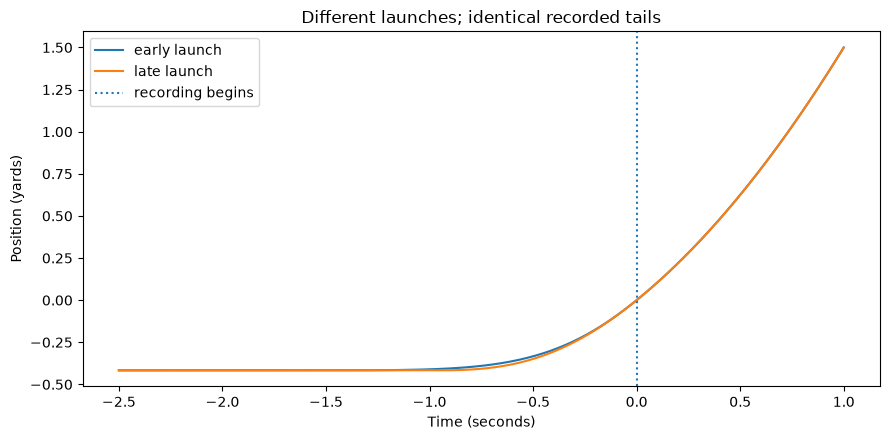

In [3]:
import matplotlib.pyplot as plt
times = [Q(k,100) for k in range(-250,101)]
fig, ax = plt.subplots(figsize=(9,4.5))
for name in ("early", "late"):
    ax.plot([float(t) for t in times], [float(state(name,t)) for t in times], label=name+" launch")
ax.axvline(0, linestyle=":", label="recording begins")
ax.set(xlabel="Time (seconds)", ylabel="Position (yards)", title="Different launches; identical recorded tails")
ax.legend(); fig.tight_layout(); plt.show()


## Exact order-sensitive acceleration

The antisymmetric time-position area cancels constant position and constant velocity. With a C² path it is a positive weighted mean acceleration. The sampled correction and minimum-variance cubic jet are checked in rational arithmetic. Their 1/50 and 1/56 noise ratios are conditional algebraic statements under independent equal-variance position errors and the stated polynomial/window assumptions, not football prediction gains.

In [4]:
from perfectjet.stopped_jets import readout_receipt, minimum_variance_jet, area_acceleration_weights
print(json.dumps(readout_receipt(), indent=2, default=str))
t = tuple(Q(i,10) for i in range(6))
area = area_acceleration_weights(t)
assert list(area) == list(map(Q,[20,-10,-10,-10,-10,20]))
assert sum(area) == 0 and sum(w*x for w,x in zip(area,t)) == 0
weights = minimum_variance_jet(t,2,3)["weights"]
assert sum(w*w for w in weights) == Q(7500,7)
assert sum(w*w for w in weights)/60000 == Q(1,56)


{
  "schema": "perfectjet/stopped-jet-identities/1",
  "times_seconds": [
    "0",
    "1/10",
    "1/5",
    "3/10",
    "2/5",
    "1/2"
  ],
  "area_acceleration_weights": [
    "20",
    "-10",
    "-10",
    "-10",
    "-10",
    "20"
  ],
  "minimum_variance_acceleration": {
    "identified": true,
    "weights": [
      "125/7",
      "-25/7",
      "-100/7",
      "-100/7",
      "-25/7",
      "125/7"
    ],
    "variance": "7500/7",
    "design": [
      [
        "1",
        "-1/4",
        "1/32",
        "-1/384"
      ],
      [
        "1",
        "-3/20",
        "9/800",
        "-9/16000"
      ],
      [
        "1",
        "-1/20",
        "1/800",
        "-1/48000"
      ],
      [
        "1",
        "1/20",
        "1/800",
        "1/48000"
      ],
      [
        "1",
        "3/20",
        "9/800",
        "9/16000"
      ],
      [
        "1",
        "1/4",
        "1/32",
        "1/384"
      ]
    ],
    "readout": [
      "0",
      "0",
      "1

## Actual coverage and temporal outcome results

Each forty gate supports 177 attempts, 93 source players, 57 eligible NFL players and 84 players with independent repeats. Three overlapping gates are not three independent attempts. Each temporal NFL comparison below evaluates 51 players; the thousands of underlying plays are not extra independent scouting cases.

In [5]:
import pandas as pd
from IPython.display import display
coverage = pd.DataFrame(result("source-coverage")["by_drill_gate"])
display(coverage[coverage.drill == "FORTY_YARD_DASH"])
rows=[]
for experiment in ("primary", "matched-motor", "matched-motor-without-ngs"):
    for name, comparison in result(experiment)["comparisons"].items():
        rows.append({"experiment":experiment,"comparison":name,"gain_percent":100*comparison["gain"],
                     "fixed_90_percent":[round(100*x,2) for x in comparison["fixed_prediction_interval_90"]]})
display(pd.DataFrame(rows))
print("Matched-movement kinematic FULL-REFIT interval (%):",
      [round(100*x,2) for x in result("motor-full-refits")["intervals_90"]["kinematics_vs_conventional"]])


,drill,gate,accepted_attempts,players,eligible_target_players,players_with_independent_repeat_attempts
0,FORTY_YARD_DASH,2.0,177,93,57,84
1,FORTY_YARD_DASH,3.0,177,93,57,84
2,FORTY_YARD_DASH,4.0,177,93,57,84


,experiment,comparison,gain_percent,fixed_90_percent
0,primary,tracking_vs_conventional,-13.433923,"[-29.2, 1.15]"
1,primary,jets_vs_conventional,-4.852519,"[-19.42, 7.88]"
2,primary,jets_vs_full_history,3.425187,"[-12.16, 16.52]"
3,primary,jets_vs_strong_control,3.425187,"[-12.16, 16.52]"
4,primary,kinematics_vs_conventional,-4.752668,"[-19.84, 8.34]"
5,matched-motor,tracking_vs_conventional,3.834303,"[-9.46, 14.33]"
6,matched-motor,jets_vs_conventional,3.834303,"[-9.46, 14.33]"
7,matched-motor,jets_vs_full_history,-22.063618,"[-52.58, -0.41]"
8,matched-motor,jets_vs_strong_control,3.834303,"[-9.46, 14.33]"
9,matched-motor,kinematics_vs_conventional,24.487037,"[10.98, 34.78]"


Matched-movement kinematic FULL-REFIT interval (%): [-23.97, 34.8]


## Repeated-measurement denoising with strong controls

A three-coordinate noise-aware estimator improves independent-attempt MSE over raw observations. It does not beat ordinary multivariate ridge. Every calibration uses earlier classes; inner tuning keeps all orientations and copies of one player together. The following plot uses complete original-player refits, not fixed-model intervals. It remains an adaptive development sensitivity, not a prospective guarantee.

,comparison,gain_percent,full_refit_90_percent
0,reliable_vs_raw,22.869211,"[13.13027398163649, 29.695701847282674]"
1,reliable_vs_prior,34.197338,"[20.46101352781458, 50.942750710215]"
2,reliable_vs_scalar_shrinkage,8.387151,"[-8.145442044760701, 15.193386181057766]"
3,reliable_vs_diagonal_reliability,4.154027,"[-4.73924098498373, 14.000994867572638]"
4,reliable_vs_ridge,-1.695492,"[-4.623345002419741, 5.102566105397346]"


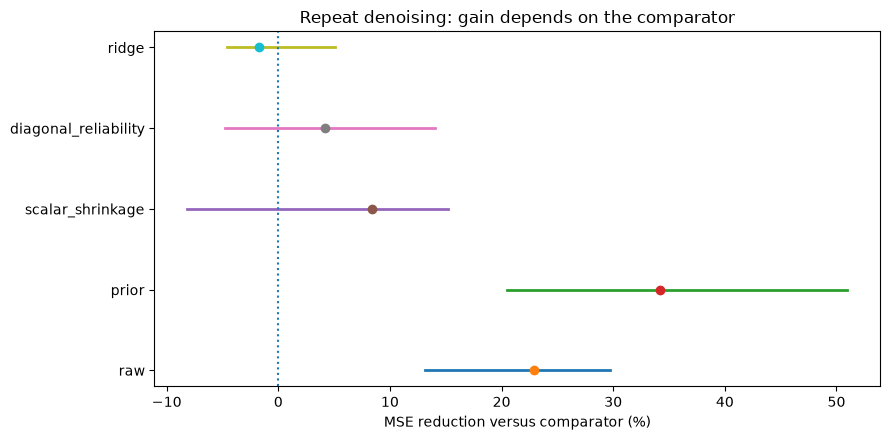

In [6]:
study=result("repeat-controls"); refits=result("repeat-controls-refits")
rows=[]
for name,c in study["comparisons"].items():
    rows.append({"comparison":name,"gain_percent":100*c["gain"],
                 "full_refit_90_percent":[100*x for x in refits["intervals_90"][name]]})
display(pd.DataFrame(rows))
fig,ax=plt.subplots(figsize=(9,4.5))
for i,row in enumerate(rows):
    lo,hi=row["full_refit_90_percent"]
    ax.plot([lo,hi],[i,i],linewidth=2)
    ax.plot(row["gain_percent"],i,marker="o")
ax.axvline(0,linestyle=":")
ax.set_yticks(range(len(rows)),[r["comparison"].replace("reliable_vs_","") for r in rows])
ax.set(xlabel="MSE reduction versus comparator (%)",title="Repeat denoising: gain depends on the comparator")
fig.tight_layout();plt.show()


## Reproduce the private official experiment

The embedded source can run the study after installing NumPy, pandas, SciPy and scikit-learn (the repository's `scouting` extra). Supply your already-owned official input or the provenance-checked owned checkpoint, never an untrusted pickle. The preparation receipt is embedded; restricted individual outputs must be outside the public repository.

Run `scripts/run_stopped_flow.py`, `scripts/run_motor_sensitivity.py`, `scripts/run_reliable_stopped_flow.py` and `scripts/run_repeat_controls.py` from the reconstructed `CORE`, passing `--checkpoint`, `--preparation`, `--out` and `--private`. The first two use `--refits 32`; repeat controls use `--refits 64`. Their complete command lines and all mathematical qualifications are in the monograph. No credentials are requested by this notebook.